# Fragment swaps: ligands built from each other's halves

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:32Z
- **Contents:** 2 exchanges · 9 tool calls · 3 figures · 2 code cells

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/`, the figures in `figures/` and the analysis code the notebook imports (`find_fragment_swaps.py`, `plot_fragment_swaps.py`). With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/4.5-fragment-swaps-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 4.5-fragment-swaps-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 4.5-fragment-swaps-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/4.5-fragment-swaps-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 4.5-fragment-swaps-notebook-rerun.ipynb 4.5-fragment-swaps-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Find triples of compounds with the following properties that may have swapped parts: (1) same target; (2) the first compound is made up of two fragments, A-B; (3) the second compound is made up of two fragments, C-D; (4) the third compound is made of A-C, B-C, A-D or B-D; (5) each fragment must be at least 1/3 of the whole molecule.

**🧠 Assistant**

Here is how that maps onto what BindingDB can answer.

The third compound shares a fragment with each of the other two. So it forms a matched pair with the first compound, since both contain the fragment they have in common, and another matched pair with the second. **A swap triple is two matched molecular pairs that share a compound**, with the extra condition that the two pairs swap *different* halves. That means the same machinery behind matched_molecular_pairs finds them: cut each ligand at one acyclic single bond, index the fragments, and look for a compound whose two halves come from two different parents.

Three conditions decide what counts:

**The 1/3 rule.** A cut is kept only when each half holds at least a third of the molecule's heavy atoms. This is what makes it a swap of substantial parts rather than a substituent change, and it is stricter than the server's own matched-pair rule, which only requires the changed group to be no larger than the constant part.

**Four distinct fragments.** A, B, C and D must all differ, otherwise the "swap" is an ordinary matched pair.

**Three distinct constitutions.** Two epimers fragment into halves that differ only in stereochemistry, so without this test an epimer pair looks like a swap of two different fragments. Requiring the three compounds to differ once stereochemistry is removed drops those.

One more thing is worth recording whenever it is available: the **fourth corner**. If A-B and C-D give the hybrid A-C, then B-D is the remaining recombination, and when it has been measured too the square closes. That turns the triple into a double-mutant cycle, where the two halves' contributions can be added up and compared with what the hybrid actually does.

The search runs per target, since the fragment index is built from one target's ligands.

## Exchange 2

**👤 User**

Try HIV-1 protease.

In [ ]:
# Call 1 · search_targets · ran 2026-11-24 04:55:30 UTC
await replay.call(1, 'search_targets', {'query': 'HIV-1 protease'},
                  sha256='3b072b0763043ed43015d3b5438d1deba650f97eb644bd519fcdb99a76174723')

**Call 1** · `search_targets` · recorded result · sha256 `3b072b076304…`

_20 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| complex | 50 | Dimer of Gag-Pol polyprotein \[489-587\] |  |  |  | Protein Complex | 1528 | 1400 | HIV-1 Protease |
| complex | 56 | Dimer of Gag-Pol polyprotein \[501-599\] |  |  |  | Protein Complex | 465 | 437 | HIV-1 Protease |
| polymer | 50007923 | HIV-1 protease |  |  | Human immunodeficiency virus | PROTEIN | 351 | 153 | HIV-1 protease |
| complex | 125 | Dimer of Gag-Pol polyprotein \[501-599,Q508K,L534I,L564I,C568A,C596A\] |  |  |  | Protein Complex | 307 | 220 | HIV-1 Protease |
| polymer | 4432 | HIV-1 protease |  |  | Human immunodeficiency virus | Protein | 214 | 208 | HIV-1 protease |
| complex | 57 | Dimer of Gag-Pol polyprotein \[489-587\] |  |  |  | Tandem linked enzyme construct | 161 | 161 | HIV-1 Protease |
| complex | 120 | Dimer of Gag-Pol polyprotein \[489-587,Q496K\] |  |  |  | Protein Complex | 73 | 70 | HIV-1 Protease |
| polymer | 4940 | Gag-Pol polyprotein \[489-587,G537V,H558K,V571A\] | P12497 | P12497\[489-587,G537V,H558K,V571A\] | Human immunodeficiency virus | Protein | 63 | 48 | HIV-1 protease |
| complex | 138 | Dimer of Gag-Pol polyprotein \[491-589,Q496K\] |  |  |  | Protein Complex | 62 | 62 | HIV-1 Protease |
| polymer | 5430 | HIV-1 protease |  |  | Human immunodeficiency virus | Protein | 39 | 32 | HIV-1 protease |
| polymer | 49001134 | HIV-1 protease |  |  | Human immunodeficiency virus | Protein | 13 | 13 | HIV-1 protease |
| complex | 54 | Dimer of Gag-Pol polyprotein \[491-589,Q7K,L33I,C67B,C95B\] |  |  |  | Protein Complex | 10 | 10 | HIV-1 Protease |
| complex | 52 | Dimer of Gag-Pol polyprotein \[501-599\] |  |  |  | Protein Complex | 8 | 8 | HIV-1 Protease |
| complex | 142 | Dimer of Gag-Pol polyprotein \[489-587\] |  |  |  | Protein Complex | 7 | 7 | HIV-1 Protease |
| complex | 49 | Dimer of Gag-Pol polyprotein \[489-587,Q496K\] |  |  |  | Protein Complex | 4 | 4 | HIV-1 Protease |
| complex | 156 | Dimer of Gag-Pol polyprotein \[501-599,Q508K,L534I,L564I,C568A,C596A\] |  |  |  | Protein Complex | 3 | 3 | HIV-1 Protease |
| complex | 118 | Dimer of Gag-Pol polyprotein \[501-599,Q508K,L534I,L564I,C568A,C596A\] |  |  |  | Protein Complex | 2 | 2 | HIV-1 Protease |
| polymer | 50001675 | HIV-1 protease |  |  |  | PROTEIN | 1 | 1 | HIV-1 protease |
| complex | 17 | HIV-1 Protease |  |  |  | Protein Complex | 0 | 0 | HIV-1 Protease |
| polymer | 481 | Gag-Pol polyprotein \[489-587,Q496K\] | P12497 | P12497\[489-587,Q496K\] | Human immunodeficiency virus 1 | Enzyme Subunit | 83 | 68 | HIV-1 Protease NL4-3 |


In [ ]:
# Call 2 · run_sql · ran 2026-11-24 04:55:30 UTC
sql = """
    SELECT relation, affinity_type, count(*) AS n FROM activity WHERE polymerid = 223 AND p_affinity IS NOT NULL GROUP BY relation, affinity_type ORDER BY n DESC, relation, affinity_type
    
"""
await replay.call(2, 'run_sql', {'sql': sql, 'limit': 30},
                  sha256='7423cbe046e795fb8304d249d831d1618ce32a519efc780bbab454380bf9455e')

**Call 2** · `run_sql` · recorded result · sha256 `7423cbe046e7…`

_9 rows_

| relation | affinity_type | n |
| --- | --- | --- |
| = | IC50 | 2144 |
| = | Ki | 1999 |
| \> | IC50 | 135 |
| = | Kd | 84 |
| \> | Ki | 40 |
| \< | IC50 | 25 |
| \< | Ki | 23 |
| \> | EC50 | 21 |
| = | EC50 | 19 |


In [ ]:
# Call 3 · search_targets · ran 2026-11-24 04:55:30 UTC
await replay.call(3, 'search_targets', {'query': 'Gag-Pol polyprotein [489-587]'},
                  sha256='2817b50e54311ce80a9fb70dadfcb2fdf6d909e5b2097d0d5a38eae8fed74702')

**Call 3** · `search_targets` · recorded result · sha256 `2817b50e5431…`

_5 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 223 | Gag-Pol polyprotein \[489-587\] | P04585 | P04585\[489-587\] | Human immunodeficiency virus 1 | Enzyme Subunit | 4568 | 3548 | Gag-Pol polyprotein \[489-587\] |
| polymer | 150 | Gag-Pol polyprotein \[489-587\] | P12497 | P12497\[489-587\] | Human immunodeficiency virus 1 | Enzyme Subunit | 0 | 0 | Gag-Pol polyprotein \[489-587\] |
| complex | 50 | Dimer of Gag-Pol polyprotein \[489-587\] |  |  |  | Protein Complex | 1528 | 1400 | Dimer of Gag-Pol polyprotein \[489-587\] |
| complex | 57 | Dimer of Gag-Pol polyprotein \[489-587\] |  |  |  | Tandem linked enzyme construct | 161 | 161 | Dimer of Gag-Pol polyprotein \[489-587\] |
| complex | 142 | Dimer of Gag-Pol polyprotein \[489-587\] |  |  |  | Protein Complex | 7 | 7 | Dimer of Gag-Pol polyprotein \[489-587\] |


In [ ]:
# Call 4 · run_sql · ran 2026-11-24 04:55:30 UTC
sql = """
    SELECT a.monomerid, min(c.smiles) AS smiles, min(a.compound_name) AS name, median(a.p_affinity) FILTER (WHERE a.affinity_type = 'Ki') AS p_ki, median(a.p_affinity) FILTER (WHERE a.affinity_type = 'IC50') AS p_ic50, count(*) AS n_measurements, list(DISTINCT a.articleid ORDER BY a.articleid) FILTER (WHERE a.articleid IS NOT NULL) AS articles FROM activity a JOIN compound c USING (monomerid) WHERE a.polymerid = 223 AND a.p_affinity IS NOT NULL GROUP BY a.monomerid ORDER BY a.monomerid LIMIT 1000 OFFSET 0
    
"""
await replay.call(4, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='a3b61e088e840f5005c36124384aa96fb1f200c01fcf1eaccd9cadb7664f164d')

**Call 4** · `run_sql` · recorded result · sha256 `a3b61e088e84…`

_1000 rows_

| monomerid | smiles | name | p_ki | p_ic50 | n_measurements | articles |
| --- | --- | --- | --- | --- | --- | --- |
| 21 | CN1CCC(CC1)COc2cc3c(cc2OC)c(ncn3)Nc4ccc(cc4F)Br | VANDETANIB | 9.62 |  | 1 | 50029931 |
| 22 | O=C1N(C/C=C/c2cn\[nH\]c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1C/C=C/c1cn\[nH\]c1 | DMPC Cyclic Urea 2 | 9.6 |  | 1 | 50029894 |
| 23 | O=C1N(C/C=C/c2cn\[nH\]c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1CC1CC1 | DMPC Cyclic Urea 3 | 9.39 |  | 1 | 50029894 |
| 25 | OCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC2CC2)C1=O | DMPC Cyclic Urea 5 | 9 |  | 1 | 50029931 |
| 27 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC2CCC2)C(=O)N(CC2CCC2)\[C@@H\]1Cc1ccccc1 | DMPC Cyclic Urea 7 | 8.89 |  | 1 | 50008404 |
| 28 | OCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCO)C1=O | DMPC Cyclic Urea 8 | 8.85 |  | 1 | 50029931 |
| 29 | CCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCC)C1=O | DMPC Cyclic Urea 9 | 8.85 |  | 1 | 50008404 |
| 32 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC2CC2)C(=O)N(CC2CC2)\[C@@H\]1Cc1ccccc1 | DMPC Cyclic Urea 12 | 8.7 |  | 2 | 50006920, 50008404 |
| 33 | OCCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCCO)C1=O | DMPC Cyclic Urea 13 | 9.33 |  | 1 | 50029931 |
| 44 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC2CCCC2)C(=O)N(CC2CCCC2)\[C@@H\]1Cc1ccccc1 | DMPC Cyclic Urea 24 | 8.37 |  | 1 | 50008404 |
| 46 | CCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCC)C1=O | DMPC Cyclic Urea 26 | 8.8 |  | 1 | 50008404 |
| 51 | CCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCC)C1=O | DMPC Cyclic Urea 31 | 8.34 |  | 1 | 50008404 |
| 57 | CC(C)CCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCC(C)C)C1=O | DMPC Cyclic Urea 37 | 8.15 |  | 1 | 50008404 |
| 59 | CCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCC)C1=O | DMPC Cyclic Urea 39 | 8.1 |  | 1 | 50008404 |
| 63 | CC(C)CCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCC(C)C)C1=O | DMPC Cyclic Urea 43 | 7.92 |  | 1 | 50008404 |
| 67 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCNC(=O)c2cccc(F)c2)C(=O)N(CCCCCNC(=O)c2cccc(F)c2)\[C@@H\]1Cc1ccccc1 | DMPC Cyclic Urea 47 | 7.85 |  | 1 | 50029931 |
| 69 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCNC(=O)c2ccncc2)C(=O)N(CCCCCNC(=O)c2ccncc2)\[C@@H\]1Cc1ccccc1 | DMPC Cyclic Urea 49 | 7.8 |  | 1 | 50029931 |
| 70 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCNC(=O)c2ccc(F)cc2)C(=O)N(CCCCCNC(=O)c2ccc(F)cc2)\[C@@H\]1Cc1ccccc1 | DMPC Cyclic Urea 50 | 7.74 |  | 1 | 50029931 |
| 76 | COC(=O)CCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCC(=O)OC)C1=O | DMPC Cyclic Urea 56 | 7.54 |  | 1 | 50029931 |
| 77 | CC(C)CCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCC(C)C)C1=O | DMPC Cyclic Urea 57 | 7.52 |  | 1 | 50008404 |
| 81 | OCCCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCCCO)C1=O | DMPC Cyclic Urea 61 | 7.47 |  | 1 | 50029931 |
| 83 | CC(C)(C)CCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCC(C)(C)C)C1=O | DMPC Cyclic Urea 63 | 7.44 |  | 1 | 50008404 |
| 84 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC2CCCCC2)C(=O)N(CC2CCCCC2)\[C@@H\]1Cc1ccccc1 | DMPC Cyclic Urea 64 | 7.43 |  | 1 | 50008404 |
| 87 | OCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCO)C1=O | DMPC Cyclic Urea 67 | 7.38 |  | 1 | 50029931 |
| 91 | CC(C)CN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC(C)C)C1=O | DMPC Cyclic Urea 71 | 7.31 |  | 1 | 50008404 |
| 92 | OCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCO)C1=O | DMPC Cyclic Urea 72 | 7.29 |  | 1 | 50029931 |
| 93 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCNC(=O)c2ccccc2)C(=O)N(CCCCCNC(=O)c2ccccc2)\[C@@H\]1Cc1ccccc1 | DMPC Cyclic Urea 73 | 7.23 |  | 1 | 50029931 |
| 94 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCOC=C)C(=O)N(CCOC=C)\[C@@H\]1Cc1ccccc1 | DMPC Cyclic Urea 74 | 7.22 |  | 1 | 50008404 |
| 98 | COCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCOC)C1=O | DMPC Cyclic Urea 78 | 7.02 |  | 1 | 50029931 |
| 99 | CCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC)C1=O | DMPC Cyclic Urea 79 | 7 |  | 1 | 50008404 |
| 100 | CC(C)CCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCC(C)C)C1=O | DMPC Cyclic Urea 80 | 6.96 |  | 1 | 50008404 |
| 108 | CS(=O)(=O)NCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCNS(C)(=O)=O)C1=O | DMPC Cyclic Urea 88 | 6.57 |  | 1 | 50029931 |
| 112 | CCCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCCC)C1=O | DMPC Cyclic Urea 92 | 6.59 |  | 1 | 50008404 |
| 114 | CNC(=O)NCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCNC(=O)NC)C1=O | DMPC Cyclic Urea 94 | 6.57 |  | 1 | 50029931 |
| 117 | CC(=O)NCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCNC(C)=O)C1=O | DMPC Cyclic Urea 97 | 6.46 |  | 1 | 50029931 |
| 120 | OCCCCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCCCCO)C1=O | DMPC Cyclic Urea 100 | 6.3 |  | 1 | 50029931 |
| 121 | COCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCOC)C1=O | DMPC Cyclic Urea 101 | 6.1 |  | 1 | 50008404 |
| 127 | NCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCN)C1=O | DMPC Cyclic Urea 107 | 5.9 |  | 1 | 50029931 |
| 128 | NCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCN)C1=O | DMPC Cyclic Urea 108 | 5.9 |  | 1 | 50029931 |
| 150 | OCc1ccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc(CO)cc3)C2=O)cc1 | DMP323 | 9.49 | 6.96 | 12 | 50006812, 50006920, 50007338, 50007591, 50007903, 50008404, 50029610, 50029830, 50029931, 50036849, 50037096 |
| 151 | Nc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(N)c3)C2=O)c1 | DMP450 | 9.55 |  | 7 | 102, 50006920, 50007338, 50007555, 50007591, 50007903, 50008404 |
| 152 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC=C)C(=O)N(CC=C)\[C@@H\]1Cc1ccccc1 | XK216 | 8.31 |  | 2 | 50007004, 50008404 |
| 153 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccc3ccccc3c2)\[C@@H\]1Cc1ccccc1 | XK263 | 9.51 |  | 3 | 50003614, 50007591, 50008404 |
| 154 | c1ccc(cc1)C\[C@@H\]2\[C@@H\](\[C@H\](\[C@H\](N(C(=O)N2Cc3cccc(c3)C(=O)Nc4nccs4)Cc5cccc(c5)C(=O)Nc6nccs6)Cc7ccccc7)O)O | XV638 | 10.57 |  | 4 | 50006812, 50006920, 50007591, 50008404 |
| 155 | O=C(Nc1nc2ccccc2\[nH\]1)c1cccc(CN2C(=O)N(Cc3cccc(C(=O)Nc4nc5ccccc5\[nH\]4)c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | SD146 | 10.62 |  | 4 | 50006812, 50006920, 50007591, 50008404 |
| 156 | NC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(N)=O)C2=O)c1 | Cyclic Urea | 10.41 |  | 4 | 50006812, 50007591, 50008404 |
| 157 | CNC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NC)C2=O)c1 | Cyclic Urea | 10.18 |  | 4 | 50006812, 50007591, 50008404 |
| 158 | CCNC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NCC)C2=O)c1 | Cyclic Urea | 9.68 |  | 4 | 50006812, 50007591, 50008404 |
| 159 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccccn2)C(=O)N(Cc2cccc(c2)C(=O)Nc2ccccn2)\[C@@H\]1Cc1ccccc1 | Cyclic Urea | 10.37 |  | 5 | 50006812, 50007338, 50007591, 50008404 |
| 160 | O=C(Nc1ncc\[nH\]1)c1cccc(CN2C(=O)N(Cc3cccc(C(=O)Nc4ncc\[nH\]4)c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | Cyclic Urea | 10.85 |  | 4 | 50006812, 50006920, 50007591, 50008404 |
| 161 | O=C1N(Cc2ccc3\[nH\]ncc3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | Cyclic Urea | 10.74 |  | 3 | 50007591, 50007889, 50029830 |
| 164 | O=C1N(Cc2ccc3\[nH\]ncc3c2)\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | Cyclic Urea | 10.7 |  | 4 | 102, 50003630, 50007591, 50041057 |
| 166 | O=C1N\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | Cyclic Urea | 9.49 |  | 1 | 50007591 |
| 167 | O=C(O)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | Cyclic Urea | 10.31 |  | 1 | 50007591 |
| 168 | O=C1N(Cc2cccc(O)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | Cyclic Urea | 10.35 |  | 1 | 50007591 |
| 169 | O=C1N(Cc2cccc(CCO)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | Cyclic Urea | 10.3 |  | 1 | 50007591 |
| 170 | COC(=O)Cc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | Cyclic Urea | 9.96 |  | 1 | 50007591 |
| 171 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(C=O)c2)C(=O)N(Cc2cccc(C=O)c2)\[C@@H\]1Cc1ccccc1 | Cyclic Urea | 9.36 |  | 1 | 50007555 |
| 172 | CC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(C)=O)C2=O)c1 | Cyclic Urea | 10.22 |  | 2 | 102, 50007555 |
| 173 | CCC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)CC)C2=O)c1 | Cyclic Urea | 9.68 |  | 1 | 50007555 |
| 174 | CCCC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)CCC)C2=O)c1 | Cyclic Urea | 8.85 |  | 1 | 50007555 |
| 175 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)C(F)(F)F)C(=O)N(Cc2cccc(c2)C(=O)C(F)(F)F)\[C@@H\]1Cc1ccccc1 | Cyclic Urea | 10.43 |  | 1 | 50007555 |
| 176 | CC(C)(C)C(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)C(C)(C)C)C2=O)c1 | Cyclic Urea | 8.44 |  | 1 | 50007555 |
| 177 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(CN=O)c2)C(=O)N(Cc2cccc(CN=O)c2)\[C@@H\]1Cc1ccccc1 | Cyclic Urea | 11 |  | 1 | 50007555 |
| 178 | CC(N=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(C)N=O)C2=O)c1 | Cyclic Urea | 10.74 |  | 1 | 50007555 |
| 179 | CCC(N=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(CC)N=O)C2=O)c1 | Cyclic Urea | 10.51 |  | 1 | 50007555 |
| 180 | CCCC(N=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(CCC)N=O)C2=O)c1 | Cyclic Urea | 10.51 |  | 1 | 50007555 |
| 181 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(N=O)C(F)(F)F)C(=O)N(Cc2cccc(c2)C(N=O)C(F)(F)F)\[C@@H\]1Cc1ccccc1 | Cyclic Urea | 8.41 |  | 1 | 50007555 |
| 182 | O=C1N(Cc2cccc(-c3cc\[nH\]n3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | Cyclic Urea | 10.57 |  | 3 | 102, 50007555, 50007903 |
| 183 | O=C1N(Cc2cccc(-c3cn\[nH\]c3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2cn\[nH\]c2)c1 | Cyclic Urea | 9.21 |  | 1 | 50007555 |
| 184 | O=C1N(Cc2cccc(-c3ncc\[nH\]3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2ncc\[nH\]2)c1 | Cyclic Urea | 9.8 |  | 1 | 50007555 |
| 185 | O=C1N(Cc2cccc(-c3c\[nH\]cn3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2c\[nH\]cn2)c1 | Cyclic Urea | 9.72 |  | 1 | 50007555 |
| 186 | O=C1N(Cc2cccc(-c3c\[nH\]nn3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2c\[nH\]nn2)c1 | Cyclic Urea | 9.77 |  | 1 | 50007555 |
| 187 | O=C1N(Cc2cccc(-c3nnc\[nH\]3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2nnc\[nH\]2)c1 | Cyclic Urea | 10.28 |  | 1 | 50007555 |
| 188 | O=C1N(Cc2cccc(-c3nnn\[nH\]3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2nnn\[nH\]2)c1 | Cyclic Urea | 8.18 |  | 1 | 50007555 |
| 192 | O\[C@@H\]1CN(Cc2ccccc2)N(Cc2ccc(O)cc2)C(=O)N(Cc2ccc(O)cc2)\[C@@H\]1Cc1ccccc1 \|r\| | Unnamed azacyclic urea | 10.15 |  | 2 | 50014985 |
| 196 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | A-74704 |  | 8.52 | 2 | 50008140, 50035969 |
| 197 | CC(C)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)N(C)Cc1ccccn1)C(C)C \|r\| | A-76889 | 9.82 |  | 5 | 50003614, 50007513, 50029497, 50036318 |
| 198 | CC(C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](\[C@H\](\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](C(C)C)NC(=O)N(C)Cc3ccccn3)O)O)NC(=O)N(C)Cc4ccccn4 | A-76928 |  |  | 1 | 50003614 |
| 199 | CC(C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](\[C@@H\](\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](C(C)C)NC(=O)N(C)Cc3ccccn3)O)O)NC(=O)N(C)Cc4ccccn4 | A-77003 |  | 9 | 2 | 50003614, 50029779 |
| 200 | CC(C)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@H\](C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)N(C)Cc1ccccn1)C(C)C)Cc1ccccc1 \|r\| | A-78791 |  |  | 1 | 50003614 |
| 201 | CC(C)\[C@H\](NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(CC1CCCCC1)NC(=O)\[C@@H\](NC(C)=O)C(C)C \|r\| | CGP 53820 |  | 8.05 | 1 | 50029086 |
| 290 | CCCN1CCN(C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@@H\]2CCS(=O)(=O)\[C@@H\]2C(C)C)\[C@@H\](C1)C(=O)NC(C)(C)C \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 1 |  | 7.85 | 1 | 48 |
| 291 | CCCCCCCCN1CCN(C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@@H\]2CCS(=O)(=O)\[C@@H\]2C(C)C)\[C@@H\](C1)C(=O)NC(C)(C)C \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 2 |  | 8.08 | 1 | 48 |
| 292 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(C\[C@H\]1C(=O)NC(C)(C)C)C(C)C \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 3 |  | 7.24 | 1 | 48 |
| 293 | CCC(CC)N1CCN(C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@@H\]2CCS(=O)(=O)\[C@@H\]2C(C)C)\[C@@H\](C1)C(=O)NC(C)(C)C \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 4 |  | 7 | 1 | 48 |
| 294 | CC(C)CN1CCN(C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@@H\]2CCS(=O)(=O)\[C@@H\]2C(C)C)\[C@@H\](C1)C(=O)NC(C)(C)C \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 5 |  | 7.57 | 1 | 48 |
| 295 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(CC(C)(C)C)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 6 |  | 7.32 | 1 | 48 |
| 296 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(C\[C@H\]1C(=O)NC(C)(C)C)C1CCCCCC1 \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 7 |  | 7.04 | 1 | 48 |
| 297 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(C\[C@H\]1C(=O)NC(C)(C)C)C1CCCCC1 \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 8 |  | 7.89 | 1 | 48 |
| 298 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(C\[C@H\]1C(=O)NC(C)(C)C)C1CCCC1 \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 9 |  | 7.72 | 1 | 48 |
| 299 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(C\[C@H\]1C(=O)NC(C)(C)C)C1CCC1 \|r\| | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 10 |  | 7.77 | 1 | 48 |
| 300 | CC(C)\[C@@H\]1\[C@H\](OC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN2CCN(C3CC3)C\[C@H\]2C(=O)NC(C)(C)C)CCS1(=O)=O | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 11 |  | 8.32 | 1 | 48 |
| 301 | CC(C)\[C@@H\]1\[C@H\](OC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN2CCN(C3CCOCC3)C\[C@H\]2C(=O)NC(C)(C)C)CCS1(=O)=O | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 12 |  | 7.46 | 1 | 48 |
| 302 | CC(C)\[C@@H\]1\[C@H\](OC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN2CCN(C3CCSCC3)C\[C@H\]2C(=O)NC(C)(C)C)CCS1(=O)=O | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 13 |  | 6.62 | 1 | 48 |
| 303 | CC(C)\[C@@H\]1\[C@H\](OC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN2CCN(C3CCSC3)C\[C@H\]2C(=O)NC(C)(C)C)CCS1(=O)=O | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 14 |  | 8.08 | 1 | 48 |
| 304 | CC(C)\[C@@H\]1\[C@H\](OC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN2CCN(C3Cc4ccccc4C3)C\[C@H\]2C(=O)NC(C)(C)C)CCS1(=O)=O | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 15 |  | 8.28 | 1 | 48 |
| 305 | CC(C)\[C@@H\]1\[C@H\](OC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN2CCN(C3CC(c4ccccc4)C3)C\[C@H\]2C(=O)NC(C)(C)C)CCS1(=O)=O | 1-(2OHPr)-4-Substit-piperazine, thienyl carbamate deriv. 16 |  | 8.42 | 1 | 48 |
| 325 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](COc2ccccc2)N(CC(=O)Nc2nccs2)S(=O)(=O)N(CC(=O)Nc2nccs2)\[C@@H\]1COc1ccccc1 \|r\| | Cyclic Sulfamide deriv. 3 | 5.66 |  | 1 | 50037096 |
| 326 | CNC(=O)c1cccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3cccc(c3)C(=O)NC)S2(=O)=O)c1 \|r\| | Cyclic Sulfamide deriv. 4 | 8.21 |  | 2 | 50037096 |
| 327 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](COc2ccccc2)N(Cc2cccc(I)c2)S(=O)(=O)N(Cc2cccc(I)c2)\[C@@H\]1COc1ccccc1 \|r\| | Cyclic Sulfamide deriv. 5 | 7.03 |  | 1 | 50037096 |
| 329 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](COc2ccccc2)N(Cc2ccc(cc2)-c2cccs2)S(=O)(=O)N(Cc2ccc(cc2)-c2cccs2)\[C@@H\]1COc1ccccc1 \|r\| | Cyclic Sulfamide deriv. 7 | 6.04 |  | 1 | 50037096 |
| 335 | CNC(=O)c1cccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3ccccc3)S2(=O)=O)c1 \|r\| | Cyclic Sulfamide deriv. 13 | 8 |  | 2 | 50037096 |
| 342 | CC(N=O)c1cccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3cccc(c3)C(C)N=O)S2(=O)=O)c1 \|r\| | Cyclic Sulfamide deriv. 20 | 8.25 |  | 2 | 50037096 |
| 343 | CC(=O)c1cccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3cccc(c3)C(C)=O)S2(=O)=O)c1 \|r\| | Cyclic Sulfamide deriv. 21 | 7.23 |  | 1 | 50009245 |
| 344 | OCCc1cccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3cccc(CCO)c3)S2(=O)=O)c1 \|r\| | Cyclic Sulfamide deriv. 22 | 7.37 |  | 3 | 50009245, 50037096 |
| 345 | COC(Cc1cccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3cccc(CC(OC)OC)c3)S2(=O)=O)c1)OC \|r\| | Cyclic Sulfamide deriv. 23 | 6.27 |  | 2 | 50009245, 50037096 |
| 346 | OCc1ccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3ccc(CO)cc3)S2(=O)=O)cc1 \|r\| | Cyclic Sulfamide deriv. 24 | 8.51 |  | 5 | 50009245, 50037096, 50037483 |
| 347 | COC(=O)c1ccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3ccc(cc3)C(=O)OC)S2(=O)=O)cc1 \|r\| | Cyclic Sulfamide deriv. 25 | 7.08 |  | 2 | 50009245, 50037096 |
| 348 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(C)C \|r\| | C2-symmetric compound 5 | 9.4 | 7.82 | 4 | 50007724, 50037096 |
| 383 | O\[C@@H\](C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 \|r\| | Urethane deriv. 2 |  | 10.22 | 4 | 50005329, 50029377, 50036532, 50042217 |
| 396 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(N)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 1 | 9.17 | 8.57 | 4 | 56, 50008872 |
| 397 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(C)(=O)=O)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 2 |  | 8.4 | 1 | 56 |
| 398 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccccc3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 3 | 9.28 | 8.74 | 2 | 56 |
| 399 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccc(F)cc3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 4 |  | 8.39 | 1 | 56 |
| 400 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccc(Cl)cc3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 5 |  | 8.28 | 1 | 56 |
| 401 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccc(cc3)C(F)(F)F)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 6 |  | 7.74 | 1 | 56 |
| 402 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3cccc(c3)C#N)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 7 | 9.68 |  | 1 | 56 |
| 403 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccc(cc3)C#N)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 8 | 9.39 | 8.66 | 2 | 56 |
| 404 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3cccs3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 9 |  | 8.06 | 1 | 56 |
| 405 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccccn3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 10 |  | 8.59 | 1 | 56 |
| 406 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3cccnc3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 11 |  | 8.59 | 1 | 56 |
| 408 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1N)C(C)(C)C | Dihydropyran-2-one deriv. 13 |  | 7.955 | 2 | 56, 50008872 |
| 409 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1NS(C)(=O)=O)C(C)(C)C | Dihydropyran-2-one deriv. 14 |  | 8.01 | 1 | 56 |
| 410 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1NS(=O)(=O)c1ccccc1)C(C)(C)C | Dihydropyran-2-one deriv. 15 |  | 8.82 | 1 | 56 |
| 411 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1NS(=O)(=O)c1ccc(F)cc1)C(C)(C)C | Dihydropyran-2-one deriv. 16 |  | 8.43 | 1 | 56 |
| 412 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1NS(=O)(=O)c1ccc(Cl)cc1)C(C)(C)C | Dihydropyran-2-one deriv. 17 |  | 8.46 | 1 | 56 |
| 413 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1NS(=O)(=O)c1ccc(cc1)C(F)(F)F)C(C)(C)C | Dihydropyran-2-one deriv. 18 |  | 7.91 | 1 | 56 |
| 414 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1NS(=O)(=O)c1ccc(cc1)C#N)C(C)(C)C | Dihydropyran-2-one deriv. 19 |  | 8.68 | 1 | 56 |
| 418 | Cc1cc(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C2CC2)c(cc1NS(=O)(=O)c1ccccc1)C(C)(C)C | Dihydropyran-2-one deriv. 23 |  | 8.44 | 1 | 56 |
| 419 | Cc1cc(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C2CCCC2)c(cc1NS(=O)(=O)c1ccccc1)C(C)(C)C | Dihydropyran-2-one deriv. 24 |  | 8.07 | 1 | 56 |
| 420 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(N)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 25 |  | 8.46 | 2 | 56, 50008872 |
| 421 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NS(C)(=O)=O)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 26 | 9.08 |  | 1 | 56 |
| 422 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccc(cc3)C(F)(F)F)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 27 | 7.57 |  | 1 | 56 |
| 423 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3cccc(c3)C#N)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 28 | 8.85 |  | 1 | 56 |
| 425 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3cccs3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 30 |  | 8.44 | 1 | 56 |
| 426 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccccn3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 31 |  | 8.52 | 1 | 56 |
| 427 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3cccnc3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 32 |  | 8.46 | 1 | 56 |
| 432 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3ccccc3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 37 |  | 7.98 | 1 | 56 |
| 433 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3ccc(F)cc3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 38 |  | 8.02 | 1 | 56 |
| 434 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3ccc(cc3)C#N)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 39 |  | 8.35 | 1 | 56 |
| 435 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3cccs3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 40 |  | 7.66 | 1 | 56 |
| 437 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3ccccn3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 42 |  | 8.3 | 1 | 56 |
| 438 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3cccnc3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 43 |  | 8.46 | 1 | 56 |
| 439 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1OS(=O)(=O)c1ccccc1)C(C)(C)C | Dihydropyran-2-one deriv. 44 |  | 8.01 | 1 | 56 |
| 440 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1OS(=O)(=O)c1ccc(F)cc1)C(C)(C)C | Dihydropyran-2-one deriv. 45 |  | 7.77 | 1 | 56 |
| 442 | Cc1cc(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C2CCCCC2)c(cc1OS(=O)(=O)c1ccccc1)C(C)(C)C | Dihydropyran-2-one deriv. 47 |  | 6.88 | 1 | 56 |
| 443 | Cc1cc(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C2CCCCC2)c(cc1OS(=O)(=O)c1ccc(cc1)C#N)C(C)(C)C | Dihydropyran-2-one deriv. 48 |  | 7.68 | 1 | 56 |
| 444 | Cc1cc(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C2CCCCC2)c(cc1OS(=O)(=O)c1ccc(F)cc1)C(C)(C)C | Dihydropyran-2-one deriv. 49 |  | 7.54 | 1 | 56 |
| 448 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(O)cc2C(C)(C)C)C(=O)O1 | PD 178390 Analog 40 | 8.96 |  | 1 | 56 |
| 450 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3ccccn3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 55 |  | 8.17 | 1 | 56 |
| 451 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3cccnc3)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 56 |  | 7.85 | 1 | 56 |
| 452 | CC(C)C1(CCc2ccc(N)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3ccc(cc3)C#N)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 57 |  | 8.89 | 1 | 56 |
| 456 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)N(C)C)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 61 |  | 8.44 | 1 | 56 |
| 457 | CCNS(=O)(=O)Nc1cc(c(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C(C)C)cc1C)C(C)(C)C | Dihydropyran-2-one deriv. 62 |  | 8.77 | 1 | 56 |
| 458 | CCNS(=O)(=O)Nc1cc(c(SC2C(=O)CC(CCc3ccccc3)(OC2=O)C(C)C)cc1C)C(C)(C)C | Dihydropyran-2-one deriv. 63 |  | 8.48 | 1 | 56 |
| 459 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)N(C)C)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 64 |  | 8.47 | 1 | 56 |
| 460 | CCNS(=O)(=O)Oc1cc(c(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C(C)C)cc1C)C(C)(C)C | Dihydropyran-2-one deriv. 65 |  | 8.31 | 1 | 56 |
| 461 | CC(C)C1(CCc2ccc(N)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)N(C)C)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 66 |  | 8.41 | 1 | 56 |
| 462 | CCNS(=O)(=O)Oc1cc(c(SC2C(=O)CC(CCc3ccc(N)cc3)(OC2=O)C(C)C)cc1C)C(C)(C)C | Dihydropyran-2-one deriv. 67 |  | 8.37 | 1 | 56 |
| 463 | CCNS(=O)(=O)Oc1cc(c(SC2C(=O)CC(CCc3ccccc3)(OC2=O)C(C)C)cc1C)C(C)(C)C | Dihydropyran-2-one deriv. 68 |  | 8.05 | 1 | 56 |
| 464 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3ccc(cc3)C#N)cc2C(C)(C)C)C(=O)O1 | Dihydropyran-2-one deriv. 69 | 9.15 |  | 1 | 56 |
| 465 | CC(C)\[C@\]1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(N)cc2C(C)(C)C)C(=O)O1 \|r\| | Dihydropyran-2-one deriv. 70 | 10.15 |  | 3 | 56, 50008872 |
| 467 | CC(C)\[C@\]1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccc(cn3)C(F)(F)F)cc2C(C)(C)C)C(=O)O1 \|r\| | Dihydropyran-2-one deriv. 72 | 9.41 |  | 1 | 56 |
| 469 | CC(C)\[C@\]1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccc(cc3)C#N)cc2C(C)(C)C)C(=O)O1 \|r\| | Dihydropyran-2-one deriv. 74 | 9.7 | 8.04 | 2 | 56 |
| 470 | CC(C)\[C@\]1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)c3ccc(cn3)C(F)(F)F)cc2C(C)(C)C)C(=O)O1 \|r\| | Dihydropyran-2-one deriv. 75 | 8.19 |  | 1 | 56 |
| 472 | CC(C)\[C@\]1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(C)(=O)=O)cc2C(C)(C)C)C(=O)O1 \|r\| | Dihydropyran-2-one deriv. 77 | 10.52 | 8.66 | 2 | 56 |
| 475 | CNC(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 3 |  | 5.82 | 1 | 50041213 |
| 476 | CCCCNC(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 4 |  | 6.03 | 1 | 50041213 |
| 477 | CCCCNC(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 5 |  | 6.9 | 1 | 50041213 |
| 478 | CCCNC(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 6 |  | 6.27 | 1 | 50041213 |
| 479 | CCNC(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 7 |  | 6.48 | 1 | 50041213 |
| 480 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NC(C)C \|r\| | (Hydroxyethyl)urea Isostere deriv. 8 |  | 6.58 | 1 | 50041213 |
| 481 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NC(C)(C)C \|r\| | (Hydroxyethyl)urea Isostere deriv. 9 |  | 7.46 | 1 | 50041213 |
| 483 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)NC(C)(C)C \|r\| | (Hydroxyethyl)urea Isostere deriv. 11 |  | 8.22 | 1 | 50041213 |
| 485 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NC(C)(C)C \|r\| | (Hydroxyethyl)urea Isostere deriv. 13 |  | 7.89 | 1 | 50041213 |
| 486 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)NC(C)(C)C \|r\| | (Hydroxyethyl)urea Isostere deriv. 14 |  | 8.52 | 1 | 50041213 |
| 489 | CC(C)(C)NC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)Cc1ccccc1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 17 |  | 7.72 | 1 | 50041213 |
| 490 | CC(C)(C)NC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)Cc1ccccc1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 18 |  | 8.52 | 1 | 50041213 |
| 491 | C\[C@@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NC(C)(C)C)c1ccccc1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 19 |  | 5.24 | 2 | 50041213 |
| 493 | CC(C)(C)NC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)Cc1ccncc1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 21 |  | 6.98 | 1 | 50041213 |
| 494 | CC(C)(C)NC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)Cc1ccncc1 \|r\| | (Hydroxyethyl)urea Isostere deriv. 22 |  | 7.72 | 1 | 50041213 |
| 499 | CCCCCCc1cc2C(O)C(C(c3ccccc3)c3c(O)c4cc(CCCCCC)c(O)cc4oc3=O)C(=O)Oc2cc1O | NSC 32180 |  | 6.49 | 1 | 50036426 |
| 500 | OC1C(Sc2c(O)c3ccccc3oc2=O)C(=O)Oc2ccccc12 | NSC 41234 |  | 4.68 | 1 | 50036426 |
| 502 | Oc1c(O)c2ccccc2c(O)c1C(=C1C(=O)C(=O)c2ccccc2C1=O)c1ccc(cc1)C(C1C(=O)C(=O)c2ccccc2C1=O)C1C(=O)C(=O)c2ccccc2C1=O \|w:13.14\| | NSC 117027 |  | 6.12 | 1 | 50036426 |
| 503 | Oc1cccc2oc(=O)c(Cc3ccccc3)c(O)c12 | NSC 251156 |  | 4 | 1 | 50036426 |
| 505 | Oc1c(C(c2ccc3OCOc3c2)c2c(O)c3ccccc3oc2=O)c(=O)oc2ccccc12 | NSC 373937 |  | 4.52 | 1 | 50036426 |
| 506 | Oc1c(C(c2ccc(cc2)C(c2c(O)c3ccccc3oc2=O)c2c(O)c3ccccc3oc2=O)c2c(O)c3ccccc3oc2=O)c(=O)oc2ccccc12 | NSC 158393 |  | 5.355 | 2 | 50018983, 50036426 |
| 508 | Oc1c(O)c2ccccc2c(O)c1C(=C1C(=O)C(=O)c2ccccc2C1=O)c1ccc(Cl)cc1Cl \|w:13.14\| | NSC 117272 |  | 4.62 | 1 | 50036426 |
| 514 | Oc1c(-c2ccccc2)c(=O)oc2c(cccc12)-c1ccccc1 | NSC 251150 |  | 4.89 | 1 | 50036426 |
| 515 | Oc1c(-c2ccccc2)c(=O)oc2ccccc12 | NSC 251152 |  | 4.49 | 1 | 50036426 |
| 516 | CC(C)c1cccc(C(C)C)c1NC(=O)C(=O)CC(=O)CC(c1ccccc1)c1c(O)c2ccccc2oc1=O | NSC 647086 |  | 4.51 | 1 | 50036426 |
| 517 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cccnc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1c2ccccc2C\[C@H\]1O | Crixivan | 9.43 | 9.22 | 30 | 50005491, 50006812, 50006920, 50007338, 50010029, 50011719, 50012282, 50013150, 50013231, 50029358, 50035234, 50036532, 50036845, 50036849, 50036895, 50037096, 50037483 |
| 519 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 \|@:16\| | SQV | 9.6 | 9.2 | 33 | 50, 50000519, 50005329, 50005518, 50006812, 50006920, 50007338, 50007878, 50013150, 50029188, 50029306, 50029597, 50029668, 50029669, 50029875, 50034987, 50035234, 50035922, 50036845, 50037096, 50037483, 50038265, 50041210, 50042217, 50044024 |
| 520 | CC(C)\[C@H\](NC(=O)N(C)Cc1csc(n1)C(C)C)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1cncs1)Cc1ccccc1 | RTV | 9.43 |  | 16 | 50006812, 50006920, 50007338, 50009349, 50029588, 50030116, 50036845, 50037096, 50037304, 50037483 |
| 525 | \[H\]\[C@@\]1(CCCS(=O)(=O)C1)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@@\]2(\[H\])CCCC\[C@@\]2(\[H\])C\[C@@\]1(\[H\])C(=O)NC(C)(C)C \|r\| | Isoquinoline furanyl urethane analog |  | 5.76 | 1 | 50029423 |
| 526 | \[H\]\[C@\]1(CCCS(=O)(=O)C1)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@@\]2(\[H\])CCCC\[C@@\]2(\[H\])C\[C@@\]1(\[H\])C(=O)NC(C)(C)C \|r\| | Isoquinoline furanyl urethane analog |  | 5.68 | 1 | 50029423 |
| 532 | \[H\]\[C@\]12CCCC\[C@@\]1(\[H\])C\[C@\](\[H\])(N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@@H\]1CCS(=O)(=O)\[C@@H\]1C)C2)C(=O)NC(C)(C)C \|r\| | Isoquinoline furanyl urethane analog |  | 8 | 1 | 50 |
| 545 | CCCC1(CCc2ccccc2)CC(=O)C(C(CC)c2cccc(NS(=O)(=O)c3ccc(cc3)C#N)c2)C(=O)O1 | Tipranavir analog 2 | 8.1 |  | 1 | 50008041 |
| 547 | CCCC1(CCc2ccccc2)CC(=O)C(C(CC)c2cccc(NS(=O)(=O)c3cccc4cccnc34)c2)C(=O)O1 | Tipranavir analog 4 | 8.52 |  | 1 | 50008041 |
| 548 | CCCC1(CCc2ccccc2)CC(=O)C(C(CC)c2cccc(NS(=O)(=O)c3cn(C)cn3)c2)C(=O)O1 | Tipranavir analog 5 | 9 | 6.3 | 2 | 50008041 |
| 563 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CO\[C@H\]2OCC\[C@@H\]12 \|r\| | urethane analog 2 |  | 8.74 | 2 | 50005665 |
| 564 | \[H\]\[C@\]1(CO\[C@\]2(\[H\])OCC\[C@\]12\[H\])OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@@\]2(\[H\])CCCC\[C@@\]2(\[H\])C\[C@@\]1(\[H\])C(=O)NC(C)(C)C \|r\| | Isoquinoline furanyl urethane analog. 4 |  | 8.19 | 1 | 50005665 |
| 567 | \[H\]\[C@@\]1(CO\[C@@\]2(\[H\])CCC\[C@@\]12\[H\])OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@@\]2(\[H\])CCCC\[C@@\]2(\[H\])C\[C@@\]1(\[H\])C(=O)NC(C)(C)C \|r\| | Isoquinoline furanyl urethane analog. 7 |  | 6.72 | 1 | 50018768 |
| 568 | \[H\]\[C@@\]1(CC\[C@@\]2(\[H\])OCC\[C@@\]12\[H\])OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@@\]2(\[H\])CCCC\[C@@\]2(\[H\])C\[C@@\]1(\[H\])C(=O)NC(C)(C)C \|r\| | Isoquinoline furanyl urethane analog. 8 |  | 7.77 | 1 | 50018768 |
| 577 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | APV | 9.77 | 7.52 | 14 | 50003614, 50006812, 50006920, 50007338, 50008441, 50008442, 50012168, 50015723, 50018873, 50019289, 50036849, 50036895, 50037483 |
| 578 | CC(C)\[C@H\](N1CCCNC1=O)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)COc1c(C)cccc1C)Cc1ccccc1 \|r\| | LPV | 11.4 |  | 4 | 50010894, 50036895, 50037483 |
| 579 | CSC\[C@H\](NC(=O)COc1cccc2cnccc12)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1CSC\[C@H\]1C(=O)NC(C)(C)C \|r\| | iQoa-Mta-Apns-Thz-NH-tBu | 9.13 | 8.19 | 2 | 50018314 |
| 580 | Cc1ccccc1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1C \|r\| | AG1776 | 9.48 |  | 1 | 50018314 |
| 588 | \[H\]\[C@\]1(N\[C@@H\](C(=O)NCCNC(=O)\[C@@H\]2N\[C@\](\[H\])(SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)OC)C(C)(C)S1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)OC \|r\| | penicillin deriv. 1 |  | 7.22 | 1 | 50000340 |
| 589 | \[H\]\[C@\]1(N\[C@@H\](C(=O)NCCNC(=O)\[C@@H\]2N\[C@\](\[H\])(SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(N)=O)C(C)(C)S1)\[C@H\](NC(=O)Cc1ccccc1)C(N)=O \|r\| | penicillin deriv. 2 |  | 8.52 | 1 | 50000340 |
| 590 | \[H\]\[C@\]1(N\[C@@H\](C(=O)NCCNC(=O)\[C@@H\]2N\[C@\](\[H\])(SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCC)C(C)(C)S1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCC \|r\| | penicillin deriv. 3 |  | 8.32 | 2 | 50000340, 50029110 |
| 591 | \[H\]\[C@\]1(N\[C@@H\](C(=O)NCCNC(=O)\[C@@H\]2N\[C@\](\[H\])(SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)C(C)(C)S1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 \|r\| | penicillin deriv. 4 |  | 9.05 | 3 | 50000340, 50005518, 50029110 |
| 635 | \[H\]\[C@\]1(N\[C@@H\](C(=O)NCCCNC(=O)\[C@@H\]2N\[C@\](\[H\])(SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)C(C)(C)S1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 \|r\| | penicillin deriv. 48 |  | 6.27 | 2 | 50005518, 50029110 |
| 636 | \[H\]\[C@\]1(N\[C@@H\](C(=O)NCC(O)CNC(=O)\[C@@H\]2N\[C@\](\[H\])(SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)C(C)(C)S1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 \|r\| | penicillin deriv. 49 |  | 8.3 | 2 | 50005518, 50029110 |
| 729 | CC(C)\[C@H\](NC(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CC\[C@H\](C\[C@H\]1C(=O)NC(C)(C)C)OCc1ccncc1 \|r\| | Palinavir | 10.51 |  | 1 | 50036895 |
| 751 | CC(C)C\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)C(=O)N)NC(=O)\[C@H\](Cc2ccccc2)C\[C@@H\](\[C@H\](Cc3ccccc3)NC(=O)OC(C)(C)C)O | Hydroxyethylene dipeptide isostere |  | 9.22 | 1 | 50036532 |
| 758 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NCc1ccccc1 \|r\| | Hydroxyethylene deriv. 9 |  | 6.94 | 4 | 50005329, 50041281, 50042217, 50042219 |
| 766 | Cc1ccc(cc1)S(=O)(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | U-103017 Analog | 8.52 |  | 1 | 50030097 |
| 767 | Oc1c2CCCCCCc2oc(=O)c1\[C@@H\](C1CC1)c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1 \|r\| | U-103,017 | 9.05 | 5.7 | 3 | 50008041, 50030097 |
| 768 | CCC(c1ccccc1)c1c(O)c2ccccc2oc1=O | phenprocoumon | 6.05 | 6 | 3 | 50006795, 50016364, 50022399 |
| 770 | CCC(Cc1ccccc1)c1cc(O)c(C(CC)c2ccccc2)c(=O)o1 | U-96988 | 7.42 | 5.52 | 4 | 50008041, 50018983, 50022399 |
| 771 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1ccccc1 | Cyclooctylpyranone 4 | 7.02 |  | 1 | 50004876 |
| 782 | CC\[C@@H\](c1ccccc1)C2=C(C3=C(CCCCCC3)OC2=O)O | Cyclooctylpyranone 4d | 7.12 |  | 1 | 50006795 |
| 793 | CC(C)(C)NC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)COc1cccc2ccccc12 \|r\| | Noa-Asn-Apns-Dmt-NH-tBu |  | 8.55 | 1 | 50018314 |
| 806 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CSc1ccc(F)cc1)NS(C)(=O)=O)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 10 |  | 7.62 | 1 | 90 |
| 807 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)c1ccc(F)cc1)NS(C)(=O)=O)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 11 |  | 9.22 | 1 | 90 |
| 808 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc(F)cc1)NS(C)(=O)=O)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. |  | 8.7 | 1 | 90 |
| 809 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CSc1ccc3ccccc3c1)NS(C)(=O)=O)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 13 |  | 8.29 | 1 | 90 |
| 810 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)c1ccc3ccccc3c1)NS(C)(=O)=O)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 14 | 9.92 | 9.4 | 2 | 90, 50013150 |
| 811 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc3ccccc3c1)NS(C)(=O)=O)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 15 |  | 9.3 | 1 | 90 |
| 812 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc3ccccc3c1)NC(C)=O)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 16 |  | 8.8 | 1 | 90 |
| 813 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1cccc3cccnc13)NC(C)=O)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 17 |  | 8.77 | 1 | 90 |
| 814 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CSCc1ccccc1)NC(C)=O)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 18 |  | 8.22 | 1 | 90 |
| 815 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc(F)cc1)NC(C)=O)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 19 |  | 8.92 | 1 | 90 |
| 816 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc(F)cc1)NC(C)=O)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 20 |  | 8.74 | 1 | 90 |
| 817 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc(F)cc1)NC(=O)C(F)(F)F)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 21 |  | 9.7 | 1 | 90 |
| 818 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc(F)cc1)NC(=O)C(F)(F)F)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 22 |  | 8 | 1 | 90 |
| 819 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc(F)cc1)NS(C)(=O)=O)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 23 |  | 9.66 | 1 | 90 |
| 820 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc3ccccc3c1)NC(C)=O)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 24 |  | 9.3 | 1 | 90 |
| 821 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc3ccccc3c1)NC(=O)C(F)(F)F)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 25 |  | 9.7 | 1 | 90 |
| 822 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc3ccccc3c1)NC(=O)C(F)(F)F)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 26 |  | 8.74 | 1 | 90 |
| 823 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc3ccccc3c1)NS(C)(=O)=O)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 27 |  | 9.7 | 1 | 90 |
| 824 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1cccc3cccnc13)NC(C)=O)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 28 |  | 9.38 | 1 | 90 |
| 825 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1cccc3cccnc13)NC(=O)C(F)(F)F)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 29 |  | 9.68 | 1 | 90 |
| 826 | \[H\]\[C@\]12CCS\[C@@\]1(\[H\])C\[C@H\](N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1cccc3cccnc13)NS(C)(=O)=O)C2)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 30 |  | 9.15 | 1 | 90 |
| 827 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CSc1ccc(F)cc1)NS(C)(=O)=O)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 31 |  | 7.07 | 1 | 90 |
| 828 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)(=O)c1ccc(F)cc1)NS(C)(=O)=O)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 32 |  | 8 | 1 | 90 |
| 829 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CSc1ccc2ccccc2c1)NS(C)(=O)=O)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 33 |  | 7.3 | 1 | 90 |
| 830 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)c1ccc2ccccc2c1)NS(C)(=O)=O)C(=O)NC(C)(C)C \|r\| | Saquinavir/Nelfinavir deriv. 34 |  | 8.68 | 1 | 90 |
| 833 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1Cc2ccccc2C1 \|r\| | Benzocycloalkyl Amines deriv. 3 |  | 6.89 | 4 | 50005329, 50041281, 50042217, 50042219 |
| 835 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCc2ccccc12 \|r\| | Benzocycloalkyl Amines deriv. 5 |  | 7.47 | 2 | 50042217, 50042219 |
| 838 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@@H\](O)Cc2ccccc12 \|r\| | Benzocycloalkyl Amines deriv. 8 |  | 9.6 | 1 | 50042219 |
| 842 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)\[C@H\](O)c2ccccc12 \|r\| | Benzocycloalkyl Amines deriv. 12 |  | 10 | 2 | 50005329, 50042217 |
| 845 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccc(Br)cc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccc(Br)cc1)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(C)C \|r\| | C2-Symmetric inhibitor 3 | 9.52 |  | 2 | 50037096 |
| 848 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccc(cc1)-c1ccsc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccc(cc1)-c1ccsc1)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(C)C \|r\| | C2-Symmetric inhibitor 6 | 8.92 |  | 2 | 50037096 |
| 850 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccc(CCc2ccccc2)cc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccc(CCc2ccccc2)cc1)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(C)C \|r\| | C2-Symmetric inhibitor 8 | 9.1 |  | 2 | 50037096 |
| 852 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccc(cc1)-c1ccccn1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccc(cc1)-c1ccccn1)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(C)C \|r\| | C2-Symmetric inhibitor 10 | 9.21 |  | 2 | 50037096 |
| 853 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccc(cc1)-c1nccs1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccc(cc1)-c1nccs1)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(C)C \|r\| | C2-Symmetric inhibitor 11 | 9.26 |  | 2 | 50037096 |
| 854 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccc(\\C=C\\C(=O)OC)cc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccc(\\C=C\\C(=O)OC)cc1)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(C)C \|r\| | C2-Symmetric inhibitor 12 | 10.05 |  | 2 | 50037096 |
| 855 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccc(cc1)C1CCCC(=O)C1=O)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccc(cc1)C1CCCC(=O)C1=O)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(C)C \|r\| | C2-Symmetric inhibitor 13 | 9.52 |  | 2 | 50037096 |
| 881 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccc(OCCN2CCOCC2)cc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | L-689,502 |  | 9.35 | 1 | 50000519 |
| 903 | CC(C)\[C@@H\](C(=O)N\[C@@H\](C(C)C)C(=O)OC)NC(=O)CC\[C@@H\](\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)N)O | C-terminal inhibitor 1 | 8.07 |  | 2 | 50015435, 50044024 |
| 904 | C\[C@H\](N)C(=O)N\[C@@H\](C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CCC(=O)NC(c1ccccc1)c1ccccc1 \|r\| | C-terminal inhibitor 2 | 5.78 |  | 1 | 50005802 |
| 905 | C\[C@H\](N)C(=O)N\[C@@H\](C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CCC(=O)NC(c1ccccc1)c1cc2ccccc2\[nH\]1 | C-terminal inhibitor 3 | 7.37 |  | 1 | 50005802 |
| 906 | C\[C@H\](N)C(=O)N\[C@@H\](C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CCC(=O)NC(c1ccccc1)c1nc2ccccc2\[nH\]1 | C-terminal inhibitor 4 | 5.27 |  | 1 | 50005802 |
| 912 | CC(C)C\[C@H\](NC(=O)\[C@H\](C)NC(=O)C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CC(C)C)C(C)C)C(C)C)\[C@@H\](O)CC(O)=O \|r\| | PEPSTATIN | 6.81 |  | 2 | 50035969, 50044024 |
| 914 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C \|r\| | Aminodiol deriv. 9a | 7 | 6.9 | 3 | 50029485, 50029644 |
| 924 | CC(C)(C)CC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C \|r\| | Aminodiol deriv. 15e |  | 5.4 | 1 | 50029485 |
| 926 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 8.21 |  | 1 | 50041235 |
| 927 | CC(C)\[C@H\](NC(=O)\[C@H\](SCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 8 |  | 1 | 50041235 |
| 928 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](Nc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 8.16 |  | 1 | 50041235 |
| 929 | CC(C)\[C@H\](NC(=O)\[C@H\](NCCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.47 |  | 1 | 50041235 |
| 930 | CCCCN\[C@H\](\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.64 |  | 1 | 50041235 |
| 931 | CC(C)\[C@H\](NC(=O)\[C@H\](NC1CCCCC1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.47 |  | 1 | 50041235 |
| 932 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1cccc2ccccc12)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.59 |  | 1 | 50041235 |
| 933 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](Nc1ccc(cc1)-c1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.23 |  | 1 | 50041235 |
| 935 | CC(C)\[C@H\](NC(=O)\[C@H\](NCCc1ccccn1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 6.7 |  | 1 | 50041235 |
| 936 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCc2ccccc2)cc1 \|r\| | Tle-Val-Sta | 8.13 |  | 1 | 50041235 |
| 937 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccc(Cl)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.77 |  | 1 | 50041235 |
| 938 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccc(Br)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.64 |  | 1 | 50041235 |
| 939 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.47 |  | 1 | 50041235 |
| 940 | CC(C)C\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.19 |  | 1 | 50041235 |
| 942 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 8.04 |  | 1 | 50041235 |
| 943 | CC\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.77 |  | 1 | 50041235 |
| 945 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)c1ccccc1)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.29 |  | 1 | 50041235 |
| 946 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.98 |  | 1 | 50041235 |
| 949 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)OCc1ccccc1)C(=O)NCc1ccccc1 | Tle-Val-Sta | 7.54 |  | 1 | 50041235 |
| 950 | CC(C)C\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.96 |  | 1 | 50041235 |
| 952 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@H\](C(=O)NCc1ccccc1)C(C)(C)C \|r\| | Tle-Val-Sta | 7.7 |  | 1 | 50041235 |
| 954 | CC(C)\[C@H\](NC(=O)OCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 8.07 |  | 1 | 50041235 |
| 955 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1ccc2ccccc2n1)C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.99 |  | 1 | 50041235 |
| 956 | CC(C)\[C@H\](NC(=O)CCc1nc2ccccc2\[nH\]1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@H\](C(=O)NCc1ccccc1)C(C)C | Tle-Val-Sta | 8 |  | 1 | 50041235 |
| 958 | CCOC(=O)\[C@@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(C)C \|r\| | Tle-Val-Sta | 5.92 |  | 1 | 50041235 |
| 959 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NC(C)(C)C \|r\| | Tle-Val-Sta | 7.14 |  | 1 | 50041235 |
| 960 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccn1 \|r\| | Tle-Val-Sta | 7.92 |  | 1 | 50041235 |
| 961 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@H\](C(=O)NCc1nc2ccccc2\[nH\]1)C(C)C | Tle-Val-Sta | 7.89 |  | 1 | 50041235 |
| 962 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@H\](C(=O)OCc1nc2ccccc2\[nH\]1)C(C)C | Tle-Val-Sta | 7.54 |  | 1 | 50041235 |
| 963 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@H\](C(=O)NCCc1c\[nH\]c2ccccc12)C(C)C | Tle-Val-Sta | 7.97 |  | 1 | 50041235 |
| 965 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(Cl)cc1)C(=O)N\[C@H\](C(=O)NCc1nc2ccccc2\[nH\]1)C(C)C | Tle-Val-Sta | 8.21 |  | 1 | 50041235 |
| 966 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccc(Cl)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | Tle-Val-Sta | 8.12 |  | 1 | 50041235 |
| 967 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)(C)C)cc1 | Tle-Val-Sta | 8.34 |  | 1 | 50041235 |
| 968 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)CCc2ccc(O)cc2)C(C)(C)C)cc1 | Tle-Val-Sta | 7.89 |  | 1 | 50041235 |
| 971 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](CC(N)=O)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 7.38 |  | 1 | 50041235 |
| 972 | CC(C)\[C@H\](NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 \|r\| | Tle-Val-Sta | 6.67 |  | 1 | 50041235 |
| 973 | Oc1c(CCCOc2ccccc2)c(=O)oc2ccccc12 | PD099560 |  | 5.64 | 1 | 50018983 |
| 993 | COc1ccccc1CCCCc1c(O)c2ccc(O)cc2oc1=O | Hydroxycoumarin deriv. 31 |  | 6.28 | 1 | 50018983 |
| 1018 | CCCC1(CCc2ccccc2)CC(=O)C(C(CC)c2cccc(NS(=O)(=O)c3ccc(cn3)C#N)c2)C(=O)O1 | Tipranavir deriv. 33 | 10 |  | 1 | 50008041 |
| 1030 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | L-685,434 |  | 9.56 | 4 | 50005329, 50036532, 50041210, 50042217 |
| 1031 | \[H\]\[C@@\]1(NC(=O)\[C@H\](C\\C=C\\c2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[C@H\](O)Cc2ccccc12 \|r\| | Hydroxyethylene dipeptide isostere 8 |  | 9.64 | 2 | 50005329, 50042217 |
| 1035 | \[H\]\[C@@\]1(NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)Cc2ccc(I)cc2)\[C@H\](O)Cc2ccccc12 \|r\| | Hydroxyethylene dipeptide isostere 27 |  | 9.14 | 2 | 50005329, 50042217 |
| 1036 | \[H\]\[C@@\]1(NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)Cc2ccc(cc2)\[N+\](\[O-\])=O)\[C@H\](O)Cc2ccccc12 \|r\| | Hydroxyethylene dipeptide isostere 28 |  | 9.57 | 2 | 50005329, 50042217 |
| 1037 | \[H\]\[C@@\]1(NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)Cc2ccc(N)cc2)\[C@H\](O)Cc2ccccc12 \|r\| | Hydroxyethylene dipeptide isostere 29 |  | 9.51 | 2 | 50005329, 50042217 |
| 1038 | \[H\]\[C@@\]1(NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)Cc2ccc(C)cc2)\[C@H\](O)Cc2ccccc12 \|r\| | Hydroxyethylene dipeptide isostere 30 |  | 9.54 | 2 | 50005329, 50042217 |
| 1039 | \[H\]\[C@@\]1(NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)Cc2ccc(cc2)C(C)(C)C)\[C@H\](O)Cc2ccccc12 \|r\| | Hydroxyethylene dipeptide isostere 31 |  | 9.77 | 2 | 50005329, 50042217 |
| 1040 | \[H\]\[C@@\]1(NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)Cc2ccc(cc2)C(F)(F)F)\[C@H\](O)Cc2ccccc12 \|r\| | Hydroxyethylene dipeptide isostere 32 |  | 9.59 | 2 | 50005329, 50042217 |
| 1041 | \[H\]\[C@@\]1(NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)Cc2c(F)c(F)c(F)c(F)c2F)\[C@H\](O)Cc2ccccc12 \|r\| | Hydroxyethylene dipeptide isostere 33 |  | 9.22 | 2 | 50005329, 50042217 |
| 1046 | \[H\]\[C@@\]1(NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)Cc2ccc(O)cc2)\[C@H\](O)Cc2ccccc12 \|r\| | L-685,927 |  | 9.8 | 2 | 50005329, 50042217 |
| 1076 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2cccc(c2)C#N)C(=O)N(Cc2cccc(c2)C#N)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 6 | 7.96 |  | 3 | 102, 50003630, 50041057 |
| 1079 | OCc1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(CO)c3)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 21 | 9.31 |  | 3 | 102, 50003630, 50041057 |
| 1080 | NC(=O)c1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(N)=O)C2=O)c1 \|r\| | Cyclic Urea | 10.05 |  | 4 | 102, 50003630, 50007591, 50041057 |
| 1086 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)NC(=O)N\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 17 | 6.01 |  | 3 | 102, 50003630, 50041057 |
| 1087 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(CC2CC2)C(=O)N(CC2CC2)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 18 | 8.01 |  | 1 | 102 |
| 1088 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 19 | 7.82 |  | 3 | 102, 50003630, 50030105 |
| 1089 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2cccc(O)c2)C(=O)N(Cc2cccc(O)c2)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 11 | 9.52 |  | 2 | 102, 50003630 |
| 1090 | Nc1cc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc(F)c(N)c3)C2=O)ccc1F \|r\| | Tetrahydropyrimidinone deriv. 22 | 9.6 |  | 3 | 102, 50003630, 50041057 |
| 1091 | Nc1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(N)c3)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 25 | 8.77 |  | 3 | 102, 50003630, 50041057 |
| 1092 | CNc1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(NC)c3)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 26 | 8.31 |  | 2 | 102, 50003630 |
| 1093 | NC(=O)c1cc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc(F)c(c3)C(N)=O)C2=O)ccc1F \|r\| | Tetrahydropyrimidinone deriv. 27 | 8.85 |  | 3 | 102, 50003630, 50041057 |
| 1094 | Nc1ccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc(N)c(F)c3)C2=O)cc1F \|r\| | Tetrahydropyrimidinone deriv. 28 | 8.1 |  | 3 | 102, 50003630, 50041057 |
| 1098 | O\[C@@H\]1\[C@@H\](CCc2ccc(F)cc2)N(Cc2cccc(c2)C#N)C(=O)N(Cc2cccc(c2)C#N)\[C@@H\]1Cc1ccc(F)cc1 \|r\| | Tetrahydropyrimidinone deriv. 51 | 7.85 |  | 3 | 102, 50003630, 50041057 |
| 1099 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2ccc(F)c(c2)C#N)C(=O)N(Cc2ccc(F)c(c2)C#N)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 52 | 6.64 |  | 2 | 102, 50041057 |
| 1100 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2cccc(c2)C(O)=O)C(=O)N(Cc2cccc(c2)C(O)=O)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 55 | 9.06 |  | 2 | 102, 50041057 |
| 1101 | NC(=O)c1cccc(CN2\[C@H\](CCc3ccc(F)cc3)\[C@@H\](O)\[C@@H\](Cc3ccc(F)cc3)N(Cc3cccc(c3)C(N)=O)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 57 | 9.51 |  | 3 | 102, 50003630, 50041057 |
| 1102 | NC(=O)c1cccc(CN2\[C@H\](CCc3ccc(F)c(F)c3)\[C@@H\](O)\[C@@H\](Cc3ccc(F)c(F)c3)N(Cc3cccc(c3)C(N)=O)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 58 | 9.82 |  | 3 | 102, 50003630, 50041057 |
| 1107 | O=C1N(Cc2cccc(-c3cc\[nH\]n3)c2)\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | Tetrahydropyrimidinone deriv. 68 | 10 |  | 3 | 102, 50003630, 50041057 |
| 1108 | O=C1N(Cc2ccc3cn\[nH\]c3c2)\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2cn\[nH\]c2c1 | Tetrahydropyrimidinone deriv. 69 | 10.22 |  | 2 | 102, 50041057 |
| 1109 | Cc1n\[nH\]c2ccc(CN3C(=O)N(Cc4ccc5\[nH\]nc(C)c5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@H\]3CCc3ccccc3)cc12 | Tetrahydropyrimidinone deriv. 70 | 10 |  | 3 | 102, 50003630, 50041057 |
| 1110 | Nc1n\[nH\]c2ccc(CN3C(=O)N(Cc4ccc5\[nH\]nc(N)c5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@H\]3CCc3ccccc3)cc12 | Tetrahydropyrimidinone deriv. 71 | 10.52 |  | 2 | 102, 50041057 |
| 1111 | Nc1noc2ccc(CN3\[C@H\](CCc4ccccc4)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4ccc5onc(N)c5c4)C3=O)cc12 \|r\| | Tetrahydropyrimidinone deriv. 72 | 9.39 |  | 3 | 102, 50003630, 50041057 |
| 1112 | Cc1ccc(NC(=O)c2cccc(CN3\[C@H\](CCc4ccccc4)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(c4)C(=O)Nc4ccc(C)cn4)C3=O)c2)nc1 \|r\| | Tetrahydropyrimidinone deriv. 73 | 10.1 |  | 1 | 102 |
| 1113 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2nccs2)C(=O)N(Cc2cccc(c2)C(=O)Nc2nccs2)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 74 | 10.52 |  | 1 | 102 |
| 1114 | O\[C@H\]1\[C@@H\](Cc2ccccc2)N(Cc2cccc(O)c2)C(=O)N(Cc2cccc(O)c2)\[C@@H\]1\[C@@H\](F)Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 78 | 7.92 |  | 2 | 102, 50003630 |
| 1116 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)NC(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 36 | 7.18 |  | 4 | 102, 50003630, 50030105, 50041057 |
| 1117 | O\[C@@H\](Cc1ccccc1)\[C@H\]1NC(=O)N(Cc2ccccc2)\[C@H\](Cc2ccccc2)\[C@@H\]1O \|r\| | Tetrahydropyrimidinone deriv. 34 | 6.49 |  | 2 | 102, 50003630 |
| 1118 | O\[C@H\]1\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1\\C=C\\c1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 19 | 6.34 |  | 2 | 102, 50003630 |
| 1119 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccc3ccccc3c2)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 8 | 7.64 |  | 2 | 102, 50003630 |
| 1120 | O\[C@H\]1\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccc3ccccc3c2)\[C@@H\]1\[C@H\](Cc1ccccc1)N=\[N+\]=\[N-\] \|r\| | Tetrahydropyrimidinone deriv. 30 | 6.48 |  | 1 | 102 |
| 1121 | O\[C@H\]1\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccc3ccccc3c2)\[C@@H\]1\[C@@H\](F)Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 28 | 6.27 |  | 2 | 102, 50003630 |
| 1122 | O\[C@H\]1\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccc3ccccc3c2)\[C@@H\]1\[C@@H\](Br)Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 20 | 7 |  | 2 | 102, 50003630 |
| 1123 | CNc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](\[C@@H\](Br)Cc3ccccc3)N(Cc3cccc(NC)c3)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 76 | 7.64 |  | 2 | 102, 50003630 |
| 1124 | OCc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](\[C@@H\](Br)Cc3ccccc3)N(Cc3cccc(CO)c3)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 79 | 7.96 |  | 2 | 102, 50003630 |
| 1125 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)NC(=O)N(Cc2cccc(c2)C#N)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 38 | 7.82 |  | 3 | 102, 50003630, 50041057 |
| 1126 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)NC(=O)N(Cc2ccc(F)c(c2)C#N)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 80 | 6.96 |  | 3 | 102, 50003630, 50041057 |
| 1127 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)NC(=O)N(Cc2cccc(O)c2)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 40 | 8.59 |  | 3 | 102, 50003630, 50041057 |
| 1128 | Nc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)NC2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 47 | 8.21 |  | 3 | 102, 50003630, 50041057 |
| 1129 | NC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)NC2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 81 | 8.25 |  | 3 | 102, 50003630, 50041057 |
| 1130 | NC(=O)c1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)NC2=O)ccc1F \|r\| | Tetrahydropyrimidinone deriv. 82 | 7.85 |  | 3 | 102, 50003630, 50041057 |
| 1131 | ONC(=N)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)NC2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 83 | 9.62 |  | 2 | 102, 50041057 |
| 1132 | ONC(=N)c1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)NC2=O)ccc1F \|r\| | Tetrahydropyrimidinone deriv. 84 | 8.85 |  | 1 | 102 |
| 1133 | Nc1n\[nH\]c2ccc(CN3C(=O)N\[C@H\](CCc4ccccc4)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | Tetrahydropyrimidinone deriv. 85 | 9.42 |  | 2 | 102, 50041057 |
| 1134 | O\[C@@H\](Cc1ccccc1)\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC2CC2)C(=O)N1CC1CC1 \|r\| | Tetrahydropyrimidinone deriv. 27a | 6.39 |  | 1 | 102 |
| 1135 | O\[C@H\]1\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1\[C@@H\](Br)Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 18a | 6.73 |  | 2 | 102, 50003630 |
| 1136 | O=C1N\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | Tetrahydropyrimidinone deriv. 86 | 8.92 |  | 3 | 102, 50003630, 50041057 |
| 1137 | O=C1N\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](CCc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | Tetrahydropyrimidinone deriv. 87 | 7.36 |  | 3 | 102, 50003630, 50041057 |
| 1138 | Nc1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)NC2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 46 | 6.8 |  | 3 | 102, 50003630, 50041057 |
| 1139 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2ccc(F)c(c2)C#N)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 88 | 7.48 |  | 3 | 102, 50003630, 50041057 |
| 1140 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccc(F)c(c2)C#N)\[C@@H\]1Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 89 | 7.4 |  | 3 | 102, 50003630, 50041057 |
| 1141 | ONC(=N)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)N(CC3CC3)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 43 | 9.32 |  | 2 | 102, 50041057 |
| 1142 | Nc1n\[nH\]c2ccc(CN3C(=O)N(Cc4ccccc4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@H\]3CCc3ccccc3)cc12 | Tetrahydropyrimidinone deriv. 90 | 9.19 |  | 2 | 102, 50041057 |
| 1143 | Nc1n\[nH\]c2ccc(CN3C(=O)N(Cc4ccccc4)\[C@H\](CCc4ccccc4)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | Tetrahydropyrimidinone deriv. 91 | 9.55 |  | 2 | 102, 50041057 |
| 1144 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@H\]2CCc2ccccc2)c1 | Tetrahydropyrimidinone deriv. 92 | 10.1 |  | 3 | 102, 50003630, 50041057 |
| 1145 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | Tetrahydropyrimidinone deriv. 93 | 10 |  | 3 | 102, 50003630, 50041057 |
| 1146 | Cc1n\[nH\]c2ccc(CN3C(=O)N(Cc4cccc(N)c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@H\]3CCc3ccccc3)cc12 | Tetrahydropyrimidinone deriv. 94 | 9.89 |  | 3 | 102, 50003630, 50041057 |
| 1147 | Nc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)N(Cc3cccc(c3)C#N)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 95 | 8.8 |  | 3 | 102, 50003630, 50041057 |
| 1148 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]nc(N)c4c3)\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | Tetrahydropyrimidinone deriv. 96 | 10 |  | 3 | 102, 50003630, 50041057 |
| 1149 | NC(=O)c1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(N)c3)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 97 | 10.22 |  | 3 | 102, 50003630, 50041057 |
| 1150 | Nc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)N(Cc3cccc(c3)C(=N)NO)C2=O)c1 \|r\| | Tetrahydropyrimidinone deriv. 98 | 10.7 |  | 2 | 102, 50041057 |
| 1151 | \[H\]\[C@\]12C(Cc3ccccc3)N1C(=O)N\[C@H\](Cc1ccccc1)\[C@@H\]2O \|r\| | Tetrahydropyrimidinone deriv. 99 | 5.52 |  | 1 | 102 |
| 1152 | \[H\]\[C@\]12C(Cc3ccccc3)N1C(=O)N(Cc1cccc(c1)C#N)\[C@H\](Cc1ccccc1)\[C@@H\]2O \|r\| | Tetrahydropyrimidinone deriv. 100 | 5.62 |  | 1 | 102 |
| 1153 | \[H\]\[C@\]12C(Cc3ccccc3)N1C(=O)N(Cc1cccc(c1)C(N)=O)\[C@H\](Cc1ccccc1)\[C@@H\]2O \|r\| | Tetrahydropyrimidinone deriv. 101 | 6.49 |  | 1 | 102 |
| 1154 | \[H\]\[C@\]12C(Cc3ccccc3)N1C(=O)N(Cc1cccc(c1)C(=N)NO)\[C@H\](Cc1ccccc1)\[C@@H\]2O \|r\| | Tetrahydropyrimidinone deriv. 102 | 7.92 |  | 1 | 102 |
| 1155 | \[H\]\[C@\]12C(Cc3ccccc3)N1C(=O)N(Cc1ccccc1)\[C@H\](Cc1ccccc1)\[C@@H\]2O \|r\| | Tetrahydropyrimidinone deriv. 33a | 5.42 |  | 1 | 102 |
| 1163 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](COc2ccccc2)N(Cc2ccccc2)S(=O)(=O)N(Cc2ccccc2)\[C@@H\]1COc1ccccc1 \|r\| | Cyclic Sulfamide 4 | 7.72 |  | 2 | 50009245, 50037096 |
| 1182 | Oc1cc(oc(=O)c1C(C1CC1)c1cccc(NS(=O)(=O)c2ccc(F)cc2)c1)C(CC1CC1)CC1CC1 | Sulfonamide-Containing 4-Hydroxy-2-pyrone deriv. XXII | 7.8 |  | 1 | 50030097 |
| 1193 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)cc1 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 7 | 6.83 |  | 1 | 50041235 |
| 1194 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)NCc1ccccc1 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 9 | 5.6 |  | 1 | 50041235 |
| 1197 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)cc1 | 2-Aminobenzyl-Substituted AHPPA deriv. 12 | 8.11 |  | 1 | 50041235 |
| 1198 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(OCCO)cc1)C(=O)NCc1ccccc1 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 13 | 5.92 |  | 1 | 50041235 |
| 1199 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(CNC(=O)CCc2nc3ccccc3\[nH\]2)cc1)C(=O)NCc1ccccc1 | 2-Aminobenzyl-Substituted AHPPA deriv. 14 | 6.17 |  | 1 | 50041235 |
| 1200 | CCOc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)cc1 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 17 | 7.04 |  | 1 | 50041235 |
| 1201 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(OCCO)cc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 18 | 7.1 |  | 1 | 50041235 |
| 1202 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(OCCN2CCOCC2)cc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 19 | 6.79 |  | 1 | 50041235 |
| 1203 | CC(=O)NCc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)cc1 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 20 | 7.15 |  | 1 | 50041235 |
| 1204 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(CNC(=O)Nc2ccccc2)cc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 21 | 7.48 |  | 1 | 50041235 |
| 1205 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(CNC(=O)OCc2ccccc2)cc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 22 | 7.72 |  | 1 | 50041235 |
| 1206 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(CNC(=O)CCc2nc3ccccc3\[nH\]2)cc1)C(=O)N\[C@H\]1c2ccccc2C\[C@H\]1O | 2-Aminobenzyl-Substituted AHPPA deriv. 23 | 7.39 |  | 1 | 50041235 |
| 1208 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)(C)C)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)cc1 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 2 | 5.74 |  | 1 | 50041235 |
| 1212 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OC(C)(C)C)C(C)(C)C)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)cc1 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 28 | 6.68 |  | 1 | 50041235 |
| 1222 | CCOc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)(C)C)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)cc1 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 40 | 8 |  | 1 | 50041235 |
| 1223 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(OCCO)cc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 41 | 7.8 |  | 1 | 50041235 |
| 1224 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(OCCN2CCOCC2)cc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 42 | 8.02 |  | 1 | 50041235 |
| 1225 | CC(=O)NCc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)(C)C)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)cc1 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 43 | 8.24 |  | 1 | 50041235 |
| 1226 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(CNC(=O)Nc2ccccc2)cc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 44 | 8.48 |  | 1 | 50041235 |
| 1227 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(CNC(=O)OCc2ccccc2)cc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | 2-Aminobenzyl-Substituted AHPPA deriv. 45 | 8 |  | 1 | 50041235 |
| 1228 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(CNC(=O)CCc2nc3ccccc3\[nH\]2)cc1)C(=O)N\[C@H\]1c2ccccc2C\[C@H\]1O | 2-Aminobenzyl-Substituted AHPPA deriv. 46 | 8.39 |  | 1 | 50041235 |
| 1461 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(NS(=O)(=O)c2ccc(F)cc2)c1 | Sulfonamide-Substituted Cyclooctylpyranone deriv. 35f | 8.51 |  | 1 | 50030097 |
| 1468 | OC(=O)c1ccc(cc1)S(=O)(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | Sulfonamide-Substituted Cyclooctylpyranone deriv. 35m | 7.96 |  | 1 | 50030097 |
| 1501 | CCC(c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1)c1c(O)c2CCCCCCc2oc1=O | Sulfonamide-Substituted Cyclooctylpyranone deriv. 44a | 11.15 |  | 1 | 50006795 |
| 1675 | O\[C@H\]1\[C@@H\](Cc2ccccc2)N(CC2CC2)C(=O)N(CC2CC2)\[C@@H\]1\[C@@H\](F)Cc1ccccc1 \|r\| | Tetrahydropyrimidinone deriv. 23 | 6.7 |  | 1 | 102 |
| 1676 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea Based HIV-1 Protease Inhibitor 1 (parent) | 8.47 |  | 3 | 50007903, 50008404, 50008438 |
| 1678 | O\[C@H\]1\[C@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea diastereomer 8 | 5.87 |  | 1 | 50008438 |
| 1682 | O\[C@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea diastereomer 24 | 8.22 |  | 1 | 50008438 |
| 1720 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)\[N+\](\[O-\])=O)C(=O)N(Cc2cccc(c2)\[N+\](\[O-\])=O)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea deriv. 9l | 8.55 |  | 1 | 50008404 |
| 1726 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(O)c2)C(=O)N(Cc2cccc(O)c2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea deriv. 9r | 9.92 |  | 2 | 102, 50008404 |
| 1727 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc(O)cc2)C(=O)N(Cc2ccc(O)cc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea deriv. 9s | 9.92 |  | 1 | 50008404 |
| 1730 | OCc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(CO)c3)C2=O)c1 \|r\| | Cyclic Urea deriv. 9v | 9.85 |  | 3 | 102, 50008404, 50029610 |
| 1930 | CCC(c1ccccc1)C2=C(c3ccc(cc3OC2=O)OC)O | Carboxamide-Containing 4-Hydroxycoumarin analogue XI | 6.25 |  | 1 | 50018983 |
| 1932 | Oc1c(C(C2CC2)c2ccccc2)c(=O)oc2ccccc12 | Carboxamide-Containing 4-Hydroxycoumarin analogue XIII | 6.46 |  | 1 | 50018983 |
| 1934 | COc1ccc2c(O)c(C(C3CC3)c3ccccc3)c(=O)oc2c1 | Carboxamide-Containing 4-Hydroxycoumarin analogue XV | 6.77 |  | 1 | 50018983 |
| 1944 | CC(C)Nc1cccnc1N2CCN(CC2)C(=O)c3cc4cc(ccc4\[nH\]3)NS(=O)(=O)C | Rescriptor |  | 8.89 | 1 | 50019787 |
| 2183 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1O)C(C)(C)C | PD 178390 Analog 22 |  | 8.19 | 1 | 50008872 |
| 2198 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)ccc2C(C)(C)C)C(=O)O1 | PD 178390 Analog 37 |  | 8.96 | 2 | 50016364 |
| 2509 | Oc1cc(oc(=O)c1C(SC1CCCC1)C1CCCC1)-c1ccccc1 | C-3-substituted Pyran-2-one 18 |  | 6.65 | 1 | 50018983 |
| 2512 | Cc1ccc(c(SC2C(=O)CC(CCc3ccccc3)(OC2=O)c2ccccc2)c1)C(C)(C)C | 4-Hydroxy-5,6-dihydropyrone deriv. 49 |  | 7.46 | 3 | 50009048, 50036946 |
| 2536 | CC(C)C1(CCc2ccc(N)cc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | PD 178390 Analog 34 |  | 9.37 | 1 | 50036946 |
| 2567 | Oc1cc(oc(=O)c1Sc1ccccc1)-c1ccccc1 | 4-hydroxy-6-phenylpyranone 2 |  | 5.52 | 2 | 50018983, 50036946 |
| 2568 | Oc1cc(oc(=O)c1SCc1ccccc1)-c1ccccc1 | 4-hydroxy-6-phenylpyranone 16 |  | 5.77 | 1 | 50029701 |
| 2571 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccccc1 | 4-hydroxy-6-phenylpyranone 21 |  | 7.43 | 1 | 50029699 |
| 2572 | OC(=O)COc1ccc(cc1)-c1cc(O)c(SCCc2ccccc2)c(=O)o1 | 4-hydroxy-6-phenylpyranone 19 |  | 6.8 | 1 | 50018983 |
| 2574 | CC(C)(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccccc1 | 4-hydroxy-6-phenylpyranone 22 |  | 7.77 | 1 | 50008872 |
| 2898 | FC(F)(F)\[C@\]1(NC(=O)Nc2ccc(Cl)cc12)C#CC1CC1 \|r\| | DPC961 |  | 7.51 | 1 | 50035188 |
| 3414 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 \|r\| | LY289612 |  | 8.82 | 5 | 50003359, 50029249, 50029250, 50029668, 50029669 |
| 4124 | Cc1c(O)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 9 |  | 9.1 | 1 | 50011612 |
| 4143 | Cc1ccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)c(C)c1O \|r\| | AHPBA deriv. 28 |  | 8.09 | 1 | 50011612 |
| 4144 | Cc1cc(O)c(C)c(c1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 29 |  | 8.89 | 1 | 50011612 |
| 4145 | Cc1c(O)cc(F)cc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 30 |  | 8.77 | 1 | 50011612 |
| 4146 | Cc1ccc(O)c(C)c1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 31 |  | 8.6 | 1 | 50011612 |
| 4147 | Cc1ccc(C(=O)N\[C@@H\](Cc2cccc(c2)C(F)(F)F)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)c(C)c1O \|r\| | AHPBA deriv. 32 |  | 8.46 | 1 | 50011612 |
| 4148 | Cc1cc(O)c(C)c(c1)C(=O)N\[C@@H\](Cc1cccc(c1)C(F)(F)F)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 33 |  | 8.72 | 1 | 50011612 |
| 4149 | Cc1c(O)cc(F)cc1C(=O)N\[C@@H\](Cc1cccc(c1)C(F)(F)F)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 34 |  | 8.68 | 1 | 50011612 |
| 4150 | Cc1ccc(O)c(C)c1C(=O)N\[C@@H\](Cc1cccc(c1)C(F)(F)F)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 35 |  | 8.34 | 1 | 50011612 |
| 4151 | Cc1ccc(C(=O)N\[C@@H\](Cc2ccc(cc2)C(F)(F)F)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)c(C)c1O \|r\| | AHPBA deriv. 36 |  | 8.2 | 1 | 50011612 |
| 4152 | Cc1ccc(O)c(C)c1C(=O)N\[C@@H\](Cc1ccc(cc1)C(F)(F)F)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 37 |  | 8.41 | 1 | 50011612 |
| 4153 | Cc1cccc(C\[C@H\](NC(=O)c2ccc(C)c(O)c2C)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)c1 \|r\| | AHPBA deriv. 38 |  | 8.6 | 1 | 50011612 |
| 4154 | Cc1cccc(C\[C@H\](NC(=O)c2cc(C)cc(O)c2C)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)c1 \|r\| | AHPBA deriv. 39 |  | 8.89 | 1 | 50011612 |
| 4155 | Cc1cccc(C\[C@H\](NC(=O)c2c(C)ccc(O)c2C)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)c1 \|r\| | AHPBA deriv. 40 |  | 8.47 | 1 | 50011612 |
| 4156 | Cc1ccc(C\[C@H\](NC(=O)c2ccc(C)c(O)c2C)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)cc1 \|r\| | AHPBA deriv. 41 |  | 8.07 | 1 | 50011612 |
| 4157 | Cc1ccc(C\[C@H\](NC(=O)c2c(C)ccc(O)c2C)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)cc1 \|r\| | AHPBA deriv. 42 |  | 8.44 | 1 | 50011612 |
| 4158 | Cc1ccccc1C\[C@H\](NC(=O)c1ccc(C)c(O)c1C)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 43 |  | 7.3 | 1 | 50011612 |
| 4159 | Cc1ccccc1C\[C@H\](NC(=O)c1c(C)ccc(O)c1C)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 44 |  | 7.46 | 1 | 50011612 |
| 4160 | Cc1cc(O)c(C)c(c1)C(=O)N\[C@@H\](Cc1ccc(cc1)-c1ccccc1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 45 |  | 8.89 | 1 | 50011612 |
| 4161 | Cc1cc(O)c(C)c(c1)C(=O)N\[C@@H\](Cc1cc(F)cc(F)c1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 46 |  | 8.92 | 1 | 50011612 |
| 4162 | Cc1ccc(C(=O)N\[C@@H\](Cc2ccc3ccccc3c2)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)c(C)c1O \|r\| | AHPBA deriv. 47 |  | 8.49 | 1 | 50011612 |
| 4163 | Cc1cc(O)c(C)c(c1)C(=O)N\[C@@H\](Cc1ccc2ccccc2c1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 48 |  | 9.1 | 1 | 50011612 |
| 4164 | Cc1ccc(O)c(C)c1C(=O)N\[C@@H\](Cc1ccc2ccccc2c1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 49 |  | 8.55 | 1 | 50011612 |
| 4165 | Cc1c(O)cc(F)cc1C(=O)N\[C@@H\](Cc1ccc2ccccc2c1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA deriv. 50 |  | 8.92 | 1 | 50011612 |
| 4215 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 \|r\| | AHPBA 1a | 8.4 | 8.13 | 4 | 50018314, 50036111, 50041210 |
| 4250 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](Cl)CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1 \|r\| | AHPBA 19 |  | 7.59 | 1 | 50011612 |
| 4252 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](Cl)CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1Cl \|r\| | AHPBA 21 |  | 7.96 | 1 | 50011612 |
| 4253 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](Cl)CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1Br \|r\| | AHPBA 22 |  | 7.92 | 1 | 50011612 |
| 4254 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](Cl)CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1I \|r\| | AHPBA 23 |  | 7.85 | 1 | 50011612 |
| 4256 | Cc1cccc(C)c1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA 25 |  | 8.44 | 1 | 50011612 |
| 4257 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](Cl)CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O \|r\| | AHPBA 26 |  | 6 | 1 | 50011612 |
| 4258 | COc1cccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)C(=O)N2C\[C@@H\](Cl)C\[C@H\]2C(=O)NC(C)(C)C)c1O \|r\| | AHPBA 27 |  | 6 | 1 | 50011612 |
| 4259 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](Cl)CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1N \|r\| | AHPBA 28 |  | 7.41 | 1 | 50011612 |
| 4260 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](Cl)CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1 \|r\| | AHPBA 29 |  | 8.05 | 1 | 50011612 |
| 4261 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](Cl)CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1 \|r\| | AHPBA 30 |  | 7.48 | 1 | 50011612 |
| 4264 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](Cl)CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1Br \|r\| | AHPBA 33 |  | 8.82 | 1 | 50011612 |
| 4268 | Cc1c(N)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1C\[C@@H\](Cl)C\[C@H\]1C(=O)NC(C)(C)C \|r\| | AHPBA 37 |  | 8.27 | 1 | 50011612 |
| 4441 | O\[C@H\]1CN(Cc2ccccc2-c2cc3ccccc3o2)S(=O)(=O)N(Cc2ccccc2-c2cc3ccccc3o2)C\[C@@H\]1O \|r\| | cyclic sulfamide, biphenyl analog 28 | 6.28 |  | 1 | 50018873 |
| 4685 | \[H\]\[C@\]12OCC\[C@@\]1(\[H\])\[C@H\](CO2)OC(=O)N\[C@@H\](Cc1ccc(OCc2csc(C)n2)cc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc2OCOc2c1 \|r\| | GW0385 | 13.82 |  | 1 | 50037686 |
| 4690 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccc(OCc2ccccn2)cc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc2OCOc2c1 \|r\| | GW0385 analog 5 | 14.22 |  | 1 | 50037686 |
| 7050 | COc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(OC)cc3)N(Cc3ccccc3)C(=O)N2Cc2ccccc2)cc1 | Substituted Cyclic Urea 38 | 8.07 |  | 1 | 50007903 |
| 7051 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccc(O)cc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccc(O)cc1 | Substituted Cyclic Urea 39 | 8.96 |  | 1 | 50007903 |
| 8125 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CO\[C@H\]2OCC\[C@@H\]12)S(=O)(=O)c1ccc(N)cc1 \|r\| | Darunavir | 10.8 | 8.795 | 15 | 50010710, 50010767, 50011045, 50011220, 50011756, 50014093, 50014504, 50017239, 50017705, 50018210, 50018914, 50019292, 50019606, 50019965, 50023197 |
| 9141 | CC(C)(N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)\[C@@H\](C1)C(=O)NCC(F)(F)F)c1cc2cnccc2o1 \|r\| | P3 pyridylfuran analog 2 |  | 10.15 | 1 | 50012283 |
| 9235 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN1\[C@@H\](Cc2ccccc2)C\[C@H\](Cc2ccccc2)C1=O)CC1CCCC1 \|r\| | pyrrolidone 7 | 9.3 |  | 1 | 50008442 |
| 9273 | \[H\]\[C@@\]1(CCOC1)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(OC)cc1 \|r\| | (hydroxyethylamino)sulfonamide deriv. 12 |  | 8.38 | 1 | 50019109 |
| 9291 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1ccc2ccccc2n1)\[C@H\]1CCOC1 \|r\| | Ro 31-8959 (Saquinavir) analog 23 |  | 10.3 | 2 | 50005329, 50042217 |
| 9292 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1ccc2ccccc2n1)\[C@@H\]1CCOC1 \|r\| | Ro 31-8959 (Saquinavir) analog 24 |  | 8.27 | 2 | 50005329, 50042217 |
| 9294 | CC(C)\[C@H\](NC(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C \|r\| | Ro 31-8959 (Saquinavir) analog 26 | 9.26 |  | 1 | 50029875 |
| 9309 | CN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C)C1=O \|r\| | Cyclic Urea 3 | 5.24 |  | 1 | 50008404 |
| 9310 | CCOCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCOCC)C1=O \|r\| | Cyclic Urea 15 | 5.96 |  | 1 | 50008404 |
| 9311 | COCCOCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCOCCOC)C1=O \|r\| | Cyclic Urea 16 | 5.11 |  | 1 | 50008404 |
| 9312 | CC(=C)CN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC(C)=C)C1=O \|r\| | Cyclic Urea 24 | 8.14 |  | 1 | 50008404 |
| 9313 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CC#C)C(=O)N(CC#C)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 27 | 7.66 |  | 1 | 50008404 |
| 9314 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccn2)C(=O)N(Cc2ccccn2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 34 | 6.84 |  | 1 | 50008404 |
| 9315 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccnc2)C(=O)N(Cc2cccnc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 35 | 8.01 |  | 1 | 50008404 |
| 9316 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccncc2)C(=O)N(Cc2ccncc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 36 | 7.05 |  | 1 | 50008404 |
| 9317 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccncc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 69 | 8.16 |  | 1 | 50008404 |
| 9318 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccc(F)cc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 70 | 8.44 |  | 1 | 50008404 |
| 9319 | OCc1ccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc4ccccc4c3)C2=O)cc1 \|r\| | Cyclic Urea 71 | 9.03 |  | 1 | 50008404 |
| 9320 | Nc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc4ccccc4c3)C2=O)c1 \|r\| | Cyclic Urea 72 | 9 |  | 1 | 50008404 |
| 9321 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2cccc(O)c2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 73 | 9.48 |  | 1 | 50008404 |
| 9322 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc3ccccc23)C(=O)N(Cc2cccc3ccccc23)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 37 | 7.07 |  | 1 | 50008404 |
| 9323 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccc2F)C(=O)N(Cc2ccccc2F)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 39 | 7.47 |  | 1 | 50008404 |
| 9324 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(F)c2)C(=O)N(Cc2cccc(F)c2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 40 | 8.52 |  | 1 | 50008404 |
| 9325 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc(F)cc2)C(=O)N(Cc2ccc(F)cc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 41 | 8.85 |  | 1 | 50008404 |
| 9326 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccc2Cl)C(=O)N(Cc2ccccc2Cl)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 42 | 6.62 |  | 1 | 50008404 |
| 9327 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(Cl)c2)C(=O)N(Cc2cccc(Cl)c2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 43 | 9.05 |  | 1 | 50008404 |
| 9328 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc(Cl)cc2)C(=O)N(Cc2ccc(Cl)cc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 44 | 8.28 |  | 1 | 50008404 |
| 9329 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(Br)c2)C(=O)N(Cc2cccc(Br)c2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 45 | 8.85 |  | 1 | 50008404 |
| 9330 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc(Br)cc2)C(=O)N(Cc2ccc(Br)cc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 46 | 7.57 |  | 1 | 50008404 |
| 9331 | Cc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(C)c3)C2=O)c1 \|r\| | Cyclic Urea 47 | 8.15 |  | 1 | 50008404 |
| 9332 | Cc1ccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc(C)cc3)C2=O)cc1 \|r\| | Cyclic Urea 48 | 8.24 |  | 1 | 50008404 |
| 9333 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(F)(F)F)C(=O)N(Cc2cccc(c2)C(F)(F)F)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 49 | 7.66 |  | 1 | 50008404 |
| 9334 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc(cc2)C(F)(F)F)C(=O)N(Cc2ccc(cc2)C(F)(F)F)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 50 | 7.29 |  | 1 | 50008404 |
| 9335 | COc1ccccc1CN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccc2OC)C1=O \|r\| | Cyclic Urea 51 | 5.73 |  | 1 | 50008404 |
| 9336 | COc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(OC)c3)C2=O)c1 \|r\| | Cyclic Urea 52 | 8.8 |  | 1 | 50008404 |
| 9337 | COc1ccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc(OC)cc3)C2=O)cc1 \|r\| | Cyclic Urea 53 | 6.8 |  | 1 | 50008404 |
| 9338 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(I)c2)C(=O)N(Cc2cccc(I)c2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 55 | 9.38 |  | 1 | 50008404 |
| 9340 | CCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C1=O \|r\| | Cyclic Urea 62 | 8.96 |  | 1 | 50008404 |
| 9341 | CCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C1=O \|r\| | Cyclic Urea 63 | 9.22 |  | 1 | 50008404 |
| 9342 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(CC=C)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 64 | 8.85 |  | 1 | 50008404 |
| 9343 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(CC2CC2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 65 | 8.82 |  | 1 | 50008404 |
| 9344 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C2CCCC2)C(=O)N(Cc2ccc3ccccc3c2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 66 | 9.55 |  | 1 | 50008404 |
| 9345 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 67 | 8.64 |  | 1 | 50008404 |
| 9346 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2cccnc2)\[C@@H\]1Cc1ccccc1 \|r\| | Cyclic Urea 68 | 8.28 |  | 1 | 50008404 |
| 9609 | CC(=O)N\[C@H\](CC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C \|r\| | Carboxamide analog 4 |  | 6 | 1 | 50029250 |
| 9613 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CC(=O)OCc1ccccc1)NS(C)(=O)=O \|r\| | Carboxamide analog 8 |  | 6 | 1 | 50029250 |
| 9614 | CC(=O)N\[C@H\](CSCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C \|r\| | D-Cysteine Analog 13a |  | 6 | 1 | 50029250 |
| 9620 | CC(=O)N\[C@H\](CS(=O)(=O)c1ccc2ccccc2c1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C \|r\| | D-Cysteine Analog 15c |  | 9.52 | 1 | 50029250 |
| 13722 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN1\[C@@H\](Cc2ccccc2)COCC1=O)CC1CCCC1 \|r\| | morpholinone-based inhibitor 1 | 6 |  | 1 | 50008442 |
| 13929 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1ccccc1 \|r\| | Macrocyclic Peptidomimetic Inhibitor 3 | 8.4 |  | 1 | 50037295 |
| 13934 | COC(=O)N\[C@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccc(cc1)-c1ccccn1)NC(=O)\[C@@H\](NC(=O)OC)C(C)(C)C)C(C)(C)C \|r\| | Atazanavir | 9.62 |  | 2 | 50037483 |
| 13936 | CCCC\[C@@H\](CN\[C@@H\](CCCC)C(=O)N\[C@@H\](CCC(N)=O)C(=O)N\[C@@H\](CCCNC(N)=N)C(N)=O)NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(C)=O)\[C@@H\](C)O)\[C@@H\](C)CC \|r\| | Ace-T-I-Nle-r-Nle-Q-R | 6.11 |  | 2 | 50036143, 50044024 |
| 17349 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](CCC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O \|r\| | tert-butyl N-\[(2S,3S)-4-{\[(1S)-1-{\[(1S)-3-carbamoyl-1-{\[(1S)-1-carbamoyl-2-phenylethyl\]carbamoyl}propyl\]carbamoyl}-2-phenylethyl\]amino}-3-hydroxy-1-phenylbutan-2-yl\]carbamate | 6.74 |  | 2 | 50018356 |
| 17350 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](CN\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\](CCC(=O)O)C(=O)N\[C@@H\](Cc3ccccc3)C(=O)N)O | (4S)-4-\[(2S)-2-{\[(2S,3S)-3-{\[(tert-butoxy)carbonyl\]amino}-2-hydroxy-4-phenylbutyl\]amino}-3-phenylpropanamido\]-4-{\[(1S)-1-carbamoyl-2-phenylethyl\]carbamoyl}butanoic acid | 8.445 |  | 2 | 50018356 |
| 17351 | CC(C)(C)OC(=O)N\[C@H\](CCN\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](CCC(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O)Cc1ccccc1 \|r\| | (4S)-4-\[(2S)-2-{\[(3S)-3-{\[(tert-butoxy)carbonyl\]amino}-4-phenylbutyl\]amino}-3-phenylpropanamido\]-4-{\[(1S)-1-carbamoyl-2-phenylethyl\]carbamoyl}butanoic acid | 8.605 |  | 2 | 50018356 |
| 18137 | c1nc(c2c(n1)n(cn2)\[C@H\]3\[C@@H\](\[C@@H\](\[C@H\](O3)COP(=O)(O)O)O)O)N | AMP | 9.64 |  | 2 | 50037096 |
| 21398 | c1cc(ccc1C(=O)CCCN2CCC(CC2)(c3ccc(cc3)Cl)O)F | Haloperidol | 5.5 | 3.9 | 3 | 50005756, 50035969, 50044024 |
| 23208 | CC(=C)\[C@@H\]1CC\[C@\]2(\[C@H\]1\[C@H\]3CC\[C@@H\]4\[C@\]5(CC\[C@@H\](C(\[C@@H\]5CC\[C@\]4(\[C@@\]3(CC2)C)C)(C)C)O)C)C(=O)O | Betulinic Acid, 24 |  | 3.66 | 1 | 50006569 |
| 24779 | O=C1CC(=O)c2ccccc2C1=O | 2-Hydroxy-\[1,4\]naphthoquinone |  | 4 | 1 | 50036426 |
| 35538 | CCOC(=O)C(c1c(O)c2ccccc2oc1=O)c1c(O)c2ccccc2oc1=O | symmetric dicoumarol analogue, 14 |  | 4 | 1 | 50036426 |
| 51757 | C=Cc1c(C)c2cc3\[nH\]c(cc4nc(cc5nc(cc1\[nH\]2)C(C)=C5CCC(=O)O)C(CCC(=O)O)=C4C)c(C)c3C=C | PROTOPORPHYRIN IX |  | 3.61 | 2 | 50036041 |
| 84460 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)n1cc(COC(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)nn1 \|r\| | HIV-1 PR Inhibitor, compound 6 | 8.77 | 8.22 | 2 | 50018873 |
| 84461 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)n1cc(CNC(=O)c2ccc(CNC(=O)OC(C)(C)C)cc2)nn1 \|r\| | HIV-1 PR Inhibitor, compound 8 | 8.4 | 7.89 | 2 | 50018873 |
| 420298 | COc1cccc2\[nH\]c(C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C\[C@@H\]3CCNC3=O)C(=O)CO)cc12 | PF-0835231 |  | 5 | 1 | 50012119 |
| 513874 | Cn1cnc(Cn2c(=O)\[nH\]/c(=Nc3cc4cn(C)nc4cc3Cl)n(Cc3cc(F)c(F)cc3F)c2=O)n1 | bioRxiv20220126.477782, S-217622 |  | 4 | 1 | 50017750 |
| 586099 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | TL-3 |  | 9.66 | 1 | 50007513 |
| 50000539 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@H\](CO)NC(=O)OC(C)(C)C)C(C)C)C(C)C | CHEMBL49643 | 5.92 |  | 1 | 50044024 |
| 50000543 | CC\[C@H\](C)\[C@H\](NC(=O)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL417012 | 5.58 |  | 2 | 50001233, 50044024 |
| 50000547 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)C(C)C)C(C)C | CHEMBL277655 | 7.32 |  | 1 | 50044024 |
| 50000548 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(=O)OC | CHEMBL300714 | 5.34 |  | 1 | 50044024 |
| 50000549 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1ccccn1 | CHEMBL299109 | 7.55 |  | 1 | 50044024 |
| 50000550 | CC\[C@H\](C)\[C@H\](NC(=O)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL298903 | 5.1 |  | 2 | 50001233, 50044024 |
| 50000555 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(F)(F)CCc1ccccc1 | CHEMBL51463 | 8.3 |  | 2 | 50044024 |
| 50000556 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(C)=O)C(C)C)C(=O)C\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(C)=O)C(C)C)C(C)C | CHEMBL51521 | 8 |  | 1 | 50044024 |
| 50000557 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCP(O)(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO)C(C)C)C(C)C | CHEMBL48491 | 5.36 |  | 1 | 50044024 |
| 50000562 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\]1CCCN1C\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@H\](CO)NC(C)=O)C(C)C)C(N)=O | CHEMBL433483 | 4.85 |  | 2 | 50044024 |
| 50000660 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL51836 | 3.44 |  | 1 | 50044024 |
| 50000661 | NC(=O)C\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(F)(F)CCc1ccccc1 | CHEMBL298303 | 8.68 |  | 1 | 50044024 |
| 50000664 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CC(Cc1ccc(OCC(O)=O)cc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | CHEMBL295414 | 9.47 |  | 1 | 50044024 |
| 50000665 | \[H\]\[C@@\]1(CCC\[C@H\]1C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO | CHEMBL407010 | 6.3 |  | 1 | 50044024 |
| 50000688 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\]1CCCN1C\[C@H\](Cc1ccc(O)cc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@H\](CO)NC(C)=O)C(C)C)C(N)=O | CHEMBL300035 | 4.89 |  | 1 | 50044024 |
| 50000689 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL297192 | 7.68 |  | 1 | 50044024 |
| 50000691 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C(=O)N\[C@@H\](CCC(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O | CHEMBL48600 | 4.77 |  | 2 | 50044024 |
| 50000692 | CC\[C@H\](C)\[C@H\](NC(=O)C\[C@H\](O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@H\](CO)NC(=O)\[C@@H\](N)C(C)C)C(=O)N\[C@@H\](C(C)C)C(O)=O | CHEMBL296811 | 5.43 |  | 1 | 50044024 |
| 50000694 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](CC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@H\](CO)NC(=O)\[C@@H\](N)C(C)C)Cc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(O)=O | CHEMBL51921 | 5.45 |  | 1 | 50044024 |
| 50000695 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO)C(C)C)C(C)C | CHEMBL297492 | 7.21 |  | 1 | 50044024 |
| 50000696 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL301833 | 8.3 |  | 2 | 50035971, 50044024 |
| 50000697 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)C\[C@H\](O)\[C@H\](Cc1ccc(O)cc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@H\](CO)NC(=O)OC(C)(C)C)C(C)C)C(C)C | CHEMBL51680 | 6.74 |  | 1 | 50044024 |
| 50000698 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@H\](CO)NC(C)=O)C(C)C)C(C)C | CHEMBL49026 | 4.41 |  | 2 | 50001233, 50044024 |
| 50000728 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(F)(F)CCc1ccccn1 | CHEMBL301365 | 8.85 |  | 1 | 50044024 |
| 50000730 | CC\[C@@H\](C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(F)(F)CCc1ccccc1 | CHEMBL300858 | 8.47 |  | 1 | 50044024 |
| 50000731 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)C(CC1CCCCC1)NC(=O)\[C@@H\](N)C(C)C)C(C)C)C(=O)NCc1ccccn1 | CHEMBL52483 | 7.15 |  | 1 | 50044024 |
| 50000732 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CC1CCCCC1)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL432309 | 7.59 |  | 2 | 50035971, 50044024 |
| 50000738 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)C(C)C)C(C)C | CHEMBL49936 | 6.92 |  | 1 | 50044024 |
| 50000748 | CC(C)\[C@@H\](NC(=O)OCc1ccccc1)C(=O)C\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | CHEMBL299375 | 8.43 |  | 1 | 50044024 |
| 50000751 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL300050 | 9.62 |  | 1 | 50044024 |
| 50000752 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C(=O)\[C@H\](CO)NC(=O)\[C@@H\](NC(=O)\[C@@H\]1CCCN1C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)\[C@@H\](N)CS)\[C@@H\](C)O)\[C@@H\](C)CC)C(O)=O | CHEMBL407853 | 7.15 |  | 1 | 50044024 |
| 50000753 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | CHEMBL300968 | 9.42 |  | 1 | 50044024 |
| 50000754 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](CC(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL300475 | 6.66 |  | 2 | 50035971, 50044024 |
| 50000755 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CC(=O)N\[C@@H\](CCC(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O | CHEMBL299667 | 7.2 |  | 1 | 50044024 |
| 50000756 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)C\[C@H\](O)\[C@H\](Cc1ccc(O)cc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO)C(C)C)C(C)C | CHEMBL265557 | 7.1 |  | 1 | 50044024 |
| 50000757 | CC(C)\[C@H\](NC(=O)OCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(F)(F)CCc1ccccc1 | CHEMBL408723 | 8.66 |  | 1 | 50044024 |
| 50000758 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CC(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL48770 | 8.15 |  | 2 | 50035971, 50044024 |
| 50000759 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CC(=O)N\[C@@H\](CCC(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O | CHEMBL301948 | 5.4 |  | 1 | 50044024 |
| 50000760 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO)C(C)C)C(C)C | CHEMBL49068 | 5.31 |  | 1 | 50044024 |
| 50000763 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C(=O)\[C@@H\](O)\[C@@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL299865 | 3.41 |  | 1 | 50044024 |
| 50000764 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)OC | CHEMBL444834 | 6.38 |  | 1 | 50044024 |
| 50000765 | CCC(C)CNC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)OCc1ccccc1 | CHEMBL51362 | 6.44 |  | 1 | 50044024 |
| 50000768 | CC(C)C\[C@H\](NC(=O)\[C@H\](C)NC(=O)C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](C)O)C(C)C)C(C)C)\[C@@H\](O)CC(O)=O | CHEMBL50812 | 4.72 |  | 1 | 50044024 |
| 50000775 | CCC(C)CNC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL300428 | 6.44 |  | 1 | 50044024 |
| 50000777 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1ccccn1 | CHEMBL298341 | 6.3 |  | 1 | 50044024 |
| 50000779 | CC(C)\[C@H\](NC(C)=O)C(=O)C\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(C)=O)C(C)C | CHEMBL48693 | 7.92 |  | 1 | 50044024 |
| 50000791 | CC\[C@H\](C)\[C@@H\](NC(=O)OCc1ccccc1)C(=O)C\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)\[C@@H\](C)CC | CHEMBL49288 | 8.31 |  | 1 | 50044024 |
| 50000792 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL297931 | 7.96 |  | 1 | 50044024 |
| 50000794 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CC(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL299376 | 8.3 |  | 2 | 50035971, 50044024 |
| 50000810 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | CHEMBL299659 | 9.66 |  | 1 | 50044024 |
| 50000811 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)OCc1ccccc1)C(=O)NCc1ccccn1 | CHEMBL48180 | 8.3 |  | 1 | 50044024 |
| 50000812 | CC(C)\[C@H\](NC(=O)CNC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(F)(F)CCc1ccccc1 | CHEMBL52130 | 9 |  | 1 | 50044024 |
| 50000813 | CC(C)\[C@H\](NC(=O)NCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(F)(F)CCc1ccccc1 | CHEMBL52051 | 8.54 |  | 1 | 50044024 |
| 50000814 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)C(F)(F)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@H\](CO)NC(=O)OC(C)(C)C)C(C)C)C(C)C | CHEMBL433088 | 6.8 |  | 1 | 50044024 |
| 50000815 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(=O)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC | CHEMBL46337 | 9.22 |  | 1 | 50044024 |
| 50000816 | CC(C)(C)OC(=O)N\[C@H\](Cc1ccccc1)\[C@@H\](O)CC(=O)N\[C@@H\](CCC(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O | CHEMBL300698 | 5.15 |  | 1 | 50044024 |
| 50000818 | CC(C)(C)OC(=O)N\[C@H\](Cc1ccccc1)\[C@H\](O)C(=O)N\[C@@H\](CCC(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O | CHEMBL300452 | 4.66 |  | 1 | 50044024 |
| 50000820 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCCN1C(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)OC(C)(C)C)C(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]cn1)C(=O)O | CHEMBL263523 | 8.06 |  | 1 | 50044024 |
| 50000902 | CC\[C@H\](C)\[C@H\](NC(=O)C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL52494 | 5.97 |  | 2 | 50001233, 50044024 |
| 50000945 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N\[C@@H\](CCC(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O | CHEMBL301091 | 5.48 |  | 1 | 50044024 |
| 50000946 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\]1CCCN1C\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@H\](CO)NC(C)=O)C(C)C)C(N)=O | CHEMBL51073 | 4.42 |  | 1 | 50044024 |
| 50000947 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL49173 | 4.4 |  | 1 | 50044024 |
| 50000948 | CC(C)(C)OC(=O)N\[C@H\](Cc1ccccc1)\[C@H\](O)CC(=O)N\[C@@H\](CCC(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O | CHEMBL50810 | 5.52 |  | 1 | 50044024 |
| 50000949 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CP(O)(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO)C(C)C)C(C)C | CHEMBL423661 | 5.35 |  | 1 | 50044024 |
| 50000950 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C(=O)\[C@H\](O)\[C@@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL50676 | 3.46 |  | 1 | 50044024 |
| 50000951 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)OC | CHEMBL300512 | 6.01 |  | 1 | 50044024 |
| 50002662 | CCCc1cc(=O)oc2c3c(c4c(c12)OC(C)(C)C=C4)O\[C@H\](C)\[C@@H\](C)\[C@@H\]3O | (+)-calnolide A |  | 6.42 | 3 | 50006518 |
| 50002692 | CC1=CN(C(=O)NC1=O)\[C@H\]2C\[C@@H\](\[C@H\](O2)CO)N=\[N+\]=\[N-\] | AZT |  | 6.26 | 3 | 50004955, 50008672 |
| 50004597 | CCNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)\[C@H\](NC(=O)Cc1ccccc1)C(=O)OC | (4-Ethylcarbamoyl-5,5-dimethyl-thiazolidin-2-yl)-phenylacetylamino-acetic acid methyl ester |  | 4.2 | 1 | 50000340 |
| 50004598 | COC(=O)\[C@@H\](NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NCCCNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)OC)C(C)(C)S1 | \[4-(3-{\[2-(Methoxycarbonyl-phenylacetylamino-methyl)-5,5-dimethyl-thiazolidine-4-carbonyl\]-amino}-propylcarbamoyl)-5,5-dimethyl-thiazolidin-2-yl\]-phenylacetylamino-acetic acid methyl ester |  | 4.92 | 1 | 50000340 |
| 50004599 | CC1(C)S\[C@@H\]2\[C@H\](NC(=O)Cc3ccccc3)C(=O)N2\[C@H\]1C(=O)NCCNC(=O)\[C@@H\]1N2\[C@H\](SC1(C)C)\[C@H\](NC(=O)Cc1ccccc1)C2=O | 1N-\[3-{2-\[6-benzylcarboxamido-2,2-dimethyl-5-oxo-(3S,6R,6aR)-perhydroazeto\[2,1-b\]\[1,3\]thiazol-3-ylcarboxamido\]ethylcarbamoyl}-2,2-dimethyl-5-oxo-(3S,6R,6aR)-perhydroazeto\[2,1-b\]\[1,3\]thiazol-6-yl\]-2-phenylacetamide (Pencillin dimer) |  | 4.15 | 1 | 50000340 |
| 50004600 | COC(=O)\[C@@H\](NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)OC)C(C)(C)S1 | (4-{N'-\[2-(Methoxycarbonyl-phenylacetylamino-methyl)-5,5-dimethyl-thiazolidine-4-carbonyl\]-hydrazinocarbonyl}-5,5-dimethyl-thiazolidin-2-yl)-phenylacetylamino-acetic acid methyl ester |  | 5.17 | 1 | 50000340 |
| 50004601 | COC(=O)\[C@@H\](NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NCCNC(=O)\[C@@H\]2N3\[C@H\](SC2(C)C)C(NC(=O)Cc2ccccc2)C3=O)C(C)(C)S1 | (4-{2-\[(3,3-Dimethyl-7-oxo-6-phenylacetylamino-4-thia-1-aza-bicyclo\[3.2.0\]heptane-2-carbonyl)-amino\]-ethylcarbamoyl}-5,5-dimethyl-thiazolidin-2-yl)-phenylacetylamino-acetic acid methyl ester |  | 6.3 | 1 | 50000340 |
| 50004602 | CCNC(=O)\[C@@H\](NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)OCCOC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCC)C(C)(C)S1 | 2-\[2-benzylcarboxamido(ethylcarbamoyl)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarbonyloxy\]ethyl 2-benzylcarboxamido(ethylcarbamoyl)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolane-4-carboxylate |  | 4.92 | 1 | 50000340 |
| 50004603 | COC(=O)\[C@@H\](NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NCCNC(C)=O)C(C)(C)S1 | \[4-(2-Acetylamino-ethylcarbamoyl)-5,5-dimethyl-thiazolidin-2-yl\]-phenylacetylamino-acetic acid methyl ester |  | 4.26 | 1 | 50000340 |
| 50004778 | CC1=C(CCC(=O)O)c2cc3nc(cc4\[nH\]c(cc5\[nH\]c(cc1n2)c(C)c5C(COC(=O)C1=CC1)OC(=O)C1=CC1)c(C)c4C(COC(=O)C1=CC1)OC(=O)C1=CC1)C(C)=C3CCC(=O)O | 3-\[18-(2-Carboxy-ethyl)-8,13-bis-(1,2-diacetoxy-ethyl)-3,7,12,17-tetramethyl-22,24-dihydro-porphin-2-yl\]-propionic acid |  | 6.73 | 5 | 50036041 |
| 50004779 | CC1=C(CCC(=O)O)c2cc3\[nH\]c(cc4\[nH\]c(cc5nc(cc1n2)C(C)=C5C(O)CO)c(C)c4C(O)CO)c(C)c3CCC(=O)O | 3-\[18-(2-Carboxy-ethyl)-8,13-bis-(1,2-dihydroxy-ethyl)-3,7,12,17-tetramethyl-22,24-dihydro-porphin-2-yl\]-propionic acid |  | 3.625 | 2 | 50036041 |
| 50004780 | CC1=C(CCC(=O)O)/C2=C/c3c(CCC(=O)O)c(C)c4n3\[Mn\]n3/c(c(C)c(C(COC(=O)C5=CC5)OC(=O)C5=CC5)/c3=C/C3=N/C(=C4)C(C(COC(=O)C4=CC4)OC(=O)C4C=C4)=C3C)=CC1=N2 | 3-\[18-(2-Carboxy-ethyl)-8,13-bis-(1,2-diacetoxy-ethyl)-3,7,12,17-tetramethyl-22,24-dihydro-porphin-2-yl\]-propionic acid;Mn complex | 7.07 | 6.4 | 4 | 50036041 |
| 50004781 | CC1=C(CCC(=O)O)/C2=C/c3c(CCC(=O)O)c(C)c4n3\[Cu\]n3/c(c(C)c(C(COC(=O)C5=CC5)OC(=O)C5=CC5)/c3=C/C3=N/C(=C4)C(C(COC(=O)C4=CC4)OC(=O)C4=CC4)=C3C)=CC1=N2 | 3-\[18-(2-Carboxy-ethyl)-8,13-bis-(1,2-diacetoxy-ethyl)-3,7,12,17-tetramethyl-22,24-dihydro-porphin-2-yl\]-propionic acid;Cu complex | 6.85 | 6.01 | 4 | 50036041 |
| 50004783 | CC1=C(CCC(=O)O)c2cc3nc(cc4\[nH\]c(cc5\[nH\]c(cc1n2)c(C)c5C(COC(=O)C1=CCC1)OC(=O)C1=CCC1)c(C)c4C(COC(=O)C1=CCC1)OC(=O)C1=CCC1)C(C)=C3CCC(=O)O | 3-\[18-(2-Carboxy-ethyl)-8,13-bis-(1,2-diacetoxy-ethyl)-3,7,12,17-tetramethyl-22,24-dihydro-porphin-2-yl\]-propionic acid |  | 5 | 3 | 50036041 |
| 50004785 | CC1=C(CCC(=O)O)c2cc3nc(cc4\[nH\]c(cc5\[nH\]c(cc1n2)c(C)c5C(COC(=O)c1ccccc1)OC(=O)c1ccccc1)c(C)c4C(COC(=O)c1ccccc1)OC(=O)c1ccccc1)C(C)=C3CCC(=O)O | Porphyrin analogue |  | 4.425 | 2 | 50036041 |
| 50004786 | CC1=C(CCC(=O)O)c2cc3nc(cc4\[nH\]c(cc5\[nH\]c(cc1n2)c(C)c5C(COC(=O)C12C\[C@H\]5C\[C@@H\](C1)C\[C@@H\](C2)C5)OC(=O)C12C\[C@H\]5C\[C@@H\](C1)C\[C@@H\](C2)C5)c(C)c4C(COC(=O)C12C\[C@H\]4C\[C@@H\](C1)C\[C@@H\](C2)C4)OC(=O)C12C\[C@H\]4C\[C@@H\](C1)C\[C@@H\](C2)C4)C(C)=C3CCC(=O)O | Porphyrin analogue |  | 5.3 | 1 | 50036041 |
| 50004787 | CC1=C(CCC(=O)O)c2cc3nc(cc4\[nH\]c(cc5\[nH\]c(cc1n2)c(C)c5C(COC(=O)c1ccc(N(C)C)cc1)OC(=O)c1ccc(N(C)C)cc1)c(C)c4C(COC(=O)c1ccc(N(C)C)cc1)OC(=O)c1ccc(N(C)C)cc1)C(C)=C3CCC(=O)O | Porphyrin analogue |  | 4.635 | 2 | 50036041 |
| 50004788 | CC1=C(CCC(=O)O)/C2=C/c3c(CCC(=O)O)c(C)c4n3\[Co\]n3/c(c(C)c(C(COC(=O)C5=CC5)OC(=O)C5=CC5)/c3=C/C3=N/C(=C4)C(C(COC(=O)C4=CC4)OC(=O)C4=CC4)=C3C)=CC1=N2 | 3-\[18-(2-Carboxy-ethyl)-8,13-bis-(1,2-diacetoxy-ethyl)-3,7,12,17-tetramethyl-22,24-dihydro-porphin-2-yl\]-propionic acid;Co complex |  | 5.125 | 2 | 50036041 |
| 50004789 | CC1=C(CCC(=O)O)c2cc3nc(cc4\[nH\]c(cc5\[nH\]c(cc1n2)c(C)c5CCOC(=O)C1=CC1)c(C)c4CCOC(=O)C1=CC1)C(C)=C3CCC(=O)O | 3-\[8,13-Bis-(2-acetoxy-ethyl)-18-(2-carboxy-ethyl)-3,7,12,17-tetramethyl-22,24-dihydro-porphin-2-yl\]-propionic acid |  | 5.43 | 2 | 50036041 |
| 50004790 | CC1=C(CCC(=O)O)c2cc3nc(cc4\[nH\]c(cc5\[nH\]c(cc1n2)c(C)c5C(COC(=O)c1ccc2ccccc2c1)OC(=O)c1ccc2ccccc2c1)c(C)c4C(COC(=O)c1ccc2ccccc2c1)OC(=O)c1ccc2ccccc2c1)C(C)=C3CCC(=O)O | Porphyrin analogue |  | 4.335 | 2 | 50036041 |
| 50005357 | \[H\]\[C@\](O)(C\[C@@\](\[H\])(C\\C=C\\c1ccccc1)C(=O)N\[C@\]1(\[H\])c2ccccc2C\[C@@\]1(\[H\])O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL418986 |  | 9.64 | 1 | 50041281 |
| 50005358 | \[H\]\[C@\](O)(C\[C@@\](\[H\])(CCCc1ccccc1)C(=O)N\[C@\]1(\[H\])c2ccccc2\[C@@\](\[H\])(O)\[C@@\]1(\[H\])O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL430875 |  | 9.72 | 1 | 50041281 |
| 50005367 | \[H\]\[C@\](O)(C\[C@@\](\[H\])(CC(=O)c1ccccc1)C(=O)N\[C@\]1(\[H\])c2ccccc2C\[C@@\]1(\[H\])O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL318319 |  | 8.27 | 1 | 50041281 |
| 50005383 | \[H\]\[C@\](O)(CCC(=O)N\[C@\]1(\[H\])c2ccccc2C\[C@@\]1(\[H\])O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL319192 |  | 5.53 | 1 | 50041281 |
| 50005385 | \[H\]\[C@\](O)(C\[C@@\](\[H\])(CSc1ccccc1)C(=O)N\[C@\]1(\[H\])c2ccccc2C\[C@@\]1(\[H\])O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL105319 |  | 9.6 | 1 | 50041281 |
| 50005389 | \[H\]\[C@\](CC(O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C)(Cc1ccccc1)C(=O)N\[C@@\]1(\[H\])CCc2ccccc12 | CHEMBL322221 |  | 7.47 | 1 | 50041281 |
| 50005391 | \[H\]\[C@\](O)(C\[C@@\](\[H\])(CC=C)C(=O)N\[C@\]1(\[H\])c2ccccc2C\[C@@\]1(\[H\])O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL321503 |  | 7.57 | 1 | 50041281 |
| 50005687 | CC(C)(C)OC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | 1-\[3-(2-Benzyloxycarbonylamino-3-carbamoyl-propionylamino)-2-hydroxy-4-phenyl-butyl\]-pyrrolidine-2-carboxylic acid tert-butyl ester |  | 6.795 | 10 | 50000983, 50035922, 50036111 |
| 50005688 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)COc1cccc2ccccc12 | N\*1\*-\[1-Benzyl-3-(2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2-hydroxy-3-oxo-propyl\]-2-\[2-(naphthalen-1-yloxy)-acetylamino\]-succinamide | 9.4 | 9.24 | 3 | 50036111, 50041210 |
| 50005689 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | {1-\[1-Benzyl-3-(2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2,3-dioxo-propylcarbamoyl\]-2-carbamoyl-ethyl}-carbamic acid benzyl ester |  | 7.7 | 2 | 50036111, 50041210 |
| 50005693 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 \|r\| | {1-\[1-Benzyl-3-(2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2-hydroxy-propylcarbamoyl\]-2-carbamoyl-ethyl}-carbamic acid benzyl ester |  | 6.68 | 1 | 50036111 |
| 50005694 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)COc1ccc2ccccc2c1 | N\*1\*-\[1-Benzyl-3-(2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2-hydroxy-3-oxo-propyl\]-2-\[2-(naphthalen-2-yloxy)-acetylamino\]-succinamide |  | 8.89 | 2 | 50036111, 50041210 |
| 50005695 | CC(C)\[C@H\](NC(=O)COc1cccc2ccccc12)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1CCC\[C@H\]1C(=O)NC(C)(C)C | 1-(2-Hydroxy-3-{3-methyl-2-\[2-(naphthalen-1-yloxy)-acetylamino\]-butyrylamino}-4-phenyl-butyryl)-pyrrolidine-2-carboxylic acid tert-butylamide |  | 8.72 | 2 | 50036111, 50041210 |
| 50005696 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC | 2-\[2-({1-\[3-(2-Benzyloxycarbonylamino-3-carbamoyl-propionylamino)-2-hydroxy-4-phenyl-butyryl\]-pyrrolidine-2-carbonyl}-amino)-3-methyl-pentanoylamino\]-3-methyl-butyric acid methyl ester |  | 7.6 | 1 | 50036111 |
| 50005697 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1CCC\[C@@H\]1C(=O)NC(C)(C)C | {1-\[1-Benzyl-3-(2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2-hydroxy-3-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 8.37 | 1 | 50041210 |
| 50005698 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC | 2-\[2-({1-\[3-(2-Benzyloxycarbonylamino-3-carbamoyl-propionylamino)-2-hydroxy-4-phenyl-butyl\]-pyrrolidine-2-carbonyl}-amino)-3-methyl-pentanoylamino\]-3-methyl-butyric acid methyl ester |  | 7.89 | 3 | 50035922, 50036111 |
| 50005700 | CC(C)(C)NC(=O)\[C@@H\]1CCCCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | benzyl N-\[(1S)-1-{\[(2S)-4-\[2-(tert-butylcarbamoyl)piperidin-1-yl\]-3-hydroxy-4-oxo-1-phenylbutan-2-yl\]carbamoyl}-2-carbamoylethyl\]carbamate |  | 7.59 | 2 | 50036111, 50041210 |
| 50005701 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | N\*1\*-\[1-Benzyl-3-(2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2-hydroxy-3-oxo-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide | 9.05 | 8.96 | 4 | 50029861, 50036111, 50041210 |
| 50005702 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | \[1-Benzyl-3-(2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2-hydroxy-3-oxo-propyl\]-carbamic acid benzyl ester |  | 6.34 | 2 | 50036111, 50041210 |
| 50005703 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC | 2-\[2-({1-\[3-(2-Benzyloxycarbonylamino-3-carbamoyl-propionylamino)-2-hydroxy-4-phenyl-butyl\]-pyrrolidine-2-carbonyl}-amino)-3-methyl-pentanoylamino\]-3-methyl-butyric acid methyl ester |  | 7 | 5 | 50035922, 50036111, 50041210 |
| 50005704 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)C(=O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | \[1-Benzyl-3-(2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2,3-dioxo-propyl\]-carbamic acid benzyl ester |  | 6.22 | 2 | 50036111, 50041210 |
| 50005705 | CC(C)(C)OC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | 1-(3-Benzyloxycarbonylamino-2-hydroxy-4-phenyl-butyl)-pyrrolidine-2-carboxylic acid tert-butyl ester |  | 5.19 | 1 | 50036111 |
| 50006824 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[1-Benzyl-3-(3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-carbamic acid tert-butyl ester |  | 5.52 | 3 | 50000519, 50005329, 50042217 |
| 50006825 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)C(O)CNC(Cc1ccccc1)C(=O)NC(CO)c1ccccc1 | {1-Benzyl-2-hydroxy-3-\[1-(2-hydroxy-1-phenyl-ethylcarbamoyl)-2-phenyl-ethylamino\]-propyl}-carbamic acid tert-butyl ester |  | 4.42 | 1 | 50000519 |
| 50006826 | NC(CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | 2-Amino-N\*1\*-{1-benzyl-2-hydroxy-3-\[1-(2-hydroxy-indan-1-ylcarbamoyl)-2-phenyl-ethylamino\]-propyl}-succinamide (0.80 hydrate) |  | 5.96 | 1 | 50000519 |
| 50006828 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\]1CCCN1C\[C@@H\](O)\[C@@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](N)CO)C(=O)N\[C@@H\](C(C)C)C(=O)OC | 2-(2-{\[1-(3-{2-\[2-(2-Amino-3-hydroxy-propionylamino)-4-methyl-pentanoylamino\]-3-carbamoyl-propionylamino}-2-hydroxy-4-phenyl-butyl)-pyrrolidine-2-carbonyl\]-amino}-3-methyl-pentanoylamino)-3-methyl-butyric acid methyl ester | 9.62 |  | 1 | 50000519 |
| 50006829 | NC(=O)CC(NC(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | N\*1\*-{1-Benzyl-2-hydroxy-3-\[1-(2-hydroxy-indan-1-ylcarbamoyl)-2-phenyl-ethylamino\]-propyl}-2-\[(quinoline-2-carbonyl)-amino\]-succinamide (0.50 hydrate) |  | 8.27 | 1 | 50000519 |
| 50006831 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC1C(O)Cc2ccccc12 | {1-Benzyl-2-hydroxy-3-\[3-(2-hydroxy-indan-1-ylcarbamoyl)-octahydro-isoquinolin-2-yl\]-propyl}-carbamic acid tert-butyl ester |  | 5.52 | 1 | 50000519 |
| 50006832 | CC(C)(C)NC(=O)C(Cc1ccccc1)NCC(O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[1-Benzyl-3-(1-tert-butylcarbamoyl-2-phenyl-ethylamino)-2-hydroxy-propyl\]-carbamic acid tert-butyl ester (hydrate) |  | 4 | 1 | 50000519 |
| 50006834 | CC(C)(C)OC(=O)NC(CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)CN\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (1-{1-Benzyl-2-hydroxy-3-\[1-(2-hydroxy-indan-1-ylcarbamoyl)-2-phenyl-ethylamino\]-propylcarbamoyl}-2-carbamoyl-ethyl)-carbamic acid tert-butyl ester (1.50 hydrate) |  | 6.53 | 1 | 50000519 |
| 50006835 | N\[C@@H\](Cc1ccccc1)C(O)CN\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | 2-(3-Amino-2-hydroxy-4-phenyl-butylamino)-N-(2-hydroxy-indan-1-yl)-3-phenyl-propionamide (0.25 hydrate) |  | 4.2 | 1 | 50000519 |
| 50008679 | CCC(C)\[C@H\](NC(=O)C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)CC1CCCN2N1C(=O)C(CN)CCC2=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | 4-\[2-(9-Aminomethyl-6,10-dioxo-octahydro-pyridazino\[1,2-a\]\[1,2\]diazepin-1-yl)-acetylamino\]-5-cyclohexyl-3-hydroxy-pentanoic acid \[1-(1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butyl\]-amide |  | 7.59 | 1 | 50035925 |
| 50008680 | CCC(C)\[C@H\](NC(=O)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CC1C=CCN2N1C(=O)C(CNCc1ccccc1)CCC2=O)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC \|c:25\| | 2-\[2-(4-{2-\[9-(Benzylamino-methyl)-6,10-dioxo-1,4,7,8,9,10-hexahydro-6H-pyridazino\[1,2-a\]\[1,2\]diazepin-1-yl\]-acetylamino}-3-hydroxy-5-phenyl-pentanoylamino)-3-methyl-pentanoylamino\]-3-phenyl-propionic acid methyl ester |  | 3.46 | 1 | 50035925 |
| 50008681 | CCC(C)\[C@H\](NC(=O)C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)CC1C=CCN2N1C(=O)C(CNCc1ccccc1)CCC2=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O \|c:21\| | 4-{2-\[9-(Benzylamino-methyl)-6,10-dioxo-1,4,7,8,9,10-hexahydro-6H-pyridazino\[1,2-a\]\[1,2\]diazepin-1-yl\]-acetylamino}-3-hydroxy-6-methyl-heptanoic acid \[1-(1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butyl\]-amide |  | 4.68 | 1 | 50035925 |
| 50009240 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CC\[C@@H\](O)\[C@@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)N)C(C)C)C(C)C | methyl 2-\[1-\[4-\[1-\[1-amino-(1S)-ethylcarboxamido\]-(1S)-ethylcarboxamido\]-3-hydroxy-5-phenyl-(3R,4R)-pentylcarboxamido\]-2-methyl-(1S)-propylcarboxamido\]-3-methyl-(2S)-butanoate | 7.74 |  | 1 | 50035969 |
| 50009241 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)C(Cc1ccccc1)CP(O)(=O)\[C@@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)OC(C)(C)C)C(C)C)C(C)C)C(C)C)C(N)=O | 1-\[1-\[1-aminobutyloxycarbonyl-2-methyl-(1S)-propylcarboxamido\]-2-methyl-(1S)-propylcarboxamido\]-2-phenyl-(1S)-ethyl{2-\[1-\[1-carbamoyl-2-methyl-(1S)-propylcarbamoyl\]-2-methyl-(1S)-propylcarbamoyl\]-3-phenylpropyl}phosphinic acid | 10.4 |  | 1 | 50035969 |
| 50009242 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {1-\[1-Benzyl-4-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2,3-dihydroxy-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester | 9.33 | 9.55 | 4 | 50029497, 50035969, 50044024 |
| 50009244 | CC(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(C)=O | N-(3-Acetylamino-1-benzyl-2-hydroxy-4-phenyl-butyl)-acetamide |  | 5 | 3 | 50001247, 50035969, 50036318 |
| 50009245 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)C1CCCN1CP(O)(=O)\[C@@H\](Cc1ccccc1)NC(=O)c1ccccc1)C(C)C)C(N)=O | 2-\[1-\[1-carbamoyl-2-methyl-(1S)-propylcarbamoyl\]-2-methyl-(1S)-propylcarbamoyl\]tetrahydro-1H-1-pyrrolylmethyl\[2-phenyl-1-phenylcarboxamido-(1S)-ethyl\]phosphinic acid | 6.35 |  | 1 | 50035969 |
| 50009246 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@H\](CO)NC(C)=O)C(C)C)C(N)=O | 1N-\[1-\[1-benzyl-3-\[1-\[1-carbamoyl-2-methyl-(1S)-propylcarbamoyl\]-2-methyl-(1S)-propylcarbamoyl\]-2-hydroxy-(1S,2S)-propylcarbamoyl\]-2-carbamoyl-(1S)-ethyl\]-2-\[2-hydroxy-1-methylcarboxamido-(1S)-ethylcarboxamido\]-(2S)-pentanediamide | 4.41 |  | 2 | 50035969, 50044024 |
| 50009247 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO)C(C)C)C(C)C | (S)-2-\[(S)-2-((3S,4S)-4-{(S)-2-\[(S)-2-((S)-2-Amino-3-hydroxy-propionylamino)-propionylamino\]-propionylamino}-3-hydroxy-5-phenyl-pentanoylamino)-3-methyl-butyrylamino\]-3-methyl-butyric acid methyl ester | 6.005 |  | 2 | 50035969, 50044024 |
| 50009248 | C/C=C/C/C=C/CCC(=O)\[C@@H\]1\[C@@H\](O1)C(=O)N | CERULENIN |  | 5.6 | 1 | 50035969 |
| 50009249 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO)C(C)C)C(N)=O | 1N-\[1-\[1-\[1-benzyl-2-\[2-\[1-\[1-carbamoyl-2-methyl-(1S)-propylcarbamoyl\]-2-methyl-(1S)-propylcarbamoyl\]-(2S)-tetrahydro-1H-1-pyrrolyl\]-(1S)-ethylcarbamoyl\]-(1S)-ethylcarbamoyl\]-(1S)-ethyl\]-2-amino-3-hydroxy-(2S)-propanamide | 4.735 | 7.72 | 3 | 50006098, 50035969, 50044024 |
| 50009252 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCN1C(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)OC(C)(C)C)C(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]cn1)C(=O)O | methyl 2-\[1-\[7-\[1-amino-(1S)-ethylcarboxamido\]-4-benzyl-3-hydroxy-6-oxo-(3R,4S,7S)-octylcarboxamido\]-2-methyl-(1S)-propylcarboxamido\]-3-methyl-(2S)-butanoate | 8.3 |  | 1 | 50035969 |
| 50009253 | CC(C)(C)NC(=O)C1CCCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | 2N-(tert-butyl)-1-\[3-\[2-carbamoyl-1-(2-quinolylcarboxamido)-(1S)-ethylcarboxamido\]-2-hydroxy-4-phenyl-(3S)-butyl\]hexahydro-2-pyridinecarboxamide |  | 8.7 | 1 | 50035969 |
| 50009255 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](C)NC(C)(C)C)C(C)C)C(=O)NCc1ccccn1 | 1N-\[2-methyl-1-(2-pyridylmethylcarbamoyl)butyl\]-5-\[1-(tert-butylamino)ethylcarboxamido\]-6-cyclohexyl-4-hydroxy-2-isopropylhexanamide | 7.15 |  | 1 | 50035969 |
| 50009256 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@H\](CO)NC(=O)\[C@@H\](N)C(C)C)C(=O)N\[C@@H\](C(C)C)C(O)=O | 2-{1-\[1-(2-{1-\[1-(1-amino-2-methyl-(1S)-butanamide-2-hydroxyethylcarboxamido)-3-carbamoylpropylcarboxamido\]-2-carbamoylethylcarboxamido}-3-phenylpropyl)tetrahydro-1H-2-pyrrolylcarboxamido\]-2-methylbutylcarboxamido}-3-methylbutanoic acid |  | 8.46 | 1 | 50035969 |
| 50009257 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | di-tert-butyl ((2S,3R,4S,5S)-3,4-dihydroxy-1,6-diphenylhexane-2,5-diyl)dicarbamate | 7.92 | 7.92 | 4 | 50001247, 50035969, 50036318, 50044024 |
| 50009258 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)C(Cc1ccccc1)CP(O)(=O)\[C@@H\](Cc1ccccc1)NC(=O)c1ccccc1)C(C)C)C(N)=O | 2-\[1-\[1-carbamoyl-2-methyl-(1S)-propylcarbamoyl\]-2-methyl-(1S)-propylcarbamoyl\]-3-phenylpropyl\[2-phenyl-1-phenylcarboxamido-(1S)-ethyl\]phosphinic acid | 9.22 |  | 1 | 50035969 |
| 50009259 | CC(C)C\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)CP(O)(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | 1-aminobutyloxycarbonyl-2-phenyl-(1S)-ethyl\[2-\[1-\[1-carbamoyl-2-phenyl-(1S)-ethylcarbamoyl\]-3-methyl-(1S)-butylcarbamoyl\]-3-phenyl-(2R)-propyl\]phosphinic acid |  | 8.05 | 1 | 50035969 |
| 50009260 | CCCC\[C@H\](CN\[C@H\](CCCC)C(=O)N\[C@@H\](CCC(N)=O)C(=O)N\[C@@H\](CCCNC(N)=N)C(N)=O)NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(C)=O)\[C@@H\](C)O)\[C@@H\](C)CC | 1N-\[4-amino(imino)methylamino-1-carbamoylbutyl\]-2-(1-{2-\[1-(2-hydroxy-1-methylcarboxamidopropylcarboxamido)-2-methylbutylcarboxamido\]hexylamino}pentylcarboxamido)pentanediamide |  | 9.11 | 1 | 50035969 |
| 50009261 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | L-685434 |  | 9.52 | 1 | 50035969 |
| 50009262 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCP(O)(=O)\[C@@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO)C(C)C)C(C)C | 1-\[1-\[1-\[1-amino-2-hydroxy-(1S)-ethylcarboxamido\]-(1S)-ethylcarboxamido\]-(1S)-ethylcarboxamido\]-2-phenyl-(1S)-ethyl{2-\[2-methyl-1-\[2-methyl-1-methyloxycarbonyl-(1S)-propylcarbamoyl\]-(1S)-propylcarbamoyl\]ethyl}phosphinic acid | 5.36 |  | 1 | 50035969 |
| 50009323 | CNCCCCC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)COc1ccccc1 | N-(2,3-Dihydroxy-1-isobutyl-4-isopropyl-9-methylamino-5-oxo-nonyl)-3-(1H-imidazol-4-yl)-2-(2-phenoxy-acetylamino)-propionamide | 6.44 |  | 1 | 50035971 |
| 50009326 | CNCCCCC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)\[C@@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | {1-\[1-(2,3-Dihydroxy-1-isobutyl-4-isopropyl-9-methylamino-5-oxo-nonylcarbamoyl)-2-(1H-imidazol-4-yl)-ethylcarbamoyl\]-2-phenyl-ethyl}-carbamic acid tert-butyl ester | 6.44 |  | 1 | 50035971 |
| 50010493 | CC\[C@H\](C)\[C@H\](NC(=O)C1CC2CCCCC2CN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC | Benzyloxycarbonyl-Asn-Phe-\[S\]-\[CH(OH)CH2N\]-decahydroisoquinolin-3-yl-carbonyloxy-Ile-Val-OMe |  | 7 | 2 | 50035922 |
| 50010494 | CC(C)(C)NC(=O)\[C@@H\]1CC2CCCCC2CN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | N\*1\*-\[1-Benzyl-3-(3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 7 | 2 | 50035922 |
| 50010495 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1CC(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC | Acetyl-Ser-Leu-Asn-Phe-\[CH(OH)CH2N\]Pro-Ile-Val-OMe | 9.22 | 8.05 | 4 | 50000983, 50035922 |
| 50010496 | CC\[C@H\](C)\[C@H\](NC(=O)C1CC2CCCCC2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC | Benzyloxycarbonyl-Asn-Phe-\[R\]-\[CH(OH)CH2N\]-decahydroisoquinolin-3-yl-carbonyloxy-Ile-Val-OMe |  | 7 | 2 | 50035922 |
| 50010497 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC | Acetyl-Ser-Leu-Asn-Phe-\[S\]-\[CH(OH)CH2N\]Pro-Ile-Val-OMe | 9.4 | 7.19 | 9 | 50000983, 50001233, 50003614, 50035922, 50036143 |
| 50010498 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1CC(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)OC | methyl 2-\[1-(3-{2-carbamoyl-1-\[1-(2-hydroxy-1-methylcarboxamidoethylcarboxamido)-3-methylbutylcarboxamido\]ethylcarboxamido}-2-hydroxy-4-phenylbutyl)tetrahydro-1H-2-pyrrolylcarboxamido\]-3-methylpentanoate |  | 6.38 | 2 | 50035922 |
| 50010500 | CC(C)(C)OC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | Benzyoxycarbonyl-Asn-Phe-\[R\]-\[CH(OH)CH2N\]Pro-Otert-butyl |  | 6.685 | 6 | 50000983, 50035922, 50041210 |
| 50010501 | CC(C)(C)NC(=O)C1CC2CCCCC2CN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | {1-\[1-Benzyl-3-(3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propylcarbamoyl\]-2-carbamoyl-ethyl}-carbamic acid benzyl ester |  | 7 | 1 | 50035922 |
| 50011680 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC | Qua-Asn-Phe-HEA(S)-Pro-Ile-Phe-OMe |  | 8.64 | 1 | 50000983 |
| 50011682 | CC(C)C\[C@H\](NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCC\[C@H\]1C(=O)OC(C)(C)C | Ac-Ser-Leu-Asn-Phe-HEA(S)-Pro-O-terbutyl |  | 7.85 | 2 | 50000983, 50041210 |
| 50011683 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | Boc-Asn-Phe-HEA(S)-Pro-Ile-Val-OMe |  | 6.07 | 2 | 50000983, 50036111 |
| 50011684 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC | Cbz-Asn-Phe-HEA(S)-Pro-Ile-Phe-OMe |  | 8.4 | 1 | 50000983 |
| 50011687 | CC(C)C\[C@H\](NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN1CCC\[C@H\]1C(=O)OC(C)(C)C | Ac-Ser-Leu-Asn-Phe-HEA(R)-Pro-O-terbutyl |  | 7.85 | 1 | 50000983 |
| 50011688 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | Boc-Asn-Phe-HEA(R)-Pro-Ile-Val-OMe |  | 7.8 | 2 | 50000983, 50036111 |
| 50014014 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](NC\[C@H\](O)\[C@H\](CC1CCCCC1)N(C(C)=O)C(C)(C)C)C(C)C)C(=O)NCc1ccccn1 \|r\| | 2-{2-\[3-(Acetyl-tert-butyl-amino)-4-cyclohexyl-2-hydroxy-butylamino\]-3-methyl-butyrylamino}-3-methyl-pentanoic acid (pyridin-2-ylmethyl)-amide | 7.15 |  | 1 | 50001233 |
| 50014015 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)NC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC \|r\| | 2-{2-\[2-(3-tert-Butoxycarbonylamino-2-hydroxy-4-phenyl-butylamino)-3-phenyl-propionylamino\]-3-methyl-pentanoylamino}-3-phenyl-propionic acid methyl ester | 9.22 |  | 1 | 50001233 |
| 50014018 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(=O)OC \|r\| | 2-\[(1-{2-\[2-(2-Acetylamino-4-methyl-pentanoylamino)-3-carbamoyl-propionylamino\]-1-hydroxy-3-phenyl-propyl}-pyrrolidine-2-carbonyl)-amino\]-3-methyl-pentanoic acid methyl ester | 5.34 |  | 1 | 50001233 |
| 50014019 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC \|r\| | 2-{2-\[(1-{2-\[2-(2-Acetylamino-4-methyl-pentanoylamino)-3-carbamoyl-propionylamino\]-1-hydroxy-4-methyl-pentyl}-pyrrolidine-2-carbonyl)-amino\]-3-methyl-pentanoylamino}-3-methyl-butyric acid methyl ester | 7.68 |  | 1 | 50001233 |
| 50014020 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CNC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)N)C(C)C)C(C)C \|r\| | 2-\[2-(2-{3-\[2-(2-Amino-propionylamino)-propionylamino\]-2-hydroxy-4-phenyl-butylamino}-acetylamino)-3-methyl-butyrylamino\]-3-methyl-butyric acid methyl ester | 7.74 |  | 1 | 50001233 |
| 50014021 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(=O)OC \|r\| | 2-\[(1-{2-\[2-(2-Acetylamino-4-methyl-pentanoylamino)-3-carbamoyl-propionylamino\]-1-hydroxy-4-methyl-pentyl}-pyrrolidine-2-carbonyl)-amino\]-3-methyl-pentanoic acid methyl ester | 5 |  | 1 | 50001233 |
| 50014023 | CCCC\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(C)=O)\[C@@H\](C)O)\[C@@H\](C)CC)C(=O)CN\[C@@H\](CCCC)C(=O)N\[C@@H\](CCC(N)=O)C(=O)N\[C@@H\](CCCN=C(N)N)C(N)=O | 2-(2-{3-\[2-(2-Acetylamino-3-hydroxy-butyrylamino)-3-methyl-pentanoylamino\]-2-oxo-heptylamino}-hexanoylamino)-pentanedioic acid 5-amide 1-\[(1-carbamoyl-4-guanidino-butyl)-amide\] | 6.11 |  | 1 | 50001233 |
| 50014024 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC \|r\| | 2-(2-{\[1-(2-{2-\[2-(2-Acetylamino-3-hydroxy-propionylamino)-4-methyl-pentanoylamino\]-3-carbamoyl-propionylamino}-1-hydroxy-4-methyl-pentyl)-pyrrolidine-2-carbonyl\]-amino}-3-methyl-pentanoylamino)-3-methyl-butyric acid methyl ester | 7.96 |  | 1 | 50001233 |
| 50014026 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)OC \|r\| | 2-{\[1-(2-{2-\[2-(2-Acetylamino-3-hydroxy-propionylamino)-4-methyl-pentanoylamino\]-3-carbamoyl-propionylamino}-1-hydroxy-4-methyl-pentyl)-pyrrolidine-2-carbonyl\]-amino}-3-methyl-pentanoic acid methyl ester | 6.01 |  | 1 | 50001233 |
| 50014028 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)OC \|r\| | 2-{\[1-(2-{2-\[2-(2-Acetylamino-3-hydroxy-propionylamino)-4-methyl-pentanoylamino\]-3-carbamoyl-propionylamino}-1-hydroxy-3-phenyl-propyl)-pyrrolidine-2-carbonyl\]-amino}-3-methyl-pentanoic acid methyl ester | 6.38 |  | 1 | 50001233 |
| 50014030 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@H\](CO)NC(C)=O)C(C)C)C(N)=O \|r\| | 2-(2-Acetylamino-3-hydroxy-propionylamino)-pentanedioic acid 5-amide 1-{\[1-(1-benzyl-2-{2-\[1-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-methyl-propylcarbamoyl\]-pyrrolidin-1-yl}-2-oxo-ethylcarbamoyl)-2-carbamoyl-ethyl\]-amide} | 4.89 |  | 1 | 50001233 |
| 50014144 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | {1-\[1-Benzyl-4-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2,3-dihydroxy-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 9.33 | 2 | 50001247, 50029391 |
| 50014145 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | {1-\[1-Benzyl-4-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2,3-dihydroxy-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 9.66 | 1 | 50001247 |
| 50014146 | CC\[C@H\](C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)\[C@@H\](C)CC | {1-\[1-Benzyl-3-(2-benzyloxycarbonylamino-3-methyl-pentanoylamino)-2-hydroxy-4-phenyl-butylcarbamoyl\]-2-methyl-butyl}-carbamic acid benzyl ester |  | 8.31 | 1 | 50001247 |
| 50014147 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | A-74704 |  | 8.52 | 3 | 50001247, 50006234, 50029391 |
| 50014149 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | {1-\[1-Benzyl-4-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2,3-dihydroxy-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 9.42 | 1 | 50001247 |
| 50014150 | CC(C)\[C@H\](NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)\[C@H\](NC(C)=O)C(C)C)C(C)C | 2-Acetylamino-N-(1-{3-\[2-(2-acetylamino-3-methyl-butyrylamino)-3-methyl-butyrylamino\]-1-benzyl-2-hydroxy-4-phenyl-butylcarbamoyl}-2-methyl-propyl)-3-methyl-butyramide |  | 8 | 1 | 50001247 |
| 50014151 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | di-tert-butyl ((2S,3R,4R,5S)-3,4-dihydroxy-1,6-diphenylhexane-2,5-diyl)dicarbamate | 7.4 | 6.205 | 5 | 50001247, 50005329, 50036318, 50042217, 50044024 |
| 50014152 | CC(C)C\[C@@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(C)C)NC(=O)OCc1ccccc1 | {1-\[1-Benzyl-3-(2-benzyloxycarbonylamino-4-methyl-pentanoylamino)-2-hydroxy-4-phenyl-butylcarbamoyl\]-3-methyl-butyl}-carbamic acid benzyl ester |  | 7 | 1 | 50001247 |
| 50014153 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | di-tert-butyl ((2S,3S,4S,5S)-3,4-dihydroxy-1,6-diphenylhexane-2,5-diyl)dicarbamate | 6.55 | 6.975 | 3 | 50001247, 50036318, 50044024 |
| 50029516 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(NC(=O)Cc2ccccc2)c1 | N-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-2-phenyl-acetamide | 7.48 | 4.76 | 2 | 50004876 |
| 50029517 | C\[C@H\](NC(=O)OC(C)(C)C)C(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | ((S)-1-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylcarbamoyl}-ethyl)-carbamic acid tert-butyl ester | 8.16 | 4.5 | 2 | 50004876 |
| 50029518 | CC(C)CC1CCCCCCc2c(O)c(C(C3CC3)c3ccccc3)c(=O)oc12 | 3-(Cyclopropyl-phenyl-methyl)-4-hydroxy-11-isobutyl-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 7.52 |  | 1 | 50004876 |
| 50029519 | C\[C@@H\](NC(=O)OC(C)(C)C)C(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | ((R)-1-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylcarbamoyl}-ethyl)-carbamic acid tert-butyl ester | 7.49 | 4.22 | 2 | 50004876 |
| 50029520 | O=C1C(COC2=C1CCCCCCC2)C(C1CC1)c1ccccc1 \|c:5\| | 3-(Cyclopropyl-phenyl-methyl)-2,5,6,7,8,9,10,11-octahydro-cyclonona\[b\]pyran-4-ol | 7.92 | 4.24 | 2 | 50004876 |
| 50029521 | CC(C)(C)OC(=O)NCC(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | ({3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylcarbamoyl}-methyl)-carbamic acid tert-butyl ester | 8.26 | 4.53 | 2 | 50004876 |
| 50029522 | CCC(c1ccccc1)c1c(O)c2CCCCCCCc2oc1=O | 4-Hydroxy-3-(1-phenyl-propyl)-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 6.47 |  | 2 | 50004876, 50006795 |
| 50029523 | CC(C)(C)OC(=O)N\[C@H\](Cc1cnc\[nH\]1)C(=O)Nc1cccc(C(c2c(O)c3c(oc2=O)CCCCCC3)C2CC2)c1 | \[(R)-1-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylcarbamoyl}-2-(1H-imidazol-4-yl)-ethyl\]-carbamic acid tert-butyl ester | 7.96 |  | 1 | 50004876 |
| 50029524 | CCNC(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | 1-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-3-ethyl-urea | 7.14 | 4.22 | 2 | 50004876 |
| 50029525 | CC(C)(C)OC(=O)N1CCC\[C@H\]1C(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | (S)-2-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylcarbamoyl}-pyrrolidine-1-carboxylic acid tert-butyl ester | 7.37 | 4.53 | 2 | 50004876 |
| 50029526 | CC(C)(C)OC(=O)N\[C@@H\](Cc1cnc\[nH\]1)C(=O)Nc1cccc(C(c2c(O)c3c(oc2=O)CCCCCC3)C2CC2)c1 | \[(S)-1-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylcarbamoyl}-2-(1H-imidazol-4-yl)-ethyl\]-carbamic acid tert-butyl ester | 8.52 | 4.34 | 2 | 50004876 |
| 50029527 | CCC(c1ccccc1)c1c(O)c2CCCCCCC(Cc3ccccc3)c2oc1=O | 11-Benzyl-4-hydroxy-3-(1-phenyl-propyl)-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 6.58 |  | 1 | 50004876 |
| 50029528 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(NC(=O)c2ccc(F)cc2)c1 | N-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-4-fluoro-benzamide | 7.26 | 4.66 | 2 | 50004876 |
| 50029529 | Oc1c2CCCCCC(CC3CC3)c2oc(=O)c1C(C1CC1)c1ccccc1 | 10-Cyclopropylmethyl-3-(cyclopropyl-phenyl-methyl)-4-hydroxy-5,6,7,8,9,10-hexahydro-cycloocta\[b\]pyran-2-one | 7.62 |  | 1 | 50004876 |
| 50029530 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(NC(=O)c2ccccc2)c1 | N-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-benzamide | 7.38 | 4.63 | 2 | 50004876 |
| 50029531 | CC(C)CCC1CCCCCCc2c(O)c(C(C3CC3)c3ccccc3)c(=O)oc12 | 3-(Cyclopropyl-phenyl-methyl)-4-hydroxy-11-(3-methyl-butyl)-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 7.3 |  | 1 | 50004876 |
| 50029532 | Oc1c2CCCCCCCc2oc(=O)c1C(C1CC1)C1CC1 | 3-Dicyclopropylmethyl-4-hydroxy-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 7.24 |  | 1 | 50004876 |
| 50029533 | CC(C)(C)OC(=O)NCCC(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | (2-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylcarbamoyl}-ethyl)-carbamic acid tert-butyl ester | 8.4 | 4.48 | 2 | 50004876 |
| 50029534 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(NC(=O)Nc2ccccc2)c1 | 1-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-3-phenyl-urea | 6.35 | 4.66 | 2 | 50004876 |
| 50029535 | Oc1c2CCCCCCC(CC3CCCCO3)c2oc(=O)c1C(C1CC1)c1ccccc1 | 3-(Cyclopropyl-phenyl-methyl)-4-hydroxy-11-(tetrahydro-pyran-2-ylmethyl)-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 6.92 |  | 1 | 50004876 |
| 50029536 | CCC1CCCCCCc2c(O)c(C(C3CC3)c3ccccc3)c(=O)oc12 | 3-(Cyclopropyl-phenyl-methyl)-11-ethyl-4-hydroxy-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 7.48 |  | 1 | 50004876 |
| 50029537 | CCC(c1ccccc1)c1c(O)c2CCCCCCC(C)c2oc1=O | 4-Hydroxy-11-methyl-3-(1-phenyl-propyl)-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 6.48 |  | 1 | 50004876 |
| 50029538 | CCCC1CCCCCCc2c(O)c(C(C3CC3)c3ccccc3)c(=O)oc12 | 3-(Cyclopropyl-phenyl-methyl)-4-hydroxy-11-propyl-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 8.05 | 5.28 | 2 | 50004876 |
| 50029539 | Oc1c2CCCCCCC(Cc3ccccc3)c2oc(=O)c1C(C1CC1)C1CC1 | 11-Benzyl-3-dicyclopropylmethyl-4-hydroxy-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 6.59 |  | 1 | 50004876 |
| 50029541 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(NC(=O)C=Cc2ccccc2)c1 \|w:27.30\| | (E)-N-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-3-phenyl-acrylamide | 6.33 | 4.77 | 2 | 50004876 |
| 50029542 | COCCC1CCCCCc2c(O)c(C(C3CC3)c3ccccc3)c(=O)oc12 | 3-(Cyclopropyl-phenyl-methyl)-4-hydroxy-10-(2-methoxy-ethyl)-5,6,7,8,9,10-hexahydro-cycloocta\[b\]pyran-2-one | 7.55 |  | 1 | 50004876 |
| 50029543 | CC(C)(C)OC(=O)NCCCC(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | (3-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylcarbamoyl}-propyl)-carbamic acid tert-butyl ester | 7.85 | 4.31 | 2 | 50004876 |
| 50029544 | CCCC(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | N-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-butyramide | 6.62 | 4.45 | 2 | 50004876 |
| 50029545 | Oc1c2CCCCCCC(CC3CC3)c2oc(=O)c1C(C1CC1)c1ccccc1 | 11-Cyclopropylmethyl-3-(cyclopropyl-phenyl-methyl)-4-hydroxy-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 7.62 |  | 1 | 50004876 |
| 50029546 | CCCCC1CCCCCCc2c(O)c(C(C3CC3)c3ccccc3)c(=O)oc12 | 11-Butyl-3-(cyclopropyl-phenyl-methyl)-4-hydroxy-6,7,8,9,10,11-hexahydro-5H-cyclonona\[b\]pyran-2-one | 7.51 |  | 1 | 50004876 |
| 50029770 | Cc1cc(no1)NS(=O)(=O)c2ccc(cc2)N | COTRIM | 8 |  | 2 | 50037483 |
| 50030215 | CCCCCCCCCCCCCCCC(=O)Nc1ccc(c2cccc(c12)S(O)(=O)=O)S(O)(=O)=O | 4-Hexadecanoylamino-naphthalene-1,5-disulfonic acid |  | 5.485 | 2 | 50004929 |
| 50030216 | OS(=O)(=O)c1ccc2c(OS(=O)(=O)c3cccc4c(cccc34)S(=O)(=O)Oc3cc(cc4cc(ccc34)S(O)(=O)=O)S(O)(=O)=O)cc(cc2c1)S(O)(=O)=O | 4-\[5-(3,6-disulfo-1-naphthyloxysulfonyl)-1-naphthylsulfonyloxy\]-2,7-naphthalenedisulfonic acid |  | 4.705 | 2 | 50004929 |
| 50030217 | CCCCCCCCCCCCCCCC(=O)Nc1c(OC(=O)CCCCCCCCCCCCCCC)cc(c2ccccc12)S(O)(=O)=O | Hexadecanoic acid 1-hexadecanoylamino-4-sulfo-naphthalen-2-yl ester |  | 5.66 | 2 | 50004929 |
| 50030218 | CCCCCCCCCCCCCCCC(=O)Nc1c(O)cc(c2ccccc12)S(O)(=O)=O | 4-Hexadecanoylamino-3-hydroxy-naphthalene-1-sulfonic acid |  | 5.49 | 2 | 50004929 |
| 50030219 | OS(=O)(=O)c1ccc2c(OC(=O)c3ccc(cc3)-c3ccc(cc3)C(=O)Oc3cc(cc4cc(ccc34)S(O)(=O)=O)S(O)(=O)=O)cc(cc2c1)S(O)(=O)=O | Biphenyl-4,4'-dicarboxylic acid bis-(3,6-disulfo-naphthalen-1-yl) ester |  | 5.315 | 2 | 50004929 |
| 50030220 | CC(C)CCCC(C)C1CCC2C3CC=C4CC(CC\[C@\]4(C)C3CC\[C@\]12C)OC(=O)Nc1cc(cc2cc(cc(O)c12)S(O)(=O)=O)S(O)(=O)=O \|t:14\| | 4-\[(10R,13R)-17-(1,5-Dimethyl-hexyl)-10,13-dimethyl-2,3,4,7,8,9,10,11,12,13,14,15,16,17-tetradecahydro-1H-cyclopenta\[a\]phenanthren-3-yloxycarbonylamino\]-5-hydroxy-naphthalene-2,7-disulfonic acid |  | 6.16 | 2 | 50004929 |
| 50030532 | CCN(C)C(=O)Oc1nsnc1-c1c(Cl)cccc1Cl | Ethyl-methyl-carbamic acid 4-(2,6-dichloro-phenyl)-\[1,2,5\]thiadiazol-3-yl ester |  | 5.995 | 2 | 50004955 |
| 50030537 | CCCN(C)C(=O)Oc1nsnc1-c1c(Cl)cccc1Cl | Methyl-propyl-carbamic acid 4-(2,6-dichloro-phenyl)-\[1,2,5\]thiadiazol-3-yl ester |  | 5.67 | 2 | 50004955 |
| 50030539 | Cc1ccc(c(c1)N\[C@@H\](c2c(cccc2Cl)Cl)C(=O)N)C(=O)C | LOVIRIDE |  | 4.8 | 2 | 50004955 |
| 50030540 | CCCCN(C)C(=O)Oc1nsnc1-c1c(Cl)cccc1Cl | Butyl-methyl-carbamic acid 4-(2,6-dichloro-phenyl)-\[1,2,5\]thiadiazol-3-yl ester |  | 4.92 | 2 | 50004955 |
| 50030566 | COC(=O)c1cc(OC)c2c(c1-c1c3c(c(OC)c(Br)c1C(=O)OC)OCO3)OCO2 | 6-Bromo-7,7'-dimethoxy-\[4,4'\]bi\[benzo\[1,3\]dioxolyl\]-5,5'-dicarboxylic acid dimethyl ester |  | 5.66 | 3 | 50004960 |
| 50030567 | COC(=O)c1c(Br)c(OC)c2c(c1-c1c3c(c(OC)c(Br)c1C(=O)OC)OCO3)OCO2 | 6,6'-Dibromo-7,7'-dimethoxy-\[4,4'\]bi\[benzo\[1,3\]dioxolyl\]-5,5'-dicarboxylic acid dimethyl ester |  | 5.72 | 3 | 50004960 |
| 50032429 | CC(C)\[C@H\](NC(=O)C(O)(c1ccccc1)c1ccccc1)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)C(O)(c1ccccc1)c1ccccc1)C(C)C)Cc1ccccc1 | (S)-N-{(1S,2S,4S)-1-Benzyl-2-hydroxy-4-\[(S)-2-(2-hydroxy-2,2-diphenyl-acetylamino)-3-methyl-butyrylamino\]-5-phenyl-pentyl}-2-(2-hydroxy-2,2-diphenyl-acetylamino)-3-methyl-butyramide |  | 6.8 | 1 | 50005082 |
| 50032430 | COc1cc(CC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](Cc2ccccc2)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)Cc2cc(OC)c(OC)c(OC)c2)C(C)C)cc(OC)c1OC | (S)-N-((1S,2R,3R,4S)-1-Benzyl-2,3-dihydroxy-4-{(S)-3-methyl-2-\[2-(3,4,5-trimethoxy-phenyl)-acetylamino\]-butyrylamino}-5-phenyl-pentyl)-3-methyl-2-\[2-(3,4,5-trimethoxy-phenyl)-acetylamino\]-butyramide |  | 8.47 | 1 | 50005082 |
| 50032431 | CC(C)\[C@H\](NC(=O)c1sc(C)nc1C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1sc(C)nc1C)C(C)C | 2-\[2-(2-Amino-thiazol-4-yl)-acetylamino\]-N-(4-{2-\[2-(2-amino-thiazol-4-yl)-acetylamino\]-3-methyl-butyrylamino}-1-benzyl-2,3-dihydroxy-5-phenyl-pentyl)-3-methyl-butyramide |  | 6.07 | 1 | 50005082 |
| 50032432 | CC(C)\[C@H\](NC(=O)Cc1csc(N)n1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)Cc1csc(N)n1)C(C)C | (S)-2-\[2-(2-Amino-thiazol-4-yl)-acetylamino\]-N-((1S,2R,3R,4S)-4-{(S)-2-\[2-(2-amino-thiazol-4-yl)-acetylamino\]-3-methyl-butyrylamino}-1-benzyl-2,3-dihydroxy-5-phenyl-pentyl)-3-methyl-butyramide |  | 7.92 | 1 | 50005082 |
| 50032433 | CC(C)\[C@H\](NC(=O)CSc1ncccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)CSc1ncccn1)C(C)C | (S)-N-((1S,2R,3R,4S)-1-Benzyl-2,3-dihydroxy-4-{(S)-3-methyl-2-\[2-(pyrimidin-2-ylsulfanyl)-acetylamino\]-butyrylamino}-5-phenyl-pentyl)-3-methyl-2-\[2-(pyrimidin-2-ylsulfanyl)-acetylamino\]-butyramide |  | 7.8 | 1 | 50005082 |
| 50032434 | CC(C)\[C@H\](NC(=O)C(O)(c1ccccc1)c1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)C(O)(c1ccccc1)c1ccccc1)C(C)C | (S)-N-{(1S,2R,3R,4S)-1-Benzyl-2,3-dihydroxy-4-\[(S)-2-(2-hydroxy-2,2-diphenyl-acetylamino)-3-methyl-butyrylamino\]-5-phenyl-pentyl}-2-(2-hydroxy-2,2-diphenyl-acetylamino)-3-methyl-butyramide |  | 5.19 | 1 | 50005082 |
| 50032435 | CC(C)\[C@H\](NC(=O)Cc1\[nH\]c(=O)\[nH\]c1O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)Cc1\[nH\]c(=O)\[nH\]c1O)C(C)C | (S)-N-((1S,2R,3R,4S)-1-Benzyl-4-{(S)-2-\[2-(2,5-dioxo-imidazolidin-4-yl)-acetylamino\]-3-methyl-butyrylamino}-2,3-dihydroxy-5-phenyl-pentyl)-2-\[2-(2,5-dioxo-imidazolidin-4-yl)-acetylamino\]-3-methyl-butyramide |  | 8.02 | 1 | 50005082 |
| 50032436 | CC(C)\[C@H\](NC(=O)c1sc(C)nc1C)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1sc(C)nc1C)C(C)C)Cc1ccccc1 | 2-\[2-(2-Amino-thiazol-4-yl)-acetylamino\]-N-(4-{2-\[2-(2-amino-thiazol-4-yl)-acetylamino\]-3-methyl-butyrylamino}-1-benzyl-3-hydroxy-5-phenyl-pentyl)-3-methyl-butyramide |  | 7.89 | 1 | 50005082 |
| 50032937 | COC(=O)C(NC(=O)C(NC(=O)\[C@H\](C)N1CCC(=CC(Cc2ccccc2)C1)C(C)N(C)C(C)C(O)=O)C(C)C)C(C)C \|c:17\| | 2-{2-\[(S)-2-(3-Benzyl-5-{1-\[(1-carboxy-ethyl)-methyl-amino\]-ethyl}-2,3,6,7-tetrahydro-azepin-1-yl)-propionylamino\]-3-methyl-butyrylamino}-3-methyl-butyric acid methyl ester | 6.37 |  | 1 | 50005107 |
| 50032938 | COC(=O)C(NC(=O)C(NC(=O)\[C@H\](C)N1CCC(=CC(Cc2ccccc2)C1=O)C(C)N(C)C(C)C(O)=O)C(C)C)C(C)C \|c:17\| | 2-{2-\[(S)-2-(3-Benzyl-5-{1-\[(1-carboxy-ethyl)-methyl-amino\]-ethyl}-2-oxo-2,3,6,7-tetrahydro-azepin-1-yl)-propionylamino\]-3-methyl-butyrylamino}-3-methyl-butyric acid methyl ester | 3.83 |  | 1 | 50005107 |
| 50035623 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](CC=C)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-hept-6-enyl\]-carbamic acid tert-butyl ester |  | 7.555 | 2 | 50005329, 50042217 |
| 50035624 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NCC1CCCCC1 | \[1-Benzyl-4-(cyclohexylmethyl-carbamoyl)-2-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 4.52 | 3 | 50005329, 50042217, 50042219 |
| 50035625 | C\[C@@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1)C1CCCCC1 | \[(1S,2S,4R)-1-Benzyl-4-((R)-1-cyclohexyl-ethylcarbamoyl)-2-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 6.84 | 1 | 50005329 |
| 50035626 | CC(C)(C)OC(=O)NC(Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\](CO)Cc1ccccc1 | \[1-Benzyl-2-hydroxy-4-(1-hydroxymethyl-2-phenyl-ethylcarbamoyl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 6.16 | 2 | 50005329, 50042219 |
| 50035627 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1C=CC\[C@H\]1O \|c:33\| | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((1S,5R)-5-hydroxy-cyclopent-2-enylcarbamoyl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.02 | 2 | 50005329, 50042217 |
| 50035628 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccncc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-4-yl-pentyl\]-carbamic acid tert-butyl ester |  | 9.28 | 2 | 50005329, 50042217 |
| 50035629 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@\]1(C)\[C@H\](O)Cc2ccccc12 | \[1-Benzyl-2-hydroxy-4-(2-hydroxy-1-methyl-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 6.67 | 3 | 50005329, 50041281, 50042217 |
| 50035630 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](CSc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenylsulfanyl-pentyl\]-carbamic acid tert-butyl ester |  | 9.6 | 2 | 50005329, 50042217 |
| 50035631 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)CCc2ccccc12 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((1S,2R)-2-hydroxy-1,2,3,4-tetrahydro-naphthalen-1-ylcarbamoyl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 9.155 | 2 | 50005329, 50042217 |
| 50035632 | COC(=O)\[C@@H\]1Cc2ccccc2\[C@@H\]1NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | (1R,2R)-1-((2R,4S,5S)-2-Benzyl-5-tert-butoxycarbonylamino-4-hydroxy-6-phenyl-hexanoylamino)-indan-2-carboxylic acid methyl ester |  | 7.18 | 3 | 50005329, 50042217, 50042219 |
| 50035633 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 9.74 | 2 | 50005329, 50042217 |
| 50035634 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](CC(=O)c1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | \[(1S,2S,4S)-1-Benzyl-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-6-oxo-6-phenyl-hexyl\]-carbamic acid tert-butyl ester |  | 8.27 | 2 | 50005329, 50042217 |
| 50035635 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](CCCc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)\[C@H\](O)c2ccccc12 | \[(1S,2S,4R)-1-Benzyl-4-((1S,2S,3R)-2,3-dihydroxy-indan-1-ylcarbamoyl)-2-hydroxy-7-phenyl-heptyl\]-carbamic acid tert-butyl ester |  | 9.72 | 2 | 50005329, 50042217 |
| 50035636 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@\](C)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-4-methyl-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.11 | 4 | 50005329, 50036532, 50042217, 50042219 |
| 50035637 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@H\]1O | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((1S,2R)-2-hydroxy-cyclohexylcarbamoyl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 6.91 | 2 | 50005329, 50042217 |
| 50035638 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1\[C@@H\](O)COc2ccccc12 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((3R,4R)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.565 | 4 | 50005329, 50042217, 50042219 |
| 50035639 | CC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1)C(O)=O | 2-(2-Benzyl-5-tert-butoxycarbonylamino-4-hydroxy-6-phenyl-hexanoylamino)-3-methyl-butyric acid |  | 6.79 | 2 | 50005329, 50042219 |
| 50035640 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1CCc2ccccc12 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-((R)-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 7.47 | 1 | 50005329 |
| 50035641 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CCC(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | \[(1S,2S)-1-Benzyl-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-butyl\]-carbamic acid tert-butyl ester |  | 5.53 | 2 | 50005329, 50042217 |
| 50035642 | CC(C)(C)OC(=O)NC(Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\](CO)c1ccccc1 | \[1-Benzyl-2-hydroxy-4-(2-hydroxy-1-phenyl-ethylcarbamoyl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 7.41 | 1 | 50005329 |
| 50036141 | CC(CCC=C(c1cc(Cl)c(O)c(C(=O)O)c1)c1cc(Cl)c(O)c(C(=O)O)c1)\[C@H\]1CC\[C@H\]2\[C@@H\]3CC\[C@@H\]4CCCC\[C@\]4(C)\[C@H\]3CC\[C@\]12C | 5-\[5-\[9a,11a-dimethyl-(5aS,9aS,11aR)-perhydrocyclopenta\[a\]phenanthren-1-yl\]-1-(3-carboxy-5-chloro-4-hydroxyphenyl)-1-hexenyl\]-3-chloro-2-hydroxybenzoic acid(cosalog-2) |  | 5.66 | 1 | 50005369 |
| 50036142 | CCCCCC=C(c1cc(Cl)c(O)c(C(=O)NO)c1)c1cc(Cl)c(O)c(C(=O)NO)c1 | 1,1-(3,Chloro-2,N-dihydroxy-benzamide) Hept-1-ene.(cosalog-5) |  | 4.24 | 1 | 50005369 |
| 50036143 | CC(C)CCCC(C)\[C@H\]1CC\[C@H\]2\[C@@H\]3CCC4CC(=C(c5cc(Cl)c(O)c(C(=O)O)c5)c5cc(Cl)c(O)c(C(=O)O)c5)CC\[C@\]4(C)\[C@H\]3CC\[C@\]12C | 5-{3-carboxy-5-chloro-4-hydroxyphenyl\[1-(1,5-dimethylhexyl)-9a,11a-dimethylperhydrocyclopenta\[a\]phenanthren-7-yliden\]methyl}-3-chloro-2-hydroxybenzoic acid(cosalog-1) |  | 6.46 | 1 | 50005369 |
| 50036144 | CC(CCC=C(c1cc(Cl)c(O)c(C(=O)O)c1)c1cc(Cl)c(O)c(C(=O)O)c1)\[C@H\]1CC\[C@H\]2\[C@@H\]3CC\[C@@H\]4CC(F)(F)CC\[C@\]4(C)\[C@H\]3CC\[C@\]12C | 5-{1-(3-carboxy-5-chloro-4-hydroxyphenyl)-5-\[7,7-difluoro-9a,11a-dimethyl-(5aR,9aS,11aR)-perhydrocyclopenta\[a\]phenanthren-1-yl\]-1-hexenyl}-3-chloro-2-hydroxybenzoic acid(cosalog-3) |  | 6.41 | 1 | 50005369 |
| 50036145 | O=C(O)c1cc(C(=CCC23CC4CC(CC(C4)C2)C3)c2cc(Cl)c(O)c(C(=O)O)c2)cc(Cl)c1O | 5-\[3-(1-adamantyl)-1-(3-carboxy-5-chloro-4-hydroxyphenyl)-1-propenyl\]-3-chloro-2-hydroxybenzoic acid |  | 6.43 | 1 | 50005369 |
| 50036251 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)S(=O)(=O)c1ccccc1 | \[(1S,2R)-3-(Benzenesulfonyl-isobutyl-amino)-1-benzyl-2-hydroxy-propyl\]-carbamic acid benzyl ester | 8.49 | 8.22 | 3 | 50005380, 50029863 |
| 50036252 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)S(=O)(=O)c1ccc(Cl)cc1 | {(1S,2R)-1-Benzyl-3-\[(4-chloro-benzenesulfonyl)-(3-methyl-butyl)-amino\]-2-hydroxy-propyl}-carbamic acid benzyl ester | 8.39 | 8 | 2 | 50005380 |
| 50036253 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)S(=O)(=O)c1ccccc1 | {(1S,2R)-3-\[Benzenesulfonyl-(3-methyl-butyl)-amino\]-1-benzyl-2-hydroxy-propyl}-carbamic acid benzyl ester | 8 | 7.8 | 2 | 50005380 |
| 50036254 | CCCS(=O)(=O)N(CCC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(3-methyl-butyl)-(propane-1-sulfonyl)-amino\]-propyl}-carbamic acid benzyl ester | 6.89 | 6.68 | 2 | 50005380 |
| 50036255 | O\[C@H\](CN(Cc1ccccc1)S(=O)(=O)c1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | \[(1S,2R)-3-(Benzenesulfonyl-benzyl-amino)-1-benzyl-2-hydroxy-propyl\]-carbamic acid benzyl ester | 6.9 | 6.72 | 2 | 50005380 |
| 50036256 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)S(C)(=O)=O | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[methanesulfonyl-(3-methyl-butyl)-amino\]-propyl}-carbamic acid benzyl ester | 5.73 | 5.49 | 2 | 50005380 |
| 50036257 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccn1)S(=O)(=O)c1ccccc1 | ((S)-1-{(1S,2R)-3-\[Benzenesulfonyl-(3-methyl-butyl)-amino\]-1-benzyl-2-hydroxy-propylcarbamoyl}-2-carbamoyl-ethyl)-carbamic acid pyridin-2-ylmethyl ester | 9.3 | 8.66 | 2 | 50005380 |
| 50036258 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)S(C)(=O)=O | ((S)-1-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[methanesulfonyl-(3-methyl-butyl)-amino\]-propylcarbamoyl}-2-carbamoyl-ethyl)-carbamic acid benzyl ester | 7.24 | 7 | 2 | 50005380 |
| 50036259 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)S(C)(=O)=O | (S)-N\*1\*-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[methanesulfonyl-(3-methyl-butyl)-amino\]-propyl}-2-\[(quinoline-2-carbonyl)-amino\]-succinamide | 7.89 | 7.57 | 2 | 50005380 |
| 50036260 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)S(=O)(=O)c1cccc(Cl)c1 | {(1S,2R)-1-Benzyl-3-\[(3-chloro-benzenesulfonyl)-(3-methyl-butyl)-amino\]-2-hydroxy-propyl}-carbamic acid benzyl ester | 7.21 | 7.04 | 2 | 50005380 |
| 50036261 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)S(=O)(=O)c1ccccc1 | (S)-N\*1\*-{(1S,2R)-3-\[Benzenesulfonyl-(3-methyl-butyl)-amino\]-1-benzyl-2-hydroxy-propyl}-2-\[(quinoline-2-carbonyl)-amino\]-succinamide | 9 | 8.82 | 2 | 50005380 |
| 50036262 | O\[C@H\](CN(CC1CCCCC1)S(=O)(=O)c1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | \[(1S,2R)-3-(Benzenesulfonyl-cyclohexylmethyl-amino)-1-benzyl-2-hydroxy-propyl\]-carbamic acid benzyl ester | 8.17 | 7.85 | 2 | 50005380 |
| 50036263 | CC(C)CCN(C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)S(=O)(=O)c1ccccc1 | {(1S,2S)-3-\[Benzenesulfonyl-(3-methyl-butyl)-amino\]-1-benzyl-2-hydroxy-propyl}-carbamic acid benzyl ester | 6.53 | 6.35 | 2 | 50005380 |
| 50036264 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)S(=O)(=O)c1ccccc1Cl | {(1S,2R)-1-Benzyl-3-\[(2-chloro-benzenesulfonyl)-(3-methyl-butyl)-amino\]-2-hydroxy-propyl}-carbamic acid benzyl ester | 6.64 | 6.42 | 2 | 50005380 |
| 50036265 | CC(C)CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)S(=O)(=O)Cc1ccccc1 | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(3-methyl-butyl)-phenylmethanesulfonyl-amino\]-propyl}-carbamic acid benzyl ester |  | 5 | 1 | 50005380 |
| 50037119 | CC(O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | {(1S,2S,4R)-1-Benzyl-2-hydroxy-4-\[5-(1-hydroxy-ethyl)-1H-imidazol-2-yl\]-5-phenyl-pentyl}-carbamic acid tert-butyl ester | 4.88 |  | 1 | 50005454 |
| 50037120 | CC(C)C(O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | {(1S,2S,4R)-1-Benzyl-2-hydroxy-4-\[5-(1-hydroxy-2-methyl-propyl)-1H-imidazol-2-yl\]-5-phenyl-pentyl}-carbamic acid tert-butyl ester | 5.57 |  | 1 | 50005454 |
| 50037121 | CC(C)C(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)\[nH\]1 | 2-\[(1R,3S,4S)-1-BENZYL-4-\[N-(BENZYLOXYCARBONYL)-L-VALYL\]AMINO-3-PHENYLPENTYL\]-4(5)-(2-METHYLPROPIONYL)IMIDAZOLE | 9.22 |  | 1 | 50005454 |
| 50037122 | CC(C)C(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-4-(5-isobutyryl-1H-imidazol-2-yl)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester | 7.08 |  | 1 | 50005454 |
| 50037123 | C=CC(C)(C)C(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | {(1S,2S,4R)-1-Benzyl-4-\[5-(2,2-dimethyl-but-3-enoyl)-1H-imidazol-2-yl\]-2-hydroxy-5-phenyl-pentyl}-carbamic acid tert-butyl ester | 6.57 |  | 1 | 50005454 |
| 50037124 | CC(C)\[C@@H\](NC(=O)\[C@@H\](Cc1ccccc1)NCC(O)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)C(O)=O | (R)-2-{(R)-2-\[(S)-4-((S)-2-Benzyloxycarbonylamino-propionylamino)-2-hydroxy-3-oxo-5-phenyl-pentylamino\]-3-phenyl-propionylamino}-3-methyl-butyric acid | 9.15 |  | 1 | 50005454 |
| 50037125 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(O)CN\[C@@H\](Cc1ccccc1)C(=O)NCC(N)=O | {(S)-1-Benzyl-4-\[(S)-1-(carbamoylmethyl-carbamoyl)-2-phenyl-ethylamino\]-3-hydroxy-2-oxo-butyl}-carbamic acid tert-butyl ester | 6.92 |  | 1 | 50005454 |
| 50037126 | CCC(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | \[(1S,2S,4R)-1-Benzyl-2-hydroxy-5-phenyl-4-(5-propionyl-1H-imidazol-2-yl)-pentyl\]-carbamic acid tert-butyl ester | 7.04 |  | 2 | 50005454, 50041005 |
| 50037127 | CC(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | \[(1S,2S,4R)-4-(5-Acetyl-1H-imidazol-2-yl)-1-benzyl-2-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester | 6.43 |  | 1 | 50005454 |
| 50037128 | CCCC(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | \[(1S,2S,4R)-1-Benzyl-4-(5-butyryl-1H-imidazol-2-yl)-2-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester | 6.82 |  | 1 | 50005454 |
| 50037129 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1ncc(C=O)\[nH\]1 | \[(1S,2S,4R)-1-Benzyl-4-(5-formyl-1H-imidazol-2-yl)-2-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester | 5.46 |  | 1 | 50005454 |
| 50037524 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\](CN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12)Oc1ccc2ccccc2c1 | (2S,4S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(naphthalen-2-yloxy)-pyrrolidine-2-carboxylic acid tert-butylamide |  | 7.82 | 1 | 50005491 |
| 50037527 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12)S(=O)(=O)c1cccc2cccnc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(quinoline-8-sulfonyl)-piperazine-2-carboxylic acid tert-butylamide |  | 10.89 | 1 | 50005491 |
| 50037528 | Cc1nc(c(C)s1)S(=O)(=O)N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)NC2\[C@H\](O)Cc3ccccc23)\[C@@H\](C1)C(=O)NC(C)(C)C | (S)-4-(2,5-Dimethyl-thiazole-4-sulfonyl)-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.8 | 1 | 50005491 |
| 50037529 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccccc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-4-Benzyl-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.52 | 1 | 50005491 |
| 50037530 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccc(Br)cc2S)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-4-(4-Bromo-2-mercapto-benzyl)-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 10.22 | 1 | 50005491 |
| 50037531 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-pyrrolidine-2-carboxylic acid tert-butylamide |  | 6.46 | 1 | 50005491 |
| 50037532 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12)S(=O)(=O)c1cccnc1 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(pyridine-3-sulfonyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.52 | 1 | 50005491 |
| 50037533 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccccc2S)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(2-mercapto-benzyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.27 | 1 | 50005491 |
| 50037534 | CC(C)(C)NC(=O)\[C@@H\]1CCCCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperidine-2-carboxylic acid tert-butylamide |  | 7.1 | 1 | 50005491 |
| 50037535 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccncc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-pyridin-4-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 9.41 | 1 | 50005491 |
| 50037536 | CC(C)(C)NC(=O)\[C@@H\]1CC2CCCCC2CN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-2-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 8.11 | 1 | 50005491 |
| 50037537 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12)C(=O)c1cc2ccccc2oc1=O | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(2-oxo-2H-chromene-3-carbonyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.89 | 1 | 50005491 |
| 50037538 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccc(F)cc2F)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-4-(2,4-Difluoro-benzyl)-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.51 | 1 | 50005491 |
| 50037539 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCOCc2ccccc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-4-(2-Benzyloxy-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9 | 1 | 50005491 |
| 50037540 | CC(C)(C)NC(=O)\[C@@H\]1CN(CC(=O)OC(C)(C)C)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | {(S)-3-tert-Butylcarbamoyl-4-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazin-1-yl}-acetic acid tert-butyl ester |  | 9.09 | 1 | 50005491 |
| 50037541 | CCN1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)NC2\[C@H\](O)Cc3ccccc23)\[C@@H\](C1)C(=O)NC(C)(C)C | (S)-4-Ethyl-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 8.21 | 1 | 50005491 |
| 50037542 | CC(C)(C)NC(=O)\[C@@H\]1CNCCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 7.42 | 1 | 50005491 |
| 50037811 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | {(S)-1-\[(S)-3-Benzylcarbamoyl-1-(4-benzyloxy-benzyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester | 8.3 |  | 3 | 50005515, 50029233, 50029316 |
| 50037812 | CC(C)\[C@@H\]1NC(=O)CNC(=O)COc2ccc(C\[C@H\](NC1=O)C(=O)C(F)(F)C(=O)NCc1ccccc1)cc2 | MDL-104168 | 7.7 |  | 1 | 50005515 |
| 50037817 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | (3S,4aS,8aS)-2-\[(S)-3-({(2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.64 | 1 | 50005518 |
| 50037818 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1CC(O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCCNC(=O)CCCC\[C@@H\]1SC\[C@@H\]2NC(=O)N\[C@H\]12 | 2-(3-{\[5,5-Dimethyl-2-({2-\[5-(2-oxo-hexahydro-thieno\[3,4-d\]imidazol-6-yl)-pentanoylamino\]-ethylcarbamoyl}-phenylacetylamino-methyl)-thiazolidine-4-carbonyl\]-amino}-2-hydroxy-propyl)-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.92 | 1 | 50005518 |
| 50037819 | CCNC(=O)C(NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NCC(O)CN2C\[C@H\]3CCCC\[C@H\]3C\[C@H\]2C(=O)NC(C)(C)C)C(C)(C)S1 | (3S,4aS,8aS)-2-\[3-({(2R,4S)-2-\[Ethylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.51 | 1 | 50005518 |
| 50037820 | C\[C@H\](N(CC(O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)CC1CCCCC1)C(=O)NC(C)(C)C | (2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid {3-\[((S)-1-tert-butylcarbamoyl-ethyl)-cyclohexylmethyl-amino\]-2-hydroxy-propyl}-amide |  | 5.19 | 1 | 50005518 |
| 50037821 | CCNC(=O)C(NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NCC(O)CN\[C@@H\](CC2CCCCC2)C(=O)NC(C)(C)C)C(C)(C)S1 | (2R,4S)-2-\[Ethylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid \[3-((S)-1-tert-butylcarbamoyl-2-cyclohexyl-ethylamino)-2-hydroxy-propyl\]-amide |  | 6 | 1 | 50005518 |
| 50037822 | CC(C)(C)NC(=O)C1N(C\[C@@H\](O)CNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)C(NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)C(C)(C)SC1(C)C | 3-\[(S)-3-({(2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-2,2,5,5-tetramethyl-thiazolidine-4-carboxylic acid tert-butylamide |  | 6.72 | 1 | 50005518 |
| 50037823 | CCO\[C@@H\]1C\[C@H\](N(C\[C@H\](O)CNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)C(NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)C1)C(=O)NC(C)(C)C | (2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid \[(R)-3-((2S,4R)-2-tert-butylcarbamoyl-4-ethoxy-pyrrolidin-1-yl)-2-hydroxy-propyl\]-amide |  | 4.46 | 1 | 50005518 |
| 50037824 | COC(=O)C(NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NC\[C@H\](O)CN2C\[C@H\]3CCCC\[C@H\]3C\[C@H\]2C(=O)NC(C)(C)C)C(C)(C)S1 | {(2R,4S)-4-\[(S)-3-((3S,4aS,8aS)-3-tert-Butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propylcarbamoyl\]-5,5-dimethyl-thiazolidin-2-yl}-((S)-phenylacetylamino)-acetic acid methyl ester |  | 7.27 | 1 | 50005518 |
| 50037825 | CCNC(=O)C(NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NCCNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCC)C(C)(C)S1 | 1N-ethyl-2-benzylcarboxamido-2-\[4-{2-\[2-benzylcarboxamido(ethylcarbamoyl)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarboxamido\]ethylcarbamoyl}-5,5-dimethyl-(2R,4S)-1,3-thiazolan-2-yl\]acetamide |  | 8.3 | 1 | 50005518 |
| 50037826 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@H\](CN1CC(O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)OC(C)(C)C | (2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid \[3-((2S,4R)-4-tert-butoxy-2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2-hydroxy-propyl\]-amide |  | 5.8 | 1 | 50005518 |
| 50037827 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1CC(O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCCNC(=O)OC(C)(C)C | {2-\[2-{(2R,4S)-4-\[3-((3S,4aS,8aS)-3-tert-Butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propylcarbamoyl\]-5,5-dimethyl-thiazolidin-2-yl}-2-((S)-phenylacetylamino)-acetylamino\]-ethyl}-carbamic acid tert-butyl ester |  | 6.8 | 1 | 50005518 |
| 50037828 | CCCCCCCNC(=O)C(NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NCC(O)CN2C\[C@H\]3CCCC\[C@H\]3C\[C@H\]2C(=O)NC(C)(C)C)C(C)(C)S1 | (3S,4aS,8aS)-2-\[3-({(2R,4S)-2-\[Heptylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.07 | 1 | 50005518 |
| 50037829 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1CC(O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | (2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid \[3-((S)-2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2-hydroxy-propyl\]-amide |  | 5.665 | 2 | 50005518 |
| 50037830 | CC(C)(C)NC(=O)\[C@@H\]1CSCN1CC(O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | (2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid \[3-((R)-4-tert-butylcarbamoyl-thiazolidin-3-yl)-2-hydroxy-propyl\]-amide |  | 6.35 | 1 | 50005518 |
| 50037831 | CC1(C)S\[C@@H\](N\[C@H\]1C(=O)N\[C@H\](Cc1ccccc1)\[C@H\](O)CC(=O)NCc1ccccc1)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | (2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid ((1R,2R)-1-benzyl-3-benzylcarbamoyl-2-hydroxy-propyl)-amide |  | 5.34 | 1 | 50005518 |
| 50037832 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(N)=O | (3S,4aS,8aS)-2-\[(S)-3-({(2R,4S)-2-\[Carbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.64 | 1 | 50005518 |
| 50037833 | CN(C)c1ccc(CNC(=O)C(NC(=O)Cc2ccccc2)\[C@@H\]2N\[C@@H\](C(=O)NC\[C@H\](O)CN3C\[C@H\]4CCCC\[C@H\]4C\[C@H\]3C(=O)NC(C)(C)C)C(C)(C)S2)cc1 | (3S,4aS,8aS)-2-\[(S)-3-({(2R,4S)-2-\[(4-Dimethylamino-benzylcarbamoyl)-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.59 | 1 | 50005518 |
| 50037834 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCC1CCCCC1 | (3S,4aS,8aS)-2-\[(R)-3-({(2R,4S)-2-\[(Cyclohexylmethyl-carbamoyl)-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.52 | 1 | 50005518 |
| 50037835 | CC(C)(C)NC(=O)C1N(C\[C@H\](O)CNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)C(NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)C(C)(C)SC1(C)C | 3-\[(R)-3-({(2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-2,2,5,5-tetramethyl-thiazolidine-4-carboxylic acid tert-butylamide |  | 7.03 | 1 | 50005518 |
| 50037836 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\](CN1CC(O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)OCc1ccccc1 | (2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid \[3-((2S,4S)-4-benzyloxy-2-tert-butylcarbamoyl-pyrrolidin-1-yl)-2-hydroxy-propyl\]-amide |  | 6.19 | 1 | 50005518 |
| 50037837 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\](O)CN1CC(O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | (2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid \[3-((2S,4R)-2-tert-butylcarbamoyl-4-hydroxy-pyrrolidin-1-yl)-2-hydroxy-propyl\]-amide |  | 5.29 | 1 | 50005518 |
| 50037838 | CCO\[C@@H\]1C\[C@H\](N(C\[C@@H\](O)CNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)C(NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)C1)C(=O)NC(C)(C)C | (2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid \[(S)-3-((2S,4R)-2-tert-butylcarbamoyl-4-ethoxy-pyrrolidin-1-yl)-2-hydroxy-propyl\]-amide |  | 4.46 | 1 | 50005518 |
| 50037839 | CCNC(=O)C(NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NCC(O)CN(C)\[C@@H\](CC2CCCCC2)C(=O)NC(C)(C)C)C(C)(C)S1 | (2R,4S)-2-\[Ethylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid {3-\[((S)-1-tert-butylcarbamoyl-2-cyclohexyl-ethyl)-methyl-amino\]-2-hydroxy-propyl}-amide |  | 6.15 | 1 | 50005518 |
| 50037840 | CC(C)(C)NC(=O)\[C@@H\]1CCCCN1C\[C@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | (S)-1-\[(R)-3-({(2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-piperidine-2-carboxylic acid tert-butylamide |  | 5.66 | 1 | 50005518 |
| 50037841 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | (3S,4aS,8aS)-2-\[(R)-3-({(2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.8 | 1 | 50005518 |
| 50037842 | CC(C)(C)NC(=O)\[C@H\]1N(CC(O)CNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)CSC1(C)C | 4N-(tert-butyl)-3-{3-\[2-benzylcarbamoyl(benzylcarboxamido)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarboxamido\]-2-hydroxypropyl}-5,5-dimethyl-(4R)-1,3-thiazolane-4-carboxamide |  | 7.68 | 1 | 50005518 |
| 50037844 | CC(C)(C)NC(=O)\[C@@H\]1CCCCN1C\[C@@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | (S)-1-\[(S)-3-({(2R,4S)-2-\[Benzylcarbamoyl-((S)-phenylacetylamino)-methyl\]-5,5-dimethyl-thiazolidine-4-carbonyl}-amino)-2-hydroxy-propyl\]-piperidine-2-carboxylic acid tert-butylamide |  | 5.19 | 1 | 50005518 |
| 50039563 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | (R)-N\*1\*-\[(1S,2R)-1-Benzyl-3-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 9.64 | 1 | 50005665 |
| 50040571 | OC1(CCN(CC#CC(=O)c2cccc(c2)-c2ccccc2)CC1)c1ccc(Cl)cc1 | 1-Biphenyl-3-yl-4-\[4-(4-chloro-phenyl)-4-hydroxy-piperidin-1-yl\]-but-2-yn-1-one |  | 4.2 | 1 | 50005756 |
| 50040572 | O=C(C=CC\[N+\]1(\[O-\])CCC(O)(c2ccc(Cl)cc2)CC1)c1ccc(F)cc1 | (E)-4-\[4-(4-Chloro-phenyl)-4-hydroxy-1-oxy-piperidin-1-yl\]-1-(4-fluoro-phenyl)-but-2-en-1-one |  | 4.52 | 1 | 50005756 |
| 50040573 | OC1(CCN(CC#CC(=O)c2ccccc2)CC1)c1ccc(Cl)cc1 | 4-\[4-(4-Chloro-phenyl)-4-hydroxy-piperidin-1-yl\]-1-phenyl-but-2-yn-1-one |  | 4.7 | 1 | 50005756 |
| 50040574 | OC1(CCN(Cc2ccccc2)CC1)C#CC1(CO1)c1ccccc1 | 1-Benzyl-4-(2-phenyl-oxiranylethynyl)-piperidin-4-ol |  | 3.14 | 1 | 50005756 |
| 50040575 | OCCSC(CC(=O)c1ccccc1)=CN1CCC(O)(CC1)c1ccc(Cl)cc1 \|w:14.15\| | (Z)-4-\[4-(4-Chloro-phenyl)-4-hydroxy-piperidin-1-yl\]-3-(2-hydroxy-ethylsulfanyl)-1-phenyl-but-2-en-1-one |  | 3.85 | 1 | 50005756 |
| 50040576 | OC1(CCN(CC1)C=CCC(=O)c1ccc(F)cc1)c1ccc(Cl)cc1 \|w:8.9\| | (E)-4-\[4-(4-Chloro-phenyl)-4-hydroxy-piperidin-1-yl\]-1-(4-fluoro-phenyl)-but-2-en-1-one |  | 4.1 | 1 | 50005756 |
| 50040577 | OC1(CCN(CC#CC2(CO2)c2ccccc2)CC1)c1ccc(Cl)cc1 | 4-(4-Chloro-phenyl)-1-\[3-(2-phenyl-oxiranyl)-prop-2-ynyl\]-piperidin-4-ol |  | 3.82 | 1 | 50005756 |
| 50040578 | OC1(CCN(CC#CC(=O)c2ccc(cc2)-c2ccccc2)CC1)c1ccc(Cl)cc1 | 1-Biphenyl-4-yl-4-\[4-(4-chloro-phenyl)-4-hydroxy-piperidin-1-yl\]-but-2-yn-1-one |  | 4 | 1 | 50005756 |
| 50041023 | CC(C)C(NC(=O)OCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccn1)C(C)C | (1-{(1S,2S,3S,4S)-1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(pyridin-2-ylmethoxycarbonylamino)-butyrylamino\]-5-phenyl-pentylcarbamoyl}-2-methyl-propyl)-carbamic acid pyridin-2-ylmethyl ester | 9.8 |  | 2 | 50036318 |
| 50041026 | CC(C)C(NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)N(C)Cc1ccccn1)C(C)C | N-{(1S,2S,3S,4S)-1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyramide | 8.77 |  | 2 | 50036318 |
| 50041030 | CC(C)C(NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)C | {1-\[(1S,2R,3R,4S)-1-Benzyl-4-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2,3-dihydroxy-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 9.42 | 1 | 50036318 |
| 50041032 | CC(C)C(NC(=O)OCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccn1)C(C)C | (1-{(1S,2R,3R,4S)-1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(pyridin-2-ylmethoxycarbonylamino)-butyrylamino\]-5-phenyl-pentylcarbamoyl}-2-methyl-propyl)-carbamic acid pyridin-2-ylmethyl ester | 9.72 |  | 2 | 50036318 |
| 50041034 | CC(C)C(NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)C | {1-\[(1S,2S,3S,4S)-1-Benzyl-4-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2,3-dihydroxy-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 9.66 | 1 | 50036318 |
| 50041035 | CC(C)C(NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)N(C)Cc1ccccn1)C(C)C | N-{(1S,2R,3R,4S)-1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyramide | 9.74 |  | 2 | 50036318 |
| 50041036 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | ((1S,3S)-1-Benzyl-3-tert-butoxycarbonylamino-2-hydroxy-4-phenyl-butyl)-carbamic acid tert-butyl ester |  | 5.52 | 1 | 50036318 |
| 50041039 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C \|@:26\| | {1-\[(1S,3S)-1-Benzyl-3-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 8.52 | 1 | 50036318 |
| 50041040 | CC(C)C(NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)C | {1-\[(1S,2S,3R,4S)-1-Benzyl-4-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2,3-dihydroxy-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 9.66 | 1 | 50036318 |
| 50041043 | CC(C)C(NC(=O)OCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccn1)C(C)C | (1-{(1S,2S,3R,4S)-1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(pyridin-2-ylmethoxycarbonylamino)-butyrylamino\]-5-phenyl-pentylcarbamoyl}-2-methyl-propyl)-carbamic acid pyridin-2-ylmethyl ester | 10.05 |  | 2 | 50036318 |
| 50041044 | N\[C@@H\](Cc1ccccc1)C(O)\[C@@H\](N)Cc1ccccc1 | 2,4-DIAMINO-1,5-DIPHENYL-3-HYDROXYPENTANE |  | 5 | 1 | 50036318 |
| 50041046 | CC(C)C(NC(C)=O)C(=O)NC(C(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)C(NC(C)=O)C(C)C)C(C)C | 2-Acetylamino-N-(1-{(1S,3S)-3-\[2-(2-acetylamino-3-methyl-butyrylamino)-3-methyl-butyrylamino\]-1-benzyl-2-hydroxy-4-phenyl-butylcarbamoyl}-2-methyl-propyl)-3-methyl-butyramide |  | 8 | 1 | 50036318 |
| 50041047 | CC(C)C(N)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)C(N)C(C)C | 2-Amino-N-\[(1S,3S)-3-(2-amino-3-methyl-butyrylamino)-1-benzyl-2-hydroxy-4-phenyl-butyl\]-3-methyl-butyramide |  | 6.23 | 1 | 50036318 |
| 50041151 | O=C(CC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CC(NC(=O)c1ccc2ccccc2n1)C(=O)O)NC(c1cccc(C(F)(F)F)c1)c1cc2ccccc2\[nH\]1 | N-((1S,2S)-1-Benzyl-2-hydroxy-4-{\[(1H-indol-2-yl)-(3-trifluoromethyl-phenyl)-methyl\]-carbamoyl}-butyl)-2-\[(quinoline-2-carbonyl)-amino\]-succinamic acid | 7.48 |  | 1 | 50005802 |
| 50041152 | O=C(CC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CC(NC(=O)c1ccc2ccccc2n1)C(=O)O)NC(c1ccccc1)c1cc2ccccc2\[nH\]1 | N-((1S,2S)-1-Benzyl-2-hydroxy-4-{\[(1H-indol-2-yl)-phenyl-methyl\]-carbamoyl}-butyl)-2-\[(quinoline-2-carbonyl)-amino\]-succinamic acid | 6.7 |  | 1 | 50005802 |
| 50041153 | Cc1cccc(C(NC(=O)CC\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)CC(NC(=O)c2ccc3ccccc3n2)C(=O)O)c2cc3ccccc3\[nH\]2)c1 | N-((1S,2S)-1-Benzyl-2-hydroxy-4-{\[(1H-indol-2-yl)-m-tolyl-methyl\]-carbamoyl}-butyl)-2-\[(quinoline-2-carbonyl)-amino\]-succinamic acid | 7.41 |  | 1 | 50005802 |
| 50041944 | CC1(C)S\[C@@H\](NC1C(=O)NCC(O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | 1N-benzyl-2-\[4-{3-\[2-benzylcarbamoyl(benzylcarboxamido)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarboxamido\]-2-hydroxypropylcarbamoyl}-3,5,5-trimethyl-(2S,4S)-tetrahydro-2-thiophenyl\]-2-benzylcarboxamidoacetamide |  | 8.3 | 1 | 50005873 |
| 50041945 | CCNC(=O)\[C@@H\](NC(=O)Cc1ccccc1)\[C@@H\]1NC(C(=O)NCCNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCC)C(C)(C)S1 | 1N-ethyl-2-benzylcarboxamido-2-\[4-{2-\[2-benzylcarboxamido(ethylcarbamoyl)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarboxamido\]ethylcarbamoyl}-3,5,5-trimethyl-(2S,4S)-tetrahydro-2-thiophenyl\]acetamide |  | 8.52 | 1 | 50005873 |
| 50041946 | CC1(C)S\[C@@H\](NC1C(=O)NCCNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCC(F)(F)F)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCC(F)(F)F | 1N-(2,2,2-trifluoroethyl)-2-benzylcarboxamido-2-\[4-{2-\[2-benzylcarboxamido(2,2,2-trifluoroethylcarbamoyl)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarboxamido\]ethylcarbamoyl}-3,5,5-trimethyl-(2S,4S)-tetrahydro-2-thiophenyl\]acetamide |  | 8.36 | 1 | 50005873 |
| 50041947 | CCNC(=O)\[C@@H\](NC(=O)c1ccccc1)\[C@@H\]1NC(C(=O)NCCNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)c2ccccc2)C(=O)NCC)C(C)(C)S1 | 4N-{2-\[5-ethylcarbamoyl(phenylcarboxamido)methyl-2,2,4-trimethyl-(3S,5S)-tetrahydro-3-thiophenylcarboxamido\]ethyl}-2-ethylcarbamoyl(phenylcarboxamido)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolane-4-carboxamide |  | 6.41 | 1 | 50005873 |
| 50041948 | CCNC(=O)\[C@@H\](NC(=O)c1ccccc1-c1ccccc1)\[C@@H\]1NC(C(=O)NCCNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)c2ccccc2-c2ccccc2)C(=O)NCC)C(C)(C)S1 | 4N-{2-\[5-ethylcarbamoyl(2-phenylphenylcarboxamido)methyl-2,2,4-trimethyl-(3S,5S)-tetrahydro-3-thiophenylcarboxamido\]ethyl}-2-ethylcarbamoyl(2-phenylphenylcarboxamido)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolane-4-carboxamide |  | 8 | 1 | 50005873 |
| 50041949 | CCNC(=O)\[C@@H\](NC(=O)c1c(C)onc1-c1ccccc1)\[C@@H\]1NC(C(=O)NCCNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)c2c(C)onc2-c2ccccc2)C(=O)NCC)C(C)(C)S1 | 4N-{2-\[5-ethylcarbamoyl(5-methyl-3-phenyl-4-isoxazolylcarboxamido)methyl-2,2,4-trimethyl-(3S,5S)-tetrahydro-3-thiophenylcarboxamido\]ethyl}-2-ethylcarbamoyl(5-methyl-3-phenyl-4-isoxazolylcarboxamido)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolane |  | 8.27 | 1 | 50005873 |
| 50041950 | CC1(C)S\[C@@H\](NC1C(=O)NCCCNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | 1N-benzyl-2-\[4-{3-\[2-benzylcarbamoyl(benzylcarboxamido)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarboxamido\]propylcarbamoyl}-3,5,5-trimethyl-(2S,4S)-tetrahydro-2-thiophenyl\]-2-benzylcarboxamidoacetamide |  | 6.27 | 1 | 50005873 |
| 50044556 | CC(C)\[C@@H\](\[C@H\](O)\[C@@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](CO)NC(=O)COc1cccc2ccccc12)C(=O)N\[C@H\]1C(=O)Cc2ccccc12 | 1N-(2-hydroxy-1H-1-indenyl)-6-cyclohexyl-3,4-dihydroxy-5-\[2-hydroxy-1-(1-naphthyloxymethylcarboxamido)-(1S)-ethylcarboxamido\]-2-isopropyl-(2S,3S,4S,5S)-hexanamide | 7.52 |  | 1 | 50036152 |
| 50046376 | CC(C)\[C@H\](NS(=O)(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NS(=O)(=O)N(C)Cc1ccccn1)C(C)C | 1N-\[1-benzyl-2,3-dihydroxy-4-\[2-methyl-1-methyl(2-pyridylmethyl)aminosulfomoyl-(1R)-propylcarboxamido\]-5-phenyl-(1S,2S,3R,4S)-pentyl\]-3-methyl-2-methyl(2-pyridylmethyl)aminosulfomoyl-(2S)-butanamide |  | 7.42 | 1 | 50006234 |
| 50046378 | CC(C)\[C@@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccn1)C(C)C | {1-\[1-Benzyl-3-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butylcarbamoyl\]-2-methyl-propyl}-carbamic acid pyridin-2-ylmethyl ester |  | 8.52 | 1 | 50006234 |
| 50046380 | CC(C)\[C@@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccncc1)C(C)C | {1-\[1-Benzyl-3-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butylcarbamoyl\]-2-methyl-propyl}-carbamic acid pyridin-4-ylmethyl ester |  | 8.15 | 1 | 50006234 |
| 50046381 | CC(C)\[C@H\](NC(=O)N1CCN(Cc2ccccc2)CC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N1CCN(Cc2ccccc2)CC1)C(C)C | 1N-\[1-\[1-benzyl-4-\[1-(4-benzylhexahydro-1-pyrazinylcarboxamido)-2-methyl-(1S)-propylcarboxamido\]-2,3-dihydroxy-5-phenyl-(1S,2S,3R,4S)-pentylcarbamoyl\]-2-methyl-(1R)-propyl\]-4-benzylhexahydro-1-pyrazinecarboxamide |  | 8.11 | 1 | 50006234 |
| 50046382 | CC(C)\[C@@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)N1CCN(C)CC1)C(C)C | \[1-(1-Benzyl-2-hydroxy-3-{3-methyl-2-\[(4-methyl-piperazine-1-carbonyl)-amino\]-butyrylamino}-4-phenyl-butylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester |  | 7.55 | 1 | 50006234 |
| 50046383 | CC(C)\[C@H\](NC(=O)CCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)CCc1ccccn1)C(C)C | N-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(3-pyridin-2-yl-propionylamino)-butyrylamino\]-4-phenyl-butyl}-3-methyl-2-(3-pyridin-2-yl-propionylamino)-butyramide |  | 7.92 | 1 | 50006234 |
| 50046384 | CC(C)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyramide |  | 8.78 | 1 | 50006234 |
| 50046385 | CC(C)\[C@H\](NC(=O)N(C)Cc1cccnc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N(C)Cc1cccnc1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-methyl-3-pyridin-3-ylmethyl-ureido)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-methyl-3-pyridin-3-ylmethyl-ureido)-butyramide |  | 8.8 | 1 | 50006234 |
| 50046386 | CC(C)\[C@H\](NS(=O)(=O)CCc1ccncc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NS(=O)(=O)CCc1ccncc1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(2-pyridin-4-yl-ethanesulfonylamino)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(2-pyridin-4-yl-ethanesulfonylamino)-butyramide |  | 8.24 | 1 | 50006234 |
| 50046387 | CC(C)\[C@H\](NC(=O)OCCN1CCOCC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | (1-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(2-morpholin-4-yl-ethoxycarbonylamino)-butyrylamino\]-4-phenyl-butylcarbamoyl}-2-methyl-propyl)-carbamic acid benzyl ester |  | 8.05 | 1 | 50006234 |
| 50046389 | CC(C)\[C@H\](NC(=O)N1CCOCC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N1CCOCC1)C(C)C | 4N-\[1-\[1-benzyl-2,3-dihydroxy-4-\[2-methyl-1-(1,4-oxazinan-4-ylcarboxamido)-(1S)-propylcarboxamido\]-5-phenyl-(1S,2R,3S,4S)-pentylcarbamoyl\]-2-methyl-(1R)-propyl\]-1,4-oxazinane-4-carboxamide |  | 7.37 | 1 | 50006234 |
| 50046390 | CC(C)\[C@H\](NC(=O)OCc1ccncc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccncc1)C(C)C | (1-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(pyridin-4-ylmethoxycarbonylamino)-butyrylamino\]-5-phenyl-pentylcarbamoyl}-2-methyl-propyl)-carbamic acid pyridin-4-ylmethyl ester |  | 8.64 | 1 | 50006234 |
| 50046391 | CC(C)\[C@H\](NC(=O)OCc1ccncc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccncc1)C(C)C | (1-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(pyridin-4-ylmethoxycarbonylamino)-butyrylamino\]-4-phenyl-butylcarbamoyl}-2-methyl-propyl)-carbamic acid pyridin-4-ylmethyl ester |  | 7.59 | 1 | 50006234 |
| 50046392 | CC(C)\[C@H\](NC(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)c1ccc2ccccc2n1)C(C)C | 2N-\[1-\[1-benzyl-2-hydroxy-3-\[2-methyl-1-(2-quinolylcarboxamido)-(1R)-propylcarboxamido\]-4-phenyl-(1S,3S)-butylcarbamoyl\]-2-methyl-(1S)-propyl\]-2-quinolinecarboxamide |  | 8.8 | 1 | 50006234 |
| 50046393 | CC(C)\[C@H\](NC(=O)CCc1cccnc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)CCc1cccnc1)C(C)C | N-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(3-pyridin-3-yl-propionylamino)-butyrylamino\]-4-phenyl-butyl}-3-methyl-2-(3-pyridin-3-yl-propionylamino)-butyramide |  | 7.66 | 1 | 50006234 |
| 50046398 | CC(C)\[C@H\](NS(=O)(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NS(=O)(=O)N(C)Cc1ccccn1)C(C)C | 1N-\[1-benzyl-2-hydroxy-3-\[2-methyl-1-methyl(2-pyridylmethyl)aminosulfomoyl-(1R)-propylcarboxamido\]-4-phenyl-(1S,3S)-butyl\]-3-methyl-2-methyl(2-pyridylmethyl)aminosulfomoyl-(2S)-butanamide |  | 5.89 | 1 | 50006234 |
| 50046400 | CC(C)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(C)C | N-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyrylamino\]-4-phenyl-butyl}-3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyramide |  | 7.37 | 1 | 50006234 |
| 50046401 | CC(C)\[C@H\](NC(=O)N(C)Cc1nccs1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N(C)Cc1nccs1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-methyl-3-thiazol-2-ylmethyl-ureido)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-methyl-3-thiazol-2-ylmethyl-ureido)-butyramide |  | 9 | 1 | 50006234 |
| 50046402 | CC(C)\[C@H\](NC(=O)OCCN1CCOCC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCCN1CCOCC1)C(C)C | (1-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(2-morpholin-4-yl-ethoxycarbonylamino)-butyrylamino\]-5-phenyl-pentylcarbamoyl}-2-methyl-propyl)-carbamic acid 2-morpholin-4-yl-ethyl ester |  | 7.7 | 1 | 50006234 |
| 50046403 | CC(C)\[C@H\](NC(=O)N(C)CCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N(C)CCc1ccccn1)C(C)C | N-(1-Benzyl-2,3-dihydroxy-4-{3-methyl-2-\[3-methyl-3-(2-pyridin-2-yl-ethyl)-ureido\]-butyrylamino}-5-phenyl-pentyl)-3-methyl-2-\[3-methyl-3-(2-pyridin-2-yl-ethyl)-ureido\]-butyramide |  | 7.66 | 1 | 50006234 |
| 50046406 | CC(C)\[C@H\](NC(=O)OCCN1CCCC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | (1-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(2-pyrrolidin-1-yl-ethoxycarbonylamino)-butyrylamino\]-4-phenyl-butylcarbamoyl}-2-methyl-propyl)-carbamic acid benzyl ester |  | 7.85 | 1 | 50006234 |
| 50046407 | CC(C)\[C@@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1cccnc1)C(C)C | {1-\[1-Benzyl-3-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butylcarbamoyl\]-2-methyl-propyl}-carbamic acid pyridin-3-ylmethyl ester |  | 8.4 | 1 | 50006234 |
| 50046408 | CC(C)\[C@H\](NC(=O)OCc1ccncc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccncc1)C(C)C | (1-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(pyridin-4-ylmethoxycarbonylamino)-butyrylamino\]-5-phenyl-pentylcarbamoyl}-2-methyl-propyl)-carbamic acid pyridin-4-ylmethyl ester |  | 8.77 | 1 | 50006234 |
| 50046409 | CC(C)\[C@H\](NC(=O)CCN1CCOCC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)CCN1CCOCC1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-morpholin-4-yl-propionylamino)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-morpholin-4-yl-propionylamino)-butyramide |  | 7.64 | 1 | 50006234 |
| 50046410 | CC(C)\[C@H\](NS(=O)(=O)CCc1ccncc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NS(=O)(=O)CCc1ccncc1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(2-pyridin-4-yl-ethanesulfonylamino)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(2-pyridin-4-yl-ethanesulfonylamino)-butyramide |  | 7.89 | 1 | 50006234 |
| 50046412 | CC(C)\[C@H\](NC(=O)\\C=C\\c1cccnc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)\\C=C\\c1cccnc1)C(C)C | N-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(3-pyridin-3-yl-acryloylamino)-butyrylamino\]-4-phenyl-butyl}-3-methyl-2-(3-pyridin-3-yl-acryloylamino)-butyramide |  | 8.66 | 1 | 50006234 |
| 50046414 | CC(C)\[C@H\](NC(=O)OCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccn1)C(C)C | (1-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(pyridin-2-ylmethoxycarbonylamino)-butyrylamino\]-4-phenyl-butylcarbamoyl}-2-methyl-propyl)-carbamic acid pyridin-2-ylmethyl ester |  | 8.32 | 1 | 50006234 |
| 50046415 | CC(C)\[C@H\](NS(=O)(=O)CCc1ccncc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NS(=O)(=O)CCc1ccncc1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(2-pyridin-4-yl-ethanesulfonylamino)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(2-pyridin-4-yl-ethanesulfonylamino)-butyramide |  | 7.62 | 1 | 50006234 |
| 50046416 | CC(C)\[C@H\](NC(=O)N(C)CCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N(C)CCc1ccccn1)C(C)C | N-(1-Benzyl-2,3-dihydroxy-4-{3-methyl-2-\[3-methyl-3-(2-pyridin-2-yl-ethyl)-ureido\]-butyrylamino}-5-phenyl-pentyl)-3-methyl-2-\[3-methyl-3-(2-pyridin-2-yl-ethyl)-ureido\]-butyramide |  | 8.28 | 1 | 50006234 |
| 50046417 | CC(C)\[C@H\](NC(=O)C1Cc2ccccc2CN1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)C1Cc2ccccc2CN1)C(C)C | 3N-\[1-\[1-benzyl-2-hydroxy-3-\[2-methyl-1-(1,2,3,4-tetrahydro-3-isoquinolinylcarboxamido)-(1S)-propylcarboxamido\]-4-phenyl-(1S,3S)-butylcarbamoyl\]-2-methyl-(1R)-propyl\]-1,2,3,4-tetrahydro-3-isoquinolinecarboxamide |  | 8.15 | 1 | 50006234 |
| 50046419 | CC(C)\[C@H\](NC(=O)NCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)NCc1ccccn1)C(C)C | N-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(3-pyridin-2-ylmethyl-ureido)-butyrylamino\]-4-phenyl-butyl}-3-methyl-2-(3-pyridin-2-ylmethyl-ureido)-butyramide |  | 8 | 1 | 50006234 |
| 50046421 | CC(C)\[C@H\](NC(=O)CN1CCOCC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)CN1CCOCC1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(2-morpholin-4-yl-acetylamino)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(2-morpholin-4-yl-acetylamino)-butyramide |  | 8.12 | 1 | 50006234 |
| 50046422 | CC(C)\[C@H\](NC(=O)CCc1cccnc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)CCc1cccnc1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-pyridin-3-yl-propionylamino)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-pyridin-3-yl-propionylamino)-butyramide |  | 8.82 | 1 | 50006234 |
| 50046423 | CC(C)\[C@H\](NS(=O)(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NS(=O)(=O)N(C)Cc1ccccn1)C(C)C | 1N-\[1-benzyl-2,3-dihydroxy-4-\[2-methyl-1-methyl(2-pyridylmethyl)aminosulfomoyl-(1R)-propylcarboxamido\]-5-phenyl-(1S,2R,3S,4S)-pentyl\]-3-methyl-2-methyl(2-pyridylmethyl)aminosulfomoyl-(2S)-butanamide |  | 6.62 | 1 | 50006234 |
| 50046426 | CC(C)\[C@H\](NC(=O)N(C)CCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N(C)CCc1ccccn1)C(C)C | N-(1-Benzyl-2,3-dihydroxy-4-{3-methyl-2-\[3-methyl-3-(2-pyridin-2-yl-ethyl)-ureido\]-butyrylamino}-5-phenyl-pentyl)-3-methyl-2-\[3-methyl-3-(2-pyridin-2-yl-ethyl)-ureido\]-butyramide |  | 7.51 | 1 | 50006234 |
| 50046428 | CC(C)\[C@H\](NS(=O)(=O)CCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NS(=O)(=O)CCc1ccccn1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(2-pyridin-2-yl-ethanesulfonylamino)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(2-pyridin-2-yl-ethanesulfonylamino)-butyramide |  | 8.8 | 1 | 50006234 |
| 50046429 | CC(C)\[C@H\](NC(=O)\\C=C\\c1cccnc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)\\C=C\\c1cccnc1)C(C)C | N-{1-Benzyl-2,3-dihydroxy-4-\[3-methyl-2-(3-pyridin-3-yl-acryloylamino)-butyrylamino\]-5-phenyl-pentyl}-3-methyl-2-(3-pyridin-3-yl-acryloylamino)-butyramide |  | 8.28 | 1 | 50006234 |
| 50046433 | CC(C)\[C@H\](NC(=O)OCc1cccnc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1cccnc1)C(C)C | (1-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(pyridin-3-ylmethoxycarbonylamino)-butyrylamino\]-4-phenyl-butylcarbamoyl}-2-methyl-propyl)-carbamic acid pyridin-3-ylmethyl ester |  | 8.17 | 1 | 50006234 |
| 50046435 | CC(C)\[C@H\](NC(=O)N1CCN(CC1)c1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N1CCN(CC1)c1ccccc1)C(C)C | 1N-\[1-\[1-benzyl-2,3-dihydroxy-4-\[2-methyl-1-(4-phenylhexahydro-1-pyrazinylcarboxamido)-(1S)-propylcarboxamido\]-5-phenyl-(1S,2S,3R,4S)-pentylcarbamoyl\]-2-methyl-(1R)-propyl\]-4-phenylhexahydro-1-pyrazinecarboxamide |  | 8.85 | 1 | 50006234 |
| 50046436 | CC(C)\[C@H\](NC(=O)OCCN1CCOCC1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCCN1CCOCC1)C(C)C | (1-{1-Benzyl-2-hydroxy-3-\[3-methyl-2-(2-morpholin-4-yl-ethoxycarbonylamino)-butyrylamino\]-4-phenyl-butylcarbamoyl}-2-methyl-propyl)-carbamic acid 2-morpholin-4-yl-ethyl ester |  | 6.74 | 1 | 50006234 |
| 50046437 | CC(C)\[C@H\](NS(=O)(=O)N(C)Cc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NS(=O)(=O)N(C)Cc1ccccn1)C(C)C | 1N-\[1-benzyl-2,3-dihydroxy-4-\[2-methyl-1-methyl(2-pyridylmethyl)aminosulfomoyl-(1R)-propylcarboxamido\]-5-phenyl-(1S,2R,3R,4S)-pentyl\]-3-methyl-2-methyl(2-pyridylmethyl)aminosulfomoyl-(2S)-butanamide |  | 7.15 | 1 | 50006234 |
| 50046439 | CC(C)\[C@H\](NC(=O)c1cc2ccccc2\[nH\]1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)c1cc2ccccc2\[nH\]1)C(C)C | 2N-\[1-\[1-benzyl-2-hydroxy-3-\[1-(1H-2-indolylcarboxamido)-2-methyl-(1R)-propylcarboxamido\]-4-phenyl-(1S,3S)-butylcarbamoyl\]-2-methyl-(1S)-propyl\]-1H-2-indolecarboxamide |  | 8.92 | 1 | 50006234 |
| 50046443 | CC(C)\[C@H\](NC(=O)OCC1CCCN(C)C1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | {1-\[1-Benzyl-3-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butylcarbamoyl\]-2-methyl-propyl}-carbamic acid 1-methyl-piperidin-3-ylmethyl ester |  | 7.89 | 1 | 50006234 |
| 50046444 | CC(C)\[C@H\](NC(=O)OCC1CCCCN1C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | {1-\[1-Benzyl-3-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butylcarbamoyl\]-2-methyl-propyl}-carbamic acid 1-methyl-piperidin-2-ylmethyl ester |  | 7.2 | 1 | 50006234 |
| 50046447 | CC(C)\[C@H\](NC(=O)N1CCN(Cc2ccccc2)CC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N1CCN(Cc2ccccc2)CC1)C(C)C | 1N-\[1-\[1-benzyl-4-\[1-(4-benzylhexahydro-1-pyrazinylcarboxamido)-2-methyl-(1S)-propylcarboxamido\]-2,3-dihydroxy-5-phenyl-(1S,2R,3S,4S)-pentylcarbamoyl\]-2-methyl-(1R)-propyl\]-4-benzylhexahydro-1-pyrazinecarboxamide |  | 8.05 | 1 | 50006234 |
| 50046920 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 7.8 |  | 1 | 50036212 |
| 50046921 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)C(CC1CCCCC1)NC(=O)c1ncccc1OCCOCCOCCOC)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 7 |  | 1 | 50036212 |
| 50046922 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1OCCOCCOC)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 8.3 |  | 1 | 50036212 |
| 50046923 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ncccc1OCCOc1ccccc1)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.7 |  | 1 | 50036212 |
| 50046924 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)C(CC1CCCCC1)NC(=O)c1ccccc1OCSc1ccccc1)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.7 |  | 1 | 50036212 |
| 50046925 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1OCCOc1ccccc1)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.7 |  | 1 | 50036212 |
| 50046926 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)C(CC1CCCCC1)NC(=O)c1ncccc1OCSc1ccccc1)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.22 |  | 1 | 50036212 |
| 50046927 | COCCOCCOc1ccccc1C(=O)N\[C@@H\](CC1CCCCC1)\[C@@H\](O)\[C@H\](O)\[C@@H\](C(C)C)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.7 |  | 1 | 50036212 |
| 50046928 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)CCOCCOc1ccccc1)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.7 |  | 1 | 50036212 |
| 50046929 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccc(C)cc1OCCOc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 7.32 |  | 1 | 50036212 |
| 50046931 | COCCOCCOCCOc1ccccc1C(=O)NC(CC1CCCCC1)\[C@@H\](O)\[C@H\](O)\[C@@H\](C(C)C)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.7 |  | 1 | 50036212 |
| 50046932 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)C(CC1CCCCC1)NC(=O)c1ccccc1OCSc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 8.3 |  | 1 | 50036212 |
| 50046933 | COCCOCCOCCOc1cccnc1C(=O)NC(CC1CCCCC1)\[C@@H\](O)\[C@H\](O)\[C@@H\](C(C)C)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.7 |  | 1 | 50036212 |
| 50046934 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ncccc1OCCOCCOC)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 7 |  | 1 | 50036212 |
| 50046935 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)C(CC1CCCCC1)NC(=O)c1ncccc1OCSc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.85 |  | 1 | 50036212 |
| 50046936 | COCCOCCOc1cccnc1C(=O)N\[C@@H\](CC1CCCCC1)\[C@@H\](O)\[C@H\](O)\[C@@H\](C(C)C)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.7 |  | 1 | 50036212 |
| 50046938 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)CCOCCOc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 8.4 |  | 1 | 50036212 |
| 50046939 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ncccc1OCCOc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 6.7 |  | 1 | 50036212 |
| 50046940 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1OCCOc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 8.1 |  | 1 | 50036212 |
| 50046941 | CCC(C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)C(CC1CCCCC1)NC(=O)c1ccccc1OCCOCCOCCOC)C(=O)NCc1nc2ccccc2\[nH\]1 | N-(4-{1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-1-cyclohexylmethyl-2,3-dihydroxy-5-methyl-hexyl)-2-\[2-(2-methoxy-ethoxy)-ethoxy\]-benzamide | 8 |  | 1 | 50036212 |
| 50050430 | CCCc1cc(=O)oc2c3\[C@@H\](O)C(C)\[C@H\](C)Oc3c3C=CC(C)(C)Oc3c12 \|c:20\| | (10S,12S)-12-Hydroxy-6,6,10,11-tetramethyl-4-propyl-11,12-dihydro-6H,10H-dipyrano\[2,3-f;2',3'-h\]chromen-2-one |  | 6.01 | 3 | 50006518 |
| 50050431 | CCCc1cc(=O)oc2c3c(c4c(c12)OC(C)(C)C=C4)O\[C@@H\](C)\[C@H\](C)\[C@@H\]3O | COSTATOLIDE |  | 4.185 | 2 | 50006518 |
| 50050949 | CC(C)\[C@@H\]1CC\[C@@\]2(CC\[C@\]3(C)\[C@H\](CC\[C@@H\]4\[C@@\]5(C)CC\[C@H\](OC(=O)CC(C)(C)CC(O)=O)C(C)(C)\[C@@H\]5CC\[C@@\]34C)\[C@@H\]12)C(O)=O | 3,3-Dimethyl-pentanedioic acid mono-((1S,3aS,5aR,5bR,7aR,9S,11aR,11bR,13aR,13bR)-3a-carboxy-1-isopropyl-5a,5b,8,8,11a-pentamethyl-icosahydro-cyclopenta\[a\]chrysen-9-yl) ester |  | 3.78 | 1 | 50006569 |
| 50050950 | CC(C)\[C@@H\]1CC\[C@@\]2(CC\[C@\]3(C)\[C@H\](CC\[C@@H\]4\[C@@\]5(C)CC\[C@H\](O)C(C)(C)\[C@@H\]5CC\[C@@\]34C)\[C@@H\]12)C(O)=O \|r\| | Betulinic acid |  | 3.66 | 1 | 50006569 |
| 50050951 | CC(C)\[C@@H\]1CC\[C@@\]2(CC\[C@\]3(C)\[C@H\](CC\[C@@H\]4\[C@@\]5(C)CC\[C@H\](OC(=O)CC(C)(C)C(O)=O)C(C)(C)\[C@@H\]5CC\[C@@\]34C)\[C@@H\]12)C(O)=O | 2,2-Dimethyl-succinic acid 4-((1S,3aS,5aR,5bR,7aR,9S,11aR,11bR,13aR,13bR)-3a-carboxy-1-isopropyl-5a,5b,8,8,11a-pentamethyl-icosahydro-cyclopenta\[a\]chrysen-9-yl) ester |  | 3.77 | 1 | 50006569 |
| 50050952 | CC(=C)\[C@@H\]1CC\[C@@\]2(CC\[C@\]3(C)\[C@H\](CC\[C@@H\]4\[C@@\]5(C)CC\[C@H\](OC(=O)C(C)(C)CC(O)=O)C(C)(C)\[C@@H\]5CC\[C@@\]34C)\[C@@H\]12)C(O)=O | 2,2-Dimethyl-succinic acid 1-((1R,3aS,5aR,5bR,7aR,9S,11aR,11bR,13aR,13bR)-3a-carboxy-1-isopropenyl-5a,5b,8,8,11a-pentamethyl-icosahydro-cyclopenta\[a\]chrysen-9-yl) ester |  | 3.77 | 1 | 50006569 |
| 50050954 | CC(=C)\[C@@H\]1CC\[C@@\]2(CC\[C@\]3(C)\[C@H\](CC\[C@@H\]4\[C@@\]5(C)CC\[C@H\](OC(=O)COCC(O)=O)C(C)(C)\[C@@H\]5CC\[C@@\]34C)\[C@@H\]12)C(O)=O | (1R,3aS,5aR,5bR,7aR,9S,11aR,11bR,13aR,13bR)-9-(2-Carboxymethoxy-acetoxy)-1-isopropenyl-5a,5b,8,8,11a-pentamethyl-icosahydro-cyclopenta\[a\]chrysene-3a-carboxylic acid |  | 3.76 | 1 | 50006569 |
| 50050955 | CC(=C)\[C@@H\]1CC\[C@\]2(\[C@H\]1\[C@H\]3CC\[C@@H\]4\[C@\]5(CC\[C@@H\](C(\[C@@H\]5CC\[C@\]4(\[C@@\]3(CC2)C)C)(C)C)OC(=O)CC(C)(C)C(=O)O)C)C(=O)O | BEVIRIMAT |  | 3.77 | 1 | 50006569 |
| 50050956 | CC(C)\[C@@H\]1CC\[C@@\]2(CC\[C@\]3(C)\[C@H\](CC\[C@@H\]4\[C@@\]5(C)CC\[C@H\](OC(=O)COCC(O)=O)C(C)(C)\[C@@H\]5CC\[C@@\]34C)\[C@@H\]12)C(O)=O | (1S,3aS,5aR,5bR,7aR,9S,11aR,11bR,13aR,13bR)-9-(2-Carboxymethoxy-acetoxy)-1-isopropyl-5a,5b,8,8,11a-pentamethyl-icosahydro-cyclopenta\[a\]chrysene-3a-carboxylic acid |  | 3.76 | 1 | 50006569 |
| 50050957 | CC(=C)\[C@@H\]1CC\[C@@\]2(CC\[C@\]3(C)\[C@H\](CC\[C@@H\]4\[C@@\]5(C)CC\[C@H\](OC(=O)CC(C)(C)CC(O)=O)C(C)(C)\[C@@H\]5CC\[C@@\]34C)\[C@@H\]12)C(O)=O | 3,3-Dimethyl-pentanedioic acid mono-((1R,3aS,5aR,5bR,7aR,9S,11aR,11bR,13aR,13bR)-3a-carboxy-1-isopropenyl-5a,5b,8,8,11a-pentamethyl-icosahydro-cyclopenta\[a\]chrysen-9-yl) ester |  | 3.78 | 1 | 50006569 |
| 50051615 | Oc1c(CSC(=O)c2ccccc2)c(=O)oc2ccccc12 | NSC-280795 |  | 4 | 1 | 50036426 |
| 50051618 | O=C1C(Sc2ccccc2)C(=O)c2ccccc2C1=O | NSC-108029 |  | 4 | 1 | 50036426 |
| 50051620 | Oc1c(C(=O)c2ccc(Cl)cc2)c(=O)oc2ccccc12 | NSC-133806 |  | 4 | 1 | 50036426 |
| 50051623 | CC(=O)c1cccc(NC(=O)C(=O)c2c(O)c3ccccc3oc2=O)c1 | NSC-648626 |  | 4 | 1 | 50036426 |
| 50051625 | COc1ccc2c(O)c(c(=O)oc2c1)S(=O)(=O)c1ccc(Cl)cc1 | NSC-619387 |  | 4 | 1 | 50036426 |
| 50051626 | COc1ccc2c(O)c(c(=O)oc2c1)S(=O)(=O)c1ccc(C)cc1 | NSC-619389 |  | 4 | 1 | 50036426 |
| 50051628 | Oc1c(C(=O)C(=O)NC2=C(Cl)C(=O)c3ccccc3C2=O)c(=O)oc2ccccc12 \|c:8\| | NSC-649811 |  | 4 | 1 | 50036426 |
| 50051629 | Clc1ccc(CC2C(=O)C(=O)c3ccccc3C2=O)cc1 | NSC-129083 |  | 5.52 | 1 | 50036426 |
| 50051630 | Clc1ccc(SCC2C(=O)C(=O)c3ccccc3C2=O)cc1 | NSC-108700 |  | 4.3 | 1 | 50036426 |
| 50051633 | O=C1C(CCCC2CCC3CCCCC3C2)C(=O)c2ccccc2C1=O | NSC-2035 |  | 5.07 | 1 | 50036426 |
| 50051634 | CCCCCCC=Nc1c(O)c(O)c2ccccc2c1O \|w:6.5\| | NSC-129153 |  | 4.48 | 1 | 50036426 |
| 50051636 | Cc1ccc(cc1)S(=O)(=O)NN=C(CCN1CCCC1)CC(c1ccccc1)c1c(O)c2ccccc2oc1=O \|w:11.11\| | NSC-647410 |  | 4 | 1 | 50036426 |
| 50051640 | OC1C(Cc2c(O)c3ccccc3oc2=O)C(=O)Oc2ccccc12 | NSC-41834 |  | 4 | 1 | 50036426 |
| 50052047 | CCOC1=C(Oc2ccccc2-n2cccc12)c1ccccc1 \|t:3\| | 4-Ethoxy-5-phenyl-6-oxa-10b-aza-benzo\[e\]azulene |  | 3.52 | 1 | 50006651 |
| 50052054 | CCC1(CC=C(C)C)Oc2ccccc2-n2cccc2C1=O | 5-Ethyl-5-(3-methyl-but-2-enyl)-6-oxa-10b-aza-benzo\[e\]azulen-4-one |  | 6.52 | 1 | 50006651 |
| 50052738 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](OCc2cncs2)\[C@@H\](Cc2ccccc2)S(=O)(=O)\[C@H\](Cc2ccccc2)\[C@@H\]1OCc1cncs1 | (2R,3R,4R,5R,6R,7R)-2,7-Dibenzyl-1,1-dioxo-3,6-bis-(thiazol-5-ylmethoxy)-1lambda\*6\*-thiepane-4,5-diol |  | 9.52 | 1 | 50006728 |
| 50052739 | Nc1cccc(CO\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc3cccc(N)c3)\[C@@H\](Cc3ccccc3)S(=O)(=O)\[C@@H\]2Cc2ccccc2)c1 | (2R,3R,4R,5R,6R,7R)-3,6-Bis-(3-amino-benzyloxy)-2,7-dibenzyl-1,1-dioxo-1lambda\*6\*-thiepane-4,5-diol |  | 9 | 1 | 50006728 |
| 50052740 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](OCc2ccccc2)\[C@@H\](Cc2ccccc2)S(=O)(=O)\[C@H\](Cc2ccccc2)\[C@@H\]1OCc1ccccc1 | (2R,3R,4R,5R,6R,7R)-2,7-Dibenzyl-3,6-bis-benzyloxy-1,1-dioxo-1lambda\*6\*-thiepane-4,5-diol |  | 9.22 | 1 | 50006728 |
| 50053904 | CCC(C1C(=O)OC2CCCC2C1=O)c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1 | 4-Cyano-N-{3-\[1-(4-hydroxy-2-oxo-2,4a,5,6,7,7a-hexahydro-cyclopenta\[b\]pyran-3-yl)-propyl\]-phenyl}-benzenesulfonamide | 9.83 |  | 1 | 50006795 |
| 50053905 | CCC(C1C(=O)OC2CCCCC2C1=O)c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1 | 4-Cyano-N-{3-\[1-(4-hydroxy-2-oxo-4a,5,6,7,8,8a-hexahydro-2H-chromen-3-yl)-propyl\]-phenyl}-benzenesulfonamide | 7.82 |  | 1 | 50006795 |
| 50053906 | CCC(C1C(=O)OC2CCCCCCC2C1=O)c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1 | 4-Cyano-N-{3-\[1-(4-hydroxy-2-oxo-4a,5,6,7,8,9,10,10a-octahydro-2H-cycloocta\[b\]pyran-3-yl)-propyl\]-phenyl}-benzenesulfonamide | 9.76 |  | 1 | 50006795 |
| 50053907 | CCC(C1C(=O)OC2CCCCCC2C1=O)c1ccccc1 | 4-Hydroxy-3-(1-phenyl-propyl)-5,6,7,8,9,9a-hexahydro-4aH-cyclohepta\[b\]pyran-2-one | 5.92 |  | 1 | 50006795 |
| 50053908 | CC(C)(C)C(C1C(=O)OC2CCCCCCC2C1=O)c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1 | 4-Cyano-N-{3-\[1-(4-hydroxy-2-oxo-4a,5,6,7,8,9,10,10a-octahydro-2H-cycloocta\[b\]pyran-3-yl)-2,2-dimethyl-propyl\]-phenyl}-benzenesulfonamide | 9.7 |  | 1 | 50006795 |
| 50053910 | CCC(c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1)c1c(O)c2CCCCCc2oc1=O | 4-Cyano-N-{3-\[1-(4-hydroxy-2-oxo-2,5,6,7,8,9-hexahydro-cyclohepta\[b\]pyran-3-yl)-propyl\]-phenyl}-benzenesulfonamide | 10.74 |  | 1 | 50006795 |
| 50053911 | CCC(C1C(=O)OC2CCCC2C1=O)c1ccccc1 | 4-Hydroxy-3-(1-phenyl-propyl)-5,6,7,7a-tetrahydro-4aH-cyclopenta\[b\]pyran-2-one | 5.7 |  | 1 | 50006795 |
| 50053912 | CCC(c1cccc(NS(=O)(=O)c2ccc(cn2)C#N)c1)c1c(O)c2CCCc2oc1=O | 5-Cyano-pyridine-2-sulfonic acid {3-\[1-(4-hydroxy-2-oxo-2,5,6,7-tetrahydro-cyclopenta\[b\]pyran-3-yl)-propyl\]-phenyl}-amide | 10.12 |  | 1 | 50006795 |


In [ ]:
# Call 5 · run_sql · ran 2026-11-24 04:55:30 UTC
sql = """
    SELECT a.monomerid, min(c.smiles) AS smiles, min(a.compound_name) AS name, median(a.p_affinity) FILTER (WHERE a.affinity_type = 'Ki') AS p_ki, median(a.p_affinity) FILTER (WHERE a.affinity_type = 'IC50') AS p_ic50, count(*) AS n_measurements, list(DISTINCT a.articleid ORDER BY a.articleid) FILTER (WHERE a.articleid IS NOT NULL) AS articles FROM activity a JOIN compound c USING (monomerid) WHERE a.polymerid = 223 AND a.p_affinity IS NOT NULL GROUP BY a.monomerid ORDER BY a.monomerid LIMIT 1000 OFFSET 1000
    
"""
await replay.call(5, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='248c1bc5075c9167477df57622516d75da9d09faefb1f4dbc94f15585d00da26')

**Call 5** · `run_sql` · recorded result · sha256 `248c1bc5075c…`

_1000 rows_

| monomerid | smiles | name | p_ki | p_ic50 | n_measurements | articles |
| --- | --- | --- | --- | --- | --- | --- |
| 50053913 | CC(C)(C)C(C1C(=O)OC2CCCCCCC2C1=O)c1ccccc1 | 3-(2,2-Dimethyl-1-phenyl-propyl)-4-hydroxy-4a,5,6,7,8,9,10,10a-octahydro-cycloocta\[b\]pyran-2-one | 5.82 |  | 1 | 50006795 |
| 50053914 | CC\[C@@H\](c1ccccc1)C2=C(C3=C(CCCCC3)OC2=O)O | 4-Hydroxy-3-(1-phenyl-propyl)-6,7,8,9-tetrahydro-5H-cyclohepta\[b\]pyran-2-one | 6.32 |  | 1 | 50006795 |
| 50053915 | CCC(c1ccccc1)c1c(O)c2CCCc2oc1=O | 4-Hydroxy-3-(1-phenyl-propyl)-6,7-dihydro-5H-cyclopenta\[b\]pyran-2-one | 6.15 |  | 1 | 50006795 |
| 50053916 | CCC(c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1)c1c(O)c2CCCCc2oc1=O | 4-Cyano-N-{3-\[1-(4-hydroxy-2-oxo-5,6,7,8-tetrahydro-2H-chromen-3-yl)-propyl\]-phenyl}-benzenesulfonamide | 10.19 |  | 1 | 50006795 |
| 50053917 | CCC(c1ccccc1)c1c(O)c2CCCCc2oc1=O | 4-Hydroxy-3-(1-phenyl-propyl)-5,6,7,8-tetrahydro-chromen-2-one | 5.96 |  | 1 | 50006795 |
| 50053918 | CCC(C1C(=O)OC2CCCCCC2C1=O)c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1 | 4-Cyano-N-{3-\[1-(4-hydroxy-2-oxo-2,4a,5,6,7,8,9,9a-octahydro-cyclohepta\[b\]pyran-3-yl)-propyl\]-phenyl}-benzenesulfonamide | 9.72 |  | 1 | 50006795 |
| 50053919 | CCC(c1cccc(NS(=O)(=O)c2ccc(cc2)C#N)c1)c1c(O)c2CCCCCCCCc2oc1=O | 4-Cyano-N-{3-\[1-(4-hydroxy-2-oxo-5,6,7,8,9,10,11,12-octahydro-2H-cyclodeca\[b\]pyran-3-yl)-propyl\]-phenyl}-benzenesulfonamide | 9.6 |  | 1 | 50006795 |
| 50053920 | CCC(C1C(=O)OC2CCCCC2C1=O)c1ccccc1 | 4-Hydroxy-3-(1-phenyl-propyl)-4a,5,6,7,8,8a-hexahydro-chromen-2-one | 6.17 |  | 1 | 50006795 |
| 50053921 | CCC(C1C(=O)OC2CCCCCCC2C1=O)c1ccccc1 | 4-Hydroxy-3-(1-phenyl-propyl)-4a,5,6,7,8,9,10,10a-octahydro-cycloocta\[b\]pyran-2-one | 5.92 |  | 1 | 50006795 |
| 50054156 | Cc1ccc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(c4)C(=O)Nc4ccc(C)cn4)C3=O)c2)nc1 | (4r,5r,6,7)-3,3-\[\[Tetrahydro-5,6-dihydroxy-2-oxo-4,7-bis(phenylmethyl)-1H-1,3-diazepine-1,3(2H)-diyl\]bis-methylene)\]bis\[N-(5-methyl-2-pyridinyl)benzamide\] | 10.96 |  | 4 | 50006812, 50007338, 50008404 |
| 50054157 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2cccnc2)C(=O)N(Cc2cccc(c2)C(=O)Nc2cccnc2)\[C@@H\]1Cc1ccccc1 | 3-{3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(3-pyridylcarbamoyl)benzyl\]-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}pyridine | 9.54 |  | 3 | 50006812, 50008404 |
| 50054158 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccncc2)C(=O)N(Cc2cccc(c2)C(=O)Nc2ccncc2)\[C@@H\]1Cc1ccccc1 | 4-{3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(4-pyridylcarbamoyl)benzyl\]-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}pyridine | 9.39 |  | 3 | 50006812, 50008404 |
| 50054159 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccc(Cl)cn2)C(=O)N(Cc2cccc(c2)C(=O)Nc2ccc(Cl)cn2)\[C@@H\]1Cc1ccccc1 | 5-chloro-2-{3-\[4,7-dibenzyl-3-\[3-(5-chloro-2-pyridylcarbamoyl)benzyl\]-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}pyridine | 10.92 |  | 3 | 50006812, 50008404 |
| 50054160 | CCCCNC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NCCCC)C2=O)c1 | 1N-butyl-3-\[4,7-dibenzyl-3-(3-butylcarbamoylbenzyl)-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 9.37 |  | 3 | 50006812, 50008404 |
| 50054161 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)NCC(F)(F)F)C(=O)N(Cc2cccc(c2)C(=O)NCC(F)(F)F)\[C@@H\]1Cc1ccccc1 | 1N-(2,2,2-trifluoroethyl)-3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(2,2,2-trifluoroethylcarbamoyl)benzyl\]-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 9.68 |  | 3 | 50006812, 50008404 |
| 50054162 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ncc(Cl)cc2Cl)C(=O)N(Cc2cccc(c2)C(=O)Nc2ncc(Cl)cc2Cl)\[C@@H\]1Cc1ccccc1 | 3,5-dichloro-2-{3-\[4,7-dibenzyl-3-\[3-(3,5-dichloro-2-pyridylcarbamoyl)benzyl\]-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}pyridine | 9.61 |  | 3 | 50006812, 50008404 |
| 50054163 | CC(C)(C)NC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NC(C)(C)C)C2=O)c1 | 1N-(tert-butyl)-3-\[4,7-dibenzyl-3-\[3-(tert-butylcarbamoyl)benzyl\]-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 8.62 |  | 3 | 50006812, 50008404 |
| 50054164 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccc(Br)cn2)C(=O)N(Cc2cccc(c2)C(=O)Nc2ccc(Br)cn2)\[C@@H\]1Cc1ccccc1 | 5-bromo-2-{3-\[4,7-dibenzyl-3-\[3-(5-bromo-2-pyridylcarbamoyl)benzyl\]-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}pyridine | 10.46 |  | 3 | 50006812, 50008404 |
| 50054165 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ncccn2)C(=O)N(Cc2cccc(c2)C(=O)Nc2ncccn2)\[C@@H\]1Cc1ccccc1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(2-pyrimidinylcarbamoyl)benzyl\]-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}pyrimidine | 9.82 |  | 3 | 50006812, 50008404 |
| 50054166 | Cc1ccnc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(c4)C(=O)Nc4nccc(C)n4)C3=O)c2)n1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-3-\[3-(4-methyl-2-pyrimidinylcarbamoyl)benzyl\]-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-4-methylpyrimidine | 9.94 |  | 3 | 50006812, 50008404 |
| 50054167 | CC(C)NC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NC(C)C)C2=O)c1 | 1N-isopropyl-3-\[4,7-dibenzyl-5,6-dihydroxy-3-(3-isopropylcarbamoylbenzyl)-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 9.24 |  | 3 | 50006812, 50008404 |
| 50054168 | ONC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NO)C2=O)c1 | 1N-hydroxy-3-\[4,7-dibenzyl-3-(3-ethylcarbamoylbenzyl)-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 10.7 |  | 3 | 50006812, 50008404 |
| 50054169 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)NCC#N)C(=O)N(Cc2cccc(c2)C(=O)NCC#N)\[C@@H\]1Cc1ccccc1 | 1N-cyanomethyl-3-\[4,7-dibenzyl-3-(3-cyanomethylcarbamoylbenzyl)-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 10.2 |  | 3 | 50006812, 50008404 |
| 50054170 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2nnc(s2)C(F)(F)F)C(=O)N(Cc2cccc(c2)C(=O)Nc2nnc(s2)C(F)(F)F)\[C@@H\]1Cc1ccccc1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(5-trifluoromethyl-1,3,4-thiadiazol-2-ylcarbamoyl)benzyl\]-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-5-trifluoromethyl-1,3,4-thiadiazole | 9.74 |  | 2 | 50006812, 50008404 |
| 50054171 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccccc2)C(=O)N(Cc2cccc(c2)C(=O)Nc2ccccc2)\[C@@H\]1Cc1ccccc1 | 1N-phenyl-3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-(3-phenylcarbamoylbenzyl)-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 9.4 |  | 2 | 50006812 |
| 50054172 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2nncs2)C(=O)N(Cc2cccc(c2)C(=O)Nc2nncs2)\[C@@H\]1Cc1ccccc1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(1,3,4-thiadiazol-2-ylcarbamoyl)benzyl\]-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-1,3,4-thiadiazole | 9.96 |  | 2 | 50006812, 50008404 |
| 50054173 | Cc1cccnc1NC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3ncccc3C)C2=O)c1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-3-\[3-(3-methyl-2-pyridylcarbamoyl)benzyl\]-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-3-methylpyridine | 9.59 |  | 3 | 50006812, 50008404 |
| 50054174 | NNC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NN)C2=O)c1 | 3-\[4,7-dibenzyl-3-(3-hydrazinocarbonylbenzyl)-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]-1-benzenecarbohydrazide | 10.74 |  | 3 | 50006812, 50008404 |
| 50054175 | CCCNC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NCCC)C2=O)c1 | 1N-propyl-3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-(3-propylcarbamoylbenzyl)-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 9.44 |  | 3 | 50006812, 50008404 |
| 50054176 | Cc1coc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(c4)C(=O)Nc4nc(C)co4)C3=O)c2)n1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-3-\[3-(4-methyl-1,3-oxazol-2-ylcarbamoyl)benzyl\]-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-4-methyl-1,3-oxazole | 10.19 |  | 2 | 50006812, 50008404 |
| 50054177 | CONC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NOC)C2=O)c1 | 1N-methoxy-3-\[4,7-dibenzyl-3-(3-ethylcarbamoylbenzyl)-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 10.35 |  | 3 | 50006812, 50008404 |
| 50054178 | Cc1cc(C)nc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(c4)C(=O)Nc4cc(C)cc(C)n4)C3=O)c2)c1 | 2-{3-\[4,7-dibenzyl-3-\[3-(4,6-dimethyl-2-pyridylcarbamoyl)benzyl\]-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-4,6-dimethylpyridine | 10.8 |  | 3 | 50006812, 50008404 |
| 50054179 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2cnccn2)C(=O)N(Cc2cccc(c2)C(=O)Nc2cnccn2)\[C@@H\]1Cc1ccccc1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(2-pyrazinylcarbamoyl)benzyl\]-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}pyrazine | 10.74 |  | 4 | 50006812, 50007338, 50008404 |
| 50054180 | Cc1cccc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(c4)C(=O)Nc4cccc(C)n4)C3=O)c2)n1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-3-\[3-(6-methyl-2-pyridylcarbamoyl)benzyl\]-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-6-methylpyridine | 10.7 |  | 3 | 50006812, 50008404 |
| 50054181 | Cc1csc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(c4)C(=O)Nc4nc(C)cs4)C3=O)c2)n1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-3-\[3-(4-methyl-1,3-thiazol-2-ylcarbamoyl)benzyl\]-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-4-methyl-1,3-thiazole | 10.6 |  | 2 | 50006812, 50008404 |
| 50054182 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccc(cn2)C(F)(F)F)C(=O)N(Cc2cccc(c2)C(=O)Nc2ccc(cn2)C(F)(F)F)\[C@@H\]1Cc1ccccc1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(5-trifluoromethyl-2-pyridylcarbamoyl)benzyl\]-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-5-trifluoromethylpyridine | 10.07 |  | 3 | 50006812, 50008404 |
| 50054183 | Cc1ccnc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(c4)C(=O)Nc4cc(C)ccn4)C3=O)c2)c1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-3-\[3-(4-methyl-2-pyridylcarbamoyl)benzyl\]-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-4-methylpyridine | 10.57 |  | 3 | 50006812, 50008404 |
| 50054184 | Cc1cnc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(c4)C(=O)Nc4ncc(C)s4)C3=O)c2)s1 | 2-{3-\[4,7-dibenzyl-5,6-dihydroxy-3-\[3-(5-methyl-1,3-thiazol-2-ylcarbamoyl)benzyl\]-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]phenylcarboxamido}-5-methyl-1,3-thiazole | 10.85 |  | 2 | 50006812, 50008404 |
| 50054185 | C\\C=C\\CNC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)NC\\C=C\\C)C2=O)c1 | 1N-\[(E)-2-butenyl\]-3-\[4,7-dibenzyl-3-{3-\[(E)-2-butenylcarbamoyl\]benzyl}-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 9.14 |  | 2 | 50006812 |
| 50054607 | CCC(C1C(=O)CC2(CCCCCCC2)OC1=O)c1ccccc1 | 4-Hydroxy-3-(1-phenyl-propyl)-1-oxa-spiro\[5.7\]tridec-3-en-2-one |  | 5.52 | 1 | 50006850 |
| 50054608 | CCCC1(CC(=O)C(C(CC)c2ccccc2)C(=O)O1)c1ccccc1 | 4-Hydroxy-6-phenyl-3-(1-phenyl-propyl)-6-propyl-5,6-dihydro-pyran-2-one | 7.02 |  | 1 | 50006850 |
| 50054609 | CCC(C1C(=O)CC(CC)(OC1=O)c1ccccc1)c1ccccc1 | 6-Ethyl-4-hydroxy-6-phenyl-3-(1-phenyl-propyl)-5,6-dihydro-pyran-2-one | 6.8 |  | 1 | 50006850 |
| 50054610 | CCCC1(CCc2ccccc2)CC(=O)C(C(C=C)c2ccccc2)C(=O)O1 | 4-Hydroxy-6-phenethyl-3-(1-phenyl-allyl)-6-propyl-5,6-dihydro-pyran-2-one | 7.8 |  | 1 | 50006850 |
| 50054611 | CCC(C1C(=O)CC(CC(C)C)(CC(C)C)OC1=O)c1ccccc1 | 4-Hydroxy-6,6-diisobutyl-3-(1-phenyl-propyl)-5,6-dihydro-pyran-2-one |  | 4.12 | 1 | 50006850 |
| 50054612 | C=CC(C1C(=O)CC2(CCOCC2)OC1=O)c1ccccc1 | 4-Hydroxy-3-(1-phenyl-allyl)-1,9-dioxa-spiro\[5.5\]undec-3-en-2-one |  | 5 | 1 | 50006850 |
| 50054613 | CCCCC1(Cc2ccccc2)CC(=O)C(C(CC)c2ccccc2)C(=O)O1 | 6-Benzyl-6-butyl-4-hydroxy-3-(1-phenyl-propyl)-5,6-dihydro-pyran-2-one |  | 5.52 | 1 | 50006850 |
| 50054614 | CCCC1(CCc2ccccc2)CC(=O)C(C(\\C=C\\c2ccccc2)c2ccccc2)C(=O)O1 | 3-((E)-1,3-Diphenyl-allyl)-4-hydroxy-6-phenethyl-6-propyl-5,6-dihydro-pyran-2-one | 7.3 |  | 1 | 50006850 |
| 50054615 | CCCC1(CCC)CC(=O)C(C(CC)c2ccccc2)C(=O)O1 | 4-Hydroxy-3-(1-phenyl-propyl)-6,6-dipropyl-5,6-dihydro-pyran-2-one | 7.66 |  | 1 | 50006850 |
| 50054616 | CCCC1(CCc2ccccc2)CC(=O)C(C(CCc2ccccc2)c2ccccc2)C(=O)O1 | 3-(1,3-Diphenyl-propyl)-4-hydroxy-6-phenethyl-6-propyl-5,6-dihydro-pyran-2-one | 7.48 |  | 1 | 50006850 |
| 50054617 | C=CC(C1C(=O)CC2(CCCC2)OC1=O)c1ccccc1 | 9-Hydroxy-8-(1-phenyl-allyl)-6-oxa-spiro\[4.5\]dec-8-en-7-one |  | 5.52 | 1 | 50006850 |
| 50054618 | CCCC1(CCc2ccccc2)CC(=O)C(C(C2CCCC2)c2ccccc2)C(=O)O1 | 3-(Cyclopentyl-phenyl-methyl)-4-hydroxy-6-phenethyl-6-propyl-5,6-dihydro-pyran-2-one | 7.23 |  | 1 | 50006850 |
| 50054619 | CCCC1(CCc2ccccc2)CC(=O)C(C(CC)c2ccccc2)C(=O)O1 | 4-Hydroxy-6-phenethyl-3-(1-phenyl-propyl)-6-propyl-5,6-dihydro-pyran-2-one | 7.46 | 7.46 | 2 | 50006850, 50016364 |
| 50054620 | C=CC(C1C(=O)CC2(CCCCCC2)OC1=O)c1ccccc1 | 4-Hydroxy-3-(1-phenyl-allyl)-1-oxa-spiro\[5.6\]dodec-3-en-2-one |  | 6 | 1 | 50006850 |
| 50054621 | C=CC(C1C(=O)CC2(CCCCC2Cc2ccccc2)OC1=O)c1ccccc1 | 7-Benzyl-4-hydroxy-3-(1-phenyl-allyl)-1-oxa-spiro\[5.5\]undec-3-en-2-one |  | 6 | 1 | 50006850 |
| 50054622 | CCCC1(CCC)CC(=O)C(C(c2ccccc2)C(C)(C)C)C(=O)O1 | 3-(2,2-Dimethyl-1-phenyl-propyl)-4-hydroxy-6,6-dipropyl-5,6-dihydro-pyran-2-one |  | 6 | 1 | 50006850 |
| 50054623 | CCC(C1C(=O)CC2(CCCCC2)OC1=O)c1ccccc1 | 4-Hydroxy-3-(1-phenyl-propyl)-1-oxa-spiro\[5.5\]undec-3-en-2-one |  | 6.11 | 1 | 50006850 |
| 50054624 | CCC(C1C(=O)CC(OC1=O)(C1CCCCC1)c1ccccc1)c1cccc(O)c1 | 6-Cyclohexyl-4-hydroxy-3-\[1-(3-hydroxy-phenyl)-propyl\]-6-phenyl-5,6-dihydro-pyran-2-one | 6.21 |  | 1 | 50006850 |
| 50054625 | CCC(C1C(=O)CC(Cc2ccccc2)(OC1=O)c1ccccc1)c1ccccc1 | 6-Benzyl-4-hydroxy-6-phenyl-3-(1-phenyl-propyl)-5,6-dihydro-pyran-2-one |  | 5 | 1 | 50006850 |
| 50054626 | CCC(C1C(=O)CC(Cc2ccccc2)(Cc2ccccc2)OC1=O)c1ccccc1 | 6,6-Dibenzyl-4-hydroxy-3-(1-phenyl-propyl)-5,6-dihydro-pyran-2-one |  | 5 | 1 | 50006850 |
| 50054628 | CCCC1(CCc2ccccc2)CC(=O)C(C(C2CC2)c2ccccc2)C(=O)O1 | 3-(Cyclopropyl-phenyl-methyl)-4-hydroxy-6-phenethyl-6-propyl-5,6-dihydro-pyran-2-one | 7.19 |  | 1 | 50006850 |
| 50054629 | CCCC1(CCC)CC(=O)C(C(C2CC2)c2ccccc2)C(=O)O1 | 3-(Cyclopropyl-phenyl-methyl)-4-hydroxy-6,6-dipropyl-5,6-dihydro-pyran-2-one | 7.82 |  | 1 | 50006850 |
| 50054630 | CCCC1(CCC)CC(=O)C(C(C2CCCC2)c2ccccc2)C(=O)O1 | 3-(Cyclopentyl-phenyl-methyl)-4-hydroxy-6,6-dipropyl-5,6-dihydro-pyran-2-one | 7.41 |  | 1 | 50006850 |
| 50055587 | CCCCN1C(=O)N(Cc2cccc(C(=O)Nc3ncc\[nH\]3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@H\]1Cc1ccccc1 | 3-((4R,5S,6S,7R)-4,7-Dibenzyl-3-butyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl)-N-(1H-imidazol-2-yl)-benzamide | 10.6 |  | 1 | 50006920 |
| 50055588 | O=C(Nc1nc2ccccc2\[nH\]1)c1cccc(CN2C(=O)N(CC3CC3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | N-(1H-Benzoimidazol-2-yl)-3-((4R,5S,6S,7R)-4,7-dibenzyl-3-cyclopropylmethyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl)-benzamide | 10.43 |  | 1 | 50006920 |
| 50055589 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2nccs2)C(=O)N(CC2CC2)\[C@@H\]1Cc1ccccc1 | 3-((4R,5S,6S,7R)-4,7-Dibenzyl-3-cyclopropylmethyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl)-N-thiazol-2-yl-benzamide | 10.24 |  | 1 | 50006920 |
| 50055590 | O=C(Nc1ncc\[nH\]1)c1cccc(CN2C(=O)N(CC3CC3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | 3-((4R,5S,6S,7R)-4,7-Dibenzyl-3-cyclopropylmethyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl)-N-(1H-imidazol-2-yl)-benzamide | 10.8 |  | 1 | 50006920 |
| 50055591 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | {(R)-1-\[(1R,2S,3S,4S)-1-Benzyl-4-((S)-2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2,3-dihydroxy-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester | 9.6 |  | 1 | 50006920 |
| 50055592 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2nccs2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 | N-Thiazol-2-yl-3-((4R,5S,6S,7R)-3,4,7-tribenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl)-benzamide | 10.13 |  | 1 | 50006920 |
| 50055593 | O=C(Nc1ncc\[nH\]1)c1cccc(CN2C(=O)N(Cc3ccccc3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | N-(1H-Imidazol-2-yl)-3-((4R,5S,6S,7R)-3,4,7-tribenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl)-benzamide | 10.48 |  | 1 | 50006920 |
| 50055704 | Oc1c(C(c2ccccc2)c2c(O)c3ccccc3oc2=O)c(=O)oc2ccccc12 | 4-hydroxy-3-\[4-hydroxy-2-oxo-2H-3-chromenyl(phenyl)methyl\]-2H-2-chromenone |  | 4.37 | 1 | 50018983 |
| 50055713 | Oc1ccc2c(O)c(C(c3ccc4ccccc4c3)c3c(O)c4ccc(O)cc4oc3=O)c(=O)oc2c1 | 3-\[4,7-dihydroxy-2-oxo-2H-3-chromenyl(2-naphthyl)methyl\]-4,7-dihydroxy-2H-2-chromenone |  | 5.38 | 1 | 50018983 |
| 50059250 | CC(C)C\[C@@\]1(C2C=N\[C@@\](Cc3ccccc3)(C\[C@H\](O)\[C@H\](Cc3ccccc3)NC(=O)OC(C)(C)C)C2=O)N=CC(\[C@@H\](Cc2ccccc2)C(N)=O)C1=O | {(1S,2S)-1-Benzyl-3-\[(2S,5'S)-5'-benzyl-4-((R)-1-carbamoyl-2-phenyl-ethyl)-2-isobutyl-3,4'-dioxo-2,3,4',5'-tetrahydro-1H,1'H-\[2,3'\]bipyrrolyl-5'-yl\]-2-hydroxy-propyl}-carbamic acid tert-butyl ester |  | 8 | 1 | 50036532 |
| 50059251 | O\[C@@H\](C\[C@\]1(Cc2ccccc2)N=CC(C2\[C@H\](O)Cc3ccccc23)C1=O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 \|c:12\| | {1-Benzyl-3-\[2-benzyl-4-(2-hydroxy-indan-1-yl)-3-oxo-2,3-dihydro-1H-pyrrol-2-yl\]-2-hydroxy-propyl}-carbamic acid tetrahydro-furan-3-yl ester |  | 8.7 | 1 | 50036532 |
| 50059252 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@\]1(Cc2ccc(O)cc2)N=CC(C2\[C@H\](O)Cc3ccccc23)C1=O \|c:30\| | {(1S,2S)-1-Benzyl-2-hydroxy-3-\[(S)-2-(4-hydroxy-benzyl)-4-((R)-2-hydroxy-indan-1-yl)-3-oxo-2,3-dihydro-1H-pyrrol-2-yl\]-propyl}-carbamic acid tert-butyl ester |  | 8.22 | 1 | 50036532 |
| 50059254 | CN(C1\[C@H\](O)Cc2ccccc12)C(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | L-689428 |  | 6.73 | 1 | 50036532 |
| 50059255 | \[H\]\[C@@\]1(NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)Cc2ccc(O)cc2)\[C@H\](O)Cc2ccccc12 | \[1-Benzyl-2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-(4-hydroxy-phenyl)-pentyl\]-carbamic acid tert-butyl ester |  | 9.8 | 1 | 50036532 |
| 50059256 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@\]1(Cc2ccccc2)N=CC(C2\[C@H\](O)Cc3ccccc23)C1=O \|c:29\| | {1-Benzyl-3-\[2-benzyl-4-(2-hydroxy-indan-1-yl)-3-oxo-2,3-dihydro-1H-pyrrol-2-yl\]-2-hydroxy-propyl}-carbamic acid tert-butyl ester |  | 7.92 | 1 | 50036532 |
| 50061305 | Cc1c(O)cccc1C(=O)N\[C@@H\](CSc1ccc2ccccc2c1)\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | (3S,4aS,8aS)-2-\[(2R,3R)-2-Hydroxy-3-(3-hydroxy-2-methyl-benzoylamino)-4-(naphthalen-2-ylsulfanyl)-butyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide | 7.01 |  | 1 | 50036577 |
| 50061306 | Cc1c(cccc1O)C(=O)N\[C@@H\](CSc2ccccc2)\[C@@H\](C\[N@@\]3C\[C@H\]4CCCC\[C@H\]4C\[C@H\]3C(=O)NC(C)(C)C)O | Viracept | 8.7 | 6.28 | 3 | 50018873, 50035234, 50036577 |
| 50061307 | Cc1c(O)cccc1C(=O)N\[C@@H\](CSc1ccc2ccccc2c1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | AG-1254 | 8.52 |  | 2 | 50029670, 50036577 |
| 50061308 | Cc1c(O)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | (3S,4aS,8aS)-2-\[(2R,3S)-2-Hydroxy-3-(3-hydroxy-2-methyl-benzoylamino)-4-phenyl-butyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide; compound with methanesulfonic acid | 7.68 | 7.89 | 3 | 50029597, 50029670, 50036577 |
| 50061404 | COc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3ccc(C)cn3)C2=O)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-methoxy-benzyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(5-methyl-pyridin-2-yl)-benzamide | 10.16 |  | 1 | 50007338 |
| 50061405 | Nc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3cnccn3)C2=O)c1 | 3-\[(4R,5S,6S,7R)-3-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyrazin-2-yl-benzamide | 10.8 |  | 1 | 50007338 |
| 50061406 | COc1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3ccccn3)C2=O)cc(OC)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-3-(3,5-dimethoxy-benzyl)-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyridin-2-yl-benzamide | 9.07 |  | 1 | 50007338 |
| 50061407 | Cc1ccc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4cccc(N)c4)C3=O)c2)nc1 | 3-\[(4R,5S,6S,7R)-3-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(5-methyl-pyridin-2-yl)-benzamide | 10.12 |  | 1 | 50007338 |
| 50061408 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)NCC(O)=O)C(=O)N(Cc2cccc(c2)C(=O)NCC#N)\[C@@H\]1Cc1ccccc1 | (3-{(4R,5S,6S,7R)-4,7-Dibenzyl-3-\[3-(cyanomethyl-carbamoyl)-benzyl\]-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl}-benzoylamino)-acetic acid | 10.62 |  | 1 | 50007338 |
| 50061409 | Nc1cccc(CN2C(=O)N(Cc3cccc(C(=O)Nc4ncc\[nH\]4)c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | 3-\[(4R,5S,6S,7R)-3-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(1H-imidazol-2-yl)-benzamide | 10.92 |  | 1 | 50007338 |
| 50061410 | Nc1cccc(CN2C(=O)N(Cc3cccc(C(=O)Nc4nc5ccccc5\[nH\]4)c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | 3-\[(4R,5S,6S,7R)-3-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(1H-benzoimidazol-2-yl)-benzamide | 10.64 |  | 1 | 50007338 |
| 50061411 | COc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3ccccn3)C2=O)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-methoxy-benzyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyridin-2-yl-benzamide | 10.33 |  | 1 | 50007338 |
| 50061412 | COc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3cnccn3)C2=O)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-methoxy-benzyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyrazin-2-yl-benzamide | 10.42 |  | 1 | 50007338 |
| 50061413 | COc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3cccc(C)n3)C2=O)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-methoxy-benzyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(6-methyl-pyridin-2-yl)-benzamide | 10.28 |  | 1 | 50007338 |
| 50061414 | COc1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3ccc(C)cn3)C2=O)cc(OC)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-3-(3,5-dimethoxy-benzyl)-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(5-methyl-pyridin-2-yl)-benzamide | 8.72 |  | 1 | 50007338 |
| 50061415 | COc1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3cccc(C)n3)C2=O)cc(OC)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-3-(3,5-dimethoxy-benzyl)-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(6-methyl-pyridin-2-yl)-benzamide | 9.15 |  | 1 | 50007338 |
| 50061416 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)\[N+\](\[O-\])=O)C(=O)N(Cc2cccc(c2)C(=O)Nc2ccccn2)\[C@@H\]1Cc1ccccc1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-nitro-benzyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyridin-2-yl-benzamide | 10.02 |  | 1 | 50007338 |
| 50061417 | COc1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=O)Nc3cnccn3)C2=O)cc(OC)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-3-(3,5-dimethoxy-benzyl)-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyrazin-2-yl-benzamide | 8.6 |  | 1 | 50007338 |
| 50061418 | CC(C)(C)NC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(N)c3)C2=O)c1 | 3-\[(4R,5S,6S,7R)-3-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-tert-butyl-benzamide | 9.39 |  | 1 | 50007338 |
| 50062925 | CCCN(CCc1csc(n1)C(C)C)C(=O)NC(C)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1cncs1)Cc1ccccc1 | \[(1S,2S,4S)-1-Benzyl-2-hydroxy-4-(2-{3-\[2-(2-isopropyl-thiazol-4-yl)-ethyl\]-3-propyl-ureido}-propionylamino)-5-phenyl-pentyl\]-carbamic acid thiazol-5-ylmethyl ester |  | 8.39 | 1 | 50007422 |
| 50062933 | CC(C)c1nc(CN(C2CC2)C(=O)NCCC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OCc2cncs2)Cc2ccccc2)cs1 | ((1S,2S,4S)-1-Benzyl-4-{3-\[3-cyclopropyl-3-(2-isopropyl-thiazol-4-ylmethyl)-ureido\]-propionylamino}-2-hydroxy-5-phenyl-pentyl)-carbamic acid thiazol-5-ylmethyl ester |  | 7.85 | 1 | 50007422 |
| 50062939 | CCN(CCc1csc(n1)C(C)C)C(=O)NC(C)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1cncs1)Cc1ccccc1 | \[(1S,2S,4S)-1-Benzyl-4-(2-{3-ethyl-3-\[2-(2-isopropyl-thiazol-4-yl)-ethyl\]-ureido}-propionylamino)-2-hydroxy-5-phenyl-pentyl\]-carbamic acid thiazol-5-ylmethyl ester |  | 8.64 | 1 | 50007422 |
| 50062941 | CC(C)C(NC(=O)N(Cc1csc(n1)C(C)C)C1CC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)OCc1cncs1 | ((1S,3S,4S)-1-Benzyl-4-{2-\[3-cyclopropyl-3-(2-isopropyl-thiazol-4-ylmethyl)-ureido\]-3-methyl-butyrylamino}-3-hydroxy-5-phenyl-pentyl)-carbamic acid thiazol-5-ylmethyl ester |  | 8.72 | 1 | 50007422 |
| 50062946 | CC(C)c1nc(CN(C)C(=O)NCCC(=O)N\[C@@H\](Cc2ccccc2)\[C@@H\](O)C\[C@H\](Cc2ccccc2)NC(=O)OCc2cncs2)cs1 | ((1S,3S,4S)-1-Benzyl-3-hydroxy-4-{3-\[3-(2-isopropyl-thiazol-4-ylmethyl)-3-methyl-ureido\]-propionylamino}-5-phenyl-pentyl)-carbamic acid thiazol-5-ylmethyl ester |  | 8.89 | 1 | 50007422 |
| 50062954 | CC(C)CN(Cc1csc(n1)C(C)C)C(=O)NCC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1cncs1)Cc1ccccc1 | ((1S,2S,4S)-1-Benzyl-2-hydroxy-4-{2-\[3-isobutyl-3-(2-isopropyl-thiazol-4-ylmethyl)-ureido\]-acetylamino}-5-phenyl-pentyl)-carbamic acid thiazol-5-ylmethyl ester |  | 8.8 | 1 | 50007422 |
| 50062969 | CC(C)C(NC(=O)OCc1nc(cs1)C(C)C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)OCc1cncs1 | {(1S,3S,4S)-1-Benzyl-3-hydroxy-4-\[2-(4-isopropyl-thiazol-2-ylmethoxycarbonylamino)-3-methyl-butyrylamino\]-5-phenyl-pentyl}-carbamic acid thiazol-5-ylmethyl ester |  | 8.72 | 1 | 50007422 |
| 50062994 | CC(C)C(NC(=O)N(C)Cc1csc(n1)C(C)C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)OCc1cnc(s1)C(C)C | ((1S,3S,4S)-1-Benzyl-3-hydroxy-4-{2-\[3-(2-isopropyl-thiazol-4-ylmethyl)-3-methyl-ureido\]-3-methyl-butyrylamino}-5-phenyl-pentyl)-carbamic acid 2-isopropyl-thiazol-5-ylmethyl ester |  | 8.82 | 1 | 50007422 |
| 50062997 | CCCN(Cc1csc(n1)C(C)C)C(=O)NCC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1cncs1)Cc1ccccc1 | ((1S,2S,4S)-1-Benzyl-2-hydroxy-4-{2-\[3-(2-isopropyl-thiazol-4-ylmethyl)-3-propyl-ureido\]-acetylamino}-5-phenyl-pentyl)-carbamic acid thiazol-5-ylmethyl ester |  | 8.92 | 1 | 50007422 |
| 50063021 | CC(C)c1nc(CN(C2CC2)C(=O)NC(C)C(=O)N\[C@@H\](Cc2ccccc2)\[C@@H\](O)C\[C@H\](Cc2ccccc2)NC(=O)OCc2cncs2)cs1 | ((1S,3S,4S)-1-Benzyl-4-{2-\[3-cyclopropyl-3-(2-isopropyl-thiazol-4-ylmethyl)-ureido\]-propionylamino}-3-hydroxy-5-phenyl-pentyl)-carbamic acid thiazol-5-ylmethyl ester |  | 8.03 | 1 | 50007422 |
| 50063032 | CC(C)c1nc(CN(C2CC2)C(=O)NCCC(=O)N\[C@@H\](Cc2ccccc2)\[C@@H\](O)C\[C@H\](Cc2ccccc2)NC(=O)OCc2cncs2)cs1 | ((1S,3S,4S)-1-Benzyl-4-{3-\[3-cyclopropyl-3-(2-isopropyl-thiazol-4-ylmethyl)-ureido\]-propionylamino}-3-hydroxy-5-phenyl-pentyl)-carbamic acid thiazol-5-ylmethyl ester |  | 7.14 | 1 | 50007422 |
| 50063071 | CC(C)c1nc(CN(C)C(=O)NCCC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OCc2cncs2)Cc2ccccc2)cs1 | ((1S,2S,4S)-1-Benzyl-2-hydroxy-4-{3-\[3-(2-isopropyl-thiazol-4-ylmethyl)-3-methyl-ureido\]-propionylamino}-5-phenyl-pentyl)-carbamic acid thiazol-5-ylmethyl ester |  | 8.96 | 1 | 50007422 |
| 50064198 | CN(Cc1ccccn1)C(=O)\[C@H\]1\[C@H\](C(=O)N\[C@@H\](Cc2ccccc2)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@H\]2\[C@H\](C(=O)N(C)Cc3ccccn3)C2(C)C)C1(C)C | 1N-{1-benzyl-4-\[2,2-dimethyl-3-methyl(2-pyridylmethyl)carbamoylcyclopropylcarboxamido\]-2,3-dihydroxy-5-phenylpentyl}-2N,3,3-trimethyl-2N-(2-pyridylmethyl)-1,2-cyclopropanedicarboxamide | 7.1 |  | 1 | 50007513 |
| 50064199 | CC1(C)\[C@H\](\[C@@H\]1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1\[C@H\](C(=O)NCc2ccccc2)C1(C)C)C(=O)NCc1ccccc1 | 1N-benzyl-2N-\[1-benzyl-4-(3-benzylcarbamoyl-2,2-dimethylcyclopropylcarboxamido)-2,3-dihydroxy-5-phenylpentyl\]-3,3-dimethyl-1,2-cyclopropanedicarboxamide | 9.51 |  | 1 | 50007513 |
| 50064201 | C\[C@H\]1\[C@H\](\[C@@H\]1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1\[C@@H\](C)\[C@H\]1C(=O)NCc1ccccc1)C(=O)NCc1ccccc1 | 1N-benzyl-2N-\[1-benzyl-4-(2-benzylcarbamoyl-3-methylcyclopropylcarboxamido)-2,3-dihydroxy-5-phenylpentyl\]-3-methyl-1,2-cyclopropanedicarboxamide | 9.8 |  | 1 | 50007513 |
| 50064202 | O\[C@@H\](\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1C\[C@H\]1C(=O)NCc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1C\[C@H\]1C(=O)NCc1ccccc1 | 1N-benzyl-2N-\[1-benzyl-4-(2-benzylcarbamoylcyclopropylcarboxamido)-2,3-dihydroxy-5-phenyl-(1S,2R,3R,4S)-pentyl\]-1,2-cyclopropanedicarboxamide | 9.77 |  | 1 | 50007513 |
| 50064203 | C\[C@@H\]1\[C@H\](\[C@@H\]1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1\[C@H\](C)\[C@H\]1C(=O)NCc1ccccc1)C(=O)NCc1ccccc1 | 1N-benzyl-2N-\[1-benzyl-4-(2-benzylcarbamoyl-3-methylcyclopropylcarboxamido)-2,3-dihydroxy-5-phenyl-(1S,2R,3R,4S)-pentyl\]-3-methyl-1,2-cyclopropanedicarboxamide | 9.33 |  | 1 | 50007513 |
| 50064591 | O=C1N(Cc2cccnc2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-\[3-(2H-pyrazol-3-yl)-benzyl\]-3-pyridin-3-ylmethyl-\[1,3\]diazepan-2-one | 9.77 |  | 1 | 50007555 |
| 50064592 | O=C1N(Cc2ccc(O)cc2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(4-hydroxy-benzyl)-3-\[3-(2H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 10.68 |  | 1 | 50007555 |
| 50064593 | O=C(NCCN1CCOCC1)c1cccc(CN2C(=O)N(Cc3cccc(-c4cc\[nH\]n4)c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | 3-{(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(2H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-1-ylmethyl}-N-(2-morpholin-4-yl-ethyl)-benzamide | 10.28 |  | 1 | 50007555 |
| 50064599 | Nc1cccc(CN2C(=O)N(Cc3cccc(-c4cc\[nH\]n4)c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-\[3-(2H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 10.46 |  | 1 | 50007555 |
| 50064600 | O=C1N(Cc2cccc(CO)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(3-hydroxymethyl-benzyl)-3-\[3-(2H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 9.8 |  | 1 | 50007555 |
| 50064601 | O=C1N\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-\[3-(2H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 9.59 |  | 1 | 50007555 |
| 50064603 | COC(=O)c1cccc(CN2C(=O)N(Cc3cccc(-c4cc\[nH\]n4)c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | 3-{(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-2-oxo-3-\[3-(2H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-1-ylmethyl}-benzoic acid methyl ester | 9.85 |  | 1 | 50007555 |
| 50065060 | Nc1ccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)cc1-c1cc\[nH\]n1 | (4R,5S,6S,7R)-1-\[4-Amino-3-(2H-pyrazol-3-yl)-benzyl\]-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.6 |  | 1 | 50007591 |
| 50065061 | Nc1ccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)cc1-n1nccn1 | (4R,5S,6S,7R)-1-\[4-Amino-3-(1H-\[1,2,3\]triazol-2-yl)-benzyl\]-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.23 |  | 1 | 50007591 |
| 50065062 | O=C(Nc1ccccn1)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyridin-2-yl-benzamide | 10.29 |  | 1 | 50007591 |
| 50065063 | CN(C)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-1-(3-dimethylamino-benzyl)-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 9.64 |  | 1 | 50007591 |
| 50065064 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.52 |  | 2 | 50007591, 50009349 |
| 50065065 | CNc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-(3-methylamino-benzyl)-\[1,3\]diazepan-2-one | 10.41 |  | 1 | 50007591 |
| 50065066 | Cc1ccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)cc1N | (4R,5S,6S,7R)-1-(3-Amino-4-methyl-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.3 |  | 1 | 50007591 |
| 50065067 | Nc1ccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)cc1-n1cncn1 | (4R,5S,6S,7R)-1-(4-Amino-3-\[1,2,4\]triazol-1-yl-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.54 |  | 1 | 50007591 |
| 50065068 | Nc1ccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)cc1F | (4R,5S,6S,7R)-1-(4-Amino-3-fluoro-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.44 |  | 1 | 50007591 |
| 50065069 | O=C1N(Cc2ccc(F)c(NCc3nc4ccccc4\[nH\]3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | (4R,5S,6S,7R)-1-{3-\[(1H-Benzoimidazol-2-ylmethyl)-amino\]-4-fluoro-benzyl}-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.55 |  | 1 | 50007591 |
| 50065070 | O=C1N(Cc2cccc(Cn3cccn3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-(3-pyrazol-1-ylmethyl-benzyl)-\[1,3\]diazepan-2-one | 9.77 |  | 1 | 50007591 |
| 50065071 | O=C(Cn1cncn1)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-\[3-(2-\[1,2,4\]triazol-1-yl-acetyl)-benzyl\]-\[1,3\]diazepan-2-one | 10.66 |  | 1 | 50007591 |
| 50065072 | O=C1N(Cc2cccc(Cn3cncn3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-(3-\[1,2,4\]triazol-1-ylmethyl-benzyl)-\[1,3\]diazepan-2-one | 10.27 |  | 1 | 50007591 |
| 50065073 | Cc1cccc(NC(=O)c2cccc(CN3C(=O)N(Cc4ccc5\[nH\]ncc5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@H\]3Cc3ccccc3)c2)n1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(6-methyl-pyridin-2-yl)-benzamide | 10.4 |  | 1 | 50007591 |
| 50065074 | Nc1ccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)cc1-n1ccnn1 | (4R,5S,6S,7R)-1-(4-Amino-3-\[1,2,3\]triazol-1-yl-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.47 |  | 1 | 50007591 |
| 50065075 | O=C1N(Cc2cccc(NCc3nc4ccccc4\[nH\]3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | (4R,5S,6S,7R)-1-{3-\[(1H-Benzoimidazol-2-ylmethyl)-amino\]-benzyl}-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.8 |  | 1 | 50007591 |
| 50065076 | O=C(Cc1cccs1)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-\[3-(2-thiophen-2-yl-acetyl)-benzyl\]-\[1,3\]diazepan-2-one | 9.64 |  | 1 | 50007591 |
| 50065077 | O=C1N(Cc2cccc(Cn3ccnn3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-(3-\[1,2,3\]triazol-1-ylmethyl-benzyl)-\[1,3\]diazepan-2-one | 9.96 |  | 1 | 50007591 |
| 50065078 | Nc1cc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)ccc1F | (4R,5S,6S,7R)-1-(3-Amino-4-fluoro-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.74 |  | 1 | 50007591 |
| 50065079 | CNc1cc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)ccc1F | (4R,5S,6S,7R)-4,7-Dibenzyl-1-(4-fluoro-3-methylamino-benzyl)-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.57 |  | 1 | 50007591 |
| 50065080 | O=C(Nc1nccs1)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-thiazol-2-yl-benzamide | 10.8 |  | 1 | 50007591 |
| 50065081 | O=C1N(Cc2cccc(Cn3nccn3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-\[3-(1H-\[1,2,3\]triazol-2-ylmethyl)-benzyl\]-\[1,3\]diazepan-2-one | 10.09 |  | 1 | 50007591 |
| 50065082 | Nc1ccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)cc1 | (4R,5S,6S,7R)-1-(4-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.52 |  | 1 | 50007591 |
| 50065083 | O=C1N(Cc2cccc(-c3nnc\[nH\]3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-\[3-(4H-\[1,2,4\]triazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 10.39 |  | 1 | 50007591 |
| 50065084 | O=C(Cn1cccn1)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-\[3-(2-pyrazol-1-yl-acetyl)-benzyl\]-\[1,3\]diazepan-2-one | 10.2 |  | 1 | 50007591 |
| 50065085 | O=C(Cn1nccn1)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-\[3-(2-\[1,2,3\]triazol-2-yl-acetyl)-benzyl\]-\[1,3\]diazepan-2-one | 10.34 |  | 1 | 50007591 |
| 50065086 | NC(=O)c1cc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)ccc1F | 5-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-2-fluoro-benzamide | 10.74 |  | 1 | 50007591 |
| 50065087 | O=C(Cn1ccnn1)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-\[3-(2-\[1,2,3\]triazol-1-yl-acetyl)-benzyl\]-\[1,3\]diazepan-2-one | 10.68 |  | 1 | 50007591 |
| 50065088 | O=C(Cc1ccccn1)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(1H-indazol-5-ylmethyl)-3-\[3-(2-pyridin-2-yl-acetyl)-benzyl\]-\[1,3\]diazepan-2-one | 10.14 |  | 1 | 50007591 |
| 50065089 | ONC(=N)c1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(=N)NO)C2=O)c1 | Tetrahydropyrimidinone derivative | 10.7 |  | 4 | 102, 50003630, 50007591, 50041057 |
| 50065090 | Cc1ccc(NC(=O)c2cccc(CN3C(=O)N(Cc4ccc5\[nH\]ncc5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@H\]3Cc3ccccc3)c2)nc1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(5-methyl-pyridin-2-yl)-benzamide | 10.32 |  | 1 | 50007591 |
| 50065091 | CC(=O)c1cccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Acetyl-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.44 |  | 1 | 50007591 |
| 50065092 | Nc1ccc(CN2C(=O)N(Cc3ccc4\[nH\]ncc4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)cc1-n1cccn1 | (4R,5S,6S,7R)-1-(4-Amino-3-pyrazol-1-yl-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.35 |  | 1 | 50007591 |
| 50065093 | O=C1N(Cc2cccc(NCc3nc4ccccc4s3)c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ncc2c1 | (4R,5S,6S,7R)-1-{3-\[(Benzothiazol-2-ylmethyl)-amino\]-benzyl}-4,7-dibenzyl-5,6-dihydroxy-3-(1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.23 |  | 1 | 50007591 |
| 50065094 | CC(C)C1CC(O)C(C(C)C)C23c4c5c6c7c8c9c(c%10c%11c2c2c4c4c%12c5c5c6c6c8c8c%13c9c9c%10c%10c%11c%11c2c2c4c4c%12c%12c5c5c6c8c6c8c%13c9c9c%10c%10c%11c2c2c4c4c%12c5c6c5c8c9c%10c2c45)C713 | \[(cis,trans-3',6'-Diisopropyl-4'-hydroxy)1,2-cyclohexano\]buckminsterfullerene | 6.82 |  | 1 | 50036626 |
| 50065096 | OC(c1ccccc1)C1(c2ccccc2)C23c4c5c6c7c8c9c(c%10c%11c2c2c4c4c%12c5c5c6c6c8c8c%13c9c9c%10c%10c%11c%11c2c2c4c4c%12c%12c5c5c6c8c6c8c%13c9c9c%10c%10c%11c2c2c4c4c%12c5c6c5c8c9c%10c2c45)C731 | \[3'-Phenyl-3'(1-hydroxybenzyl)-1,2-cyclopropano\]Buckminster Fullerene | 6.99 |  | 1 | 50036626 |
| 50065788 | OC(=O)c1ccc2ccc(\\C=C\\c3ccc(O)c(c3)C(O)=O)nc2c1O | 2-(3-carboxy-4-hydroxystyryl)-8-hydroxyquinoline-7-carboxylic acid |  | 5.57 | 1 | 50036808 |
| 50065789 | Oc1cccc2ccc(\\C=C\\c3ccccc3)nc12 | 2-Styrylquinolin-8-ol |  | 4 | 1 | 50036808 |
| 50066913 | CNC(=O)\[C@H\](CCSC)NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N\[C@@H\](CCSC)C(=O)NC | (2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-\[((S)-1-methylcarbamoyl-3-methylsulfanyl-propyl)-amide\] | 6.18 |  | 1 | 50007724 |
| 50066914 | CNC(=O)C(NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NC(C(=O)NC)c1cccc(F)c1)c1cccc(F)c1 | (2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-{\[(3-fluoro-phenyl)-methylcarbamoyl-methyl\]-amide} | 7.09 |  | 1 | 50007724 |
| 50066915 | CC\[C@H\](C)C(NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NC(\[C@H\](C)CC)C(=O)NC)C(=O)NC | (2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid ((R)-2-methyl-1-methylcarbamoyl-butyl)-amide ((S)-2-methyl-1-methylcarbamoyl-butyl)-amide | 9.05 |  | 1 | 50007724 |
| 50066916 | CNC(=O)\[C@H\](Cc1ccc(O)cc1)NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccc(O)cc1)C(=O)NC | (2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-{\[(S)-2-(4-hydroxy-phenyl)-1-methylcarbamoyl-ethyl\]-amide} | 5.3 |  | 1 | 50007724 |
| 50066917 | CNC(=O)C(NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NC(\[C@H\](C)O)C(=O)NC)\[C@@H\](C)O | (2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid ((R)-2-hydroxy-1-methylcarbamoyl-propyl)-amide ((S)-2-hydroxy-1-methylcarbamoyl-propyl)-amide | 6.3 |  | 1 | 50007724 |
| 50066918 | O\[C@H\](\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)\[C@@H\](OCc1ccccc1)C(=O)N\[C@H\]1\[C@@H\](O)Cc2ccccc12 | (2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid ((1R,2S)-2-hydroxy-indan-1-yl)-amide ((1S,2R)-2-hydroxy-indan-1-yl)-amide | 9.7 |  | 1 | 50007724 |
| 50066919 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N\[C@H\](C(=O)NC)c1ccccc1)c1ccccc1 | 2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-\[(methylcarbamoyl-phenyl-methyl)-amide\] | 8.64 |  | 3 | 50007724, 50037096 |
| 50066920 | COC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC)C(C)C | (S)-2-\[(2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-5-((S)-1-methoxycarbonyl-2-methyl-propylcarbamoyl)-pentanoylamino\]-3-methyl-butyric acid methyl ester |  | 5.3 | 1 | 50007724 |
| 50066921 | O\[C@H\](\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NCc1cncs1)\[C@@H\](OCc1ccccc1)C(=O)NCc1cncs1 | (2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-\[(thiazol-5-ylmethyl)-amide\] | 5.15 |  | 1 | 50007724 |
| 50066922 | O\[C@H\](\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NCc1c(F)cccc1Cl)\[C@@H\](OCc1ccccc1)C(=O)NCc1c(F)cccc1Cl | (2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-(2-chloro-6-fluoro-benzylamide) | 5.7 |  | 1 | 50007724 |
| 50066923 | CNC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)NC | (2R,3R,4R,5R)-2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-\[((S)-1-methylcarbamoyl-2-phenyl-ethyl)-amide\] | 6.85 |  | 1 | 50007724 |
| 50067593 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cccnc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | Crixivan | 9.44 |  | 1 | 50018873 |
| 50068922 | CC(C)(C)NC(=O)c1ccccc1OC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2C(=O)c3ccccc3S(=O)(=O)c2c1 | (S)-N\*1\*-\[(1S,2S)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-\[(9,10,10-trioxo-9,10-dihydro-10lambda\*6\*-thioxanthene-3-carbonyl)-amino\]-succinamide |  | 7.36 | 1 | 50007878 |
| 50068923 | CC(C)(C)NC(=O)c1ccccc1OC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1cnc2ccccc2n1 | (S)-N\*1\*-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-\[(quinoxaline-2-carbonyl)-amino\]-succinamide |  | 7 | 1 | 50007878 |
| 50068924 | CC(C)(C)NC(=O)c1ccccc1OC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1cnc2ccccc2n1 | (S)-N\*1\*-\[(1S,2S)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-\[(quinoxaline-2-carbonyl)-amino\]-succinamide |  | 7.2 | 1 | 50007878 |
| 50068925 | CC(C)(C)NC(=O)c1ccccc1OC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1cnnc2ccccc12 | (S)-N\*1\*-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-\[(cinnoline-4-carbonyl)-amino\]-succinamide |  | 6.3 | 1 | 50007878 |
| 50068926 | CC(C)(C)NC(=O)c1c(OC\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](CC(N)=O)NC(=O)c2ccc3C(=O)c4ccccc4S(=O)(=O)c3c2)ccc2ccccc12 | (S)-N\*1\*-\[(1S,2S)-1-Benzyl-3-(1-tert-butylcarbamoyl-naphthalen-2-yloxy)-2-hydroxy-propyl\]-2-\[(9,10,10-trioxo-9,10-dihydro-10lambda\*6\*-thioxanthene-3-carbonyl)-amino\]-succinamide |  | 7.22 | 1 | 50007878 |
| 50068927 | CC(C)(C)NC(=O)c1ccccc1OC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | (S)-N\*1\*-\[(1S,2S)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 7.35 | 1 | 50007878 |
| 50068928 | CC(C)(C)NC(=O)c1ccccc1OC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NS(=O)(=O)c1ccc2ccccc2c1 | (S)-N\*1\*-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-(naphthalene-2-sulfonylamino)-succinamide |  | 6.37 | 1 | 50007878 |
| 50068929 | CC(C)(C)NC(=O)c1ccccc1OC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2C(=O)c3ccccc3C(=O)c2c1 | (S)-N\*1\*-\[(1S,2S)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-\[(9,10-dioxo-9,10-dihydro-anthracene-2-carbonyl)-amino\]-succinamide |  | 7.39 | 1 | 50007878 |
| 50068930 | CC(C)(C)NC(=O)c1ccccc1SC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2c1 | (S)-N\*1\*-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenylsulfanyl)-2-hydroxy-propyl\]-2-\[(naphthalene-2-carbonyl)-amino\]-succinamide |  | 6.41 | 1 | 50007878 |
| 50068931 | CC(C)(C)NC(=O)c1ccccc1SC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | (S)-N\*1\*-\[(1S,2S)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenylsulfanyl)-2-hydroxy-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 7.46 | 2 | 50003359, 50007878 |
| 50068932 | CC(C)(C)NC(=O)c1ccccc1OC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1cc(O)c2ccccc2n1 | (S)-N\*1\*-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-\[(4-hydroxy-quinoline-2-carbonyl)-amino\]-succinamide |  | 6.39 | 1 | 50007878 |
| 50068933 | CC(C)(C)NC(=O)c1c(OC\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](CC(N)=O)NC(=O)c2ccc3C(=O)c4ccccc4C(=O)c3c2)ccc2ccccc12 | (S)-N\*1\*-\[(1S,2S)-1-Benzyl-3-(1-tert-butylcarbamoyl-naphthalen-2-yloxy)-2-hydroxy-propyl\]-2-\[(9,10-dioxo-9,10-dihydro-anthracene-2-carbonyl)-amino\]-succinamide |  | 7.21 | 1 | 50007878 |
| 50068934 | CC(C)(C)NC(=O)c1ccccc1OC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2C(=O)c3ccccc3C(=O)c2c1 | (S)-N\*1\*-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-\[(9,10-dioxo-9,10-dihydro-anthracene-2-carbonyl)-amino\]-succinamide |  | 7.05 | 1 | 50007878 |
| 50068935 | CC(C)(C)NC(=O)c1ccccc1OC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1cnnc2ccccc12 | (S)-N\*1\*-\[(1S,2S)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenoxy)-2-hydroxy-propyl\]-2-\[(cinnoline-4-carbonyl)-amino\]-succinamide |  | 6.89 | 1 | 50007878 |
| 50068936 | CC(C)(C)NC(=O)c1ccccc1NC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | (S)-N\*1\*-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenylamino)-2-hydroxy-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 7.03 | 1 | 50007878 |
| 50069001 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1C\[C@\]2(CCCO2)CCO1 | (5S,7R)-1,8-Dioxa-spiro\[4.5\]decane-7-carboxylic acid {(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-amide | 5.7 |  | 1 | 50034987 |
| 50069002 | CCC\[C@@\]1(O)CCO\[C@@H\](C1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(OC)cc1 | (2S,4R)-4-Hydroxy-4-propyl-tetrahydro-pyran-2-carboxylic acid {(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-amide | 6.32 |  | 1 | 50034987 |
| 50069003 | CCC\[C@@\]1(O)CCO\[C@H\](C1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(OC)cc1 | (2R,4R)-4-Hydroxy-4-propyl-tetrahydro-pyran-2-carboxylic acid {(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-amide | 6 |  | 1 | 50034987 |
| 50069004 | CCC\[C@\]1(O)CCO\[C@@H\](C1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(OC)cc1 | (2S,4S)-4-Hydroxy-4-propyl-tetrahydro-pyran-2-carboxylic acid {(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-amide | 6 |  | 1 | 50034987 |
| 50069005 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1C\[C@@\]2(CCCO2)CCO1 | (5R,7S)-1,8-Dioxa-spiro\[4.5\]decane-7-carboxylic acid {(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-amide | 7.7 |  | 1 | 50034987 |
| 50069006 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C1CC2(CCCC2)CCO1 | 8-Oxa-spiro\[4.5\]decane-7-carboxylic acid {(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-amide | 5.82 |  | 1 | 50034987 |
| 50069007 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1C\[C@@\]2(CCCO2)CCO1 | (5R,7R)-1,8-Dioxa-spiro\[4.5\]decane-7-carboxylic acid {(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-amide | 6.4 |  | 1 | 50034987 |
| 50069009 | CCC\[C@\]1(O)CCO\[C@H\](C1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(OC)cc1 | (2R,4S)-4-Hydroxy-4-propyl-tetrahydro-pyran-2-carboxylic acid {(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-amide | 6.82 |  | 1 | 50034987 |
| 50069010 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1C\[C@\]2(CCCO2)CCO1 | (5S,7S)-1,8-Dioxa-spiro\[4.5\]decane-7-carboxylic acid {(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-amide | 6.82 |  | 1 | 50034987 |
| 50069028 | CCCNc1\[nH\]nc2ccc(CN3C(=O)N(Cc4ccc5n\[nH\]c(NCCC)c5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-bis-(3-propylamino-1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 9.64 |  | 1 | 50007889 |
| 50069029 | CCNc1\[nH\]nc2ccc(CN3C(=O)N(Cc4ccc5n\[nH\]c(NCC)c5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | (4R,5S,6S,7R)-4,7-Dibenzyl-1,3-bis-(3-ethylamino-1H-indazol-5-ylmethyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 10.39 |  | 1 | 50007889 |
| 50069030 | CC(C)Nc1\[nH\]nc2ccc(CN3C(=O)N(Cc4ccc5n\[nH\]c(NC(C)C)c5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-bis-(3-isopropylamino-1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.05 |  | 1 | 50007889 |
| 50069031 | O=C1N(Cc2ccc3\[nH\]nc(N4CCCC4)c3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]nc(N3CCCC3)c2c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-bis-(3-pyrrolidin-1-yl-1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 8.89 |  | 1 | 50007889 |
| 50069032 | O=C1N(Cc2ccc3\[nH\]nc(NCC4CC4)c3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]nc(NCC3CC3)c2c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-1,3-bis-\[3-(cyclopropylmethyl-amino)-1H-indazol-5-ylmethyl\]-5,6-dihydroxy-\[1,3\]diazepan-2-one | 9.47 |  | 1 | 50007889 |
| 50069033 | CNc1\[nH\]nc2ccc(CN3C(=O)N(Cc4ccc5n\[nH\]c(NC)c5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-bis-(3-methylamino-1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 10.74 |  | 1 | 50007889 |
| 50069196 | O=C1N(Cc2cccc(-c3cc\[nH\]n3)c2)\[C@H\](Cc2ccc(OCc3ccncc3)cc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccc(OCc3ccncc3)cc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | (4R,5S,6S,7R)-5,6-Dihydroxy-1,3-bis-\[3-(1H-pyrazol-3-yl)-benzyl\]-4,7-bis-\[4-(pyridin-4-ylmethoxy)-benzyl\]-\[1,3\]diazepan-2-one | 10.15 |  | 1 | 50007903 |
| 50069197 | CN(C)CCOc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(OCCN(C)C)cc3)N(Cc3cccc(-c4cc\[nH\]n4)c3)C(=O)N2Cc2cccc(-c3cc\[nH\]n3)c2)cc1 | (4R,5S,6S,7R)-4,7-Bis-\[4-(2-dimethylamino-ethoxy)-benzyl\]-5,6-dihydroxy-1,3-bis-\[3-(1H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 10.21 |  | 1 | 50007903 |
| 50069198 | CNCCOc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(OCCNC)cc3)N(Cc3ccccc3)C(=O)N2Cc2ccccc2)cc1 | (4R,5S,6S,7R)-1,3-Dibenzyl-5,6-dihydroxy-4,7-bis-\[4-(2-methylamino-ethoxy)-benzyl\]-\[1,3\]diazepan-2-one | 8.8 |  | 1 | 50007903 |
| 50069199 | O=C1N(Cc2cccc(-c3cc\[nH\]n3)c2)\[C@H\](Cc2ccc(OCCO)cc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccc(OCCO)cc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | (4R,5S,6S,7R)-5,6-Dihydroxy-4,7-bis-\[4-(2-hydroxy-ethoxy)-benzyl\]-1,3-bis-\[3-(1H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 10.23 |  | 1 | 50007903 |
| 50069200 | OCCOc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(OCCO)cc3)N(Cc3ccccc3)C(=O)N2Cc2ccccc2)cc1 | (4R,5S,6S,7R)-1,3-Dibenzyl-5,6-dihydroxy-4,7-bis-\[4-(2-hydroxy-ethoxy)-benzyl\]-\[1,3\]diazepan-2-one | 9.12 |  | 1 | 50007903 |
| 50069201 | O=C1N(Cc2cccc(-c3cc\[nH\]n3)c2)\[C@H\](Cc2ccc(O)cc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccc(O)cc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | (4R,5S,6S,7R)-5,6-Dihydroxy-4,7-bis-(4-hydroxy-benzyl)-1,3-bis-\[3-(1H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 10.8 |  | 1 | 50007903 |
| 50069202 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccc(OCCN3CCOCC3)cc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccc(OCCN2CCOCC2)cc1 | (4R,5S,6S,7R)-1,3-Dibenzyl-5,6-dihydroxy-4,7-bis-\[4-(2-morpholin-4-yl-ethoxy)-benzyl\]-\[1,3\]diazepan-2-one | 8.23 |  | 1 | 50007903 |
| 50069203 | COc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(OC)cc3)N(Cc3cccc(-c4cc\[nH\]n4)c3)C(=O)N2Cc2cccc(-c3cc\[nH\]n3)c2)cc1 | (4R,5S,6S,7R)-5,6-Dihydroxy-4,7-bis-(4-methoxy-benzyl)-1,3-bis-\[3-(1H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 10.11 |  | 1 | 50007903 |
| 50069204 | O=C1N(Cc2cccc(-c3cc\[nH\]n3)c2)\[C@H\](Cc2ccc(OCc3cccnc3)cc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccc(OCc3cccnc3)cc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | (4R,5S,6S,7R)-5,6-Dihydroxy-1,3-bis-\[3-(1H-pyrazol-3-yl)-benzyl\]-4,7-bis-\[4-(pyridin-3-ylmethoxy)-benzyl\]-\[1,3\]diazepan-2-one | 10.23 |  | 1 | 50007903 |
| 50069205 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccc(OCc3ccncc3)cc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccc(OCc2ccncc2)cc1 | (4R,5S,6S,7R)-1,3-Dibenzyl-5,6-dihydroxy-4,7-bis-\[4-(pyridin-4-ylmethoxy)-benzyl\]-\[1,3\]diazepan-2-one | 9.08 |  | 1 | 50007903 |
| 50069206 | O=C1N(Cc2cccc(-c3cc\[nH\]n3)c2)\[C@H\](Cc2ccc(OCCN3CCOCC3)cc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccc(OCCN3CCOCC3)cc2)N1Cc1cccc(-c2cc\[nH\]n2)c1 | (4R,5S,6S,7R)-5,6-Dihydroxy-4,7-bis-\[4-(2-morpholin-4-yl-ethoxy)-benzyl\]-1,3-bis-\[3-(1H-pyrazol-3-yl)-benzyl\]-\[1,3\]diazepan-2-one | 9.89 |  | 1 | 50007903 |
| 50069330 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\](CC(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)Cc1ccccc1)C(C)C)C(C)C | (S)-2-((S)-2-{(2R,5S)-2-Benzyl-5-\[(S)-2-((S)-2-benzyloxycarbonylamino-propionylamino)-propionylamino\]-4-hydroxy-6-phenyl-hexanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester | 9.4 |  | 1 | 50007928 |
| 50069331 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(=S)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OC(C)(C)C)C(C)C)C(C)C | (S)-2-\[(S)-2-((S)-2-{(S)-2-\[(S)-2-((S)-2-tert-Butoxycarbonylamino-propionylamino)-propionylamino\]-3-phenyl-thiopropionylamino}-3-phenyl-propionylamino)-3-methyl-butyrylamino\]-3-methyl-butyric acid methyl ester |  | 4.74 | 1 | 50007928 |
| 50069332 | COC(=O)\[C@@H\](NC(=S)\[C@@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OC(C)(C)C)C(C)C)C(C)C | (S)-2-\[(S)-2-((S)-2-{(S)-2-\[(S)-2-((S)-2-tert-Butoxycarbonylamino-propionylamino)-propionylamino\]-3-phenyl-propionylamino}-3-phenyl-propionylamino)-3-methyl-thiobutyrylamino\]-3-methyl-butyric acid methyl ester | 5.47 | 5.35 | 2 | 50007928 |
| 50069333 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=S)\[C@H\](C)NC(=O)OC(C)(C)C)C(C)C)C(C)C | (S)-2-\[(S)-2-((S)-2-{(S)-2-\[(S)-2-((S)-2-tert-Butoxycarbonylamino-thiopropionylamino)-propionylamino\]-3-phenyl-propionylamino}-3-phenyl-propionylamino)-3-methyl-butyrylamino\]-3-methyl-butyric acid methyl ester |  | 3.8 | 1 | 50007928 |
| 50069334 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=S)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OC(C)(C)C)C(C)C)C(C)C | (S)-2-\[(S)-2-((S)-2-{(S)-2-\[(S)-2-((S)-2-tert-Butoxycarbonylamino-propionylamino)-propionylamino\]-3-phenyl-propionylamino}-3-phenyl-thiopropionylamino)-3-methyl-butyrylamino\]-3-methyl-butyric acid methyl ester |  | 3.7 | 1 | 50007928 |
| 50069335 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1ccccc1)NC(=S)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OC(C)(C)C)C(C)C)C(C)C | (S)-2-\[(S)-2-((S)-2-{(S)-2-\[(S)-2-((S)-2-tert-Butoxycarbonylamino-propionylamino)-thiopropionylamino\]-3-phenyl-propionylamino}-3-phenyl-propionylamino)-3-methyl-butyrylamino\]-3-methyl-butyric acid methyl ester |  | 4.29 | 1 | 50007928 |
| 50070299 | CCC(C1C(=O)CC(CC)(OC1=O)c1cccc(NS(=O)(=O)c2cn(C)cn2)c1)c1cccc(NS(=O)(=O)c2cn(C)cn2)c1 | 4N-\[3-(1-{2-ethyl-4-hydroxy-2-\[3-(1-methyl-1H-4-imidazolylsulfonamido)phenyl\]-6-oxo-3,6-dihydro-2H-5-pyranyl}propyl)phenyl\]-1-methyl-1H-4-imidazolesulfonamide | 8.33 |  | 1 | 50008041 |
| 50070300 | CCC(C1C(=O)CC(CC)(OC1=O)c1cccc(NS(=O)(=O)c2ccc(cn2)C#N)c1)c1cccc(NS(=O)(=O)c2ccc(cn2)C#N)c1 | 2N-\[3-(1-{2-\[3-(5-cyano-2-pyridylsulfonamido)phenyl\]-2-ethyl-4-hydroxy-6-oxo-3,6-dihydro-2H-5-pyranyl}propyl)phenyl\]-5-cyano-2-pyridinesulfonamide | 10 |  | 1 | 50008041 |
| 50071619 | CONC(=O)\[C@H\](NC(=O)C\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(C)C | (S)-N\*1\*-((S)-1-{(2R,3S)-3-\[((R)-1-Methoxycarbamoyl-2-methyl-propylcarbamoyl)-methyl\]-oxiranyl}-2-phenyl-ethyl)-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 8 | 1 | 50008219 |
| 50071620 | CC(C)\[C@@H\](NC(=O)C\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)c1ccccc1 | (S)-N\*1\*-((S)-1-{(2R,3S)-3-\[((R)-2-Methyl-1-phenyl-propylcarbamoyl)-methyl\]-oxiranyl}-2-phenyl-ethyl)-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 8 | 1 | 50008219 |
| 50071621 | CC(C)\[C@H\](Cc1ccccc1)NC(=O)C\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | (S)-N\*1\*-((S)-1-{(2R,3S)-3-\[((S)-1-Benzyl-2-methyl-propylcarbamoyl)-methyl\]-oxiranyl}-2-phenyl-ethyl)-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 8 | 1 | 50008219 |
| 50073080 | COc1cc(OC)cc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2cnccn2)C1=O | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-3-(3,5-dimethoxy-phenyl)-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyrazin-2-yl-benzamide | 8.6 |  | 1 | 50008404 |
| 50073081 | Nc1cccc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2cnccn2)C1=O | 3-\[(4R,5S,6S,7R)-3-(3-Amino-phenyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyrazin-2-yl-benzamide | 10.8 |  | 1 | 50008404 |
| 50073082 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C(=O)CNC(=O)c2ccccc2)C(=O)N(Cc2cccc(c2)C(=O)NCC#N)\[C@@H\]1Cc1ccccc1 | 3-\[(4R,5S,6S,7R)-3-(2-Benzoylamino-acetyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-cyanomethyl-benzamide | 10.62 |  | 1 | 50008404 |
| 50073083 | COc1cccc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccccn2)C1=O | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-methoxy-phenyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyridin-2-yl-benzamide | 10.33 |  | 1 | 50008404 |
| 50073084 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(c2cccc(c2)\[N+\](\[O-\])=O)C(=O)N(Cc2cccc(c2)C(=O)Nc2ccccn2)\[C@@H\]1Cc1ccccc1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-nitro-phenyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyridin-2-yl-benzamide | 10.02 |  | 1 | 50008404 |
| 50073085 | COc1cccc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2cnccn2)C1=O | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-methoxy-phenyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyrazin-2-yl-benzamide | 10.42 |  | 1 | 50008404 |
| 50073086 | COc1cc(OC)cc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccccn2)C1=O | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-3-(3,5-dimethoxy-phenyl)-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-pyridin-2-yl-benzamide | 9.07 |  | 1 | 50008404 |
| 50073087 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)NCC2CC2)C(=O)N(Cc2cccc(c2)C(=O)NCC2CC2)\[C@@H\]1Cc1ccccc1 | 1N-cyclopropylmethyl-3-\[4,7-dibenzyl-3-(3-cyclopropylmethylcarbamoylbenzyl)-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 9.13 |  | 1 | 50008404 |
| 50073088 | Cc1ccc(NC(=O)c2cccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(c4cccc(N)c4)C3=O)c2)nc1 | 3-\[(4R,5S,6S,7R)-3-(3-Amino-phenyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(5-methyl-pyridin-2-yl)-benzamide | 10.12 |  | 1 | 50008404 |
| 50073089 | COc1cccc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccc(C)cn2)C1=O | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-methoxy-phenyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(5-methyl-pyridin-2-yl)-benzamide | 10.16 |  | 1 | 50008404 |
| 50073090 | COc1cc(OC)cc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2cccc(C)n2)C1=O | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-3-(3,5-dimethoxy-phenyl)-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(6-methyl-pyridin-2-yl)-benzamide | 9.15 |  | 1 | 50008404 |
| 50073091 | Nc1cccc(N2C(=O)N(Cc3cccc(C(=O)Nc4nc5ccccc5\[nH\]4)c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | 3-\[(4R,5S,6S,7R)-3-(3-Amino-phenyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(1H-benzoimidazol-2-yl)-benzamide | 10.64 |  | 1 | 50008404 |
| 50073092 | CC(=C)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C(C)=C)C1=O | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-diisopropenyl-\[1,3\]diazepan-2-one | 8.74 |  | 1 | 50008404 |
| 50073093 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)NCc2ccccc2)C(=O)N(Cc2cccc(c2)C(=O)NCc2ccccc2)\[C@@H\]1Cc1ccccc1 | 1N-benzyl-3-\[4,7-dibenzyl-3-(3-benzylcarbamoylbenzyl)-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]benzamide | 9.37 |  | 1 | 50008404 |
| 50073094 | COc1cc(OC)cc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2ccc(C)cn2)C1=O | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-3-(3,5-dimethoxy-phenyl)-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(5-methyl-pyridin-2-yl)-benzamide | 8.72 |  | 1 | 50008404 |
| 50073095 | Nc1cccc(N2C(=O)N(Cc3cccc(C(=O)Nc4ncc\[nH\]4)c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | 3-\[(4R,5S,6S,7R)-3-(3-Amino-phenyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(1H-imidazol-2-yl)-benzamide | 10.92 |  | 1 | 50008404 |
| 50073096 | CCC1COCCN1N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(N2CCOCC2CC)C1=O | (4R,5S,6S,7R)-4,7-Dibenzyl-1,3-bis-(3-ethyl-morpholin-4-yl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 5.4 |  | 1 | 50008404 |
| 50073097 | CC(C)(C)NC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(c3cccc(N)c3)C2=O)c1 | 3-\[(4R,5S,6S,7R)-3-(3-Amino-phenyl)-4,7-dibenzyl-5,6-dihydroxy-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-tert-butyl-benzamide | 9.39 |  | 1 | 50008404 |
| 50073098 | COc1cccc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=O)Nc2cccc(C)n2)C1=O | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(3-methoxy-phenyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-N-(6-methyl-pyridin-2-yl)-benzamide | 10.28 |  | 1 | 50008404 |
| 50073223 | Nc1\[nH\]nc2ccc(CN3C(=O)N(Cc4ccc5n\[nH\]c(N)c5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | CHEMBL73240 | 11 |  | 2 | 50007889, 50009104 |
| 50073243 | O\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)c1ccno1)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | (2-{(1S,2S,3R,4S)-1-Benzyl-2,3-dihydroxy-4-\[(isoxazole-5-carbonyl)-amino\]-5-phenyl-pentylcarbamoyl}-phenyl)-carbamic acid pyridin-2-ylmethyl ester | 9.4 |  | 1 | 50008427 |
| 50073244 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | \[2-((1S,3S,4S)-1-Benzyl-4-tert-butoxycarbonylamino-3-hydroxy-5-phenyl-pentylcarbamoyl)-phenyl\]-carbamic acid pyridin-2-ylmethyl ester | 9.89 |  | 1 | 50008427 |
| 50073245 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,2S,4S)-1-Benzyl-2-hydroxy-4-(3-hydroxy-benzoylamino)-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 8.07 |  | 1 | 50008427 |
| 50073246 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1 | {2-\[(1S,3S,4S)-1-Benzyl-3-hydroxy-4-(3-hydroxy-benzoylamino)-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 9.07 |  | 1 | 50008427 |
| 50073247 | Cc1c(O)cccc1C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)Cc1ccccc1 | {2-\[(1S,2S,4S)-1-Benzyl-2-hydroxy-4-(3-hydroxy-2-methyl-benzoylamino)-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 9.17 |  | 1 | 50008427 |
| 50073248 | Cc1ccccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,3S,4S)-1-Benzyl-3-hydroxy-4-(2-methyl-benzoylamino)-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 9.57 |  | 1 | 50008427 |
| 50073249 | Nc1cccc(c1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,3S,4S)-4-(3-Amino-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 9.4 |  | 1 | 50008427 |
| 50073250 | CCOC(=O)N\[C@H\](C(C)C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,3S,4S)-1-Benzyl-4-((R)-2-ethoxycarbonylamino-3-methyl-butyrylamino)-3-hydroxy-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 10.52 |  | 1 | 50008427 |
| 50073251 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)OCc1cscn1 | {2-\[(1S,3S,4S)-1-Benzyl-3-hydroxy-5-phenyl-4-(thiazol-4-ylmethoxycarbonylamino)-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 9.21 |  | 1 | 50008427 |
| 50073252 | Cc1c(O)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,3S,4S)-1-Benzyl-3-hydroxy-4-(3-hydroxy-2-methyl-benzoylamino)-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 10.22 |  | 1 | 50008427 |
| 50073253 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)OCc1cncs1 | {2-\[(1S,3S,4S)-1-Benzyl-3-hydroxy-5-phenyl-4-(thiazol-5-ylmethoxycarbonylamino)-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 10.52 |  | 1 | 50008427 |
| 50073254 | O\[C@@H\](\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | Anthranilamide derivative | 10.185 |  | 2 | 50008427, 50029570 |
| 50073255 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)c1cscn1 | (2-{(1S,3S,4S)-1-Benzyl-3-hydroxy-5-phenyl-4-\[(thiazole-4-carbonyl)-amino\]-pentylcarbamoyl}-phenyl)-carbamic acid pyridin-2-ylmethyl ester | 8.33 |  | 1 | 50008427 |
| 50073256 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)Cc1ccccc1 | \[2-((1S,2S,4S)-1-Benzyl-4-tert-butoxycarbonylamino-2-hydroxy-5-phenyl-pentylcarbamoyl)-phenyl\]-carbamic acid pyridin-2-ylmethyl ester | 9.07 |  | 1 | 50008427 |
| 50073257 | O\[C@@H\](\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,2R,3S,4S)-1-Benzyl-2,3-dihydroxy-4-(3-hydroxy-benzoylamino)-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 8.77 |  | 1 | 50008427 |
| 50073258 | Nc1ccc(cc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,2R,3S,4S)-4-(4-Amino-benzoylamino)-1-benzyl-2,3-dihydroxy-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 8.18 |  | 1 | 50008427 |
| 50073259 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | \[2-((1S,2R,3S,4S)-1-Benzyl-4-tert-butoxycarbonylamino-2,3-dihydroxy-5-phenyl-pentylcarbamoyl)-phenyl\]-carbamic acid pyridin-2-ylmethyl ester | 9.35 |  | 1 | 50008427 |
| 50073261 | O\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,2S,3R,4S)-1-Benzyl-2,3-dihydroxy-4-(3-hydroxy-benzoylamino)-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 9.3 |  | 1 | 50008427 |
| 50073262 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | \[2-((1S,2S,3R,4S)-1-Benzyl-4-tert-butoxycarbonylamino-2,3-dihydroxy-5-phenyl-pentylcarbamoyl)-phenyl\]-carbamic acid pyridin-2-ylmethyl ester | 9.89 |  | 1 | 50008427 |
| 50073263 | Cc1c(N)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,3S,4S)-4-(3-Amino-2-methyl-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 9.92 |  | 1 | 50008427 |
| 50073264 | Nc1ccc(cc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,3S,4S)-4-(4-Amino-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 8.82 |  | 1 | 50008427 |
| 50073265 | O\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@@H\]1CCOC1)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | (2-{(1S,2S,3R,4S)-1-Benzyl-2,3-dihydroxy-5-phenyl-4-\[(R)-(tetrahydro-furan-3-yl)oxycarbonylamino\]-pentylcarbamoyl}-phenyl)-carbamic acid pyridin-2-ylmethyl ester | 10.15 |  | 1 | 50008427 |
| 50073266 | CCOC(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,3S,4S)-1-Benzyl-4-((2S,3S)-2-ethoxycarbonylamino-3-methyl-pentanoylamino)-3-hydroxy-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 10.7 |  | 1 | 50008427 |
| 50073267 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)c1ccno1 | (2-{(1S,3S,4S)-1-Benzyl-3-hydroxy-4-\[(isoxazole-5-carbonyl)-amino\]-5-phenyl-pentylcarbamoyl}-phenyl)-carbamic acid pyridin-2-ylmethyl ester | 8.92 |  | 1 | 50008427 |
| 50073268 | Cc1c(O)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | {2-\[(1S,2S,3R,4S)-1-Benzyl-2,3-dihydroxy-4-(3-hydroxy-2-methyl-benzoylamino)-5-phenyl-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 10.05 |  | 1 | 50008427 |
| 50073269 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)O\[C@@H\]1CCOC1 | (2-{(1S,3S,4S)-1-Benzyl-3-hydroxy-5-phenyl-4-\[(R)-(tetrahydro-furan-3-yl)oxycarbonylamino\]-pentylcarbamoyl}-phenyl)-carbamic acid pyridin-2-ylmethyl ester | 10.4 |  | 1 | 50008427 |
| 50073270 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)OCc1cccnc1 | {2-\[(1S,3S,4S)-1-Benzyl-3-hydroxy-5-phenyl-4-(pyridin-3-ylmethoxycarbonylamino)-pentylcarbamoyl\]-phenyl}-carbamic acid pyridin-2-ylmethyl ester | 11 |  | 1 | 50008427 |
| 50073325 | O\[C@@H\]1\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C(=O)N2\[C@H\]3CC\[C@@\]2(CC3)\[C@H\]1O | (2R,3R,4R)-4,5-Dibenzyl-2,3-dihydroxy-5,7-diaza-tricyclo\[6.2.2.0\*1,7\*\]dodecan-6-one | 5.2 |  | 1 | 50008438 |
| 50073326 | O\[C@@H\]1\[C@@H\](Cc2ccccc2)NC(=O)N2\[C@H\]3CC\[C@@\]2(CC3)\[C@H\]1O | (2R,3R,4R)-4-Benzyl-2,3-dihydroxy-5,7-diaza-tricyclo\[6.2.2.0\*1,7\*\]dodecan-6-one | 4.68 |  | 1 | 50008438 |
| 50073327 | O=C1N(Cc2ccc3\[nH\]ncc3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@H\](O)\[C@\]23CC\[C@H\](\[C@H\](OCc4ccccc4)C2)N13 | (1S,2R,3S,4R,8R,9R)-4-Benzyl-9-benzyloxy-2,3-dihydroxy-5-(1H-indazol-5-ylmethyl)-5,7-diaza-tricyclo\[6.2.2.0\*1,7\*\]dodecan-6-one | 8.05 |  | 1 | 50008438 |
| 50073328 | O\[C@@H\]1\[C@H\](O)\[C@\]23CC\[C@H\](\[C@@H\](C2)OCc2ccccc2)N3C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 | (1S,2R,3S,4R,8R,9R)-4,5-Dibenzyl-9-benzyloxy-2,3-dihydroxy-5,7-diaza-tricyclo\[6.2.2.0\*1,7\*\]dodecan-6-one | 6.12 |  | 1 | 50008438 |
| 50073329 | O=C1N(Cc2ccc3\[nH\]ncc3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@H\](O)\[C@\]23CC\[C@H\](CC2)N13 | (2R,3S,4R)-4-Benzyl-2,3-dihydroxy-5-(1H-indazol-5-ylmethyl)-5,7-diaza-tricyclo\[6.2.2.0\*1,7\*\]dodecan-6-one | 5.64 |  | 1 | 50008438 |
| 50073330 | O\[C@H\]1\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C(=O)N2\[C@H\]3CC\[C@@\]2(CC3)\[C@H\]1O | (2R,3S,4R)-4,5-Dibenzyl-2,3-dihydroxy-5,7-diaza-tricyclo\[6.2.2.0\*1,7\*\]dodecan-6-one | 5.62 |  | 1 | 50008438 |
| 50073336 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)NC(C)C)CC1CCCC1 | N-Cyclopentylmethyl-N-\[(S)-2-hydroxy-3-(3-isopropyl-1-phenethyl-ureido)-propyl\]-4-methoxy-benzenesulfonamide | 5 |  | 1 | 50008441 |
| 50073337 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)NC(C)(C)C)CC1CCCC1 | N-\[(S)-3-(3-tert-Butyl-1-phenethyl-ureido)-2-hydroxy-propyl\]-N-cyclopentylmethyl-4-methoxy-benzenesulfonamide | 5.68 |  | 1 | 50008441 |
| 50073338 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OC1CCCSC1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid tetrahydro-thiopyran-3-yl ester | 6.52 |  | 1 | 50008441 |
| 50073339 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OC(C)(C)C)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid tert-butyl ester | 6.9 |  | 1 | 50008441 |
| 50073340 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OCc1cncs1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid thiazol-5-ylmethyl ester | 7.42 |  | 1 | 50008441 |
| 50073341 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)CC1CCCC(C1)NS(N)(=O)=O)CC1CCCC1 | 1N-\[3-cyclopentylmethyl(4-methoxyphenyl)sulfonamido-2-hydroxy-(2S)-propyl\]-1N-phenethyl-2-(3-aminosulfonamidocyclohexyl)acetamide | 7.12 |  | 1 | 50008441 |
| 50073342 | CNC(=O)N(CCc1ccccc1)C\[C@H\](O)CN(CC1CCCC1)S(=O)(=O)c1ccc(OC)cc1 | N-Cyclopentylmethyl-N-\[(S)-2-hydroxy-3-(3-methyl-1-phenethyl-ureido)-propyl\]-4-methoxy-benzenesulfonamide | 5.47 |  | 1 | 50008441 |
| 50073343 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)Nc1ccccc1)CC1CCCC1 | N-Cyclopentylmethyl-N-\[(S)-2-hydroxy-3-(1-phenethyl-3-phenyl-ureido)-propyl\]-4-methoxy-benzenesulfonamide | 4.7 |  | 1 | 50008441 |
| 50073344 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)Nc1cccc(OC)c1)CC1CCCC1 | N-Cyclopentylmethyl-N-{(S)-2-hydroxy-3-\[3-(3-methoxy-phenyl)-1-phenethyl-ureido\]-propyl}-4-methoxy-benzenesulfonamide | 5 |  | 1 | 50008441 |
| 50073345 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)NC1CCc2ccccc12)CC1CCCC1 | N-Cyclopentylmethyl-N-\[(S)-2-hydroxy-3-(3-indan-1-yl-1-phenethyl-ureido)-propyl\]-4-methoxy-benzenesulfonamide | 5 |  | 1 | 50008441 |
| 50073346 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)Cc1ccccc1)CC1CCCC1 | N-{(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-N-phenethyl-2-phenyl-acetamide | 7.7 |  | 1 | 50008441 |
| 50073347 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OC1CCS(=O)(=O)C1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid 1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester | 7.42 |  | 1 | 50008441 |
| 50073348 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OC1CCSC1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid tetrahydro-thiophen-3-yl ester | 6.98 |  | 1 | 50008441 |
| 50073349 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OC1CCCS(=O)(=O)C1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid 1,1-dioxo-hexahydro-1lambda\*6\*-thiopyran-3-yl ester | 5.85 |  | 1 | 50008441 |
| 50073350 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OCc1ccccc1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid benzyl ester | 7.7 |  | 1 | 50008441 |
| 50073351 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OCc1ccncc1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid pyridin-4-ylmethyl ester | 6.7 |  | 1 | 50008441 |
| 50073352 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)Cc1cncc(NS(N)(=O)=O)c1)CC1CCCC1 | 1N-\[3-cyclopentylmethyl(4-methoxyphenyl)sulfonamido-2-hydroxy-(2S)-propyl\]-1N-phenethyl-2-(5-aminosulfonamido-3-pyridyl)acetamide | 6.66 |  | 1 | 50008441 |
| 50073353 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OCc1cccnc1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid pyridin-3-ylmethyl ester | 7.77 |  | 2 | 50008441, 50008442 |
| 50073354 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)O\[C@@H\]1CO\[C@H\]2OCC\[C@@H\]12)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid (3S,3aS,6aR)-(hexahydro-furo\[2,3-b\]furan-3-yl) ester | 7.3 |  | 1 | 50008441 |
| 50073355 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)Oc1ccccc1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid phenyl ester | 6.76 |  | 1 | 50008441 |
| 50073356 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)Cc1ccncc1NS(N)(=O)=O)CC1CCCC1 | 1N-\[3-cyclopentylmethyl(4-methoxyphenyl)sulfonamido-2-hydroxy-(2S)-propyl\]-1N-phenethyl-2-(3-aminosulfonamido-4-pyridyl)acetamide | 7.57 |  | 1 | 50008441 |
| 50073357 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OCC1COCO1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid \[1,3\]dioxolan-4-ylmethyl ester | 7.19 |  | 1 | 50008441 |
| 50073358 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(Cc1ccccc1)C(=O)O\[C@H\]1CCOC1)CC1CCCC1 | Benzyl-{(S)-3-\[cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester | 6.22 |  | 1 | 50008441 |
| 50073359 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)Cc1cccc(NS(N)(=O)=O)c1)CC1CCCC1 | 1N-\[3-cyclopentylmethyl(4-methoxyphenyl)sulfonamido-2-hydroxy-(2S)-propyl\]-1N-phenethyl-2-(3-aminosulfonamidophenyl)acetamide | 7.54 |  | 1 | 50008441 |
| 50073360 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)NCc1ccccc1)CC1CCCC1 | N-\[(S)-3-(3-Benzyl-1-phenethyl-ureido)-2-hydroxy-propyl\]-N-cyclopentylmethyl-4-methoxy-benzenesulfonamide | 7.66 |  | 1 | 50008441 |
| 50073361 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)Cc1cccc(NS(N)(=O)=O)c1C)CC1CCCC1 | 1N-\[3-cyclopentylmethyl(4-methoxyphenyl)sulfonamido-2-hydroxy-(2S)-propyl\]-1N-phenethyl-2-(2-methyl-3-aminosulfonamidophenyl)acetamide | 6.17 |  | 1 | 50008441 |
| 50073362 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)CC1CCCC1 | N-Cyclopentylmethyl-N-{(S)-2-hydroxy-3-\[3-((1S,2R)-2-hydroxy-indan-1-yl)-1-phenethyl-ureido\]-propyl}-4-methoxy-benzenesulfonamide | 7.37 |  | 1 | 50008441 |
| 50073363 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)Cc1cccc(O)c1C)CC1CCCC1 | N-{(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-2-(3-hydroxy-2-methyl-phenyl)-N-phenethyl-acetamide | 7.18 |  | 1 | 50008441 |
| 50073364 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)OC1COCOC1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid \[1,3\]dioxan-5-yl ester | 7.82 |  | 1 | 50008441 |
| 50073365 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OCc1ccccc1)CC1CCCC1 | (S)-2-(3-{(R)-3-\[Cyclopentylmethyl-(4-methoxy-phenylsulfonyl)-amino\]-2-hydroxy-propyl}-3-phenethyl-ureido)-3-methyl-butyric acid benzyl ester | 8.15 |  | 1 | 50008441 |
| 50073366 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN(CCc1ccccc1)C(=O)O\[C@H\]1CCOC1)CC1CCCC1 | {(S)-3-\[Cyclopentylmethyl-(4-methoxy-benzenesulfonyl)-amino\]-2-hydroxy-propyl}-phenethyl-carbamic acid (S)-(tetrahydro-furan-3-yl) ester | 7.4 |  | 1 | 50008441 |
| 50073367 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN1\[C@@H\](Cc2ccccc2)COC1=O)CC1CCCC1 | N-\[(S)-3-((S)-4-Benzyl-2-oxo-oxazolidin-3-yl)-2-hydroxy-propyl\]-N-cyclopentylmethyl-4-methoxy-benzenesulfonamide | 5.82 |  | 1 | 50008442 |
| 50073368 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN1\[C@@H\](Cc2ccccc2)CN(Cc2ccccc2)C1=O)CC1CCCC1 | N-Cyclopentylmethyl-N-\[(S)-3-((S)-3,5-dibenzyl-2-oxo-imidazolidin-1-yl)-2-hydroxy-propyl\]-4-methoxy-benzenesulfonamide | 7.82 |  | 1 | 50008442 |
| 50073369 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN1\[C@@H\](Cc2ccccc2)CNC2(CCCCC2)C1=O)CC1CCCC1 | N-\[(S)-3-((S)-3-Benzyl-5-oxo-1,4-diaza-spiro\[5.5\]undec-4-yl)-2-hydroxy-propyl\]-N-cyclopentylmethyl-4-methoxy-benzenesulfonamide | 7.77 |  | 1 | 50008442 |
| 50073370 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)CN1\[C@@H\](Cc2ccccc2)CNCC1=O)CC1CCCC1 | N-\[(S)-3-((S)-2-Benzyl-6-oxo-piperazin-1-yl)-2-hydroxy-propyl\]-N-cyclopentylmethyl-4-methoxy-benzenesulfonamide | 5.52 |  | 1 | 50008442 |
| 50074682 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)O)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(O)=O)cc2c1)C(C)O)C(=O)N\[C@@H\](C(C)C)C(O)=O | (S)-2-\[(S)-2-((S)-2-{4-\[7-(3-{(S)-1-\[(S)-1-((S)-1-Carboxy-2-methyl-propylcarbamoyl)-3-methyl-butylcarbamoyl\]-2-hydroxy-propylcarbamoyl}-propoxy)-naphthalen-2-yloxy\]-butyrylamino}-3-hydroxy-butyrylamino)-4-methyl-pentanoylamino\]-3-methyl-butyric acid |  | 5 | 1 | 50008558 |
| 50074683 | COC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)O)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc2c1 | (S)-2-{(S)-2-\[(S)-2-((S)-3-Hydroxy-2-{4-\[7-(3-methoxycarbonyl-propoxy)-naphthalen-2-yloxy\]-butyrylamino}-butyrylamino)-4-methyl-pentanoylamino\]-3-methyl-butyrylamino}-3-methyl-butyric acid methyl ester |  | 5 | 1 | 50008558 |
| 50074684 | COC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1cccc(OCCCC(=O)N\[C@@H\](C(C)O)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc2ccccc2)C(=O)OC)n1)C(C)O | \[7,2-bis{(4-Oxo-butoxy)-thr-leu-asp-phe-oMe}\]-pyridinyl:trihydrate |  | 5 | 1 | 50008558 |
| 50074685 | COC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(C)C)NC(=O)CNC(=O)CCCOc1cccc(OCCCC(=O)NCC(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)OC)n1 | (S)-2-{(S)-2-\[2-(4-{6-\[3-({\[(S)-1-((S)-1-Methoxycarbonyl-3-methyl-butylcarbamoyl)-3-methyl-butylcarbamoyl\]-methyl}-carbamoyl)-propoxy\]-pyridin-2-yloxy}-butyrylamino)-acetylamino\]-4-methyl-pentanoylamino}-4-methyl-pentanoic acid methyl ester |  | 4.8 | 1 | 50008558 |
| 50074686 | COC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)O)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc3ccccc3)C(=O)OC)cc2c1)C(C)O | 4-\[7,2-bis{(4-Oxo-butoxy)-thr-leu-asp-phe-OMe\]-naphthalenyl:dihydrate |  | 5.36 | 1 | 50008558 |
| 50074687 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc2c1)C(C)C)C(C)C | 2-\[2-(2-{4-\[7-(3-{1-\[1-(1-Methoxycarbonyl-2-methyl-propylcarbamoyl)-3-methyl-butylcarbamoyl\]-2-methyl-propylcarbamoyl}-propoxy)-naphthalen-2-yloxy\]-butyrylamino}-3-methyl-butyrylamino)-4-methyl-pentanoylamino\]-3-methyl-butyric acid methyl ester; Dihydrate | 6.25 | 5.58 | 3 | 50008558, 50015510 |
| 50074688 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCOc1cccc(OCCCC(=O)N\[C@@H\](C(C)O)C(=O)N\[C@@H\](\[C@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)n1)C(C)O)C(=O)N\[C@@H\](C(C)C)C(=O)OC | 2-\[2-(3-Hydroxy-2-{4-\[6-(3-{2-hydroxy-1-\[1-(1-methoxycarbonyl-2-methyl-propylcarbamoyl)-2-methyl-butylcarbamoyl\]-propylcarbamoyl}-propoxy)-pyridin-2-yloxy\]-butyrylamino}-butyrylamino)-3-methyl-pentanoylamino\]-3-methyl-butyric acid methyl ester; Dihydrate |  | 5.38 | 1 | 50008558 |
| 50074689 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1cccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)n1)C(C)C)C(C)C | 2-\[2-(2-{4-\[6-(3-{1-\[1-(1-Methoxycarbonyl-2-methyl-propylcarbamoyl)-3-methyl-butylcarbamoyl\]-2-methyl-propylcarbamoyl}-propoxy)-pyridin-2-yloxy\]-butyrylamino}-3-methyl-butyrylamino)-4-methyl-pentanoylamino\]-3-methyl-butyric acid methyl ester |  | 5.52 | 1 | 50008558 |
| 50074690 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCOc1cccc(OCCCC(=O)N\[C@@H\](C(C)O)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(O)=O)n1)C(C)O)C(=O)N\[C@@H\](C(C)C)C(O)=O | (S)-2-\[(S)-2-((S)-2-{4-\[6-(3-{(S)-1-\[(S)-1-((S)-1-Carboxy-2-methyl-propylcarbamoyl)-3-methyl-butylcarbamoyl\]-2-hydroxy-propylcarbamoyl}-propoxy)-pyridin-2-yloxy\]-butyrylamino}-3-hydroxy-butyrylamino)-4-methyl-pentanoylamino\]-3-methyl-butyric acid |  | 4.47 | 1 | 50008558 |
| 50076889 | NC1C(N)C(OCc2ccccc2)C(CO)OC1OCc1ccccc1 | (4,5-Diamino-3,6-bis-benzyloxy-tetrahydro-pyran-2-yl)-methanol |  | 3.69 | 1 | 50008758 |
| 50076890 | NC1C(OCc2ccccc2)OC(CO)C(OCc2ccccc2)C1N=\[N+\]=\[N-\] | (5-Amino-4-azido-3,6-bis-benzyloxy-tetrahydro-pyran-2-yl)-methanol |  | 6 | 1 | 50008758 |
| 50076891 | NC1C(N)C(OCc2ccccc2)C(COC(=O)Nc2ccccc2)OC1OCc1ccccc1 | Phenyl-carbamic acid 4,5-diamino-3,6-bis-benzyloxy-tetrahydro-pyran-2-ylmethyl ester |  | 4.55 | 1 | 50008758 |
| 50076986 | CSc1nccc(n1)-c1ccc(s1)S(=O)(=O)N1CCN(C\[C@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)NCc2c(C)cc(O)cc2C)\[C@H\](C1)C(=O)NC(C)(C)C | CHEMBL95733 |  | 9.7 | 1 | 50012451 |
| 50078084 | Cc1cc(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C2CC2)c(cc1N)C(C)(C)C | 3-(4-Amino-2-tert-butyl-5-methyl-phenylsulfanyl)-6-cyclopropyl-4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 8.39 | 1 | 50008872 |
| 50078086 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(C)=O)cc2C(C)(C)C)C(=O)O1 | N-(5-tert-Butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-acetamide |  | 8.47 | 1 | 50008872 |
| 50078087 | CC(C)\[C@\]1(CCc2ccc(N)cc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | CI-1029 | 9.96 | 9.96 | 2 | 50008872, 50036946 |
| 50078088 | CC(C)\[C@\]1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | (S)-3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-5,6-dihydro-pyran-2-one | 10.05 | 9 | 3 | 50008872, 50009048 |
| 50078089 | Cc1cc(SC2C(=O)CC(CCc3ccccc3)(OC2=O)c2ccccc2)c(cc1N)C(C)(C)C | 3-(4-Amino-2-tert-butyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 7.96 | 1 | 50008872 |
| 50078090 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(=O)c3cccnc3)cc2C(C)(C)C)C(=O)O1 | N-(5-tert-Butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-nicotinamide |  | 8.29 | 1 | 50008872 |
| 50078091 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NC(=O)c3ccc(cc3)C#N)cc2C(C)(C)C)C(=O)O1 | N-\[5-tert-Butyl-4-(4-hydroxy-6-isopropyl-2-oxo-6-phenethyl-5,6-dihydro-2H-pyran-3-ylsulfanyl)-2-methyl-phenyl\]-4-cyano-benzamide |  | 7.85 | 1 | 50008872 |
| 50078092 | CCCCCC1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(N)cc2C(C)(C)C)C(=O)O1 | 3-(4-Amino-2-tert-butyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-pentyl-5,6-dihydro-pyran-2-one |  | 8.11 | 1 | 50008872 |
| 50078093 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(=O)c3ccc(cc3)C#N)cc2C(C)(C)C)C(=O)O1 | N-(5-tert-Butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-4-cyano-benzamide |  | 8.3 | 1 | 50008872 |
| 50078095 | CCCC1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(N)cc2C(C)(C)C)C(=O)O1 | 3-(4-Amino-2-tert-butyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-propyl-5,6-dihydro-pyran-2-one |  | 8.42 | 1 | 50008872 |
| 50078096 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(=O)c3ccccc3)cc2C(C)(C)C)C(=O)O1 | N-(5-tert-Butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-benzamide |  | 7.89 | 1 | 50008872 |
| 50078097 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(=O)c3ccc(cc3)C(F)(F)F)cc2C(C)(C)C)C(=O)O1 | N-(5-tert-Butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-4-trifluoromethyl-benzamide |  | 7.92 | 1 | 50008872 |
| 50078098 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NC(C)=O)cc2C(C)(C)C)C(=O)O1 | N-\[5-tert-Butyl-4-(4-hydroxy-6-isopropyl-2-oxo-6-phenethyl-5,6-dihydro-2H-pyran-3-ylsulfanyl)-2-methyl-phenyl\]-acetamide |  | 8.46 | 1 | 50008872 |
| 50078099 | Cc1cc(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C2CCCCC2)c(cc1N)C(C)(C)C | 3-(4-Amino-2-tert-butyl-5-methyl-phenylsulfanyl)-6-cyclohexyl-4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 7.7 | 1 | 50008872 |
| 50078100 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(cc2C(C)(C)C)N(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-dimethylamino-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-5,6-dihydro-pyran-2-one |  | 7.96 | 1 | 50008872 |
| 50078101 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(=O)c3cccc(c3)C#N)cc2C(C)(C)C)C(=O)O1 | N-(5-tert-Butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-3-cyano-benzamide |  | 7.82 | 1 | 50008872 |
| 50078102 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(=O)CC(C)(C)C)cc2C(C)(C)C)C(=O)O1 | N-(5-tert-Butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-3,3-dimethyl-butyramide |  | 7.22 | 1 | 50008872 |
| 50078103 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(=O)c3ccncc3)cc2C(C)(C)C)C(=O)O1 | N-(5-tert-Butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-isonicotinamide |  | 8.29 | 1 | 50008872 |
| 50078104 | Cc1ccc(c(SC2C(=O)C\[C@\](CCc3ccccc3)(OC2=O)c2ccccc2)c1)C(C)(C)C | (S)-3-(2-tert-Butyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 8 | 1 | 50008872 |
| 50078106 | CCCCC1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(N)cc2C(C)(C)C)C(=O)O1 | 3-(4-Amino-2-tert-butyl-5-methyl-phenylsulfanyl)-6-butyl-4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 8.36 | 1 | 50008872 |
| 50078107 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(=O)c3ccccn3)cc2C(C)(C)C)C(=O)O1 | Pyridine-2-carboxylic acid (5-tert-butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-amide |  | 8.21 | 1 | 50008872 |
| 50078108 | CC(C)C1(CCc2ccc(N)cc2)CC(=O)C(Sc2cc(C)c(N)cc2C(C)(C)C)C(=O)O1 | 3-(4-Amino-2-tert-butyl-5-methyl-phenylsulfanyl)-6-\[2-(4-amino-phenyl)-ethyl\]-4-hydroxy-6-isopropyl-5,6-dihydro-pyran-2-one |  | 8.12 | 1 | 50008872 |
| 50078109 | Cc1cc(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C2CCCC2)c(cc1N)C(C)(C)C | 6-(4-hydroxyphenethyl)-3-(4-amino-2-tert-butyl-5-methylphenylthio)-6-cyclopentyl-4-hydroxy-5,6-dihydropyran-2-one |  | 8.22 | 1 | 50008872 |
| 50078110 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(NC(=O)OC(C)(C)C)cc2C(C)(C)C)C(=O)O1 | (5-tert-Butyl-4-{4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isopropyl-2-oxo-5,6-dihydro-2H-pyran-3-ylsulfanyl}-2-methyl-phenyl)-carbamic acid tert-butyl ester |  | 7.04 | 1 | 50008872 |
| 50078111 | CC(C)CC1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(N)cc2C(C)(C)C)C(=O)O1 | 3-(4-Amino-2-tert-butyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(4-hydroxy-phenyl)-ethyl\]-6-isobutyl-5,6-dihydro-pyran-2-one |  | 7.85 | 1 | 50008872 |
| 50078140 | O=C(CCc1ccccc1)NCC(=O)OCc1ccccc1 | (3-Phenyl-propionylamino)-acetic acid benzyl ester |  | 2.52 | 1 | 50034995 |
| 50078143 | COC(=O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccccc1 | (S)-3-Phenyl-2-(3-phenyl-propionylamino)-propionic acid methyl ester |  | 2.52 | 1 | 50034995 |
| 50079697 | CC(C)(C)c1c(SC2C(=O)CC(CCc3ccccc3)(OC2=O)c2ccccc2)oc2ccccc12 | 3-(3-tert-Butyl-benzofuran-2-ylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 7.32 | 2 | 50009048 |
| 50079698 | Cc1c(SC2C(=O)CC(CCc3ccccc3)(OC2=O)c2ccccc2)sc2ccccc12 | 4-Hydroxy-3-(3-methyl-benzo\[b\]thiophen-2-ylsulfanyl)-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 7.13 | 1 | 50009048 |
| 50079699 | CC(C)(C)n1c(SC2C(=O)CC(CCc3ccccc3)(OC2=O)c2ccccc2)nc2ccccc12 | 3-(1-tert-Butyl-1H-benzoimidazol-2-ylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.3 | 1 | 50009048 |
| 50079701 | CC(C)(C)c1cc2CCCc2cc1SC1C(=O)CC(CCc2ccccc2)(OC1=O)c1ccccc1 | 3-(6-tert-Butyl-indan-5-ylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.89 | 2 | 50009048 |
| 50079702 | CC(C)(C)c1cc2CCCCc2cc1SC1C(=O)CC(CCc2ccccc2)(OC1=O)c1ccccc1 | 3-(3-tert-Butyl-5,6,7,8-tetrahydro-naphthalen-2-ylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 7.55 | 1 | 50009048 |
| 50079703 | O=C1CC(CCc2ccccc2)(OC(=O)C1Sc1cccs1)c1ccccc1 | 4-Hydroxy-6-phenethyl-6-phenyl-3-(thiophen-2-ylsulfanyl)-5,6-dihydro-pyran-2-one |  | 6.54 | 1 | 50009048 |
| 50079704 | CC(C)(C)c1c(SC2C(=O)CC(CCc3ccccc3)(OC2=O)c2ccccc2)sc2ccccc12 | 3-(3-tert-Butyl-benzo\[b\]thiophen-2-ylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 7.96 | 2 | 50009048 |
| 50079705 | CC(C)(C)c1oc2ccccc2c1SC1C(=O)CC(CCc2ccccc2)(OC1=O)c1ccccc1 | 3-(2-tert-Butyl-benzofuran-3-ylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.68 | 2 | 50009048 |
| 50079707 | CCc1c(SC2C(=O)CC(CCc3ccccc3)(OC2=O)c2ccccc2)sc2ccccc12 | 3-(3-Ethyl-benzo\[b\]thiophen-2-ylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 7.55 | 1 | 50009048 |
| 50079708 | O=C1CC(CCc2ccccc2)(OC(=O)C1Sc1cc2ccccc2s1)c1ccccc1 | 3-(Benzo\[b\]thiophen-2-ylsulfanyl)-4-hydroxy-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.44 | 1 | 50009048 |
| 50079709 | Cc1ccsc1SC1C(=O)CC(CCc2ccccc2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(3-methyl-thiophen-2-ylsulfanyl)-6-phenethyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.71 | 1 | 50009048 |
| 50080108 | Cc1ccc(C)c(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3cc(C)ccc3C)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)c1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-4,7-bis-(2,5-dimethyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 10.47 |  | 1 | 50009104 |
| 50080109 | CC(C)(C)c1cccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3cccc(C(C)(C)C)c3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)c1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-4,7-bis-(3-tert-butyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 9.68 |  | 1 | 50009104 |
| 50080110 | Cc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(C)cc3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)cc1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-5,6-dihydroxy-4,7-bis-(4-methyl-benzyl)-\[1,3\]diazepan-2-one | 10.21 |  | 1 | 50009104 |
| 50080111 | CCCc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(CCC)cc3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)cc1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-5,6-dihydroxy-4,7-bis-(4-propyl-benzyl)-\[1,3\]diazepan-2-one | 10.17 |  | 1 | 50009104 |
| 50080112 | Cc1cc(C)cc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3cc(C)cc(C)c3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)c1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-4,7-bis-(3,5-dimethyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 10.17 |  | 1 | 50009104 |
| 50080113 | CCc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(CC)cc3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)cc1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-4,7-bis-(4-ethyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 10.17 |  | 1 | 50009104 |
| 50080114 | CC(C)c1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(C(C)C)cc3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)cc1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-5,6-dihydroxy-4,7-bis-(4-isopropyl-benzyl)-\[1,3\]diazepan-2-one | 9.72 |  | 1 | 50009104 |
| 50080115 | CCCCc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(CCCC)cc3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)cc1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-4,7-bis-(4-butyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 9.77 |  | 1 | 50009104 |
| 50080116 | CC(C)(C)c1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(C(C)(C)C)cc3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)cc1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-4,7-bis-(4-tert-butyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 9.72 |  | 1 | 50009104 |
| 50080117 | Cc1cccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3cccc(C)c3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccc3\[nH\]nc(N)c3c2)c1 | (4R,5S,6S,7R)-1,3-Bis-(3-amino-1H-indazol-5-ylmethyl)-5,6-dihydroxy-4,7-bis-(3-methyl-benzyl)-\[1,3\]diazepan-2-one | 10.96 |  | 1 | 50009104 |
| 50081545 | CC(N=O)c1cccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3cccc(c3)C(C)N=O)S2(=O)=O)c1 | 1-{3-\[(3R,4S,5S,6R)-4,5-Dihydroxy-7-(3-{1-\[(Z)-hydroxyimino\]-ethyl}-benzyl)-1,1-dioxo-3,6-bis-phenoxymethyl-1lambda\*6\*-\[1,2,7\]thiadiazepan-2-ylmethyl\]-phenyl}-ethanone oxime | 8.47 |  | 1 | 50009245 |
| 50082396 | COc1cccc(-c2n\[nH\]c3ccc(CN4C(=O)N(Cc5cccc(N)c5)\[C@H\](Cc5ccccc5)\[C@H\](O)\[C@@H\](O)\[C@H\]4Cc4ccccc4)cc23)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-\[3-(3-methoxy-phenyl)-1H-indazol-5-ylmethyl\]-\[1,3\]diazepan-2-one | 9.62 |  | 1 | 50009349 |
| 50082397 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]nc(-c5ccsc5)c4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(3-thiophen-3-yl-1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 9.89 |  | 1 | 50009349 |
| 50082398 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]nc(-c5ccc(C(F)(F)F)cc5)c4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-\[3-(4-trifluoromethyl-phenyl)-1H-indazol-5-ylmethyl\]-\[1,3\]diazepan-2-one | 9.6 |  | 1 | 50009349 |
| 50082399 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]nc(-c5ccc(F)cc5)c4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-3-\[3-(4-fluoro-phenyl)-1H-indazol-5-ylmethyl\]-5,6-dihydroxy-\[1,3\]diazepan-2-one | 9.52 |  | 1 | 50009349 |
| 50082400 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]nc(-c5cccc(N)c5)c4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-3-\[3-(3-amino-phenyl)-1H-indazol-5-ylmethyl\]-4,7-dibenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one | 10.05 |  | 1 | 50009349 |
| 50082401 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]nc(-c5cc\[nH\]n5)c4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-\[3-(1H-pyrazol-3-yl)-1H-indazol-5-ylmethyl\]-\[1,3\]diazepan-2-one | 10.24 |  | 1 | 50009349 |
| 50082402 | COc1ccc(-c2n\[nH\]c3ccc(CN4C(=O)N(Cc5cccc(N)c5)\[C@H\](Cc5ccccc5)\[C@H\](O)\[C@@H\](O)\[C@H\]4Cc4ccccc4)cc23)cc1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-\[3-(4-methoxy-phenyl)-1H-indazol-5-ylmethyl\]-\[1,3\]diazepan-2-one | 9.59 |  | 1 | 50009349 |
| 50082403 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]nc(-c5cccs5)c4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-(3-thiophen-2-yl-1H-indazol-5-ylmethyl)-\[1,3\]diazepan-2-one | 9.74 |  | 1 | 50009349 |
| 50082404 | Nc1cccc(CN2C(=O)N(Cc3ccc4\[nH\]nc(-c5cccc(C(F)(F)F)c5)c4c3)\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@H\]2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-benzyl)-4,7-dibenzyl-5,6-dihydroxy-3-\[3-(3-trifluoromethyl-phenyl)-1H-indazol-5-ylmethyl\]-\[1,3\]diazepan-2-one | 9.21 |  | 1 | 50009349 |
| 50082747 | COc1ccc(\[C@H\]2\[C@@\]3(CO)C4N(Cc5ccccc5)C5\[C@\]2(CO)C2N(Cc6ccccc6)C3\[C@\]4(CO)\[C@H\](c3ccc(OC)cc3)\[C@@\]52CO)cc1 | 3,9-Dibenzyl-1,5,7,11-tetrakishydroxymethyl-6,12-bis(4-methoxyphenyl)-3,9-diazahexacyclo\[6.4.0.02.7.04.11.05.10\]dodecane |  | 4.48 | 1 | 50009375 |
| 50082748 | COc1ccc(\[C@H\]2\[C@\]3(CO)C4N(C)C5\[C@@\]2(CO)C2N(C)C3\[C@@\]4(CO)\[C@H\](c3ccc(OC)cc3)\[C@\]52CO)cc1 | 1,5,7,11-Tetrahydroxymethyl-3,9-dimethyl-6,12-bis(4-methoxyphenyl)-3,9-diazahexacyclo\[6.4.0.0e 2.7 .0e 4.11.0e 5.10\]dodecane |  | 3.71 | 1 | 50009375 |
| 50082749 | CN1C2\[C@\]3(CO)C4N(C)C5\[C@\](CO)(C1\[C@@\]5(CO)\[C@@H\](c1ccccc1)\[C@@\]24CO)\[C@H\]3c1ccccc1 | 1,5,7,11-Tetrahydroxymethyl-3,9-dimethyl-6,12-diphenyl-3,9-diazahexacyclo\[6.4.0.0e 2.7 .0e 4.11.0e 5.10\]dodecane |  | 3.58 | 1 | 50009375 |
| 50082750 | OC\[C@\]12C3N(Cc4ccccc4)C4\[C@\](CO)(C5N(Cc6ccccc6)C1\[C@\]3(CO)\[C@H\](c1ccccc1)\[C@@\]45CO)\[C@H\]2c1ccccc1 | 3,9-Dibenzyl-1,5,7,11-tetrakishydroxymethyl-6,12-diphenyl-3,9-diazahexacyclo\[6.4.0.02.7.04.11.05.10\]dodecane | 5.11 | 4.79 | 2 | 50009375 |
| 50082751 | COc1ccc(\[C@H\]2\[C@\]3(CO)C4NC5\[C@@\]2(CO)C2NC3\[C@@\]4(CO)\[C@H\](c3ccc(OC)cc3)\[C@\]52CO)cc1 | 1,5,7,11-Tetrahydroxymethyl-6,12-bis(4-methoxyphenyl)-3,9-diazahexacyclo\[6.4.0.0e 2.7 .0e 4.11.0e 5.10\]dodecane |  | 3.68 | 1 | 50009375 |
| 50082752 | OC\[C@\]12C3NC4\[C@\](CO)(C5NC1\[C@\]3(CO)\[C@H\](c1ccccc1)\[C@@\]45CO)\[C@H\]2c1ccccc1 | 1,5,7,11-Tetrahydroxymethyl-6,12-diphenyl-3,9-diazahexacyclo\[6.4.0.0e 2.7 .0e 4.11.0e 5.10\]dodecane |  | 3.64 | 1 | 50009375 |
| 50086880 | CC(C)C\[C@@H\](NC(=O)\[C@H\](O)COS(\[O-\])(=O)=O)C(=O)N\[C@H\]1\[C@@H\](C)OC(=O)\[C@H\](NC(=O)\[C@@H\](Cc2ccc(O)cc2)N(C)C(=O)\[C@H\](CC(C)C)N2\[C@@H\](O)CC\[C@H\](NC(=O)\[C@H\](CCCNC(N)=N)NC1=O)C2=O)C(C)C | Proteolytic Enzyme inhibitor | 9 |  | 1 | 50036915 |
| 50086883 | CCC(C)C(NC(=O)C(Cc1ccccc1)NC\[C@H\](O)\[C@@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)C(=O)NC(C(C)C)C(N)=O | 2-{2-\[2-(8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethylamino\]-3-phenyl-propionylamino}-3-methyl-pentanoic acid (1-carb amoyl-2-methyl-propyl)-amide | 7.92 |  | 1 | 50036915 |
| 50086884 | CC(C)C\[C@H\](CC(=O)NO)C(=O)N\[C@H\]1Cc2cn(CCCCCCNC1=O)c1ccccc21 | N4-HYDROXY-2-ISOBUTYL-N1-(9-OXO-1,8-DIAZA-TRICYCLO\[10.6.1.013,18\]NONADECA-12(19),13,15,17-TETRAEN-10-YL)-SUCCINAMIDE | 9 |  | 1 | 50036915 |
| 50086886 | NC(=N)NCCC\[C@H\]1NC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](CNC(=O)\\C=C\\C(Cc2ccc(O)cc2)NC(=O)\[C@@H\](Cc2ccccc2)NC(=O)C1=O)NC=O \|t:24\| | N-\[14-Benzyl-18-(3-guanidino-propyl)-11-(4-hydroxy-benzyl)-4,8,13,16,17,20-hexaoxo-1,2,3,5,6,7,8,11,12,13,14,15,16,17,18,19,20,20a-octadecahydro-4H-3a,7,12,15,19-pentaaza-cyclopentacyclononadecen-5-yl\]-formamide | 8 |  | 1 | 50036915 |
| 50087421 | OC(=O)c1ccc2ccc(\\C=C\\c3ccccc3)nc2c1O | 8-hydroxy-2-styrylquinoline-7-carboxylic acid |  | 5.47 | 1 | 50036808 |
| 50087435 | OC(=O)c1ccc2ccc(\\C=C\\c3ccc(O)cc3)nc2c1O | 8-hydroxy-2-(4-hydroxystyryl)quinoline-7-carboxylic acid |  | 5.38 | 1 | 50036808 |
| 50088248 | CC1(C)CC2(CC(C)(C)c3cc(\[NH3+\])c(O)cc23)c2cc(O)c(\[NH3+\])cc12 | 3,3,3',3'-tetramethyl-1,1'-spirobi(indan)-5,5'-diamino-6,6'-diol Dihydrochloric salt |  | 4.48 | 1 | 50009819 |
| 50088249 | CC1(C)CC2(CC(C)(C)c3cc(I)c(O)cc23)c2cc(O)c(I)cc12 | 5,5'-diiodo-3,3,3',3'-tetramethyl-1,1'-spirobi\[2,3-dihydro-1H-indene\]-6,6'-diol |  | 5.355 | 2 | 50009819 |
| 50088250 | CC1(C)CC2(CC(C)(C)c3cc(OS(\[O-\])(=O)=O)c(OS(\[O-\])(=O)=O)cc23)c2cc(OS(\[O-\])(=O)=O)c(OS(\[O-\])(=O)=O)cc12 | 3,3,3',3'-tetramethyl-1,1'-spirobi(indan)-5,5',6,6'-tetrol tetrasulfate |  | 5.625 | 2 | 50009819 |
| 50088251 | CC1(C)CC2(CC(C)(C)c3c2c(Br)c(O)c(O)c3Br)c2c1c(Br)c(O)c(O)c2Br | 4,4',7,7'-tetrabromo-3,3,3',3'-tetramethyl-1,1'-spirobi\[2,3-dihydro-1H-indene\]-5,5',6,6'-tetraol |  | 5.5 | 3 | 50009819 |
| 50088252 | CC1(C)CC2(CC(C)(C)c3c2c(Br)c(OS(\[O-\])(=O)=O)c(OS(\[O-\])(=O)=O)c3Br)c2c1c(Br)c(OS(\[O-\])(=O)=O)c(OS(\[O-\])(=O)=O)c2Br | 3,3,3',3'-tetramethyl-1,1'-spirobi(indan)-4,4',7,7'-tetrabromo-5,5',6,6'-tetrol tetrasulfate |  | 5.85 | 3 | 50009819 |
| 50088253 | CC1(C)CC2(CC(C)(C)c3ccc(O)cc23)c2cc(O)ccc12 | 3,3,3',3'-tetramethyl-1,1'-spirobi\[2,3-dihydro-1H-indene\]-6,6'-diol |  | 3.6 | 2 | 50009819 |
| 50088254 | CC1(C)CC2(CC(C)(C)c3cc(Br)c(O)cc23)c2cc(O)c(Br)cc12 | 5,5'-dibromo-3,3,3',3'-tetramethyl-1,1'-spirobi\[2,3-dihydro-1H-indene\]-6,6'-diol |  | 4.98 | 2 | 50009819 |
| 50088255 | CC1(C)CC2(CC(C)(C)c3cc(O)c(O)cc23)c2cc(O)c(O)cc12 | HIV-1 Integrase Inhibitor |  | 5.035 | 2 | 50009819 |
| 50088256 | CC1(C)CC2(CC(C)(C)c3cc(C=O)c(O)cc23)c2cc(O)c(C=O)cc12 | 6,6'-dihydroxy-3,3,3',3'-tetramethyl-1,1'-spirobi\[2,3-dihydro-1H-indene\]-5,5'-dicarbaldehyde |  | 4.8 | 3 | 50009819 |
| 50088259 | CC1(C)CC2(CC(C)(C)c3cc(c(O)cc23)S(O)(=O)=O)c2cc(O)c(cc12)S(O)(=O)=O | 6,6'-dihydroxy-3,3,3',3'-tetramethyl-1,1'-spirobi\[2,3-dihydro-1H-indene\]-5,5'-disulfonic acid |  | 4.16 | 1 | 50009819 |
| 50088260 | CC1(C)CC2(CC(C)(C)c3cc(NC(N)=O)c(O)cc23)c2c1ccc(O)c2NC(N)=O | 3,3,3',3'-tetramethyl-1,1'-spirobi(indan)-6,6'-dihydroxy-5,7'-bisurea |  | 3.42 | 2 | 50009819 |
| 50088261 | CC1(C)CC2(CC(C)(C)c3cc(c(O)c(c23)\[N+\](\[O-\])=O)\[N+\](\[O-\])=O)c2cc(O)c(cc12)\[N+\](\[O-\])=O | 3,3,3',3'-tetramethyl-5,5',7'-trinitro-1,1'-spirobi\[2,3-dihydro-1H-indene\]-6,6'-diol |  | 4.36 | 3 | 50009819 |
| 50088262 | CC1(C)CC2(CC(C)(C)c3ccc(OS(\[O-\])(=O)=O)cc23)c2cc(OS(\[O-\])(=O)=O)ccc12 | 3,3,3',3'-tetramethyl-1,1'-spirobi(indan)-6,6'-diol disulphate |  | 4.49 | 3 | 50009819 |
| 50088263 | CC1(C)CC2(CC(C)(C)c3cc(c(O)cc23)\[N+\](\[O-\])=O)c2c1ccc(O)c2\[N+\](\[O-\])=O | 3,3,3',3'-tetramethyl-5,7'-dinitro-1,1'-spirobi\[2,3-dihydro-1H-indene\]-6,6'-diol |  | 4.28 | 3 | 50009819 |
| 50088504 | CC(C)\[C@H\](NC(=O)N(C)Cc1csc(n1)C(C)C)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1cncs1)Cc1ccccc1 \|r\| | Norvir | 10.82 |  | 1 | 50018873 |
| 50089102 | Cc1cccc(C)c1OCC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](OC(=O)CCC(=O)OCC1OC(n2cc(C)c(=O)\[nH\]c2=O)CC1N=\[N+\]=\[N-\])C(=O)N1CSC(C)(C)\[C@H\]1C(=O)NC(C)(C)C | KNI-935 |  |  | 1 | 50009919 |
| 50090146 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)S(C)(=O)=O | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-methanesulfonyl-piperazine-2-carboxylic acid tert-butylamide |  | 8.8 | 1 | 50010029 |
| 50090147 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccc(Cl)c(Cl)c2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-4-(3,4-Dichloro-benzyl)-1-\[(2S,4R)-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 8.96 | 1 | 50010029 |
| 50091593 | Cc1ccc(CN2CCN(C\[C@@H\](O)C\[C@@H\](Cc3ccccc3)C(=O)NC3\[C@H\](O)Cc4ccccc34)\[C@@H\](C2)C(=O)NC(C)(C)C)cn1 | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(6-methyl-pyridin-3-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.21 | 1 | 50036845 |
| 50091594 | CCOC(=O)c1cnc2oc(CN3CCN(CC(O)CC(Cc4ccccc4)C(=O)NC4C(O)Cc5ccccc45)C(C3)C(=O)NC(C)(C)C)cc2c1 | 2-{3-tert-Butylcarbamoyl-4-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazin-1-ylmethyl}-furo\[2,3-b\]pyridine-5-carboxylic acid ethyl ester |  | 9.57 | 1 | 50036845 |
| 50091595 | CC(C)(C)NC(=O)C1CN(Cc2cc3cccnc3s2)CCN1CC(O)CC(Cc1ccccc1)C(=O)NC1C(O)Cc2ccccc12 | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-thieno\[2,3-b\]pyridin-2-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 9.96 | 1 | 50036845 |
| 50091597 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2nc3ccccc3\[nH\]2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1c2ccccc2C\[C@H\]1O | 4-(1H-Benzoimidazol-2-ylmethyl)-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.33 | 1 | 50036845 |
| 50091599 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cnc3OCCc3c2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | 4-(2,3-Dihydro-furo\[2,3-b\]pyridin-5-ylmethyl)-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.17 | 1 | 50036845 |
| 50091600 | Cc1nn(C)c2ncc(CN3CCN(C\[C@@H\](O)C\[C@@H\](Cc4ccccc4)C(=O)NC4\[C@H\](O)Cc5ccccc45)\[C@@H\](C3)C(=O)NC(C)(C)C)cc12 | 4-(1,3-Dimethyl-1H-pyrazolo\[3,4-b\]pyridin-5-ylmethyl)-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.46 | 1 | 50036845 |
| 50091601 | CC(C)(C)NC(=O)C1CN(Cc2c\[nH\]c3ccccc23)CCN1CC(O)CC(Cc1ccccc1)C(=O)NC1c2ccccc2CC1O | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(1H-indol-3-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 8.77 | 1 | 50036845 |
| 50091602 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccc(Cl)nc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | 4-(6-Chloro-pyridin-3-ylmethyl)-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.31 | 1 | 50036845 |
| 50091603 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3cnccc3o2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | 4-Furo\[3,2-c\]pyridin-2-ylmethyl-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.66 | 1 | 50036845 |
| 50091604 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3ccncc3o2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | 4-Furo\[2,3-c\]pyridin-2-ylmethyl-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.41 | 1 | 50036845 |
| 50091605 | CCOc1ccc(CN2CCN(C\[C@@H\](O)C\[C@@H\](Cc3ccccc3)C(=O)NC3\[C@H\](O)Cc4ccccc34)\[C@@H\](C2)C(=O)NC(C)(C)C)cn1 | 4-(6-Ethoxy-pyridin-3-ylmethyl)-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 8.47 | 1 | 50036845 |
| 50091606 | Cc1c(CN2CCN(CC(O)CC(Cc3ccccc3)C(=O)NC3C(O)Cc4ccccc34)C(C2)C(=O)NC(C)(C)C)oc2ccccc12 | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(3-methyl-benzofuran-2-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.96 | 1 | 50036845 |
| 50091607 | CC(C)(C)NC(=O)C1CN(Cc2cc3cc(CO)cnc3o2)CCN1CC(O)CC(Cc1ccccc1)C(=O)NC1C(O)Cc2ccccc12 | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(5-hydroxymethyl-furo\[2,3-b\]pyridin-2-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.74 | 1 | 50036845 |
| 50091608 | Cc1cc2oc(CN3CCN(C\[C@@H\](O)C\[C@@H\](Cc4ccccc4)C(=O)NC4\[C@H\](O)Cc5ccccc45)\[C@@H\](C3)C(=O)NC(C)(C)C)cc2cn1 | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(6-methyl-furo\[3,2-c\]pyridin-2-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.72 | 1 | 50036845 |
| 50091609 | CC(C)(C)NC(=O)C1CN(Cc2cc3cccnc3o2)CCN1CC(O)CC(Cc1ccccc1)C(=O)NC1C(O)Cc2ccccc12 | 4-Furo\[2,3-b\]pyridin-2-ylmethyl-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.49 | 1 | 50036845 |
| 50091610 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12)C(=O)c1cnc2occc2c1 | 4-(Furo\[2,3-b\]pyridine-5-carbonyl)-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 8.77 | 1 | 50036845 |
| 50091611 | COc1ncccc1CN1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)NC2\[C@H\](O)Cc3ccccc23)\[C@@H\](C1)C(=O)NC(C)(C)C | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(2-methoxy-pyridin-3-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 8.96 | 1 | 50036845 |
| 50091612 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cnc3occc3c2Cl)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | 4-(4-Chloro-furo\[2,3-b\]pyridin-5-ylmethyl)-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.6 | 1 | 50036845 |
| 50091615 | Cc1nn(C)c2ncc(CN3CCN(C\[C@@H\](O)C\[C@@H\](Cc4ccccc4)C(=O)NC4\[C@H\](O)Cc5ccccc45)\[C@@H\](C3)C(=O)NC(C)(C)C)c(Cl)c12 | 4-(4-Chloro-1,3-dimethyl-1H-pyrazolo\[3,4-b\]pyridin-5-ylmethyl)-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.85 | 1 | 50036845 |
| 50091616 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cnc3ccccc3c2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-quinolin-3-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 9.85 | 1 | 50036845 |
| 50091617 | CC(C)(C)NC(=O)C1CN(Cc2ccc3occc3c2)CCN1CC(O)CC(Cc1ccccc1)C(=O)NC1C(O)Cc2ccccc12 | 4-Benzofuran-5-ylmethyl-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 8.77 | 1 | 50036845 |
| 50091618 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cnc3ccoc3c2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | 4-Furo\[3,2-b\]pyridin-6-ylmethyl-1-\[2-hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.77 | 1 | 50036845 |
| 50091620 | CSc1ncccc1CN1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)NC2\[C@H\](O)Cc3ccccc23)\[C@@H\](C1)C(=O)NC(C)(C)C | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(2-methylsulfanyl-pyridin-3-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.59 | 1 | 50036845 |
| 50091621 | CC(C)(C)NC(=O)C1CN(Cc2csc3ncccc23)CCN1CC(O)CC(Cc1ccccc1)C(=O)NC1C(O)Cc2ccccc12 | 1-\[2-Hydroxy-4-(2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-thieno\[2,3-b\]pyridin-3-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 9.7 | 1 | 50036845 |
| 50091867 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccc(O)cc1)C(=O)N1CCC(=O)\[C@H\]1Sc1ccccc1 | \[(S)-1-(4-Hydroxy-benzyl)-2-oxo-2-((R)-3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-carbamic acid tert-butyl ester |  | 7.59 | 1 | 50010188 |
| 50091868 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccc(OCc2ccccc2)cc1)C(=O)N1CCC(=O)\[C@H\]1Sc1ccccc1 | \[(S)-1-(4-Benzyloxy-benzyl)-2-oxo-2-((R)-3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-carbamic acid tert-butyl ester |  | 7.7 | 1 | 50010188 |
| 50091869 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)C(=O)N1CCC(=O)\[C@H\]1Sc1ccccc1 | \[(S)-1-Benzyl-2-oxo-2-((R)-3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-carbamic acid tert-butyl ester |  | 8.1 | 1 | 50010188 |
| 50091870 | O=C(N\[C@@H\](Cc1ccccc1)C(=O)N1CCC(=O)C1Sc1ccccc1)c1cccnc1 | N-\[(S)-1-Benzyl-2-oxo-2-(3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-nicotinamide |  | 7 | 1 | 50010188 |
| 50091871 | O=C(N\[C@@H\](Cc1ccccc1)C(=O)N1CCC(=O)C1Sc1ccccc1)c1ccc2ccccc2n1 | Quinoline-2-carboxylic acid \[(S)-1-benzyl-2-oxo-2-(3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-amide |  | 5.3 | 1 | 50010188 |
| 50091872 | COc1ccc(C\[C@H\](NC(=O)OC(C)(C)C)C(=O)N2CCC(=O)\[C@@H\]2Sc2ccccc2)cc1 | \[(S)-1-(4-Methoxy-benzyl)-2-oxo-2-((S)-3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-carbamic acid tert-butyl ester |  | 5 | 1 | 50010188 |
| 50091873 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)C(=O)N1CCC(=O)\[C@@H\]1Sc1ccccc1 | \[(S)-1-Benzyl-2-oxo-2-((S)-3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-carbamic acid tert-butyl ester |  | 6 | 1 | 50010188 |
| 50091874 | COc1ccc(C\[C@H\](NC(=O)OC(C)(C)C)C(=O)N2CCC(=O)\[C@H\]2Sc2ccccc2)cc1 | \[(S)-1-(4-Methoxy-benzyl)-2-oxo-2-((R)-3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-carbamic acid tert-butyl ester |  | 5 | 1 | 50010188 |
| 50091875 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccc(O)cc1)C(=O)N1CCC(=O)\[C@@H\]1Sc1ccccc1 | \[(S)-1-(4-Hydroxy-benzyl)-2-oxo-2-((S)-3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-carbamic acid tert-butyl ester |  | 7.6 | 1 | 50010188 |
| 50091876 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccc(OCc2ccccc2)cc1)C(=O)N1CCC(=O)\[C@@H\]1Sc1ccccc1 | \[(S)-1-(4-Benzyloxy-benzyl)-2-oxo-2-((S)-3-oxo-2-phenylsulfanyl-pyrrolidin-1-yl)-ethyl\]-carbamic acid tert-butyl ester |  | 7.7 | 1 | 50010188 |
| 50092151 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1ccc(N)cc1 | 4-Amino-N-\[2-hydroxy-2-(10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-N-(3-methyl-butyl)-benzenesulfonamide | 8.77 | 6.71 | 6 | 50036849, 50037295 |
| 50092152 | CCC(C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCCCNC1=O)cc2)NC\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | 2-Benzyl-5-(10-sec-butyl-9,12-dioxo-2-oxa-8,11-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-ylamino)-4-hydroxy-pentanoic acid (2-hydroxy-indan-1-yl)-amide | 9.22 | 7.11 | 5 | 50036849 |
| 50094901 | CCCC1(CCc2ccccc2)OC(=O)C(C(CC)c2cccc(NS(=O)(=O)c3ccccn3)c2)C(=O)O1 | Pyridine-2-sulfonic acid {3-\[1-(6-hydroxy-4-oxo-2-phenethyl-2-propyl-4H-\[1,3\]dioxin-5-yl)-propyl\]-phenyl}-amide |  | 7.89 | 1 | 50010442 |
| 50094902 | CCCC1(CCc2ccccc2)OC(O)=C(C(CC)c2cccc(NS(=O)(=O)c3ccc(N)cn3)c2)C(=O)O1 \|t:15\| | 5-Amino-pyridine-2-sulfonic acid {3-\[1-(6-hydroxy-4-oxo-2-phenethyl-2-propyl-4H-\[1,3\]dioxin-5-yl)-propyl\]-phenyl}-amide |  | 7.89 | 1 | 50010442 |
| 50094903 | CCCC1(CCc2ccccc2)OC(=O)C(C(CC)c2cccc(NS(=O)(=O)c3ccc(C#N)cn3)c2)C(=O)O1 | 5-Cyano-pyridine-2-sulfonic acid {3-\[1-(6-hydroxy-4-oxo-2-phenethyl-2-propyl-4H-\[1,3\]dioxin-5-yl)-propyl\]-phenyl}-amide |  | 8.52 | 1 | 50010442 |
| 50094904 | CCCC1(CCc2ccccc2)OC(=O)C(\[C@H\](CC)c2cccc(NS(=O)(=O)c3ccc(C(F)(F)F)cn3)c2)C(=O)O1 | 5-Trifluoromethyl-pyridine-2-sulfonic acid {3-\[(R)-1-((R)-6-hydroxy-4-oxo-2-phenethyl-2-propyl-4H-\[1,3\]dioxin-5-yl)-propyl\]-phenyl}-amide |  | 7.3 | 1 | 50010442 |
| 50094905 | CCCC1(CCc2ccccc2)OC(\[O-\])=C(C(CC)c2cccc(NS(=O)(=O)c3ccc(cn3)\[N+\](\[O-\])=O)c2)C(=\[OH+\])O1 \|t:15\| | 5-Nitro-pyridine-2-sulfonic acid {3-\[1-(6-hydroxy-4-oxo-2-phenethyl-2-propyl-4H-\[1,3\]dioxin-5-yl)-propyl\]-phenyl}-amide |  | 7.19 | 1 | 50010442 |
| 50094906 | CCCC1(CCc2ccccc2)OC(O)=C(C(CC)c2cccc(NS(=O)(=O)c3ccc(cn3)C(F)(F)F)c2)C(=O)O1 \|t:15\| | 5-Trifluoromethyl-pyridine-2-sulfonic acid {3-\[1-(6-hydroxy-4-oxo-2-phenethyl-2-propyl-4H-\[1,3\]dioxin-5-yl)-propyl\]-phenyl}-amide |  | 8 | 1 | 50010442 |
| 50094907 | CCCC1(CCc2ccccc2)OC(=O)C(C(CC)c2cccc(NS(=O)(=O)c3ccc(C#N)cc3)c2)C(=O)O1 | 4-Cyano-N-{3-\[1-(6-hydroxy-4-oxo-2-phenethyl-2-propyl-4H-\[1,3\]dioxin-5-yl)-propyl\]-phenyl}-benzenesulfonamide |  | 7.82 | 1 | 50010442 |
| 50096445 | CC(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)N\[C@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C(=O)N\[C@H\]1Cc2ccc(cc2)OCCCNC(=O)\[C@H\](C(C)C)NC1=O)C(C)C | (2R,3S)-3-{(S)-2-\[(S)-2-Acetylamino-3-(1H-indol-3-yl)-propionylamino\]-3-methyl-butyrylamino}-2-hydroxy-N-((8S,11S)-8-isopropyl-7,10-dioxo-2-oxa-6,9-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-4-phenyl-butyramide |  | 7.31 | 9 | 50010577 |
| 50096446 | CC(C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[(1S,2R)-1-Benzyl-2-hydroxy-2-((8S,11S)-8-isopropyl-7,10-dioxo-2-oxa-6,9-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-ylcarbamoyl)-ethyl\]-carbamic acid tert-butyl ester |  | 6.2 | 1 | 50010577 |
| 50096447 | CC(C)\[C@H\](NC(=O)\[C@H\](Cc1ccc(O)cc1)NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C(=O)N\[C@H\]1Cc2ccc(OCCCNC(=O)\[C@@H\](NC1=O)C(C)C)cc2 | (2R,3S)-3-{(S)-2-\[(S)-2-Acetylamino-3-(4-hydroxy-phenyl)-propionylamino\]-3-methyl-butyrylamino}-2-hydroxy-N-((8S,11S)-8-isopropyl-7,10-dioxo-2-oxa-6,9-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-4-phenyl-butyramide |  | 7.15 | 9 | 50010577 |
| 50096448 | CC(C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[(1S,2S)-1-Benzyl-2-hydroxy-2-((8S,11S)-8-isopropyl-7,10-dioxo-2-oxa-6,9-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-ylcarbamoyl)-ethyl\]-carbamic acid tert-butyl ester |  | 7 | 1 | 50010577 |
| 50096449 | CC(C)\[C@@H\](N\[C@@H\](C)C(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)C(C)C | (S)-2-\[(R)-1-((1S,2R,3R,4S)-1-Benzyl-2,3-dihydroxy-4-{(S)-3-methyl-2-\[2-((S)-phenylmethoxycarbonylamino)-propionylamino\]-butyrylamino}-5-phenyl-pentylcarbamoyl)-2-methyl-propylamino\]-propionic acid benzyl ester |  | 6.84 | 9 | 50010577 |
| 50096450 | CC(C)\[C@H\](NC(=O)N\[C@@H\](C)S(=O)(=O)c1ccc(C)cc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C(=O)N\[C@H\]1Cc2ccc(OCCCNC(=O)\[C@@H\](NC1=O)C(C)C)cc2 | (2R,3S)-2-Hydroxy-N-((8S,11S)-8-isopropyl-7,10-dioxo-2-oxa-6,9-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-3-{(S)-3-methyl-2-\[2-(toluene-4-sulfonylamino)-propionylamino\]-butyrylamino}-4-phenyl-butyramide |  | 7.89 | 1 | 50010577 |
| 50096451 | CC(C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C(=O)N\[C@H\]1Cc2ccc(OCCCNC(=O)\[C@@H\](NC1=O)C(C)C)cc2 | (2R,3S)-3-\[(S)-2-((S)-2-Acetylamino-3-phenyl-propionylamino)-3-methyl-butyrylamino\]-2-hydroxy-N-((8S,11S)-8-isopropyl-7,10-dioxo-2-oxa-6,9-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-4-phenyl-butyramide |  | 7.1 | 9 | 50010577 |
| 50096452 | CC(C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC(=O)C(=O)C(Cc1ccccc1)NC(=O)OC(C)(C)C | \[1-Benzyl-2-((8S,11S)-8-isopropyl-7,10-dioxo-2-oxa-6,9-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-ylcarbamoyl)-2-oxo-ethyl\]-carbamic acid tert-butyl ester |  | 7.89 | 1 | 50010577 |
| 50096453 | COC(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1ccc(O)cc1)NC(C)=O)C(C)C | (2R,3S)-3-{(S)-2-\[(S)-2-Acetylamino-3-(4-hydroxy-phenyl)-propionylamino\]-3-methyl-butyrylamino}-2-hydroxy-4-phenyl-butyric acid methyl ester |  | 4.15 | 1 | 50010577 |
| 50096454 | CC(C)\[C@H\](NC(=O)\[C@H\](Cc1ccc(O)cc1)NC(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1ccc(O)cc1)NC(C)=O)C(C)C)C(N)=O | (2R,3S)-3-{(S)-2-\[(S)-2-Acetylamino-3-(4-hydroxy-phenyl)-propionylamino\]-3-methyl-butyrylamino}-N-\[(S)-1-((S)-1-carbamoyl-2-methyl-propylcarbamoyl)-2-(4-hydroxy-phenyl)-ethyl\]-2-hydroxy-4-phenyl-butyramide |  | 6.67 | 1 | 50010577 |
| 50096455 | COC(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1c\[nH\]c2ccccc12)NC(C)=O)C(C)C | (2R,3S)-3-{(S)-2-\[(S)-2-Acetylamino-3-(1H-indol-3-yl)-propionylamino\]-3-methyl-butyrylamino}-2-hydroxy-4-phenyl-butyric acid methyl ester |  | 4.85 | 1 | 50010577 |
| 50096456 | COC(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(C)=O)C(C)C | (2R,3S)-3-\[(S)-2-((S)-2-Acetylamino-3-phenyl-propionylamino)-3-methyl-butyrylamino\]-2-hydroxy-4-phenyl-butyric acid methyl ester |  | 3.95 | 1 | 50010577 |
| 50099842 | CC(C)\[C@H\](N1CCC(=O)NC1=O)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)COc1c(C)cccc1C)Cc1ccccc1 | (S)-N-\[(S)-4-\[2-(2,6-Dimethyl-phenoxy)-acetylamino\]-3-(S)-hydroxy-5-phenyl-1-((S)-phenylmethyl)-pentyl\]-2-(2,4-dioxo-tetrahydro-pyrimidin-1-yl)-3-methyl-butyramide | 12 |  | 1 | 50010894 |
| 50099843 | CC(C)\[C@H\](N1CCC(O)NC1=O)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)COc1c(C)cccc1C)Cc1ccccc1 | (S)-N-\[(S)-4-\[2-(2,6-Dimethyl-phenoxy)-acetylamino\]-3-(S)-hydroxy-5-phenyl-1-((S)-phenylmethyl)-pentyl\]-2-(4-hydroxy-2-oxo-tetrahydro-pyrimidin-1-yl)-3-methyl-butyramide | 12 |  | 1 | 50010894 |
| 50101456 | CC(C)C1(CCc2csc(N)n2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 6-\[2-(2-Amino-thiazol-4-yl)-ethyl\]-3-(2-tert-butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-5,6-dihydro-pyran-2-one |  | 9.02 | 1 | 50036946 |
| 50101457 | CC(C)c1csc(CCC2(CC(=O)C(Sc3cc(C)c(CO)cc3C(C)(C)C)C(=O)O2)C(C)C)n1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(4-isopropyl-thiazol-2-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 7.85 | 1 | 50036946 |
| 50101458 | CC(C)C1(CCc2ccncc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-(2-pyridin-4-yl-ethyl)-5,6-dihydro-pyran-2-one |  | 8.82 | 1 | 50036946 |
| 50101459 | CC(C)C1(CCc2ccsc2CO)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(2-hydroxymethyl-thiophen-3-yl)-ethyl\]-6-isopropyl-5,6-dihydro-pyran-2-one |  | 7.85 | 1 | 50036946 |
| 50101460 | CC(C)C1(CCc2ccsc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-(2-thiophen-3-yl-ethyl)-5,6-dihydro-pyran-2-one |  | 9.77 | 1 | 50036946 |
| 50101461 | Cc1cc(SC2C(=O)CC(CCc3cnc\[nH\]3)(C(C)C)OC2=O)c(C(C)(C)C)cc1CO | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(1H-imidazol-4-yl)-ethyl\]-6-isopropyl-5,6-dihydro-pyran-2-one |  | 7.15 | 1 | 50036946 |
| 50101462 | CC(C)C1(CCc2ccccn2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-(2-pyridin-2-yl-ethyl)-5,6-dihydro-pyran-2-one |  | 8.92 | 1 | 50036946 |
| 50101463 | CC(C)C1(CCC2CCCO2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(tetrahydro-furan-2-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 8.3 | 1 | 50036946 |
| 50101464 | CC(C)c1nc(CCC2(CC(=O)C(Sc3cc(C)c(CO)cc3C(C)(C)C)C(=O)O2)C(C)C)cs1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(2-isopropyl-thiazol-4-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 8.8 | 1 | 50036946 |
| 50101465 | CC(C)C1(CCc2ncsc2C)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(5-methyl-thiazol-4-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 8.89 | 1 | 50036946 |
| 50101466 | CC(C)C1(CCc2nc(C)cs2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(4-methyl-thiazol-2-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 9.35 | 1 | 50036946 |
| 50101467 | CC(C)C1(CCc2cscc2C)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(4-methyl-thiophen-3-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 9.39 | 1 | 50036946 |
| 50101468 | CC(C)C1(CCc2ncc(C)s2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(5-methyl-thiazol-2-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 7.72 | 1 | 50036946 |
| 50101469 | CC(C)c1ncsc1CCC1(CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1)C(C)C | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(4-isopropyl-thiazol-5-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 9.1 | 1 | 50036946 |
| 50101470 | CC(C)C1(CCc2ccc(CO)s2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(5-hydroxymethyl-thiophen-2-yl)-ethyl\]-6-isopropyl-5,6-dihydro-pyran-2-one |  | 9.24 | 1 | 50036946 |
| 50101471 | CC(C)C1(CCc2csc(C)n2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(2-methyl-thiazol-4-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 7.89 | 1 | 50036946 |
| 50101472 | Cc1cc(SC2C(=O)CC(CCc3c\[nH\]c4ccccc34)(C(C)C)OC2=O)c(C(C)(C)C)cc1CO | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(1H-indol-3-yl)-ethyl\]-6-isopropyl-5,6-dihydro-pyran-2-one |  | 9.14 | 1 | 50036946 |
| 50101473 | CC(C)C1(CCc2csc(NC(C)=O)n2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | N-(4-{2-\[5-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-2-isopropyl-6-oxo-3,6-dihydro-2H-pyran-2-yl\]-ethyl}-thiazol-2-yl)-acetamide |  | 7.74 | 1 | 50036946 |
| 50101474 | CC(C)C1(CCc2cccs2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-(2-thiophen-2-yl-ethyl)-5,6-dihydro-pyran-2-one |  | 9.46 | 1 | 50036946 |
| 50101475 | Cc1cc(SC2C(=O)CC(CCc3ccc4\[nH\]ccc4c3)(C(C)C)OC2=O)c(C(C)(C)C)cc1CO | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(1H-indol-5-yl)-ethyl\]-6-isopropyl-5,6-dihydro-pyran-2-one |  | 9.01 | 1 | 50036946 |
| 50101476 | CC(C)C1(CCc2cscn2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-(2-thiazol-4-yl-ethyl)-5,6-dihydro-pyran-2-one |  | 8.89 | 1 | 50036946 |
| 50101478 | CC(C)C1(CCc2nccs2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-(2-thiazol-2-yl-ethyl)-5,6-dihydro-pyran-2-one |  | 9.24 | 1 | 50036946 |
| 50101479 | CC(C)c1scnc1CCC1(CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1)C(C)C | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(5-isopropyl-thiazol-4-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 8.24 | 1 | 50036946 |
| 50101480 | CC(C)C1(CCc2ccoc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | x3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-6-(2-furan-2-yl-ethyl)-4-hydroxy-6-isopropyl-5,6-dihydro-pyran-2-one3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-6-(2-furan-3-yl-ethyl)-4-hydroxy-6-isopropyl-5,6-dihydro-pyran-2-one |  | 9.47 | 1 | 50036946 |
| 50101481 | CC(C)C1(CCc2cncnc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-(2-pyrimidin-5-yl-ethyl)-5,6-dihydro-pyran-2-one |  | 7.77 | 1 | 50036946 |
| 50101482 | Cc1cc(SC2C(=O)CC(CCc3ccn\[nH\]3)(C(C)C)OC2=O)c(C(C)(C)C)cc1CO | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-\[2-(1H-pyrazol-3-yl)-ethyl\]-5,6-dihydro-pyran-2-one |  | 9.55 | 1 | 50036946 |
| 50101485 | CC(C)C1(CCc2csc(CO)c2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-\[2-(5-hydroxymethyl-thiophen-3-yl)-ethyl\]-6-isopropyl-5,6-dihydro-pyran-2-one |  | 9.72 | 1 | 50036946 |
| 50101487 | CC(C)C1(CCc2ccco2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-6-(2-furan-2-yl-ethyl)-4-hydroxy-6-isopropyl-5,6-dihydro-pyran-2-one |  | 9.11 | 1 | 50036946 |
| 50101488 | CC(C)C1(CCc2cccnc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-(2-pyridin-2-yl-ethyl)-5,6-dihydro-pyran-2-one |  | 9.03 | 1 | 50036946 |
| 50101490 | CC(C)C1(CCc2nc3ccccc3s2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | 6-(2-Benzothiazol-2-yl-ethyl)-3-(2-tert-butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-5,6-dihydro-pyran-2-one |  | 8.85 | 1 | 50036946 |
| 50101491 | CC(C)C1(CCc2cncs2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 | x3-(2-tert-Butyl-4-hydroxymethyl-5-methyl-phenylsulfanyl)-4-hydroxy-6-isopropyl-6-(2-thiazol-5-yl-ethyl)-5,6-dihydro-pyran-2-one |  | 9.62 | 1 | 50036946 |
| 50102267 | Clc1ccc2c(c1)nc(OCCNC(=S)Nc1ccc(Br)cn1)c1cccn21 | 1-(5-Bromo-pyridin-2-yl)-3-\[2-(7-chloro-pyrrolo\[1,2-a\]quinoxalin-4-yloxy)-ethyl\]-thiourea | 7.15 |  | 1 | 50036993 |
| 50102274 | Cc1cc2nc(OCCNC(=S)Nc3ccc(Br)cn3)c3cccn3c2cc1C | 1-(5-Bromo-pyridin-2-yl)-3-\[2-(7,8-dimethyl-pyrrolo\[1,2-a\]quinoxalin-4-yloxy)-ethyl\]-thiourea | 6.1 |  | 1 | 50036993 |
| 50104209 | COc1ccc(NC(=O)C(O)=O)cc1C(=O)NNC(=O)OCC1c2ccccc2-c2ccccc12 | N-{3-\[N'-(9H-Fluoren-9-ylmethoxycarbonyl)-hydrazinocarbonyl\]-4-methoxy-phenyl}-oxalamic acid |  | 4.52 | 1 | 50035152 |
| 50105585 | Oc1ccc2CC(COc2c1)OC(=O)c1ccc(O)c(O)c1O | 2,3,4-Trihydroxy-benzoic acid 7-hydroxy-chroman-3-yl ester |  | 4.51 | 1 | 50035174 |
| 50105586 | Oc1ccc(C(=O)OC2COc3cccc(O)c3C2)c(O)c1O | 2,3,4-Trihydroxy-benzoic acid 5-hydroxy-chroman-3-yl ester |  | 4.19 | 1 | 50035174 |
| 50105587 | Oc1cc(O)c2CC(COc2c1)OC(=O)c1ccccc1 | Benzoic acid 5,7-dihydroxy-chroman-3-yl ester |  | 4 | 1 | 50035174 |
| 50105588 | Oc1ccc(C(=O)OC2COc3ccccc3C2)c(O)c1O | 2,3,4-Trihydroxy-benzoic acid chroman-3-yl ester |  | 4 | 1 | 50035174 |
| 50105589 | Oc1cc(O)c2CC(COc2c1)OC(=O)c1ccc(O)c(O)c1O | 2,3,4-Trihydroxy-benzoic acid 5,7-dihydroxy-chroman-3-yl ester |  | 5.63 | 1 | 50035174 |
| 50105590 | Oc1cc(O)c2CC(COc2c1)OC(=O)c1cccc(O)c1O | 2,3-Dihydroxy-benzoic acid 5,7-dihydroxy-chroman-3-yl ester |  | 4 | 1 | 50035174 |
| 50105592 | Oc1ccc(C(=O)OCCC2COc3cc(O)c(O)cc3C2)c(O)c1O | 2,3,4-Trihydroxy-benzoic acid 2-(6,7-dihydroxy-chroman-3-yl)-ethyl ester |  | 5.2 | 1 | 50035174 |
| 50109698 | Cn1cc(CN2CCN(C\[C@@H\](O)C\[C@@H\](Cc3ccccc3)C(=O)NC3\[C@H\](O)Cc4ccccc34)\[C@@H\](C2)C(=O)NC(C)(C)C)ccc1=O | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(1-methyl-6-oxo-1,6-dihydro-pyridin-3-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 7.77 | 2 | 50011719 |
| 50109699 | CC1=CSC2C(CN3CCN(C\[C@@H\](O)C\[C@@H\](Cc4ccccc4)C(=O)NC4c5ccccc5C\[C@H\]4O)\[C@H\](C(=O)NC(C)(C)C)C3)N=CN12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(3-methyl-7,7a-dihydro-imidazo\[5,1-b\]thiazol-7-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 7.295 | 2 | 50011719 |
| 50109701 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCCC(F)(F)F)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(4,4,4-trifluoro-butyl)-piperazine-2-carboxylic acid tert-butylamide |  | 7.035 | 2 | 50011719 |
| 50109703 | CC(C)(C)NC(=O)\[C@@H\]1CN(CC2(CC2)c2ccccc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(1-phenyl-cyclopropylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 7.35 | 2 | 50011719 |
| 50109704 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2nc3ccccc3s2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-4-Benzothiazol-2-ylmethyl-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 7.14 | 2 | 50011719 |
| 50109705 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3cc(F)ccc3o2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-4-(5-Fluoro-benzofuran-2-ylmethyl)-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 8.185 | 2 | 50011719 |
| 50109706 | Cn1nc(cc1-c1ccc(CN2CCN(C\[C@@H\](O)C\[C@@H\](Cc3ccccc3)C(=O)NC3\[C@H\](O)Cc4ccccc34)\[C@@H\](C2)C(=O)NC(C)(C)C)s1)C(F)(F)F | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-\[5-(2-methyl-5-trifluoromethyl-2H-pyrazol-3-yl)-thiophen-2-ylmethyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.22 | 2 | 50011719 |
| 50109708 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2nc3ccccc3o2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-4-Benzooxazol-2-ylmethyl-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 8.92 | 2 | 50011719 |
| 50109709 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2noc3ccccc23)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-4-Benzo\[d\]isoxazol-3-ylmethyl-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 8.03 | 2 | 50011719 |
| 50109710 | CN(C)c1ccc2ccc(cc2n1)S(=O)(=O)N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)NC2\[C@H\](O)Cc3ccccc23)\[C@@H\](C1)C(=O)NC(C)(C)C | (S)-4-(2-Dimethylamino-quinoline-7-sulfonyl)-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.16 | 2 | 50011719 |
| 50109711 | Cn1cc(CN2CCN(C\[C@@H\](O)C\[C@@H\](Cc3ccccc3)C(=O)NC3\[C@H\](O)Cc4ccccc34)\[C@@H\](C2)C(=O)NC(C)(C)C)c2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(1-methyl-1H-indol-3-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 7.325 | 2 | 50011719 |
| 50109712 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ncc(s2)-c2ccccc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(5-phenyl-thiazol-2-ylmethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 8.7 | 2 | 50011719 |
| 50109713 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cccc(c2)C(C)(C)NC(=O)OC(C)(C)C)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | \[1-(3-{(S)-3-tert-Butylcarbamoyl-4-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazin-1-ylmethyl}-phenyl)-1-methyl-ethyl\]-carbamic acid tert-butyl ester |  | 6.98 | 2 | 50011719 |
| 50109714 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3ccccc3o2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12 | (S)-4-Benzofuran-2-ylmethyl-1-\[(2S,4R)-2-hydroxy-4-((R)-(R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.31 | 2 | 50011719 |
| 50114965 | CC(=O)NCC1O\[C@@H\](Oc2ccccc2)\[C@@H\](O)C(O)\[C@@H\]1O | N-((3S,5R,6S)-3,4,5-Trihydroxy-6-phenoxy-tetrahydro-pyran-2-ylmethyl)-acetamide |  | 5.05 | 1 | 50035234 |
| 50114968 | CO\[C@@H\]1OC(CNC(=O)OCc2ccccc2)\[C@@H\](O)C(OCc2ccccc2)\[C@H\]1O | ((3R,5R,6R)-4-Benzyloxy-3,5-dihydroxy-6-methoxy-tetrahydro-pyran-2-ylmethyl)-carbamic acid benzyl ester |  | 5.33 | 1 | 50035234 |
| 50114969 | CO\[C@@H\]1OC(CNC(C)=O)\[C@@H\](Oc2ccc(OC)cc2)C(OCc2ccccc2)\[C@H\]1O | N-\[(3R,5R,6R)-4-Benzyloxy-5-hydroxy-6-methoxy-3-(4-methoxy-phenoxy)-tetrahydro-pyran-2-ylmethyl\]-acetamide |  | 5.11 | 1 | 50035234 |
| 50114970 | CO\[C@@H\]1OC2COC(O\[C@H\]2C(OCc2ccccc2)\[C@H\]1O)c1ccccc1 | (6R,7R,8aR)-8-Benzyloxy-6-methoxy-2-phenyl-hexahydro-pyrano\[3,2-d\]\[1,3\]dioxin-7-ol |  | 5.31 | 1 | 50035234 |
| 50114971 | CO\[C@@H\]1OC(CNC(=O)OCc2ccccc2)\[C@@H\](Oc2ccc(OC)cc2)C(OCc2ccccc2)\[C@H\]1O | \[(3R,5R,6R)-4-Benzyloxy-5-hydroxy-6-methoxy-3-(4-methoxy-phenoxy)-tetrahydro-pyran-2-ylmethyl\]-carbamic acid benzyl ester |  | 5.35 | 1 | 50035234 |
| 50115670 | CC(C)CN(C\[C@@H\](O)\[C@H\](NC(=O)O\[C@@H\]1CCOC1)Sc1ccccc1)S(=O)(=O)c1ccc(N)cc1 | {3-\[(4-Amino-benzenesulfonyl)-isobutyl-amino\]-2-hydroxy-1-phenylsulfanyl-propyl}-carbamic acid tetrahydro-furan-3-yl ester |  | 5.85 | 1 | 50012168 |
| 50115671 | CC(C)CN(C\[C@H\](O)\[C@@H\](NC(=O)O\[C@@H\]1CCOC1)Sc1ccccc1)S(=O)(=O)c1ccc(N)cc1 | {3-\[(4-Amino-benzenesulfonyl)-isobutyl-amino\]-2-hydroxy-1-phenylsulfanyl-propyl}-carbamic acid tetrahydro-furan-3-yl ester |  | 4.9 | 1 | 50012168 |
| 50115672 | CC(C)CN(C\[C@@H\](O)\[C@@H\](NC(=O)O\[C@@H\]1CCOC1)Sc1ccccc1)S(=O)(=O)c1ccc(N)cc1 | {3-\[(4-Amino-benzenesulfonyl)-isobutyl-amino\]-2-hydroxy-1-phenylsulfanyl-propyl}-carbamic acid tetrahydro-furan-3-yl ester |  | 4.78 | 1 | 50012168 |
| 50115673 | CC(C)CN(C\[C@H\](O)\[C@H\](NC(=O)O\[C@@H\]1CCOC1)Sc1ccccc1)S(=O)(=O)c1ccc(N)cc1 | {3-\[(4-Amino-benzenesulfonyl)-isobutyl-amino\]-2-hydroxy-1-phenylsulfanyl-propyl}-carbamic acid tetrahydro-furan-3-yl ester |  | 4.94 | 1 | 50012168 |
| 50116913 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12)C(C)(C)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 10.11 | 2 | 50012282, 50012283 |
| 50116914 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.82 | 1 | 50012282 |
| 50116915 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3cnccc3o2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-4-Furo\[3,2-c\]pyridin-2-ylmethyl-1-\[(2S,4R)-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.64 | 1 | 50012282 |
| 50116916 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)c1cccnc1 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(1-methyl-1-pyridin-3-yl-ethyl)-piperazine-2-carboxylic acid tert-butylamide |  | 8.92 | 1 | 50012282 |
| 50116917 | CC(C)(N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)\[C@@H\](C1)C(=O)NCc1cccs1)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid (thiophen-2-ylmethyl)-amide |  | 9.19 | 1 | 50012283 |
| 50116918 | CC(C)(N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)\[C@@H\](C1)C(=O)NC1CC1)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid cyclopropylamide |  | 9.22 | 1 | 50012283 |
| 50116919 | CC(C)(N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)\[C@@H\](C1)C(=O)NCC(F)(F)C(F)(F)F)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid (2,2,3,3,3-pentafluoro-propyl)-amide |  | 9.85 | 1 | 50012283 |
| 50116920 | CC(C)(N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)\[C@@H\](C1)C(=O)NCc1ccccc1)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid benzylamide |  | 8.66 | 1 | 50012283 |
| 50116921 | CC(C)(N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)\[C@@H\](C1)C(=O)Nc1ccccc1)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid phenylamide |  | 7.85 | 1 | 50012283 |
| 50116922 | CC(C)(N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)\[C@@H\](C1)C(=O)NCC1CC1)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid cyclopropylmethyl-amide |  | 9.3 | 1 | 50012283 |
| 50116923 | CC(C)CNC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12)C(C)(C)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid isobutyl-amide |  | 9.4 | 1 | 50012283 |
| 50116924 | CCNC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12)C(C)(C)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid ethylamide |  | 9.21 | 1 | 50012283 |
| 50116925 | CC(C)(N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)\[C@@H\](C1)C(=O)NCCC(F)(F)F)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid (3,3,3-trifluoro-propyl)-amide |  | 8.8 | 1 | 50012283 |
| 50116926 | CC(C)(N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)\[C@@H\](C1)C(=O)NC1CCCC1)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid cyclopentylamide |  | 9.43 | 1 | 50012283 |
| 50116927 | CC(C)(C)CNC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12)C(C)(C)c1cc2cnccc2o1 | (S)-4-(1-Furo\[3,2-c\]pyridin-2-yl-1-methyl-ethyl)-1-\[(2S,4R)-2-hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid (2,2-dimethyl-propyl)-amide |  | 8.92 | 1 | 50012283 |
| 50118961 | CC(C)(C)NC(=O)\[C@H\]1CN(CCN1C\[C@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12)S(=O)(=O)c1cccs1 | (R)-1-\[(3R,5R)-2-Hydroxy-4-((R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-4-(thiophene-2-sulfonyl)-piperazine-2-carboxylic acid tert-butylamide |  | 10 | 1 | 50012451 |
| 50118962 | Cc1cc(O)cc(C)c1CNC(=O)\[C@@H\](C\[C@@H\](O)CN1CCN(C\[C@@H\]1C(=O)NC(C)(C)C)S(=O)(=O)c1ccc2N(CCc2c1)c1ncccn1)Cc1ccccc1 | (R)-1-\[(3R,5R)-2-Hydroxy-4-(4-hydroxy-2,6-dimethyl-benzylcarbamoyl)-5-phenyl-pentyl\]-4-(1-pyrimidin-2-yl-2,3-dihydro-1H-indole-5-sulfonyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.7 | 1 | 50012451 |
| 50118964 | Cc1cc(O)cc(C)c1CNC(=O)\[C@@H\](C\[C@@H\](O)CN1CCN(C\[C@@H\]1C(=O)NC(C)(C)C)S(=O)(=O)c1cccs1)Cc1ccccc1 | (R)-1-\[(3R,5R)-2-Hydroxy-4-(4-hydroxy-2,6-dimethyl-benzylcarbamoyl)-5-phenyl-pentyl\]-4-(thiophene-2-sulfonyl)-piperazine-2-carboxylic acid tert-butylamide |  | 9.33 | 1 | 50012451 |
| 50121493 | COC(=O)C(NC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NC(C(C)C)C(=O)OC)C(C)C | 2-\[2,5-Bis-benzyloxy-3,4-dihydroxy-5-(1-methoxycarbonyl-2-methyl-propylcarbamoyl)-pentanoylamino\]-3-methyl-butyric acid methyl ester | 5.85 |  | 2 | 50037096 |
| 50121495 | CCN1\[C@H\](COc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc2ccccc2)N(Cc2ccccc2)S1(=O)=O | 2-Benzyl-7-ethyl-1,1-dioxo-3,6-bis-phenoxymethyl-1lambda\*6\*-\[1,2,7\]thiadiazepane-4,5-diol | 6.29 |  | 1 | 50037096 |
| 50121496 | CC(C)C(N(C)C(=O)\[C@@H\](C\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N(C)C(C(C)C)C(O)=O)OCc1ccccc1)C(O)=O | 2-({2,5-Bis-benzyloxy-5-\[(1-carboxy-2-methyl-propyl)-methyl-carbamoyl\]-3-hydroxy-pentanoyl}-methyl-amino)-3-methyl-butyric acid | 8.68 |  | 2 | 50037096 |
| 50121497 | CC(O)C(N(C)C(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N(C)C(C(C)O)C(O)=O)C(O)=O | 2-({2,5-Bis-benzyloxy-5-\[(1-carboxy-2-hydroxy-propyl)-methyl-carbamoyl\]-3,4-dihydroxy-pentanoyl}-methyl-amino)-3-hydroxy-butyric acid | 6.15 |  | 2 | 50037096 |
| 50121498 | COC(=O)c1ccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3ccc(CO)cc3)S2(=O)=O)cc1 | 4-\[4,5-Dihydroxy-7-(4-hydroxymethyl-benzyl)-1,1-dioxo-3,6-bis-phenoxymethyl-1lambda\*6\*-\[1,2,7\]thiadiazepan-2-ylmethyl\]-benzoic acid methyl ester | 7.72 |  | 2 | 50037096 |
| 50121499 | OCc1ccc(CN2C(COc3ccccc3)\[C@H\](O)\[C@@H\](O)C(COc3ccccc3)N(Cc3ccc(CO)cc3)C2=O)cc1 | 5,6-Dihydroxy-1,3-bis-(4-hydroxymethyl-benzyl)-4,7-bis-phenoxymethyl-\[1,3\]diazepan-2-one | 9.64 |  | 2 | 50037096 |
| 50121500 | O\[C@H\](C\[C@@H\](OCc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12)\[C@@H\](OCc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | 2,5-Bis-benzyloxy-3-hydroxy-hexanedioic acid bis-\[(2-hydroxy-indan-1-yl)-amide\] | 8.85 |  | 2 | 50037096 |
| 50121501 | CC(C)(C)NC(=O)c1ccccc1NC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | {1-\[1-Benzyl-3-(2-tert-butylcarbamoyl-phenylamino)-2-hydroxy-propylcarbamoyl\]-2-carbamoyl-ethyl}-carbamic acid benzyl ester | 7.43 |  | 4 | 50037096, 50037483 |
| 50121502 | O\[C@H\](\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12)\[C@@H\](OCc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | 2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-\[(2-hydroxy-indan-1-yl)-amide\] | 9.22 |  | 2 | 50037096 |
| 50121503 | CC(C)(C)NC(=O)\[C@@H\]1CCCC1NC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[1-Benzyl-3-(2-tert-butylcarbamoyl-cyclopentylamino)-2-hydroxy-propyl\]-carbamic acid tert-butyl ester | 5.3 |  | 1 | 50037096 |
| 50121504 | O\[C@@H\]1\[C@@H\](O)C(COc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)C1COc1ccccc1 | 1,3-Dibenzyl-5,6-dihydroxy-4,7-bis-phenoxymethyl-\[1,3\]diazepan-2-one | 5.3 |  | 1 | 50037096 |
| 50121505 | O\[C@H\](\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NC1\[C@H\](O)Cc2ccccc12)\[C@@H\](OCc1ccccc1)C(=O)NCc1ccccc1 | 2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid benzylamide (2-hydroxy-indan-1-yl)-amide | 10 |  | 2 | 50037096 |
| 50121506 | CNC(=O)\[C@@H\](NC(=O)\[C@H\](OCc1ccc(cc1)-c1cccc(c1)\[N+\](\[O-\])=O)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccc(cc1)-c1cccc(c1)\[N+\](\[O-\])=O)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(C)C | 3,4-Dihydroxy-2,5-bis-(3'-nitro-biphenyl-4-ylmethoxy)-hexanedioic acid bis-\[(2-methyl-1-methylcarbamoyl-propyl)-amide\] | 8.85 |  | 2 | 50037096 |
| 50121507 | CC(C)C(N(C)C(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12)C(O)=O | 2-{\[2,5-Bis-benzyloxy-3,4-dihydroxy-5-(2-hydroxy-indan-1-ylcarbamoyl)-pentanoyl\]-methyl-amino}-3-methyl-butyric acid | 10.27 |  | 2 | 50037096 |
| 50121509 | CCCO\[C@H\](\[C@H\](O)\[C@@H\](O)\[C@@H\](OCCC)C(=O)N\[C@@H\](C(C)C)C(=O)NC)C(=O)N\[C@@H\](C(C)C)C(=O)NC | 3,4-Dihydroxy-2,5-dipropoxy-hexanedioic acid bis-\[(2-methyl-1-methylcarbamoyl-propyl)-amide\] | 5.62 |  | 2 | 50037096 |
| 50121510 | CC(C)(C)NC(=O)c1ccccc1NC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | N\*1\*-\[1-Benzyl-3-(2-tert-butylcarbamoyl-phenylamino)-2-hydroxy-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide | 7.26 |  | 4 | 50037096, 50037483 |
| 50121511 | CCN1\[C@H\](COc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc2ccccc2)N(CC)S1(=O)=O | 2,7-Diethyl-1,1-dioxo-3,6-bis-phenoxymethyl-1lambda\*6\*-\[1,2,7\]thiadiazepane-4,5-diol | 6.15 |  | 1 | 50037096 |
| 50121512 | CN(C(Cc1ccc(O)cc1)C(O)=O)C(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N(C)C(Cc1ccc(O)cc1)C(O)=O | 2-\[(2,5-Bis-benzyloxy-5-{\[1-carboxy-2-(4-hydroxy-phenyl)-ethyl\]-methyl-carbamoyl}-3,4-dihydroxy-pentanoyl)-methyl-amino\]-3-(4-hydroxy-phenyl)-propionic acid | 5.3 |  | 2 | 50037096 |
| 50121513 | Cc1c(O)cccc1C(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | (3aR,6S,7aS)-5-\[(2R,3R)-2-Hydroxy-3-(3-hydroxy-2-methyl-benzoylamino)-4-phenylsulfanyl-butyl\]-octahydro-thieno\[3,2-c\]pyridine-6-carboxylic acid tert-butylamide |  | 9.52 | 1 | 50029597 |
| 50121514 | CSCCC(N(C)C(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N(C)C(CCSC)C(O)=O)C(O)=O | 2-({2,5-Bis-benzyloxy-5-\[(1-carboxy-3-methylsulfanyl-propyl)-methyl-carbamoyl\]-3,4-dihydroxy-pentanoyl}-methyl-amino)-4-methylsulfanyl-butyric acid | 6.18 |  | 2 | 50037096 |
| 50121515 | CC(C)C(N(C)C(=O)\[C@@H\](C\[C@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N(C)C(C(C)C)C(O)=O)OCc1ccccc1)C(O)=O | 2-({2,5-Bis-benzyloxy-5-\[(1-carboxy-2-methyl-propyl)-methyl-carbamoyl\]-3-hydroxy-pentanoyl}-methyl-amino)-3-methyl-butyric acid | 6.28 |  | 1 | 50037096 |
| 50121516 | CC(C)(C)NC(=O)c1ccccc1N(C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | {1-Benzyl-3-\[benzyl-(2-tert-butylcarbamoyl-phenyl)-amino\]-2-hydroxy-propyl}-carbamic acid tert-butyl ester | 5.3 |  | 1 | 50037096 |
| 50121517 | CN(C(Cc1ccccc1)C(O)=O)C(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N(C)C(Cc1ccccc1)C(O)=O | 2-({2,5-Bis-benzyloxy-5-\[(1-carboxy-2-phenyl-ethyl)-methyl-carbamoyl\]-3,4-dihydroxy-pentanoyl}-methyl-amino)-3-phenyl-propionic acid | 6.85 |  | 2 | 50037096 |
| 50121519 | CC(C)(C)NC(=O)c1ccccc1NC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[1-Benzyl-3-(2-tert-butylcarbamoyl-phenylamino)-2-hydroxy-propyl\]-carbamic acid tert-butyl ester | 6.26 |  | 1 | 50037096 |
| 50121520 | O\[C@@H\]1\[C@@H\](O)C(CCc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)C1CCc1ccccc1 | 1,3-Dibenzyl-5,6-dihydroxy-4,7-diphenethyl-\[1,3\]diazepan-2-one | 6.24 |  | 1 | 50037096 |
| 50121521 | CCC(C)C(N(C)C(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N(C)C(C(C)CC)C(O)=O)C(O)=O | 2-({2,5-Bis-benzyloxy-5-\[(1-carboxy-2-methyl-butyl)-methyl-carbamoyl\]-3,4-dihydroxy-pentanoyl}-methyl-amino)-3-methyl-pentanoic acid | 9.04 |  | 2 | 50037096 |
| 50121522 | CC(C)C(N(C)C(=O)\[C@H\](OCc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@@H\](OCc1ccccc1)C(=O)N(C)C(C(C)C)C(O)=O)C(O)=O | 2-({2,5-Bis-benzyloxy-5-\[(1-carboxy-2-methyl-propyl)-methyl-carbamoyl\]-3,4-dihydroxy-pentanoyl}-methyl-amino)-3-methyl-butyric acid | 7.4 |  | 2 | 50037096 |
| 50121524 | O\[C@H\](\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NCc1ccccn1)\[C@@H\](OCc1ccccc1)C(=O)NCc1ccccn1 | 2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-\[(pyridin-2-ylmethyl)-amide\] | 5.3 |  | 1 | 50037096 |
| 50121525 | OCCNC(=O)\[C@H\](OCc1ccccc1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1ccccc1)C(=O)NCCO | 2,5-Bis-benzyloxy-3,4-dihydroxy-hexanedioic acid bis-\[(2-hydroxy-ethyl)-amide\] | 5.3 |  | 1 | 50037096 |
| 50121728 | Cc1cccc(C)c1OCC(=O)NN(Cc1ccccc1)C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1C | KNI-1279 | 8.24 |  | 1 | 50012705 |
| 50121729 | Cc1c(O)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C(=O)N(Cc1ccccc1)NC(=O)c1cccc(O)c1C | KNI-1167 | 9.8 |  | 1 | 50012705 |
| 50121730 | CSC\[C@H\](NC(=O)OCc1cccc2cnccc12)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)COc1c(C)cccc1C | {1-\[(S)-3-{N-Benzyl-N'-\[2-(2,6-dimethyl-phenoxy)-acetyl\]-hydrazino}-2-hydroxy-3-oxo-1-((S)-phenylmethyl)-propylcarbamoyl\]-2-methylsulfanyl-ethyl}-carbamic acid isoquinolin-5-ylmethyl ester | 9.6 |  | 1 | 50012705 |
| 50121731 | Cc1cccc(C)c1OCC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)COc1c(C)cccc1C | KNI-1278 | 5.3 | 5.3 | 2 | 50012705 |
| 50121732 | CSC\[C@H\](NC(=O)OCc1cccc2cnccc12)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)c1cccc(O)c1C | {1-\[(S)-3-\[N-Benzyl-N'-(3-hydroxy-2-methyl-benzoyl)-hydrazino\]-2-hydroxy-3-oxo-1-((S)-phenylmethyl)-propylcarbamoyl\]-2-methylsulfanyl-ethyl}-carbamic acid isoquinolin-5-ylmethyl ester | 9.33 |  | 1 | 50012705 |
| 50121733 | Cc1cc(N)cc(C)c1OCC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)c1cccc(O)c1C | KNI-1166 | 8.3 |  | 1 | 50012705 |
| 50121734 | Cc1c(O)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)c1cccc(O)c1C | KNI-1276 | 7.82 |  | 1 | 50012705 |
| 50121735 | Cc1cccc(C)c1OCC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)c1cccc(O)c1C | KNI-1277 | 8.52 |  | 1 | 50012705 |
| 50121970 | O=C1NNC(=O)c2ccccc2SSc2ccccc2C(=O)NNC(=O)c2ccccc2SSc2ccccc12 | 11,12,13,14,25,26,27,28-octahydrotetrabenzo\[c,i,m,s\]\[1,2,11,12,6,7,16,17\]tetrathiatetraazacycloicosine-11,14,25,28-tetraone |  | 4.025 | 2 | 50012724 |
| 50121971 | Sc1ccccc1C(=O)NNC(=O)c1ccccc1S | bis(thiosalicyl)hydrazide |  | 4.025 | 2 | 50012724 |
| 50121972 | Sc1ccccc1C(=O)NNC(=O)c1ccccc1SSc1ccccc1C(=O)NNC(=O)c1ccccc1S | Compound 3 |  | 4.025 | 2 | 50012724 |
| 50124714 | CCCCN1C(=O)N(Cc2ccc3\[nH\]nc(N)c3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@H\]1Cc1ccccc1 | DMP851 | 10.68 |  | 1 | 50012959 |
| 50124715 | CCCCN1C(=O)N(Cc2ccc3\[nH\]nc(N)c3c2)\[C@H\](Cc2cccc(C)c2)\[C@H\](O)\[C@@H\](O)\[C@H\]1Cc1cccc(C)c1 | (4R,5S,6S,7R)-1-(3-Amino-1H-indazol-5-ylmethyl)-3-butyl-5,6-dihydroxy-4,7-bis-(3-methyl-benzyl)-\[1,3\]diazepan-2-one | 10.35 |  | 1 | 50012959 |
| 50124716 | CCCCN1C(=O)N(Cc2ccc3\[nH\]nc(N)c3c2)\[C@H\](Cc2ccc(C)cc2)\[C@H\](O)\[C@@H\](O)\[C@H\]1Cc1ccc(C)cc1 | (4R,5S,6S,7R)-1-(3-Amino-1H-indazol-5-ylmethyl)-3-butyl-5,6-dihydroxy-4,7-bis-(4-methyl-benzyl)-\[1,3\]diazepan-2-one | 10.43 |  | 1 | 50012959 |
| 50124717 | CCCCN1C(=O)N(Cc2ccc3\[nH\]nc(N)c3c2)\[C@H\](Cc2ccc(CC)cc2)\[C@H\](O)\[C@@H\](O)\[C@H\]1Cc1ccc(CC)cc1 | (4R,5S,6S,7R)-1-(3-Amino-1H-indazol-5-ylmethyl)-3-butyl-4,7-bis-(4-ethyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 10.03 |  | 1 | 50012959 |
| 50124718 | Cc1cccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3cccc(C)c3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-1H-indazol-5-ylmethyl)-3-benzyl-5,6-dihydroxy-4,7-bis-(3-methyl-benzyl)-\[1,3\]diazepan-2-one | 10.21 |  | 1 | 50012959 |
| 50124719 | CCCCN1C(=O)N(Cc2ccc3\[nH\]nc(N)c3c2)\[C@H\](Cc2cc(C)cc(C)c2)\[C@H\](O)\[C@@H\](O)\[C@H\]1Cc1cc(C)cc(C)c1 | (4R,5S,6S,7R)-1-(3-Amino-1H-indazol-5-ylmethyl)-3-butyl-4,7-bis-(3,5-dimethyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 9.72 |  | 1 | 50012959 |
| 50124720 | Cc1cc(C)cc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3cc(C)cc(C)c3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccccc2)c1 | (4R,5S,6S,7R)-1-(3-Amino-1H-indazol-5-ylmethyl)-3-benzyl-4,7-bis-(3,5-dimethyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 9.7 |  | 1 | 50012959 |
| 50124721 | Nc1\[nH\]nc2ccc(CN3C(=O)N(Cc4ccccc4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | DMP-850 | 10.51 |  | 1 | 50012959 |
| 50124722 | Cc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(C)cc3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccccc2)cc1 | (4R,5S,6S,7R)-1-(3-Amino-1H-indazol-5-ylmethyl)-3-benzyl-5,6-dihydroxy-4,7-bis-(4-methyl-benzyl)-\[1,3\]diazepan-2-one | 10.33 |  | 1 | 50012959 |
| 50124723 | CCc1ccc(C\[C@@H\]2\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccc(CC)cc3)N(Cc3ccc4\[nH\]nc(N)c4c3)C(=O)N2Cc2ccccc2)cc1 | (4R,5S,6S,7R)-1-(3-Amino-1H-indazol-5-ylmethyl)-3-benzyl-4,7-bis-(4-ethyl-benzyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 10.14 |  | 1 | 50012959 |
| 50127171 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CS(=O)c1ccc2ccccc2c1)NS(C)(=O)=O)S(=O)(=O)c1ccc(N)cc1 | N-{3-\[(4-Amino-benzenesulfonyl)-isobutyl-amino\]-1-benzyl-2-hydroxy-propyl}-2-methanesulfonylamino-3-(naphthalene-2-sulfinyl)-propionamide | 10 |  | 1 | 50013150 |
| 50127172 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)C=C\[C@@H\](CS(=O)c1ccc2ccccc2c1)NS(C)(=O)=O)S(=O)(=O)c1ccc(N)cc1 | 4-Amino-N-\[3-benzyl-2-hydroxy-6-methanesulfonylamino-7-(naphthalene-2-sulfinyl)-hept-4-enyl\]-N-isobutyl-benzenesulfonamide | 9.42 |  | 1 | 50013150 |
| 50127966 | Cc1cccnc1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-3-\[(2S,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid (3-methyl-pyridin-2-ylmethyl)-amide |  | 9.59 | 3 | 50013231 |
| 50127967 | CC1(C)SCN(\[C@@H\]1C(=O)NCc1c(F)cccc1F)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-3-\[(2S,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid 2,6-difluoro-benzylamide |  | 8.82 | 3 | 50013231 |
| 50127968 | Cc1ccccc1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-3-\[(2S,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid 2-methyl-benzylamide |  | 9.4 | 3 | 50013231 |
| 50127969 | Cc1cccc(C)c1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-3-\[(2R,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid 2,6-dimethyl-benzylamide |  | 10.1 | 3 | 50013231 |
| 50127970 | Cc1cccc(C)c1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | 3-\[(1R,4S)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid 2,6-dimethyl-benzylamide |  | 10.21 | 3 | 50013231 |
| 50127971 | Cc1ccccc1CNC(=O)\[C@H\]1N(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)COc3ccccc23)CSC1(C)C | (R)-3-\[(2S,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid 2-methyl-benzylamide |  | 8.1 | 3 | 50013231 |
| 50127972 | Cc1noc(C)c1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-3-\[(2S,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid (3,5-dimethyl-isoxazol-4-ylmethyl)-amide |  | 9.68 | 3 | 50013231 |
| 50127973 | Cc1ccnc(C)c1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-3-\[(2S,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid (2,4-dimethyl-pyridin-3-ylmethyl)-amide |  | 9.14 | 3 | 50013231 |
| 50127974 | Cc1cccc(Cl)c1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-3-\[(2S,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid 2-chloro-6-methyl-benzylamide |  | 10.1 | 3 | 50013231 |
| 50127975 | Cc1cccc(C)c1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-N-(2,6-dimethylbenzyl)-3-((2S,4R)-4-benzyl-2-hydroxy-5-((3S,4S)-3-hydroxychroman-4-ylamino)-5-oxopentanoyl)-5,5-dimethylthiazolidine-4-carboxamide |  | 8.96 | 3 | 50013231 |
| 50127976 | CC1(C)SCN(\[C@@H\]1C(=O)NCc1c(Cl)cccc1Cl)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-3-\[(2S,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid 2,6-dichloro-benzylamide |  | 9.92 | 3 | 50013231 |
| 50127977 | Cc1nsc(C)c1CNC(=O)\[C@H\]1N(CSC1(C)C)C(=O)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)COc2ccccc12 | (R)-3-\[(2S,4R)-2-Hydroxy-4-((3S,4S)-3-hydroxy-chroman-4-ylcarbamoyl)-5-phenyl-pentanoyl\]-5,5-dimethyl-thiazolidine-4-carboxylic acid (3,5-dimethyl-isothiazol-4-ylmethyl)-amide |  | 9.96 | 3 | 50013231 |
| 50130671 | O=c1ccn(\[C@H\]2C=C(F)C(CO)O2)c(=O)\[nH\]1 | (+)-1-(4-Fluoro-5-hydroxymethyl-2,5-dihydro-furan-2-yl)-4-hydroxy-1H-pyrimidin-2-one |  |  | 1 | 50013445 |
| 50130672 | O=c1ccn(\[C@@H\]2C=C(F)C(CO)O2)c(=O)\[nH\]1 | (+)-1-(4-Fluoro-5-hydroxymethyl-2,5-dihydro-furan-2-yl)-4-hydroxy-1H-pyrimidin-2-one |  |  | 1 | 50013445 |
| 50130673 | Nc1nc(=O)n(cc1F)\[C@@H\]1OC(CO)C(F)=C1 \|c:16\| | (+)-4-Amino-5-fluoro-1-(4-fluoro-5-hydroxymethyl-2,5-dihydro-furan-2-yl)-1H-pyrimidin-2-one |  |  | 1 | 50013445 |
| 50130675 | Nc1ccn(\[C@H\]2OC(CO)C(F)=C2)c(=O)n1 \|c:11\| | (+)-4-Amino-1-(4-fluoro-5-hydroxymethyl-2,5-dihydro-furan-2-yl)-1H-pyrimidin-2-one |  |  | 1 | 50013445 |
| 50130685 | Nc1nc(=O)n(cc1F)\[C@H\]1OC(CO)C(F)=C1 \|c:16\| | (-)-4-Amino-5-fluoro-1-(4-fluoro-5-hydroxymethyl-2,5-dihydro-furan-2-yl)-1H-pyrimidin-2-one |  |  | 1 | 50013445 |
| 50130692 | Nc1ccn(\[C@@H\]2OC(CO)C(F)=C2)c(=O)n1 \|c:11\| | (+)-4-Amino-1-(4-fluoro-5-hydroxymethyl-2,5-dihydro-furan-2-yl)-1H-pyrimidin-2-one |  |  | 1 | 50013445 |
| 50135842 | CC\[C@H\](C)\[C@H\](NC(=O)CNC(=O)CSCC1CCN2CCC(CO\[Si\](c3ccccc3)(c3ccccc3)C(C)(C)C)\[NH+\]=C2N1)C(=O)N\[C@@H\](CO)C(=O)N\[C@@H\](Cc1ccc(O)cc1)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](CC(C)C)C(=O)OC \|c:43\| | Bicyclic Guanidinium Subunit | 5.22 | 5.3 | 2 | 50037215 |
| 50135843 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](C)NC(=O)CNC(=O)CSCC1CCN2CCC(CO\[Si\](c3ccccc3)(c3ccccc3)C(C)(C)C)\[NH+\]=C2N1)\[C@@H\](C)OCc1ccccc1)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OCc1ccccc1 \|c:52\| | Bicyclic Guanidinium Subunit |  | 5.7 | 2 | 50037215 |
| 50135844 | CC(C)CCC\[C@@H\](C)\[C@H\]1CCC2C3CC=C4C\[C@H\](SC\[C@@H\]5CCN6CC\[C@@H\](CSCC(=O)NCC(=O)N\[C@@H\](C)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc7ccccc7)C(=O)OCc7ccccc7)\[C@@H\](C)OCc7ccccc7)NC6=\[NH+\]5)CC\[C@\]4(C)C3CC\[C@@\]21C | Bicyclic Guanidinium Subunit | 6.4 | 5.52 | 2 | 50037215 |
| 50135845 | COC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)\[C@H\](C)NC(=O)CCCCC(=O)OC\[C@@H\]1CCN2CC\[C@@H\](CO\[Si\](c3ccccc3)(c3ccccc3)C(C)(C)C)\[NH+\]=C2N1)\[C@@H\](C)O \|c:77\| | Bicyclic Guanidinium Subunit | 5.28 | 5.72 | 2 | 50037215 |
| 50135846 | CC\[C@H\](C)\[C@H\](NC(=O)CNC(=O)CSCC1CCN2CCC(CO\[Si\](c3ccccc3)(c3ccccc3)C(C)(C)C)\[NH+\]=C2N1)C(=O)N\[C@@H\](COCc1ccccc1)C(=O)N\[C@@H\](Cc1ccc(OCc2ccccc2)cc1)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](CC(C)C)C(=O)OC \|c:43\| | Bicyclic Guanidinium Subunit |  | 5.48 | 1 | 50037215 |
| 50135847 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C)NC(=O)CSCC1CCN2CCC(CO\[Si\](c3ccccc3)(c3ccccc3)C(C)(C)C)\[NH+\]=C2N1)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)OC)\[C@@H\](C)OCc1ccccc1 | Bicyclic Guanidinium Subunit | 5.15 | 5.3 | 2 | 50037215 |
| 50135848 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](C)NC(=O)CNC(=O)CSCC1CCN2CCC(CO\[Si\](c3ccccc3)(c3ccccc3)C(C)(C)C)\[NH+\]=C2N1)\[C@@H\](C)OCc1ccccc1)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O \|c:52\| | Bicyclic Guanidinium Subunit |  | 4.96 | 1 | 50037215 |
| 50142964 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\]1CCCN1)C(C)C)C(=O)NCC(O)C1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2 | (S)-Pyrrolidine-2-carboxylic acid ((S)-1-{(S)-(S)-1-\[2-(8-carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethylcarbamoyl\]-2-methyl-butylcarbamoyl}-2-methyl-propyl)-amide | 7.92 |  | 1 | 50037295 |
| 50142965 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1ccc2ccccc2c1 | Naphthalene-2-sulfonic acid \[(S)-2-(R)-hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-(3-methyl-butyl)-amide | 9 |  | 1 | 50037295 |
| 50142966 | COc1ccc(CCN(C\[C@@H\](O)\[C@@H\]2Cc3ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N2)cc3)S(=O)(=O)c2ccc(N)cc2)cc1 | 4-Amino-N-\[(S)-2-(R)-hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-N-\[2-(4-methoxy-phenyl)-ethyl\]-benzenesulfonamide | 8.52 |  | 1 | 50037295 |
| 50142968 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1cccc(c1)\[N+\](\[O-\])=O | N-\[(S)-2-(R)-Hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-N-(3-methyl-butyl)-3-nitro-benzenesulfonamide | 6.84 |  | 1 | 50037295 |
| 50142970 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)NC(=O)NCc1ccccc1 | 3-Benzyl-1-\[2R-hydroxy-2-(10S-isopropyl-8,11-dioxo-2-oxa-9,12-diazabicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13S-yl)ethyl\]-1-(3-methylbutyl)urea | 6.5 |  | 1 | 50037295 |
| 50142971 | CC(C)\[C@@H\]1NC(=O)CCCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN(CCCCCC(O)=O)S(=O)(=O)c1ccc(N)cc1)cc2 | 6-{(4-Amino-benzenesulfonyl)-\[(S)-2-(R)-hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-amino}-hexanoic acid | 7.22 |  | 1 | 50037295 |
| 50142973 | CC(C)\[C@@H\]1NC(=O)CCCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN(CCc1ccccc1)S(=O)(=O)c1ccc(N)cc1)cc2 | 4-Amino-N-\[(S)-2-(R)-hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-N-phenethyl-benzenesulfonamide | 8.1 |  | 1 | 50037295 |
| 50142974 | CCC(C)N(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1ccc(N)cc1 | 4-Amino-N-sec-butyl-N-\[(S)-2-(R)-hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-benzenesulfonamide | 8.7 |  | 1 | 50037295 |
| 50142977 | CC(C)(C)N(CC(O)C1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2)C(=O)C1CCCCN1 | Piperidine-2-carboxylic acid tert-butyl-\[2-(8-carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethyl\]-amide | 7.92 |  | 1 | 50037295 |
| 50142978 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](C(N)=O)C(=O)N1)cc2)S(=O)(=O)c1ccccc1 | (S)-11-{(S)-2-\[Benzenesulfonyl-(3-methyl-butyl)-amino\]-1-(R)-hydroxy-ethyl}-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-triene-8-carboxylic acid amide | 9 |  | 1 | 50037295 |
| 50142980 | CC(C)\[C@@H\]1NC(=O)CCCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN(C1CCCC1)S(=O)(=O)c1ccc(N)cc1)cc2 | 4-Amino-N-cyclopentyl-N-\[(S)-2-(R)-hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-benzenesulfonamide | 8.52 |  | 1 | 50037295 |
| 50142981 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1cccc2cccnc12 | Quinoline-8-sulfonic acid \[(S)-2-(R)-hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-(3-methyl-butyl)-amide | 6.53 |  | 1 | 50037295 |
| 50142982 | CCCCCCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1ccc(N)cc1 | 4-Amino-N-hexyl-N-\[(S)-2-(R)-hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-benzenesulfonamide | 7.85 |  | 1 | 50037295 |
| 50142983 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)NC(=O)NC1CCCCC1 | 3-Cyclohexyl-1-\[2R-hydroxy-2-(10S-isopropyl-8,11-dioxo-2-oxa-9,12-diazabicyclo\[13.2.2\]nonadeca-1(18),15(19),-16-trien-13S-yl)ethyl\]-1-(3-methylbutyl)urea | 6.68 |  | 1 | 50037295 |
| 50142984 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)NC(=O)NC(=O)\[C@@H\](N)C(C)C | 2-\[3-\[2R-Hydroxy-2-(10S-isopropyl-8,11-dioxo-2-oxa-9,-12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-3-(3-methylbutyl)ureido\]-3-methylbutyricAcid | 4.7 |  | 1 | 50037295 |
| 50142986 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1ccccc1 | N-\[(S)-2-(R)-Hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-N-(3-methyl-butyl)-benzenesulfonamide | 8.8 |  | 1 | 50037295 |
| 50142987 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1ccc(NC(C)=O)cc1 | N-{4-\[\[(S)-2-(R)-Hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-(3-methyl-butyl)-sulfamoyl\]-phenyl}-acetamide | 8 |  | 1 | 50037295 |
| 50142988 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1c(cc(cc1C(C)C)C(C)C)C(C)C | N-\[(S)-2-(R)-Hydroxy-2-((S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-2,4,6-triisopropyl-N-(3-methyl-butyl)-benzenesulfonamide | 5.33 |  | 1 | 50037295 |
| 50142989 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)NC(=O)NC(C)(C)C | 3-tert-Butyl-1-\[2R-hydroxy-2-(10S-isopropyl-8,11-dioxo-2-oxa-9,12-diazabicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13S-yl)-ethyl\]-1-(3-methylbutyl)urea | 7.92 |  | 1 | 50037295 |
| 50142990 | CC(C)CCN(C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1ccccc1 | N-\[(R)-2-Hydroxy-2-((9S,12S)-9-isopropyl-7,10-dioxo-2-oxa-8,11-diaza-bicyclo\[12.2.2\]octadeca-1(17),14(18),15-trien-12-yl)-ethyl\]-N-(3-methyl-butyl)-benzenesulfonamide | 9.4 |  | 1 | 50037295 |
| 50143837 | NC(=O)\[C@H\](CCC(O)=O)NC(=O)\[C@H\](CCC(O)=O)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | (S)-4-\[(S)-2-((2R,3S)-3-Benzyloxycarbonylamino-2-hydroxy-4-phenyl-butyrylamino)-3-phenyl-propionylamino\]-4-((S)-1-carbamoyl-3-carboxy-propylcarbamoyl)-butyric acid | 9.85 |  | 2 | 50037304 |
| 50146641 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)S(=O)(=O)NC(C)(C)C | {(S)-1-(R)-1-Benzyl-3-\[(N-tert-Butylsulfonyl)-isobutyl-amino\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester | 7.38 |  | 1 | 50014733 |
| 50146642 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 \|r\| | \[1-Benzyl-3-(3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-carbamic acid tetrahydro-furan-3-yl ester |  | 6.8 | 2 | 50013009, 50014733 |
| 50146643 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)S(=O)(=O)N1ONc2ccccc12 | N\*1\*-{(1S,2R)-3-\[(3H-Benzo\[1,2,5\]oxadiazole-1-sulfonyl)-isobutyl-amino\]-1-benzyl-2-hydroxy-propyl}-2-\[((S)-quinoline-2-carbonyl)-amino\]-succinamide | 10 |  | 1 | 50014733 |
| 50147190 | CCCCNC(=O)C1(C)OC(=O)C(CCc2ccccc2)C1=O | 3-Hydroxy-2-methyl-5-oxo-4-phenethyl-2,5-dihydro-furan-2-carboxylic acid butylamide |  | 4 | 1 | 50014770 |
| 50147191 | CC(C)=CCCC(C)C1C(=O)OC(CCc2ccccc2)(C(=O)NC(C)(C)C)C1=O | 4-(1,5-Dimethyl-hex-4-enyl)-3-hydroxy-5-oxo-2-phenethyl-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 5.89 | 4 | 50014770 |
| 50147192 | COc1cc(CC2C(=O)OC(C)(C(=O)NC3CC3)C2=O)cc(OC)c1OC | 3-Hydroxy-2-methyl-5-oxo-4-(3,4,5-trimethoxy-benzyl)-2,5-dihydro-furan-2-carboxylic acid cyclopropylamide |  | 3 | 1 | 50014770 |
| 50147193 | CC(C1C(=O)OC(CCc2ccccc2)(C(=O)NC(C)(C)C)C1=O)c1ccccc1 | 3-Hydroxy-5-oxo-2-phenethyl-4-(1-phenyl-ethyl)-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 5.395 | 4 | 50014770 |
| 50147194 | CC(C)=CCCC(C)C1C(=O)OC(C)(C(=O)NC(C)(C)C)C1=O | 4-(1,5-Dimethyl-hex-4-enyl)-3-hydroxy-2-methyl-5-oxo-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 3.82 | 1 | 50014770 |
| 50147195 | CC(C)(C)NC(=O)C1(CCc2ccccc2)OC(=O)C(Cc2ccccc2)C1=O | 4-Benzyl-3-hydroxy-5-oxo-2-phenethyl-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 4.96 | 1 | 50014770 |
| 50147196 | CN(C1C(=O)OC(CCc2ccccc2)(C(=O)NCC2CCCO2)C1=O)C(=O)OC(C)(C)C | {4-Hydroxy-2-oxo-5-phenethyl-5-\[(tetrahydro-furan-2-ylmethyl)-carbamoyl\]-2,5-dihydro-furan-3-yl}-methyl-carbamic acid tert-butyl ester |  | 3.71 | 1 | 50014770 |
| 50147197 | CC(C)(C)NC(=O)C1(CCc2ccccc2)OC(=O)C(CCc2ccccc2)C1=O | 3-Hydroxy-5-oxo-2,4-diphenethyl-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 5.52 | 1 | 50014770 |
| 50147198 | CC(C1C(=O)OC(C)(C(=O)NC(C)(C)C)C1=O)c1ccccc1 | 3-Hydroxy-2-methyl-5-oxo-4-(1-phenyl-ethyl)-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 3.98 | 1 | 50014770 |
| 50147199 | CNC(=O)C1(C)OC(=O)C(C(C)c2ccccc2)C1=O | 3-Hydroxy-2-methyl-5-oxo-4-(1-phenyl-ethyl)-2,5-dihydro-furan-2-carboxylic acid methylamide |  | 3.61 | 1 | 50014770 |
| 50147200 | CC(C)(C)NC(=O)C1(C)OC(=O)C(CCc2ccccc2)C1=O | 3-Hydroxy-2-methyl-5-oxo-4-phenethyl-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 4.15 | 1 | 50014770 |
| 50147201 | CC(C)(C)NC(=O)C1(CCc2ccccc2)OC(=O)C(C1=O)c1ccc(cc1)-c1ccccc1 | 4-Biphenyl-4-yl-3-hydroxy-5-oxo-2-phenethyl-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 4.57 | 1 | 50014770 |
| 50147202 | CN(C1C(=O)OC(CCc2ccccc2)(C(=O)NC(C)(C)C)C1=O)C(=O)OC(C)(C)C | (5-tert-Butylcarbamoyl-4-hydroxy-2-oxo-5-phenethyl-2,5-dihydro-furan-3-yl)-methyl-carbamic acid tert-butyl ester |  | 4.33 | 1 | 50014770 |
| 50147203 | CC(C)C1(OC(=O)C(C(C)c2ccccc2)C1=O)C(=O)NCCc1ccc(Cl)cc1 | 3-Hydroxy-2-isopropyl-5-oxo-4-(1-phenyl-ethyl)-2,5-dihydro-furan-2-carboxylic acid \[2-(4-chloro-phenyl)-ethyl\]-amide |  | 4.51 | 1 | 50014770 |
| 50147204 | CC(C)(C)NC(=O)C1(CCc2ccccc2)OC(=O)C(c2c\[nH\]c3ccccc23)C1=O | 3-Hydroxy-4-(1H-indol-3-yl)-5-oxo-2-phenethyl-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 3.97 | 1 | 50014770 |
| 50147205 | CNC1C(=O)OC(CCc2ccccc2)(C(=O)NCC2CCCO2)C1=O | 3-Hydroxy-4-methylamino-5-oxo-2-phenethyl-2,5-dihydro-furan-2-carboxylic acid (tetrahydro-furan-2-ylmethyl)-amide |  | 3 | 1 | 50014770 |
| 50147206 | CC1(OC(=O)C(CCc2ccccc2)C1=O)C(=O)NC1CC1 | 3-Hydroxy-2-methyl-5-oxo-4-phenethyl-2,5-dihydro-furan-2-carboxylic acid cyclopropylamide |  | 3.53 | 1 | 50014770 |
| 50147207 | COc1cc(CC2C(=O)OC(CCc3ccccc3)(C(=O)NCC(C)(C)C)C2=O)cc(OC)c1OC | 3-Hydroxy-5-oxo-2-phenethyl-4-(3,4,5-trimethoxy-benzyl)-2,5-dihydro-furan-2-carboxylic acid (2,2-dimethyl-propyl)-amide |  | 3 | 1 | 50014770 |
| 50147208 | COCCNC(=O)C1(C)OC(=O)C(C(C)c2ccccc2)C1=O | 3-Hydroxy-2-methyl-5-oxo-4-(1-phenyl-ethyl)-2,5-dihydro-furan-2-carboxylic acid (2-methoxy-ethyl)-amide |  | 3.65 | 1 | 50014770 |
| 50147209 | CC(C)(C)NC(=O)C1(CCc2ccccc2)OC(=O)C(C1=O)c1ccc(cc1)C(C)(C)C | 4-(4-tert-Butyl-phenyl)-3-hydroxy-5-oxo-2-phenethyl-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 4.77 | 1 | 50014770 |
| 50147210 | COc1cc(CC2C(=O)OC(C)(C(=O)NC(C)(C)C)C2=O)cc(OC)c1OC | 3-Hydroxy-2-methyl-5-oxo-4-(3,4,5-trimethoxy-benzyl)-2,5-dihydro-furan-2-carboxylic acid tert-butylamide |  | 3 | 1 | 50014770 |
| 50150028 | O\[C@@H\]1CN(N(Cc2ccc(O)cc2)C(=O)N(Cc2ccc(O)cc2)\[C@@H\]1Cc1ccccc1)C(=O)c1ccccc1 | (5R,6R)-1-Benzoyl-5-benzyl-6-hydroxy-2,4-bis-(4-hydroxy-benzyl)-\[1,2,4\]triazepan-3-one | 11 |  | 1 | 50014985 |
| 50150033 | O\[C@@H\]1CN(N(Cc2ccc(O)cc2)C(=O)N(Cc2ccc(O)cc2)\[C@@H\]1Cc1ccccc1)S(=O)(=O)c1ccccc1 | (5R,6R)-1-Benzenesulfonyl-5-benzyl-6-hydroxy-2,4-bis-(4-hydroxy-benzyl)-\[1,2,4\]triazepan-3-one | 8.86 |  | 1 | 50014985 |
| 50150540 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCNC(=O)\[C@H\](Cc1ccc(O)c(c1)\[N+\](\[O-\])=O)NC(=O)\[C@H\](CC1CCCCC1)NC(=O)\\C=C\\C(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (E)-3-{(S)-1-\[(S)-1-{11-\[(S)-1-((S)-1-Carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-undecylcarbamoyl}-2-(4-hydroxy-3-nitro-phenyl)-ethylcarbamoyl\]-2-cyclohexyl-ethylcarbamoyl}-acrylic acid | 3.7 | 3.49 | 2 | 50037328 |
| 50150541 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCNC(=O)\[C@H\](Cc1ccc(O)c(c1)\[N+\](\[O-\])=O)NC(=O)\[C@H\](CC1CCCCC1)NC(=O)\\C=C\\C(O)=O)C(=O)N\[C@@H\](Cc1ccc(O)c(c1)\[N+\](\[O-\])=O)C(N)=O | (E)-3-{(S)-1-\[(S)-1-(11-{(S)-1-\[(S)-1-Carbamoyl-2-(4-hydroxy-3-nitro-phenyl)-ethylcarbamoyl\]-2-methyl-butylcarbamoyl}-undecylcarbamoyl)-2-(4-hydroxy-3-nitro-phenyl)-ethylcarbamoyl\]-2-cyclohexyl-ethylcarbamoyl}-acrylic acid | 3.65 | 3.61 | 2 | 50037328 |
| 50150542 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCNC(=O)\[C@H\](Cc1ccc(O)c(c1)\[N+\](\[O-\])=O)NC(=O)\[C@H\](CC1CCCCC1)NC(=O)\\C=C\\C(O)=O)C(=O)N\[C@@H\](Cc1cccc2ccccc12)C(N)=O | (E)-3-{(S)-1-\[(S)-1-{11-\[(S)-1-((S)-1-Carbamoyl-2-naphthalen-1-yl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-undecylcarbamoyl}-2-(4-hydroxy-3-nitro-phenyl)-ethylcarbamoyl\]-2-cyclohexyl-ethylcarbamoyl}-acrylic acid | 3.68 | 3.44 | 2 | 50037328 |
| 50150543 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCNC(=O)\[C@H\](Cc1ccc(O)c(c1)\[N+\](\[O-\])=O)NC(=O)\[C@H\](CC1CCCCC1)NC(=O)\\C=C\\C(O)=O)C(N)=O | (E)-3-{(S)-1-\[(S)-1-\[11-((S)-1-Carbamoyl-2-methyl-butylcarbamoyl)-undecylcarbamoyl\]-2-(4-hydroxy-3-nitro-phenyl)-ethylcarbamoyl\]-2-cyclohexyl-ethylcarbamoyl}-acrylic acid |  | 5.43 | 1 | 50037328 |
| 50150546 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCNC(=O)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\C(O)=O)C(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (E)-3-{(S)-1-\[((R)-Carbamoyl-{11-\[(S)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-undecylcarbamoyl}-methyl)-carbamoyl\]-2-phenyl-ethylcarbamoyl}-acrylic acid |  | 4.85 | 1 | 50037328 |
| 50150547 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCNC(=O)\[C@@H\](NC(=O)\[C@@H\](Cc1ccccc1)NC(=O)\\C=C\\C(O)=O)C(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (E)-3-{(R)-1-\[((S)-Carbamoyl-{11-\[(S)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-undecylcarbamoyl}-methyl)-carbamoyl\]-2-phenyl-ethylcarbamoyl}-acrylic acid |  | 4.73 | 1 | 50037328 |
| 50150548 | NC(=O)CCCCCCCCCCCNC(=O)\[C@H\](Cc1ccc(O)c(c1)\[N+\](\[O-\])=O)NC(=O)\[C@H\](CC1CCCCC1)NC(=O)\\C=C\\C(O)=O | (E)-3-{(S)-1-\[(S)-1-(11-Carbamoyl-undecylcarbamoyl)-2-(4-hydroxy-3-nitro-phenyl)-ethylcarbamoyl\]-2-cyclohexyl-ethylcarbamoyl}-acrylic acid |  | 4.7 | 1 | 50037328 |
| 50150549 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCNC(=O)\[C@H\](NC(=O)\[C@@H\](Cc1ccccc1)NC(=O)\\C=C\\C(O)=O)C(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (E)-3-{(R)-1-\[((R)-Carbamoyl-{11-\[(S)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-undecylcarbamoyl}-methyl)-carbamoyl\]-2-phenyl-ethylcarbamoyl}-acrylic acid |  | 5.01 | 1 | 50037328 |
| 50150550 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCNC(=O)CNC(=O)\[C@@H\](CC(N)=O)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\C(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (E)-3-((S)-1-{(R)-2-Carbamoyl-1-\[({11-\[(S)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-undecylcarbamoyl}-methyl)-carbamoyl\]-ethylcarbamoyl}-2-phenyl-ethylcarbamoyl)-acrylic acid |  | 4.77 | 1 | 50037328 |
| 50150551 | CC(C)C\[C@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (S)-2-((S)-3-Carbamoyl-2-{15-\[(S)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-3-methyl-butylcarbamoyl\]-pentadecanoylamino}-propionylamino)-3-phenyl-propionic acid |  | 4.96 | 1 | 50037328 |
| 50150552 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCNC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\C(O)=O)C(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (E)-3-{(S)-1-\[((S)-Carbamoyl-{11-\[(S)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-undecylcarbamoyl}-methyl)-carbamoyl\]-2-phenyl-ethylcarbamoyl}-acrylic acid | 5.31 | 4.92 | 2 | 50037328 |
| 50153526 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(=O)N\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)N)C(C)C)C(C)C | (S)-2-{2-\[(S)-2-((R)-3-{1-\[2-((S)-2-Amino-propionylamino)-propionylamino\]-2-phenyl-ethyl}-ureido)-3-phenyl-propionylamino\]-3-methyl-butyrylamino}-3-methyl-butyric acid methyl ester |  | 4.49 | 1 | 50015259 |
| 50155983 | CC(C)C(NC(=O)\[C@H\](C)C\[C@H\](O)C(Cc1ccccc1)NC(=O)OC(C)(C)C)C(N)=O | \[(2S,4R)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-pentyl\]-carbamic acid tert-butyl ester | 6.59 |  | 1 | 50015435 |
| 50155984 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)C(C)C)C(C)C | 2-(2-{(2R,4S)-5-\[2-(2-Benzyloxycarbonylamino-propionylamino)-propionylamino\]-4-hydroxy-2-isobutyl-6-phenyl-hexanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester | 9.1 |  | 1 | 50015435 |
| 50155985 | CCC\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)N)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | 2-(2-{(2R,4S)-5-\[2-(2-Amino-propionylamino)-propionylamino\]-4-hydroxy-6-phenyl-2-propyl-hexanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester | 8.92 |  | 1 | 50015435 |
| 50155986 | CC(C)C\[C@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NC(C(C)C)C(N)=O | \[(2S,4R)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-6-methyl-heptyl\]-carbamic acid tert-butyl ester | 7.64 |  | 1 | 50015435 |
| 50155989 | CC(C)C(NC(=O)CC\[C@H\](O)C(Cc1ccccc1)NC(=O)OC(C)(C)C)C(N)=O | \[(S)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-butyl\]-carbamic acid tert-butyl ester | 5.19 |  | 1 | 50015435 |
| 50155990 | CC(C)C(NC(=O)\[C@@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)Cc1ccccc1)C(N)=O | {1-\[(2S,4R)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-5-phenyl-pentylcarbamoyl\]-ethyl}-carbamic acid benzyl ester | 9.22 |  | 1 | 50015435 |
| 50155991 | CCC\[C@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)C(=O)NC(C(C)C)C(=O)NC(C(C)C)C(=O)OC | 2-{2-\[(2R,4S)-5-(2-Benzyloxycarbonylamino-propionylamino)-4-hydroxy-6-phenyl-2-propyl-hexanoylamino\]-3-methyl-butyrylamino}-3-methyl-butyric acid methyl ester | 9.22 |  | 1 | 50015435 |
| 50155992 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](C)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)C(C)C)C(C)C | 2-(2-{(2R,4S)-5-\[2-(2-Benzyloxycarbonylamino-propionylamino)-propionylamino\]-4-hydroxy-2-methyl-6-phenyl-hexanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester | 9.22 |  | 1 | 50015435 |
| 50155993 | CC(C)C(NC(=O)\[C@@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1)C(N)=O | \[(2S,4R)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester | 8.85 |  | 1 | 50015435 |
| 50155996 | CC(C)C\[C@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)C(=O)NC(C(C)C)C(N)=O | {1-\[(2S,4R)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-6-methyl-heptylcarbamoyl\]-ethyl}-carbamic acid benzyl ester | 8.41 |  | 1 | 50015435 |
| 50156000 | COC(=O)C(NC(=O)C(NC(=O)\[C@@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)Cc1ccccc1)C(C)C)C(C)C | 2-{2-\[(2R,4S)-2-Benzyl-5-(2-benzyloxycarbonylamino-propionylamino)-4-hydroxy-6-phenyl-hexanoylamino\]-3-methyl-butyrylamino}-3-methyl-butyric acid methyl ester | 9.22 |  | 1 | 50015435 |
| 50156001 | CCC\[C@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)C(=O)NC(C(C)C)C(N)=O | {1-\[(2S,4R)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-heptylcarbamoyl\]-ethyl}-carbamic acid benzyl ester | 7.7 |  | 1 | 50015435 |
| 50156003 | CCC\[C@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NC(C(C)C)C(N)=O | \[(2S,4R)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-heptyl\]-carbamic acid tert-butyl ester | 7.3 |  | 1 | 50015435 |
| 50156004 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)Cc1ccccc1)C(C)C)C(C)C | 2-(2-{(2R,4S)-2-Benzyl-5-\[2-(2-benzyloxycarbonylamino-propionylamino)-propionylamino\]-4-hydroxy-6-phenyl-hexanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester | 9.4 |  | 1 | 50015435 |
| 50156006 | COC(=O)C(NC(=O)C(NC(=O)\[C@H\](C)C\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)C(C)C)C(C)C | 2-{2-\[(2R,4S)-5-(2-Benzyloxycarbonylamino-propionylamino)-4-hydroxy-2-methyl-6-phenyl-hexanoylamino\]-3-methyl-butyrylamino}-3-methyl-butyric acid methyl ester | 8.8 |  | 1 | 50015435 |
| 50156007 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)C(C)C)C(C)C | 2-(2-{(S)-5-\[2-(2-Benzyloxycarbonylamino-propionylamino)-propionylamino\]-4-hydroxy-6-phenyl-hexanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester | 7.36 |  | 1 | 50015435 |
| 50156009 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)N)C(C)C)C(C)C | 2-(2-{(2R,4S)-5-\[2-(2-Amino-propionylamino)-propionylamino\]-4-hydroxy-2-isobutyl-6-phenyl-hexanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester | 9.22 |  | 1 | 50015435 |
| 50156011 | COC(=O)C(NC(=O)C(NC(=O)\[C@H\](CC(C)C)C\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)C(C)C)C(C)C | 2-{2-\[(2R,4S)-5-(2-Benzyloxycarbonylamino-propionylamino)-4-hydroxy-2-isobutyl-6-phenyl-hexanoylamino\]-3-methyl-butyrylamino}-3-methyl-butyric acid methyl ester | 9.05 |  | 1 | 50015435 |
| 50156012 | CCC\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | 2-(2-{(2R,4S)-5-\[2-(2-Benzyloxycarbonylamino-propionylamino)-propionylamino\]-4-hydroxy-6-phenyl-2-propyl-hexanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester | 9.4 |  | 1 | 50015435 |
| 50156015 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](C)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)N)C(C)C)C(C)C | 2-(2-{(2R,4S)-5-\[2-(2-Amino-propionylamino)-propionylamino\]-4-hydroxy-2-methyl-6-phenyl-hexanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester | 8.52 |  | 1 | 50015435 |
| 50156016 | CC(C)C(NC(=O)\[C@H\](C)C\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)C(N)=O | {1-\[(2S,4R)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-pentylcarbamoyl\]-ethyl}-carbamic acid benzyl ester | 7.3 |  | 1 | 50015435 |
| 50156018 | CC(C)C(NC(=O)CC\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)C(N)=O | {1-\[(S)-1-Benzyl-4-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-hydroxy-butylcarbamoyl\]-ethyl}-carbamic acid benzyl ester | 5.6 |  | 1 | 50015435 |
| 50156019 | COC(=O)C(NC(=O)C(NC(=O)CC\[C@H\](O)C(Cc1ccccc1)NC(=O)C(C)NC(=O)OCc1ccccc1)C(C)C)C(C)C | 2-{2-\[(S)-5-(2-Benzyloxycarbonylamino-propionylamino)-4-hydroxy-6-phenyl-hexanoylamino\]-3-methyl-butyrylamino}-3-methyl-butyric acid methyl ester | 6.93 |  | 1 | 50015435 |
| 50156138 | O\[C@H\](\[C@@H\](O)\[C@@H\](Oc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12)\[C@@H\](\[O-\])C(=O)NC1\[C@@H\](O)Cc2ccccc12 | 2,3-Dihydroxy-1,4-bis-(2-hydroxy-indan-1-ylcarbamoyl)-4-phenoxy-butan-1-ol anion | 9.22 |  | 2 | 50037483 |
| 50156139 | C\[C@@H\](Cc1ccc(O)cc1)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccccc1)C(=O)NC(=O)\[C@@H\](C)Cc1ccc(O)cc1 | 3,4-Dihydroxy-1,6-bis-\[3-(4-hydroxy-phenyl)-2-methyl-propionylamino\]-1,6-dioxo-5-phenoxy-hexan-2-ol anion | 5.3 |  | 2 | 50037483 |
| 50156140 | COC(=O)\\C=C\\c1ccc(O\[C@H\](\[C@H\](O)\[C@@H\](O)\[C@@H\](\[O-\])C(=O)NC(=O)\[C@@H\](C)C(C)C)C(=O)NC(=O)\[C@@H\](C)C(C)C)cc1 | 1,6-Bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-5-\[4-(2-methoxycarbonyl-vinyl)-phenoxy\]-1,6-dioxo-hexan-2-ol anion | 10.05 |  | 2 | 50037483 |
| 50156141 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccc(Br)cc1)C(=O)NC(=O)\[C@@H\](C)C(C)C | 5-(4-Bromo-phenoxy)-1,6-bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-1,6-dioxo-hexan-2-ol anion | 9.52 |  | 2 | 50037483 |
| 50156142 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccc(C2=CC=\[S+\]C2)cc1)C(=O)NC(=O)\[C@@H\](C)C(C)C | 1,6-Bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-1,6-dioxo-5-\[4-(2H-1lambda\*4\*-thiophen-3-yl)-phenoxy\]-hexan-2-ol anion | 8.92 |  | 2 | 50037483 |
| 50156143 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccc(cc1)C1CCCC(=O)C1=O)C(=O)NC(=O)\[C@@H\](C)C(C)C | 1,6-Bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-5-\[4-(2-hydroxy-3-oxo-cyclohex-1-enyl)-phenoxy\]-1,6-dioxo-hexan-2-ol anion | 9.52 |  | 2 | 50037483 |
| 50156145 | CC(NO)c1cccc(CN2\[C@H\](COc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](COc3ccccc3)N(Cc3cccc(c3)C(C)NO)S2(=O)=O)c1 | 2,7-Bis-\[3-(1-hydroxyamino-ethyl)-benzyl\]-1,1-dioxo-3,6-bis-phenoxymethyl-1lambda\*6\*-\[1,2,7\]thiadiazepane-4,5-diol | 8.25 |  | 2 | 50037483 |
| 50156146 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccccc1)C(=O)NC(=O)\[C@@H\](C)C(C)C | 1,6-Bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-1,6-dioxo-5-phenoxy-hexan-2-ol anion | 9.4 |  | 2 | 50037483 |
| 50156147 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | 1-(2,3-Dimethyl-butyrylamino)-3,4-dihydroxy-5-(2-hydroxy-indan-1-ylcarbamoyl)-1-oxo-5-phenoxy-pentan-2-ol anion | 10.3 |  | 2 | 50037483 |
| 50156148 | O\[C@H\](C\[C@@H\](O)C(=O)NC1\[C@H\](O)Cc2ccccc12)\[C@@H\](Oc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | 3,5-Dihydroxy-2-phenoxy-hexanedioic acid bis-\[(2-hydroxy-indan-1-yl)-amide\] | 8.85 |  | 2 | 50037483 |
| 50156149 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@@H\](O)\[C@H\](O)\[C@@H\](Oc1ccccc1)C(=O)NC(=O)\[C@@H\](C)C(C)C | 1,6-Bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-1,6-dioxo-5-phenoxy-hexan-2-ol anion | 7.4 |  | 2 | 50037483 |
| 50156150 | CCO\[C@H\](\[C@H\](O)\[C@@H\](O)\[C@@H\](\[O-\])C(=O)NC(=O)\[C@@H\](C)C(C)C)C(=O)NC(=O)\[C@@H\](C)C(C)C | 1,6-Bis-(2,3-dimethyl-butyrylamino)-5-ethoxy-3,4-dihydroxy-1,6-dioxo-hexan-2-ol anion | 5.62 |  | 2 | 50037483 |
| 50156152 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccc(cc1)-c1nccs1)C(=O)NC(=O)\[C@@H\](C)C(C)C | 1,6-Bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-1,6-dioxo-5-(4-thiazol-2-yl-phenoxy)-hexan-2-ol anion | 9.26 |  | 2 | 50037483 |
| 50156153 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccc(cc1)-c1cccc(c1)\[N+\](\[O-\])=O)C(=O)NC(=O)\[C@@H\](C)C(C)C | 1,6-Bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-5-(3''-nitro-biphenyl-4-yloxy)-1,6-dioxo-hexan-2-ol anion | 8.85 |  | 2 | 50037483 |
| 50156154 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccc(cc1)-c1ccccn1)C(=O)NC(=O)\[C@@H\](C)C(C)C | 1,6-Bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-1,6-dioxo-5-(4-pyridin-2-yl-phenoxy)-hexan-2-ol anion | 9.21 |  | 2 | 50037483 |
| 50156155 | CC(C)\[C@H\](C)C(=O)NC(=O)\[C@H\](\[O-\])\[C@H\](O)\[C@@H\](O)\[C@@H\](Oc1ccc(CCc2ccccc2)cc1)C(=O)NC(=O)\[C@@H\](C)C(C)C | 1,6-Bis-(2,3-dimethyl-butyrylamino)-3,4-dihydroxy-1,6-dioxo-5-(4-phenethyl-phenoxy)-hexan-2-ol anion | 9.1 |  | 2 | 50037483 |
| 50156901 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](Cc3ccc(O)cc3)C(=O)N\[C@@H\](CCC(=O)OC(C)(C)C)C(=O)N\[C@@H\](CC(C)C)C(N)=O)cc2c1)C(C)C)C(C)C \|r\| | (S)-tert-butyl 5-((S)-1-amino-4-methyl-1-oxopentan-2-ylamino)-4-((S)-3-(4-hydroxyphenyl)-2-(4-(7-(4-((S)-1-((S)-1-((S)-1-methoxy-3-methyl-1-oxobutan-2-ylamino)-4-methyl-1-oxopentan-2-ylamino)-3-methyl-1-oxobutan-2-ylamino)-4-oxobutoxy)naphthalen-2-yloxy)b | 6.64 | 5.96 | 2 | 50015510 |
| 50156902 | CC\[C@H\](C)\[C@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc2n1)C(=O)N\[C@@H\](\[C@@H\](C)O)C(N)=O \|r\| | (S)-methyl 2-((S)-2-((S)-2-(4-(2-(4-((2S,3S)-1-((2S,3R)-1-amino-3-hydroxy-1-oxobutan-2-ylamino)-3-methyl-1-oxopentan-2-ylamino)-4-oxobutoxy)quinolin-7-yloxy)butanamido)-3-methylbutanamido)-4-methylpentanamido)-3-methylbutanoate | 5.985 | 5.77 | 3 | 50015510 |
| 50156903 | CC\[C@H\](C)\[C@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc2n1)C(=O)N\[C@@H\](\[C@@H\](C)O)C(=O)N\[C@@H\](CC(C)C)C(=O)OC \|r\| | (S)-methyl 2-((2S,3R)-3-hydroxy-2-((2S,3S)-2-(4-(7-(4-((S)-1-((S)-1-((S)-1-methoxy-3-methyl-1-oxobutan-2-ylamino)-4-methyl-1-oxopentan-2-ylamino)-3-methyl-1-oxobutan-2-ylamino)-4-oxobutoxy)quinolin-2-yloxy)butanamido)-3-methylpentanamido)butanamido)-4-met | 6.4 | 5.28 | 2 | 50015510 |
| 50156904 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](CCC(=O)OC(C)(C)C)C(=O)N\[C@@H\](CC(C)C)C(N)=O)nc2c1)C(C)C)C(C)C \|r\| | (S)-tert-butyl 5-((S)-1-amino-4-methyl-1-oxopentan-2-ylamino)-4-(4-(7-(4-((S)-1-((S)-1-((S)-1-methoxy-3-methyl-1-oxobutan-2-ylamino)-4-methyl-1-oxopentan-2-ylamino)-3-methyl-1-oxobutan-2-ylamino)-4-oxobutoxy)quinolin-2-yloxy)butanamido)-5-oxopentanoate | 6.28 | 5.74 | 2 | 50015510 |
| 50156905 | COC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc2c1)\[C@@H\](C)O \|r\| | (S)-methyl 2-((2S,3R)-3-hydroxy-2-(4-(7-(4-((S)-1-((S)-1-((S)-1-methoxy-3-methyl-1-oxobutan-2-ylamino)-4-methyl-1-oxopentan-2-ylamino)-3-methyl-1-oxobutan-2-ylamino)-4-oxobutoxy)naphthalen-2-yloxy)butanamido)butanamido)-4-methylpentanoate | 5.42 | 5.4 | 3 | 50015510 |
| 50156906 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)nc2c1)C(C)C)C(C)C \|r\| | methyl (2S)-2-\[(2S)-2-\[(2S)-2-(4-{\[2-(3-{\[(1S)-1-{\[(1S)-1-{\[(2S)-1-methoxy-3-methyl-1-oxobutan-2-yl\]carbamoyl}-3-methylbutyl\]carbamoyl}-2-methylpropyl\]carbamoyl}propoxy)quinolin-7-yl\]oxy}butanamido)-3-methylbutanamido\]-4-methylpentanamido\]-3-methylbutanoate | 6.89 | 5.85 | 2 | 50015510 |
| 50156907 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc2c1)C(=O)N\[C@@H\](\[C@@H\](C)O)C(N)=O \|r\| | (S)-methyl 2-((S)-2-((S)-2-(4-(7-(4-((S)-5-amino-1-((2S,3S)-1-((2S,3R)-1-amino-3-hydroxy-1-oxobutan-2-ylamino)-3-methyl-1-oxopentan-2-ylamino)-1,5-dioxopentan-2-ylamino)-4-oxobutoxy)naphthalen-2-yloxy)butanamido)-3-methylbutanamido)-4-methylpentanamido)-3 | 5.64 | 5.55 | 2 | 50015510 |
| 50156908 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](CCC(=O)OC(C)(C)C)C(=O)N\[C@@H\](CC(C)C)C(N)=O)cc2c1)C(C)C)C(C)C \|r\| | (S)-tert-butyl 5-((S)-1-amino-4-methyl-1-oxopentan-2-ylamino)-4-(4-(7-(4-((S)-1-((S)-1-((S)-1-methoxy-3-methyl-1-oxobutan-2-ylamino)-4-methyl-1-oxopentan-2-ylamino)-3-methyl-1-oxobutan-2-ylamino)-4-oxobutoxy)naphthalen-2-yloxy)butanamido)-5-oxopentanoate | 6.38 | 5.96 | 2 | 50015510 |
| 50156909 | COC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc2n1)\[C@@H\](C)O \|r\| | methyl (2S)-3-carbamoyl-2-\[(2S)-2-\[(2S,3R)-3-hydroxy-2-(4-{\[7-(3-{\[(1S)-1-{\[(1S)-1-{\[(2S)-1-methoxy-3-methyl-1-oxobutan-2-yl\]carbamoyl}-3-methylbutyl\]carbamoyl}-2-methylpropyl\]carbamoyl}propoxy)quinolin-2-yl\]oxy}butanamido)butanamido\]-4-methylpentanamido\]propanoate | 7.1 | 5.29 | 2 | 50015510 |
| 50156910 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](Cc3ccc(O)cc3)C(=O)N\[C@@H\](CCC(=O)OC(C)(C)C)C(=O)N\[C@@H\](CC(C)C)C(N)=O)nc2c1)C(C)C)C(C)C \|r\| | (S)-tert-butyl 5-((S)-1-amino-4-methyl-1-oxopentan-2-ylamino)-4-((S)-3-(4-hydroxyphenyl)-2-(4-(7-(4-((S)-1-((S)-1-((S)-1-methoxy-3-methyl-1-oxobutan-2-ylamino)-4-methyl-1-oxopentan-2-ylamino)-3-methyl-1-oxobutan-2-ylamino)-4-oxobutoxy)quinolin-2-yloxy)but | 6.39 | 6 | 2 | 50015510 |
| 50156911 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](CCC(O)=O)C(=O)N\[C@@H\](CC(C)C)C(N)=O)cc2c1)C(C)C)C(C)C \|r\| | (S)-5-((S)-1-amino-4-methyl-1-oxopentan-2-ylamino)-4-(4-(7-(4-((S)-1-((S)-1-((S)-1-methoxy-3-methyl-1-oxobutan-2-ylamino)-4-methyl-1-oxopentan-2-ylamino)-3-methyl-1-oxobutan-2-ylamino)-4-oxobutoxy)naphthalen-2-yloxy)butanamido)-5-oxopentanoic acid | 6.05 | 5.55 | 2 | 50015510 |
| 50156912 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](\[C@@H\](C)O)C(=O)N\[C@@H\](\[C@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)nc2c1)\[C@@H\](C)O)C(=O)N\[C@@H\](C(C)C)C(=O)OC \|r\| | methyl (2S)-2-\[(2S,3R)-2-\[(2S,3R)-3-hydroxy-2-(4-{\[2-(3-{\[(1S,2R)-2-hydroxy-1-{\[(1S,2R)-1-{\[(2S)-1-methoxy-3-methyl-1-oxobutan-2-yl\]carbamoyl}-2-methylbutyl\]carbamoyl}propyl\]carbamoyl}propoxy)quinolin-7-yl\]oxy}butanamido)butanamido\]-3-methylpentanamido\]-3-methylbutanoate | 5.72 |  | 1 | 50015510 |
| 50156913 | COC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc2n1)\[C@@H\](C)O \|r\| | (S)-methyl 2-((2S,3R)-3-hydroxy-2-(4-(7-(4-((S)-1-((S)-1-((S)-1-methoxy-3-methyl-1-oxobutan-2-ylamino)-4-methyl-1-oxopentan-2-ylamino)-3-methyl-1-oxobutan-2-ylamino)-4-oxobutoxy)quinolin-2-yloxy)butanamido)butanamido)-4-methylpentanoate | 5.82 | 5.85 | 2 | 50015510 |
| 50156914 | CC\[C@H\](C)\[C@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc2c1)C(=O)N\[C@@H\](\[C@@H\](C)O)C(N)=O \|r\| | (S)-methyl 2-((S)-2-((S)-2-(4-(7-(4-((2S,3S)-1-((2S,3R)-1-amino-3-hydroxy-1-oxobutan-2-ylamino)-3-methyl-1-oxopentan-2-ylamino)-4-oxobutoxy)naphthalen-2-yloxy)butanamido)-3-methylbutanamido)-4-methylpentanamido)-3-methylbutanoate | 5.515 | 5.37 | 3 | 50015510 |
| 50157215 | Nc1ccc2c3cc(CBr)ccc3oc(=O)c2c1 | 8-Amino-2-bromomethyl-benzo\[c\]chromen-6-one |  | 4.3 | 1 | 50015532 |
| 50157216 | \[O-\]\[N+\](=O)c1ccc2c3cc(CBr)ccc3oc(=O)c2c1 | 2-Bromomethyl-8-nitro-benzo\[c\]chromen-6-one |  | 5 | 1 | 50015532 |
| 50157217 | Cc1ccc2oc(=O)c3cc(ccc3c2c1)\[N+\](\[O-\])=O | 2-Methyl-8-nitro-benzo\[c\]chromen-6-one |  | 4.3 | 1 | 50015532 |
| 50163376 | CNc1nc2ccc(cc2o1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CO\[C@H\]2OCC\[C@@H\]12 | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(2-methylamino-benzooxazole-6-sulfonyl)-amino\]-propyl}-carbamic acid (3R,3aS,6aR)-(hexahydro-furo\[2,3-b\]furan-3-yl) ester |  |  | 1 | 50015982 |
| 50163379 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CO\[C@H\]2OCC\[C@@H\]12)S(=O)(=O)c1ccc2nc(NCCN3CCCC3)sc2c1 | ((1S,2R)-1-Benzyl-2-hydroxy-3-{isobutyl-\[2-(2-pyrrolidin-1-yl-ethylamino)-benzothiazole-6-sulfonyl\]-amino}-propyl)-carbamic acid (3R,3aS,6aR)-(hexahydro-furo\[2,3-b\]furan-3-yl) ester |  |  | 1 | 50015982 |
| 50163391 | CC(C)C\[N@\](C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CCOC2)O)S(=O)(=O)c3ccc(cc3)N | {3-\[(4-Amino-benzenesulfonyl)-isobutyl-amino\]-1-benzyl-2-hydroxy-propyl}-carbamic acid tetrahydro-furan-3-yl ester |  |  | 1 | 50015982 |
| 50163688 | CCC(C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](Cc1ccc(F)c(F)c1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(C)O)C(=O)NC(CO)C(N)=O | (S)-2-\[(S)-2-(15-{(S)-1-\[(R)-1-(1-Carbamoyl-2-hydroxy-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-2-hydroxy-propylcarbamoyl}-pentadecanoylamino)-3-(3,4-difluoro-phenyl)-propionylamino\]-3-phenyl-propionic acid | 6.97 |  | 1 | 50037565 |
| 50163690 | CCC(C)\[C@@H\](NC(=O)C(NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)c1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (S)-2-{(R)-3-Carbamoyl-3-\[15-({\[(R)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-phenyl-methyl}-carbamoyl)-pentadecanoylamino\]-propionylamino}-3-phenyl-propionic acid |  | 5.68 | 1 | 50037565 |
| 50163691 | CCC(C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)C(C)O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (S)-2-\[(R)-3-Carbamoyl-3-(15-{(S)-1-\[(R)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-2-hydroxy-propylcarbamoyl}-pentadecanoylamino)-propionylamino\]-3-phenyl-propionic acid | 3.68 | 8.96 | 2 | 50037565 |
| 50163692 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccc(cc1)\[N+\](\[O-\])=O)C(O)=O)C(=O)N\[C@H\](Cc1ccccc1)C(N)=O | (S)-2-((S)-3-Carbamoyl-2-{15-\[(S)-1-((R)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-pentadecanoylamino}-propionylamino)-3-(4-nitro-phenyl)-propionic acid | 6.42 |  | 1 | 50037565 |
| 50163694 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccc(cc1)C(=O)c1ccccc1)C(O)=O)C(=O)N\[C@H\](Cc1ccccc1)C(N)=O | (S)-3-(4-Benzoyl-phenyl)-2-((S)-3-carbamoyl-2-{15-\[(S)-1-((R)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-pentadecanoylamino}-propionylamino)-propionic acid | 6.65 |  | 1 | 50037565 |
| 50163695 | CC(O)\[C@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (S)-2-((R)-3-Carbamoyl-3-{15-\[(S)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-hydroxy-propylcarbamoyl\]-pentadecanoylamino}-propionylamino)-3-phenyl-propionic acid |  | 4.96 | 1 | 50037565 |
| 50163696 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](CCc1ccccc1)C(O)=O)C(=O)N\[C@H\](Cc1ccccc1)C(N)=O | (S)-2-((S)-3-Carbamoyl-2-{15-\[(S)-1-((R)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-pentadecanoylamino}-propionylamino)-4-phenyl-butyric acid | 6.57 |  | 1 | 50037565 |
| 50163697 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)C(C)O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (S)-2-\[(R)-3-Carbamoyl-3-(15-{(S)-1-\[(S)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-3-methyl-butylcarbamoyl\]-2-hydroxy-propylcarbamoyl}-pentadecanoylamino)-propionylamino\]-3-phenyl-propionic acid | 5.52 | 8.27 | 2 | 50037565 |
| 50163699 | CCC(C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](Cc1ccc(cc1)\[N+\](\[O-\])=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(C)O)C(=O)NC(CO)C(N)=O | (S)-2-\[(S)-2-(15-{(S)-1-\[(R)-1-(1-Carbamoyl-2-hydroxy-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-2-hydroxy-propylcarbamoyl}-pentadecanoylamino)-3-(4-nitro-phenyl)-propionylamino\]-3-phenyl-propionic acid | 6.99 |  | 1 | 50037565 |
| 50163700 | CCC(C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](Cc1ccc(O)c(c1)\[N+\](\[O-\])=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(C)O)C(=O)NC(CO)C(N)=O | (S)-2-\[(S)-2-(15-{(S)-1-\[(R)-1-(1-Carbamoyl-2-hydroxy-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-2-hydroxy-propylcarbamoyl}-pentadecanoylamino)-3-(4-hydroxy-3-nitro-phenyl)-propionylamino\]-3-phenyl-propionic acid | 6.99 |  | 1 | 50037565 |
| 50163701 | CCC(C)\[C@@H\](NC(=O)C(CCC(C)C)NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (S)-2-\[(R)-3-Carbamoyl-3-(15-{1-\[(R)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-4-methyl-pentylcarbamoyl}-pentadecanoylamino)-propionylamino\]-3-phenyl-propionic acid | 3.3 |  | 1 | 50037565 |
| 50163707 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)NC(CC1CCCCC1)C(O)=O)C(=O)N\[C@H\](Cc1ccccc1)C(N)=O | 2-((S)-3-Carbamoyl-2-{15-\[(S)-1-((R)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-pentadecanoylamino}-propionylamino)-3-cyclohexyl-propionic acid | 6.55 |  | 1 | 50037565 |
| 50163710 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)NC(C1CCCCC1)C(O)=O)C(=O)N\[C@H\](Cc1ccccc1)C(N)=O | ((S)-3-Carbamoyl-2-{15-\[(S)-1-((R)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-pentadecanoylamino}-propionylamino)-cyclohexyl-acetic acid | 6.6 |  | 1 | 50037565 |
| 50163711 | CCC(C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)c1ccc(OCc2ccccc2)cc1)C(C)O)C(=O)NC(CO)C(N)=O | (S)-2-\[(R)-2-(4-Benzyloxy-phenyl)-2-(15-{(S)-1-\[(R)-1-(1-carbamoyl-2-hydroxy-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-2-hydroxy-propylcarbamoyl}-pentadecanoylamino)-acetylamino\]-3-phenyl-propionic acid | 6.96 |  | 1 | 50037565 |
| 50163713 | CCC(C)\[C@@H\](NC(=O)\[C@H\](C(C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)NC(Cc1ccc(OP(O)(O)=O)cc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)NC(CO)C(N)=O | (S)-2-\[2-\[15-({(S)-1-\[(R)-1-(1-Carbamoyl-2-hydroxy-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-2-hydroxy-propyl}-methyl-carbamoyl)-pentadecanoylamino\]-3-(4-phosphonooxy-phenyl)-propionylamino\]-3-phenyl-propionic acid |  | 5.68 | 1 | 50037565 |
| 50163716 | CCCCC(NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)C(=O)N\[C@H\](C(C)CC)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (S)-2-\[(R)-3-Carbamoyl-3-(15-{1-\[(R)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-pentylcarbamoyl}-pentadecanoylamino)-propionylamino\]-3-phenyl-propionic acid |  | 5.8 | 1 | 50037565 |
| 50163717 | CCC(C)\[C@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)NC(Cc1ccc2ccccc2c1)C(O)=O)C(=O)N\[C@H\](Cc1ccccc1)C(N)=O | 2-((S)-3-Carbamoyl-2-{15-\[(S)-1-((R)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-pentadecanoylamino}-propionylamino)-3-naphthalen-2-yl-propionic acid | 6.57 |  | 1 | 50037565 |
| 50163719 | CCC(C)\[C@@H\](NC(=O)\[C@H\](C(C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)NC(Cc1ccc(N)cc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)NC(CO)C(N)=O | (S)-2-{3-(4-Amino-phenyl)-2-\[15-({(S)-1-\[(R)-1-(1-carbamoyl-2-hydroxy-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-2-hydroxy-propyl}-methyl-carbamoyl)-pentadecanoylamino\]-propionylamino}-3-phenyl-propionic acid |  | 8.92 | 1 | 50037565 |
| 50163726 | CCC(C)\[C@@H\](NC(=O)C(CCc1ccccc1)NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (S)-2-\[(R)-3-Carbamoyl-3-(15-{1-\[(R)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-3-phenyl-propylcarbamoyl}-pentadecanoylamino)-propionylamino\]-3-phenyl-propionic acid |  | 6.01 | 1 | 50037565 |
| 50163727 | CCC(C)\[C@@H\](NC(=O)C(Cc1ccc(F)c(F)c1)NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | (S)-2-((R)-3-Carbamoyl-3-{15-\[1-\[(R)-1-((S)-1-carbamoyl-2-phenyl-ethylcarbamoyl)-2-methyl-butylcarbamoyl\]-2-(3,4-difluoro-phenyl)-ethylcarbamoyl\]-pentadecanoylamino}-propionylamino)-3-phenyl-propionic acid |  | 5.96 | 1 | 50037565 |
| 50167282 | COC(=O)C(Cc1ccccc1)NC(=O)C1C(O)C(=O)N1C(C(=O)NCc1\[nH\]cc2cncnc12)c1ccccc1 | 2-\[(3-Hydroxy-4-oxo-1-{phenyl-\[(7H-pyrrolo\[3,4-d\]pyrimidin-7-ylmethyl)-carbamoyl\]-methyl}-azetidine-2-carbonyl)-amino\]-3-phenyl-propionic acid methyl ester | 4.2 |  | 1 | 50016286 |
| 50167283 | O=C(OCc1ccccc1)C1CC(=O)N1C(C(=O)NCc1\[nH\]cc2cncnc12)c1ccccc1 | 4-Oxo-1-{phenyl-\[(7H-pyrrolo\[3,4-d\]pyrimidin-7-ylmethyl)-carbamoyl\]-methyl}-azetidine-2-carboxylic acid benzyl ester | 4.22 |  | 1 | 50016286 |
| 50167284 | COC(=O)CNC(=O)C(N1C(CC1=O)C(=O)OCc1ccccc1)c1ccccc1 | 1-\[(Methoxycarbonylmethyl-carbamoyl)-phenyl-methyl\]-4-oxo-azetidine-2-carboxylic acid benzyl ester | 2.94 |  | 1 | 50016286 |
| 50168212 | CCCC1(Cc2cccc3ccccc23)CC(=O)C(Sc2ccccc2CC)C(=O)O1 | 3-(2-Ethyl-phenylsulfanyl)-4-hydroxy-6-naphthalen-1-ylmethyl-6-propyl-5,6-dihydro-pyran-2-one |  |  | 1 | 50016364 |
| 50168218 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cccc(C)c1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-m-tolyl-pyran-2-one |  | 7.85 | 2 | 50016364, 50029699 |
| 50174969 | COc1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)CN(N(Cc3ccc(O)c(OC)c3)C2=O)C(=O)CN2CCNCC2)ccc1O | (5R,6R)-2,4-bis(4-hydroxy-3-methoxybenzyl)-5-benzyl-6-hydroxy-1-(2-(piperazin-1-yl)acetyl)-1,2,4-triazepan-3-one |  | 8.21 | 1 | 50016896 |
| 50174973 | COc1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)CN(N(Cc3ccc(O)c(OC)c3)C2=O)C(=O)CCc2ccncc2)ccc1O | (5R,6R)-2,4-bis(4-hydroxy-3-methoxybenzyl)-5-benzyl-6-hydroxy-1-(3-(pyridin-4-yl)propanoyl)-1,2,4-triazepan-3-one |  | 8.92 | 1 | 50016896 |
| 50174985 | COc1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)CN(N(Cc3ccc(O)c(OC)c3)C2=O)C(=O)CN2CCCC2)ccc1O | (5R,6R)-2,4-bis(4-hydroxy-3-methoxybenzyl)-5-benzyl-6-hydroxy-1-(2-(pyrrolidin-1-yl)acetyl)-1,2,4-triazepan-3-one |  | 8.1 | 1 | 50016896 |
| 50174986 | COc1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)CN(N(Cc3ccc(O)c(OC)c3)C2=O)C(=O)CCCN2CCOCC2)ccc1O | (5R,6R)-2,4-bis(4-hydroxy-3-methoxybenzyl)-5-benzyl-6-hydroxy-1-(4-morpholinobutanoyl)-1,2,4-triazepan-3-one |  | 8.42 | 1 | 50016896 |
| 50174993 | COc1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)CN(N(Cc3ccc(O)c(OC)c3)C2=O)C(=O)CCCCN2CCOCC2)ccc1O | (5R,6R)-2,4-bis(4-hydroxy-3-methoxybenzyl)-5-benzyl-6-hydroxy-1-(5-morpholinopentanoyl)-1,2,4-triazepan-3-one |  | 8.68 | 1 | 50016896 |
| 50178815 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(Br)cc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | 3-AMINO-3-BENZYL-\[4.3.0\]BICYCLO-1,6-DIAZANONAN-2-ONE | 8.62 |  | 2 | 50017189, 50037679 |
| 50178816 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | (1R,2R)-1-((3S,8S)-3,5-dibenzyl-8-tert-butyl-3-methyl-2,7,10-trimethylenedodecyl)-2-methyl-2,3-dihydro-1H-indene | 8.22 |  | 1 | 50017189 |
| 50178817 | COC(=O)N\[C@@H\](C(C)C)C(=O)NN(Cc1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | 6-AMINO HEXANOIC ACID | 8.05 |  | 1 | 50017189 |
| 50178818 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NN(Cc1ccc(Br)cc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | ((1S)-1-{N'-(4-Bromo-benzyl)-N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-hydrazinocarbonyl}-2-methyl-propyl)-carbamic acid benzyl ester | 7.77 |  | 1 | 50017189 |
| 50178819 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccccc1)C\[C@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | methyl(S)-1-(2-benzyl-2-((R)-2-benzyl-2-hydroxy-3-((1S,2R)-2-hydroxy-2,3-dihydro-1H-inden-1-ylamino)-3-oxopropyl)hydrazinyl)-3,3-dimethyl-1-oxobutan-2-ylcarbamate | 5.66 |  | 1 | 50017189 |
| 50178820 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NN(Cc1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | ((1S)-1-{N'-Benzyl-N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-hydrazinocarbonyl}-2-methyl-propyl)-carbamic acid benzyl ester | 7.64 |  | 1 | 50017189 |
| 50178821 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NN(Cc1ccccc1)C\[C@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | ((1S)-1-{N'-Benzyl-N'-\[(2R)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-hydrazinocarbonyl}-2-methyl-propyl)-carbamic acid benzyl ester | 6.06 |  | 1 | 50017189 |
| 50178822 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NN(Cc1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | ((1S)-1-{N'-Benzyl-N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-hydrazinocarbonyl}-2,2-dimethyl-propyl)-carbamic acid benzyl ester | 7.74 |  | 1 | 50017189 |
| 50178823 | CC(C)(C)\[C@H\](NS(C)(=O)=O)C(=O)NN(Cc1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2S)-2-Benzyl-3-\[N-benzyl-N'-((2S)-2-methanesulfonylamino-3,3-dimethyl-butyryl)-hydrazino\]-2-hydroxy-N-((1S,2R)-2-hydroxy-indan-1-yl)-propionamide | 7.2 |  | 1 | 50017189 |
| 50178824 | CC(C)(C)\[C@H\](NC(=O)NCc1ccccc1)C(=O)NN(Cc1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2S)-2-Benzyl-3-{N-benzyl-N'-\[(2S)-2-(3-benzyl-ureido)-3,3-dimethyl-butyryl\]-hydrazino}-2-hydroxy-N-((1S,2R)-2-hydroxy-indan-1-yl)-propionamide | 7.66 |  | 1 | 50017189 |
| 50180655 | CC(C)\[C@H\](N1CCCNC1=O)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)COc1c(C)cccc1C)Cc1ccccc1 | Kaletra | 11.3 |  | 1 | 50011220 |
| 50183623 | COC(=O)N\[C@H\](C(=O)NN(Cc1cccc(Br)c1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-(3-bromo-benzyl)-N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.74 |  | 1 | 50037679 |
| 50183624 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)C#Cc1cccnc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-(4-pyridine-3-ylethynyl-benzyl)-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 8.11 |  | 1 | 50037679 |
| 50183625 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)-c1cc2ccccc2s1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[4-(benzo\[b\]thiophene-2-yl)-benzyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 8.46 |  | 1 | 50037679 |
| 50183626 | COC(=O)N\[C@H\](C(=O)NN(Cc1cccc(c1)-c1ccncc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[3-(pyridine-4-yl)-benzyl)\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.03 |  | 1 | 50037679 |
| 50183627 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)-c1cccnc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | methyl(S)-1-(2-((S)-2-benzyl-2-hydroxy-3-((1S,2R)-2-hydroxy-2,3-dihydro-1H-inden-1-ylamino)-3-oxopropyl)-2-(4-(pyridin-3-yl)benzyl)hydrazinyl)-3,3-dimethyl-1-oxobutan-2-ylcarbamate | 8.3 |  | 1 | 50037679 |
| 50183628 | COC(=O)N\[C@H\](C(=O)NN(Cc1cccc(c1)-c1cccnc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[3-(pyridine-3-yl)-benzyl)\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.92 |  | 1 | 50037679 |
| 50183629 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)-c1ccncc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[4-(pyridine-4-yl)-benzyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 8.26 |  | 1 | 50037679 |
| 50183630 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)-c1c(C)noc1C)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[4-(3,5-dimethyl-isoxazole-4-yl)-benzyl\]-N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxyindan-1-ylcarbamoyl)-3-phenyl-propyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 8.42 |  | 1 | 50037679 |
| 50183631 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)-c1cnccn1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[4-(pyrazine-2-yl)-benzyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 8.68 |  | 1 | 50037679 |
| 50183632 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)-c1ccccn1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[4-(pyridine-2-yl)-benzyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.92 |  | 1 | 50037679 |
| 50183633 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)-c1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-(biphenyl-4-yl-methyl)-N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.7 |  | 1 | 50037679 |
| 50183634 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)C#Cc1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-(4-phenylethynyl-benzyl)-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.82 |  | 1 | 50037679 |
| 50183635 | COC(=O)N\[C@H\](C(=O)NN(Cc1cccc(c1)-c1ccccn1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[3-(pyridine-2-yl)-benzyl)\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.82 |  | 1 | 50037679 |
| 50183636 | COC(=O)N\[C@H\](C(=O)NN(Cc1cccc(\\C=C\\c2ccccc2)c1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | ((1S)-1-{N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[3-((E)-styryl)-benzyl\]-hydrazinocarbonyl}-2,2-dimethyl-propyl)-carbamic acid methyl ester | 7.85 |  | 1 | 50037679 |
| 50183637 | COC(=O)N\[C@H\](C(=O)NN(Cc1cccc(c1)-c1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-(biphenyl-3-yl-methyl)-N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.64 |  | 1 | 50037679 |
| 50183638 | COC(=O)N\[C@H\](C(=O)NN(Cc1cccc(c1)C#Cc1ccccc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-(3-phenylethynyl-benzyl)-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.64 |  | 1 | 50037679 |
| 50183639 | COC(=O)N\[C@H\](C(=O)NN(Cc1cccc(c1)C#Cc1ccccn1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[3-(pyridine-2-ylethynyl)-benzyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.66 |  | 1 | 50037679 |
| 50183640 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)-c1ccc2OCOc2c1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-(4-benzo\[1,3\]dioxol-5-yl-benzyl)-N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 7.96 |  | 1 | 50037679 |
| 50183641 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(cc1)C#Cc1ccccn1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | {(1S)-1-\[N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-(4-pyridine-2-ylethynyl-benzyl)-hydrazinocarbonyl\]-2,2-dimethyl-propyl}-carbamic acid methyl ester | 8.05 |  | 1 | 50037679 |
| 50183643 | COC(=O)N\[C@H\](C(=O)NN(Cc1ccc(\\C=C\\c2ccccc2)cc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C | ((1S)-1-{N'-\[(2S)-2-hydroxy-2-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-3-phenyl-propyl\]-N'-\[4-((E)-styryl)-benzyl\]-hydrazinocarbonyl}-2,2-dimethyl-propyl)-carbamic acid methyl ester | 7.96 |  | 1 | 50037679 |
| 50191463 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)NC(C(C)C)C(=O)Nc3cccn(CC(N)=O)c3=O)cc2c1)C(C)C)C(C)C | methyl (2S)-2-\[(2R)-2-\[(2S)-2-{4-\[(7-{3-\[(1-{\[1-(carbamoylmethyl)-2-oxo-1,2-dihydropyridin-3-yl\]carbamoyl}-2-methylpropyl)carbamoyl\]propoxy}naphthalen-2-yl)oxy\]butanamido}-3-methylbutanamido\]-4-methylpentanamido\]-3-methylbutanoate | 6.4 |  | 7 | 50018113 |
| 50191464 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)NNC(=O)c3cc(NC(C)=O)ccc3OC)cc2c1)C(C)C)C(C)C | methyl (2S)-2-\[(2S)-2-\[(2S)-2-(4-{\[7-(3-{\[(2S)-1-\[(5-acetamido-2-methoxyphenyl)formohydrazido\]-3-methyl-1-oxobutan-2-yl\]carbamoyl}propoxy)naphthalen-2-yl\]oxy}butanamido)-3-methylbutanamido\]-4-methylpentanamido\]-3-methylbutanoate | 6.7 |  | 1 | 50018113 |
| 50191465 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)Nc3ccc(C)n(CC(=O)Nc4ccc(C)n(CC(=O)OC(C)(C)C)c4=O)c3=O)cc2c1)C(C)C)C(C)C | methyl (2S)-2-\[(2R)-2-\[(2S)-2-\[4-({7-\[3-({1-\[({1-\[2-(tert-butoxy)-2-oxoethyl\]-6-methyl-2-oxo-1,2-dihydropyridin-3-yl}carbamoyl)methyl\]-6-methyl-2-oxo-1,2-dihydropyridin-3-yl}carbamoyl)propoxy\]naphthalen-2-yl}oxy)butanamido\]-3-methylbutanamido\]-4-methylpentanamido\]-3-methylbutanoate | 5.08 |  | 1 | 50018113 |
| 50191466 | CC\[C@H\](C)\[C@H\](NC(=O)Cn1c(C)ccc(NC(=O)CCCOc2ccc3ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)cc3c2)c1=O)C(=O)N\[C@@H\](\[C@@H\](C)O)C(N)=O | methyl (2S)-2-\[(2R)-2-\[(2S)-2-(4-{\[7-(3-{\[1-({\[(1S,2S)-1-{\[(1S,2R)-1-carbamoyl-2-hydroxypropyl\]carbamoyl}-2-methylbutyl\]carbamoyl}methyl)-6-methyl-2-oxo-1,2-dihydropyridin-3-yl\]carbamoyl}propoxy)naphthalen-2-yl\]oxy}butanamido)-3-methylbutanamido\]-4-methylpentanamido\]-3-methylbutanoate | 5.01 |  | 1 | 50018113 |
| 50194731 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](CCC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | Boc-Phe-psi\[S-CH(OH)CH2\]Phe-Gln-Phe-NH2 | 10.145 |  | 2 | 50018356 |
| 50200943 | Cc1ccc(Cl)cc1N1CCN(Cc2nnn(\[C@@H\](Cc3ccccc3)\[C@H\](Cc3ccccc3)NC(=O)OC3CCCC3)c2CO)CC1 \|r\| | cyclopentyl (2S,3S)-3-\[4-(\[4-(5-chloro-2-methylphenyl)piperazin-1-yl\]methyl)-5-(hydroxymethyl)-1H-1,2,3-triazol-1-yl\]-1,4-diphenylbutan-2-ylcarbamate | 8.1 |  | 1 | 50019027 |
| 50200944 | C\[C@H\](O)c1c(CN2CCN(CC2)c2cc(Cl)ccc2C)nnn1\[C@@H\](Cc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OC1CCCC1 \|r\| | cyclopentyl (2S,3S)-3-(4-((4-(5-chloro-2-methylphenyl)piperazin-1-yl)methyl)-5-((S)1-hydroxyethyl)-1H-1,2,3-triazol-1-yl)-1,4-diphenylbutan-2-ylcarbamate | 7.68 |  | 1 | 50019027 |
| 50200945 | C\[C@H\](O)c1c(CN2CCN(CC2)c2cc(C)ccc2C)nnn1\[C@@H\](Cc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OC1CCCC1 \|r\| | cyclopentyl (2S,3S)-3-\[4-(\[4-(2,5-dimethylphenyl)piperazin-1-yl\]methyl)-5-\[(S)-1-hydroxyethyl\]-1H-1,2,3-triazol-1-yl\]-1,4-diphenylbutan-2-ylcarbamate | 8 |  | 1 | 50019027 |
| 50200946 | FC(F)(F)c1cccc(c1)N1CCN(Cc2cn(nn2)\[C@@H\](Cc2ccccc2)\[C@H\](Cc2ccccc2)NC(=O)OC2CCCC2)CC1 \|r\| | cyclopentyl (2S,3S)-1,4-diphenyl-3-(4-((4-(3-(trifluoromethyl)phenyl)piperazin-1-yl)methyl)-1H-1,2,3-triazol-1-yl)butan-2-ylcarbamate | 7.01 |  | 1 | 50019027 |
| 50200947 | Cc1ccc(C)c(c1)N1CCN(Cc2nnn(\[C@@H\](Cc3ccccc3)\[C@H\](Cc3ccccc3)NC(=O)OC3CCCC3)c2\[Si\](C)(C)C)CC1 \|r\| | cyclopentyl (2S,3S)-3-\[4-(\[4-(2,5-dimethylphenyl)piperazin-1-yl\]methyl)-5-(trimethylsilyl)-1H-1,2,3-triazol-1-yl\]-1,4-diphenylbutan-2-ylcarbamate | 5.6 |  | 1 | 50019027 |
| 50200948 | Cc1ccc(C)c(c1)N1CCN(Cc2cn(nn2)\[C@@H\](Cc2ccccc2)\[C@H\](Cc2ccccc2)NC(=O)OC2CCCC2)CC1 \|r\| | cyclopentyl (2S,3S)-3-\[4-(\[4-(2,5-dimethylphenyl)piperazin-1-yl\]methyl)-1H-1,2,3-triazol-1-yl\]-1,4-diphenylbutan-2-ylcarbamate | 7.49 | 4.6 | 2 | 50019027 |
| 50200949 | Cc1ccc(Cl)cc1N1CCN(Cc2cn(nn2)\[C@@H\](Cc2ccccc2)\[C@H\](Cc2ccccc2)NC(=O)OC2CCCC2)CC1 \|r\| | cyclopentyl (2S,3S)-3-\[4-(\[4-(5-chloro-2-methylphenyl)piperazin-1-yl\]methyl)-1H-1,2,3-triazol-1-yl\]-1,4-diphenylbutan-2-ylcarbamate | 7.64 |  | 1 | 50019027 |
| 50200950 | Cc1ccc(Cl)cc1N1CCN(Cc2cn(nn2)\[C@@H\](Cc2ccccc2)\[C@H\](Cc2ccccc2)NC(=O)O\[C@@H\]2CCOC2)CC1 \|r\| | (R)-tetrahydrofuran-3-yl (2S,3S)-3-(4-((4-(5-chloro-2-methylphenyl)piperazin-1-yl)methyl)-1H-1,2,3-triazol-1-yl)-1,4-diphenylbutan-2-ylcarbamate | 7.08 |  | 1 | 50019027 |
| 50200951 | CC\[C@H\](O)c1c(CN2CCN(CC2)c2cc(C)ccc2C)nnn1\[C@@H\](Cc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OC1CCCC1 \|r\| | cyclopentyl (2S,3S)-3-\[4-(\[4-(2,5-dimethylphenyl)piperazin-1-yl\]methyl)-5-\[(S)-1-hydroxypropyl\]-1H-1,2,3-triazol-1-yl\]-1,4-diphenylbutan-2-ylcarbamate | 7.57 |  | 1 | 50019027 |
| 50200952 | Cc1ccc(Cl)cc1N1CCN(Cc2cn(nn2)\[C@@H\](Cc2ccccc2)\[C@H\](Cc2ccccc2)NC(=O)CC2CCCC2)CC1 \|r\| | N-((2S,3S)-3-(4-((4-(5-chloro-2-methylphenyl)piperazin-1-yl)methyl)-1H-1,2,3-triazol-1-yl)-1,4-diphenylbutan-2-yl)-2-cyclopentylacetamide | 5.6 |  | 1 | 50019027 |
| 50200953 | C\[C@@H\](O)c1c(CN2CCN(CC2)c2cc(Cl)ccc2C)nnn1\[C@@H\](Cc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OC1CCCC1 \|r\| | cyclopentyl (2S,3S)-3-(4-((4-(5-chloro-2-methylphenyl)piperazin-1-yl)methyl)-5-((R)1-hydroxyethyl)-1H-1,2,3-triazol-1-yl)-1,4-diphenylbutan-2-ylcarbamate | 7.55 |  | 1 | 50019027 |
| 50200954 | C\[C@@H\](O)c1c(CN2CCN(CC2)c2cc(C)ccc2C)nnn1\[C@@H\](Cc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OC1CCCC1 \|r\| | cyclopentyl (2S,3S)-3-\[4-(\[4-(2,5-Dimethylphenyl)piperazin-1-yl\]methyl)-5-\[(R)-1-hydroxyethyl\]-1H-1,2,3-triazol-1-yl\]-1,4-diphenylbutan-2-ylcarbamate | 7.6 |  | 1 | 50019027 |
| 50200955 | CC(C)C\[C@H\](NC(=O)OC1CCCC1)\[C@H\](Cc1ccccc1)n1cc(CN2CCN(CC2)c2cccc(c2)C(F)(F)F)nn1 \|r\| | cyclopentyl (2S,3S)-5-methyl-1-phenyl-2-(4-((4-(3-(trifluoromethyl)phenyl)piperazin-1-yl)methyl)-1H-1,2,3-triazol-1-yl)hexan-3-ylcarbamate | 7.07 |  | 1 | 50019027 |
| 50200956 | Cc1ccc(C)c(c1)N1CCN(Cc2nnn(\[C@@H\](Cc3ccccc3)\[C@H\](Cc3ccccc3)NC(=O)OC3CCCC3)c2CO)CC1 \|r\| | cyclopentyl (2S,3S)-3-\[4-(\[4-(2,5-dimethylphenyl)piperazin-1-yl\]methyl)-5-(hydroxymethyl)-1H-1,2,3-triazol-1-yl\]-1,4-diphenylbutan-2-ylcarbamate | 7.85 |  | 1 | 50019027 |
| 50200957 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](Cc1ccccc1)N=\[N+\]=\[N-\] \|r\| | \[(1S,2S)-2-azido-1,2-dibenzylethyl\]carbamic acid tert-butyl ester | 4.51 |  | 1 | 50019027 |
| 50200958 | CC\[C@@H\](O)c1c(CN2CCN(CC2)c2cc(C)ccc2C)nnn1\[C@@H\](Cc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OC1CCCC1 \|r\| | cyclopentyl (2S,3S)-3-\[4-(\[4-(2,5-dimethylphenyl)piperazin-1-yl\]methyl)-5-\[(R)-1-hydroxypropyl\]-1H-1,2,3-triazol-1-yl\]-1,4-diphenylbutan-2-ylcarbamate | 7.38 |  | 1 | 50019027 |
| 50212466 | O=C(C\[C@H\]1C(=O)Nc2ccccc2-c2cccn12)OCc1ccccc1 | CHEMBL298457 |  | 6.94 | 1 | 50048306 |
| 50212589 | \[H\]\[C@@\](CC(N)=O)(NC(=O)OC(C)(C)C)C(=O)NC(Cc1ccccc1)P(O)(=O)N1CCC\[C@@\]1(\[H\])C(=O)N\[C@@\](\[H\])(C(C)CC)C(=O)NCC(C)C | CHEMBL9346 |  | 3.93 | 1 | 50048318 |
| 50212590 | \[H\]\[C@@\](CC(N)=O)(NC(=O)OC(C)(C)C)C(=O)N\[C@\](\[H\])(Cc1ccccc1)\[P@\](=O)(OC)N1CCC\[C@@\]1(\[H\])C(=O)N\[C@@\](\[H\])(C(C)CC)C(=O)NCC(C)C | CHEMBL9650 |  | 4.37 | 1 | 50048318 |
| 50212591 | \[H\]\[C@@\](CC(N)=O)(NC(=O)OC(C)(C)C)C(=O)N\[C@@\](\[H\])(Cc1ccccc1)\[P@@\](=O)(OC)N1CCC\[C@@\]1(\[H\])C(=O)N\[C@@\](\[H\])(C(C)CC)C(=O)NCC(C)C | CHEMBL428005 |  | 3.85 | 1 | 50048318 |
| 50212592 | \[H\]\[C@@\](CC(N)=O)(NC(=O)OC(C)(C)C)C(=O)N\[C@\](\[H\])(Cc1ccccc1)\[P@@\](=O)(OC)N1CCC\[C@@\]1(\[H\])C(=O)N\[C@@\](\[H\])(C(C)CC)C(=O)NCC(C)C | CHEMBL9661 |  | 3.24 | 1 | 50048318 |
| 50212593 | \[H\]\[C@@\](CC(N)=O)(NC(=O)OC(C)(C)C)C(=O)N\[C@@\](\[H\])(Cc1ccccc1)\[P@\](=O)(OC)N1CCC\[C@@\]1(\[H\])C(=O)N\[C@@\](\[H\])(C(C)CC)C(=O)NCC(C)C | CHEMBL273396 |  | 3.88 | 1 | 50048318 |
| 50212827 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL3350189 | 9 | 7.56 | 6 | 50034748, 50035969, 50035971, 50036041, 50036152 |
| 50213021 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc3ccccc3n1)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | Invirase | 9.385 | 9.64 | 6 | 50007004, 50013009, 50018768, 50018873, 50029357 |
| 50213826 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL164045 |  | 9.6 | 1 | 50029668 |
| 50213827 | \[H\]\[C@\]12CCCC\[C@@\]1(\[H\])C\[C@\](\[H\])(N(C\[C@@H\](O)\[C@H\](CSc1ccc3ccccc3c1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc3ccccc3n1)C2)C(=O)NC(C)(C)C | CHEMBL351834 |  | 9.6 | 1 | 50029668 |
| 50213828 | \[H\]\[C@\]12CCCC\[C@@\]1(\[H\])C\[C@\](\[H\])(N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(ccc1C)C(=O)N1CCc3ccccc3C1)C2)C(=O)NC(C)(C)C | CHEMBL3706748 |  | 7.85 | 1 | 50029669 |
| 50214385 | O=C1N(Cc2ccc3\[nH\]c(O)nc3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]c(O)nc2c1 | CHEMBL316681 | 11 |  | 2 | 50007889, 50029830 |
| 50216785 | CC(C)\[C@\]1(CCc2ccc(O)cc2)CC(=O)C(Sc2sc3ccccc3c2C(C)(C)C)=C(O)O1 \|t:33\| | CHEMBL61756 | 10 | 9 | 2 | 50009048 |
| 50219019 | Cn1nc(cc1-c1ccc(CN2CCN(C\[C@@H\](O)C\[C@@H\](Cc3ccccc3)C(=O)N\[C@@H\]3\[C@H\](O)Cc4ccccc34)\[C@@H\](C2)C(=O)NC(C)(C)C)s1)C(F)(F)F | CHEMBL422323 |  | 9.61 | 2 | 50011719 |
| 50219020 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ncc(s2)-c2ccccc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL421786 |  | 9.61 | 2 | 50011719 |
| 50219021 | CN(C)c1ccc2cc(ccc2n1)S(=O)(=O)N1CCN(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)\[C@@H\](C1)C(=O)NC(C)(C)C | CHEMBL1203459 |  | 9.61 | 2 | 50011719 |
| 50229036 | CC(C)(C)NC(=O)C1CC2CCCCC2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL323014 |  | 8.57 | 2 | 50035922 |
| 50229339 | CC(C)(C)OC(=O)C1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL3350613 |  | 6.85 | 1 | 50035969 |
| 50229340 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc3ccccc3n1)\[C@H\](C2)C(=O)NC(C)(C)C | CHEMBL3350201 |  | 9.4 | 1 | 50035969 |
| 50229341 | CC\[C@H\](C)\[C@H\](NC(=O)C1CCCN1C\[C@H\](C)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL3350610 | 9.18 |  | 1 | 50035969 |
| 50229413 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL3350218 | 7.92 |  | 1 | 50035971 |
| 50229414 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)CN)C(=O)NCc1ccccn1 | CHEMBL3350191 | 7.96 |  | 1 | 50035971 |
| 50229415 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)CO)C(=O)NCc1ccccn1 | CHEMBL3350190 | 8.4 |  | 1 | 50035971 |
| 50229416 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1ccccc1)C(=O)NCc1ccccn1 | CHEMBL3350192 | 8.7 |  | 1 | 50035971 |
| 50230040 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL3349494 | 8.77 |  | 1 | 50036052 |
| 50230041 | \[H\]\[C@@\](O)(CN1CCC\[C@H\]1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL3349496 | 9 |  | 1 | 50036052 |
| 50230553 | Cc1c\[nH\]c(-c2\[nH\]c3ccc(Cl)cc3c2S(=O)(=O)c2ccccc2)n1 | 3-Benzenesulfonyl-5-chloro-2-(5-methyl-1H-imidazol-2-yl)-1H-indole |  | 8.33 | 1 | 50029649 |
| 50230655 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N1CCC\[C@H\]1C(=O)NC(C)(C)C | CHEMBL3349662 |  | 8.37 | 1 | 50036111 |
| 50230656 | CC(C)(C)NC(=O)\[C@@H\]1CC2CCCCC2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 \|r\| | CHEMBL3349989 |  | 8.57 | 1 | 50036111 |
| 50230843 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@H\](CO)NC(=O)\[C@@H\](N)C(C)C)C(C)C)C(=O)N\[C@@H\](C(C)C)C(O)=O \|r\| | U-85548E | 9 |  | 1 | 50036143 |
| 50231016 | CC(C)\[C@H\](C(=O)N\[C@H\]1C(O)=Cc2ccccc21)\[C@H\](O)\[C@@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12 | CHEMBL409073 | 8.3 |  | 1 | 50036152 |
| 50231017 | CC(C)\[C@@H\](\[C@H\](O)\[C@@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@@H\](NC(=O)COc1cccc2ccccc12)\[C@@H\](C)O)C(=O)N\[C@H\]1C(O)=Cc2ccccc12 \|c:46\| | CHEMBL1790706 | 8 |  | 1 | 50036152 |
| 50231125 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(C)C)C(=O)N(C)c1ccccn1 | CHEMBL313256 | 8.3 |  | 1 | 50036152 |
| 50231126 | CC(C)\[C@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(=O)N\[C@@H\](CO)C(=O)N(C)c1ccccn1 | CHEMBL2304050 | 8.3 |  | 1 | 50036152 |
| 50231127 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](CO)NC(=O)COc1cccc2ccccc12)C(C)C)C(=O)N(C)c1ccccn1 | CHEMBL2304047 | 8 |  | 1 | 50036152 |
| 50231128 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@@H\](NC(=O)COc1cccc2ccccc12)\[C@@H\](C)O)C(C)C)C(=O)N(C)c1ccccn1 | CHEMBL2304003 | 8 |  | 1 | 50036152 |
| 50231130 | CC(C)\[C@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1cccc2ccccc12)C(=O)N\[C@H\](C(=O)N(C)c1ccccn1)\[C@@H\](C)O | CHEMBL2304004 | 8.3 |  | 1 | 50036152 |
| 50240385 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCS(=O)(=O)C1 \|r\| | \[1-Benzyl-3-(3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-carbamic acid 1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 7.12 | 1 | 50029423 |
| 50241751 | CCCCCC\\C=C/CCCCCCCc1cc(O)cc(O)c1 | Bilobol |  | 5.59 | 1 | 50018873 |
| 50279828 | COP(=O)(N\[C@@H\](Cc1ccccc1)C(N)=O)C(Cc1ccccc1)NC(=O)C(F)(F)F | methyl N-(2-phenyl-ethyl-carboxamide)-P-{2-phenyl-1-\[(trifluoroacetyl)amino\]ethyl}phosphonamidoate | 4.1 | 3.74 | 2 | 50034695 |
| 50279829 | NC(=O)\[C@@H\]1CCCN1P(\[O-\])(=O)C(Cc1ccccc1)NC(=O)C(F)(F)F | ((S)-2-Carbamoyl-pyrrolidin-1-yl)-\[2-phenyl-1-(2,2,2-trifluoro-acetylamino)-ethyl\]-phosphinic acid anion | 4.28 | 3.92 | 2 | 50034695 |
| 50279830 | COP(=O)(C(Cc1ccccc1)NC(=O)C(F)(F)F)N1CCC\[C@H\]1C(N)=O | ((S)-2-Carbamoyl-pyrrolidin-1-yl)-\[2-phenyl-1-(2,2,2-trifluoro-acetylamino)-ethyl\]-phosphinic acid methyl ester | 4.36 | 3.99 | 2 | 50034695 |
| 50279831 | NC(=O)\[C@H\](Cc1ccccc1)NP(\[O-\])(=O)C(Cc1ccccc1)NC(=O)C(F)(F)F | N-\[(1S)-2-amino-1-benzyl-2-oxoethyl\]-P-{2-phenyl-1-\[(trifluoroacetyl)amino\]ethyl}phosphonamidoate | 4.35 | 3.98 | 2 | 50034695 |
| 50281202 | \[O-\]\[S+\]1C\[C@\](CO)(Cc2ccccc2)C(O)\[C@@\](CO)(Cc2ccccc2)C1 | (3S,5S)-3,5-Dibenzyl-3,5-bis-hydroxymethyl-1-oxo-tetrahydro-thiopyran-4-ol | 4.72 |  | 2 | 50029075 |
| 50281203 | O\[C@H\]1C\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](Cc2ccccc2)C1 | (2S,6S)-2,6-Dibenzyl-cyclohexane-1,4-diol | 2.7 |  | 1 | 50029075 |
| 50281204 | OC\[C@\]1(Cc2ccccc2)CC(=O)C\[C@\](CO)(Cc2ccccc2)C1O | (3S,5S)-3,5-Dibenzyl-4-hydroxy-3,5-bis-hydroxymethyl-cyclohexanone | 4.21 |  | 1 | 50029075 |
| 50281205 | OC1\[C@@\](O)(Cc2ccccc2)CC(=O)C\[C@\]1(O)Cc1ccccc1 | (3R,5R)-3,5-Dibenzyl-3,4,5-trihydroxy-cyclohexanone | 5 |  | 1 | 50029075 |
| 50281206 | OC\[C@\]1(Cc2ccccc2)C\[C@H\](O)C\[C@\](CO)(Cc2ccccc2)\[C@@H\]1O | (2S,6S)-2,6-Dibenzyl-2,6-bis-hydroxymethyl-cyclohexane-1,4-diol | 3.08 |  | 1 | 50029075 |
| 50281207 | OC\[C@\]1(Cc2ccccc2)C\[C@H\](O)C\[C@\](CO)(Cc2ccccc2)\[C@H\]1O | (2S,6S)-2,6-Dibenzyl-2,6-bis-hydroxymethyl-cyclohexane-1,4-diol | 4.32 |  | 1 | 50029075 |
| 50281208 | OC1\[C@@\](O)(Cc2ccccc2)CCC\[C@\]1(O)Cc1ccccc1 | (1S,3S)-1,3-Dibenzyl-cyclohexane-1,2,3-triol | 2.7 |  | 1 | 50029075 |
| 50281323 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(CC1CCCCC1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | ((S)-1-{N'-\[(2S,3S)-3-((S)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butyl\]-N'-cyclohexylmethyl-hydrazinocarbonyl}-2-methyl-propyl)-carbamic acid benzyl ester |  | 7.02 | 1 | 50029086 |
| 50281324 | CC(C)CN(C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | ((S)-1-{N'-\[(2S,3S)-3-((S)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butyl\]-N'-isobutyl-hydrazinocarbonyl}-2-methyl-propyl)-carbamic acid benzyl ester |  | 8 | 1 | 50029086 |
| 50281325 | CC(C)\[C@@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | ((S)-1-{N'-Benzyl-N'-\[(2S,3S)-3-((R)-2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butyl\]-hydrazinocarbonyl}-2-methyl-propyl)-carbamic acid benzyl ester |  | 4 | 1 | 50029086 |
| 50281326 | CC(C)\[C@H\](N)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccccc1)NC(=O)\[C@H\](N)C(C)C \|r\| | 2-Amino-N-{(S)-3-\[N'-((R)-2-amino-3-methyl-butyryl)-N-benzyl-hydrazino\]-1-benzyl-2-hydroxy-propyl}-3-methyl-butyramide;dihydrochloride |  | 4 | 1 | 50029086 |
| 50281327 | CC(C)CN(C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(C)=O)C(C)C)NC(=O)\[C@@H\](NC(C)=O)C(C)C | (S)-2-Acetylamino-N-{(1S,2S)-3-\[N'-((S)-2-acetylamino-3-methyl-butyryl)-N-isobutyl-hydrazino\]-1-benzyl-2-hydroxy-propyl}-3-methyl-butyramide |  | 7.35 | 1 | 50029086 |
| 50281328 | CC(C)\[C@H\](NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccc(F)cc1)NC(=O)\[C@@H\](NC(C)=O)C(C)C | (S)-2-Acetylamino-N-{(1S,2S)-3-\[N'-((S)-2-acetylamino-3-methyl-butyryl)-N-(4-fluoro-benzyl)-hydrazino\]-1-benzyl-2-hydroxy-propyl}-3-methyl-butyramide |  | 7.55 | 1 | 50029086 |
| 50281329 | CC(C)\[C@H\](NC(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccccc1)NC(=O)\[C@H\](NC(=O)c1ccc2ccccc2n1)C(C)C | quinoline-2-carboxylic acid {(S)-1-\[(1S,2S)-1-benzyl-3-(N-benzyl-N'-{(R)-3-methyl-2-\[(quinoline-2-carbonyl)-amino\]-butyryl}-hydrazino)-2-hydroxy-propylcarbamoyl\]-2-methyl-propyl}-amide |  | 7.19 | 1 | 50029086 |
| 50281330 | CC(C)\[C@H\](NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccccc1)NC(=O)\[C@H\](NC(C)=O)C(C)C | (S)-2-Acetylamino-N-{(1S,2S)-3-\[N'-((R)-2-acetylamino-3-methyl-butyryl)-N-benzyl-hydrazino\]-1-benzyl-2-hydroxy-propyl}-3-methyl-butyramide |  | 7.52 | 1 | 50029086 |
| 50281331 | CC(C)\[C@H\](NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OC(C)(C)C)C(C)C | ((R)-1-{N'-Benzyl-N'-\[(2S,3S)-3-((S)-2-tert-butoxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butyl\]-hydrazinocarbonyl}-2-methyl-propyl)-carbamic acid tert-butyl ester |  | 4.28 | 1 | 50029086 |
| 50281332 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccc(cc1)C#N)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[N'-\[(2S,3S)-3-((S)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butyl\]-N'-(4-cyano-benzyl)-hydrazinocarbonyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 7.62 | 1 | 50029086 |
| 50281333 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccc(F)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[N'-\[(2S,3S)-3-((S)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butyl\]-N'-(4-fluoro-benzyl)-hydrazinocarbonyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 7.66 | 1 | 50029086 |
| 50281334 | CC(C)\[C@H\](NC(=O)Cc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccccc1)NC(=O)\[C@H\](NC(=O)Cc1ccccc1)C(C)C | (S)-N-{(1S,2S)-1-Benzyl-3-\[N-benzyl-N'-((R)-3-methyl-2-phenylacetylamino-butyryl)-hydrazino\]-2-hydroxy-propyl}-3-methyl-2-phenylacetylamino-butyramide |  | 6.44 | 1 | 50029086 |
| 50281335 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | ((R)-1-{N'-Benzyl-N'-\[(2S,3S)-3-((S)-2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-4-phenyl-butyl\]-hydrazinocarbonyl}-2-methyl-propyl)-carbamic acid benzyl ester |  | 7.48 | 1 | 50029086 |
| 50281336 | CC(C)\[C@H\](NC(=O)N1CCOCC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N1CCOCC1)C(C)C | morpholine-4-carboxylic acid {(S)-1-\[(1S,2S)-1-benzyl-3-(N-benzyl-N'-{(R)-3-methyl-2-\[(morpholine-4-carbonyl)-amino\]-butyryl}-hydrazino)-2-hydroxy-propylcarbamoyl\]-2-methyl-propyl}-amide |  | 5.7 | 1 | 50029086 |
| 50281337 | CC(C)\[C@H\](NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccc(cc1)C#N)NC(=O)\[C@@H\](NC(C)=O)C(C)C | (S)-2-Acetylamino-N-{(1S,2S)-3-\[N'-((S)-2-acetylamino-3-methyl-butyryl)-N-(4-cyano-benzyl)-hydrazino\]-1-benzyl-2-hydroxy-propyl}-3-methyl-butyramide |  | 7.3 | 1 | 50029086 |
| 50281338 | CC(C)\[C@H\](NC(=O)Cc1cccnc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN(Cc1ccccc1)NC(=O)\[C@H\](NC(=O)Cc1cccnc1)C(C)C | (S)-N-((1S,2S)-1-Benzyl-3-{N-benzyl-N'-\[(R)-3-methyl-2-(2-pyridin-3-yl-acetylamino)-butyryl\]-hydrazino}-2-hydroxy-propyl)-3-methyl-2-(2-pyridin-3-yl-acetylamino)-butyramide |  | 6.3 | 1 | 50029086 |
| 50281464 | CC(C)(C)OC(=O)NC(Cc1ccccc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | (1-Benzyl-3-benzylcarbamoyl-3,3-difluoro-2-oxo-propyl)-carbamic acid tert-butyl ester |  | 8.4 | 1 | 50029098 |
| 50281465 | CC(C)C(NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccccc1)C(O)C(F)(F)C(=O)NCc1ccccc1 | \[1-(1-Benzyl-3-benzylcarbamoyl-3,3-difluoro-2-hydroxy-propylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester |  | 2.3 | 1 | 50029098 |
| 50281466 | CC(C)C(NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccccc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | \[1-(1-Benzyl-3-benzylcarbamoyl-3,3-difluoro-2-oxo-propylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester | 9 |  | 1 | 50029098 |
| 50281467 | CON\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NC(=O)C(F)(F)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@H\](CO)NC(=O)OC(C)(C)C \|r\| | {1-\[1-(1-{1-Benzyl-3,3-difluoro-4-\[2-(2-methoxyamino-3-methyl-butyrylamino)-3-methyl-butyrylamino\]-2,4-dioxo-butylcarbamoyl}-ethylcarbamoyl)-ethylcarbamoyl\]-2-hydroxy-ethyl}-carbamic acid tert-butyl ester | 3.8 |  | 1 | 50029098 |
| 50281468 | NC(=O)C(F)(F)C(=O)C(Cc1ccccc1)NC(=O)OCc1ccccc1 | (1-Benzyl-3-carbamoyl-3,3-difluoro-2-oxo-propyl)-carbamic acid benzyl ester |  | 3.52 | 1 | 50029098 |
| 50281469 | CC(C)(C)OC(=O)NC(Cc1ccc(O)cc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | \[3-Benzylcarbamoyl-3,3-difluoro-1-(4-hydroxy-benzyl)-2-oxo-propyl\]-carbamic acid tert-butyl ester | 9.52 |  | 1 | 50029098 |
| 50281470 | C\[Si\](C)(C)CNC(=O)C(F)(F)C(=O)C(Cc1ccccc1)NC(=O)OCc1ccccc1 | \[1-Benzyl-3,3-difluoro-2-oxo-3-(trimethylsilanylmethyl-carbamoyl)-propyl\]-carbamic acid benzyl ester | 6.22 |  | 1 | 50029098 |
| 50281471 | CCC\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccccc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | \[(S)-1-(1-Benzyl-3-benzylcarbamoyl-3,3-difluoro-2-oxo-propylcarbamoyl)-butyl\]-carbamic acid benzyl ester | 3.4 |  | 1 | 50029098 |
| 50281472 | FC(F)(C(=O)NCc1ccccc1)C(=O)C(Cc1ccccc1)NC(=O)OCc1ccccc1 | (1-Benzyl-3-benzylcarbamoyl-3,3-difluoro-2-oxo-propyl)-carbamic acid benzyl ester | 9.22 |  | 1 | 50029098 |
| 50281473 | C\[Si\](C)(C)CC(NC(=O)OCc1ccccc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | (3-Benzylcarbamoyl-3,3-difluoro-2-oxo-1-trimethylsilanylmethyl-propyl)-carbamic acid benzyl ester | 4.92 |  | 1 | 50029098 |
| 50281474 | CN(Cc1ccccc1)C(=O)C(=O)C(=O)C(Cc1ccccc1)NC(=O)OCc1ccccc1 | \[1-Benzyl-3-(benzyl-methyl-carbamoyl)-2,3-dioxo-propyl\]-carbamic acid benzyl ester | 2.3 |  | 1 | 50029098 |
| 50281475 | CC(C)(C)OC(=O)NC(C\[Si\](C)(C)C)C(=O)C(F)(F)C(=O)NCc1ccccc1 | (3-Benzylcarbamoyl-3,3-difluoro-2-oxo-1-trimethylsilanylmethyl-propyl)-carbamic acid tert-butyl ester | 5.6 |  | 1 | 50029098 |
| 50281476 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccccc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | \[(S)-1-(1-Benzyl-3-benzylcarbamoyl-3,3-difluoro-2-oxo-propylcarbamoyl)-2,2-dimethyl-propyl\]-carbamic acid benzyl ester |  | 7.57 | 1 | 50029098 |
| 50281477 | FC(F)(CNC(=O)Cc1ccccc1)C(=O)C(Cc1ccccc1)NC(=O)OCc1ccccc1 | (1-Benzyl-3,3-difluoro-2-oxo-4-phenylacetylamino-butyl)-carbamic acid benzyl ester | 1.22 |  | 1 | 50029098 |
| 50281478 | CC(C)C(NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccccc1)C(=O)C(F)(F)C(=O)CCc1ccccc1 | \[1-(1-Benzyl-3,3-difluoro-2,4-dioxo-6-phenyl-hexylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester |  | 7 | 1 | 50029098 |
| 50281479 | CC(C)CC(NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccccc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | \[1-(1-Benzyl-3-benzylcarbamoyl-3,3-difluoro-2-oxo-propylcarbamoyl)-3-methyl-butyl\]-carbamic acid benzyl ester |  | 3.12 | 1 | 50029098 |
| 50281480 | CC(C)(C)CNC(=O)C(F)(F)C(=O)C(Cc1ccccc1)NC(=O)OCc1ccccc1 | \[1-Benzyl-3-(2,2-dimethyl-propylcarbamoyl)-3,3-difluoro-2-oxo-propyl\]-carbamic acid benzyl ester | 6.19 |  | 1 | 50029098 |
| 50281566 | CCCNC(=O)\[C@@H\](NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)N(C)CCN(C)C(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCC)C(C)(C)S1 | 1N-propyl-2-benzylcarboxamido-2-\[4-\[2-\[2-benzylcarboxamido(ethylcarbamoyl)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-yl(methyl)carboxamido\]ethyl(methyl)carbamoyl\]-5,5-dimethyl-(2R,4S)-1,3-thiazolan-2-yl\]acetamide |  | 7.96 | 1 | 50029110 |
| 50281567 | CCCNC(=O)\[C@@H\](NC(=O)Cc1ccccc1)\[C@@H\]1N\[C@@H\](C(=O)NCC(CO)NC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCC)C(C)(C)S1 | 1N-propyl-2-benzylcarboxamido-2-\[4-{2-\[2-benzylcarboxamido(ethylcarbamoyl)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarboxamido\]-3-hydroxypropylcarbamoyl}-5,5-dimethyl-(2R,4S)-1,3-thiazolan-2-yl\]acetamide |  | 7.6 | 1 | 50029110 |
| 50281568 | CC1(C)S\[C@@H\](N\[C@H\]1C(=O)NC\[C@@H\](O)\[C@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | 1N-benzyl-2-\[4-\[4-\[2-benzylcarbamoyl(benzylcarboxamido)methyl-5,5-dimethyl-(2R,4R)-1,3-thiazolan-4-ylcarboxamido\]-2,3-dihydroxy-(2R,3R)-butylcarbamoyl\]-5,5-dimethyl-(2R,4S)-1,3-thiazolan-2-yl\]-2-benzylcarboxamidoacetamide |  | 7.82 | 1 | 50029110 |
| 50281569 | CC1(C)S\[C@@H\](N\[C@H\]1C(=O)NC\[C@H\](O)\[C@@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | 1N-benzyl-2-\[4-\[4-\[2-benzylcarbamoyl(benzylcarboxamido)methyl-5,5-dimethyl-(2S,4S)-1,3-thiazolan-4-ylcarboxamido\]-2,3-dihydroxy-(2S,3S)-butylcarbamoyl\]-5,5-dimethyl-(2R,4S)-1,3-thiazolan-2-yl\]-2-benzylcarboxamidoacetamide |  | 7.44 | 1 | 50029110 |
| 50281570 | CC1(C)S\[C@@H\](N\[C@H\]1C(=O)NCCCCNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | 1N-benzyl-2-\[4-{4-\[2-benzylcarbamoyl(benzylcarboxamido)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarboxamido\]butylcarbamoyl}-5,5-dimethyl-(2R,4S)-1,3-thiazolan-2-yl\]-2-benzylcarboxamidoacetamide |  | 6.28 | 1 | 50029110 |
| 50281571 | CC1(C)S\[C@@H\](N\[C@H\]1C(=O)NC\[C@H\](O)\[C@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)\[C@H\](NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1 | 1N-benzyl-2-\[4-\[4-\[2-benzylcarbamoyl(benzylcarboxamido)methyl-5,5-dimethyl-(2R,4S)-1,3-thiazolan-4-ylcarboxamido\]-2,3-dihydroxy-(2R,3S)-butylcarbamoyl\]-5,5-dimethyl-(2R,4S)-1,3-thiazolan-2-yl\]-2-benzylcarboxamidoacetamide |  | 7.85 | 1 | 50029110 |
| 50281636 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(C)C)C(=O)NCc1ccccn1 | (S)-N\*1\*-((1S,2S,4S)-1-Cyclohexylmethyl-2-hydroxy-5-methyl-4-{(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butylcarbamoyl}-hexyl)-2-\[(quinoline-2-carbonyl)-amino\]-succinamide | 8.05 |  | 1 | 50034748 |
| 50281637 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@@H\](NC(=O)COc1cccc2ccccc12)C(C)C)C(C)C)C(=O)NCc1ccccn1 | (2S,4S,5S)-6-Cyclohexyl-4-hydroxy-2-isopropyl-5-{(S)-3-methyl-2-\[2-(naphthalen-1-yloxy)-acetylamino\]-butyrylamino}-hexanoic acid {(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 7.21 |  | 1 | 50034748 |
| 50281638 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)COc1cccc2ccccc12)C(C)C)C(=O)NCc1ccccn1 | (2S,4S,5S)-6-Cyclohexyl-4-hydroxy-5-{(S)-3-(1H-imidazol-4-yl)-2-\[2-(naphthalen-1-yloxy)-acetylamino\]-propionylamino}-2-isopropyl-hexanoic acid {(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 8.3 |  | 1 | 50034748 |
| 50281639 | CCCCCC(=O)N\[C@@H\](CC1CCCCC1)\[C@@H\](O)C\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)CC)C(=O)NCc1ccccn1 | (2S,4S,5S)-6-Cyclohexyl-5-hexanoylamino-4-hydroxy-2-isopropyl-hexanoic acid {(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 7.33 |  | 1 | 50034748 |
| 50281640 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccn1)C(C)C)C(=O)NCc1ccccn1 | Pyridine-2-carboxylic acid ((1S,2S,4S)-1-cyclohexylmethyl-2-hydroxy-5-methyl-4-{(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butylcarbamoyl}-hexyl)-amide | 8.1 |  | 1 | 50034748 |
| 50281641 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](CC(N)=O)NC(=O)COc1cccc2ccccc12)C(C)C)C(=O)NCc1ccccn1 | (S)-N\*1\*-((1S,2S,4S)-1-Cyclohexylmethyl-2-hydroxy-5-methyl-4-{(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butylcarbamoyl}-hexyl)-2-\[2-(naphthalen-1-yloxy)-acetylamino\]-succinamide | 8.4 |  | 1 | 50034748 |
| 50281642 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)OC(C)(C)C)C(C)C)C(=O)NCc1ccccn1 | ((1S,2S,4S)-1-Cyclohexylmethyl-2-hydroxy-5-methyl-4-{(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butylcarbamoyl}-hexyl)-carbamic acid tert-butyl ester | 8.1 |  | 1 | 50034748 |
| 50281643 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(C)=O)C(C)C)C(=O)NCc1cccc\[n+\]1\[O-\] | (2S,4S,5S)-5-Acetylamino-6-cyclohexyl-4-hydroxy-2-isopropyl-hexanoic acid {(1S,2S)-2-methyl-1-\[(1-oxy-pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 7.8 |  | 1 | 50034748 |
| 50281644 | CC(C)\[C@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)C(CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)NCC(C)(C)C | N\*1\*-\[(1S,2S,4S)-1-Cyclohexylmethyl-4-(2,2-dimethyl-propylcarbamoyl)-2-hydroxy-5-methyl-hexyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide | 7.85 |  | 1 | 50034748 |
| 50281645 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)CC(C)(C)C)C(C)C)C(=O)NCc1ccccn1 | (2S,4S,5S)-6-Cyclohexyl-5-(3,3-dimethyl-butyrylamino)-4-hydroxy-2-isopropyl-hexanoic acid {(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 7.12 |  | 1 | 50034748 |
| 50281646 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)COc1ccccc1)C(C)C)C(=O)NCc1ccccn1 | (2S,4S,5S)-6-Cyclohexyl-4-hydroxy-2-isopropyl-5-(2-phenoxy-acetylamino)-hexanoic acid {(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 7.21 |  | 1 | 50034748 |
| 50281647 | CC\[C@@H\](C)\[C@@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(C)=O)C(C)C)C(=O)NCc1ccccn1 | (2S,4S,5S)-5-Acetylamino-6-cyclohexyl-4-hydroxy-2-isopropyl-hexanoic acid {(1R,2R)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 6 |  | 1 | 50034748 |
| 50281648 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)OC(C)(C)C)C(C)C)C(=O)NCc1ccccn1 | \[(S)-1-((1S,2S,4S)-1-Cyclohexylmethyl-2-hydroxy-5-methyl-4-{(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butylcarbamoyl}-hexylcarbamoyl)-2-(1H-imidazol-4-yl)-ethyl\]-carbamic acid tert-butyl ester | 8 |  | 1 | 50034748 |
| 50281649 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(C)C)C(O)=O | (S)-2-((2S,4S,5S)-5-{(S)-3-Carbamoyl-2-\[(quinoline-2-carbonyl)-amino\]-propionylamino}-6-cyclohexyl-4-hydroxy-2-isopropyl-hexanoylamino)-3-methyl-pentanoic acid | 6 |  | 1 | 50034748 |
| 50281650 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@@H\](N)CC1CCCCC1)C(C)C)C(=O)NCc1ccccn1 | (2S,4S,5S)-5-Amino-6-cyclohexyl-4-hydroxy-2-isopropyl-hexanoic acid {(1S,2S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 6.1 |  | 1 | 50034748 |
| 50281651 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(C)=O)C(C)C)C(=O)NCc1ccccn1 | (2S,4S,5S)-5-Acetylamino-6-cyclohexyl-4-hydroxy-2-isopropyl-hexanoic acid {(1S,2S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 8.1 |  | 1 | 50034748 |
| 50281652 | CCC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1cn(C)cn1)NC(=O)COc1cccc2ccccc12)C(C)C)C(=O)NCc1ccccn1 | (2S,4S,5S)-6-Cyclohexyl-4-hydroxy-2-isopropyl-5-{(S)-3-(1-methyl-1H-imidazol-4-yl)-2-\[2-(naphthalen-1-yloxy)-acetylamino\]-propionylamino}-hexanoic acid {(S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide | 7.52 |  | 1 | 50034748 |
| 50281878 | COC(=O)C(C#N)C(=O)\[C@H\](Cc1ccccc1)NC(=O)C(CC(C)C)NC(C)=O | (Z)-(S)-4-(2-Acetylamino-4-methyl-pentanoylamino)-2-cyano-3-hydroxy-5-phenyl-pent-2-enoic acid methyl ester | 3.68 |  | 1 | 50029161 |
| 50281879 | CC(C)CC(NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(C#N)S(=O)(=O)c1ccccc1 | 2-Acetylamino-4-methyl-pentanoic acid ((Z)-(S)-3-benzenesulfonyl-1-benzyl-3-cyano-2-hydroxy-allyl)-amide | 3.82 |  | 1 | 50029161 |
| 50281880 | CC(C)CC(NC(C)=O)C(=O)NC(Cc1ccccc1)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | 2-Acetylamino-4-methyl-pentanoic acid \[(E)-(S)-1-benzyl-3-cyano-2-hydroxy-3-(4-nitro-phenyl)-allyl\]-amide | 5.035 |  | 2 | 50029161 |
| 50281881 | CC(C)CC(NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(C#N)c1ccncc1 | 2-Acetylamino-4-methyl-pentanoic acid ((E)-(S)-1-benzyl-3-cyano-2-hydroxy-3-pyridin-4-yl-allyl)-amide | 3.77 |  | 1 | 50029161 |
| 50281882 | CCOP(=O)(OCC)C(C#N)C(=O)\[C@H\](Cc1ccccc1)NC(=O)C(CC(C)C)NC(C)=O | \[(Z)-(S)-3-(2-Acetylamino-4-methyl-pentanoylamino)-1-cyano-2-hydroxy-4-phenyl-but-1-enyl\]-phosphonic acid diethyl ester | 3.69 |  | 1 | 50029161 |
| 50281883 | CC(C)(C)OC(=O)NCC(=O)N\[C@@H\](Cc1ccccc1)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | {\[(E)-(S)-1-Benzyl-3-cyano-2-hydroxy-3-(4-nitro-phenyl)-allylcarbamoyl\]-methyl}-carbamic acid tert-butyl ester |  | 4.24 | 1 | 50029161 |
| 50282002 | CC(C)CN1CC(O)(CNC(=O)OC(C)(C)C)C\[C@@H\]1C(=O)NC(C)(C)C | ((R)-5-tert-Butylcarbamoyl-3-hydroxy-1-isobutyl-pyrrolidin-3-ylmethyl)-carbamic acid tert-butyl ester |  | 4.05 | 1 | 50029179 |
| 50282003 | CC(C)CN1CC(O)(CNC(=O)\[C@@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)C\[C@H\]1C(=O)NC(C)(C)C | (2R,4S)-2-((R)-Benzylcarbamoyl-phenylacetylamino-methyl)-5,5-dimethyl-thiazolidine-4-carboxylic acid ((S)-5-tert-butylcarbamoyl-3-hydroxy-1-isobutyl-pyrrolidin-3-ylmethyl)-amide |  | 7.52 | 1 | 50029179 |
| 50282004 | CC(C)CN1CC(O)(CNC(=O)\[C@H\]2N\[C@H\](SC2(C)C)\[C@H\](NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)C\[C@H\]1C(=O)NC(C)(C)C | (2R,4R)-2-((R)-Benzylcarbamoyl-phenylacetylamino-methyl)-5,5-dimethyl-thiazolidine-4-carboxylic acid ((S)-5-tert-butylcarbamoyl-3-hydroxy-1-isobutyl-pyrrolidin-3-ylmethyl)-amide |  | 7.15 | 1 | 50029179 |
| 50282005 | CC(C)CN1CC(O)(CNC(=O)OC(C)(C)C)C\[C@H\]1C(=O)NC(C)(C)C | ((S)-5-tert-Butylcarbamoyl-3-hydroxy-1-isobutyl-pyrrolidin-3-ylmethyl)-carbamic acid tert-butyl ester |  | 4.05 | 1 | 50029179 |
| 50282006 | CC(C)CN1C\[C@@\](O)(C\[C@H\]1C(=O)NC(C)(C)C)\[C@H\](CC1CCCCC1)NC(=O)CC(C)(C)C | (1S,4S)-4-\[2-Cyclohexyl-1-((S)-3,3-dimethyl-butyrylamino)-ethyl\]-4-hydroxy-1-isobutyl-pyrrolidine-2-carboxylic acid tert-butylamide |  | 5.05 | 1 | 50029179 |
| 50282076 | COC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@@H\](CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC)Cc1ccccc1)C(C)C | (S)-2-((S)-2-{(2R,6R)-2-Benzyl-4-hydroxy-6-\[(S)-1-((S)-1-methoxycarbonyl-2-phenyl-ethylcarbamoyl)-2-methyl-propylcarbamoyl\]-7-phenyl-heptanoylamino}-3-methyl-butyrylamino)-3-phenyl-propionic acid methyl ester |  | 8 | 1 | 50029187 |
| 50282077 | CCCC\[C@H\](CC(O)C\[C@@H\](CCCC)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | (S)-2-((S)-2-{(2R,6R)-2-Butyl-4-hydroxy-6-\[(S)-1-((S)-1-methoxycarbonyl-2-methyl-propylcarbamoyl)-2-methyl-propylcarbamoyl\]-decanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester |  | 8.3 | 1 | 50029187 |
| 50282078 | CCCC\[C@H\](CC(O)C\[C@@H\](CCCC)C(=O)N\[C@@H\](C)C(=O)N\[C@@H\](C)C(=O)OC)C(=O)N\[C@@H\](C)C(=O)N\[C@@H\](C)C(=O)OC | (S)-2-((S)-2-{(2R,6R)-2-Butyl-4-hydroxy-6-\[(S)-1-((S)-1-methoxycarbonyl-ethylcarbamoyl)-ethylcarbamoyl\]-decanoylamino}-propionylamino)-propionic acid methyl ester |  | 7.12 | 1 | 50029187 |
| 50282079 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\](C(=O)NCc1nc2ccccc2\[nH\]1)\[C@@H\](C)CC)C(=O)NCc1nc2ccccc2\[nH\]1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-({(1S,2S)-2-methyl-1-\[(9H-purin-8-ylmethyl)-carbamoyl\]-butyl}-amide) | 8.46 | 6.46 | 3 | 50029187 |
| 50282080 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)NCC1CCc2ccccc2N1)Cc1ccccc1)C(=O)NCC1CCc2ccccc2N1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-({(1S,2S)-2-methyl-1-\[(1,2,3,4-tetrahydro-quinolin-2-ylmethyl)-carbamoyl\]-butyl}-amide) |  | 5.92 | 1 | 50029187 |
| 50282081 | COC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC)Cc1ccccc1 | (S)-2-((S)-2-{(2R,6R)-2-Benzyl-4-hydroxy-6-\[(S)-1-((S)-1-methoxycarbonyl-2-phenyl-ethylcarbamoyl)-3-methyl-butylcarbamoyl\]-7-phenyl-heptanoylamino}-4-methyl-pentanoylamino)-3-phenyl-propionic acid methyl ester |  | 7.52 | 1 | 50029187 |
| 50282082 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)NCc1ccccn1)Cc1ccccc1)C(=O)NCc1ccccn1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-({(1S,2S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butyl}-amide) |  | 6.35 | 1 | 50029187 |
| 50282083 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\](CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)Cc1ccccc1)C(C)C)C(C)C | (S)-2-((S)-2-{(2R,6R)-2-Benzyl-4-hydroxy-6-\[(S)-1-((S)-1-methoxycarbonyl-2-methyl-propylcarbamoyl)-2-methyl-propylcarbamoyl\]-7-phenyl-heptanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester |  | 8.3 | 2 | 50029187, 50029240 |
| 50282084 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)NCCN1CCOCC1)Cc1ccccc1)C(=O)NCCN1CCOCC1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-{\[(1S,2S)-2-methyl-1-(2-morpholin-4-yl-ethylcarbamoyl)-butyl\]-amide} |  | 6.07 | 1 | 50029187 |
| 50282085 | CCCC\[C@H\](CC(O)C\[C@@H\](CCCC)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC | (S)-2-((S)-2-{(2R,6R)-2-Butyl-4-hydroxy-6-\[(S)-1-((S)-1-methoxycarbonyl-2-phenyl-ethylcarbamoyl)-3-methyl-butylcarbamoyl\]-decanoylamino}-4-methyl-pentanoylamino)-3-phenyl-propionic acid methyl ester |  | 7.05 | 1 | 50029187 |
| 50282086 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\](CC(=O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)Cc1ccccc1)C(C)C)C(C)C | (S)-2-((S)-2-{(2R,6R)-2-Benzyl-6-\[(S)-1-((S)-1-methoxycarbonyl-2-methyl-propylcarbamoyl)-2-methyl-propylcarbamoyl\]-4-oxo-7-phenyl-heptanoylamino}-3-methyl-butyrylamino)-3-methyl-butyric acid methyl ester |  | 5 | 1 | 50029187 |
| 50282087 | CC(C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\](C(=O)NCc1nc2ccccc2\[nH\]1)C(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-({(S)-1-\[(1H-benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-propyl}-amide) |  | 8 | 1 | 50029187 |
| 50282088 | CC(C)CNC(=O)\[C@@H\](CC(O)C\[C@@H\](Cc1ccccc1)C(=O)NCC(C)C)Cc1ccccc1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-(isobutyl-amide) |  | 6 | 1 | 50029187 |
| 50282089 | CCCC\[C@H\](CC(O)(CO)C\[C@@H\](CCCC)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC | (S)-2-((S)-2-{(2R,6R)-2-Butyl-4-hydroxy-4-hydroxymethyl-6-\[(S)-1-((S)-1-methoxycarbonyl-2-phenyl-ethylcarbamoyl)-3-methyl-butylcarbamoyl\]-decanoylamino}-4-methyl-pentanoylamino)-3-phenyl-propionic acid methyl ester |  | 5.7 | 1 | 50029187 |
| 50282090 | CCCC\[C@H\](CC1(C\[C@@H\](CCCC)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc2ccccc2)C(=O)OC)CO1)C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC | (S)-2-{(S)-2-\[(R)-2-(2-{(R)-2-\[(S)-1-((S)-1-Methoxycarbonyl-2-phenyl-ethylcarbamoyl)-3-methyl-butylcarbamoyl\]-hexyl}-oxiranylmethyl)-hexanoylamino\]-4-methyl-pentanoylamino}-3-phenyl-propionic acid methyl ester |  | 6.4 | 1 | 50029187 |
| 50282091 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)CC(O)CN1CCC\[C@@H\]1C(=O)NC(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | 1-((R)-4-{(1S,2S)-1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-2-hydroxy-5-phenyl-pentyl)-pyrrolidine-2-carboxylic acid ((R)-tert-butyl)-amide |  | 7.1 | 1 | 50029188 |
| 50282092 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1cc2ccccc2cn1 | Isoquinoline-3-carboxylic acid {(1S,2S)-2-\[(R)-2-benzyl-5-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-4-hydroxy-pentanoylamino\]-cyclohexyl}-amide |  | 7.15 | 1 | 50029188 |
| 50282093 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](CC(O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C)Cc1ccccc1)C(=O)OC | (2S,3S)-2-\[(R)-2-Benzyl-5-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-4-hydroxy-pentanoylamino\]-3-methyl-pentanoic acid methyl ester |  | 6.06 | 1 | 50029188 |
| 50282094 | CN(CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1ccc2ccccc2n1)\[C@@H\](CC1CCCCC1)C(=O)NC(C)(C)C | Quinoline-2-carboxylic acid ((1S,2S)-2-{(R)-2-benzyl-5-\[((S)-1-tert-butylcarbamoyl-2-cyclohexyl-ethyl)-methyl-amino\]-4-hydroxy-pentanoylamino}-cyclohexyl)-amide |  | 5.85 | 1 | 50029188 |
| 50282095 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1ccc2ccccc2n1 | Quinoline-2-carboxylic acid {(1S,2S)-2-\[(R)-2-benzyl-5-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-4-hydroxy-pentanoylamino\]-cyclohexyl}-amide |  | 7.15 | 1 | 50029188 |
| 50282097 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CC(C)C)CC(O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | (3S,4aS,8aS)-2-((R)-4-{(1S,2S)-1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-2-hydroxy-6-methyl-heptyl)-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.52 | 1 | 50029188 |
| 50282098 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)CC(O)CN1CCCCC1C(=O)NC(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | 1-((R)-4-{(1S,2S)-1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-2-hydroxy-5-phenyl-pentyl)-piperidine-2-carboxylic acid tert-butylamide |  | 7.52 | 1 | 50029188 |
| 50282099 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)CC(O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C)C(=O)NCCc1nc2ccccc2\[nH\]1 | (4S,8aS)-2-((S)-4-{1-\[(S,S)-(R)-2-(1H-Benzoimidazol-2-yl)-ethylcarbamoyl\]-2-methyl-butylcarbamoyl}-2-hydroxy-5-phenyl-pentyl)-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.89 | 1 | 50029188 |
| 50282100 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)CC(O)(CO)CN(CC(=O)NC(C)(C)C)CC1CCCCC1)C(=O)NCc1nc2ccccc2\[nH\]1 | (R)-2-Benzyl-5-\[(tert-butylcarbamoyl-methyl)-cyclohexylmethyl-amino\]-4-hydroxy-4-hydroxymethyl-pentanoic acid {(1S,2S)-1-\[(1H-benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butyl}-amide |  | 6.85 | 1 | 50029188 |
| 50282101 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](CC(O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C)Cc1ccccc1)C(=O)NCc1ccccn1 | (3S,4aS,8aS)-2-((R)-2-Hydroxy-4-{(1S,2S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butylcarbamoyl}-5-phenyl-pentyl)-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.82 | 1 | 50029188 |
| 50282102 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](CC(O)CN1CCCCC1C(=O)NC(C)(C)C)Cc1ccccc1)C(=O)NCc1ccccn1 | 1-((R)-2-Hydroxy-4-{(1S,2S)-2-methyl-1-\[(pyridin-2-ylmethyl)-carbamoyl\]-butylcarbamoyl}-5-phenyl-pentyl)-piperidine-2-carboxylic acid tert-butylamide |  | 6.6 | 1 | 50029188 |
| 50282103 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)CC(O)(CO)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | (3S,4aS,8aS)-2-((R)-4-{(1S,2S)-1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-2-hydroxy-2-hydroxymethyl-5-phenyl-pentyl)-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.15 | 1 | 50029188 |
| 50282104 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)CC(O)CN1CCC\[C@@H\]1C(=O)N\[C@H\](C(=O)OC(C)(C)C)\[C@@H\](C)CC)C(=O)NCc1nc2ccccc2\[nH\]1 | (2R,5S)-2-{\[1-((R)-4-{(1S,2S)-1-\[(1H-Benzoimidazol-2-ylmethyl)-carbamoyl\]-2-methyl-butylcarbamoyl}-2-hydroxy-5-phenyl-pentyl)-pyrrolidine-2-carbonyl\]-amino}-3-methyl-pentanoic acid (S)-tert-butyl ester |  | 5.85 | 1 | 50029188 |
| 50282109 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](C)\\C=C\\\[C@@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)C(C)C | (S)-2-\[(E)-(2R,5S)-2-Isopropyl-5-((S)-1-methoxycarbonyl-2-methyl-propylcarbamoyl)-hex-3-enoylamino\]-3-methyl-butyric acid | 4.17 |  | 1 | 50029190 |
| 50282110 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](C)\\C=C\\\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC)C(C)C | (S)-2-\[(E)-(2R,5S)-2-Benzyl-5-((S)-1-methoxycarbonyl-2-methyl-propylcarbamoyl)-hex-3-enoylamino\]-3-methyl-butyric acid | 4.17 |  | 1 | 50029190 |
| 50282111 | COC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1ccccc1)\\C=C\\\[C@H\](C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC)C(C)C | (S)-2-\[(E)-(2R,5S)-2-Benzyl-5-((S)-1-methoxycarbonyl-2-methyl-propylcarbamoyl)-6-methyl-hept-3-enoylamino\]-3-methyl-butyric acid | 5.3 |  | 1 | 50029190 |
| 50282495 | CC(C)\[C@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(=O)N\[C@H\](Cc1ccccc1)P(N)(=O)\[C@@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(C)C | Bis-((R)-1-{(S)-3-methyl-2-\[(S)-3-(2-methyl-propane-2-sulfonyl)-2-naphthalen-1-ylmethyl-propionylamino\]-butyrylamino}-2-phenyl-ethyl)-phosphinic amide |  | 9 | 2 | 50029231 |
| 50282496 | CC(C)\[C@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(=O)NCP(N)(=O)CNC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(C)C | Bis-({(S)-3-methyl-2-\[(S)-3-(2-methyl-propane-2-sulfonyl)-2-naphthalen-1-ylmethyl-propionylamino\]-butyrylamino}-methyl)-phosphinic amide |  | 8.26 | 1 | 50029231 |
| 50282497 | COP(=O)(CNC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(C)C)CNC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(C)C | Bis-({(S)-3-methyl-2-\[(S)-3-(2-methyl-propane-2-sulfonyl)-2-naphthalen-1-ylmethyl-propionylamino\]-butyrylamino}-methyl)-phosphinic acid methyl ester |  | 6.02 | 1 | 50029231 |
| 50282498 | CC(C)\[C@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(=O)NCP(=O)(CNC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(C)C)NN | Bis-({(S)-3-methyl-2-\[(S)-3-(2-methyl-propane-2-sulfonyl)-2-naphthalen-1-ylmethyl-propionylamino\]-butyrylamino}-methyl)-phosphinic hydrazide |  | 8.07 | 1 | 50029231 |
| 50282499 | CC(C)\[C@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(=O)N\[C@H\](Cc1ccccc1)P(O)(=O)\[C@@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(C)C | Bis-((R)-1-{(S)-3-methyl-2-\[(S)-3-(2-methyl-propane-2-sulfonyl)-2-naphthalen-1-ylmethyl-propionylamino\]-butyrylamino}-2-phenyl-ethyl)-phosphinic acid |  | 9.3 | 2 | 50029231 |
| 50282500 | CC(C)\[C@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(=O)NCP(O)(=O)CNC(=O)\[C@@H\](NC(=O)\[C@H\](Cc1cccc2ccccc12)CS(=O)(=O)C(C)(C)C)C(C)C | ({(S)-3-Methyl-2-\[2-((S)-2-methyl-propane-2-sulfonylmethyl)-3-naphthalen-1-yl-propionylamino\]-butyrylamino}-methyl)-({(S)-3-methyl-2-\[(S)-2-(2-methyl-propane-2-sulfonylmethyl)-3-naphthalen-1-yl-propionylamino\]-butyrylamino}-methyl)-phosphinic acid |  | 8.96 | 1 | 50029231 |
| 50282525 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)N\[C@@H\](COCc1ccccc1)c1ccccc1 | {(S)-1-\[1-(4-Benzyloxy-benzyl)-3-((R)-2-benzyloxy-1-phenyl-ethylcarbamoyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 9 | 1 | 50029233 |
| 50282526 | CC(C)C(NC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C=O | {(S)-1-\[1-(4-Benzyloxy-benzyl)-3,3-difluoro-3-(1-formyl-2-methyl-propylcarbamoyl)-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 8.4 | 1 | 50029233 |
| 50282527 | CC(C)C\[C@H\](COCc1ccccc1)NC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[1-(4-Benzyloxy-benzyl)-3-((R)-1-benzyloxymethyl-3-methyl-butylcarbamoyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 8.74 | 1 | 50029233 |
| 50282528 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)N\[C@H\](C(C)C)C(=O)OC(C)(C)C | (R)-2-\[4-((S)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-5-(4-benzyloxy-phenyl)-2,2-difluoro-3-oxo-pentanoylamino\]-3-methyl-butyric acid tert-butyl ester |  | 8.22 | 1 | 50029233 |
| 50282529 | CC(C)\[C@H\](COCc1ccccc1)NC(=O)C(F)(F)\[C@H\](O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[(R)-1-(4-Benzyloxy-benzyl)-3-((R)-1-benzyloxymethyl-2-methyl-propylcarbamoyl)-3,3-difluoro-2-hydroxy-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 8.3 | 1 | 50029233 |
| 50282530 | CC(C)\[C@H\](CCc1ccccc1)NC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[1-(4-Benzyloxy-benzyl)-3,3-difluoro-3-((S)-2-methyl-1-phenethyl-propylcarbamoyl)-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 7.89 | 1 | 50029233 |
| 50282531 | CC(C)\[C@H\](COCc1ccccc1)NC(=O)C(F)(F)\[C@@H\](O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[(S)-1-(4-Benzyloxy-benzyl)-3-((R)-1-benzyloxymethyl-2-methyl-propylcarbamoyl)-3,3-difluoro-2-hydroxy-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 8.18 | 1 | 50029233 |
| 50282532 | CC(C)\[C@@H\](COCc1ccccc1)NC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[1-(4-Benzyloxy-benzyl)-3-((S)-1-benzyloxymethyl-2-methyl-propylcarbamoyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 7.4 | 1 | 50029233 |
| 50282533 | CC(C)\[C@H\](COCc1ccccc1)NC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | {(R)-1-\[1-(4-Benzyloxy-benzyl)-3-((R)-1-benzyloxymethyl-2-methyl-propylcarbamoyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 7.22 | 1 | 50029233 |
| 50282534 | CC(C)\[C@H\](COCc1ccccc1)NC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[1-(4-Benzyloxy-benzyl)-3-((R)-1-benzyloxymethyl-2-methyl-propylcarbamoyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester | 8.1 |  | 1 | 50029233 |
| 50282535 | CC(C)NC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[1-(4-Benzyloxy-benzyl)-3,3-difluoro-3-isopropylcarbamoyl-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 8.3 | 1 | 50029233 |
| 50282536 | CC(C)\[C@@H\](COCc1ccccc1)NC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | {(R)-1-\[1-(4-Benzyloxy-benzyl)-3-((S)-1-benzyloxymethyl-2-methyl-propylcarbamoyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 5.7 | 1 | 50029233 |
| 50282537 | CC(C)CNC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[1-(4-Benzyloxy-benzyl)-3,3-difluoro-3-isobutylcarbamoyl-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 8.3 | 1 | 50029233 |
| 50282538 | CC(C)\[C@@H\](NC(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(O)=O | (R)-2-\[4-((S)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-5-(4-benzyloxy-phenyl)-2,2-difluoro-3-oxo-pentanoylamino\]-3-methyl-butyric acid |  | 8.4 | 1 | 50029233 |
| 50282581 | OC1\[C@H\](Cc2ccccc2)N(CC2CC2)C(=O)N(CC2CC2)\[C@H\]1Cc1ccccc1 | (4S,6S)-4,6-Dibenzyl-1,3-bis-cyclopropylmethyl-5-hydroxy-tetrahydro-pyrimidin-2-one |  | 5.05 | 1 | 50029238 |
| 50282582 | OC1\[C@H\](Cc2ccccc2)NC(=O)N\[C@H\]1Cc1ccccc1 | (4S,6S)-4,6-Dibenzyl-5-hydroxy-tetrahydro-pyrimidin-2-one |  | 4 | 1 | 50029238 |
| 50282583 | OC1\[C@H\](Cc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@H\]1Cc1ccccc1 | (4S,6S)-1,3,4,6-Tetrabenzyl-5-hydroxy-tetrahydro-pyrimidin-2-one |  | 4.05 | 1 | 50029238 |
| 50282584 | OC1\[C@H\](Cc2ccccc2)N(CC=C)C(=O)N(CC=C)\[C@H\]1Cc1ccccc1 | (4S,6S)-1,3-Diallyl-4,6-dibenzyl-5-hydroxy-tetrahydro-pyrimidin-2-one |  | 4.28 | 1 | 50029238 |
| 50282663 | Cc1ccc(C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](CC(N)=O)NC(=O)c2ccc3ccccc3n2)c(c1)C(=O)NC(C)(C)C | LY-289598 |  | 8.47 | 1 | 50029249 |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:55:30 UTC
sql = """
    SELECT a.monomerid, min(c.smiles) AS smiles, min(a.compound_name) AS name, median(a.p_affinity) FILTER (WHERE a.affinity_type = 'Ki') AS p_ki, median(a.p_affinity) FILTER (WHERE a.affinity_type = 'IC50') AS p_ic50, count(*) AS n_measurements, list(DISTINCT a.articleid ORDER BY a.articleid) FILTER (WHERE a.articleid IS NOT NULL) AS articles FROM activity a JOIN compound c USING (monomerid) WHERE a.polymerid = 223 AND a.p_affinity IS NOT NULL GROUP BY a.monomerid ORDER BY a.monomerid LIMIT 1000 OFFSET 2000
    
"""
await replay.call(6, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='8df09f2a576502b2e1d0f5e753773eb5a94637ace78b3ba4d17e3b756ce34025')

**Call 6** · `run_sql` · recorded result · sha256 `8df09f2a5765…`

_1000 rows_

| monomerid | smiles | name | p_ki | p_ic50 | n_measurements | articles |
| --- | --- | --- | --- | --- | --- | --- |
| 50282664 | Cc1cccc(C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](CC(N)=O)NC(=O)c2ccc3ccccc3n2)c1C(=O)NC(C)(C)C | LY-289599 |  | 7.55 | 1 | 50029249 |
| 50282665 | CC(C)(C)NC(=O)c1c(C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](CC(N)=O)NC(=O)c2ccc3ccccc3n2)ccc2ccccc12 | LY-289606 |  | 8.46 | 1 | 50029249 |
| 50282666 | CC(C)(C)NC(=O)c1ccccc1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | LY-289612 |  | 6.49 | 1 | 50029249 |
| 50282667 | Cc1ccc(C(=O)NC(C)(C)C)c(C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](CC(N)=O)NC(=O)c2ccc3ccccc3n2)c1 | LY-300217 |  | 8.66 | 1 | 50029249 |
| 50282668 | CC(C)(C)NC(=O)c1cc2ccccc2cc1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | LY-295904 |  | 6.83 | 1 | 50029249 |
| 50282669 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(=O)OCc1ccccc1)NS(C)(=O)=O | (S)-N-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-3-methanesulfonylamino-succinamic acid benzyl ester |  | 8.27 | 1 | 50029250 |
| 50282670 | CC(=O)N\[C@@H\](CS(=O)(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | 2-{(2R,3S)-3-\[(R)-2-Acetylamino-3-(quinoline-2-sulfonyl)-propionylamino\]-2-hydroxy-4-phenyl-butyl}-N-tert-butyl-benzamide |  | 9.52 | 1 | 50029250 |
| 50282671 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(=O)OCc1ccccc1)NC(=O)OC(C)(C)C | (S)-N-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-3-tert-butoxycarbonylamino-succinamic acid benzyl ester |  | 6 | 1 | 50029250 |
| 50282672 | CC(=O)N\[C@@H\](CC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | (S)-3-Acetylamino-N-\[(1S,2R)-1-benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-succinamic acid benzyl ester |  | 7.07 | 1 | 50029250 |
| 50282673 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(=O)NCc1ccc2ccccc2n1)NS(C)(=O)=O | (S)-N\*1\*-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-2-methanesulfonylamino-N\*4\*-quinolin-2-ylmethyl-succinamide |  | 8.1 | 1 | 50029250 |
| 50282674 | CC(=O)N\[C@@H\](CSc1ccc2ccccc2c1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | 2-{(2R,3S)-3-\[(R)-2-Acetylamino-3-(naphthalen-2-ylsulfanyl)-propionylamino\]-2-hydroxy-4-phenyl-butyl}-N-tert-butyl-benzamide |  | 7.38 | 1 | 50029250 |
| 50282675 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(=O)OCc1ccccc1)NC(N)=O | (S)-N-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-3-ureido-succinamic acid benzyl ester |  | 7.29 | 1 | 50029250 |
| 50282676 | CC(=O)N\[C@@H\](CSCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | 2-\[(2R,3S)-3-((R)-2-Acetylamino-3-benzylsulfanyl-propionylamino)-2-hydroxy-4-phenyl-butyl\]-N-tert-butyl-benzamide |  | 7.35 | 1 | 50029250 |
| 50282677 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](N)CC(=O)OCc1ccccc1 | (S)-3-Amino-N-\[(1S,2R)-1-benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-succinamic acid benzyl ester |  | 6 | 1 | 50029250 |
| 50283115 | CC(C)C\[C@H\](N1CCC(O)(CC1)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NC(C)(C)C | ((S)-1-{(S)-1-\[1-((S)-1-tert-Butylcarbamoyl-3-methyl-butyl)-4-hydroxy-piperidin-4-yl\]-2-phenyl-ethylcarbamoyl}-2-methyl-propyl)-carbamic acid benzyl ester |  | 4.57 | 1 | 50029304 |
| 50283116 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@\]1(O)CCN(C1)\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | ((S)-1-{(R)-3-Hydroxy-1-\[(S)-1-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-2-phenyl-ethyl\]-pyrrolidin-3-yl}-2-phenyl-ethyl)-carbamic acid tert-butyl ester |  | 5.22 | 1 | 50029304 |
| 50283117 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@\]1(O)CCCN(C1)\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | ((S)-1-{(S)-3-Hydroxy-1-\[(S)-1-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-2-phenyl-ethyl\]-piperidin-3-yl}-2-phenyl-ethyl)-carbamic acid tert-butyl ester |  | 4 | 1 | 50029304 |
| 50283118 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@\]1(O)CCN(C1)\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | \[(S)-1-((S)-1-{(S)-3-Hydroxy-1-\[(S)-1-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-2-phenyl-ethyl\]-pyrrolidin-3-yl}-2-phenyl-ethylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester |  | 6.66 | 1 | 50029304 |
| 50283119 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | {1-Benzyl-2-hydroxy-3-\[1-(2-hydroxy-indan-1-ylcarbamoyl)-2-phenyl-ethylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.62 | 4 | 50000519, 50005329, 50029304, 50042217 |
| 50283120 | CC(C)(C)NC(=O)\[C@H\](CC1CCCCC1)N1CCC(O)(CC1)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | {(S)-1-\[1-((S)-1-tert-Butylcarbamoyl-2-cyclohexyl-ethyl)-4-hydroxy-piperidin-4-yl\]-2-phenyl-ethyl}-carbamic acid tert-butyl ester |  | 4 | 1 | 50029304 |
| 50283121 | CC(C)C\[C@H\](N1CCC\[C@\](O)(C1)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NC(C)(C)C | {(S)-1-\[(S)-1-((S)-1-tert-Butylcarbamoyl-3-methyl-butyl)-3-hydroxy-piperidin-3-yl\]-2-phenyl-ethyl}-carbamic acid tert-butyl ester |  | 4 | 1 | 50029304 |
| 50283122 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)C1(O)CCN(CC1)\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | ((S)-1-{4-Hydroxy-1-\[(S)-1-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-2-phenyl-ethyl\]-piperidin-4-yl}-2-phenyl-ethyl)-carbamic acid tert-butyl ester |  | 5.84 | 1 | 50029304 |
| 50283123 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@\]1(O)CCN(C1)\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | L-707897 |  | 6.22 | 1 | 50029304 |
| 50283124 | CC(C)(C)NC(=O)\[C@H\](CC1CCCCC1)N1CCC\[C@@\](O)(C1)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | {(S)-1-\[(R)-1-((S)-1-tert-Butylcarbamoyl-2-cyclohexyl-ethyl)-3-hydroxy-piperidin-3-yl\]-2-phenyl-ethyl}-carbamic acid tert-butyl ester |  | 4 | 1 | 50029304 |
| 50283125 | O\[C@@H\]1Cc2ccccc2\[C@@H\]1NC(=O)\[C@H\](Cc1ccccc1)N1CCC(O)(CC1)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | ((S)-1-{4-Hydroxy-1-\[(S)-1-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-2-phenyl-ethyl\]-piperidin-4-yl}-2-phenyl-ethyl)-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 4.53 | 1 | 50029304 |
| 50283126 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C1(O)CCN(CCc2ccccc2)CC1 | {(S)-1-\[(S)-1-(4-Hydroxy-1-phenethyl-piperidin-4-yl)-2-phenyl-ethylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 4.41 | 1 | 50029304 |
| 50283127 | CC(C)(C)NC(=O)\[C@H\](CC1CCCCC1)N1CC\[C@\](O)(C1)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | {(S)-1-\[(S)-1-((S)-1-tert-Butylcarbamoyl-2-cyclohexyl-ethyl)-3-hydroxy-pyrrolidin-3-yl\]-2-phenyl-ethyl}-carbamic acid tert-butyl ester |  | 4.43 | 1 | 50029304 |
| 50283141 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCOc3cc4ccccc4cc3C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2 | Macrocyclic Norstatine derivative |  | 6.4 | 2 | 50029306, 50029861 |
| 50283142 | CC(C)\[C@@H\]1NC(=O)CCCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN1CC3CCCCC3C\[C@H\]1C(=O)NC(C)(C)C)cc2 | (6S,7S,8aS)-2-\[(R)-2-Hydroxy-2-((1S,10S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-ethyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 8.82 | 1 | 50029306 |
| 50283143 | CC(C)\[C@H\](NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CC2CCCCC2C\[C@H\]1C(=O)NC(C)(C)C | (4S,4aS,5S)-2-{(2R,3S)-3-\[2-((S)-Acetylamino)-3-methyl-butyrylamino\]-2-hydroxy-4-phenyl-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 8.52 | 1 | 50029306 |
| 50283144 | CC(C)\[C@@H\]1NC(=O)\\C=C/CCCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN1CC3CCCCC3C\[C@H\]1C(=O)NC(C)(C)C)cc2 \|c:7\| | (6S,7S,8aS)-2-\[(R)-2-Hydroxy-2-((Z)-(1S,12S)-12-isopropyl-10,13-dioxo-2-oxa-11,14-diaza-bicyclo\[15.2.2\]henicosa-1(20),8,17(21),18-tetraen-15-yl)-ethyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.6 | 1 | 50029306 |
| 50283145 | CC(C)\[C@H\](NC(=O)c1ccc2ccccc2c1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CC2CCCCC2C\[C@H\]1C(=O)NC(C)(C)C | (4S,4aS,5S)-2-((2R,3S)-2-Hydroxy-3-{3-methyl-2-\[(naphthalene-2-carbonyl)-amino\]-butyrylamino}-4-phenyl-butyl)-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 9.05 | 1 | 50029306 |
| 50283146 | CC(C)\[C@@H\]1NC(=O)CCCCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN1CC3CCCCC3C\[C@H\]1C(=O)NC(C)(C)C)cc2 | (6S,7S,8aS)-2-\[(R)-2-Hydroxy-4-((S)-4-hydroxy-phenyl)-3-((S)-3-methyl-2-octanoylamino-butyrylamino)-butyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 9 | 1 | 50029306 |
| 50283147 | CC(C)\[C@@H\]1NC(=O)CCCCCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN1CC3CCCCC3C\[C@H\]1C(=O)NC(C)(C)C)cc2 | (6S,7S,8aS)-2-\[(R)-2-Hydroxy-2-((1S,12S)-12-isopropyl-10,13-dioxo-2-oxa-11,14-diaza-bicyclo\[15.2.2\]henicosa-1(20),17(21),18-trien-15-yl)-ethyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 8.47 | 1 | 50029306 |
| 50283148 | CC(C)\[C@@H\]1NC(=O)\\C=C/CCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN1CC3CCCCC3C\[C@H\]1C(=O)NC(C)(C)C)cc2 \|c:7\| | (6S,7S,8aS)-2-{(R)-2-Hydroxy-4-((S)-4-hydroxy-phenyl)-3-\[(S)-3-methyl-2-((Z)-oct-2-enoylamino)-butyrylamino\]-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 8.05 | 1 | 50029306 |
| 50283149 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCOc3cc4ccccc4cc3C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2 | 2N-(tert-butyl)-1-{2-\[20-carbamoylmethyl-18,21-dioxo-(20S,23S)-2,7-dioxa-19,22-diazatetracyclo\[23.2.2.08,17.010,15\]nonacosa-1(27),8,10,12,14,16,25,28-octaen-23-yl\]-2-hydroxyethyl}-(2S)-tetrahydro-1H-2-pyrrolecarboxamide |  | 6.05 | 1 | 50029306 |
| 50283150 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@@H\]1Cc2ccc(OCCCOc3cc4ccccc4cc3C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2 | Macrocyclic Norstatine derivative |  | 4.05 | 2 | 50029306, 50029861 |
| 50283151 | CC(C)(C)NC(=O)\[C@@H\]1CC2CCCCC2CN1C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCOc3cc4ccccc4cc3C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2 | 2-\[22-\[2-\[3-(tert-butylcarbamoyl)-(3S,4aS,8aS)-perhydro-2-isoquinolinyl\]-1-hydroxy-(1R)-ethyl\]-17,20-dioxo-(19S,22S)-2,6-dioxa-18,21-diazatetracyclo\[22.2.2.07,16.09,14\]octacosa-1(26),7,9,11,13,15,24,27-octaen-19-yl\]acetamide |  | 8 | 1 | 50029306 |
| 50283152 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCOc3cc4ccccc4cc3C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2 | 2N-(tert-butyl)-1-{2-\[18-carbamoylmethyl-16,19-dioxo-(18S,21S)-2,5-dioxa-17,20-diazatetracyclo\[21.2.2.06,15.08,13\]heptacosa-1(25),6,8,10,12,14,23,26-octaen-21-yl\]-2-hydroxyethyl}-(2S)-tetrahydro-1H-2-pyrrolecarboxamide |  | 6.35 | 1 | 50029306 |
| 50283153 | CC(C)(C)NC(=O)\[C@@H\]1CC2CCCCC2CN1C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCOc3cc4ccccc4cc3C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2 | 2-\[23-\[2-\[3-(tert-butylcarbamoyl)-(3S,4aS,8aS)-perhydro-2-isoquinolinyl\]-1-hydroxy-(1R)-ethyl\]-18,21-dioxo-(20S,23S)-2,7-dioxa-19,22-diazatetracyclo\[23.2.2.08,17.010,15\]nonacosa-1(27),8,10,12,14,16,25,28-octaen-20-yl\]acetamide |  | 7.06 | 1 | 50029306 |
| 50283154 | CC(C)\[C@@H\]1NC(=O)c2cc3ccccc3cc2OCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN1CC3CCCCC3C\[C@H\]1C(=O)NC(C)(C)C)cc2 | 3N-(tert-butyl)-2-{2-hydroxy-2-\[19-isopropyl-17,20-dioxo-(19S,22S)-2,6-dioxa-18,21-diazatetracyclo\[22.2.2.07,16.09,14\]octacosa-1(26),7,9,11,13,15,24,27-octaen-22-yl\]ethyl}-(3S,4aS,8aS)-perhydro-3-isoquinolinecarboxamide |  | 8.26 | 1 | 50029306 |
| 50283155 | CCCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CC2CCCCC2C\[C@H\]1C(=O)NC(C)(C)C | (4S,4aS,5S)-2-{(2R,3S)-3-\[2-((S)-Heptanoylamino)-3-methyl-butyrylamino\]-2-hydroxy-4-phenyl-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 8.22 | 1 | 50029306 |
| 50283156 | CC(C)\[C@@H\]1NC(=O)\\C=C/CCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN1CC3CCCCC3C\[C@H\]1C(=O)NC(C)(C)C)cc2 \|c:7\| | (6S,7S,8aS)-2-\[(R)-2-Hydroxy-2-((Z)-(1S,10S)-10-isopropyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),6,15(19),16-tetraen-13-yl)-ethyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 8.14 | 1 | 50029306 |
| 50283157 | CC(C)(C)NC(=O)\[C@@H\]1CC2CCCCC2CN1C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCOc3cc4ccccc4cc3C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2 | 2-\[21-\[2-\[3-(tert-butylcarbamoyl)-(3S,4aS,8aS)-perhydro-2-isoquinolinyl\]-1-hydroxy-(1R)-ethyl\]-16,19-dioxo-(18S,21S)-2,5-dioxa-17,20-diazatetracyclo\[21.2.2.06,15.08,13\]heptacosa-1(25),6,8,10,12,14,23,26-octaen-18-yl\]acetamide |  | 7.89 | 1 | 50029306 |
| 50283158 | CC(C)\[C@@H\]1NC(=O)c2ccccc2OCCCOc2ccc(C\[C@H\](NC1=O)\[C@H\](O)CN1CC3CCCCC3C\[C@H\]1C(=O)NC(C)(C)C)cc2 | (6S,7S,8aS)-2-\[(R)-2-Hydroxy-2-((1S,15S)-15-isopropyl-13,16-dioxo-2,6-dioxa-14,17-diaza-tricyclo\[18.2.2.0\*7,12\*\]tetracosa-1(23),7,9,11,20(24),21-hexaen-18-yl)-ethyl\]-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 8.1 | 1 | 50029306 |
| 50283276 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccc(O)cc2)CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | {(1S,2R)-1-Benzyl-3-\[2-tert-butylcarbamoyl-4-(4-hydroxy-benzyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.82 | 1 | 50029311 |
| 50283277 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)C(=O)c1ccccc1 | \[(1S,2R)-3-(4-Benzoyl-2-tert-butylcarbamoyl-piperazin-1-yl)-1-benzyl-2-hydroxy-propyl\]-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.38 | 1 | 50029311 |
| 50283278 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cccnc2)CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | \[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-4-pyridin-3-ylmethyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.17 | 1 | 50029311 |
| 50283279 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccncc2)CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | \[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-4-pyridin-4-ylmethyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.53 | 1 | 50029311 |
| 50283280 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cccc(O)c2)CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | {(1S,2R)-1-Benzyl-3-\[2-tert-butylcarbamoyl-4-(3-hydroxy-benzyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.32 | 1 | 50029311 |
| 50283281 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCc2ccccc2)CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | \[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-4-phenethyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.32 | 1 | 50029311 |
| 50283282 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cc(C)nc(Cl)c2)C\[C@H\]1C(=O)NC(C)(C)C | L-738872 |  | 8.27 | 2 | 50029311, 50029548 |
| 50283283 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccccc2)CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | \[(1S,2R)-1-Benzyl-3-(4-benzyl-2-tert-butylcarbamoyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.99 | 1 | 50029311 |
| 50283284 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2ccc(C)nc2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[2-((R)-tert-butylcarbamoyl)-4-(6-methyl-pyridin-3-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.7 | 1 | 50029311 |
| 50283285 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cccnc2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[2-((R)-tert-butylcarbamoyl)-4-pyridin-3-ylmethyl-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 7.82 | 1 | 50029311 |
| 50283286 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2ccc3ccccc3c2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[2-((R)-tert-butylcarbamoyl)-4-naphthalen-2-ylmethyl-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 7.27 | 1 | 50029311 |
| 50283287 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)C(=O)OCc1ccccc1 | (S)-3-tert-Butylcarbamoyl-4-{(2S,3S)-2-hydroxy-4-phenyl-3-\[(S)-(tetrahydro-furan-3-yl)oxycarbonylamino\]-butyl}-piperazine-1-carboxylic acid benzyl ester |  | 4.92 | 1 | 50029311 |
| 50283288 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2ccncc2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[2-((R)-tert-butylcarbamoyl)-4-pyridin-4-ylmethyl-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 7.89 | 2 | 50029311, 50029534 |
| 50283289 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccccn2)CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | \[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-4-pyridin-2-ylmethyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.02 | 1 | 50029311 |
| 50283290 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCCc2ccccc2)CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | {(1S,2R)-1-Benzyl-3-\[2-tert-butylcarbamoyl-4-(3-phenyl-propyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.76 | 1 | 50029311 |
| 50283291 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)C(=O)c1ccccn1 | {(1S,2R)-1-Benzyl-3-\[2-tert-butylcarbamoyl-4-(pyridine-2-carbonyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.59 | 1 | 50029311 |
| 50283292 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cc(C)cc(C)c2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[2-((R)-tert-butylcarbamoyl)-4-(3,5-dimethyl-benzyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 7.11 | 1 | 50029311 |
| 50283293 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cc(Cl)cc(Cl)c2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[2-((R)-tert-butylcarbamoyl)-4-(3,5-dichloro-benzyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 7.16 | 1 | 50029311 |
| 50283294 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2ccccc2O)CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | {(1S,2R)-1-Benzyl-3-\[2-tert-butylcarbamoyl-4-(2-hydroxy-benzyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.99 | 1 | 50029311 |
| 50283295 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)C(=O)OCc1ccccc1 | (S)-3-tert-Butylcarbamoyl-4-{(2R,3S)-2-hydroxy-4-phenyl-3-\[(S)-(tetrahydro-furan-3-yl)oxycarbonylamino\]-butyl}-piperazine-1-carboxylic acid benzyl ester |  | 7.72 | 1 | 50029311 |
| 50283296 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cccc(O)c2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[2-((R)-tert-butylcarbamoyl)-4-(3-hydroxy-benzyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 6.9 | 1 | 50029311 |
| 50283297 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)C(=O)c1ccncc1 | {(1S,2R)-1-Benzyl-3-\[2-tert-butylcarbamoyl-4-(pyridine-4-carbonyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.88 | 1 | 50029311 |
| 50283298 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1)C(=O)c1cccnc1 | {(1S,2R)-1-Benzyl-3-\[2-tert-butylcarbamoyl-4-(pyridine-3-carbonyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 6.43 | 1 | 50029311 |
| 50283353 | FC(F)(C(=O)NCc1ccccc1)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)C(NC(=O)OCc1ccccc1)C1CCCCC1 | {\[3-Benzylcarbamoyl-1-(4-benzyloxy-benzyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-cyclohexyl-methyl}-carbamic acid benzyl ester |  | 7.15 | 1 | 50029316 |
| 50283354 | CCN(Cc1ccccc1)C(=O)C(F)(F)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | {(S)-1-\[3-(Benzyl-ethyl-carbamoyl)-1-(4-benzyloxy-benzyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 7.82 | 1 | 50029316 |
| 50283355 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)N(C)Cc1ccccc1 | {(S)-1-\[3-(Benzyl-methyl-carbamoyl)-1-(4-benzyloxy-benzyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester | 9.4 |  | 1 | 50029316 |
| 50283356 | CC(C)C\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | {(S)-1-\[3-Benzylcarbamoyl-1-(4-benzyloxy-benzyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-3-methyl-butyl}-carbamic acid benzyl ester |  | 7.82 | 1 | 50029316 |
| 50283357 | FC(F)(C(=O)NCc1ccccc1)C(=O)C(Cc1ccc(OCc2ccccc2)cc1)NC(=O)C(NC(=O)OCc1ccccc1)C1CCCC1 | {\[3-Benzylcarbamoyl-1-(4-benzyloxy-benzyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-cyclopentyl-methyl}-carbamic acid benzyl ester |  | 8.22 | 1 | 50029316 |
| 50283358 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccccc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | \[(S)-1-(1-Benzyl-3-benzylcarbamoyl-3,3-difluoro-2-oxo-propylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester | 9 |  | 1 | 50029316 |
| 50283359 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccccc1)C(=O)C(F)(F)C(=O)N1CCOCC1 | \[(S)-1-(1-Benzyl-3,3-difluoro-4-morpholin-4-yl-2,4-dioxo-butylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester | 7.15 |  | 1 | 50029316 |
| 50283360 | CC(C)\[C@H\](NC(=O)OC(C)(C)C)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | {(S)-1-\[3-Benzylcarbamoyl-1-(4-benzyloxy-benzyl)-3,3-difluoro-2-oxo-propylcarbamoyl\]-2-methyl-propyl}-carbamic acid tert-butyl ester |  | 6 | 1 | 50029316 |
| 50283361 | CC(C)\[C@H\](NC(=O)CCc1cccnc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | 5-(4-Benzyloxy-phenyl)-2,2-difluoro-4-\[(S)-3-methyl-2-(3-pyridin-3-yl-propionylamino)-butyrylamino\]-3-oxo-pentanoic acid benzylamide |  | 8.1 | 1 | 50029316 |
| 50283362 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)N1CCOCC1 | {(S)-1-\[1-(4-Benzyloxy-benzyl)-3,3-difluoro-4-morpholin-4-yl-2,4-dioxo-butylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester | 8.3 |  | 1 | 50029316 |
| 50283363 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccccc1)C(=O)C(F)(F)C(=O)N1CCc2ccccc2C1 | {(S)-1-\[1-Benzyl-4-(3,4-dihydro-1H-isoquinolin-2-yl)-3,3-difluoro-2,4-dioxo-butylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 7.3 | 1 | 50029316 |
| 50283364 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)N1CCc2ccccc2C1 | {(S)-1-\[1-(4-Benzyloxy-benzyl)-4-(3,4-dihydro-1H-isoquinolin-2-yl)-3,3-difluoro-2,4-dioxo-butylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 8.7 | 1 | 50029316 |
| 50283365 | CC(C)\[C@H\](NS(=O)(=O)Cc1ccccc1)C(=O)NC(Cc1ccc(OCc2ccccc2)cc1)C(=O)C(F)(F)C(=O)NCc1ccccc1 | 5-(4-Benzyloxy-phenyl)-2,2-difluoro-4-((S)-3-methyl-2-phenylmethanesulfonylamino-butyrylamino)-3-oxo-pentanoic acid benzylamide |  | 4.32 | 1 | 50029316 |
| 50283567 | OCc1ccc(CN2C(Cc3ccccc3)P(O)(O)=C(Cc3ccccc3)N(Cc3ccc(CO)cc3)C2=O)cc1 | 4,6-Dibenzyl-5-hydroxy-1,3-bis-(4-hydroxymethyl-benzyl)-5-oxo-5lambda\*5\*-\[1,3,5\]diazaphosphinan-2-one |  | 5.97 | 2 | 50029344 |
| 50283568 | OP1(O)=C(Cc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)C1Cc1ccccc1 | 1,3,4,6-Tetrabenzyl-5-hydroxy-5-oxo-5lambda\*5\*-\[1,3,5\]diazaphosphinan-2-one |  | 4.68 | 1 | 50029344 |
| 50283569 | OP1(O)=C(Cc2ccccc2)N(Cc2ccc(CBr)cc2)C(=O)N(Cc2ccc(CBr)cc2)C1Cc1ccccc1 | 4,6-Dibenzyl-1,3-bis-(4-bromomethyl-benzyl)-5-hydroxy-5-oxo-5lambda\*5\*-\[1,3,5\]diazaphosphinan-2-one |  | 5.445 | 2 | 50029344 |
| 50283570 | OC1NC(Cc2ccccc2)=P(O)(O)C(Cc2ccccc2)=N1 \|c:23\| | 4,6-Dibenzyl-5-hydroxy-5-oxo-5lambda\*5\*-\[1,3,5\]diazaphosphinan-2-one |  | 4 | 2 | 50029344 |
| 50283571 | OP1(O)=C(Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccc3ccccc3c2)C1Cc1ccccc1 | 4,6-Dibenzyl-5-hydroxy-1,3-bis-naphthalen-2-ylmethyl-5-oxo-5lambda\*5\*-\[1,3,5\]diazaphosphinan-2-one |  | 6.59 | 1 | 50029344 |
| 50283719 | CC(C)(C)NC(=O)\[C@@H\]1CCCC\[C@H\]1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | (S)-N\*1\*-\[(1S,2R)-1-Benzyl-3-((1S,2R)-2-tert-butylcarbamoyl-cyclohexyl)-2-hydroxy-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 8.85 | 1 | 50029357 |
| 50283720 | CC(C)(C)NC(=O)\[C@@H\]1CCCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | N\*1\*-\[1-Benzyl-3-(2-tert-butylcarbamoyl-piperidin-1-yl)-2-hydroxy-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 8 | 3 | 50029357, 50029699, 50041210 |
| 50283721 | CC(C)(C)NC(=O)\[C@@H\]1CCCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | {(S)-1-\[(1S,2R)-1-Benzyl-3-((S)-2-tert-butylcarbamoyl-piperidin-1-yl)-2-hydroxy-propylcarbamoyl\]-2-carbamoyl-ethyl}-carbamic acid benzyl ester |  | 7.74 | 3 | 50029357, 50036111, 50041210 |
| 50283722 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3ccsc3s2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccncc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-4-yl-pentyl\]-4-thieno\[2,3-b\]thiophen-2-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 10.22 | 1 | 50029358 |
| 50283723 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3sccc3s2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccncc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-4-yl-pentyl\]-4-thieno\[3,2-b\]thiophen-2-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 10.3 | 1 | 50029358 |
| 50283724 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2c(F)cccc2F)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccncc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-4-(2,6-Difluoro-benzyl)-1-\[(2S,4R)-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-4-yl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.32 | 1 | 50029358 |
| 50283725 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cccnc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccncc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-4-yl-pentyl\]-4-pyridin-3-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 8.77 | 1 | 50029358 |
| 50283726 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc(Br)cs2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1cccnc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-4-(4-Bromo-thiophen-2-ylmethyl)-1-\[(2S,4R)-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-3-yl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 10.52 | 1 | 50029358 |
| 50283727 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3ccsc3s2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1cccnc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-3-yl-pentyl\]-4-thieno\[2,3-b\]thiophen-2-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 9.92 | 2 | 50029358, 50036845 |
| 50283728 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cccnc2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1cccnc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-3-yl-pentyl\]-4-pyridin-3-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 8.77 | 1 | 50029358 |
| 50283729 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccncc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)S(=O)(=O)c1cccc2cccnc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-4-yl-pentyl\]-4-(quinoline-8-sulfonyl)-piperazine-2-carboxylic acid tert-butylamide |  | 10.82 | 1 | 50029358 |
| 50283730 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2c(F)cccc2F)CCN1C\[C@@H\](O)C\[C@@H\](Cc1cccnc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-4-(2,6-Difluoro-benzyl)-1-\[(2S,4R)-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-3-yl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.85 | 1 | 50029358 |
| 50283731 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc(Br)cs2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccncc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-4-(4-Bromo-thiophen-2-ylmethyl)-1-\[(2S,4R)-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-4-yl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 9.96 | 1 | 50029358 |
| 50283732 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1cccnc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)S(=O)(=O)c1cccc2cccnc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-3-yl-pentyl\]-4-(quinoline-8-sulfonyl)-piperazine-2-carboxylic acid tert-butylamide |  | 10.52 | 1 | 50029358 |
| 50283733 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3sccc3s2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1cccnc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-pyridin-3-yl-pentyl\]-4-thieno\[3,2-b\]thiophen-2-ylmethyl-piperazine-2-carboxylic acid tert-butylamide |  | 10.05 | 1 | 50029358 |
| 50283809 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)(C)C | {(S)-1-\[(1S,2R,3R,4S)-1-Benzyl-4-(2-benzyloxycarbonylamino-3,3-dimethyl-butyrylamino)-2-hydroxy-3-hydroxymethyl-5-phenyl-pentylcarbamoyl\]-2,2-dimethyl-propyl}-carbamic acid benzyl ester | 6.59 |  | 1 | 50029367 |
| 50283810 | CC(C)(C)\[C@H\](NC(=O)CCc1nc2ccccc2\[nH\]1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)CCc1nc2ccccc2\[nH\]1)C(C)(C)C | (S)-2-(3-1H-Benzoimidazol-2-yl-propionylamino)-N-{(1S,2S,3S,4S)-4-\[(S)-2-(3-1H-benzoimidazol-2-yl-propionylamino)-3,3-dimethyl-butyrylamino\]-1-benzyl-3-hydroxy-2-hydroxymethyl-5-phenyl-pentyl}-3,3-dimethyl-butyramide | 8.05 |  | 1 | 50029367 |
| 50283811 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[(1S,2S,3S,4S)-1-Benzyl-4-((S)-2-benzyloxycarbonylamino-3-methyl-butyrylamino)-3-hydroxy-2-hydroxymethyl-5-phenyl-pentyl\]-carbamic acid tert-butyl ester | 6.54 |  | 1 | 50029367 |
| 50283812 | CC(C)(C)\[C@H\](NC(=O)CCc1nc2ccccc2\[nH\]1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)CCc1nc2ccccc2\[nH\]1)C(C)(C)C | (S)-2-(3-1H-Benzoimidazol-2-yl-propionylamino)-N-{(1S,2R,3R,4S)-4-\[(S)-2-(3-1H-benzoimidazol-2-yl-propionylamino)-3,3-dimethyl-butyrylamino\]-1-benzyl-3-hydroxy-2-hydroxymethyl-5-phenyl-pentyl}-3,3-dimethyl-butyramide | 6.8 |  | 1 | 50029367 |
| 50283813 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)C)C(O)=O | (2R,3S,4S)-4-((S)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-2-\[(S)-1-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-phenyl-ethyl\]-3-hydroxy-5-phenyl-pentanoic acid | 6.37 |  | 1 | 50029367 |
| 50283814 | CC(C)(C)\[C@H\](NC(=O)OCc1nc2ccccc2\[nH\]1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1nc2ccccc2\[nH\]1)C(C)(C)C | ((S)-1-{(1S,2R,3R,4S)-4-\[(S)-2-(1H-Benzoimidazol-2-ylmethoxycarbonylamino)-3,3-dimethyl-butyrylamino\]-1-benzyl-3-hydroxy-2-hydroxymethyl-5-phenyl-pentylcarbamoyl}-2,2-dimethyl-propyl)-carbamic acid 1H-benzoimidazol-2-ylmethyl ester | 7.54 |  | 1 | 50029367 |
| 50283815 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)C | {1-\[(1S,2S,3S,4S)-1-Benzyl-4-((S)-2-benzyloxycarbonylamino-3-methyl-butyrylamino)-3-hydroxy-2-hydroxymethyl-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester | 7.57 |  | 1 | 50029367 |
| 50283816 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)(C)C | {1-\[(1S,2S,3S,4S)-1-Benzyl-4-((S)-2-benzyloxycarbonylamino-3-methyl-butyrylamino)-3-hydroxy-2-hydroxymethyl-5-phenyl-pentylcarbamoyl\]-2,2-dimethyl-propyl}-carbamic acid benzyl ester | 7.8 |  | 1 | 50029367 |
| 50283817 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)C | {1-\[(1S,2R,3R,4S)-1-Benzyl-4-((S)-2-benzyloxycarbonylamino-3-methyl-butyrylamino)-3-hydroxy-2-hydroxymethyl-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester | 6.29 |  | 1 | 50029367 |
| 50283818 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[(1S,2R,3R,4S)-1-Benzyl-4-((S)-2-benzyloxycarbonylamino-3-methyl-butyrylamino)-3-hydroxy-2-hydroxymethyl-5-phenyl-pentyl\]-carbamic acid tert-butyl ester | 5.43 |  | 1 | 50029367 |
| 50283819 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | {(S)-1-\[(1S,2S,3S,4S)-1-Benzyl-4-((S)-2-benzyloxycarbonylamino-3-carbamoyl-propionylamino)-2-hydroxy-3-hydroxymethyl-5-phenyl-pentylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester | 6.47 |  | 1 | 50029367 |
| 50283820 | CC(C)(C)\[C@H\](NC(=O)OCc1nc2ccccc2\[nH\]1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1nc2ccccc2\[nH\]1)C(C)(C)C | ((S)-1-{(1S,2S,3S,4S)-4-\[(S)-2-(1H-Benzoimidazol-2-ylmethoxycarbonylamino)-3,3-dimethyl-butyrylamino\]-1-benzyl-3-hydroxy-2-hydroxymethyl-5-phenyl-pentylcarbamoyl}-2,2-dimethyl-propyl)-carbamic acid 1H-benzoimidazol-2-ylmethyl ester | 7.89 |  | 1 | 50029367 |
| 50283821 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](CO)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)(C)C | {(S)-1-\[(1S,2S,3S,4S)-1-Benzyl-4-(2-benzyloxycarbonylamino-3,3-dimethyl-butyrylamino)-2-hydroxy-3-hydroxymethyl-5-phenyl-pentylcarbamoyl\]-2,2-dimethyl-propyl}-carbamic acid benzyl ester | 7.89 |  | 1 | 50029367 |
| 50283953 | O\[C@@H\](C\[C@\]1(Cc2ccccc2)CCN(\[C@@H\]2CS(=O)(=O)Cc3ccccc23)C1=O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCOC1 | {(1S,2S)-1-Benzyl-3-\[(S)-3-benzyl-1-((S)-2,2-dioxo-2lambda\*6\*-isothiochroman-4-yl)-2-oxo-pyrrolidin-3-yl\]-2-hydroxy-propyl}-carbamic acid (S)-(tetrahydro-furan-3-yl) ester |  | 8.74 | 1 | 50029377 |
| 50283954 | C\[C@@H\]1CC\[C@@H\](O)\[C@H\]1N1CC\[C@\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)(Cc2ccccc2)C1=O | {(1S,2S)-1-Benzyl-3-\[(S)-3-benzyl-1-((1S,2R,5R)-2-hydroxy-5-methyl-cyclopentyl)-2-oxo-pyrrolidin-3-yl\]-2-hydroxy-propyl}-carbamic acid tert-butyl ester |  | 7.85 | 1 | 50029377 |
| 50283956 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@\]1(Cc2ccccc2)CCN(\[C@@H\]2CSCc3ccccc23)C1=O | \[(1S,2S)-1-Benzyl-3-((S)-3-benzyl-1-(S)-isothiochroman-4-yl-2-oxo-pyrrolidin-3-yl)-2-hydroxy-propyl\]-carbamic acid tert-butyl ester |  | 6.95 | 1 | 50029377 |
| 50283957 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@\]1(Cc2ccccc2)CCN(\[C@@H\]2CS(=O)(=O)Cc3ccccc23)C1=O | {(1S,2S)-1-Benzyl-3-\[(S)-3-benzyl-1-((S)-2,2-dioxo-2lambda\*6\*-isothiochroman-4-yl)-2-oxo-pyrrolidin-3-yl\]-2-hydroxy-propyl}-carbamic acid tert-butyl ester |  | 7.77 | 1 | 50029377 |
| 50283958 | CC(C)\[C@@H\](CO)N1CC\[C@\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)(Cc2ccccc2)C1=O | {(1S,2S)-1-Benzyl-3-\[(S)-3-benzyl-1-((S)-1-hydroxymethyl-2-methyl-propyl)-2-oxo-pyrrolidin-3-yl\]-2-hydroxy-propyl}-carbamic acid tert-butyl ester |  | 7.46 | 1 | 50029377 |
| 50284030 | OC(C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1cccnc1)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1cccnc1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-({(1S,2S)-2-\[(pyridine-3-carbonyl)-amino\]-cyclohexyl}-amide) |  | 6.22 | 1 | 50029387 |
| 50284031 | OC(C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1ccncc1)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1ccncc1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-({(1S,2S)-2-\[(pyridine-4-carbonyl)-amino\]-cyclohexyl}-amide) |  | 6.46 | 1 | 50029387 |
| 50284032 | CC(C)(C)OC(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)\[C@@H\](CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)OC(C)(C)C)Cc1ccccc1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-\[((1S,2S)-2-(tert-butoxycarbonyl)amino-cyclohexyl)-amide\] |  | 5 | 1 | 50029387 |
| 50284033 | CC(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)\[C@@H\](CC(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(C)=O)Cc1ccccc1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-\[((1S,2S)-2-acetylamino-cyclohexyl)-amide\] |  | 5.52 | 1 | 50029387 |
| 50284034 | OC(C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1cc2ccccc2cn1)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1cc2ccccc2cn1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-({(1S,2S)-2-\[(isoquinoline-3-carbonyl)-amino\]-cyclohexyl}-amide) |  | 7.35 | 1 | 50029387 |
| 50284035 | OC(C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1ccccn1)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1ccccn1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-({(1S,2S)-2-\[(pyridine-2-carbonyl)-amino\]-cyclohexyl}-amide) |  | 6.4 | 1 | 50029387 |
| 50284036 | OC(C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1ccc2ccccc2n1)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1CCCC\[C@@H\]1NC(=O)c1ccc2ccccc2n1 | (2R,6R)-2,6-Dibenzyl-4-hydroxy-heptanedioic acid bis-({(1S,2S)-2-\[(quinoline-2-carbonyl)-amino\]-cyclohexyl}-amide) |  | 7.4 | 1 | 50029387 |
| 50284340 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCSC1 | (3S,4aS,8aS)-2-{(2R,3S)-2-Hydroxy-4-phenyl-3-\[((S)-tetrahydro-thiophene-3-carbonyl)-amino\]-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.47 | 1 | 50029423 |
| 50284341 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCSC1 | (3S,4aS,8aS)-2-{(2R,3S)-2-Hydroxy-4-phenyl-3-\[((S)-tetrahydro-thiopyran-3-carbonyl)-amino\]-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.11 | 1 | 50029423 |
| 50284342 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCS(=O)(=O)C1 | (3S,4aS,8aS)-2-{(2R,3S)-3-\[((S)-1,1-Dioxo-hexahydro-1lambda\*6\*-thiopyran-3-carbonyl)-amino\]-2-hydroxy-4-phenyl-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 8.04 | 1 | 50029423 |
| 50284343 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCSC1 | (3S,4aS,8aS)-2-{(2R,3S)-2-Hydroxy-4-phenyl-3-\[((R)-tetrahydro-thiophene-3-carbonyl)-amino\]-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.19 | 1 | 50029423 |
| 50284344 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCS(=O)(=O)C1 | (3S,4aS,8aS)-2-{(2R,3S)-3-\[((S)-1,1-Dioxo-tetrahydro-1lambda\*6\*-thiophene-3-carbonyl)-amino\]-2-hydroxy-4-phenyl-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.7 | 1 | 50029423 |
| 50284345 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C1=CCCSC1 \|t:34\| | (3S,4aS,8aS)-2-{(2R,3S)-3-\[(5,6-Dihydro-2H-thiopyran-3-carbonyl)-amino\]-2-hydroxy-4-phenyl-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.78 | 1 | 50029423 |
| 50284346 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCS(=O)(=O)C1 | (3S,4aS,8aS)-2-{(2R,3S)-3-\[((R)-1,1-Dioxo-tetrahydro-1lambda\*6\*-thiophene-3-carbonyl)-amino\]-2-hydroxy-4-phenyl-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 6.71 | 1 | 50029423 |
| 50284347 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCCS(=O)(=O)C1 | (3S,4aS,8aS)-2-{(2R,3S)-3-\[((R)-1,1-Dioxo-hexahydro-1lambda\*6\*-thiopyran-3-carbonyl)-amino\]-2-hydroxy-4-phenyl-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.63 | 1 | 50029423 |
| 50284348 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@@H\]1CCS(=O)(=O)C1 | \[1-Benzyl-3-(3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-carbamic acid 1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 6.85 | 1 | 50029423 |
| 50284349 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCCSC1 | (3S,4aS,8aS)-2-{(2R,3S)-2-Hydroxy-4-phenyl-3-\[((R)-tetrahydro-thiopyran-3-carbonyl)-amino\]-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.01 | 1 | 50029423 |
| 50284350 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C1=CCCS(=O)(=O)C1 \|t:34\| | (3S,4aS,8aS)-2-{(2R,3S)-3-\[(1,1-Dioxo-1,2,5,6-tetrahydro-1lambda\*6\*-thiopyran-3-carbonyl)-amino\]-2-hydroxy-4-phenyl-butyl}-decahydro-isoquinoline-3-carboxylic acid tert-butylamide |  | 7.26 | 1 | 50029423 |
| 50284916 | Cc1ccccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1C | 1N-\[1-benzyl-2,3-dihydroxy-4-(2-methylphenylcarboxamido)-5-phenyl-(1S,2R,3S,4S)-pentyl\]-2-methylbenzamide | 8.1 |  | 1 | 50029483 |
| 50284917 | Cc1ccc(O)cc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)ccc1C | 1N-\[1-benzyl-2,3-dihydroxy-4-(5-hydroxy-2-methylphenylcarboxamido)-5-phenyl-(1S,2R,3S,4S)-pentyl\]-5-hydroxy-2-methylbenzamide | 7.13 |  | 1 | 50029483 |
| 50284918 | O\[C@@H\](\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1 | 1N-\[1-benzyl-2,3-dihydroxy-5-phenyl-4-phenylcarboxamido-(1S,2S,3R,4S)-pentyl\]benzamide | 7.4 |  | 1 | 50029483 |
| 50284919 | Cc1c(O)cccc1C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1C)Cc1ccccc1 | 1N-\[1-benzyl-2-hydroxy-4-(3-hydroxy-2-methylphenylcarboxamido)-5-phenylpentyl\]-3-hydroxy-2-methylbenzamide | 9.1 |  | 1 | 50029483 |
| 50284920 | O\[C@@H\](\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1 | 1N-\[1-benzyl-2,3-dihydroxy-4-(3-hydroxyphenylcarboxamido)-5-phenyl-(1S,3S,4S)-pentyl\]-3-hydroxybenzamide | 7.66 |  | 1 | 50029483 |
| 50284921 | Cc1c(N)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(N)c1C | 1N-\[4-(3-amino-2-methylphenylcarboxamido)-1-benzyl-2,3-dihydroxy-5-phenyl-(1S,2R,3S,4S)-pentyl\]-3-amino-2-methylbenzamide | 8.6 |  | 1 | 50029483 |
| 50284922 | Cc1c(O)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1C | 1N-\[1-benzyl-2,3-dihydroxy-4-(3-hydroxy-2-methylphenylcarboxamido)-5-phenyl-(1S,2R,3S,4S)-pentyl\]-3-hydroxy-2-methylbenzamide | 8.92 |  | 1 | 50029483 |
| 50284924 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C1(O)CCCC1(C)C | ((1S,2R)-1-Benzyl-2-hydroxy-3-{(2R,3S)-2-hydroxy-3-\[(1-hydroxy-2,2-dimethyl-cyclopentanecarbonyl)-amino\]-4-phenyl-butylamino}-propyl)-carbamic acid tert-butyl ester |  | 7.82 | 2 | 50029485 |
| 50284925 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@\](C)(O)C(C)(C)C | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((S)-2-hydroxy-2,3,3-trimethyl-butyrylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester | 7.62 | 7.4 | 2 | 50029485 |
| 50284926 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(C)(C)O | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(2-hydroxy-2-methyl-propionylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.35 | 1 | 50029485 |
| 50284927 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](O)C(C)(C)C | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((S)-2-hydroxy-3,3-dimethyl-butyrylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 5.92 | 1 | 50029485 |
| 50284928 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](O)c1ccccc1 | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((S)-2-hydroxy-2-phenyl-acetylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 5 | 1 | 50029485 |
| 50284929 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](O)C(C)(C)C | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((R)-2-hydroxy-3,3-dimethyl-butyrylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 7.3 | 1 | 50029485 |
| 50284930 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(O)(CO)C(C)(C)C | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(2-hydroxy-2-hydroxymethyl-3,3-dimethyl-butyrylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 7.22 | 2 | 50029485 |
| 50284931 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](O)c1ccccc1 | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((R)-2-hydroxy-2-phenyl-acetylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.49 | 1 | 50029485 |
| 50284932 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(C)(O)C(C)(C)CO | {(1S,2R)-1-Benzyl-3-\[(2R,3S)-3-(2,4-dihydroxy-2,3,3-trimethyl-butyrylamino)-2-hydroxy-4-phenyl-butylamino\]-2-hydroxy-propyl}-carbamic acid tert-butyl ester |  | 6.905 | 2 | 50029485 |
| 50284933 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@\](C)(O)C(C)(C)C | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((R)-2-hydroxy-2,3,3-trimethyl-butyrylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.05 | 1 | 50029485 |
| 50284934 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C1(O)COCC1(C)C | ((1S,2R)-1-Benzyl-2-hydroxy-3-{(2R,3S)-2-hydroxy-3-\[(3-hydroxy-4,4-dimethyl-tetrahydro-furan-3-carbonyl)-amino\]-4-phenyl-butylamino}-propyl)-carbamic acid tert-butyl ester |  | 6.66 | 2 | 50029485 |
| 50284935 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@\](C)(O)c1ccccc1 | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((S)-2-hydroxy-2-phenyl-propionylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.59 | 1 | 50029485 |
| 50284936 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@\](C)(O)c1ccccc1 | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((R)-2-hydroxy-2-phenyl-propionylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 5.19 | 1 | 50029485 |
| 50284937 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(O)C(F)(F)F | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-4-phenyl-3-(3,3,3-trifluoro-2-hydroxy-propionylamino)-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 7.4 | 2 | 50029485 |
| 50284984 | CC(C)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(=O)NC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)N(C)Cc1ccccn1)C(C)C | (R)-3-Methyl-N-\[(S)-1-((2R,3S)-3-{\[(S)-3-methyl-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyrylamino\]-methyl}-oxiranyl)-2-phenyl-ethyl\]-2-(3-methyl-3-pyridin-2-ylmethyl-ureido)-butyramide | 7.8 |  | 1 | 50029497 |
| 50284985 | \[O-\]\[N+\](=O)c1ccc(OCC2CO2)cc1 | EPNP | 1.96 |  | 1 | 50029497 |
| 50284986 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | \[(R)-1-((S)-1-{(2R,3S)-3-\[((S)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-methyl\]-oxiranyl}-2-phenyl-ethylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester | 10 |  | 1 | 50029497 |
| 50284987 | CC(C)\[C@H\](NC(=O)OCc1cccnc1)C(=O)NC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1cccnc1)C(C)C | {(R)-2-Methyl-1-\[(S)-1-((2R,3S)-3-{\[(S)-3-methyl-2-(pyridin-3-ylmethoxycarbonylamino)-butyrylamino\]-methyl}-oxiranyl)-2-phenyl-ethylcarbamoyl\]-propyl}-carbamic acid pyridin-3-ylmethyl ester | 7.15 |  | 1 | 50029497 |
| 50284988 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)NC(C)\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccc1)C(C)C | \[(S)-1-(1-{(2S,3R)-3-\[(S)-1-((R)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-2-phenyl-ethyl\]-oxiranyl}-ethylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester | 8.4 |  | 1 | 50029497 |
| 50284989 | CC(C)\[C@H\](NC(=O)OCc1ccccn1)C(=O)NC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccccn1)C(C)C | {(R)-2-Methyl-1-\[(S)-1-((2R,3S)-3-{\[(S)-3-methyl-2-(pyridin-2-ylmethoxycarbonylamino)-butyrylamino\]-methyl}-oxiranyl)-2-phenyl-ethylcarbamoyl\]-propyl}-carbamic acid pyridin-2-ylmethyl ester | 7.96 |  | 1 | 50029497 |
| 50284990 | CC(C)\[C@H\](NC(=O)OCc1ccncc1)C(=O)NC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](NC(=O)OCc1ccncc1)C(C)C | {(R)-2-Methyl-1-\[(S)-1-((2R,3S)-3-{\[(S)-3-methyl-2-(pyridin-4-ylmethoxycarbonylamino)-butyrylamino\]-methyl}-oxiranyl)-2-phenyl-ethylcarbamoyl\]-propyl}-carbamic acid pyridin-4-ylmethyl ester | 6.52 |  | 1 | 50029497 |
| 50284991 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C1OC1\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | \[(S)-1-((S)-1-{3-\[(S)-1-((S)-2-Benzyloxycarbonylamino-3-methyl-butyrylamino)-2-phenyl-ethyl\]-oxiranyl}-2-phenyl-ethylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester | 7.12 |  | 1 | 50029497 |
| 50285270 | CCc1cc(CN2CCN(C\[C@@H\](O)\[C@H\](Cc3ccccc3)NC(=O)O\[C@@H\]3CCS(=O)(=O)\[C@@H\]3C(C)C)\[C@@H\](C2)C(=O)NC(C)(C)C)ccn1 | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2-ethyl-pyridin-4-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.82 | 1 | 50029534 |
| 50285271 | CCc1cc(CN2CCN(C\[C@@H\](O)\[C@H\](Cc3ccccc3)NC(=O)O\[C@@H\]3CCS(=O)(=O)\[C@@H\]3C(C)C)\[C@@H\](C2)C(=O)NC(C)(C)C)cc(CC)n1 | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2,6-diethyl-pyridin-4-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.74 | 1 | 50029534 |
| 50285272 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cc(nc(c2)C(C)C)C(C)C)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2,6-diisopropyl-pyridin-4-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.64 | 1 | 50029534 |
| 50285273 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cc(C)nc(C)c2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2,6-dimethyl-pyridin-4-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.6 | 1 | 50029534 |
| 50285274 | CCC(C)c1cc(CN2CCN(C\[C@@H\](O)\[C@H\](Cc3ccccc3)NC(=O)O\[C@@H\]3CCS(=O)(=O)\[C@@H\]3C(C)C)\[C@@H\](C2)C(=O)NC(C)(C)C)ccn1 | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2-sec-butyl-pyridin-4-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.92 | 1 | 50029534 |
| 50285275 | CCCc1cc(CN2CCN(C\[C@@H\](O)\[C@H\](Cc3ccccc3)NC(=O)O\[C@@H\]3CCS(=O)(=O)\[C@@H\]3C(C)C)\[C@@H\](C2)C(=O)NC(C)(C)C)ccn1 | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2-propyl-pyridin-4-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.96 | 1 | 50029534 |
| 50285276 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2ccnc(C)c2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2-methyl-pyridin-4-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.85 | 1 | 50029534 |
| 50285277 | CCCCc1cc(CN2CCN(C\[C@@H\](O)\[C@H\](Cc3ccccc3)NC(=O)O\[C@@H\]3CCS(=O)(=O)\[C@@H\]3C(C)C)\[C@@H\](C2)C(=O)NC(C)(C)C)cc(CCCC)n1 | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2,6-dibutyl-pyridin-4-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.02 | 1 | 50029534 |
| 50285449 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(CCc2ccsc2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2-thiophen-3-yl-ethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.8 | 1 | 50029548 |
| 50285450 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2ccc(s2)-c2cccs2)C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-1-Benzyl-3-((S)-4-\[2,2'\]bithiophenyl-5-ylmethyl-2-tert-butylcarbamoyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 10.4 | 1 | 50029548 |
| 50285451 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(CCc2cccs2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(2-thiophen-2-yl-ethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.23 | 1 | 50029548 |
| 50285452 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2csc3ccc(Cl)cc23)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[(S)-2-tert-butylcarbamoyl-4-(5-chloro-benzo\[b\]thiophen-3-ylmethyl)-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.33 | 1 | 50029548 |
| 50285453 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cc(Br)cs2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[(S)-4-(4-bromo-thiophen-2-ylmethyl)-2-tert-butylcarbamoyl-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.74 | 1 | 50029548 |
| 50285454 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cc3ccsc3s2)C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-1-Benzyl-3-((S)-2-tert-butylcarbamoyl-4-thieno\[2,3-b\]thiophen-2-ylmethyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.96 | 1 | 50029548 |
| 50285455 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cc3ccccc3s2)C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-3-((S)-4-Benzo\[b\]thiophen-2-ylmethyl-2-tert-butylcarbamoyl-piperazin-1-yl)-1-benzyl-2-hydroxy-propyl\]-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 10 | 1 | 50029548 |
| 50285456 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2ccc(Br)s2)C\[C@H\]1C(=O)NC(C)(C)C | {(1S,2R)-1-Benzyl-3-\[(S)-4-(5-bromo-thiophen-2-ylmethyl)-2-tert-butylcarbamoyl-piperazin-1-yl\]-2-hydroxy-propyl}-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.6 | 1 | 50029548 |
| 50285457 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2ccsc2)C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-1-Benzyl-3-((S)-2-tert-butylcarbamoyl-4-thiophen-3-ylmethyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.44 | 1 | 50029548 |
| 50285458 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cccs2)C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-1-Benzyl-3-((S)-2-tert-butylcarbamoyl-4-thiophen-2-ylmethyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.22 | 1 | 50029548 |
| 50285459 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1CCN(Cc2cc3sccc3s2)C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-1-Benzyl-3-((S)-2-tert-butylcarbamoyl-4-thieno\[3,2-b\]thiophen-2-ylmethyl-piperazin-1-yl)-2-hydroxy-propyl\]-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.49 | 1 | 50029548 |
| 50285460 | CCc1ccc(CCN2CCN(C\[C@@H\](O)\[C@H\](Cc3ccccc3)NC(=O)O\[C@@H\]3CCS(=O)(=O)\[C@@H\]3C(C)C)\[C@@H\](C2)C(=O)NC(C)(C)C)s1 | ((1S,2R)-1-Benzyl-3-{(S)-2-tert-butylcarbamoyl-4-\[2-(5-ethyl-thiophen-2-yl)-ethyl\]-piperazin-1-yl}-2-hydroxy-propyl)-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.12 | 1 | 50029548 |
| 50285690 | O\[C@@H\](\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1NC(=O)OCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1NC(=O)OCc1ccccc1 | Anthranilamide derivative | 7.7 |  | 1 | 50029570 |
| 50285691 | O\[C@@H\](\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccc1 | Anthranilamide derivative | 8.62 |  | 1 | 50029570 |
| 50285692 | CC(=O)Nc1ccccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(C)=O | 1N-\[1-benzyl-2,3-dihydroxy-4-(2-methylcarboxamidophenylcarboxamido)-5-phenyl-(1S,2R,3S,4S)-pentyl\]-2-methylcarboxamidobenzamide | 7.39 |  | 1 | 50029570 |
| 50285693 | O\[C@@H\](\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(Cl)c1NC(=O)OCc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(Cl)c1NC(=O)OCc1ccccc1 | Anthranilamide derivative | 7.04 |  | 1 | 50029570 |
| 50285694 | O\[C@@H\](\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)COCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)COCc1ccccc1 | Anthranilamide derivative | 5 |  | 1 | 50029570 |
| 50285695 | O\[C@@H\](\[C@H\](Cc1ccccc1)NC(=O)c1cccnc1NC(=O)OCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccnc1NC(=O)OCc1ccccc1 | Anthranilamide derivative | 8.52 |  | 1 | 50029570 |
| 50285696 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccc1 | Anthranilamide derivative | 8.92 |  | 1 | 50029570 |
| 50285697 | Cc1nccnc1C(=O)Nc1ccccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)c1nccnc1C | Anthranilamide derivative | 5 |  | 1 | 50029570 |
| 50285698 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1cccnc1)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1cccnc1 | Anthranilamide derivative | 9.59 |  | 1 | 50029570 |
| 50285699 | Cc1cccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)c2cccc(C)c2NC(=O)OCc2ccccc2)c1NC(=O)OCc1ccccc1 | Anthranilamide derivative | 7.92 |  | 1 | 50029570 |
| 50285700 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccncc1)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccncc1 | Anthranilamide derivative | 9.35 |  | 1 | 50029570 |
| 50285701 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | Anthranilamide derivative | 10.15 |  | 1 | 50029570 |
| 50285702 | OCC(=O)Nc1ccccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)CO | Anthranilamide derivative | 7.7 |  | 1 | 50029570 |
| 50285703 | O\[C@@H\](\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC=O | Anthranilamide derivative | 8.92 |  | 1 | 50029570 |
| 50285888 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | ((1S,2S,4S)-4-Benzoylamino-1-benzyl-2-hydroxy-5-phenyl-pentyl)-carbamic acid benzyl ester |  | 7.51 | 1 | 50029588 |
| 50285889 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | ((1S,3S,4S)-1-Benzyl-4-tert-butoxycarbonylamino-3-hydroxy-5-phenyl-pentyl)-carbamic acid tert-butyl ester |  | 8.28 | 1 | 50029588 |
| 50285890 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(N)ccc1Cl)Cc1ccccc1 | \[(1S,3S,4S)-4-(5-Amino-2-chloro-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.48 | 1 | 50029588 |
| 50285891 | COc1cc(ccc1N)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[(1S,3S,4S)-4-(4-Amino-3-methoxy-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.12 | 1 | 50029588 |
| 50285892 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | ((1S,3S,4S)-1-Benzyl-4-benzyloxycarbonylamino-3-hydroxy-5-phenyl-pentyl)-carbamic acid benzyl ester |  | 8.25 | 1 | 50029588 |
| 50285893 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(N)c(N)c1)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-4-(3,4-diamino-benzoylamino)-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.02 | 1 | 50029588 |
| 50285894 | COc1cccc(c1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[(1S,3S,4S)-1-Benzyl-3-hydroxy-4-(3-methoxy-benzoylamino)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 7.64 | 1 | 50029588 |
| 50285895 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)cc(O)c1)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-4-(3,5-dihydroxy-benzoylamino)-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 7.29 | 1 | 50029588 |
| 50285896 | Nc1ccc(cc1O)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)Cc1ccccc1 | \[(1S,2S,4S)-4-(4-Amino-3-hydroxy-benzoylamino)-1-benzyl-2-hydroxy-5-phenyl-pentyl\]-carbamic acid benzyl ester |  | 7.66 | 1 | 50029588 |
| 50285897 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-3-hydroxy-4-(3-hydroxy-benzoylamino)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.47 | 1 | 50029588 |
| 50285898 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)ccc1Cl)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-4-(2-chloro-5-hydroxy-benzoylamino)-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 7.92 | 1 | 50029588 |
| 50285899 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1)Cc1ccccc1 | ((1S,3S,4S)-4-Benzoylamino-1-benzyl-3-hydroxy-5-phenyl-pentyl)-carbamic acid tert-butyl ester |  | 8.35 | 1 | 50029588 |
| 50285900 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(N)cc1Cl)Cc1ccccc1 | \[(1S,3S,4S)-4-(4-Amino-2-chloro-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.47 | 1 | 50029588 |
| 50285901 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1c(Cl)cccc1Cl)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-4-(2,6-dichloro-benzoylamino)-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 7.17 | 1 | 50029588 |
| 50285902 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1c(Cl)ccc(N)c1Cl)Cc1ccccc1 | \[(1S,3S,4S)-4-(3-Amino-2,6-dichloro-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 7.51 | 1 | 50029588 |
| 50285903 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1Cl)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-4-(2-chloro-4-hydroxy-benzoylamino)-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.85 | 1 | 50029588 |
| 50285904 | COc1cc(ccc1N)C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)Cc1ccccc1 | \[(1S,2S,4S)-4-(4-Amino-3-methoxy-benzoylamino)-1-benzyl-2-hydroxy-5-phenyl-pentyl\]-carbamic acid benzyl ester |  | 7.96 | 1 | 50029588 |
| 50285905 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-3-hydroxy-4-(4-hydroxy-benzoylamino)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.48 | 1 | 50029588 |
| 50285906 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)c(O)c1)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-4-(3,4-dihydroxy-benzoylamino)-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.39 | 1 | 50029588 |
| 50285907 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(N)c1Cl)Cc1ccccc1 | \[(1S,3S,4S)-4-(3-Amino-2-chloro-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.28 | 1 | 50029588 |
| 50285908 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)c(N)c1)Cc1ccccc1 | \[(1S,3S,4S)-4-(3-Amino-4-hydroxy-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.12 | 1 | 50029588 |
| 50285909 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(N)c(O)c1)Cc1ccccc1 | \[(1S,3S,4S)-4-(4-Amino-3-hydroxy-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 7.96 | 1 | 50029588 |
| 50285910 | Cc1c(O)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[(1S,3S,4S)-1-Benzyl-3-hydroxy-4-(3-hydroxy-2-methyl-benzoylamino)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.8 | 1 | 50029588 |
| 50285911 | Cc1c(N)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[(1S,3S,4S)-4-(3-Amino-2-methyl-benzoylamino)-1-benzyl-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.59 | 1 | 50029588 |
| 50285912 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-3-hydroxy-4-(2-hydroxy-benzoylamino)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 6.84 | 1 | 50029588 |
| 50285913 | COc1cc(ccc1O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | \[(1S,3S,4S)-1-Benzyl-3-hydroxy-4-(4-hydroxy-3-methoxy-benzoylamino)-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 8.48 | 1 | 50029588 |
| 50285914 | CC(C)(C)OC(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(N)cc(N)c1)Cc1ccccc1 | \[(1S,3S,4S)-1-Benzyl-4-(3,5-diamino-benzoylamino)-3-hydroxy-5-phenyl-pentyl\]-carbamic acid tert-butyl ester |  | 6.6 | 1 | 50029588 |
| 50285915 | Nc1ccc(C(=O)N\[C@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OCc2ccccc2)Cc2ccccc2)c(Cl)c1 | \[(1S,2S,4S)-4-(4-Amino-2-chloro-benzoylamino)-1-benzyl-2-hydroxy-5-phenyl-pentyl\]-carbamic acid benzyl ester |  | 8.21 | 1 | 50029588 |
| 50285916 | O\[C@@H\](C\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1Cl)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | \[(1S,2S,4S)-1-Benzyl-4-(2-chloro-4-hydroxy-benzoylamino)-2-hydroxy-5-phenyl-pentyl\]-carbamic acid benzyl ester |  | 8.89 | 1 | 50029588 |
| 50285962 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2SCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)OCc1ccccc1 | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid benzyl ester |  | 8.48 | 1 | 50029597 |
| 50285963 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2SCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | \[(1S,2R)-1-Benzyl-3-((3aR,6S,7aS)-6-tert-butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-propyl\]-carbamic acid benzyl ester |  | 8.18 | 1 | 50029597 |
| 50285964 | Cc1c(O)cccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | (3aR,6S,7aS)-5-\[(2R,3S)-2-Hydroxy-3-(3-hydroxy-2-methyl-benzoylamino)-4-phenyl-butyl\]-octahydro-thieno\[3,2-c\]pyridine-6-carboxylic acid tert-butylamide |  | 9.3 | 1 | 50029597 |
| 50285966 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | \[(1S,2R)-1-Benzyl-3-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-carbamic acid benzyl ester |  | 6.9 | 1 | 50029597 |
| 50285967 | C\[C@@H\]1\[C@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid (2R,3S)-2-methyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.28 | 1 | 50 |
| 50285968 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[1-Benzyl-3-(3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-carbamic acid 2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.37 | 1 | 50 |
| 50285969 | C\[C@@H\]1OCC\[C@@H\]1OC(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid (2S,3S)-2-methyl-tetrahydro-furan-3-yl ester |  | 9.55 | 1 | 50 |
| 50285970 | C\[C@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid (2S,3R)-2-methyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.85 | 1 | 50 |
| 50285971 | CC(C)\[C@H\]1SCC\[C@H\]1OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-1-Benzyl-3-((3aR,6S,7aS)-6-tert-butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-propyl\]-carbamic acid (2R,3R)-2-isopropyl-tetrahydro-thiophen-3-yl ester |  | 9.59 | 1 | 50 |
| 50285972 | CC(C)\[C@H\]1\[C@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-1-Benzyl-3-((3aR,6S,7aS)-6-tert-butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-propyl\]-carbamic acid (2S,3S)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.59 | 1 | 50 |
| 50285973 | CC(C)\[C@H\]1\[C@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[1-Benzyl-3-(3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-carbamic acid 2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.09 | 1 | 50 |
| 50285974 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2SCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)O\[C@H\]1CCS(=O)(=O)C1 | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid (S)-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.77 | 1 | 50 |
| 50285975 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-1-Benzyl-3-((3aR,6S,7aS)-6-tert-butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-propyl\]-carbamic acid (2R,3R)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.89 | 1 | 50 |
| 50285976 | C\[C@H\]1\[C@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid (2S,3S)-2-methyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.4 | 1 | 50 |
| 50285977 | C\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid (2R,3R)-2-methyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.12 | 1 | 50 |
| 50285978 | CC(C)\[C@@H\]1SCC\[C@@H\]1OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1S,2R)-1-Benzyl-3-((3aR,6S,7aS)-6-tert-butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-propyl\]-carbamic acid (2S,3S)-2-isopropyl-tetrahydro-thiophen-3-yl ester |  | 8.59 | 1 | 50 |
| 50285979 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2SCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)O\[C@@H\]1CCS(=O)(=O)C1 | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid (R)-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 8.7 | 1 | 50 |
| 50285980 | CC(C)\[C@@H\]1\[C@@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | LY-326188 |  | 9.38 | 1 | 50 |
| 50285981 | C\[C@H\]1OCC\[C@H\]1OC(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid (2R,3R)-2-methyl-tetrahydro-furan-3-yl ester |  | 8.52 | 1 | 50 |
| 50285982 | CC(C)\[C@H\]1\[C@H\](CCS1(=O)=O)OC(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCS\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | \[(1R,2R)-3-((3aR,6S,7aS)-6-tert-Butylcarbamoyl-hexahydro-thieno\[3,2-c\]pyridin-5-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-carbamic acid (2S,3S)-2-isopropyl-1,1-dioxo-tetrahydro-1lambda\*6\*-thiophen-3-yl ester |  | 9.02 | 1 | 50 |
| 50286123 | CC(C)(O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(C)(C)O)C2=O)c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-bis-\[3-(1-hydroxy-1-methyl-ethyl)-benzyl\]-\[1,3\]diazepan-2-one | 10.17 |  | 1 | 50029610 |
| 50286124 | CC(C)(O)c1ccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc(cc3)C(C)(C)O)C2=O)cc1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-bis-\[4-(1-hydroxy-1-methyl-ethyl)-benzyl\]-\[1,3\]diazepan-2-one | 8.66 |  | 1 | 50029610 |
| 50286502 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)CO | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(2-hydroxy-1,1-dimethyl-ethoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 7.46 | 1 | 50029644 |
| 50286503 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(CO)CO | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(2-hydroxy-1-hydroxymethyl-1-methyl-ethoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.7 | 1 | 50029644 |
| 50286504 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC1(CO)CCC1 | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(1-hydroxymethyl-cyclobutoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 7 | 1 | 50029644 |
| 50286505 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@@H\](N)Cc1ccccc1 | \[(1S,2R)-3-((2R,3S)-3-Amino-2-hydroxy-4-phenyl-butylamino)-1-benzyl-2-hydroxy-propyl\]-carbamic acid tert-butyl ester |  | 5 | 1 | 50029644 |
| 50286506 | COCC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(2-methoxy-1,1-dimethyl-ethoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.38 | 1 | 50029644 |
| 50286507 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)CCCO | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(4-hydroxy-1,1-dimethyl-butoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 5.96 | 1 | 50029644 |
| 50286508 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)CCO | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(3-hydroxy-1,1-dimethyl-propoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.7 | 1 | 50029644 |
| 50286509 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCCO | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(2-hydroxy-ethoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.64 | 1 | 50029644 |
| 50286510 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)CN | {(1S,2R)-3-\[(2R,3S)-3-(2-Amino-1,1-dimethyl-ethoxycarbonylamino)-2-hydroxy-4-phenyl-butylamino\]-1-benzyl-2-hydroxy-propyl}-carbamic acid tert-butyl ester |  | 5 | 1 | 50029644 |
| 50286511 | C\[C@@H\](O)C(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((R)-2-hydroxy-1,1-dimethyl-propoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.8 | 1 | 50029644 |
| 50286512 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)CNC=O | {(1S,2R)-1-Benzyl-3-\[(2R,3S)-3-(2-formylamino-1,1-dimethyl-ethoxycarbonylamino)-2-hydroxy-4-phenyl-butylamino\]-2-hydroxy-propyl}-carbamic acid tert-butyl ester |  | 5.82 | 1 | 50029644 |
| 50286513 | C\[C@H\](O)C(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-((S)-2-hydroxy-1,1-dimethyl-propoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid tert-butyl ester |  | 6.98 | 1 | 50029644 |
| 50286514 | CC(C)(CO)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)CO | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[(2R,3S)-2-hydroxy-3-(2-hydroxy-1,1-dimethyl-ethoxycarbonylamino)-4-phenyl-butylamino\]-propyl}-carbamic acid 2-hydroxy-1,1-dimethyl-ethyl ester |  | 7.8 | 1 | 50029644 |
| 50286542 | O=S(=O)(c1ccccc1)c1c(C2=NCCS2)\[nH\]c2ccc(Cl)cc12 | 3-Benzenesulfonyl-5-chloro-2-(4,5-dihydro-thiazol-2-yl)-1H-indole |  | 7.77 | 1 | 50029649 |
| 50286543 | CCCc1\[nH\]c(-c2\[nH\]c3ccc(Cl)cc3c2S(=O)(=O)c2ccccc2)nc1C | 3-Benzenesulfonyl-5-chloro-2-(4-methyl-5-propyl-1H-imidazol-2-yl)-1H-indole |  | 8.03 | 1 | 50029649 |
| 50286544 | CC1(C)CN=C(c2\[nH\]c3ccc(Cl)cc3c2S(=O)(=O)c2ccccc2)N1 | 3-Benzenesulfonyl-5-chloro-2-(5,5-dimethyl-4,5-dihydro-1H-imidazol-2-yl)-1H-indole |  | 7.3 | 1 | 50029649 |
| 50286545 | O=S(=O)(c1ccccc1)c1c(-c2ncc\[nH\]2)\[nH\]c2ccc(Cl)cc12 | 3-Benzenesulfonyl-5-chloro-2-(1H-imidazol-2-yl)-1H-indole |  | 8.46 | 1 | 50029649 |
| 50286546 | Nc1nc(-c2\[nH\]c3ccc(Cl)cc3c2S(=O)(=O)c2ccccc2)cs1 | 4-(3-Benzenesulfonyl-5-chloro-1H-indol-2-yl)-4H-1lambda\*4\*-thiazol-2-ylamine |  | 7.7 | 1 | 50029649 |
| 50286547 | O=S(=O)(c1ccccc1)c1c(C2=NCCCN2)\[nH\]c2ccc(Cl)cc12 | 3-Benzenesulfonyl-5-chloro-2-(1,4,5,6-tetrahydro-pyrimidin-2-yl)-1H-indole |  | 5.64 | 1 | 50029649 |
| 50286548 | CCc1nc(-c2\[nH\]c3ccc(Cl)cc3c2S(=O)(=O)c2ccccc2)\[nH\]c1CC | 3-Benzenesulfonyl-5-chloro-2-(4,5-diethyl-1H-imidazol-2-yl)-1H-indole |  | 8 | 1 | 50029649 |
| 50286549 | Cc1nc(-c2\[nH\]c3ccc(Cl)cc3c2S(=O)(=O)c2ccccc2)\[nH\]c1C | 3-Benzenesulfonyl-5-chloro-2-(4,5-dimethyl-1H-imidazol-2-yl)-1H-indole |  | 8.29 | 1 | 50029649 |
| 50286550 | O=S(=O)(c1ccccc1)c1c(C2=NCCN2)\[nH\]c2ccc(Cl)cc12 | 3-Benzenesulfonyl-5-chloro-2-(4,5-dihydro-1H-imidazol-2-yl)-1H-indole |  | 8.19 | 1 | 50029649 |
| 50286551 | O=S(=O)(c1ccccc1)c1c(-c2nc3c(\[nH\]2)CCCC3)\[nH\]c2ccc(Cl)cc12 | 2-(3-Benzenesulfonyl-5-chloro-1H-indol-2-yl)-4,5,6,7-tetrahydro-1H-benzoimidazole |  | 8.09 | 1 | 50029649 |
| 50286552 | O=S(=O)(c1ccccc1)c1c(C2=N\[C@H\]3CCCC\[C@@H\]3N2)\[nH\]c2ccc(Cl)cc12 | (3aS,7aS)-2-(3-Benzenesulfonyl-5-chloro-1H-indol-2-yl)-3a,4,5,6,7,7a-hexahydro-1H-benzoimidazole |  | 7.54 | 1 | 50029649 |
| 50286553 | O=S(=O)(c1ccccc1)c1c(-n2ccnc2)\[nH\]c2ccc(Cl)cc12 | 3-Benzenesulfonyl-5-chloro-2-imidazol-1-yl-1H-indole |  | 5.62 | 1 | 50029649 |
| 50286684 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | {(S)-1-\[(1R,2R)-3-(2-tert-Butylcarbamoyl-phenyl)-2-hydroxy-1-phenylsulfanylmethyl-propylcarbamoyl\]-2-carbamoyl-ethyl}-carbamic acid benzyl ester |  | 7.85 | 1 | 50029668 |
| 50286685 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)CCC(N)=O | N-\[3-(2-tert-Butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propyl\]-succinamide |  | 7.1 | 1 | 50029668 |
| 50286686 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)CCC(N)=O | N-\[(1R,2R)-3-(2-tert-Butylcarbamoyl-phenyl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-succinamide |  | 6.82 | 1 | 50029668 |
| 50286687 | CC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](CSc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | (S)-2-Acetylamino-N\*1\*-\[(1R,2R)-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-succinamide |  | 7.72 | 1 | 50029668 |
| 50286688 | CC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](CSc1ccc2ccccc2c1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | (S)-2-Acetylamino-N\*1\*-\[(1R,2R)-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propyl\]-succinamide |  | 8.96 | 1 | 50029668 |
| 50286689 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | (S)-N\*1\*-\[(1R,2R)-3-(2-tert-Butylcarbamoyl-phenyl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 8.96 | 1 | 50029668 |
| 50286690 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | {(S)-1-\[(1R,2R)-3-(2-tert-Butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propylcarbamoyl\]-2-carbamoyl-ethyl}-carbamic acid benzyl ester |  | 8.82 | 1 | 50029668 |
| 50286691 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](CSc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | (S)-N\*1\*-\[(1R,2R)-3-((3S,4aS,8aS)-3-tert-Butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-1-phenylsulfanylmethyl-propyl\]-2-\[(quinoline-2-carbonyl)-amino\]-succinamide |  | 8.82 | 1 | 50029668 |
| 50286692 | Cc1ccc(cc1C(=O)N1CCc2ccccc2C1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | N-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-3-(3,4-dihydro-1H-isoquinoline-2-carbonyl)-4-methyl-benzamide |  | 6.17 | 1 | 50029669 |
| 50286693 | Cc1cc(cc(c1)C(=O)N1CCc2ccccc2C1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | N-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-3-(3,4-dihydro-1H-isoquinoline-2-carbonyl)-5-methyl-benzamide |  | 6.3 | 1 | 50029669 |
| 50286694 | CN(Cc1ccccn1)C(=O)c1ccc(C)c(c1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | N\*3\*-\[(1S,2R)-1-Benzyl-3-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propyl\]-4,N\*1\*-dimethyl-N\*1\*-pyridin-2-ylmethyl-isophthalamide |  | 8.07 | 1 | 50029669 |
| 50286696 | Cc1c(cccc1C(=O)N1CCc2ccccc2C1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | N-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-3-(3,4-dihydro-1H-isoquinoline-2-carbonyl)-2-methyl-benzamide |  | 6 | 1 | 50029669 |
| 50286697 | Cc1ccc(cc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C)C(=O)N1CCc2ccccc2C1 | N-\[(1S,2R)-1-Benzyl-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-propyl\]-5-(3,4-dihydro-1H-isoquinoline-2-carbonyl)-2-methyl-benzamide |  | 8.21 | 1 | 50029669 |
| 50286698 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(c1)C(=O)N1CCc2ccccc2C1 | 1N-(tert-butyl)-2-\[2-hydroxy-4-phenyl-3-\[3-(1,2,3,4-tetrahydro-2-isoquinolinylcarbonyl)phenylcarboxamido\]-(2R,3S)-butyl\]benzamide |  | 7.3 | 1 | 50029669 |
| 50286699 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1cccc(O)c1Cl | AG-1309 | 7.82 |  | 1 | 50029670 |
| 50286700 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1ccnc2ccccc12 | Quinoline-4-carboxylic acid \[(1R,2R)-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propyl\]-amide | 6.58 |  | 1 | 50029670 |
| 50286701 | Cc1ccc(N)cc1C(=O)N\[C@@H\](CSc1ccc2ccccc2c1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | AG-1256 | 7.77 |  | 1 | 50029670 |
| 50286702 | Cc1c(N)cccc1C(=O)N\[C@@H\](CSc1ccc2ccccc2c1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | AG-1232 | 7.31 |  | 1 | 50029670 |
| 50286703 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1cccc2NCCCc12 | 1,2,3,4-Tetrahydro-quinoline-5-carboxylic acid \[(1R,2R)-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propyl\]-amide | 7.62 |  | 1 | 50029670 |
| 50286704 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1cccc2CNCCc12 | 1,2,3,4-Tetrahydro-isoquinoline-5-carboxylic acid \[(1R,2R)-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propyl\]-amide | 6.74 |  | 1 | 50029670 |
| 50286705 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1cccc(N)c1Cl | AG-1240 | 7.8 |  | 1 | 50029670 |
| 50286706 | Cc1ccc(O)cc1C(=O)N\[C@@H\](CSc1ccc2ccccc2c1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | AG-1273 | 6.3 |  | 1 | 50029670 |
| 50286707 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1cccc2cnccc12 | Isoquinoline-5-carboxylic acid \[(1R,2R)-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propyl\]-amide | 6.1 |  | 1 | 50029670 |
| 50286708 | Cc1c(cccc1\[N+\](\[O-\])=O)C(=O)N\[C@@H\](CSc1ccc2ccccc2c1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | AG-1224 | 6.27 |  | 1 | 50029670 |
| 50286709 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1cccc(N)c1Br | AG-1246 | 7.48 |  | 1 | 50029670 |
| 50286710 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1cccc2\[nH\]ccc12 | 1H-Indole-4-carboxylic acid \[(1R,2R)-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propyl\]-amide | 6.79 |  | 1 | 50029670 |
| 50286711 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1cccc2ncccc12 | Quinoline-5-carboxylic acid \[(1R,2R)-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propyl\]-amide | 6.95 |  | 1 | 50029670 |
| 50286712 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)\[C@H\](CSc1ccc2ccccc2c1)NC(=O)c1cccc2NCCc12 | 2,3-Dihydro-1H-indole-4-carboxylic acid \[(1R,2R)-3-(2-tert-butylcarbamoyl-phenyl)-2-hydroxy-1-(naphthalen-2-ylsulfanylmethyl)-propyl\]-amide | 6.78 |  | 1 | 50029670 |
| 50286713 | Cc1c(N)cc(N)cc1C(=O)N\[C@@H\](CSc1ccc2ccccc2c1)\[C@H\](O)Cc1ccccc1C(=O)NC(C)(C)C | AG-1282 | 8.3 |  | 1 | 50029670 |
| 50286977 | CCOC(=O)c1ccc(cc1)-c1cc(O)c(Sc2ccccc2C(C)C)c(=O)o1 | 4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzoic acid ethyl ester |  | 7.46 | 1 | 50029699 |
| 50286978 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(C)cc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-p-tolyl-pyran-2-one |  | 7.23 | 1 | 50029699 |
| 50286979 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccccc1C | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-o-tolyl-pyran-2-one |  | 5.87 | 1 | 50029699 |
| 50286980 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cccc(c1)C(O)=O | 3-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzoic acid |  | 6.82 | 1 | 50029699 |
| 50286981 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(F)cc1 | 6-(4-Fluoro-phenyl)-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 6.91 | 1 | 50029699 |
| 50286982 | COC(=O)c1cc(ccc1O)-c1cc(O)c(Sc2ccccc2C(C)C)c(=O)o1 | 2-Hydroxy-5-\[4-hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzoic acid methyl ester |  | 7.21 | 1 | 50029699 |
| 50286983 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccccc1Cl | 6-(2-Chloro-phenyl)-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 6.65 | 1 | 50029699 |
| 50286984 | CCc1cccc(c1)-c1cc(O)c(Sc2ccccc2C(C)C)c(=O)o1 | 6-(3-Ethyl-phenyl)-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 6.58 | 1 | 50029699 |
| 50286985 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cccc(c1)\[N+\](\[O-\])=O | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(3-nitro-phenyl)-pyran-2-one |  | 7.17 | 1 | 50029699 |
| 50286986 | COc1ccccc1-c1cc(O)c(Sc2ccccc2C(C)C)c(=O)o1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(2-methoxy-phenyl)-pyran-2-one |  | 5.85 | 1 | 50029699 |
| 50286987 | COc1ccc(cc1)-c1cc(O)c(Sc2ccccc2C(C)C)c(=O)o1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(4-methoxy-phenyl)-pyran-2-one |  | 7.08 | 1 | 50029699 |
| 50286988 | COC(=O)c1cccc(c1)-c1cc(O)c(Sc2ccccc2C(C)C)c(=O)o1 | 3-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzoic acid methyl ester |  | 7.1 | 1 | 50029699 |
| 50286989 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cccc(Cl)c1 | 6-(3-Chloro-phenyl)-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 7.64 | 1 | 50029699 |
| 50286990 | CCOC(=O)c1cc(ccc1O)-c1cc(O)c(Sc2ccccc2C(C)C)c(=O)o1 | 2-Hydroxy-5-\[4-hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzoic acid ethyl ester |  | 6.83 | 1 | 50029699 |
| 50286991 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(Cl)c(Cl)c1 | 6-(3,4-Dichloro-phenyl)-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 7.66 | 1 | 50029699 |
| 50286992 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(cc1)C#N | 4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzonitrile |  | 6.69 | 1 | 50029699 |
| 50286993 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(O)cc1 | 4-Hydroxy-6-(4-hydroxy-phenyl)-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 7.27 | 1 | 50029699 |
| 50286994 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cccc(c1)-c1ccccc1 | 6-Biphenyl-3-yl-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 7.42 | 1 | 50029699 |
| 50286995 | CCOC(=O)c1cccc(c1)-c1cc(O)c(Sc2ccccc2C(C)C)c(=O)o1 | 3-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzoic acid ethyl ester |  | 5.71 | 1 | 50029699 |
| 50286996 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cccc(O)c1 | 4-Hydroxy-6-(3-hydroxy-phenyl)-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 7.05 | 1 | 50029699 |
| 50286997 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cccc(c1)C(F)(F)F | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(3-trifluoromethyl-phenyl)-pyran-2-one |  | 7.12 | 1 | 50029699 |
| 50286998 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cc(C)cc(C)c1 | 6-(3,5-Dimethyl-phenyl)-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 7.82 | 1 | 50029699 |
| 50286999 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(Cl)cc1 | 6-(4-Chloro-phenyl)-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 7.12 | 1 | 50029699 |
| 50287000 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(cc1)C(O)=O | 4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzoic acid |  | 7.17 | 1 | 50029699 |
| 50287001 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(cc1)\[N+\](\[O-\])=O | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(4-nitro-phenyl)-pyran-2-one |  | 6.72 | 1 | 50029699 |
| 50287002 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cccc(c1)N(C)C | 6-(3-Dimethylamino-phenyl)-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 6.94 | 1 | 50029699 |
| 50287003 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(cc1)C(N)=O | 4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzamide |  | 6.87 | 1 | 50029699 |
| 50287004 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1ccc(O)c(c1)C(O)=O | 2-Hydroxy-5-\[4-hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-6H-pyran-2-yl\]-benzoic acid |  | 6.53 | 1 | 50029699 |
| 50287005 | CC(C)c1ccccc1Sc1c(O)cc(oc1=O)-c1cc(Cl)cc(Cl)c1 | 6-(3,5-Dichloro-phenyl)-4-hydroxy-3-(2-isopropyl-phenylsulfanyl)-pyran-2-one |  | 7.59 | 1 | 50029699 |
| 50287008 | Oc1cc(oc(=O)c1SCc1ccc2OCCOc2c1)-c1ccccc1 | 3-(2,3-Dihydro-benzo\[1,4\]dioxin-6-ylmethylsulfanyl)-4-hydroxy-6-phenyl-pyran-2-one |  | 5.47 | 1 | 50029701 |
| 50287009 | Oc1cc(oc(=O)c1SCc1ccccc1)-c1cccc(OC(F)(F)F)c1 | 3-Benzylsulfanyl-4-hydroxy-6-(3-trifluoromethoxy-phenyl)-pyran-2-one |  | 5.67 | 1 | 50029701 |
| 50287010 | CC(C)COC(=O)c1ccccc1CSc1c(O)cc(oc1=O)-c1ccccc1 | 2-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid isobutyl ester |  | 6.21 | 1 | 50029701 |
| 50287011 | COc1ccc(cc1C)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-(4-methoxy-3-methyl-phenyl)-pyran-2-one |  | 6.13 | 1 | 50029701 |
| 50287012 | Oc1cc(oc(=O)c1SCc1ccccc1)-c1ccc2OCOc2c1 | 3-Benzylsulfanyl-6-(2,3-dihydro-benzo\[1,4\]dioxin-6-yl)-4-hydroxy-pyran-2-one |  | 6.31 | 1 | 50029701 |
| 50287013 | Cc1ccc(CSc2c(O)cc(oc2=O)-c2ccccc2)cc1 | 4-Hydroxy-3-(4-methyl-benzylsulfanyl)-6-phenyl-pyran-2-one |  | 5.34 | 1 | 50029701 |
| 50287014 | Oc1cc(oc(=O)c1SCc1ccccc1C(=O)OC1CCCCC1)-c1ccccc1 | 2-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid cyclohexyl ester |  | 5.92 | 1 | 50029701 |
| 50287015 | Cc1ccccc1CSc1c(O)cc(oc1=O)-c1ccccc1 | 4-Hydroxy-3-(2-methyl-benzylsulfanyl)-6-phenyl-pyran-2-one |  | 5.27 | 1 | 50029701 |
| 50287016 | COc1ccc(cc1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-(4-methoxy-phenyl)-pyran-2-one |  | 5.79 | 1 | 50029701 |
| 50287017 | Oc1ccccc1-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-(2-hydroxy-phenyl)-pyran-2-one |  | 5.22 | 1 | 50029701 |
| 50287018 | Oc1cc(oc(=O)c1SCc1ccccc1)-c1cccc(Cl)c1 | 3-Benzylsulfanyl-6-(3-chloro-phenyl)-4-hydroxy-pyran-2-one |  | 6.16 | 1 | 50029701 |
| 50287019 | COc1cccc(c1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-(3-methoxy-phenyl)-pyran-2-one |  | 6 | 1 | 50029701 |
| 50287020 | OC(=O)c1ccc(CSc2c(O)cc(oc2=O)-c2ccccc2)cc1 | 4-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid |  | 4.99 | 1 | 50029701 |
| 50287021 | Cc1cc(C)cc(c1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-6-(3,5-dimethyl-phenyl)-4-hydroxy-pyran-2-one |  | 6.59 | 1 | 50029701 |
| 50287022 | Cc1cccc(c1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-m-tolyl-pyran-2-one |  | 6.07 | 1 | 50029701 |
| 50287023 | CC(C)(C)NC(=O)c1ccccc1CSc1c(O)cc(oc1=O)-c1ccccc1 | N-tert-Butyl-2-(4-hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzamide |  | 6.72 | 1 | 50029701 |
| 50287024 | OC(=O)c1cccc(CSc2c(O)cc(oc2=O)-c2ccccc2)c1 | 3-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid |  | 5.21 | 1 | 50029701 |
| 50287025 | Oc1cc(oc(=O)c1SCc1ccccc1)-c1cc(cc(c1)C(F)(F)F)C(F)(F)F | 3-Benzylsulfanyl-6-(3,5-bis-trifluoromethyl-phenyl)-4-hydroxy-pyran-2-one |  | 6.2 | 1 | 50029701 |
| 50287026 | OC(=O)c1ccc(cc1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 4-(5-Benzylsulfanyl-4-hydroxy-6-oxo-6H-pyran-2-yl)-benzoic acid |  | 6.44 | 1 | 50029701 |
| 50287027 | Oc1ccc(cc1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-(4-hydroxy-phenyl)-pyran-2-one |  | 6.16 | 1 | 50029701 |
| 50287028 | OC(=O)c1ccccc1CSc1c(O)cc(oc1=O)-c1ccccc1 | 2-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid |  | 4.61 | 1 | 50029701 |
| 50287029 | Cc1ccc(cc1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-p-tolyl-pyran-2-one |  | 4.91 | 1 | 50029701 |
| 50287030 | CC(C)OC(=O)c1ccccc1CSc1c(O)cc(oc1=O)-c1ccccc1 | 2-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid isopropyl ester |  | 7.47 | 1 | 50029701 |
| 50287031 | COC(=O)c1ccccc1CSc1c(O)cc(oc1=O)-c1ccccc1 | 2-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid methyl ester |  | 6 | 1 | 50029701 |
| 50287033 | Oc1cc(oc(=O)c1SCc1ccccc1)-c1ccccc1Cl | 3-Benzylsulfanyl-6-(2-chloro-phenyl)-4-hydroxy-pyran-2-one |  | 5.6 | 1 | 50029701 |
| 50287034 | Oc1cc(oc(=O)c1SCc1ccccc1C(=O)OC1CCCC1)-c1ccccc1 | 2-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid cyclopentyl ester |  | 7.3 | 1 | 50029701 |
| 50287035 | COC(=O)c1cccc(CSc2c(O)cc(oc2=O)-c2ccccc2)c1 | 3-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid methyl ester |  | 4.71 | 1 | 50029701 |
| 50287036 | Oc1cc(oc(=O)c1SCc1ccccc1)-c1cccc(c1)C(F)(F)F | 3-Benzylsulfanyl-4-hydroxy-6-(3-trifluoromethyl-phenyl)-pyran-2-one |  | 6.22 | 1 | 50029701 |
| 50287037 | Cc1cccc(CSc2c(O)cc(oc2=O)-c2ccccc2)c1 | 4-Hydroxy-3-(3-methyl-benzylsulfanyl)-6-phenyl-pyran-2-one |  | 5.07 | 1 | 50029701 |
| 50287038 | Cc1cc(cc(C)c1O)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-(4-hydroxy-3,5-dimethyl-phenyl)-pyran-2-one |  | 6.6 | 1 | 50029701 |
| 50287039 | Oc1cccc(c1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-(3-hydroxy-phenyl)-pyran-2-one |  | 5.92 | 1 | 50029701 |
| 50287040 | CCc1cccc(c1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-6-(3-ethyl-phenyl)-4-hydroxy-pyran-2-one |  | 5.69 | 1 | 50029701 |
| 50287041 | Oc1cc(oc(=O)c1SCc1ccccc1)-c1ccc2OCCOc2c1 | 3-Benzylsulfanyl-6-(2,3-dihydro-benzo\[1,4\]dioxin-6-yl)-4-hydroxy-pyran-2-one |  | 6.1 | 1 | 50029701 |
| 50287042 | Cc1ccccc1-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 3-Benzylsulfanyl-4-hydroxy-6-o-tolyl-pyran-2-one |  | 4.85 | 1 | 50029701 |
| 50287043 | COC(=O)c1ccc(CSc2c(O)cc(oc2=O)-c2ccccc2)cc1 | 4-(4-Hydroxy-2-oxo-6-phenyl-2H-pyran-3-ylsulfanylmethyl)-benzoic acid methyl ester |  | 5 | 1 | 50029701 |
| 50287044 | COC(=O)c1ccc(cc1)-c1cc(O)c(SCc2ccccc2)c(=O)o1 | 4-(5-Benzylsulfanyl-4-hydroxy-6-oxo-6H-pyran-2-yl)-benzoic acid methyl ester |  | 4 | 1 | 50029701 |
| 50287203 | CC(=O)c1cccc(CN2C3CS\[C@@H\](CCCCCO)C3N(Cc3cccc(c3)C(C)=O)C2=O)c1 | (S)-1,3-Bis-(3-acetyl-benzyl)-4-(5-hydroxy-pentyl)-tetrahydro-thieno\[3,4-d\]imidazol-2-one | 5.43 |  | 1 | 50029716 |
| 50287204 | OCCCCC\[C@H\]1C2C(CS1(=O)=O)N(Cc1cccc(Br)c1)C(=O)N2Cc1cccc(Br)c1 | (S)-1,3-Bis-(3-bromo-benzyl)-4-(5-hydroxy-pentyl)-5,5-dioxo-hexahydro-5lambda\*6\*-thieno\[3,4-d\]imidazol-2-one | 5.16 |  | 1 | 50029716 |
| 50287205 | COC(=O)CCCC\[C@H\]1C2C(CS1(=O)=O)N(Cc1cccc(Br)c1)C(=O)N2Cc1cccc(Br)c1 | 5-\[(S)-1,3-Bis-(3-bromo-benzyl)-2,5,5-trioxo-octahydro-5lambda\*6\*-thieno\[3,4-d\]imidazol-4-yl\]-pentanoic acid methyl ester | 5.39 |  | 1 | 50029716 |
| 50287206 | COC(=O)CCCC\[C@@H\]1SCC2C1N(Cc1cccc(Br)c1)C(=O)N2Cc1cccc(Br)c1 | 5-\[(S)-1,3-Bis-(3-bromo-benzyl)-2-oxo-hexahydro-thieno\[3,4-d\]imidazol-4-yl\]-pentanoic acid methyl ester | 6.24 |  | 1 | 50029716 |
| 50287207 | OCCCCC\[C@@H\]1SCC2C1N(Cc1ccccc1)C(=O)N2Cc1ccccc1 | (S)-1,3-Dibenzyl-4-(5-hydroxy-pentyl)-tetrahydro-thieno\[3,4-d\]imidazol-2-one | 4.99 |  | 1 | 50029716 |
| 50287208 | CC(O)c1cccc(CN2C3CS\[C@@H\](CCCCCO)C3N(Cc3cccc(c3)C(C)O)C2=O)c1 | (S)-1,3-Bis-\[3-(1-hydroxy-ethyl)-benzyl\]-4-(5-hydroxy-pentyl)-tetrahydro-thieno\[3,4-d\]imidazol-2-one | 5.72 |  | 1 | 50029716 |
| 50287209 | CC(N=O)c1cccc(COC(=O)CCCC\[C@@H\]2SCC3C2N(Cc2cccc(c2)C(C)N=O)C(=O)N3Cc2cccc(c2)C(C)N=O)c1 | 5-\[(S)-1,3-Bis-(3-{1-\[(E)-hydroxyimino\]-ethyl}-benzyl)-2-oxo-hexahydro-thieno\[3,4-d\]imidazol-4-yl\]-pentanoic acid 3-{1-\[(E)-hydroxyimino\]-ethyl}-benzyl ester | 5.57 |  | 1 | 50029716 |
| 50287210 | CC(=O)c1cccc(COC(=O)CCCC\[C@@H\]2SCC3C2N(Cc2cccc(c2)C(C)=O)C(=O)N3Cc2cccc(c2)C(C)=O)c1 | 5-\[(S)-1,3-Bis-(3-acetyl-benzyl)-2-oxo-hexahydro-thieno\[3,4-d\]imidazol-4-yl\]-pentanoic acid 3-acetyl-benzyl ester | 5.47 |  | 1 | 50029716 |
| 50287211 | OC(=O)CCCC\[C@@H\]1SCC2C1N(Cc1cccc(Br)c1)C(=O)N2Cc1cccc(Br)c1 | 5-\[(S)-1,3-Bis-(3-bromo-benzyl)-2-oxo-hexahydro-thieno\[3,4-d\]imidazol-4-yl\]-pentanoic acid | 5.66 |  | 1 | 50029716 |
| 50287212 | Brc1cccc(COC(=O)CCCC\[C@@H\]2SCC3C2N(Cc2cccc(Br)c2)C(=O)N3Cc2cccc(Br)c2)c1 | 5-\[(S)-1,3-Bis-(3-bromo-benzyl)-2-oxo-hexahydro-thieno\[3,4-d\]imidazol-4-yl\]-pentanoic acid 3-bromo-benzyl ester | 6.17 |  | 1 | 50029716 |
| 50287213 | OCCCCC\[C@@H\]1SCC2C1N(Cc1cccc(Br)c1)C(=O)N2Cc1cccc(Br)c1 | (S)-1,3-Bis-(3-bromo-benzyl)-4-(5-hydroxy-pentyl)-tetrahydro-thieno\[3,4-d\]imidazol-2-one | 6.3 |  | 1 | 50029716 |
| 50287655 | NS(=O)(=O)c1ccccc1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2R,4S)-2-Benzyl-4-hydroxy-5-(2-sulfamoyl-phenyl)-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 6.54 | 1 | 50029759 |
| 50287656 | CC(C)(C)NC(=O)c1ccccc1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | N-tert-Butyl-2-\[(2S,4R)-2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-benzamide |  | 8.33 | 1 | 50029759 |
| 50287657 | CC(C)(C)NC(=O)\[C@@H\]1CNCCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperazine-2-carboxylic acid tert-butylamide |  | 7.42 | 1 | 50029759 |
| 50287658 | CC(C)COc1ccccc1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2R,4S)-2-Benzyl-4-hydroxy-5-(2-isobutoxy-phenyl)-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 7.01 | 1 | 50029759 |
| 50287659 | CC(C)(C)NC(=O)\[C@@H\]1CCCCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (S)-1-\[(2S,4R)-2-Hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-piperidine-2-carboxylic acid tert-butylamide |  | 7.1 | 1 | 50029759 |
| 50287660 | O\[C@@H\](C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)Cc1ccccc1O | (2R,4S)-2-Benzyl-4-hydroxy-5-(2-hydroxy-phenyl)-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 5.8 | 1 | 50029759 |
| 50287661 | CC(C)(C)NS(=O)(=O)c1ccccc1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2R,4S)-2-Benzyl-5-(2-tert-butylsulfamoyl-phenyl)-4-hydroxy-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 8.22 | 1 | 50029759 |
| 50287662 | COc1cc(Oc2ccccc2)ccc1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2R,4S)-2-Benzyl-4-hydroxy-5-(2-methoxy-4-phenoxy-phenyl)-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 7.35 | 1 | 50029759 |
| 50287663 | CS(=O)(=O)c1ccccc1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2R,4S)-2-Benzyl-4-hydroxy-5-(2-methanesulfonyl-phenyl)-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 6.5 | 1 | 50029759 |
| 50287664 | Cc1ccc(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)c(c1)C(=O)NC(C)(C)C | (S)-N-tert-Butyl-2-\[2-hydroxy-4-((1S,2R)-2-hydroxy-indan-1-ylcarbamoyl)-5-phenyl-pentyl\]-5-methyl-benzamide |  | 8.77 | 1 | 50029759 |
| 50287665 | O\[C@@H\](C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)Cc1ccccc1 | (2R,4S)-2-Benzyl-4-hydroxy-5-phenyl-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 5.92 | 1 | 50029759 |
| 50287666 | COCOc1ccccc1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2R,4S)-2-Benzyl-4-hydroxy-5-(2-methoxymethoxy-phenyl)-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 6.56 | 1 | 50029759 |
| 50287667 | COc1ccc(C\[C@@H\](O)C\[C@@H\](Cc2ccccc2)C(=O)N\[C@@H\]2\[C@H\](O)Cc3ccccc23)c(OC)c1 | (2R,4S)-2-Benzyl-5-(2,4-dimethoxy-phenyl)-4-hydroxy-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 6.98 | 1 | 50029759 |
| 50287668 | CSc1ccccc1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2R,4S)-2-Benzyl-4-hydroxy-5-(2-methylsulfanyl-phenyl)-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 7.02 | 1 | 50029759 |
| 50287669 | COc1ccccc1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | (2R,4S)-2-Benzyl-4-hydroxy-5-(2-methoxy-phenyl)-pentanoic acid ((1S,2R)-2-hydroxy-indan-1-yl)-amide |  | 7.1 | 1 | 50029759 |
| 50287773 | O\[C@@H\](CC\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NS(=O)(=O)c1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NS(=O)(=O)c1ccccn1 | Diaminoalcohol analogue |  | 5.52 | 1 | 50029779 |
| 50287774 | CC(C)C(NC(=O)OCc1ccccc1)C(=O)N\[C@H\](CC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)C)Cc1ccccc1 | {(R)-1-\[(S)-(R)-1-Benzyl-5-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-6-phenyl-hexylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 6.7 | 1 | 50029779 |
| 50287775 | CC(C)(C)OC(=O)N\[C@H\](CC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | ((1R,4S,5S)-1-Benzyl-5-tert-butoxycarbonylamino-4-hydroxy-6-phenyl-hexyl)-carbamic acid tert-butyl ester |  | 6.42 | 1 | 50029779 |
| 50287776 | CC(C)C(NC(=O)OCc1ccccc1)C(=O)N\[C@H\](CC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)C)Cc1ccccc1 | {(R)-1-\[(S)-(S)-1-Benzyl-5-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-2-hydroxy-6-phenyl-hexylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 9 | 1 | 50029779 |
| 50287777 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)CC1(C\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)CCC(=O)N1 | \[1-(1-Benzyl-2-{2-\[(1S,2S)-2-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-3-phenyl-propyl\]-5-oxo-pyrrolidin-2-yl}-ethylcarbamoyl)-2-methyl-propyl\]-carbamic acid benzyl ester |  | 5.57 | 1 | 50029779 |
| 50287778 | O\[C@@H\](CC\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1NC(=O)OCc1ccccn1 | Diaminoalcohol analogue |  | 7.85 | 1 | 50029779 |
| 50287779 | CC(C)C(NC(=O)OCc1ccccc1)C(=O)N\[C@H\](CC(C\[C@H\](Cc1ccccc1)NC(=O)C(NC(=O)OCc1ccccc1)C(C)C)\[N+\](\[O-\])=O)Cc1ccccc1 | {1-\[(1S,5S)-1-Benzyl-5-(2-benzyloxycarbonylamino-3-methyl-butyrylamino)-3-nitro-6-phenyl-hexylcarbamoyl\]-2-methyl-propyl}-carbamic acid benzyl ester |  | 5.82 | 1 | 50029779 |
| 50288170 | CC(C)(C)NC(=O)CN(C\[C@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)Cc1ccccc1 | 2-((S)-11-{2-\[Benzenesulfonyl-(3-methyl-butyl)-amino\]-1-hydroxy-ethyl}-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-8-yl)-acetamide | 4.87 |  | 1 | 50034856 |
| 50288171 | CC(C)(C)NC(=O)\[C@@H\]1CCCCN1C\[C@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2 | 1-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethyl\]-piperidine-2-carboxylic acid tert-butylamide | 5.78 |  | 1 | 50034856 |
| 50288173 | NC(=O)CC1NC(=O)CCCOc2ccc(C\[C@@H\](NC1=O)\[C@@H\](O)CN1CCC\[C@H\]1C(N)=O)cc2 | 1-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethyl\]-pyrrolidine-2-carboxylic acid amide | 4.44 |  | 1 | 50034856 |
| 50288174 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(N)=O | 1-\[2-(13-Amino-7-carbamoylmethyl-6,9,12-trioxo-1,2-dithia-5,8,11-triaza-cyclotetradec-4-yl)-2-hydroxy-ethyl\]-pyrrolidine-2-carboxylic acid \[1-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-methyl-butyl\]-amide | 7.74 |  | 1 | 50034856 |
| 50288175 | CC(C)(C)NC(=O)\[C@H\](Cc1ccccc1)NCC(O)\[C@@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2 | N-tert-Butyl-2-\[2-((S)-8-carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethylamino\]-3-phenyl-propionamide | 4.99 |  | 1 | 50034856 |
| 50288176 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2 | 1-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethyl\]-pyrrolidine-2-carboxylic acid tert-butylamide | 6.84 |  | 1 | 50034856 |
| 50288177 | CC(C)CNC(=O)\[C@H\](Cc1ccccc1)NCC(O)\[C@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2 | 2-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethylamino\]-N-isobutyl-3-phenyl-propionamide | 6.1 |  | 1 | 50034856 |
| 50288178 | CC(C)\[C@@H\]1NC(=O)CCCCOc2ccc(C\[C@@H\](NC1=O)\[C@H\](O)CN1CCCC\[C@H\]1C(=O)NC(C)(C)C)cc2 | 1-\[2-((S)-9-Carbamoylmethyl-7,10-dioxo-2-oxa-8,11-diaza-bicyclo\[12.2.2\]octadeca-1(17),14(18),15-trien-12-yl)-2-hydroxy-ethyl\]-piperidine-2-carboxylic acid tert-butylamide | 7.77 |  | 1 | 50034856 |
| 50288179 | CC(C)CCN(C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2)S(=O)(=O)c1ccccc1 | 1-{3-\[2-(2-Acetylamino-4-methyl-pentanoylamino)-1-carbamoyl-2-oxo-ethylamino\]-2-hydroxy-4-phenyl-butyl}-pyrrolidine-2-carboxylic acid \[1-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-methyl-butyl\]-amide | 8.4 |  | 1 | 50034856 |
| 50288180 | CC(C)CN(C\[C@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)CC(=O)NC(C)(C)C | 2-((S)-11-{2-\[Benzyl-(tert-butylcarbamoyl-methyl)-amino\]-1-hydroxy-ethyl}-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-8-yl)-acetamide | 6.42 |  | 1 | 50034856 |
| 50288181 | CC(C)N(C(C)C)C(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2 | 1-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethyl\]-pyrrolidine-2-carboxylic acid diisopropylamide | 4.51 |  | 1 | 50034856 |
| 50288184 | CC(C)\[C@@H\]1NC(=O)CCCCCOc2ccc(C\[C@@H\](NC1=O)\[C@H\](O)CN1CCCC\[C@H\]1C(=O)NC(C)(C)C)cc2 | 1-\[2-((S)-10-Carbamoylmethyl-8,11-dioxo-2-oxa-9,12-diaza-bicyclo\[13.2.2\]nonadeca-1(18),15(19),16-trien-13-yl)-2-hydroxy-ethyl\]-piperidine-2-carboxylic acid tert-butylamide | 7.3 |  | 1 | 50034856 |
| 50288186 | CC(C)NC(=O)\[C@H\](Cc1ccccc1)NCC(O)\[C@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2 | 2-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethylamino\]-N-isopropyl-3-phenyl-propionamide | 5.21 |  | 1 | 50034856 |
| 50288187 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2 | 1-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethyl\]-pyrrolidine-2-carboxylic acid tert-butylamide | 7.24 |  | 1 | 50034856 |
| 50288188 | NC(=O)CC1NC(=O)CCCOc2ccc(C\[C@@H\](NC1=O)\[C@H\](O)CN1CCC\[C@H\]1C(N)=O)cc2 | 1-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethyl\]-pyrrolidine-2-carboxylic acid amide | 4.8 |  | 1 | 50034856 |
| 50288189 | CC(C)N(C(C)C)C(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2 | 1-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethyl\]-pyrrolidine-2-carboxylic acid diisopropylamide | 4.07 |  | 1 | 50034856 |
| 50288192 | CC(C)CCN(C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)S(=O)(=O)c1ccccc1 | N-\[2-Hydroxy-2-((S)-8-isopropyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-ethyl\]-N-(3-methyl-butyl)-benzenesulfonamide | 9.22 |  | 1 | 50034856 |
| 50288196 | CC(C)CN(C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)CC(=O)NC(C)(C)C | 2-((S)-11-{2-\[(tert-Butylcarbamoyl-methyl)-isobutyl-amino\]-1-hydroxy-ethyl}-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-8-yl)-acetamide | 6.6 |  | 1 | 50034856 |
| 50288197 | CC(C)(C)NC(=O)CN(C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)Cc1ccccc1 | 2-((S)-11-{2-\[Benzyl-(tert-butylcarbamoyl-methyl)-amino\]-1-hydroxy-ethyl}-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-8-yl)-acetamide | 6.36 |  | 1 | 50034856 |
| 50288199 | CC(C)(C)NC(=O)\[C@@H\]1CCCCN1C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2 | 1-\[2-((S)-8-Carbamoylmethyl-6,9-dioxo-2-oxa-7,10-diaza-bicyclo\[11.2.2\]heptadeca-1(16),13(17),14-trien-11-yl)-2-hydroxy-ethyl\]-piperidine-2-carboxylic acid tert-butylamide | 8.3 |  | 1 | 50034856 |
| 50288203 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(N)=O | 1-{3-\[2-(2-Acetylamino-4-methyl-pentanoylamino)-1-carbamoyl-2-oxo-ethylamino\]-2-hydroxy-4-phenyl-butyl}-pyrrolidine-2-carboxylic acid \[1-(1-carbamoyl-2-methyl-propylcarbamoyl)-2-methyl-butyl\]-amide | 8.52 |  | 1 | 50034856 |
| 50288416 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3NC(=O)C(=O)c3c2)C(=O)N(Cc2ccc3NC(=O)C(=O)c3c2)\[C@@H\]1Cc1ccccc1 | 5-\[4,7-dibenzyl-3-(2,3-dioxo-2,3-dihydro-1H-5-indolylmethyl)-5,6-dihydroxy-2-oxo-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]-2,3-indolinedione | 9.09 |  | 1 | 50029830 |
| 50288417 | Nc1nc2ccc(CN3C(=O)N(Cc4ccc5nc(N)\[nH\]c5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc2\[nH\]1 | (4R,5S,6S,7R)-1,3-Bis-(2-amino-1H-benzoimidazol-5-ylmethyl)-4,7-dibenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one | 8.24 |  | 1 | 50029830 |
| 50288418 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3NC(=O)CNc3c2)C(=O)N(Cc2ccc3NC(=O)CNc3c2)\[C@@H\]1Cc1ccccc1 | 6-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-(2-oxo-1,2,3,4-tetrahydro-6-quinoxalinylmethyl)-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]-1,2,3,4-tetrahydro-2-quinoxalinone | 8.21 |  | 1 | 50029830 |
| 50288419 | O=C1N(Cc2ccc3\[nH\]c(=O)sc3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]c(=O)sc2c1 | 6-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-(2-oxo-2,3-dihydrobenzo\[d\]\[1,3\]thiazol-6-ylmethyl)-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]-2,3-dihydrobenzo\[d\]\[1,3\]thiazol-2-one | 9.04 |  | 1 | 50029830 |
| 50288420 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3NC(=O)Cc3c2)C(=O)N(Cc2ccc3NC(=O)Cc3c2)\[C@@H\]1Cc1ccccc1 | 5-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-(2-oxo-2,3-dihydro-1H-5-indolylmethyl)-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]-2-indolinone | 9.85 |  | 1 | 50029830 |
| 50288421 | O=C1N(Cc2ccc3\[nH\]c(=O)oc3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]c(=O)oc2c1 | 6-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-(2-oxo-2,3-dihydrobenzo\[d\]\[1,3\]oxazol-6-ylmethyl)-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]-2,3-dihydrobenzo\[d\]\[1,3\]oxazol-2-one | 9.74 |  | 1 | 50029830 |
| 50288422 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3scnc3c2)C(=O)N(Cc2ccc3scnc3c2)\[C@@H\]1Cc1ccccc1 | (4R,5S,6S,7R)-1,3-Bis-benzothiazol-5-ylmethyl-4,7-dibenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one | 7.55 |  | 1 | 50029830 |
| 50288423 | O=C1N(Cc2ccc3nc\[nH\]c3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2nc\[nH\]c2c1 | (4R,5S,6S,7R)-1,3-Bis-(1H-benzoimidazol-5-ylmethyl)-4,7-dibenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one | 7.96 |  | 1 | 50029830 |
| 50288424 | O=C1N(Cc2ccc3nn\[nH\]c3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2nn\[nH\]c2c1 | (4R,5S,6S,7R)-1,3-Bis-(1H-benzotriazol-5-ylmethyl)-4,7-dibenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one | 10.05 |  | 1 | 50029830 |
| 50288425 | O=C1N(Cc2ccc3sc(=O)\[nH\]c3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2sc(=O)\[nH\]c2c1 | 5-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-(2-oxo-2,3-dihydrobenzo\[d\]\[1,3\]thiazol-5-ylmethyl)-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]-2,3-dihydrobenzo\[d\]\[1,3\]thiazol-2-one | 6.89 |  | 1 | 50029830 |
| 50288426 | O=C1N(Cc2ccc3\[nH\]c(=O)cnc3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]c(=O)cnc2c1 | 6-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-(2-oxo-1,2-dihydro-6-quinoxalinylmethyl)-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]-1,2-dihydro-2-quinoxalinone | 6.31 |  | 1 | 50029830 |
| 50288427 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ncoc3c2)C(=O)N(Cc2ccc3ncoc3c2)\[C@@H\]1Cc1ccccc1 | (4R,5S,6S,7R)-1,3-Bis-benzooxazol-6-ylmethyl-4,7-dibenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one | 8.47 |  | 1 | 50029830 |
| 50288428 | Nc1nc2cc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4ccc5sc(N)nc5c4)C3=O)ccc2s1 | (4R,5S,6S,7R)-1,3-Bis-(2-amino-benzothiazol-5-ylmethyl)-4,7-dibenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one | 6.72 |  | 1 | 50029830 |
| 50288429 | O=C1N(Cc2ccc3oc(=O)\[nH\]c3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2oc(=O)\[nH\]c2c1 | 5-\[4,7-dibenzyl-5,6-dihydroxy-2-oxo-3-(2-oxo-2,3-dihydrobenzo\[d\]\[1,3\]oxazol-5-ylmethyl)-(4R,5S,6S,7R)-1,3-diazepan-1-ylmethyl\]-2,3-dihydrobenzo\[d\]\[1,3\]oxazol-2-one | 8.41 |  | 1 | 50029830 |
| 50288430 | O=C1N(Cc2ccc3c\[nH\]nc3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2c\[nH\]nc2c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-bis-(1H-indazol-6-ylmethyl)-\[1,3\]diazepan-2-one | 10.74 |  | 1 | 50029830 |
| 50288431 | Nc1nc2ccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4ccc5nc(N)oc5c4)C3=O)cc2o1 | (4R,5S,6S,7R)-1,3-Bis-(2-amino-benzooxazol-6-ylmethyl)-4,7-dibenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one | 9.7 |  | 1 | 50029830 |
| 50288432 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3nc(S)oc3c2)C(=O)N(Cc2ccc3nc(S)oc3c2)\[C@@H\]1Cc1ccccc1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-bis-(2-thioxo-2,3-dihydro-benzooxazol-6-ylmethyl)-\[1,3\]diazepan-2-one | 8.32 |  | 1 | 50029830 |
| 50288433 | O=C1N(Cc2ccc3\[nH\]ccc3c2)\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2\[nH\]ccc2c1 | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1,3-bis-(1H-indol-5-ylmethyl)-\[1,3\]diazepan-2-one | 8.89 |  | 1 | 50029830 |
| 50288434 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3NS(=O)(=O)Nc3c2)C(=O)N(Cc2ccc3NS(=O)(=O)Nc3c2)\[C@@H\]1Cc1ccccc1 | (4R,5S,6S,7R)-4,7-Dibenzyl-1,3-bis-(2,2-dioxo-2,3-dihydro-1H-2lambda\*6\*-benzo\[1,2,5\]thiadiazol-5-ylmethyl)-5,6-dihydroxy-\[1,3\]diazepan-2-one | 9.72 |  | 1 | 50029830 |
| 50288435 | Nc1nc2ccc(CN3\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc4ccccc4)N(Cc4ccc5nc(N)sc5c4)C3=O)cc2s1 | (4R,5S,6S,7R)-1,3-Bis-(2-amino-benzothiazol-6-ylmethyl)-4,7-dibenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one | 8.24 |  | 1 | 50029830 |
| 50288785 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)\[C@H\](O)\[C@@H\]1Cc2ccc(OCCCOc3cc4ccccc4cc3C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2 | Macrocyclic Norstatine derivative |  | 5.42 | 1 | 50029861 |
| 50288786 | CC(C)(C)OC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | (S)-1-((2R,3S)-3-{(S)-3-Carbamoyl-2-\[(quinoline-2-carbonyl)-amino\]-propionylamino}-2-hydroxy-4-phenyl-butyl)-pyrrolidine-2-carboxylic acid tert-butyl ester |  | 7.64 | 1 | 50029861 |
| 50288787 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCOc3cc4ccccc4cc3C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2 | Macrocyclic Norstatine derivative |  | 7.72 | 1 | 50029861 |
| 50288801 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-hydroxy-benzamide |  | 6.05 | 1 | 50029863 |
| 50288802 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)cc1 | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-4-methyl-benzamide |  | 7.82 | 1 | 50029863 |
| 50288803 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1 | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-benzamide |  | 7.85 | 1 | 50029863 |
| 50288804 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1C | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-methyl-benzamide |  | 8.3 | 1 | 50029863 |
| 50288805 | CCc1ccccc1C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(OC)cc1 | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-ethyl-benzamide |  | 8 | 1 | 50029863 |
| 50288806 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | {(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-carbamic acid benzyl ester |  | 8.52 | 1 | 50029863 |
| 50288807 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(O)c1C | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-3-hydroxy-2-methyl-benzamide |  | 8.52 | 1 | 50029863 |
| 50288808 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(N)c1C | 3-Amino-N-{(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-methyl-benzamide |  | 8.22 | 1 | 50029863 |
| 50288809 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1OC | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-methoxy-benzamide |  | 6.72 | 1 | 50029863 |
| 50288810 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1C(C)C | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-isopropyl-benzamide |  | 7.31 | 1 | 50029863 |
| 50288811 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(N)cc1C | 4-Amino-N-{(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-methyl-benzamide |  | 8.05 | 1 | 50029863 |
| 50288812 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(N)ccc1C | 5-Amino-N-{(1S,2R)-1-benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-methyl-benzamide |  | 8 | 1 | 50029863 |
| 50288813 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)ccc1C | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-5-hydroxy-2-methyl-benzamide |  | 7.4 | 1 | 50029863 |
| 50288814 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(C)c1 | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-3-methyl-benzamide |  | 7.57 | 1 | 50029863 |
| 50288815 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1Cl | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-chloro-benzamide |  | 8.22 | 1 | 50029863 |
| 50288816 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1C(F)(F)F | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-2-trifluoromethyl-benzamide |  | 7.43 | 1 | 50029863 |
| 50288817 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1C | N-{(1S,2R)-1-Benzyl-2-hydroxy-3-\[isobutyl-(4-methoxy-benzenesulfonyl)-amino\]-propyl}-4-hydroxy-2-methyl-benzamide |  | 8.3 | 1 | 50029863 |
| 50288939 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1ccc2ccccc2n1)C(C)(C)S(C)(=O)=O | Quinoline-2-carboxylic acid {(R)-1-\[(1S,2R)-1-benzyl-3-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propylcarbamoyl\]-2-methanesulfonyl-2-methyl-propyl}-amide | 9.76 |  | 1 | 50029875 |
| 50288940 | CSC(C)(C)\[C@H\](NC(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | Quinoline-2-carboxylic acid {(R)-1-\[(1S,2R)-1-benzyl-3-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propylcarbamoyl\]-2-methyl-2-methylsulfanyl-propyl}-amide | 8.59 |  | 1 | 50029875 |
| 50288941 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)Cc1nccc2c(O)cccc12)C(C)(C)S(C)(=O)=O | (3S,4aS,8aS)-2-((2R,3S)-2-Hydroxy-3-{(R)-2-\[2-(5-hydroxy-isoquinolin-1-yl)-acetylamino\]-3-methanesulfonyl-3-methyl-butyrylamino}-4-phenyl-butyl)-decahydro-isoquinoline-3-carboxylic acid tert-butylamide | 9.82 |  | 1 | 50029875 |
| 50288942 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)(C)S(C)(=O)=O | {(R)-1-\[(1S,2R)-1-Benzyl-3-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propylcarbamoyl\]-2-methanesulfonyl-2-methyl-propyl}-carbamic acid benzyl ester | 9.79 |  | 1 | 50029875 |
| 50288943 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CS(C)(=O)=O)NC(=O)c1ccc2ccccc2n1 | Quinoline-2-carboxylic acid {(R)-1-\[(1S,2R)-1-benzyl-3-((3S,4aS,8aS)-3-tert-butylcarbamoyl-octahydro-isoquinolin-2-yl)-2-hydroxy-propylcarbamoyl\]-2-methanesulfonyl-ethyl}-amide | 9.95 |  | 1 | 50029875 |
| 50288944 | CC(C)C(NC(=O)\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)C(O)=O | 2-{\[(2R,3R)-3-((S)-1-Benzyloxycarbonylamino-2-phenyl-ethyl)-oxiranecarbonyl\]-amino}-3-methyl-butyric acid | 2 |  | 1 | 50029876 |
| 50288945 | CC(C)C(NC(=O)C\[C@H\]1O\[C@H\]1\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)C(O)=O | 2-{2-\[(2R,3S)-3-((S)-1-Benzyloxycarbonylamino-2-phenyl-ethyl)-oxiranyl\]-acetylamino}-3-methyl-butyric acid | 5.88 |  | 1 | 50029876 |
| 50288946 | CCC(C)C(NC(=O)C\[C@H\]1O\[C@H\]1\[C@H\](Cc1ccccc1)NC(=O)C(CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(O)=O | 2-{2-\[(2R,3S)-3-((S)-1-{3-Carbamoyl-2-\[(quinoline-2-carbonyl)-amino\]-propionylamino}-2-phenyl-ethyl)-oxiranyl\]-acetylamino}-3-methyl-pentanoic acid | 7.74 |  | 1 | 50029876 |
| 50288947 | CC(C)C(NC(=O)C\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)C(CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(C)C | N\*1\*-((S)-1-{(2R,3S)-3-\[(1-Isopropyl-2-methyl-propylcarbamoyl)-methyl\]-oxiranyl}-2-phenyl-ethyl)-2-\[(quinoline-2-carbonyl)-amino\]-succinamide | 9 |  | 1 | 50029876 |
| 50288948 | CC(C)C(NC(=O)C\[C@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)C(O)=O | 2-{2-\[(2R,3R)-3-((S)-1-Benzyloxycarbonylamino-2-phenyl-ethyl)-oxiranyl\]-acetylamino}-3-methyl-butyric acid | 3.7 |  | 1 | 50029876 |
| 50289056 | CC(C)c1ccccc1SC1C(=O)CC(CCC(=O)N2CCSCC2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(3-oxo-3-thiomorpholin-4-yl-propyl)-6-phenyl-5,6-dihydro-pyran-2-one |  | 5.96 | 1 | 50029887 |
| 50289057 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)Nc2ccccc2)(OC1=O)c1ccccc1 | 4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-N-phenyl-butyramide |  | 6.37 | 1 | 50029887 |
| 50289058 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)N2CCOCC2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(4-morpholin-4-yl-4-oxo-butyl)-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.73 | 1 | 50029887 |
| 50289059 | CC(C)c1ccccc1SC1C(=O)CC(CCCCC(=O)Nc2ccccc2)(OC1=O)c1ccccc1 | 5-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-pentanoic acid phenylamide |  | 7.04 | 1 | 50029887 |
| 50289060 | CCCCCC1(CC(=O)C(Sc2ccccc2C(C)C)C(=O)O1)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-pentyl-6-phenyl-5,6-dihydro-pyran-2-one |  | 7.06 | 1 | 50029887 |
| 50289061 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)N(C)CCc2ccccc2)(OC1=O)c1ccccc1 | 4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-N-methyl-N-phenethyl-butyramide |  | 6.67 | 1 | 50029887 |
| 50289062 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)NCc2ccccc2)(OC1=O)c1ccccc1 | N-Benzyl-4-\[4-hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-butyramide |  | 7.09 | 1 | 50029887 |
| 50289063 | CC(C)c1ccccc1SC1C(=O)CC(CCCCC(=O)NCCc2ccccc2)(OC1=O)c1ccccc1 | 5-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-pentanoic acid phenethyl-amide |  | 7.15 | 1 | 50029887 |
| 50289064 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)N2CCSCC2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(4-oxo-4-thiomorpholin-4-yl-butyl)-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.55 | 1 | 50029887 |
| 50289065 | CC(C)c1ccccc1SC1C(=O)CC(CCCCC(O)=O)(OC1=O)c1ccccc1 | 5-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-pentanoic acid |  | 8.74 | 1 | 50029887 |
| 50289066 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)N(C)c2ccccc2)(OC1=O)c1ccccc1 | 4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-N-methyl-N-phenyl-butyramide |  | 6.2 | 1 | 50029887 |
| 50289067 | CC(C)c1ccccc1SC1C(=O)CC(CCCCC(=O)NCc2ccccc2)(OC1=O)c1ccccc1 | 5-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-pentanoic acid benzylamide |  | 7.59 | 1 | 50029887 |
| 50289068 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)N(C)Cc2ccccc2)(OC1=O)c1ccccc1 | N-Benzyl-4-\[4-hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-N-methyl-butyramide |  | 6.17 | 1 | 50029887 |
| 50289069 | CC(C)c1ccccc1SC1C(=O)CC(CCCCC(N)=O)(OC1=O)c1ccccc1 | 5-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-pentanoic acid amide |  | 7.04 | 1 | 50029887 |
| 50289070 | CC(C)c1ccccc1SC1C(=O)CC(CCCCC(=O)N2CCN(CC2)C(=O)OC(C)(C)C)(OC1=O)c1ccccc1 | 4-{5-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-pentanoyl}-piperazine-1-carboxylic acid tert-butyl ester |  | 6.9 | 1 | 50029887 |
| 50289071 | CC(C)c1ccccc1SC1C(=O)CC(CCC(=O)N2CCNCC2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(3-oxo-3-piperazin-1-yl-propyl)-6-phenyl-5,6-dihydro-pyran-2-one |  | 5.96 | 1 | 50029887 |
| 50289072 | CC(C)c1ccccc1SC1C(=O)CC(CCCCC(=O)N2CCNCC2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(5-oxo-5-piperazin-1-yl-pentyl)-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.63 | 1 | 50029887 |
| 50289073 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)NCCc2ccccc2)(OC1=O)c1ccccc1 | 4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-N-phenethyl-butyramide |  | 6.84 | 1 | 50029887 |
| 50289074 | CC(C)c1ccccc1SC1C(=O)CC(CCCCC(=O)N2CCOCC2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(5-morpholin-4-yl-5-oxo-pentyl)-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.71 | 1 | 50029887 |
| 50289075 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)N2CCNCC2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(4-oxo-4-piperazin-1-yl-butyl)-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.25 | 1 | 50029887 |
| 50289076 | CC(C)c1ccccc1SC1C(=O)CC(CCC(=O)N2CCOCC2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(3-morpholin-4-yl-3-oxo-propyl)-6-phenyl-5,6-dihydro-pyran-2-one |  | 5.61 | 1 | 50029887 |
| 50289077 | CC(C)c1ccccc1SC1C(=O)CC(CCCCC(=O)N2CCSCC2)(OC1=O)c1ccccc1 | 4-Hydroxy-3-(2-isopropyl-phenylsulfanyl)-6-(5-oxo-5-thiomorpholin-4-yl-pentyl)-6-phenyl-5,6-dihydro-pyran-2-one |  | 6.23 | 1 | 50029887 |
| 50289078 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(=O)N2CCN(CC2)C(=O)OC(C)(C)C)(OC1=O)c1ccccc1 | 4-{4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-butyryl}-piperazine-1-carboxylic acid tert-butyl ester |  | 6.91 | 1 | 50029887 |
| 50289079 | CC(C)c1ccccc1SC1C(=O)CC(CCCC(N)=O)(OC1=O)c1ccccc1 | 4-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-butyramide |  | 7 | 1 | 50029887 |
| 50289080 | CC(C)c1ccccc1SC1C(=O)CC(CCC(=O)N2CCN(CC2)C(=O)OC(C)(C)C)(OC1=O)c1ccccc1 | 4-{3-\[4-Hydroxy-5-(2-isopropyl-phenylsulfanyl)-6-oxo-2-phenyl-3,6-dihydro-2H-pyran-2-yl\]-propionyl}-piperazine-1-carboxylic acid tert-butyl ester |  | 5.9 | 1 | 50029887 |
| 50289122 | CC1(C)O\[C@@H\]2\[C@@H\](O1)\[C@@H\](Cc1ccccc1)N(CC#C)C(=O)N(CC#C)\[C@@H\]2Cc1ccccc1 | (3aS,4R,8R,8aS)-4,8-Dibenzyl-2,2-dimethyl-5,7-di-prop-2-ynyl-hexahydro-1,3-dioxa-5,7-diaza-azulen-6-one | 7.66 |  | 1 | 50029894 |
| 50289437 | CCOC(=O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(CCCCCO)C2=O)c1 | 3-\[(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-3-(5-hydroxy-pentyl)-2-oxo-\[1,3\]diazepan-1-ylmethyl\]-benzoic acid ethyl ester | 9.14 |  | 1 | 50029931 |
| 50289438 | OCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(CO)c2)C1=O | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(3-hydroxymethyl-benzyl)-3-(5-hydroxy-pentyl)-\[1,3\]diazepan-2-one | 10.24 |  | 1 | 50029931 |
| 50289439 | OCCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C1=O | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(6-hydroxy-hexyl)-3-naphthalen-2-ylmethyl-\[1,3\]diazepan-2-one | 8.77 |  | 1 | 50029931 |
| 50289440 | OCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C1=O | (4R,5S,6S,7R)-1,4,7-Tribenzyl-5,6-dihydroxy-3-(5-hydroxy-pentyl)-\[1,3\]diazepan-2-one | 9.17 |  | 1 | 50029931 |
| 50289441 | OCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc(CO)cc2)C1=O | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(4-hydroxymethyl-benzyl)-3-(5-hydroxy-pentyl)-\[1,3\]diazepan-2-one | 10 |  | 1 | 50029931 |
| 50289443 | OCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(O)c2)C1=O | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(3-hydroxy-benzyl)-3-(5-hydroxy-pentyl)-\[1,3\]diazepan-2-one | 10.09 |  | 1 | 50029931 |
| 50289445 | OCCCCCN1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C1=O | (4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-1-(5-hydroxy-pentyl)-3-naphthalen-2-ylmethyl-\[1,3\]diazepan-2-one | 9.62 |  | 1 | 50029931 |
| 50289446 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(CCCCCNC(=O)Cc2cccnc2)C(=O)N(CCCCCNC(=O)Cc2cccnc2)\[C@@H\]1Cc1ccccc1 | N-(5-{(4R,5S,6S,7R)-4,7-Dibenzyl-5,6-dihydroxy-2-oxo-3-\[5-(2-pyridin-3-yl-acetylamino)-pentyl\]-\[1,3\]diazepan-1-yl}-pentyl)-2-pyridin-3-yl-acetamide | 8.05 |  | 1 | 50029931 |
| 50289983 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C(=NOCc2ccccc2)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 | (4R,5S,6S,7R)-1,3,4,7-Tetrabenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one O-benzyl-oxime | 5.52 |  | 1 | 50029984 |
| 50289984 | O\[C@@H\]1\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2ccccc2)C(N=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 | (4R,5S,6S,7R)-1,3,4,7-Tetrabenzyl-5,6-dihydroxy-\[1,3\]diazepan-2-one oxime | 7.38 |  | 1 | 50029984 |
| 50290520 | CC(C)(C)NS(=O)(=O)CC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)(C)S(C)(=O)=O | ((R)-1-{(S)-1-\[(2R,3S)-3-(2-tert-Butylsulfamoyl-ethyl)-oxiranyl\]-2-phenyl-ethylcarbamoyl}-2-methanesulfonyl-2-methyl-propyl)-carbamic acid benzyl ester | 9.15 | 7.7 | 2 | 50013009, 50030040 |
| 50290521 | CCN(C(C)C)S(=O)(=O)CC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1ccc2ccccc2n1)C(C)(C)S(C)(=O)=O | Quinoline-2-carboxylic acid \[(R)-1-((S)-1-{(2R,3S)-3-\[2-(ethyl-isopropyl-sulfamoyl)-ethyl\]-oxiranyl}-2-phenyl-ethylcarbamoyl)-2-methanesulfonyl-2-methyl-propyl\]-amide | 8.15 |  | 1 | 50030040 |
| 50290522 | CCN(c1ccccc1)S(=O)(=O)CC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1ccc2ccccc2n1)C(C)(C)S(C)(=O)=O | Quinoline-2-carboxylic acid \[(R)-1-((S)-1-{(2R,3S)-3-\[2-(ethyl-phenyl-sulfamoyl)-ethyl\]-oxiranyl}-2-phenyl-ethylcarbamoyl)-2-methanesulfonyl-2-methyl-propyl\]-amide | 8.3 |  | 1 | 50030040 |
| 50290523 | CCN(C(C)C)S(=O)(=O)CC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1cccs1)C(C)(C)S(C)(=O)=O | Thiophene-2-carboxylic acid \[(R)-1-((S)-1-{(2R,3S)-3-\[2-(ethyl-isopropyl-sulfamoyl)-ethyl\]-oxiranyl}-2-phenyl-ethylcarbamoyl)-2-methanesulfonyl-2-methyl-propyl\]-amide | 8.51 |  | 1 | 50030040 |
| 50290524 | CC(C)N(C(=O)c1ccccc1)S(=O)(=O)CC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)(C)S(C)(=O)=O | \[(R)-1-((S)-1-{(2R,3S)-3-\[2-(Benzoyl-isopropyl-sulfamoyl)-ethyl\]-oxiranyl}-2-phenyl-ethylcarbamoyl)-2-methanesulfonyl-2-methyl-propyl\]-carbamic acid benzyl ester | 8.44 |  | 1 | 50030040 |
| 50290525 | CCN(CC(C)C)S(=O)(=O)CC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)(C)S(C)(=O)=O | \[(R)-1-((S)-1-{(2R,3S)-3-\[2-(Ethyl-isobutyl-sulfamoyl)-ethyl\]-oxiranyl}-2-phenyl-ethylcarbamoyl)-2-methanesulfonyl-2-methyl-propyl\]-carbamic acid benzyl ester | 8.54 |  | 1 | 50030040 |
| 50290526 | CCN(c1ccccc1)S(=O)(=O)CC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)(C)S(C)(=O)=O | \[(R)-1-((S)-1-{(2R,3S)-3-\[2-(Ethyl-phenyl-sulfamoyl)-ethyl\]-oxiranyl}-2-phenyl-ethylcarbamoyl)-2-methanesulfonyl-2-methyl-propyl\]-carbamic acid benzyl ester | 8.34 |  | 1 | 50030040 |
| 50290527 | CCN(C(C)C)S(=O)(=O)CC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)(C)S(C)(=O)=O | \[(R)-1-((S)-1-{(2R,3S)-3-\[2-(Ethyl-isopropyl-sulfamoyl)-ethyl\]-oxiranyl}-2-phenyl-ethylcarbamoyl)-2-methanesulfonyl-2-methyl-propyl\]-carbamic acid benzyl ester | 9.1 |  | 1 | 50030040 |
| 50290528 | CC(C)(C)NS(=O)(=O)CC\[C@@H\]1O\[C@@H\]1\[C@H\](Cc1ccccc1)NC(=O)C(CC(N)=O)NC(=O)c1ccc2ccccc2n1 | N\*1\*-{(S)-1-\[(2R,3S)-3-(2-tert-Butylsulfamoyl-ethyl)-oxiranyl\]-2-phenyl-ethyl}-2-\[(quinoline-2-carbonyl)-amino\]-succinamide | 7.89 |  | 1 | 50030040 |
| 50291052 | Cn1ccnc1S(=O)(=O)Cc1cccc(c1)C(C1CC1)c1c(O)cc(oc1=O)C(CC1CC1)CC1CC1 | 6-(2-Cyclopropyl-1-cyclopropylmethyl-ethyl)-3-{cyclopropyl-\[3-(1-methyl-1H-imidazole-2-sulfonylmethyl)-phenyl\]-methyl}-4-hydroxy-pyran-2-one | 8.51 |  | 1 | 50030097 |
| 50291053 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(CS(=O)(=O)c2ccccn2)c1 | 3-{Cyclopropyl-\[3-(pyridine-2-sulfonylmethyl)-phenyl\]-methyl}-4-hydroxy-5,6,7,8,9,10-hexahydro-cycloocta\[b\]pyran-2-one | 8.72 |  | 1 | 50030097 |
| 50291054 | Cn1ccnc1S(=O)(=O)Cc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | 3-{Cyclopropyl-\[3-(1-methyl-1H-imidazole-2-sulfonylmethyl)-phenyl\]-methyl}-4-hydroxy-5,6,7,8,9,10-hexahydro-cycloocta\[b\]pyran-2-one | 8.52 |  | 1 | 50030097 |
| 50291055 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(NS(=O)(=O)c2ccccn2)c1 | Pyridine-2-sulfonic acid {3-\[cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-amide | 9.07 |  | 1 | 50030097 |
| 50291056 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(CS(=O)(=O)c2ccccc2)c1 | 3-\[(3-Benzenesulfonyl-phenyl)-cyclopropyl-methyl\]-4-hydroxy-5,6,7,8,9,10-hexahydro-cycloocta\[b\]pyran-2-one | 8.22 |  | 1 | 50030097 |
| 50291057 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(CS(=O)(=O)c2ccc(cc2)C#N)c1 | 4-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylmethanesulfonyl}-benzonitrile | 8.72 |  | 1 | 50030097 |
| 50291058 | c1ccc(cc1)S(=O)(=O)Nc2cccc(c2)\[C@H\](C3CC3)C4=C(C5=C(CCCCCC5)OC4=O)O | N-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-benzenesulfonamide | 8.52 |  | 1 | 50030097 |
| 50291059 | Oc1cc(oc(=O)c1C(C1CC1)c1cccc(CS(=O)(=O)c2ccc(F)cc2)c1)C(CC1CC1)CC1CC1 | 6-(2-Cyclopropyl-1-cyclopropylmethyl-ethyl)-3-{cyclopropyl-\[3-(4-fluoro-benzenesulfonylmethyl)-phenyl\]-methyl}-4-hydroxy-pyran-2-one | 7.72 |  | 1 | 50030097 |
| 50291060 | Oc1c2CCCCCCc2oc(=O)c1C(C1CC1)c1cccc(CS(=O)(=O)c2ccc(F)cc2)c1 | 3-{Cyclopropyl-\[3-(4-fluoro-benzenesulfonylmethyl)-phenyl\]-methyl}-4-hydroxy-5,6,7,8,9,10-hexahydro-cycloocta\[b\]pyran-2-one | 8.68 |  | 1 | 50030097 |
| 50291061 | Cn1ccnc1S(=O)(=O)Nc1cccc(c1)C(C1CC1)c1c(O)cc(oc1=O)C(CC1CC1)CC1CC1 | 1-Methyl-1H-imidazole-2-sulfonic acid (3-{cyclopropyl-\[6-(2-cyclopropyl-1-cyclopropylmethyl-ethyl)-4-hydroxy-2-oxo-2H-pyran-3-yl\]-methyl}-phenyl)-amide | 9.14 |  | 1 | 50030097 |
| 50291062 | Cc1ccc(cc1)S(=O)(=O)Cc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | 3-{Cyclopropyl-\[3-(toluene-4-sulfonylmethyl)-phenyl\]-methyl}-4-hydroxy-5,6,7,8,9,10-hexahydro-cycloocta\[b\]pyran-2-one | 8.39 |  | 1 | 50030097 |
| 50291063 | Cn1ccnc1S(=O)(=O)Nc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | 1-Methyl-1H-imidazole-2-sulfonic acid {3-\[cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenyl}-amide | 8.96 |  | 1 | 50030097 |
| 50291064 | Oc1cc(oc(=O)c1C(C1CC1)c1cccc(NS(=O)(=O)c2ccccn2)c1)C(CC1CC1)CC1CC1 | Pyridine-2-sulfonic acid (3-{cyclopropyl-\[6-(2-cyclopropyl-1-cyclopropylmethyl-ethyl)-4-hydroxy-2-oxo-2H-pyran-3-yl\]-methyl}-phenyl)-amide | 9.18 |  | 1 | 50030097 |
| 50291067 | OC(=O)c1ccc(cc1)S(=O)(=O)Cc1cccc(c1)C(C1CC1)c1c(O)c2CCCCCCc2oc1=O | 4-{3-\[Cyclopropyl-(4-hydroxy-2-oxo-5,6,7,8,9,10-hexahydro-2H-cycloocta\[b\]pyran-3-yl)-methyl\]-phenylmethanesulfonyl}-benzoic acid | 8.15 |  | 1 | 50030097 |
| 50291068 | Oc1cc(oc(=O)c1C(C1CC1)c1cccc(CS(=O)(=O)c2ccccn2)c1)C(CC1CC1)CC1CC1 | 6-(2-Cyclopropyl-1-cyclopropylmethyl-ethyl)-3-{cyclopropyl-\[3-(pyridine-2-sulfonylmethyl)-phenyl\]-methyl}-4-hydroxy-pyran-2-one | 8.64 |  | 1 | 50030097 |
| 50291135 | F\[C@@H\](Cc1ccccc1)\[C@@H\]1\[C@@H\](\[C@@H\](F)Cc2ccccc2)N(CC2CC2)C(=O)N1CC1CC1 | (4S,5S)-1,3-Bis-cyclopropylmethyl-4,5-bis-((S)-1-fluoro-2-phenyl-ethyl)-imidazolidin-2-one | 6.01 |  | 1 | 50030104 |
| 50291136 | COC(=O)c1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](\[C@@H\](Br)Cc3ccccc3)N(Cc3cccc(c3)C(=O)OC)C2=O)c1 | (4S,5R)-1,3-Bis-(3-methoxycarbonyl-benzyl)-4-((S)-1-bromo-2-phenyl-ethyl)-5-phenethyl-imidazolidin-2-one | 6.04 |  | 1 | 50030104 |
| 50291137 | Oc1cccc(CN2\[C@H\](\[C@@H\](F)Cc3ccccc3)\[C@@H\](\[C@@H\](F)Cc3ccccc3)N(Cc3cccc(O)c3)C2=O)c1 | (4S,5S)-4,5-Bis-((S)-1-fluoro-2-phenyl-ethyl)-1,3-bis-(3-hydroxy-benzyl)-imidazolidin-2-one | 6.25 |  | 1 | 50030104 |
| 50291138 | COC(=O)c1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](\[C@@H\](O)Cc3ccccc3)N(Cc3cccc(c3)C(=O)OC)C2=O)c1 | (4S,5R)-1,3-Bis-(3-methoxycarbonyl-benzyl)-4-((S)-1-hydroxy-2-phenyl-ethyl)-5-phenethyl-imidazolidin-2-one | 7 |  | 1 | 50030104 |
| 50291139 | OCc1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](\[C@@H\](O)Cc3ccccc3)N(Cc3cccc(CO)c3)C2=O)c1 | (4S,5R)-1,3-Bis-(3-hydroxymethyl-benzyl)-4-((S)-1-hydroxy-2-phenyl-ethyl)-5-phenethyl-imidazolidin-2-one | 7.64 |  | 1 | 50030104 |
| 50291140 | OCc1cccc(CN2\[C@H\](CCc3ccccc3)C\[C@@H\](Cc3ccccc3)N(Cc3cccc(CO)c3)C2=O)c1 | (4R,6R)-4-Benzyl-1,3-bis-(3-hydroxymethyl-benzyl)-6-phenethyl-tetrahydro-pyrimidin-2-one | 7 |  | 2 | 102, 50030104 |
| 50291141 | ONC(=N)c1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](CCc3ccccc3)N(Cc3cccc(c3)C(=N)NO)C2=O)c1 | (4R,5R)-1,3-Bis-(3-(amidoxime)-benzyl)-4,5-diphenethyl-imidazolidin-2-one | 7.77 |  | 1 | 50030104 |
| 50291142 | OCc1cccc(CN2\[C@H\](Cc3ccccc3)CC\[C@@H\](Cc3ccccc3)N(Cc3cccc(CO)c3)C2=O)c1 | (4S,7S)-4,7-Dibenzyl-1,3-bis-(3-hydroxymethyl-benzyl)-\[1,3\]diazepan-2-one | 6.77 |  | 1 | 50030104 |
| 50291143 | F\[C@@H\](Cc1ccccc1)\[C@@H\]1\[C@@H\](\[C@@H\](F)Cc2ccccc2)N(CC=C)C(=O)N1CC=C | (4S,5S)-1,3-Diallyl-4,5-bis-((S)-1-fluoro-2-phenyl-ethyl)-imidazolidin-2-one | 5.6 |  | 1 | 50030104 |
| 50291144 | COC(=O)c1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](CCc3ccccc3)N(Cc3cccc(c3)C(=O)OC)C2=O)c1 | (4S,5R)-1,3-Bis-(3-methoxycarbonyl-benzyl)-4-((S)-2-phenyl-ethyl)-5-phenethyl-imidazolidin-2-one | 6.33 |  | 1 | 50030104 |
| 50291145 | OCc1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](CCc3ccccc3)N(Cc3cccc(CO)c3)C2=O)c1 | (4R,5R)-1,3-Bis-(3-hydroxymethyl-benzyl)-4,5-diphenethyl-imidazolidin-2-one | 7.26 |  | 1 | 50030104 |
| 50291146 | F\[C@@H\](Cc1ccccc1)\[C@@H\]1\[C@@H\](\[C@@H\](F)Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N1Cc1ccc2ccccc2c1 | (4S,5S)-4,5-Bis-((S)-1-fluoro-2-phenyl-ethyl)-1,3-bis-naphthalen-2-ylmethyl-imidazolidin-2-one | 5.85 |  | 1 | 50030104 |
| 50291147 | OCc1cccc(CN2\[C@H\](Cc3ccccc3)\[C@@H\](Cc3ccccc3)N(Cc3cccc(CO)c3)C2=O)c1 | (4R,5R)-4,5-Dibenzyl-1,3-bis-(3-hydroxymethyl-benzyl)-imidazolidin-2-one | 4.81 |  | 1 | 50030104 |
| 50291148 | F\[C@@H\](Cc1ccccc1)\[C@@H\]1\[C@@H\](\[C@@H\](F)Cc2ccccc2)N(Cc2cccc(OC(=O)c3ccccc3)c2)C(=O)N1Cc1cccc(OC(=O)c2ccccc2)c1 | 3-\[4,5-di(1-fluoro-2-phenylethyl)-2-oxo-3-(3-phenylcarbonyloxybenzyl)tetrahydro-1H-1-imidazolylmethyl\]-1-phenylcarbonyloxybenzene | 6.37 |  | 1 | 50030104 |
| 50291149 | O\[C@@H\]1C\[C@H\](Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 | (3S,5R,6R)-1,3,6-Tribenzyl-5-hydroxy-piperidin-2-one | 5.03 |  | 1 | 50030105 |
| 50291150 | O\[C@H\]1CN(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 | (4R,5S)-1,3,4-Tribenzyl-5-hydroxy-tetrahydro-pyrimidin-2-one | 4.96 |  | 1 | 50030105 |
| 50291151 | O\[C@@H\]1CN(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 | (4R,5R)-1,3,4-Tribenzyl-5-hydroxy-tetrahydro-pyrimidin-2-one | 7.11 |  | 2 | 102, 50030105 |
| 50366324 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | U-75875 | 8.55 | 8.74 | 3 | 50037096, 50041210 |
| 50366452 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790664 | 7.92 |  | 1 | 50034856 |
| 50366453 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\]1Cc2ccc(OCC(=O)NCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790650 | 7.96 |  | 1 | 50034856 |
| 50366454 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2)C(N)=O | CHEMBL1790670 | 5.55 |  | 1 | 50034856 |
| 50366455 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@@H\]1CSSC\[C@@H\](NC(C)=O)C(=O)NCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790655 | 6.6 |  | 1 | 50034856 |
| 50366456 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1CC(O)\[C@H\]1Cc2ccc(OCC(=O)N\[C@H\](CCC(N)=O)C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790652 | 8.4 |  | 1 | 50034856 |
| 50366457 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\]1Cc2ccc(OCC(=O)N\[C@@H\](Cc3ccc(O)cc3)C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790651 | 6.78 |  | 1 | 50034856 |
| 50366458 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790666 | 7.13 |  | 1 | 50034856 |
| 50366459 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\]1Cc2ccc(OCC(=O)N\[C@@H\](Cc3ccc(O)cc3)C(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790649 | 7.96 |  | 1 | 50034856 |
| 50366460 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\]1Cc2ccc(OCC(=O)NCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)cc2)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790645 | 6.7 |  | 1 | 50034856 |
| 50366461 | CC\[C@@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2 | CHEMBL1790234 | 8.41 |  | 2 | 50034856, 50037295 |
| 50366462 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\]1Cc2ccc(OCCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790665 | 8.1 |  | 1 | 50034856 |
| 50366463 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2)C(N)=O | CHEMBL1790673 | 6.6 |  | 1 | 50034856 |
| 50366464 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@@H\]1CSSC\[C@@H\](NC(C)=O)C(=O)NCC(=O)N\[C@@H\](CC(N)=O)C(=O)N1)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790656 | 4.44 |  | 1 | 50034856 |
| 50366465 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\]1Cc2ccc(OCCCC(=O)NC(CC(N)=O)C(=O)N1)cc2)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1790672 | 6.33 |  | 1 | 50034856 |
| 50366545 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCC#CCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790834 |  | 4.68 | 1 | 50034970 |
| 50366546 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCCCC#CCCCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790832 |  | 5.14 | 1 | 50034970 |
| 50366547 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCCC#CCCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790833 |  | 5.35 | 1 | 50034970 |
| 50366548 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCC/C=C/CCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790823 |  | 4.29 | 1 | 50034970 |
| 50366549 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCCC/C=C/CCCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790825 |  | 5.2 | 1 | 50034970 |
| 50366550 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCC/C=CCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790827 |  | 4.49 | 1 | 50034970 |
| 50366551 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCCCCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790831 |  | 4.89 | 1 | 50034970 |
| 50366552 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCC/C=CCCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790826 |  | 4.89 | 1 | 50034970 |
| 50366553 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCC/C=C/CCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790824 |  | 4.76 | 1 | 50034970 |
| 50366554 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCCCCCCCCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790828 |  | 5.4 | 1 | 50034970 |
| 50366555 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790830 |  | 5.7 | 1 | 50034970 |
| 50366556 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)\[C@@H\]1CCCN1C(=O)CCCCCCC/C=CCCCCCCCC(=O)N\[C@H\](CO)C(=O)N\[C@@H\](C(=O)N\[C@H\](CC(C)C)C(=O)N\[C@H\](CC(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@@H\](C)O | CHEMBL1790835 |  | 5.36 | 1 | 50034970 |
| 50366598 | COC(=O)C(Cc1ccccc1)N=S(N)(=O)CCc1ccccc1 | CHEMBL1627195 |  | 2.65 | 2 | 50034995 |
| 50366599 | NS(=O)(CCc1ccccc1)=NCC(=O)OCc1ccccc1 | CHEMBL1627194 |  | 2.3 | 1 | 50034995 |
| 50366690 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](N)Cc1c\[nH\]c2ccccc12)\[C@H\](C)O)C(=O)NCCc1cccc2c1oc1c(CCC(=O)N\[C@H\](C(=O)N\[C@@H\](Cc3ccc(O)cc3)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc3ccccc3)C(=O)O)\[C@H\](C)O)cccc12 | CHEMBL1790643 |  | 4.92 | 1 | 50035152 |
| 50366785 | Cc1c(O)cccc1C(=O)N\[C@H\](CSc1ccccc1)\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C \|r\| | NELFINAVIR | 8.7 |  | 9 | 50036845, 50036895, 50037096, 50037483 |
| 50366935 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](C(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(O)=O)\[C@H\](C)O)C(=O)N(C)\[C@@H\](Cc1ccccc1)C(N)=O | CHEMBL1790138 |  | 4.89 | 1 | 50035421 |
| 50366936 | CC(C)C\[C@H\](N(C)C(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](C(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(O)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | CHEMBL1790128 |  | 5.1 | 1 | 50035421 |
| 50366937 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](C(N)=O)C(=O)N(C)\[C@H\](Cc1ccccc1)C(O)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | CHEMBL1790127 |  | 5.02 | 1 | 50035421 |
| 50366938 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](C(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(O)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | CHEMBL1790133 |  | 5.23 | 1 | 50035421 |
| 50366939 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](C(N)=O)C(=O)N(C)\[C@H\](Cc1ccccc1)C(O)=O)\[C@H\](C)O)C(=O)NCCc1ccccc1 | CHEMBL1790126 |  | 5.24 | 1 | 50035421 |
| 50366940 | CC(C)C\[C@H\](NC(=O)\[C@H\](\[C@H\](C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](C(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(O)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | CHEMBL1790135 |  | 5.08 | 1 | 50035421 |
| 50366941 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N(C)\[C@@H\](C(N)=O)C(=O)N\[C@H\](Cc1ccccc1)C(O)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | CHEMBL1790139 |  | 5.35 | 1 | 50035421 |
| 50368161 | CC\[C@H\](C)\[C@H\](NC(=O)C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)CC1C=CCN2N1C(=O)C(CNCc1ccccc1)CCC2=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O \|c:25\| | CHEMBL1790845 |  | 3.44 | 1 | 50035925 |
| 50368162 | CC\[C@H\](C)\[C@H\](NC(=O)C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)CC1C=CCN2N1C(=O)C(CNCc1ccccc1)CCC2=O)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC \|c:21\| | CHEMBL1790846 |  | 3.85 | 1 | 50035925 |
| 50368282 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](CC1CCCCC1)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL1790558 |  | 7.24 | 1 | 50041210 |
| 50368283 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)\[C@@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1ccccn1 | CHEMBL1790565 | 7.55 |  | 1 | 50035971 |
| 50368284 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](CC(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL1790567 |  | 7.95 | 1 | 50041210 |
| 50368285 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](C(C)C)C(O)C(O)\[C@H\](CC1CCCCC1)NC(=O)CC1CCCCC1)C(=O)NCc1ccccn1 | CHEMBL3085517 |  | 7.3 | 1 | 50041210 |
| 50368286 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)\[C@@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1ccccn1 | CHEMBL1790561 | 6.3 |  | 1 | 50035971 |
| 50368287 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)CO)C(=O)NCc1ccccn1 | CHEMBL1790553 |  | 8.05 | 1 | 50041210 |
| 50368288 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)COc1ccccc1)C(=O)NCc1ccccn1 | CHEMBL1790564 | 8.3 |  | 1 | 50035971 |
| 50368290 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)CN)C(=O)NCc1ccccn1 | CHEMBL1790554 |  | 7.61 | 1 | 50041210 |
| 50368291 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](CC(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL1790569 |  | 7.8 | 1 | 50041210 |
| 50368292 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@@H\](CC(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL1790557 |  | 6.31 | 1 | 50041210 |
| 50368293 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)COc1ccccc1)C(=O)NCc1ccccn1 | CHEMBL1790560 |  | 8.35 | 1 | 50041210 |
| 50368408 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)NCCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL1790891 | 7.89 |  | 1 | 50036052 |
| 50368409 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccc2ccccc2c1)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL1790877 | 9.3 |  | 1 | 50036052 |
| 50368410 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OC(C)(C)C | CHEMBL1790893 | 6.36 |  | 1 | 50036052 |
| 50368411 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)NCCc1ccccn1)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL1790882 | 7.15 |  | 1 | 50036052 |
| 50368412 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC | CHEMBL1790886 |  | 8.4 | 1 | 50041210 |
| 50368413 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(C)=O | CHEMBL1790873 | 8.4 |  | 1 | 50036052 |
| 50368414 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](Cc1c(I)cc(O)cc1I)NC(=O)OC(C)(C)C | CHEMBL1790867 | 6.88 |  | 1 | 50036052 |
| 50368415 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](Cc1cccc(c1)-c1ccccc1)NC(=O)OC(C)(C)C | CHEMBL1790870 | 8.17 |  | 1 | 50036052 |
| 50368416 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)NC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL1790876 | 8.82 |  | 1 | 50036052 |
| 50368417 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)OC(C)(C)C | CHEMBL1790887 | 7.18 |  | 1 | 50036052 |
| 50368418 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](Cc1ccc(cc1)-c1ccccc1)NC(=O)OC(C)(C)C | CHEMBL1790868 | 7.85 |  | 1 | 50036052 |
| 50368419 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccc2ccccc2c1)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O | CHEMBL1790872 | 8.29 |  | 1 | 50036052 |
| 50368420 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL1790890 | 9.4 |  | 1 | 50036052 |
| 50368421 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL1790888 | 8.01 |  | 1 | 50036052 |
| 50368422 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O | CHEMBL1790871 | 9.17 |  | 1 | 50036052 |
| 50368423 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)NC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL1790881 | 9.1 |  | 1 | 50036052 |
| 50368424 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccc2ccccc2c1)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL1790889 | 8.72 |  | 1 | 50036052 |
| 50368425 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](CCc1ccccc1)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O | CHEMBL1790885 | 8.89 |  | 1 | 50036052 |
| 50368426 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL1790892 | 8.6 |  | 1 | 50036052 |
| 50368427 | \[H\]\[C@@\](O)(CN1CCC\[C@H\]1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL1790880 | 10 |  | 1 | 50036052 |
| 50368428 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](Cc1ccc2ccccc2c1)NC(=O)OC(C)(C)C | CHEMBL1790878 | 8.11 |  | 1 | 50036052 |
| 50368429 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O | CHEMBL1790875 | 9.22 |  | 1 | 50036052 |
| 50368430 | \[H\]\[C@@\](O)(CN1CCC\[C@H\]1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O | CHEMBL1790874 | 9.62 |  | 1 | 50036052 |
| 50368431 | \[H\]\[C@@\](O)(CN1CCC\[C@H\]1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL1790869 | 8.62 |  | 1 | 50036052 |
| 50368432 | \[H\]\[C@@\](O)(CN1CCCC1C(=O)N\[C@@H\](\[C@@H\](C)CC)C(=O)N\[C@@H\](C(C)C)C(=O)OC)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CCc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL1790879 | 7.7 |  | 1 | 50036052 |
| 50368433 | CC\[C@H\](C)\[C@H\](NC(=O)C1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)OC | CHEMBL1790866 | 8.44 |  | 1 | 50036052 |
| 50368601 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1794048 |  | 8.51 | 1 | 50036111 |
| 50368642 | CC(C)C\[C@H\](NC(=O)\[C@H\](C)NC(=O)C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(C)=O)C(C)C)C(C)C)\[C@@H\](O)CC(O)=O \|r\| | ACETYLPEPSTATIN | 7.7 |  | 4 | 50003614, 50035969, 50036143, 50044024 |
| 50368829 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL1790517 | 7.44 | 7.09 | 2 | 50036212, 50041213 |
| 50368830 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)C1CCCCC1)C(=O)NCc1ccccn1 | CHEMBL1790518 | 7.66 | 7.3 | 2 | 50036212, 50041213 |
| 50368887 | CC\[C@@H\](C)\[C@@H\](CNC(=O)CCCC\[C@@H\]1SC\[C@@H\]2NC(=O)NC12)NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1OCCOc1ccccc1 | CHEMBL1790791 | 7 |  | 1 | 50036275 |
| 50368888 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)CCCC\[C@@H\]1SCC2NC(=O)NC12)C(=O)NCCc1scnc1C | CHEMBL1790793 | 6.89 |  | 1 | 50036275 |
| 50368889 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)CCCC\[C@@H\]1SCC2NC(=O)N\[C@H\]12)C(=O)NCc1ccccn1 | CHEMBL1790790 | 7.35 |  | 1 | 50036275 |
| 50368890 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1SCCCCC\[C@@H\]1SCC2NC(=O)NC12)C(=O)NCCc1scnc1C | CHEMBL1790792 | 8.4 |  | 1 | 50036275 |
| 50368891 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1OCCCCC\[C@@H\]1SC\[C@H\]2NC(=O)N\[C@@H\]12)C(=O)NCc1ccccn1 | CHEMBL1790796 | 8 |  | 1 | 50036275 |
| 50368892 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1SCCCCC\[C@@H\]1SCC2NC(=O)NC12)C(=O)NCc1ccccn1 | CHEMBL1790797 | 7.28 |  | 1 | 50036275 |
| 50368893 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)CCCCCNC(=O)CCCC\[C@@H\]1SCC2NC(=O)N\[C@H\]12)C(=O)NCc1ccccn1 | CHEMBL1790794 | 7.7 |  | 1 | 50036275 |
| 50369149 | Oc1c(C(=O)c2cccc(c2)\[N+\](\[O-\])=O)c(=O)oc2ccccc12 | NSC-133800 |  | 4 | 1 | 50036426 |
| 50369361 | O=C(O)CCC(=O)NCCc1ccc(C2(c3ccc(CCNC(=O)CCC(=O)O)cc3)C34c5c6c7c8c9c%10c(c%11c%12c3c3c5c5c%13c6c6c7c7c9c9c%14c%10c%10c%11c%11c%12c%12c3c3c5c5c%13c%13c6c6c7c9c7c9c%14c%10c%10c%11c%11c%12c3c3c5c5c%13c6c7c6c9c%10c%11c3c56)C824)cc1 | CHEMBL1160519 | 5.3 |  | 1 | 50036626 |
| 50369584 | CC\[C@@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1ccc2ccccc2n1)C(C)C | CHEMBL1790230 | 9.52 | 7.02 | 3 | 50036849, 50037295 |
| 50369797 | CC\[C@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)C(N)C\[C@@H\](O)\[C@@H\]1Cc2ccc(OCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2 | CHEMBL1794029 | 8.52 |  | 1 | 50036915 |
| 50369798 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(C)C)C(=O)N\[C@@H\](C(C)C)C(N)=O | CHEMBL1794028 | 4.22 |  | 1 | 50036915 |
| 50369799 | CC\[C@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)C(N)C\[C@@H\](O)C(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL1794024 | 8.4 |  | 1 | 50036915 |
| 50369800 | CC\[C@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC(=O)\[C@@H\]1Cc2ccc(OCCCCC(=O)N\[C@@H\](C(C)C)C(=O)N1)cc2 | CHEMBL1232357 | 6.1 |  | 1 | 50036915 |
| 50369832 | CC(C)\[C@@\]1(CCc2ccsc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 \|r\| | CHEMBL1907857 |  | 7.94 | 1 | 50036946 |
| 50370377 | CC\[C@@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(C)C | CHEMBL1790231 | 9.22 |  | 1 | 50037295 |
| 50370378 | CC\[C@@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC1CCOC1 | CHEMBL1790237 | 8.4 |  | 1 | 50037295 |
| 50370379 | CC\[C@@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C(C)C)N1CCCC1=O | CHEMBL1790229 | 9 |  | 1 | 50037295 |
| 50370380 | CC\[C@@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(C)c1 | CHEMBL1790238 | 7.82 |  | 1 | 50037295 |
| 50370381 | CC\[C@@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL1790236 | 8.4 |  | 1 | 50037295 |
| 50370382 | CC\[C@@H\](C)\[C@@H\]1NC(=O)\[C@H\](Cc2ccc(OCCCNC1=O)cc2)NC\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL1790235 | 7.36 |  | 1 | 50037295 |
| 50370412 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O \|r\| | CHEMBL449777 | 5.52 | 5.27 | 2 | 50037328 |
| 50370413 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](CCC(N)=O)NC(=O)C1CCCN1C(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CO)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)O)\[C@H\](C)O)C(=O)N\[C@H\](C(=O)N\[C@@H\](CC(C)C)C(=O)N\[C@@H\](Cc1c\[nH\]c2ccccc12)C(=O)O)\[C@H\](C)O | CHEMBL1791290 | 6.66 | 6.46 | 4 | 50037328, 50037565 |
| 50370633 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@H\](\[C@H\](C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)NC(Cc1ccc(O)cc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)NC(CO)C(N)=O | CHEMBL1791334 |  | 6.11 | 1 | 50037565 |
| 50370634 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccc(cc1)\[N+\](\[O-\])=O)C(N)=O | CHEMBL1791319 |  | 3.23 | 1 | 50037565 |
| 50370635 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)N\[C@H\](Cc1ccc(Br)cc1)C(N)=O | CHEMBL1791324 |  | 5.77 | 1 | 50037565 |
| 50370636 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@H\](\[C@H\](C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](Cc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)NC(CO)C(N)=O | CHEMBL1791327 | 6.95 |  | 1 | 50037565 |
| 50370637 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)NC(CCc1ccccc1)C(N)=O | CHEMBL1791322 |  | 5.89 | 1 | 50037565 |
| 50370638 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@H\](\[C@H\](C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)NC(CO)C(N)=O | CHEMBL1791330 | 6.8 |  | 1 | 50037565 |
| 50370639 | CC\[C@H\](C)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N(C)\[C@@H\](\[C@H\](C)O)C(=O)N\[C@H\](\[C@@H\](C)CC)C(=O)NC(CO)C(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O | CHEMBL1791329 | 3.85 |  | 1 | 50037565 |
| 50370640 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)C(C)O)C(=O)N\[C@@\](C)(C(N)=O)c1cccc2ccccc12 | CHEMBL1791339 | 6.9 |  | 1 | 50037565 |
| 50370641 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccc(OCc2ccccc2)cc1)C(N)=O | CHEMBL1791318 | 6.38 |  | 1 | 50037565 |
| 50370642 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccc(N)cc1)C(N)=O | CHEMBL1791326 |  | 5.44 | 1 | 50037565 |
| 50370643 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@H\](\[C@H\](C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)NC(CC(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)NC(CO)C(N)=O | CHEMBL1791333 | 6.56 |  | 1 | 50037565 |
| 50370644 | CC\[C@H\](C)\[C@@H\](NC(=O)C(NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)C(C)(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | CHEMBL1791315 |  | 5.11 | 1 | 50037565 |
| 50370645 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)C(N)=O | CHEMBL1791342 | 6.44 |  | 1 | 50037565 |
| 50370646 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@H\](\[C@H\](C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)Nc1ccccc1C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)NC(CO)C(N)=O | CHEMBL1791332 | 3.63 |  | 1 | 50037565 |
| 50370647 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)N\[C@H\](Cc1ccc(cc1)C#N)C(N)=O | CHEMBL1791323 |  | 5.85 | 1 | 50037565 |
| 50370648 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)NC(Cc1ccc(c(O)c1)\[N+\](\[O-\])=O)C(N)=O | CHEMBL1791340 | 6.79 |  | 1 | 50037565 |
| 50370649 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(=O)O)C(N)=O)\[C@H\](C)O)C(=O)N1Cc2\[nH\]c3ccccc3c2CC1C(N)=O | CHEMBL1791325 |  | 5.51 | 1 | 50037565 |
| 50370650 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@H\](\[C@H\](C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](C(C)C)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)NC(CO)C(N)=O | CHEMBL1791331 | 6.69 |  | 1 | 50037565 |
| 50370651 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1cc(I)c(O)c(I)c1)C(N)=O | CHEMBL1791320 |  | 3.13 | 1 | 50037565 |
| 50370652 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccc(F)c(F)c1)C(N)=O | CHEMBL1791321 |  | 3.06 | 1 | 50037565 |
| 50370653 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@H\](\[C@H\](C)O)N(C)C(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](Cc1ccc(cc1)C#N)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)NC(CO)C(N)=O | CHEMBL1791328 | 6.85 |  | 1 | 50037565 |
| 50370654 | CC\[C@H\](C)\[C@@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@H\](CC(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(N)=O)\[C@H\](C)O)C(=O)N\[C@@H\](Cc1ccc(cc1)C(=O)c1ccccc1)C(N)=O | CHEMBL1791341 | 6.5 |  | 1 | 50037565 |
| 50370706 | COC(=O)N\[C@H\](C(=O)NN(Cc1cccc(c1)C#Cc1cccnc1)C\[C@@\](O)(Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(C)(C)C \|r\| | CHEMBL1203922 | 7.74 |  | 1 | 50037679 |
| 50373904 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL405969 |  | 6.54 | 1 | 50038265 |
| 50373905 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL438376 |  | 6.32 | 1 | 50038265 |
| 50403180 | CC(C)(C)OC(=O)N\[C@@H\](C(=O)C(N)Cc1ccc(OCc2ccccc2)cc1)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | CHEMBL429953 | 4.92 |  | 1 | 50029161 |
| 50403181 | CC(C)(C)OC(=O)N\[C@H\](C(=\[OH+\])\[CH-\]c1ccc(cc1)\[N+\](\[O-\])=O)C(=O)C(N)Cc1ccccc1 | CHEMBL17088 | 3.16 |  | 1 | 50029161 |
| 50403182 | \[O-\]\[N+\](=O)c1ccc(cc1)C(=C=\[N-\])C(=\[OH+\])\[C@H\](Cc1ccccc1)NC(=O)OCC1c2ccccc2-c2ccccc12 | CHEMBL278214 | 4.11 |  | 1 | 50029161 |
| 50403183 | CC(C)(C)OC(=O)N\[C@@H\](C(=O)C(N)Cc1ccc2ccccc2c1)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | CHEMBL274748 | 4.42 |  | 1 | 50029161 |
| 50403184 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | CHEMBL276357 | 5.64 |  | 1 | 50029161 |
| 50403185 | CC(C)(C)OC(=O)N\[C@@H\](C(=O)\[C@@H\](N)Cc1ccccc1)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | CHEMBL17124 | 4.27 |  | 1 | 50029161 |
| 50403186 | CC(C)(C)OC(=O)N\[C@@H\](C(=O)C(N)c1ccccc1)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | CHEMBL17266 | 4.52 |  | 1 | 50029161 |
| 50403187 | CC(C)(C)OC(=O)N\[C@@H\](C(=O)C(N)CC1CCCCC1)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | CHEMBL17163 | 4.82 |  | 1 | 50029161 |
| 50403188 | CC(C)CC(NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(C#N)c1c(F)c(F)c(F)c(F)c1F | CHEMBL277272 | 5.15 |  | 1 | 50029161 |
| 50403189 | CC(C)(C)OC(=O)N\[C@@H\](C(=O)C1CCCN1)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | CHEMBL278516 | 3.74 |  | 1 | 50029161 |
| 50403190 | CC(C)(C)OC(=O)N\[C@@H\](C(=O)C(N)Cc1c\[nH\]c2ccccc12)C(=\[OH+\])C(=C=\[N-\])c1ccc(\[N+\](=O)\[O-\])cc1 | CHEMBL17314 | 4.74 |  | 1 | 50029161 |
| 50403191 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)C(=O)C(C#N)c1c(F)c(F)c(F)c(F)c1F | CHEMBL16813 | 6.32 |  | 1 | 50029161 |
| 50403192 | \[O-\]\[N+\](=O)c1ccc(cc1)C(=C=\[N-\])C(=\[OH+\])\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | CHEMBL17085 | 4.52 |  | 1 | 50029161 |
| 50403193 | CC(C)(C)OC(=O)N\[C@@H\](C(=O)C(N)Cc1ccc(cc1)\[N+\](\[O-\])=O)C(=\[OH+\])C(=C=\[N-\])c1ccc(cc1)\[N+\](\[O-\])=O | CHEMBL17316 | 4.22 |  | 1 | 50029161 |
| 50403194 | CC(C)(C)OC(=O)N\[C@@H\](C(=O)C(N)Cc1ccccc1)C(=O)C(C#N)C(=O)c1ccccc1 | CHEMBL278879 | 3.49 |  | 1 | 50029161 |
| 50403197 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)C\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL2115378 |  | 7.52 | 1 | 50029188 |
| 50403198 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)C\[C@@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL2114445 |  | 7.52 | 1 | 50029188 |
| 50403342 | COC(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | CHEMBL79719 | 5.74 |  | 1 | 50041005 |
| 50403343 | CNC(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | CHEMBL309195 | 5.43 |  | 1 | 50041005 |
| 50403344 | CCc1cnc(s1)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | CHEMBL83384 | 5.7 |  | 1 | 50041005 |
| 50403345 | CCC(CC)C(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | CHEMBL83739 | 7.34 |  | 1 | 50041005 |
| 50403346 | CCC(=O)c1cnc(s1)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | CHEMBL81775 | 5.43 |  | 1 | 50041005 |
| 50403347 | CCCc1cnc(s1)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 \|r\| | CHEMBL2115564 | 5.34 |  | 3 | 50041005 |
| 50403348 | CC(C)OC(=O)N\[C@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1ncc(C(C)C)\[nH\]1)C(C)C | CHEMBL421709 | 8.1 |  | 1 | 50041005 |
| 50403349 | CC(C)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)\[nH\]1 | CHEMBL407551 | 9.22 |  | 1 | 50041005 |
| 50403350 | CCC(C)C(=O)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)\[nH\]1 | CHEMBL81190 | 7.28 |  | 1 | 50041005 |
| 50403351 | COC(=O)N\[C@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1ncc(C(C)C)\[nH\]1)C(C)C | CHEMBL79698 | 8.68 |  | 1 | 50041005 |
| 50403352 | CC(C)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC=O)C(C)C)\[nH\]1 | CHEMBL81517 | 8.34 |  | 1 | 50041005 |
| 50403353 | CC(=O)N\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1ncc(C(C)C)\[nH\]1)C(C)C | CHEMBL309773 | 6.82 |  | 1 | 50041005 |
| 50403354 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1nnc\[nH\]1 | CHEMBL79570 | 5.24 |  | 1 | 50041005 |
| 50403355 | CCC(O)c1cnc(s1)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | CHEMBL315930 | 6.14 |  | 1 | 50041005 |
| 50403356 | CC(C)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OC(C)(C)C)C(C)C)\[nH\]1 | CHEMBL430437 | 6.52 |  | 1 | 50041005 |
| 50403357 | CC(=O)N\[C@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1ncc(C(C)C)\[nH\]1)C(C)C | CHEMBL419286 | 9 |  | 1 | 50041005 |
| 50403358 | CCOC(=O)N\[C@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1ncc(C(C)C)\[nH\]1)C(C)C | CHEMBL78531 | 8.55 |  | 1 | 50041005 |
| 50403359 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1nccs1 | CHEMBL312136 | 5.52 |  | 1 | 50041005 |
| 50403360 | CC(C)c1cnc(\[C@H\](Cc2ccccc2)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)\[C@H\](C)O)\[nH\]1 | CHEMBL1790592 | 8.85 |  | 1 | 50041005 |
| 50403361 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1ncc(C(=O)c2ccccc2)\[nH\]1 | CHEMBL432179 | 5.11 |  | 1 | 50041005 |
| 50403362 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)c1ncc(C(=O)C2CCCC2)\[nH\]1 | CHEMBL312709 | 6.82 |  | 1 | 50041005 |
| 50403363 | CCCCc1cnc(s1)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | CHEMBL78534 | 4.59 |  | 1 | 50041005 |
| 50403364 | CC(C)(C)NC(=O)\[C@@H\]1CCCC\[C@@H\]1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL2115250 |  | 7.24 | 1 | 50029357 |
| 50403365 | CC(C)(C)NC(=O)\[C@@H\]1CCCC\[C@H\]1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL2114261 |  | 8.7 | 1 | 50029357 |
| 50403366 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@\]1(Cc2ccccc2)CCN(\[C@@H\]2\[C@H\](O)Cc3ccccc23)C1=O \|r\| | L-687630 |  | 7.25 | 2 | 50029377, 50036532 |
| 50404005 | Cc1ccc(nc1)C(=O)Nc1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(NC(=O)c4ccc(C)cn4)c3)C2=O)c1 | CHEMBL113884 | 10.1 |  | 2 | 50003630, 50041057 |
| 50404006 | ONC(=N)c1cc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc(F)c(c3)C(=N)NO)C2=O)ccc1F | CHEMBL366576 | 10.22 |  | 3 | 102, 50003630, 50041057 |
| 50404007 | ONC(=N)c1cccc(CN2\[C@H\](CCc3ccc(F)cc3)\[C@@H\](O)\[C@@H\](Cc3ccc(F)cc3)N(Cc3cccc(c3)C(=N)NO)C2=O)c1 | CHEMBL116517 | 10.7 |  | 3 | 102, 50003630, 50041057 |
| 50404008 | CC(=O)c1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(c3)C(C)=O)C2=O)c1 | CHEMBL286693 | 9.04 |  | 3 | 102, 50003630, 50041057 |
| 50404009 | CNc1cc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3ccc(F)c(NC)c3)C2=O)ccc1F | CHEMBL420503 | 8.31 |  | 1 | 50041057 |
| 50404010 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(Cc2cccc(NC(=O)c3nccs3)c2)C(=O)N(Cc2cccc(NC(=O)c3nccs3)c2)\[C@@H\]1Cc1ccccc1 | CHEMBL324293 | 10.52 |  | 2 | 50003630, 50041057 |
| 50404011 | ONC(=N)c1cccc(CN2\[C@H\](CCc3ccc(F)c(F)c3)\[C@@H\](O)\[C@@H\](Cc3ccc(F)c(F)c3)N(Cc3cccc(c3)C(=N)NO)C2=O)c1 | CHEMBL36900 | 11 |  | 3 | 102, 50003630, 50041057 |
| 50404246 | C\[C@H\](C1C(=O)O\[C@\](CCc2ccccc2)(C(=O)NCc2ccc(cc2)C(C)(C)C)C1=O)c1ccccc1 \|r\| | CHEMBL2111673 |  | 5.32 | 6 | 50014770 |
| 50406170 | \[B-\]1(c2ccc(cc2C(=O)O1)S(=O)(=O)N(C\[C@H\](\[C@H\](Cc3ccccc3)NC(=O)O\[C@H\]4CO\[C@@H\]5\[C@H\]4CCO5)O)CC(C)C)(O)O | CHEMBL5266997 | 11 |  | 1 | 50018210 |
| 50406675 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL2114201 |  | 5.33 | 1 | 50000519 |
| 50406676 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CNC(C(O)c1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL2115206 |  | 5.07 | 2 | 50000519 |
| 50406677 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN\[C@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL2114200 |  | 5.14 | 1 | 50000519 |
| 50406678 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN\[C@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL2115205 |  | 4.63 | 1 | 50000519 |
| 50406893 | COC(=O)\[C@@H\](NC(=O)\[C@H\](C(C)C)N1CCC(=CCC1=O)C(Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@@H\](N)CO)C(C)C \|c:15\| | CHEMBL2115174 | 2.735 |  | 2 | 50006098 |
| 50406894 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](C)N1CCC(=CC(Cc2ccccc2)C1=O)\[C@H\](C)NC(=O)\[C@H\](C)N)C(C)C)C(C)C \|c:17\| | CHEMBL2115173 | 3.43 |  | 2 | 50006098 |
| 50406895 | CC(C)\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\]1CCCN1C(=O)\[C@H\](Cc1ccccc1)N1CCC(=CCC1=O)C(C)NC(=O)\[C@@H\](N)CO)C(C)C)C(N)=O \|c:31\| | CHEMBL2115171 | 2.7 |  | 2 | 50006098 |
| 50406896 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](C)N1CCC(=CC(Cc2ccccc2)C1)\[C@H\](C)NC(=O)\[C@H\](C)N)C(C)C)C(C)C \|c:17\| | CHEMBL2115172 | 5.41 |  | 2 | 50006098 |
| 50407013 | CCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NCC(C)C | CHEMBL337679 |  | 6.48 | 1 | 50041210 |
| 50407014 | CC(C)(C)NC(=O)C1CCCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(CC#N)NC(=O)OCc1ccccc1 | CHEMBL133585 |  | 7.64 | 1 | 50041210 |
| 50407017 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL337053 |  | 8.57 | 1 | 50041210 |
| 50407018 | CC\[C@H\](C)\[C@H\](N)C(=O)NC(CCC(N)=O)C(=O)N\[C@@H\](CC(C)C)\[C@@H\](O)CC(=O)N\[C@@H\](CC(N)=O)C(=O)NC(Cc1ccccc1)C(=O)N\[C@@H\](CO)C(O)=O | CHEMBL1790966 |  | 4.92 | 1 | 50041210 |
| 50407020 | COC(=O)C(NC(=O)\[C@H\](CC(C)C)NC(=O)C1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CO)NC(C)=O)C(C)C | CHEMBL334628 |  | 7.19 | 1 | 50041210 |
| 50407021 | CC(C)CCNC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(C)(C)C | CHEMBL335379 |  | 7.89 | 1 | 50041210 |
| 50407022 | CC(C)(C)OC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL336981 |  | 6.53 | 1 | 50041210 |
| 50407023 | CC(C)(C)OC(=O)C1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL337681 |  | 7.64 | 1 | 50041210 |
| 50407024 | CC(C)(C)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)NCc1ccccc1 | CHEMBL133552 |  | 8.52 | 1 | 50041210 |
| 50407026 | CC\[C@H\](C)\[C@H\](NC(=O)C(C(C)C)C(O)C(O)\[C@H\](CC(C)C)NC(=O)C(Cc1cnc\[nH\]1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL130039 |  | 7.95 | 1 | 50041210 |
| 50407029 | C\[C@H\](NC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(C)(C)C)c1ccccc1 | CHEMBL274071 |  | 5.29 | 1 | 50041210 |
| 50407030 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OC(C)(C)C)C(C)C | CHEMBL335073 |  | 7.8 | 1 | 50041210 |
| 50407031 | CC\[C@H\](C)\[C@H\](NC(=O)C1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NC(C(C)C)C(=O)OC | CHEMBL1790967 |  | 6.5 | 1 | 50041210 |
| 50407032 | CC(C)(C)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)NCC1CCCCC1 | CHEMBL129565 |  | 8.3 | 1 | 50041210 |
| 50407033 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL334806 |  | 6.5 | 1 | 50041210 |
| 50407034 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL132945 |  | 7.08 | 2 | 50036111, 50041210 |
| 50407035 | CC\[C@H\](C)\[C@H\](NC(=O)C1CCCN1C(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790968 |  | 7.6 | 1 | 50041210 |
| 50407037 | CC(C)(C)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)NCc1ccncc1 | CHEMBL133883 |  | 7.72 | 1 | 50041210 |
| 50407038 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1CC(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)C(=O)OC | CHEMBL1790969 |  | 8.64 | 1 | 50041210 |
| 50407041 | CC(C)C\[C@H\](NC(=O)C(CO)NC(C)=O)C(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN1CCCC1C(=O)OC(C)(C)C | CHEMBL334770 |  | 7.85 | 1 | 50041210 |
| 50407042 | CCCCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)NCC(C)C | CHEMBL278875 |  | 6.9 | 1 | 50041210 |
| 50407043 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL3085516 |  | 6.68 | 1 | 50041210 |
| 50407044 | CCC(C)(NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)C\[C@H\](O)\[C@H\](CC(C)C)NC(=O)\[C@H\](C)NC(=O)C\[C@H\](O)\[C@@H\](N)CC(C)C)C(C)C)C(C)C)C(O)=O | CHEMBL337061 |  | 4.92 | 1 | 50041210 |
| 50407046 | CCCCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NCC(C)C | CHEMBL131640 |  | 6.03 | 1 | 50041210 |
| 50407047 | CC\[C@H\](C)CNC(=O)\[C@H\](C(C)C)C(O)C(O)C(Cc1cnc\[nH\]1)NC(=O)COc1ccccc1 | CHEMBL421909 |  | 6.09 | 1 | 50041210 |
| 50407048 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(\[C@@H\](C2)C(=O)NC(C)(C)C)C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL3085513 |  | 7.57 | 2 | 50036111, 50041210 |
| 50407049 | CC(C)(C)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NCC1CCCCC1 | CHEMBL132036 |  | 7.54 | 1 | 50041210 |
| 50407050 | CC(C)CNC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(C)C | CHEMBL335881 |  | 6.58 | 1 | 50041210 |
| 50407051 | CC(C)CCNC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(C)(C)C | CHEMBL132432 |  | 8.52 | 1 | 50041210 |
| 50407052 | CC(C)CNC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(C)(C)C | CHEMBL133022 |  | 7.46 | 1 | 50041210 |
| 50407053 | CC(C)(C)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NCc1ccncc1 | CHEMBL335056 |  | 6.98 | 1 | 50041210 |
| 50407054 | CC(C)(C)OC(=O)\[C@@H\]1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 | CHEMBL435001 |  | 5.19 | 1 | 50041210 |
| 50407055 | CC\[C@H\](C)CNC(=O)\[C@H\](C(C)C)C(O)C(O)\[C@H\](CC(C)C)NC(=O)C(Cc1cnc\[nH\]1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL134468 |  | 6.09 | 1 | 50041210 |
| 50407056 | COC(=O)C(NC(=O)\[C@H\](CC(C)C)NC(=O)C1CCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(CC(N)=O)NC(=O)OC(C)(C)C)C(C)C | CHEMBL133427 |  | 6.07 | 1 | 50041210 |
| 50407057 | CC(C)(C)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NCc1ccccc1 | CHEMBL134296 |  | 7.72 | 1 | 50041210 |
| 50407058 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(=O)C(CO)NC(C)=O)C(C)C | CHEMBL134160 |  | 8.47 | 1 | 50041210 |
| 50407059 | CC(C)(C)NC(=O)C1CCCCN1C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C(CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL132777 |  | 8.7 | 1 | 50041210 |
| 50407060 | CCCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(=O)NCC(C)C | CHEMBL135148 |  | 6.29 | 1 | 50041210 |
| 50407061 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@@H\](NC(=O)\[C@@H\](N)CCC(N)=O)C(C)C)C(=O)N\[C@@H\](CC(C)C)\[C@@H\](O)CC(=O)N\[C@@H\](CCC(N)=O)C(=O)N\[C@@H\](CO)C(O)=O | CHEMBL1790973 |  | 5.1 | 1 | 50041210 |
| 50407062 | CC(C)(C)NC(=O)\[C@@H\]1CCCN1C(=O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL335676 |  | 5.51 | 2 | 50036111, 50041210 |
| 50407063 | CC(C)CNC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(C)(C)C | CHEMBL335093 |  | 8.22 | 1 | 50041210 |
| 50407064 | CC(C)CNC(=O)N(C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 | CHEMBL134127 |  | 5.82 | 1 | 50041210 |
| 50407065 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)C(O)C(O)C(Cc1cnc\[nH\]1)NC(=O)COc1ccccc1)C(=O)NCc1ccccn1 | CHEMBL336336 |  | 7.95 | 1 | 50041210 |
| 50407066 | CSCC(NC(=O)c1ccc2ccccc2n1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CN1CCCCC1C(=O)NC(C)(C)C | CHEMBL335916 |  | 7.92 | 1 | 50041210 |
| 50407068 | C\[C@@H\](NC(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C(C)(C)C)c1ccccc1 | CHEMBL134292 |  | 5.19 | 1 | 50041210 |
| 50407173 | CC(C)(C)NC(=O)N(CC(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1)C1CCCCC1 | CHEMBL70394 |  | 7.54 | 1 | 50041213 |
| 50407174 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1OCSc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL1790513 |  | 7.95 | 1 | 50041213 |
| 50407175 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ncccc1OCSc1ccccc1)C(=O)N\[C@H\]1Cc2ccccc2\[C@H\]1O | CHEMBL308607 |  | 5.62 | 1 | 50041213 |
| 50407176 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1OCSc1ccccc1)C(=O)N\[C@H\]1Cc2ccccc2\[C@H\]1O | CHEMBL302516 |  | 6.35 | 1 | 50041213 |
| 50407177 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)C(O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1OCOc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL1790515 |  | 7.74 | 1 | 50041213 |
| 50407178 | CC(C)(C)NC(=O)N(CC(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C1CCCCC1 | CHEMBL305460 |  | 8.3 | 1 | 50041213 |
| 50407179 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1OCOc1ccccc1)C(=O)N\[C@H\]1Cc2ccccc2\[C@H\]1O | CHEMBL71396 |  | 6.27 | 1 | 50041213 |
| 50407180 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)C(O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ncccc1OCOc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL1790514 |  | 6.27 | 1 | 50041213 |
| 50407181 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ncccc1OCSc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL1790512 |  | 6.5 | 1 | 50041213 |
| 50407182 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ccccc1)C(=O)N\[C@H\]1Cc2ccccc2\[C@H\]1O | CHEMBL71863 |  | 7.44 | 1 | 50041213 |
| 50407183 | CC(C)\[C@H\](\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1ncccc1OCOc1ccccc1)C(=O)N\[C@H\]1Cc2ccccc2\[C@H\]1O | CHEMBL302062 |  | 6.27 | 1 | 50041213 |
| 50407184 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)c1cccc(C)c1OCOc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL1790516 |  | 6.97 | 1 | 50041213 |
| 50407231 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C(=O)OCc1ccccc1 | L-732747 |  | 9.46 | 1 | 50005491 |
| 50407257 | CC(C)(C)NC(=O)\[C@@H\]1CN(CCN1C\[C@@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)C(=O)Oc1ccccc1 | CHEMBL2112601 |  | 7.24 | 1 | 50005518 |
| 50407258 | CC(C)(C)NC(=O)\[C@H\]1CN(CCN1C\[C@@H\](O)CNC(=O)\[C@@H\]1N\[C@H\](SC1(C)C)C(NC(=O)Cc1ccccc1)C(=O)NCc1ccccc1)C(=O)Oc1ccccc1 | CHEMBL2111802 |  | 7.09 | 1 | 50005518 |
| 50407623 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccncc1 | CHEMBL142570 | 7.96 |  | 1 | 50041235 |
| 50407624 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)N\[C@H\](CO)c2ccccc2)cc1 | CHEMBL357652 | 7.85 |  | 1 | 50041235 |
| 50407625 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(Br)cc1)C(=O)N\[C@H\](C(=O)NCc1nc2ccccc2\[nH\]1)C(C)C | CHEMBL342950 | 7.82 |  | 1 | 50041235 |
| 50407626 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1ccc2ccccc2n1)C(C)C)C(=O)NCc1ccccn1 | CHEMBL280072 | 7.37 |  | 1 | 50041235 |
| 50407627 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2ccccc2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)N(C)Cc2nc3ccccc3\[nH\]2)C(C)C)cc1 | CHEMBL144448 | 7.99 |  | 1 | 50041235 |
| 50407628 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)Nc2ccc3OCCOc3c2)cc1 | CHEMBL434117 | 7.82 |  | 1 | 50041235 |
| 50407629 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1 | CHEMBL343440 | 8.05 |  | 1 | 50041235 |
| 50407630 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCc2ccc(cc2)N2SCC=N2)cc1 \|c:60\| | CHEMBL358070 | 7.85 |  | 1 | 50041235 |
| 50407631 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(OCCN2CCOCC2)cc1)C(=O)N\[C@H\](CO)c1ccccc1 | CHEMBL146881 | 6.945 |  | 2 | 50041235 |
| 50407632 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccc(O)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccc1 | CHEMBL130649 | 7.52 |  | 1 | 50041235 |
| 50407633 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1)C(=O)NCc1ccccc1 | CHEMBL144683 | 7.62 |  | 1 | 50041235 |
| 50407634 | COc1cccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCc2ccccc2)c1 | CHEMBL344972 | 8.02 |  | 1 | 50041235 |
| 50407635 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCCn2cnc3ccccc23)cc1 | CHEMBL343383 | 7.72 |  | 1 | 50041235 |
| 50407636 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)\[C@@H\](O)Cc1ccccc1)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL148243 | 7.82 |  | 1 | 50041235 |
| 50407637 | CC(C)\[C@H\](NC(=O)OCc1ccccn1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccn1 | CHEMBL144256 | 7.57 |  | 1 | 50041235 |
| 50407638 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\]1C(O)Cc2ccccc12 | CHEMBL144087 | 7.84 |  | 1 | 50041235 |
| 50407639 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)c2cn3cccnc3n2)C(C)(C)C)C(=O)N\[C@@H\]2C(O)Cc3ccccc23)cc1 | CHEMBL357150 | 7.64 |  | 1 | 50041235 |
| 50407640 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)CCc1ccc(O)cc1)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL148031 | 7.89 |  | 1 | 50041235 |
| 50407641 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](CO)c1ccccc1 | CHEMBL357020 | 7.44 |  | 2 | 50041235 |
| 50407642 | CC(C)\[C@H\](NC(=O)OCCCCCN)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 | CHEMBL356336 | 7.48 |  | 1 | 50041235 |
| 50407643 | CC(C)\[C@H\](N)C(=O)C\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\]1CCc2ccc(OCCOCCCOCCNC(=O)\[C@@H\](CC1=O)C(C)C)cc2 | CHEMBL357218 | 8.16 |  | 1 | 50041235 |
| 50407644 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)Nc2cc(O)cc(C)n2)cc1 | CHEMBL147661 | 7.8 |  | 1 | 50041235 |
| 50407645 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccc(Cl)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccn1 | CHEMBL342067 | 8.19 |  | 1 | 50041235 |
| 50407646 | CC(C)\[C@H\](N)C(=O)C\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\]1CCc2ccc(OCCOCCOCCCOCCNC(=O)\[C@@H\](CC1=O)C(C)C)cc2 | CHEMBL147096 | 8.12 |  | 1 | 50041235 |
| 50407647 | CC(C)\[C@H\](N)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 | CHEMBL99843 | 6.13 |  | 1 | 50041235 |
| 50407648 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(CNC(=O)CCc2nc3ccccc3\[nH\]2)cc1)C(=O)NCc1ccccc1 | CHEMBL144735 | 7.27 |  | 1 | 50041235 |
| 50407649 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1nc2c(F)cccc2\[nH\]1)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL343961 | 7.57 |  | 1 | 50041235 |
| 50407650 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)CCc2ccc(C(P(=O)(O)OCc3ccccc3)P(=O)(O)OCc3ccccc3)cc2)C(C)(C)C)cc1 | CHEMBL263779 | 8.28 |  | 1 | 50041235 |
| 50407651 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)Cc1\[nH\]c(=O)\[nH\]c1O)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL146883 | 7.96 |  | 1 | 50041235 |
| 50407652 | COC(=O)CC\[C@H\](NC(=O)\[C@H\](NCc1ccc(OC)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccc(OC)cc1O | CHEMBL147904 | 8.22 |  | 1 | 50041235 |
| 50407653 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@H\](C(=O)OCc1nc2cc(Cl)c(Cl)cc2\[nH\]1)C(C)C | CHEMBL144853 | 7.64 |  | 1 | 50041235 |
| 50407654 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](Nc1ccc(-c2ccccc2)cc1)C(=O)N\[C@H\](C(=O)NCc1nc2ccccc2\[nH\]1)C(C)C | CHEMBL146890 | 8.05 |  | 1 | 50041235 |
| 50407655 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)(C)C)C(=O)N\[C@H\]2C(O)Cc3ccccc23)cc1 | CHEMBL144259 | 8.02 |  | 1 | 50041235 |
| 50407656 | CC(C)\[C@H\](NC(=O)\[C@H\](SCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL342739 | 7.57 |  | 1 | 50041235 |
| 50407657 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)Nc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1 | CHEMBL146363 | 8 |  | 1 | 50041235 |
| 50407658 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](N)C(C)(C)C)cc1 | CHEMBL357846 | 8.11 |  | 1 | 50041235 |
| 50407659 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCCN(C)C)cc1 | CHEMBL344515 | 7.59 |  | 1 | 50041235 |
| 50407660 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccncc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1 | CHEMBL342319 | 8.38 |  | 1 | 50041235 |
| 50407661 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)Nc2nc3ccccc3s2)cc1 | CHEMBL423379 | 7.98 |  | 1 | 50041235 |
| 50407662 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCCc2ccc(O)cc2)cc1 | CHEMBL147205 | 7.74 |  | 1 | 50041235 |
| 50407663 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@H\](C(=O)OCc1nc2ccc(\[N+\](=O)\[O-\])cc2\[nH\]1)C(C)C | CHEMBL356556 | 7.52 |  | 1 | 50041235 |
| 50407664 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)Nc2ccc3ncsc3c2)cc1 | CHEMBL356979 | 7.8 |  | 1 | 50041235 |
| 50407665 | COc1ccc(CN\[C@@H\](C(=O)NCCC(=O)NCc2nc3ccccc3\[nH\]2)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1 | CHEMBL344498 | 7.33 |  | 1 | 50041235 |
| 50407666 | COC(=O)CC\[C@H\](NC(=O)\[C@H\](NCc1ccc(OC)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL144752 | 7.96 |  | 1 | 50041235 |
| 50407667 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)\[C@@H\](O)Cc2ccccc2)C(C)(C)C)cc1 | CHEMBL344977 | 8.22 |  | 1 | 50041235 |
| 50407668 | COc1cccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)c1 | CHEMBL148062 | 8.01 |  | 1 | 50041235 |
| 50407669 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCCNc2ccc(cn2)\[N+\](\[O-\])=O)cc1 | CHEMBL345003 | 8.02 |  | 1 | 50041235 |
| 50407670 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](CCc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(Cl)cc1)C(=O)N\[C@H\](C(=O)NCc1nc2ccccc2\[nH\]1)C(C)C | CHEMBL145520 | 7.77 |  | 1 | 50041235 |
| 50407671 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCCc2ccc(cc2)S(N)(=O)=O)cc1 | CHEMBL359033 | 7.85 |  | 1 | 50041235 |
| 50407672 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1cccnc1 | CHEMBL145677 | 7.87 |  | 1 | 50041235 |
| 50407673 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)COc1ccccc1)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL147990 | 7.8 |  | 1 | 50041235 |
| 50407674 | COc1ccc(CN\[C@@H\](C(=O)NCC(=O)NCc2nc3ccccc3\[nH\]2)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1 | CHEMBL343221 | 7.81 |  | 1 | 50041235 |
| 50407675 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccn1)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL342293 | 8.91 |  | 1 | 50041235 |
| 50407676 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1cccnc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 | CHEMBL341746 | 8.15 |  | 1 | 50041235 |
| 50407677 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCCn2ccnc2)cc1 | CHEMBL144083 | 7.54 |  | 1 | 50041235 |
| 50407678 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCn2nnc3ccccc23)cc1 | CHEMBL342354 | 7.82 |  | 1 | 50041235 |
| 50407679 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)C(O)Cc2ccccc2)C(C)(C)C)C(=O)NC2\[C@H\](O)Cc3ccccc23)cc1 | CHEMBL342755 | 7.85 |  | 1 | 50041235 |
| 50407680 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccc(Cl)cc1)\[C@H\](O)\[C@@H\](N)Cc1ccccc1)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL143981 | 6.74 |  | 1 | 50041235 |
| 50407681 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)CCc2ccc(O)c(I)c2)C(C)(C)C)cc1 | CHEMBL356941 | 8.37 |  | 1 | 50041235 |
| 50407682 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(OCCN2CCOCC2)cc1)C(=O)NCc1ccccc1 | CHEMBL359181 | 7.16 |  | 1 | 50041235 |
| 50407683 | COc1ccc(C\[C@H\](NC(=O)OC(C)(C)C)\[C@@H\](O)\[C@@H\](NCc2ccc(Cl)cc2)C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)cc1 | CHEMBL145701 | 8.05 |  | 1 | 50041235 |
| 50407684 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccc(Br)cc1 | CHEMBL147562 | 7.82 |  | 1 | 50041235 |
| 50407685 | CCOc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)(C)C)C(=O)NCc2ccccc2)cc1 | CHEMBL147831 | 7.43 |  | 1 | 50041235 |
| 50407686 | CC(C)\[C@H\](NC(=O)CCCCCNC(=O)OC(C)(C)C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 | CHEMBL343016 | 7.68 |  | 1 | 50041235 |
| 50407687 | CC\[C@@H\](C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 | CHEMBL1790800 | 8.08 |  | 1 | 50041235 |
| 50407688 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CCC(N)=O)NC(=O)OCc1ccccc1)C(=O)NCc1ccccc1 | CHEMBL318349 | 7.35 |  | 1 | 50041235 |
| 50407689 | COc1ccc(CCN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1 | CHEMBL147768 | 7.9 |  | 1 | 50041235 |
| 50407690 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2nc3ccncc3\[nH\]2)C(C)(C)C)cc1 | CHEMBL264181 | 7.72 |  | 1 | 50041235 |
| 50407691 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCCN2CCOCC2)cc1 | CHEMBL358322 | 7.62 |  | 1 | 50041235 |
| 50407692 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NC\[C@H\](O)c1ccccc1)C(=O)N\[C@H\](C(=O)NCc1nc2ccccc2\[nH\]1)C(C)C | CHEMBL342065 | 7.55 |  | 1 | 50041235 |
| 50407693 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(OCCO)cc1)C(=O)NCc1ccccc1 | CHEMBL148014 | 7.47 |  | 1 | 50041235 |
| 50407694 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1OC | CHEMBL344764 | 7.9 |  | 1 | 50041235 |
| 50407695 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccc(Br)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)c1ccc2ccccc2n1)C(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL357894 | 8.25 |  | 1 | 50041235 |
| 50407696 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccc(Cl)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL146897 | 7.96 |  | 1 | 50041235 |
| 50407697 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCc2ccc(OC)cc2O)cc1 | CHEMBL25668 | 7.85 |  | 1 | 50041235 |
| 50407698 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)CCc2ccc(P(=O)(O)O)cc2)C(C)(C)C)cc1 | CHEMBL144405 | 8.11 |  | 1 | 50041235 |
| 50407699 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)N(C)Cc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)cc1 | CHEMBL357188 | 7.92 |  | 1 | 50041235 |
| 50407700 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCC1c2ccccc2-c2ccccc12)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL144389 | 7.8 |  | 1 | 50041235 |
| 50407701 | CCCCCCCCOC(=O)N\[C@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1)C(C)(C)C | CHEMBL144619 | 7.85 |  | 1 | 50041235 |
| 50407702 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2cc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1 | CHEMBL357477 | 8.47 |  | 1 | 50041235 |
| 50407703 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCc2ccc(OC)cc2OC)cc1 | CHEMBL25374 | 8.38 |  | 1 | 50041235 |
| 50407704 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)NCC2CCCCC2O)cc1 | CHEMBL147476 | 7.8 |  | 1 | 50041235 |
| 50407705 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)c2ccccc2)\[C@H\](O)\[C@@H\](N)Cc2ccccc2)cc1 | CHEMBL343669 | 7.05 |  | 1 | 50041235 |
| 50407706 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(=O)NCc1ccccc1 | CHEMBL1790798 | 7.36 |  | 1 | 50041235 |
| 50407707 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCCc1cc2ccccc2\[nH\]1)C(=O)N\[C@H\](C(=O)NCc1ccccc1)C(C)C | CHEMBL144475 | 7.21 |  | 1 | 50041235 |
| 50407708 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](N)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL145240 | 7.04 |  | 1 | 50041235 |
| 50407709 | CCOc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1 | CHEMBL147823 | 7.62 |  | 1 | 50041235 |
| 50407710 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OC(C)(C)C)C(C)C)cc1 | CHEMBL148250 | 7.68 |  | 1 | 50041235 |
| 50407711 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccncc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)cc1 | CHEMBL356137 | 7.82 |  | 1 | 50041235 |
| 50407974 | CCC(C1C(=O)OC2CCCCC2C1=O)c1cccc(NS(=O)(=O)c2ccc(cn2)C#N)c1 | CHEMBL2111883 | 10.3 |  | 1 | 50006795 |
| 50408708 | OC1\[C@@H\](Cc2ccccc2)N(Cc2cccc(O)c2)C(=O)N(Cc2cccc(O)c2)\[C@@H\]1Cc1ccccc1 | CHEMBL37118 | 7.48 |  | 1 | 102 |
| 50408709 | O\[C@H\]1\[C@@H\](Cc2ccccc2)N(Cc2ccc3ccccc3c2)C(=O)N(Cc2ccc3ccccc3c2)\[C@@H\]1\\C=C\\c1ccccc1 | CHEMBL431910 | 6.55 |  | 1 | 102 |
| 50408710 | O=C1\[C@@H\](CCc2ccccc2)N(Cc2ccccc2)C(=O)N(Cc2ccccc2)\[C@@H\]1Cc1ccccc1 | CHEMBL288515 | 5.82 |  | 1 | 102 |
| 50408711 | OCc1cccc(CN2\[C@H\](CCc3ccccc3)\[C@H\](O)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(CO)c3)C2=O)c1 | CHEMBL277389 | 9.85 |  | 1 | 102 |
| 50408943 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1\[C@H\](O)COc2ccccc12 | CHEMBL103213 |  | 9.75 | 1 | 50041281 |
| 50408945 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccc(N)cc1)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL317868 |  | 9.51 | 1 | 50041281 |
| 50408951 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccc(I)cc1)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL420466 |  | 9.14 | 1 | 50041281 |
| 50408952 | Cc1ccc(C\[C@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)C(=O)N\[C@H\]2\[C@H\](O)Cc3ccccc23)cc1 | CHEMBL103821 |  | 9.54 | 1 | 50041281 |
| 50408957 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1CCCC\[C@H\]1O | CHEMBL437643 |  | 6.91 | 1 | 50041281 |
| 50408963 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1c(F)c(F)c(F)c(F)c1F)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL322634 |  | 9.22 | 1 | 50041281 |
| 50408966 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@@H\](O)COc2ccccc12 | CHEMBL99949 |  | 7.39 | 1 | 50041281 |
| 50408967 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccncc1)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL322214 |  | 9.28 | 1 | 50041281 |
| 50408970 | COC(=O)\[C@@H\]1Cc2ccccc2\[C@H\]1NC(=O)\[C@@H\](C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | CHEMBL321551 |  | 7.18 | 1 | 50041281 |
| 50408974 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1\[C@H\](O)CCc2ccccc12 | CHEMBL317446 |  | 9.15 | 1 | 50041281 |
| 50408975 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@\](C)(Cc1ccccc1)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL320150 |  | 8.11 | 1 | 50041281 |
| 50408979 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1\[C@H\](O)\[C@H\](O)c2ccccc12 | CHEMBL103400 |  | 10 | 1 | 50041281 |
| 50408980 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1C=CC\[C@H\]1O \|c:33\| | CHEMBL421019 |  | 8.02 | 1 | 50041281 |
| 50408983 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccc(cc1)\[N+\](\[O-\])=O)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL322897 |  | 9.57 | 1 | 50041281 |
| 50408985 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccc(cc1)C(F)(F)F)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL263938 |  | 9.58 | 1 | 50041281 |
| 50408986 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL318003 |  | 9.6 | 1 | 50041281 |
| 50408987 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccc(O)cc1)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL318531 |  | 9.8 | 1 | 50041281 |
| 50408994 | CC(NC(=O)\[C@@H\](C\[C@H\](O)C(Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1)c1ccccc1 | CHEMBL321132 |  | 6.84 | 1 | 50042219 |
| 50408995 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccc(cc1)C(C)(C)C)C(=O)N\[C@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL319417 |  | 9.77 | 1 | 50041281 |
| 50408997 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cnc3occc3c2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | L-754394 |  | 9.46 | 1 | 50036845 |
| 50408998 | CC(C)(C)NC(=O)\[C@@H\]1CN(Cc2cc3ccccc3o2)CCN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | L-756423 |  | 9.74 | 1 | 50036845 |
| 50409124 | Cc1cc(SC2C(=O)CC(CCc3ccc(O)cc3)(OC2=O)C2CCCCC2)c(cc1OS(=O)(=O)Cn1ccnc1)C(C)(C)C | CHEMBL169490 |  | 8.1 | 1 | 56 |
| 50409125 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1OS(=O)(=O)Cn1ccnc1)C(C)(C)C | CHEMBL169256 |  | 8.7 | 1 | 56 |
| 50409127 | CC(C)C1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)Cn3ccnc3)cc2C(C)(C)C)C(=O)O1 | CHEMBL170162 |  | 8.62 | 1 | 56 |
| 50409129 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)Cn3ccnc3)cc2C(C)(C)C)C(=O)O1 | CHEMBL354829 |  | 8.52 | 1 | 56 |
| 50409134 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1NS(=O)(=O)Cn1ccnc1)C(C)(C)C | CHEMBL171434 |  | 8.72 | 1 | 56 |
| 50409135 | CC(C)C1(CCc2ccc(N)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3cccs3)cc2C(C)(C)C)C(=O)O1 | CHEMBL169247 |  | 7.73 | 1 | 56 |
| 50409138 | CCCC1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)Cn3ccnc3)cc2C(C)(C)C)C(=O)O1 | CHEMBL171229 |  | 8.66 | 1 | 56 |
| 50409143 | CC(C)CC1(CCc2ccc(O)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)Cn3ccnc3)cc2C(C)(C)C)C(=O)O1 | CHEMBL433616 |  | 8.44 | 1 | 56 |
| 50409145 | CC(C)C1(CCc2ccccc2)CC(=O)C(Sc2cc(C)c(NS(=O)(=O)Cn3ccnc3)cc2C(C)(C)C)C(=O)O1 | CHEMBL169878 |  | 8.72 | 1 | 56 |
| 50409167 | Cc1cc(SC2C(=O)CC(C)(CCc3ccc(O)cc3)OC2=O)c(cc1NS(=O)(=O)c1ccc(cc1)-c1cccs1)C(C)(C)C | CHEMBL169871 |  | 8.2 | 1 | 56 |
| 50409170 | CC(C)C1(CCc2ccc(N)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)Cn3ccnc3)cc2C(C)(C)C)C(=O)O1 | CHEMBL86226 |  | 8.66 | 1 | 56 |
| 50409174 | COC1=C(Sc2cc(C)c(O)cc2C(C)(C)C)C(=O)OC(CCc2ccc(O)cc2)(C1)C(C)C \|c:2\| | CHEMBL169119 | 10.52 |  | 1 | 56 |
| 50409175 | CC(C)C1(CCc2ccc(N)cc2)CC(=O)C(Sc2cc(C)c(OS(=O)(=O)c3cccnc3)cc2C(C)(C)C)C(=O)O1 | CHEMBL167243 |  | 8.39 | 1 | 56 |
| 50409219 | CC(C)\[C@\]1(CCc2ccsc2)CC(=O)C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 \|r\| | CHEMBL2092879 |  | 9.89 | 1 | 50036946 |
| 50409711 | Nc1nc2c(ncn2\[C@H\]2CC(F)(F)\[C@H\](CO)O2)c(=O)\[nH\]1 | CHEMBL449667 |  |  | 1 | 50013445 |
| 50409712 | O=c1ccn(\[C@@H\]2CC(F)(F)\[C@H\](CO)O2)c(=O)\[nH\]1 | CHEMBL473692 |  |  | 1 | 50013445 |
| 50409713 | Nc1ccn(\[C@@H\]2CC(F)(F)\[C@H\](CO)O2)c(=O)n1 \|r\| | CHEMBL473065 |  |  | 1 | 50013445 |
| 50409714 | Cc1cn(\[C@@H\]2CC(F)(F)\[C@H\](CO)O2)c(=O)\[nH\]c1=O | CHEMBL473691 |  |  | 1 | 50013445 |
| 50409715 | O=c1\[nH\]cnc2c1ncn2\[C@@H\]1CC(F)(F)\[C@H\](CO)O1 | CHEMBL473685 |  |  | 1 | 50013445 |
| 50409716 | O=c1ccn(\[C@H\]2CC(F)(F)\[C@H\](CO)O2)c(=O)\[nH\]1 | CHEMBL525052 |  |  | 1 | 50013445 |
| 50409717 | Cc1cn(\[C@H\]2CC(F)(F)\[C@H\](CO)O2)c(=O)\[nH\]c1=O | CHEMBL2112120 |  |  | 1 | 50013445 |
| 50409718 | Nc1nc(=O)n(cc1F)\[C@@H\]1CC(F)(F)\[C@H\](CO)O1 | CHEMBL2112118 |  |  | 1 | 50013445 |
| 50409719 | Nc1nc2c(ncn2\[C@@H\]2CC(F)(F)\[C@H\](CO)O2)c(=O)\[nH\]1 | CHEMBL514452 |  |  | 1 | 50013445 |
| 50409720 | Nc1ncnc2n(cnc12)\[C@H\]1CC(F)(F)\[C@H\](CO)O1 \|r\| | CHEMBL515130 |  |  | 1 | 50013445 |
| 50409721 | Nc1ccn(\[C@H\]2CC(F)(F)\[C@H\](CO)O2)c(=O)n1 \|r\| | CHEMBL473066 |  |  | 1 | 50013445 |
| 50409722 | O=c1\[nH\]cnc2c1ncn2\[C@H\]1CC(F)(F)\[C@H\](CO)O1 | CHEMBL453416 |  |  | 1 | 50013445 |
| 50409723 | Nc1ncnc2n(cnc12)\[C@@H\]1CC(F)(F)\[C@H\](CO)O1 \|r\| | CHEMBL475089 |  |  | 1 | 50013445 |
| 50409724 | Nc1nc(=O)n(cc1F)\[C@H\]1CC(F)(F)\[C@H\](CO)O1 | CHEMBL2112119 |  |  | 1 | 50013445 |
| 50409934 | CCCCN1N(C\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(Cc2cccc(c2)C(=N)NO)C1=O)S(=O)(=O)c1cccc(OC)c1 | CHEMBL183095 |  |  | 1 | 50014985 |
| 50410027 | OCc1ccc(cc1)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1ccc(CO)cc1 | CHEMBL180816 | 8.6 |  | 1 | 50041382 |
| 50410028 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(C(=O)N(\[C@@H\]1Cc1ccccc1)c1cccc(O)c1)c1cccc(O)c1 | CHEMBL359753 | 9.52 |  | 1 | 50041382 |
| 50410029 | NC(=O)c1cccc(c1)N1\[C@@H\](CCc2ccccc2)\[C@H\](O)\[C@H\](Cc2ccccc2)N(C1=O)c1cccc(c1)C(N)=O | CHEMBL181507 | 5.48 |  | 1 | 50041382 |
| 50410030 | Nc1cccc(c1)N1\[C@@H\](CCc2ccccc2)\[C@H\](O)\[C@H\](Cc2ccccc2)N(C1=O)c1cccc(N)c1 | CHEMBL426424 | 5.32 |  | 1 | 50041382 |
| 50410031 | OCc1cccc(c1)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1cccc(CO)c1 | CHEMBL362069 | 9.31 |  | 1 | 50041382 |
| 50410032 | COC(=O)c1cccc(c1)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1cccc(c1)C(=O)OC | CHEMBL361980 | 8.82 |  | 1 | 50041382 |
| 50410033 | COC(=O)c1ccc(cc1)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1ccc(cc1)C(=O)OC | CHEMBL180120 | 5.71 |  | 1 | 50041382 |
| 50410034 | CNc1cccc(c1)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1cccc(NC)c1 | CHEMBL181166 | 8.31 |  | 1 | 50041382 |
| 50410035 | Nc1ccc(cc1F)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1ccc(N)c(F)c1 | CHEMBL181514 | 8.1 |  | 1 | 50041382 |
| 50410036 | NC(=O)c1cccc(c1)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1cccc(c1)C(N)=O | CHEMBL179761 | 10.06 |  | 1 | 50041382 |
| 50410037 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(C(=O)N(\[C@@H\]1Cc1ccccc1)c1ccccc1)c1ccccc1 | CHEMBL178277 | 7.82 |  | 1 | 50041382 |
| 50410038 | Nc1cc(ccc1F)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1ccc(F)c(N)c1 | CHEMBL179103 | 9.6 |  | 1 | 50041382 |
| 50410039 | O\[C@@H\]1\[C@@H\](CCc2ccccc2)N(C(=O)N(\[C@@H\]1Cc1ccccc1)c1cccc(c1)C#N)c1cccc(c1)C#N | CHEMBL179367 | 7.96 |  | 1 | 50041382 |
| 50410040 | Nc1cc(ccc1F)N1\[C@@H\](CCc2ccccc2)\[C@H\](O)\[C@H\](Cc2ccccc2)N(C1=O)c1ccc(F)c(N)c1 | CHEMBL179666 | 5.1 |  | 1 | 50041382 |
| 50410041 | NC(C=O)c1cccc(c1)N1\[C@H\](Cc2ccccc2)\[C@H\](O)\[C@@H\](CCc2ccccc2)N(C1=O)c1cccc(c1)C(=N)NO | CHEMBL178951 | 10.74 |  | 1 | 50041382 |
| 50410042 | NC(=O)c1cc(ccc1F)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1ccc(F)c(c1)C(N)=O | CHEMBL366431 | 8.85 |  | 1 | 50041382 |
| 50410043 | CNc1cccc(c1)N1\[C@@H\](CCc2ccccc2)\[C@H\](O)\[C@H\](Cc2ccccc2)N(C1=O)c1cccc(NC)c1 | CHEMBL180655 | 6.11 |  | 1 | 50041382 |
| 50410044 | NC(C=O)c1cccc(c1)N1\[C@@H\](Cc2ccccc2)\[C@@H\](O)\[C@H\](CCc2ccccc2)N(C1=O)c1cccc(c1)C(=N)NO | CHEMBL361999 | 6.26 |  | 1 | 50041382 |
| 50410045 | Nc1cccc(c1)N1\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N(C1=O)c1cccc(N)c1 | CHEMBL179250 | 8.77 |  | 1 | 50041382 |
| 50421789 | CC(C)(C)NC(=O)\[C@@H\]1CSCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)OCc1ccccc1 \|r\| | CHEMBL5270344 |  | 7.51 | 1 | 50018314 |
| 50421790 | CC(C)(C)NC(=O)\[C@@H\]1CSCN1C(=O)\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)COc1cccc2ccccc12 \|r\| | CHEMBL5271231 |  | 8.06 | 1 | 50018314 |
| 50421808 | \[H\]\[C@@\]1(CC\[C@@\]2(\[H\])\[C@\]3(\[H\])\[C@H\](O)C\[C@\]4(\[H\])C\[C@H\](O)CC\[C@\]4(C)\[C@@\]3(\[H\])C\[C@H\](O)\[C@\]12C)\[C@H\](C)CCC(=O)N\[C@H\](CC(=O)OCc1ccccc1)C(O)=O \|r\| | CHEMBL5282058 |  | 3.9 | 1 | 50018325 |
| 50421874 | CC(C)\[C@H\](NC(C)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(C)=O)C(C)C | CHEMBL2311105 |  | 7.92 | 2 | 50001247, 50036318 |
| 50421882 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@@H\]1CCCN1C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)\[C@H\](CC(C)C)NC(C)=O)C(=O)N\[C@@H\](C(C)C)C(=O)OC \|r\| | CHEMBL2311136 | 7.68 |  | 2 | 50001233, 50044024 |
| 50421891 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)COc1cccc2ccccc12)C(=O)NCc1ccccn1 | CHEMBL48804 | 7.92 | 7.57 | 2 | 50041210, 50044024 |
| 50422001 | CC(C)\[C@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@@H\](NC(=O)COc1cccc2ccccc12)C(C)C)C(=O)N\[C@@H\](\[C@@H\](C)O)C(=O)N(C)c1ccccn1 | CHEMBL2304002 | 8 |  | 1 | 50036152 |
| 50422002 | CC(C)\[C@H\](C\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)\[C@@H\](NC(=O)COc1cccc2ccccc12)C(C)C)C(=O)N\[C@@H\](CO)C(=O)N(C)c1ccccn1 | CHEMBL2304049 | 8.1 |  | 1 | 50036152 |
| 50422010 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)C(O)C(O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1ccccn1 | CHEMBL2304146 |  | 7.2 | 1 | 50041210 |
| 50422011 | CC\[C@@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)C(O)(S)C(O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc1cnc\[nH\]1)NC(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1ccccn1 | CHEMBL2304143 |  | 5.95 | 1 | 50041210 |
| 50422047 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CC(=O)NC1\[C@H\](O)Cc2ccccc12 | CHEMBL320099 |  | 6.25 | 1 | 50005329 |
| 50422048 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccc(O)cc1)\[C@@H\](O)\[C@@H\]1CCC\[C@H\]1C(=O)NCc1ccccc1 | CHEMBL107259 |  | 6.23 | 3 | 50005329, 50042217, 50042219 |
| 50422049 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1C\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL322577 |  | 8.12 | 2 | 50005329, 50042217 |
| 50422050 | CC(C)\[C@H\](NC(=O)\[C@@H\](C\[C@H\](O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C)Cc1ccccc1)C(=O)Nc1ccc2ccccc2n1 | CHEMBL106530 |  | 7.28 | 2 | 50005329, 50042217 |
| 50422051 | CC(C)(C)NC(=O)\[C@@H\]1C\[C@@H\]2CCCC\[C@@H\]2CN1CC(O)CN1C\[C@H\]2CCCC\[C@H\]2C\[C@H\]1C(=O)NC(C)(C)C | CHEMBL323225 |  | 5.17 | 2 | 50005329, 50042217 |
| 50422052 | OC(C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | L-700417 |  | 9.16 | 3 | 50003614, 50005329, 50042217 |
| 50422053 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\\C=C(\\Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL322037 |  | 8.89 | 2 | 50005329, 50042217 |
| 50422054 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@\]1(Cc2ccccc2)CCCN(\[C@@H\]2\[C@H\](O)Cc3ccccc23)C1=O \|r\| | CHEMBL111175 |  | 5.9 | 2 | 50005329, 50042217 |
| 50422055 | CC(C)(C)OC(=O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)Cc1ccccc1 | CHEMBL106005 |  | 5.33 | 2 | 50005329, 50042217 |
| 50422088 | CC(C)(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@H\]1C(O)Cc2ccccc12 | CHEMBL423378 | 5.8 |  | 1 | 50041235 |
| 50422089 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@@H\](N)Cc2ccccc2)cc1 | CHEMBL146889 | 6.64 |  | 1 | 50041235 |
| 50422090 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OCCn1c(=O)c(C)cn(CCO)c1=O | CHEMBL344559 | 6.26 |  | 1 | 50041235 |
| 50422091 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL344978 | 6.8 |  | 1 | 50041235 |
| 50422092 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(CNC(=O)CCc2nc3ccccc3\[nH\]2)cc1)C(=O)NC(CO)c1ccccc1 | CHEMBL144161 | 5.6 |  | 1 | 50041235 |
| 50422093 | CCOC(=O)\[C@H\](NCc1ccc(CN)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | CHEMBL355922 | 5.57 |  | 1 | 50041235 |
| 50422094 | COc1ccc(CN\[C@@H\](C(=O)NCc2nc3ccccc3\[nH\]2)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)cc1 | CHEMBL148049 | 5.64 |  | 1 | 50041235 |
| 50422095 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1cccnc1 | CHEMBL358969 | 6.85 |  | 1 | 50041235 |
| 50422096 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OC(C)(C)C)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL358315 | 6.38 |  | 1 | 50041235 |
| 50422097 | CCOC(=O)\[C@H\](NCc1ccc(CNCc2ccccc2)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | CHEMBL345001 | 5.72 |  | 1 | 50041235 |
| 50422098 | CCOC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)(C)C | CHEMBL343023 | 6.34 |  | 1 | 50041235 |
| 50422099 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)N(C)c1ccccc1)C(C)(C)C)C(=O)NCc1ccccc1 | CHEMBL342987 | 6.19 |  | 1 | 50041235 |
| 50422100 | CCOC(=O)\[C@H\](NCc1ccc(Cl)cc1)\[C@H\](O)\[C@H\](Cc1ccc(OC)cc1)NC(=O)OC(C)(C)C | CHEMBL344496 | 5.43 |  | 1 | 50041235 |
| 50422101 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccc(OCCO)cc1)C(=O)N\[C@@H\]1CCc2ccccc12 | CHEMBL359271 | 6.11 |  | 1 | 50041235 |
| 50422102 | COc1ccc(CN\[C@@H\](C(=O)NCCNCc2nc3ccccc3\[nH\]2)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)cc1 | CHEMBL342803 | 5.89 |  | 1 | 50041235 |
| 50422103 | CC(C)\[C@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)\[C@H\](C)O)C(=O)NCc1ccccc1 | CHEMBL1791136 | 6.82 |  | 1 | 50041235 |
| 50422104 | CCOC(=O)\[C@H\](NCc1ccc(CNC(=O)c2ccccc2)cc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C | CHEMBL358096 | 6.03 |  | 1 | 50041235 |
| 50422105 | COC(=O)\[C@@H\](NC(=O)\[C@H\](NCc1ccccc1)\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\](NC(=O)OCc1ccccc1)C(C)C)C(C)C | CHEMBL144672 | 5.96 |  | 1 | 50041235 |
| 50422106 | CC(C)\[C@H\](NC(=O)COc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)NCc1ccccc1 | CHEMBL357219 | 6.86 |  | 1 | 50041235 |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:55:31 UTC
sql = """
    SELECT a.monomerid, min(c.smiles) AS smiles, min(a.compound_name) AS name, median(a.p_affinity) FILTER (WHERE a.affinity_type = 'Ki') AS p_ki, median(a.p_affinity) FILTER (WHERE a.affinity_type = 'IC50') AS p_ic50, count(*) AS n_measurements, list(DISTINCT a.articleid ORDER BY a.articleid) FILTER (WHERE a.articleid IS NOT NULL) AS articles FROM activity a JOIN compound c USING (monomerid) WHERE a.polymerid = 223 AND a.p_affinity IS NOT NULL GROUP BY a.monomerid ORDER BY a.monomerid LIMIT 1000 OFFSET 3000
    
"""
await replay.call(7, 'run_sql', {'sql': sql, 'limit': 1000},
                  sha256='59d735609bf102c45389599d242166d606269c637c625566daea6d5e60d6ee58')

**Call 7** · `run_sql` · recorded result · sha256 `59d735609bf1…`

_548 rows_

| monomerid | smiles | name | p_ki | p_ic50 | n_measurements | articles |
| --- | --- | --- | --- | --- | --- | --- |
| 50422107 | CC(C)\[C@H\](NC(=O)OCc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NC1CCC(O)CC1)C(=O)N\[C@H\](C(=O)NCc1ccccc1)C(C)C | CHEMBL358958 | 5.85 |  | 1 | 50041235 |
| 50422108 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)NCC(O)c2ccccc2)cc1 | CHEMBL356270 | 5.6 |  | 1 | 50041235 |
| 50422109 | COc1ccc(CN\[C@@H\](C(=O)N\[C@H\](C(=O)NCc2nc3ccccc3\[nH\]2)C(C)C)\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](NC(=O)OCc2nc3ccncc3\[nH\]2)C(C)(C)C)cc1 | CHEMBL415536 | 6.35 |  | 1 | 50041235 |
| 50422110 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)NCC(=O)Nc2cnccc2N)cc1 | CHEMBL356294 | 5.82 |  | 1 | 50041235 |
| 50422111 | CC(C)\[C@@H\](O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)NCc1ccccc1 | CHEMBL434890 | 6.1 |  | 1 | 50041235 |
| 50422112 | NC(=O)C\[C@H\](NC(=O)COc1ccccc1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\[C@@H\](NCc1ccccc1)C(=O)NCc1ccccc1 | CHEMBL357220 | 6.07 |  | 1 | 50041235 |
| 50422113 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)C(N)=O)cc1 | CHEMBL174923 | 5.34 |  | 1 | 50041235 |
| 50422114 | COc1ccc(CN\[C@H\](\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)\[C@@H\](NC(=O)OCc2ccccc2)C(C)C)C(=O)NCc2ccc(OC)cc2O)cc1 | CHEMBL144684 | 5.52 |  | 1 | 50041235 |
| 50422115 | O\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1)\[C@@H\](NCc1ccccc1)C(=O)NCc1ccccc1 | CHEMBL145156 | 5.57 |  | 1 | 50041235 |
| 50422278 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CC(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 | CHEMBL168314 |  | 6.25 | 1 | 50042217 |
| 50422319 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@@H\](O)C(O)c2ccccc12 | CHEMBL138828 |  | 10 | 1 | 50042219 |
| 50422320 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1c(F)c(F)c(F)c(F)c1F)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL342365 |  | 9.22 | 1 | 50042219 |
| 50422321 | Cc1ccc(C\[C@H\](C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)OC(C)(C)C)C(=O)NC2\[C@@H\](O)Cc3ccccc23)cc1 | CHEMBL139804 |  | 9.54 | 1 | 50042219 |
| 50422322 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CC1(Cc2ccccc2)CCCN(C2\[C@@H\](O)Cc3ccccc23)C1=O | CHEMBL342599 |  | 5.9 | 1 | 50042219 |
| 50422323 | OC(C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL342135 |  | 9.16 | 1 | 50042219 |
| 50422324 | CC(C)(C)OC(=O)NC(Cc1ccccc1)\[C@@H\](O)CC(CSc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL137925 |  | 9.6 | 1 | 50042219 |
| 50422325 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)\\C=C(\\Cc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL136336 |  | 8.89 | 1 | 50042219 |
| 50422326 | CC(C)(C)OC(=O)NC(Cc1ccccc1)\[C@@H\](O)CC(Cc1ccc(cc1)\[N+\](\[O-\])=O)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL342700 |  | 9.57 | 1 | 50042219 |
| 50422327 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](CCCc1ccccc1)C(=O)NC1\[C@@H\](O)C(O)c2ccccc12 | CHEMBL337349 |  | 9.72 | 1 | 50042219 |
| 50422328 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](CC=C)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL138829 |  | 7.55 | 1 | 50042219 |
| 50422329 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccc(cc1)C(F)(F)F)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL337315 |  | 9.59 | 1 | 50042219 |
| 50422330 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](C(=O)NC1\[C@@H\](O)Cc2ccccc12)C(=O)c1ccccc1 | CHEMBL422112 |  | 8.27 | 1 | 50042219 |
| 50422331 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1C=CC\[C@@H\]1O \|c:33\| | CHEMBL138336 |  | 8.02 | 1 | 50042219 |
| 50422332 | CC(C)(C)OC(=O)NC(Cc1ccccc1)\[C@@H\](O)CC(Cc1ccc(N)cc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL343053 |  | 9.51 | 1 | 50042219 |
| 50422333 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1CCCC\[C@@H\]1O | CHEMBL337495 |  | 6.91 | 1 | 50042219 |
| 50422334 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CC(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL336868 |  | 6.25 | 1 | 50042219 |
| 50422335 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC(CO)c1ccccc1 | CHEMBL140087 |  | 7.41 | 1 | 50042219 |
| 50422336 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1(C)\[C@@H\](O)Cc2ccccc12 | CHEMBL140297 |  | 6.67 | 1 | 50042219 |
| 50422337 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccncc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL423358 |  | 9.28 | 1 | 50042219 |
| 50422338 | O\[C@@H\](C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12)\[C@H\](Cc1ccccc1)NC(=O)OC1CCOC1 | CHEMBL136146 |  | 10.22 | 1 | 50042219 |
| 50422339 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)NC1\[C@@H\](O)CCc2ccccc12 | CHEMBL139361 |  | 9.16 | 1 | 50042219 |
| 50422340 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](C\\C=C\\c1ccccc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL433660 |  | 9.64 | 1 | 50042219 |
| 50422341 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)CCC(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL136086 |  | 5.53 | 1 | 50042219 |
| 50422342 | CC(C)(C)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccc(O)cc1)C(=O)NC1\[C@@H\](O)Cc2ccccc12 | CHEMBL138300 |  | 9.8 | 1 | 50042219 |
| 50422482 | Cc1cn(\[C@H\]2C=C(F)\[C@H\](CO)O2)c(=O)\[nH\]c1=O | CHEMBL474033 |  |  | 1 | 50013445 |
| 50422483 | Nc1nc2c(ncn2\[C@@H\]2C=C(F)\[C@H\](CO)O2)c(=O)\[nH\]1 | CHEMBL472672 |  |  | 1 | 50013445 |
| 50422484 | O=c1\[nH\]cnc2c1ncn2\[C@H\]1C=C(F)\[C@@H\](CO)O1 | CHEMBL2311165 |  |  | 1 | 50013445 |
| 50422485 | Nc1ncnc2c1ncn2\[C@@H\]1C=C(F)\[C@H\](CO)O1 | CHEMBL2112548 |  |  | 1 | 50013445 |
| 50422486 | Nc1ncnc2c1ncn2\[C@H\]1C=C(F)\[C@H\](CO)O1 | CHEMBL515101 |  |  | 1 | 50013445 |
| 50422487 | Cc1cn(\[C@@H\]2C=C(F)\[C@H\](CO)O2)c(=O)\[nH\]c1=O | CHEMBL475712 |  |  | 1 | 50013445 |
| 50422488 | Nc1nc2c(ncn2\[C@H\]2C=C(F)\[C@H\](CO)O2)c(=O)\[nH\]1 | CHEMBL472673 |  |  | 1 | 50013445 |
| 50450015 | C=C(C)\[C@@H\]1CC\[C@\]2(NCCN3CCS(=O)(=O)CC3)CC\[C@\]3(C)\[C@H\](CC\[C@@H\]4\[C@@\]5(C)CC=C(c6ccc(C(=O)O)cc6)C(C)(C)\[C@@H\]5CC\[C@\]43C)\[C@@H\]12 | Bms-955176 |  | 5 | 1 | 50022810 |
| 50451175 | CC(C)CCCC(C)\[C@H\]1CC\[C@H\]2\[C@@H\]3CCC4C\[C@@H\](CCC=C(c5cc(Cl)c(O)c(C(=O)O)c5)c5cc(Cl)c(O)c(C(=O)O)c5)CC\[C@\]4(C)\[C@H\]3CC\[C@\]12C | CHEMBL3138187 |  | 5.82 | 1 | 50005369 |
| 50453057 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C/C=C/c1ccccc1)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)NCc1nc2ccccc2\[nH\]1 | CHEMBL3085527 |  | 10.52 | 1 | 50035969 |
| 50453058 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C(C)C)\[C@@H\](O)\[C@H\](O)\[C@H\](CC1CCCCC1)NC(=O)CC1CCCCC1)C(=O)NCc1ccccn1 | CHEMBL3085447 | 7.66 |  | 1 | 50035971 |
| 50455439 | \[H\]\[C@\](C)(NC(=O)\[C@\](\[H\])(Cc1ccccc1)C\[C@\](\[H\])(O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C)c1ccccc1 | CHEMBL2367852 |  | 6.84 | 2 | 50041281, 50042217 |
| 50455440 | \[H\]\[C@\](O)(C\[C@@\](\[H\])(Cc1ccccc1)C(=O)N\[C@H\](CO)c1ccccc1)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL2367850 |  | 7.41 | 2 | 50041281, 50042217 |
| 50455441 | \[H\]\[C@@\](CO)(Cc1ccccc1)NC(=O)\[C@H\](Cc1ccccc1)C\[C@\](\[H\])(O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL2367851 |  | 6.16 | 2 | 50041281, 50042217 |
| 50455442 | \[H\]\[C@\](O)(C\[C@@\](\[H\])(Cc1ccccc1)C(=O)N\[C@@\](\[H\])(C(C)C)C(O)=O)\[C@\](\[H\])(Cc1ccccc1)NC(=O)OC(C)(C)C | CHEMBL2367848 |  | 6.79 | 2 | 50041281, 50042217 |
| 50469675 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C)N(CC=C)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790669 |  | 3.53 | 1 | 50003352 |
| 50469676 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC=C)C(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790667 |  | 3.77 | 1 | 50003352 |
| 50469677 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC(Cl)CCl)C(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790661 |  | 4.3 | 1 | 50003352 |
| 50469678 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C)N(CC=C)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790668 |  | 5.41 | 1 | 50003352 |
| 50469679 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC(Cl)CCl)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790653 |  | 3.87 | 1 | 50003352 |
| 50469680 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC(Br)CBr)C(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790662 |  | 4.25 | 1 | 50003352 |
| 50469681 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C)N(CC=C)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@H\](CO)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL2369615 |  | 3.92 | 1 | 50003352 |
| 50469682 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC=C)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)\[C@H\](C)NC(=O)\[C@H\](CO)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790663 |  | 4.61 | 1 | 50003352 |
| 50469683 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC=C)C(=O)\[C@@H\](N)Cc1ccccc1)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL2369614 |  | 3.69 | 1 | 50003352 |
| 50469684 | CC\[C@H\](C)\[C@H\](NC(=O)\[C@H\](C)N(CC=C)C(=O)\[C@H\](Cc1ccccc1)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790657 |  | 4.78 | 1 | 50003352 |
| 50469685 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC=C)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790647 |  | 4.27 | 1 | 50003352 |
| 50469686 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC=C)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)N)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790659 |  | 3.75 | 1 | 50003352 |
| 50469687 | CC\[C@H\](C)\[C@H\](NC(=O)CNCC=C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790658 |  | 3.71 | 1 | 50003352 |
| 50469688 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC(Br)CBr)C(=O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](C)NC(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790660 |  | 3.21 | 1 | 50003352 |
| 50469689 | CC\[C@H\](C)\[C@H\](NC(=O)CN(CC=C)C(=O)OC(C)(C)C)C(=O)N\[C@@H\](C(C)C)C(=O)OC | CHEMBL1790654 |  | 3.65 | 1 | 50003352 |
| 50469745 | CC(C)(C)NC(=O)c1ccccc1S(=O)(=O)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL352145 |  | 6.29 | 1 | 50003359 |
| 50469746 | CC(C)(C)NC(=O)c1ccccc1SC\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL350857 |  | 7.25 | 1 | 50003359 |
| 50469747 | CC(C)(C)NC(=O)c1ccccc1SC\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](Cc1c\[nH\]cn1)NC(=O)c1ccc2ccccc2n1 | CHEMBL423611 |  | 6.68 | 1 | 50003359 |
| 50473780 | CC1(\[C@@H\](N\[C@H\](S1)\[C@@H\](C(=O)NCc2ccccc2)NC(=O)Cc3ccccc3)C(=O)N\[C@H\](Cc4ccccc4)CO)C | GR-126045 |  |  | 1 | 50003614 |
| 50473783 | CC1(C)SC(C(NC(=O)Cc2ccccc2)C(=O)NCc2ccccc2)NC1C(=O)NC(Cc1ccccc1)C(O)CC(=O)NCC1=NC2C=CC=CC2=N1 | GR-137615 |  |  | 1 | 50003614 |
| 50473786 | COC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(=O)\[C@H\](C)N1CCC(\[C@H\](C)NC(=O)\[C@H\](C)N)=C\[C@@H\](Cc2ccccc2)C1)C(C)C)C(C)C | SB-203238 |  |  | 1 | 50003614 |
| 50473787 | OC=C | POLYVINYL ALCOHOL |  |  | 1 | 50003614 |
| 50473788 | CCCC\[C@H\](NC(=O)\[C@H\](CCCC)NC(=O)\[C@@H\](NC(=O)\[C@@H\](NC(C)=O)\[C@@H\](C)O)\[C@@H\](C)CC)C(=O)N\[C@@H\](CCCN)C(=O)N\[C@@H\](CCCN=C(N)N)C(N)=O | CHEMBL76414 |  |  | 1 | 50003614 |
| 50473990 | Nc1\[nH\]nc2ccc(CN3C(=O)N(Cc4ccccc4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@H\]3CCc3ccccc3)cc12 | CHEMBL431321 | 9.19 |  | 1 | 50003630 |
| 50473991 | N\\C(=N/O)c1cccc(CN2\[C@H\](CCc3ccccc3)\[C@@H\](O)\[C@@H\](Cc3ccccc3)N(Cc3cccc(N)c3)C2=O)c1 | CHEMBL416783 | 10.7 |  | 1 | 50003630 |
| 50473992 | O=C1N(Cc2ccc3c\[nH\]nc3c2)\[C@H\](CCc2ccccc2)\[C@@H\](O)\[C@@H\](Cc2ccccc2)N1Cc1ccc2c\[nH\]nc2c1 | CHEMBL416612 | 10.22 |  | 1 | 50003630 |
| 50473993 | N\\C(=N/O)c1cccc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)NC2=O)c1 | CHEMBL286159 | 9.62 |  | 1 | 50003630 |
| 50473994 | N\\C(=N/O)c1cc(CN2\[C@H\](Cc3ccccc3)\[C@H\](O)\[C@@H\](CCc3ccccc3)NC2=O)ccc1F | CHEMBL416964 | 8.85 |  | 1 | 50003630 |
| 50473995 | Nc1\[nH\]nc2ccc(CN3C(=O)N\[C@H\](CCc4ccccc4)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | CHEMBL36437 | 9.42 |  | 1 | 50003630 |
| 50473996 | Nc1\[nH\]nc2ccc(CN3C(=O)N(Cc4ccc5n\[nH\]c(N)c5c4)\[C@H\](Cc4ccccc4)\[C@H\](O)\[C@H\]3CCc3ccccc3)cc12 | CHEMBL291004 | 10.52 |  | 1 | 50003630 |
| 50473997 | Nc1\[nH\]nc2ccc(CN3C(=O)N(Cc4ccccc4)\[C@H\](CCc4ccccc4)\[C@@H\](O)\[C@H\]3Cc3ccccc3)cc12 | CHEMBL36581 | 9.55 |  | 1 | 50003630 |
| 50479982 | CCC\[C@@\]1(CCc2ccccc2)CC(O)=C(\[C@H\](CC)c2cccc(NS(=O)(=O)c3ccc(cn3)C(F)(F)F)c2)C(=O)O1 \|t:15\| | Aptivus | 11.1 |  | 2 | 50018983, 50022399 |
| 50481427 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@@H\](NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc3ccccc3n1)c1cccs1)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | CHEMBL577017 |  | 5.3 | 1 | 50018873 |
| 50481432 | \[H\]\[C@@\]12CCCC\[C@\]1(\[H\])CN(C\[C@@H\](O)\[C@@H\](NC(=O)c1cccc(O)c1C)c1cccs1)\[C@@H\](C2)C(=O)NC(C)(C)C \|r\| | CHEMBL597982 |  | 4.52 | 1 | 50018873 |
| 50484351 | C\[C@H\]1Cc2cc(ccc2S(=O)(=O)\[N@@\](C1)C\[C@H\](\[C@H\](Cc3ccccc3)NC(=O)OC(C)(C)C)O)F | CHEMBL1835923 | 7.7 |  | 1 | 50021574 |
| 50489369 | \[H\]\[C@@\]12OCC\[C@\]1(\[H\])\[C@@\]1(\[H\])\[C@H\](CO\[C@@\]1(\[H\])O2)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(OC)cc1 \|r\| | GRL-0519 | 8.23 | 8.74 | 2 | 50018768, 50018873 |
| 50498229 | CC(C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2C(CO3)(F)F)O)S(=O)(=O)c4ccc(cc4)N | CHEMBL3577575 | 11.24 |  | 1 | 50018873 |
| 50505279 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(cc1)B(O)O \|r\| | CHEMBL4436207 | 12.3 |  | 1 | 50018210 |
| 50541372 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCCN1CCOCC1)C1CC1 \|r\| | CHEMBL4644061 |  | 7.28 | 1 | 50010710 |
| 50541373 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F)\[C@H\](Cc1ccccc1)NC(=O)OCCN1CCOCC1 \|r\| | CHEMBL4642712 |  | 6.92 | 1 | 50010710 |
| 50541374 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O)\[C@H\](Cc1ccccc1)NC(=O)OCCN1CCOCC1 \|r\| | CHEMBL4637416 |  | 7.1 | 1 | 50010710 |
| 50541375 | Nc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCCN1CCOCC1)C1CC1 \|r\| | CHEMBL4641584 |  | 7.21 | 1 | 50010710 |
| 50541376 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCO\[C@H\](C)C1)C1CC1 \|r\| | CHEMBL4634015 |  | 6.72 | 1 | 50010710 |
| 50541377 | C\[C@@H\]1CN(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C2CC2)S(=O)(=O)c2ccc(cc2)C(F)(F)F)CCO1 \|r\| | CHEMBL4638580 |  | 5.52 | 1 | 50010710 |
| 50541378 | C\[C@@H\]1CN(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C2CC2)S(=O)(=O)c2ccc(cc2)\[N+\](\[O-\])=O)CCO1 \|r\| | CHEMBL4649272 |  | 6.03 | 1 | 50010710 |
| 50541379 | C\[C@@H\]1CN(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C2CC2)S(=O)(=O)c2ccc(N)cc2)CCO1 \|r\| | CHEMBL4633067 |  | 5.82 | 1 | 50010710 |
| 50541380 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCO\[C@@H\](C)C1)C1CC1 \|r\| | CHEMBL4641599 |  | 5.9 | 1 | 50010710 |
| 50541381 | C\[C@H\]1CN(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C2CC2)S(=O)(=O)c2ccc(cc2)C(F)(F)F)CCO1 \|r\| | CHEMBL4639796 |  | 6.4 | 1 | 50010710 |
| 50541382 | C\[C@H\]1CN(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C2CC2)S(=O)(=O)c2ccc(cc2)\[N+\](\[O-\])=O)CCO1 \|r\| | CHEMBL4640834 |  | 6.24 | 1 | 50010710 |
| 50541383 | C\[C@H\]1CN(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C2CC2)S(=O)(=O)c2ccc(N)cc2)CCO1 \|r\| | CHEMBL4640499 |  | 5.87 | 1 | 50010710 |
| 50541384 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCOCC1)C1CC1 \|r\| | CHEMBL4645237 |  | 5.98 | 1 | 50010710 |
| 50541385 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F)\[C@H\](Cc1ccccc1)NC(=O)CN1CCOCC1 \|r\| | CHEMBL4640777 |  | 6.4 | 1 | 50010710 |
| 50541386 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCOCC1 \|r\| | CHEMBL4639282 |  | 5.27 | 1 | 50010710 |
| 50541387 | Nc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCOCC1)C1CC1 \|r\| | CHEMBL4646160 |  | 5 | 1 | 50010710 |
| 50541388 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N1CCOCC1)C1CC1 \|r\| | CHEMBL4635436 |  | 6.59 | 1 | 50010710 |
| 50541389 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F)\[C@H\](Cc1ccccc1)NC(=O)N1CCOCC1 \|r\| | CHEMBL4648367 |  | 7.33 | 1 | 50010710 |
| 50541390 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O)\[C@H\](Cc1ccccc1)NC(=O)N1CCOCC1 \|r\| | CHEMBL4645388 |  | 6.1 | 1 | 50010710 |
| 50541391 | Nc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N1CCOCC1)C1CC1 \|r\| | CHEMBL4640416 |  | 6.19 | 1 | 50010710 |
| 50541392 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCC(=O)N1CCOCC1)C1CC1 \|r\| | CHEMBL4639173 |  | 6.74 | 1 | 50010710 |
| 50541393 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F)\[C@H\](Cc1ccccc1)NCC(=O)N1CCOCC1 \|r\| | CHEMBL4643347 |  | 5.9 | 1 | 50010710 |
| 50541394 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O)\[C@H\](Cc1ccccc1)NCC(=O)N1CCOCC1 \|r\| | CHEMBL4634200 |  | 5 | 1 | 50010710 |
| 50541395 | Nc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCC(=O)N1CCOCC1)C1CC1 \|r\| | CHEMBL4634384 |  | 5.94 | 1 | 50010710 |
| 50541396 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCCN1CCOCC1)C1CC1 \|r\| | CHEMBL4643837 |  | 6.77 | 1 | 50010710 |
| 50541397 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F)\[C@H\](Cc1ccccc1)NCCN1CCOCC1 \|r\| | CHEMBL4635379 |  | 5.77 | 1 | 50010710 |
| 50541398 | O\[C@H\](CN(C1CC1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O)\[C@H\](Cc1ccccc1)NCCN1CCOCC1 \|r\| | CHEMBL4642575 |  | 6.21 | 1 | 50010710 |
| 50541399 | Nc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCCN1CCOCC1)C1CC1 \|r\| | CHEMBL4649183 |  | 6.03 | 1 | 50010710 |
| 50541871 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCCN1CCOCC1 \|r\| | CHEMBL4640442 | 10.05 |  | 1 | 50010767 |
| 50541872 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCCN1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4635435 | 8.66 |  | 1 | 50010767 |
| 50541873 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCCN1CCOCC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4645562 | 9.07 |  | 1 | 50010767 |
| 50541874 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCO\[C@H\](C)C1 \|r\| | CHEMBL4648458 | 7.85 |  | 1 | 50010767 |
| 50541875 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCO\[C@H\](C)C1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4632677 | 7.21 |  | 1 | 50010767 |
| 50541876 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCO\[C@H\](C)C1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4637468 | 7.72 |  | 1 | 50010767 |
| 50541877 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCO\[C@@H\](C)C1 \|r\| | CHEMBL4647025 | 8.24 |  | 1 | 50010767 |
| 50541878 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCO\[C@@H\](C)C1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4647131 | 7.03 |  | 1 | 50010767 |
| 50541879 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCO\[C@@H\](C)C1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4636812 | 7.55 |  | 1 | 50010767 |
| 50541880 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCOCC1 \|r\| | CHEMBL4638254 | 8.13 |  | 1 | 50010767 |
| 50541881 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4642888 | 8 |  | 1 | 50010767 |
| 50541882 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCOCC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4634362 | 8.07 |  | 1 | 50010767 |
| 50541883 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N1CCOCC1 \|r\| | CHEMBL4643409 | 9.68 |  | 1 | 50010767 |
| 50541884 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4633046 | 7.77 |  | 1 | 50010767 |
| 50541885 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N1CCOCC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4637811 | 8.14 |  | 1 | 50010767 |
| 50541886 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCC(=O)N1CCOCC1 \|r\| | CHEMBL4635226 | 6.53 |  | 1 | 50010767 |
| 50541887 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCC(=O)N1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4643674 | 6.9 |  | 1 | 50010767 |
| 50541888 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCC(=O)N1CCOCC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4645584 | 7.64 |  | 1 | 50010767 |
| 50541889 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCCN1CCOCC1 \|r\| | CHEMBL4641200 | 6.6 |  | 1 | 50010767 |
| 50541890 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCCN1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4632437 | 6.47 |  | 1 | 50010767 |
| 50541891 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCCN1CCOCC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4649672 | 7.02 |  | 1 | 50010767 |
| 50541892 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC\[C@H\](O)CN1CCOCC1 \|r\| | CHEMBL4635541 | 6.12 |  | 1 | 50010767 |
| 50541893 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC\[C@H\](O)CN1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4644439 | 6.19 |  | 1 | 50010767 |
| 50541894 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC\[C@H\](O)CN1CCOCC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4646780 | 6.71 |  | 1 | 50010767 |
| 50544233 | C\[C@@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4634800 |  | 8.05 | 1 | 50011045 |
| 50544234 | COc1ccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C\[C@@H\](C)O)S(=O)(=O)c2ccc(cc2)\[N+\](\[O-\])=O)c(O)c1 \|r\| | CHEMBL4635224 |  | 6.2 | 1 | 50011045 |
| 50544235 | C\[C@@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)c(O)c1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4636012 |  | 8 | 1 | 50011045 |
| 50544236 | C\[C@@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4649002 |  | 7.89 | 1 | 50011045 |
| 50544237 | C\[C@@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)cc(O)c1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4639705 |  | 8.32 | 1 | 50011045 |
| 50544238 | COc1cc(cc(OC)c1O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(C\[C@@H\](C)O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4639161 |  | 7.89 | 1 | 50011045 |
| 50544239 | COc1cc(O)c(cc1OC)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(C\[C@@H\](C)O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4639505 |  | 6.99 | 1 | 50011045 |
| 50544240 | C\[C@@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4636296 |  | 7.49 | 1 | 50011045 |
| 50544241 | COc1ccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C\[C@@H\](C)O)S(=O)(=O)c2ccc(cc2)C(F)(F)F)c(O)c1 \|r\| | CHEMBL4638002 |  | 6.37 | 1 | 50011045 |
| 50544242 | C\[C@@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)c(O)c1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4641610 |  | 8.8 | 1 | 50011045 |
| 50544243 | C\[C@@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4647275 |  | 7.92 | 1 | 50011045 |
| 50544244 | C\[C@@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)cc(O)c1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4646552 |  | 8.64 | 1 | 50011045 |
| 50544245 | COc1cc(cc(OC)c1O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(C\[C@@H\](C)O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4634293 |  | 7.92 | 1 | 50011045 |
| 50544246 | COc1cc(O)c(cc1OC)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(C\[C@@H\](C)O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4640732 |  | 7.21 | 1 | 50011045 |
| 50544247 | C\[C@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4640557 |  | 7.11 | 1 | 50011045 |
| 50544248 | COc1ccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C\[C@H\](C)O)S(=O)(=O)c2ccc(cc2)\[N+\](\[O-\])=O)c(O)c1 \|r\| | CHEMBL4646050 |  | 6.3 | 1 | 50011045 |
| 50544249 | C\[C@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)c(O)c1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4633794 |  | 8.18 | 1 | 50011045 |
| 50544250 | C\[C@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4639006 |  | 7.33 | 1 | 50011045 |
| 50544251 | C\[C@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)cc(O)c1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4632622 |  | 7.43 | 1 | 50011045 |
| 50544252 | COc1cc(cc(OC)c1O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(C\[C@H\](C)O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4646189 |  | 7.12 | 1 | 50011045 |
| 50544253 | COc1cc(O)c(cc1OC)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(C\[C@H\](C)O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4635268 |  | 5.88 | 1 | 50011045 |
| 50544254 | C\[C@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4632759 |  | 6.59 | 1 | 50011045 |
| 50544255 | COc1ccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(C\[C@H\](C)O)S(=O)(=O)c2ccc(cc2)C(F)(F)F)c(O)c1 \|r\| | CHEMBL4642129 |  | 6.73 | 1 | 50011045 |
| 50544256 | C\[C@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)c(O)c1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4643796 |  | 8.19 | 1 | 50011045 |
| 50544257 | C\[C@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4645760 |  | 7.39 | 1 | 50011045 |
| 50544258 | C\[C@H\](O)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)cc(O)c1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4633781 |  | 7.57 | 1 | 50011045 |
| 50544259 | COc1cc(cc(OC)c1O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(C\[C@H\](C)O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4634468 |  | 7.85 | 1 | 50011045 |
| 50544260 | COc1cc(O)c(cc1OC)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(C\[C@H\](C)O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4640149 |  | 6.55 | 1 | 50011045 |
| 50545785 | CC(C)(C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](C\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)NC(=O)OC | CHEMBL4636562 | 10.74 |  | 1 | 50011220 |
| 50545786 | CC(C)(C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)C\[C@@H\](\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)NC(=O)OC | CHEMBL4640533 | 10.89 |  | 1 | 50011220 |
| 50545787 | COC(=O)NC1(CCCC1)C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](C\[C@H\](Cc3ccccc3)NC(=O)O\[C@H\]4CO\[C@@H\]5\[C@H\]4CCO5)O | CHEMBL4646600 | 7.34 |  | 1 | 50011220 |
| 50545788 | COC(=O)NC1(CCCC1)C(=O)N\[C@@H\](Cc2ccccc2)C\[C@@H\](\[C@H\](Cc3ccccc3)NC(=O)O\[C@H\]4CO\[C@@H\]5\[C@H\]4CCO5)O | CHEMBL4647359 | 8.14 |  | 1 | 50011220 |
| 50545789 | COC(=O)N\[C@@H\](C1CCCC1)C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](C\[C@H\](Cc3ccccc3)NC(=O)O\[C@H\]4CO\[C@@H\]5\[C@H\]4CCO5)O | CHEMBL4648875 | 9.63 |  | 1 | 50011220 |
| 50545790 | COC(=O)N\[C@@H\](C1CCCC1)C(=O)N\[C@@H\](Cc2ccccc2)C\[C@@H\](\[C@H\](Cc3ccccc3)NC(=O)O\[C@H\]4CO\[C@@H\]5\[C@H\]4CCO5)O | CHEMBL4644235 | 9.79 |  | 1 | 50011220 |
| 50545791 | C\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](C\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)NC(=O)OC | CHEMBL4645542 | 10.72 |  | 1 | 50011220 |
| 50545792 | CC(C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](C\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)NC(=O)OC | CHEMBL4639819 | 10.13 |  | 1 | 50011220 |
| 50545793 | COC(=O)N\[C@@H\](C1CC1)C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](C\[C@H\](Cc3ccccc3)NC(=O)O\[C@H\]4CO\[C@@H\]5\[C@H\]4CCO5)O | CHEMBL4646603 | 9.24 |  | 1 | 50011220 |
| 50545794 | CC\[C@H\](C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](C\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)NC(=O)OC | CHEMBL4648539 | 10.26 |  | 1 | 50011220 |
| 50545795 | CC\[C@@H\](C)\[C@@H\](C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](C\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]3CO\[C@@H\]4\[C@H\]3CCO4)O)NC(=O)OC | CHEMBL4641949 | 10.57 |  | 1 | 50011220 |
| 50545796 | Cc1cccc(c1OCC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](C\[C@H\](Cc3ccccc3)NC(=O)O\[C@H\]4CO\[C@@H\]5\[C@H\]4CCO5)O)C | CHEMBL4642725 | 10.77 |  | 1 | 50011220 |
| 50545797 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@H\](Cc1ccccc1)NC(=O)COc1c(C)cccc1C \|r\| | CHEMBL4646951 | 10.43 |  | 1 | 50011220 |
| 50550777 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCc1cc(=O)oc2cc(O)ccc12)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4760803 |  | 9.85 | 1 | 50011756 |
| 50550778 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCc1cc(=O)oc2cc(O)ccc12 \|r\| | CHEMBL4741886 |  | 10.28 | 1 | 50011756 |
| 50550779 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Oc1c2occc2cc2ccc(=O)oc12)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4753411 |  | 8.82 | 1 | 50011756 |
| 50550780 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Oc1c2occc2cc2ccc(=O)oc12 \|r\| | CHEMBL4744103 |  | 9.92 | 1 | 50011756 |
| 50550781 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Oc1ccc2c(C)cc(=O)oc2c1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4797696 |  | 9 | 1 | 50011756 |
| 50550782 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Oc1ccc2c(C)cc(=O)oc2c1 \|r\| | CHEMBL4784196 |  | 9.8 | 1 | 50011756 |
| 50550783 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc2ccc(N)cc2oc1=O)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4759593 |  | 7.02 | 1 | 50011756 |
| 50550784 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc2ccc(N)cc2oc1=O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4781495 |  | 6.25 | 1 | 50011756 |
| 50550785 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc2ccc(N)cc2oc1=O \|r\| | CHEMBL4780130 |  | 6.65 | 1 | 50011756 |
| 50550786 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc2ccc(O)cc2oc1=O)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4751162 |  | 6.82 | 1 | 50011756 |
| 50550787 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc2ccc(O)cc2oc1=O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4797650 |  | 6.25 | 1 | 50011756 |
| 50550788 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc2ccc(O)cc2oc1=O \|r\| | CHEMBL4778183 |  | 6.96 | 1 | 50011756 |
| 50550789 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc(=O)oc2cc(ccc12)N(C)C)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4783468 |  | 7.12 | 1 | 50011756 |
| 50550790 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc(=O)oc2cc(ccc12)N(C)C)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4757760 |  | 6.56 | 1 | 50011756 |
| 50550791 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc(=O)oc2cc(ccc12)N(C)C \|r\| | CHEMBL4792023 |  | 6.68 | 1 | 50011756 |
| 50550792 | COc1ccc2c(CC(=O)N\[C@@H\](Cc3ccccc3)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c3ccc(N)cc3)cc(=O)oc2c1 \|r\| | CHEMBL4789192 |  | 7.77 | 1 | 50011756 |
| 50550793 | COc1ccc2c(CC(=O)N\[C@@H\](Cc3ccccc3)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c3ccc(cc3)\[N+\](\[O-\])=O)cc(=O)oc2c1 \|r\| | CHEMBL4762527 |  | 7.25 | 1 | 50011756 |
| 50550794 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc(=O)oc2cc(OC)ccc12 \|r\| | CHEMBL4796869 |  | 7.8 | 1 | 50011756 |
| 50550795 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc(=O)oc2cc(O)ccc12)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4789923 |  | 7.42 | 1 | 50011756 |
| 50550796 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc(=O)oc2cc(O)ccc12)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4779428 |  | 7.96 | 1 | 50011756 |
| 50550797 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cc(=O)oc2cc(O)ccc12 \|r\| | CHEMBL4754375 |  | 8.8 | 1 | 50011756 |
| 50550798 | COc1ccc2cc(C(=O)N\[C@@H\](Cc3ccccc3)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c3ccc(N)cc3)c(=O)oc2c1 \|r\| | CHEMBL4785073 |  | 6.99 | 1 | 50011756 |
| 50550799 | COc1ccc2cc(C(=O)N\[C@@H\](Cc3ccccc3)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c3ccc(cc3)\[N+\](\[O-\])=O)c(=O)oc2c1 \|r\| | CHEMBL4793934 |  | 6.66 | 1 | 50011756 |
| 50550800 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccc(OC)cc2oc1=O \|r\| | CHEMBL4747834 |  | 7.33 | 1 | 50011756 |
| 50550801 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccc(O)cc2oc1=O)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4748014 |  | 7.55 | 1 | 50011756 |
| 50550802 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccc(O)cc2oc1=O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4764162 |  | 7.21 | 1 | 50011756 |
| 50550803 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccc(O)cc2oc1=O \|r\| | CHEMBL4778947 |  | 7.4 | 1 | 50011756 |
| 50550804 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccccc2oc1=O)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4759897 |  | 6.81 | 1 | 50011756 |
| 50550805 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccccc2oc1=O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4760876 |  | 6.53 | 1 | 50011756 |
| 50550806 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccccc2oc1=O \|r\| | CHEMBL4798607 |  | 7.14 | 1 | 50011756 |
| 50550807 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc2oc(=O)ccc2c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4785296 |  | 9.4 | 1 | 50011756 |
| 50550808 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc2oc(=O)ccc2c1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL4783462 |  | 8.59 | 1 | 50011756 |
| 50550809 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc2oc(=O)ccc2c1 \|r\| | CHEMBL4779600 |  | 8.74 | 1 | 50011756 |
| 50561623 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2CC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(OC)cc1 | GRL-0026A | 9.55 |  | 1 | 50012927 |
| 50561624 | \[H\]\[C@\]12OCC\[C@@\]1(\[H\])\[C@@H\](CC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(N)cc1)CO2 \|r\| | CHEMBL4764958 | 7.77 |  | 1 | 50012927 |
| 50561625 | \[H\]\[C@\]12OCC\[C@@\]1(\[H\])\[C@\](\[H\])(CO2)\[C@@H\](C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc2nc(NC3CC3)sc2c1 \|r\| | CHEMBL4784475 | 6.55 |  | 1 | 50012927 |
| 50561626 | \[H\]\[C@\]12OCC\[C@@\]1(\[H\])\[C@\](\[H\])(CO2)\[C@H\](C)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc2nc(NC3CC3)sc2c1 \|r\| | CHEMBL4763723 | 8.82 |  | 1 | 50012927 |
| 50561627 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)C\[C@H\]2C3CO\[C@H\]4OC\[C@@H\]2C4C3)cc1 | CHEMBL4744116 | 10.49 |  | 1 | 50012927 |
| 50561628 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C\[C@H\]1C2CO\[C@H\]3OC\[C@@H\]1C3C2)S(=O)(=O)c1ccc(N)cc1 | CHEMBL4800615 | 10.66 |  | 1 | 50012927 |
| 50561629 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C\[C@H\]1C2CO\[C@H\]3OC\[C@@H\]1C3C2)S(=O)(=O)c1ccc2nc(NC3CC3)sc2c1 | CHEMBL4740468 | 10.18 |  | 1 | 50012927 |
| 50561630 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1cc(F)cc(F)c1)NC(=O)C\[C@H\]1C2CO\[C@H\]3OC\[C@@H\]1C3C2)S(=O)(=O)c1ccc2nc(NC3CC3)sc2c1 | CHEMBL4743665 | 10.52 |  | 1 | 50012927 |
| 50562070 | \[H\]\[C@\](NC(=O)c1ccc2ccccc2n1)(C1CCOC1)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN1C\[C@@\]2(\[H\])CCCC\[C@@\]2(\[H\])C\[C@@\]1(\[H\])C(=O)NC(C)(C)C | CHEMBL17612 |  | 10.27 | 1 | 50013009 |
| 50562071 | \[H\]\[C@@\]1(CCOC1)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@@H\](O)C\[C@@H\](Cc1ccccc1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | CHEMBL319408 |  | 10.52 | 1 | 50013009 |
| 50562074 | \[H\]\[C@@\]1(O\[C@H\]1CC(=O)NC(C(C)C)C(C)C)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(N)=O)NC(=O)c1ccc2ccccc2n1 | CHEMBL312911 |  | 7.7 | 1 | 50013009 |
| 50562075 | \[H\]\[C@@\]1(O\[C@H\]1CCS(=O)(=O)N(CC)C(C)C)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\](CC(C)(C)S(C)(=O)=O)NC(=O)c1ccc2ccccc2n1 \|r\| | CHEMBL4758323 |  | 8.18 | 1 | 50013009 |
| 50562076 | \[H\]\[C@@\]1(O\[C@H\]1CCS(=O)(=O)NC(C)(C)C)\[C@H\](Cc1ccccc1)NOC(=O)CCC(=O)NC(=O)c1ccc2ccccc2n1 \|r\| | CHEMBL4783390 |  | 7.52 | 1 | 50013009 |
| 50572524 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(O)c1 \|r\| | CHEMBL4867393 |  | 9.8 | 1 | 50014093 |
| 50572525 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(O)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4855073 |  | 9.7 | 1 | 50014093 |
| 50572526 | CSc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(O)c1 \|r\| | CHEMBL4865893 |  | 7.8 | 1 | 50014093 |
| 50572527 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(O)c1 \|r\| | CHEMBL4852771 |  | 8.54 | 1 | 50014093 |
| 50572528 | CCCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(O)c1)S(=O)(=O)c1ccc(OC)cc1 \|r\| | CHEMBL4879286 |  | 8.59 | 1 | 50014093 |
| 50572529 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(O)c1)C1CC1 \|r\| | CHEMBL4869543 |  | 7.72 | 1 | 50014093 |
| 50572530 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(O)c1)C(C)C \|r\| | CHEMBL4860291 |  | 7.27 | 1 | 50014093 |
| 50572531 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(OC)c1 \|r\| | CHEMBL4845710 |  | 8.54 | 1 | 50014093 |
| 50572532 | COc1cc(\\C=C\\C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(N)cc2)ccc1O \|r\| | CHEMBL4853765 |  | 8.51 | 1 | 50014093 |
| 50572533 | COc1cc(\\C=C\\C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(SC)cc2)ccc1O \|r\| | CHEMBL4851883 |  | 7.8 | 1 | 50014093 |
| 50572534 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(OC)c1 \|r\| | CHEMBL4869642 |  | 8.62 | 1 | 50014093 |
| 50572535 | CCCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(OC)c1)S(=O)(=O)c1ccc(OC)cc1 \|r\| | CHEMBL4878073 |  | 7.62 | 1 | 50014093 |
| 50572536 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(OC)c1)C1CC1 \|r\| | CHEMBL4850169 |  | 7.01 | 1 | 50014093 |
| 50572537 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1ccc(O)c(OC)c1)C(C)C \|r\| | CHEMBL4858155 |  | 7 | 1 | 50014093 |
| 50572538 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1cc(OC)c(O)c(OC)c1 \|r\| | CHEMBL4867018 |  | 7.89 | 1 | 50014093 |
| 50572539 | COc1cc(\\C=C\\C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(N)cc2)cc(OC)c1O \|r\| | CHEMBL4872125 |  | 6.84 | 1 | 50014093 |
| 50572540 | COc1cc(\\C=C\\C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(SC)cc2)cc(OC)c1O \|r\| | CHEMBL4864706 |  | 7.19 | 1 | 50014093 |
| 50572541 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1cc(OC)c(O)c(OC)c1 \|r\| | CHEMBL4855424 |  | 7.15 | 1 | 50014093 |
| 50572542 | CCCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1cc(OC)c(O)c(OC)c1)S(=O)(=O)c1ccc(OC)cc1 \|r\| | CHEMBL4873131 |  | 7.43 | 1 | 50014093 |
| 50572543 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1cc(OC)c(O)c(OC)c1)C1CC1 \|r\| | CHEMBL4872427 |  | 6.53 | 1 | 50014093 |
| 50572544 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\\C=C\\c1cc(OC)c(O)c(OC)c1)C(C)C \|r\| | CHEMBL4859328 |  | 6.28 | 1 | 50014093 |
| 50572545 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(O)c1 \|r\| | CHEMBL4878124 |  | 9.41 | 1 | 50014093 |
| 50572546 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(O)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4871585 |  | 9.25 | 1 | 50014093 |
| 50572547 | CSc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(O)c1 \|r\| | CHEMBL4868702 |  | 8.7 | 1 | 50014093 |
| 50572548 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(O)c1 \|r\| | CHEMBL4865743 |  | 10.09 | 1 | 50014093 |
| 50572549 | CCCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(O)c1)S(=O)(=O)c1ccc(OC)cc1 \|r\| | CHEMBL4860724 |  | 9.27 | 1 | 50014093 |
| 50572550 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(O)c1)C1CC1 \|r\| | CHEMBL4855701 |  | 8.4 | 1 | 50014093 |
| 50572551 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(O)c1)C(C)C \|r\| | CHEMBL4858568 |  | 8.82 | 1 | 50014093 |
| 50572552 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(OC)c1 \|r\| | CHEMBL4874177 |  | 8.96 | 1 | 50014093 |
| 50572553 | COc1cc(CCC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(N)cc2)ccc1O \|r\| | CHEMBL4847152 |  | 9.24 | 1 | 50014093 |
| 50572554 | COc1cc(CCC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(SC)cc2)ccc1O \|r\| | CHEMBL4863665 |  | 8.11 | 1 | 50014093 |
| 50572555 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(OC)c1 \|r\| | CHEMBL4855469 |  | 9.8 | 1 | 50014093 |
| 50572556 | CCCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(OC)c1)S(=O)(=O)c1ccc(OC)cc1 \|r\| | CHEMBL4867848 |  | 8.77 | 1 | 50014093 |
| 50572557 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(OC)c1)C1CC1 \|r\| | CHEMBL4865101 |  | 7.49 | 1 | 50014093 |
| 50572558 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1ccc(O)c(OC)c1)C(C)C \|r\| | CHEMBL4868172 |  | 8.02 | 1 | 50014093 |
| 50572559 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1cc(OC)c(O)cc1OC \|r\| | CHEMBL4862926 |  | 6.98 | 1 | 50014093 |
| 50572560 | COc1cc(CCC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(N)cc2)c(OC)cc1O \|r\| | CHEMBL4848294 |  | 7.16 | 1 | 50014093 |
| 50572561 | COc1cc(CCC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(SC)cc2)c(OC)cc1O \|r\| | CHEMBL4862102 |  | 7.05 | 1 | 50014093 |
| 50572562 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1cc(OC)c(O)cc1OC \|r\| | CHEMBL4868890 |  | 7.38 | 1 | 50014093 |
| 50572563 | CCCN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1cc(OC)c(O)cc1OC)S(=O)(=O)c1ccc(OC)cc1 \|r\| | CHEMBL4849408 |  | 7.07 | 1 | 50014093 |
| 50572564 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1cc(OC)c(O)cc1OC)C1CC1 \|r\| | CHEMBL4853622 |  | 6.79 | 1 | 50014093 |
| 50572565 | COc1ccc(cc1)S(=O)(=O)N(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCc1cc(OC)c(O)cc1OC)C(C)C \|r\| | CHEMBL4854057 |  | 7.15 | 1 | 50014093 |
| 50576898 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCNC1 \|r\| | CHEMBL4877646 | 10.54 |  | 1 | 50014504 |
| 50576899 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCNC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4852584 | 9.57 |  | 1 | 50014504 |
| 50576900 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCNC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4852688 | 10 |  | 1 | 50014504 |
| 50576901 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCCNC1 \|r\| | CHEMBL4875597 | 8 |  | 1 | 50014504 |
| 50576902 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCCNC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4868416 | 7.39 |  | 1 | 50014504 |
| 50576903 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCCNC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4859317 | 7.36 |  | 1 | 50014504 |
| 50576904 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCCN1 \|r\| | CHEMBL4860352 | 9.48 |  | 1 | 50014504 |
| 50576905 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCCN1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4850187 | 8.7 |  | 1 | 50014504 |
| 50576906 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCCN1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4857293 | 8.34 |  | 1 | 50014504 |
| 50576907 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C1CCNCC1 \|r\| | CHEMBL4877811 | 9.26 |  | 1 | 50014504 |
| 50576908 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C1CCNCC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4860374 | 8.26 |  | 1 | 50014504 |
| 50576909 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C1CCNCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4846696 | 8.23 |  | 1 | 50014504 |
| 50576910 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCN(C)C1 \|r\| | CHEMBL4862758 | 10.4 |  | 1 | 50014504 |
| 50576911 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCN(C)C1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4863180 | 9.52 |  | 1 | 50014504 |
| 50576912 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCN(C)C1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4861507 | 9.72 |  | 1 | 50014504 |
| 50576913 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@@H\]1CCCNC1 \|r\| | CHEMBL4868812 | 10 |  | 1 | 50014504 |
| 50576914 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@@H\]1CCCNC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4866330 | 9.55 |  | 1 | 50014504 |
| 50576915 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@@H\]1CCCNC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4858570 | 8.77 |  | 1 | 50014504 |
| 50576916 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CCCNC1 \|r\| | CHEMBL4875282 | 9.52 |  | 1 | 50014504 |
| 50576917 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CCCNC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL4868304 | 9 |  | 1 | 50014504 |
| 50576918 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CCCNC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL4877064 | 8.59 |  | 1 | 50014504 |
| 50581791 | NC(=O)\[C@H\](CCc1ccccc1)NC(=O)\[C@H\](CCC(O)=O)NC(=O)C\[C@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OCc1ccccc1 \|r\| | CHEMBL5073221 | 10.49 |  | 1 | 50014999 |
| 50589183 | CC(C)\[C@H\]1Cc2cc(ccc2S(=O)(=O)N(C1)C\[C@H\](\[C@H\](Cc3ccccc3)NC(=O)O\[C@H\]4CCOC4)O)F | CHEMBL5180158 | 9.44 |  | 2 | 50015723, 50021574 |
| 50593243 | CC(C)C\[C@@H\]1NC(=O)\[C@H\](C(C)C)NC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](C(C)C)NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc2c\[nH\]c3ccccc23)NC1=O | CHEMBL5204991 |  | 8.09 | 1 | 50016212 |
| 50593244 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@@H\]2CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc2cn(C)c3ccccc23)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5201205 |  | 8.1 | 1 | 50016212 |
| 50593245 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@@H\]2CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc2cccc3ccccc23)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5195759 |  | 9.17 | 1 | 50016212 |
| 50593246 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc2cccc3ccccc23)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5183416 |  | 9.11 | 1 | 50016212 |
| 50593247 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCc2ccccc2)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5194642 |  | 9.35 | 1 | 50016212 |
| 50593248 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCC2CCCCC2)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5208859 |  | 9.54 | 1 | 50016212 |
| 50593249 | CC(C)C\[C@@H\]1NC(=O)\[C@H\](C(C)C)NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@H\](C(C)C)NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCC2=CCC(F)(F)CC2)NC1=O | CHEMBL5199870 |  | 9.68 | 1 | 50016212 |
| 50593250 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)CNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCC2CCCCC2)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5180391 |  | 9.43 | 1 | 50016212 |
| 50593251 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](C)NC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCC2CCCCC2)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5199920 |  | 9.55 | 1 | 50016212 |
| 50593252 | CC(C)C\[C@@H\]1NC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCC2CCCCC2)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC1=O)C(C)C)C(C)C \|r\| | CHEMBL5205912 |  | 8.64 | 1 | 50016212 |
| 50593253 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](Cc2ccccc2)NC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCC2CCCCC2)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5189547 |  | 8.64 | 1 | 50016212 |
| 50593254 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)C(C)(C)SCCNC(=O)\[C@H\](C)NC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCC2CCCCC2)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5173200 |  | 7.82 | 1 | 50016212 |
| 50593255 | CC(C)C\[C@@H\]1NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSC(C)(C)CNC(=O)\[C@H\](C)NC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCC2CCCCC2)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5201455 |  | 9.21 | 1 | 50016212 |
| 50593256 | COC(=O)\[C@H\]1NC(=O)\[C@H\](C)NC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](CCC2CCCCC2)NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)\[C@\]2(C)CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSC1(C)C)C(C)C)C(C)C \|r\| | CHEMBL5186053 |  | 8.46 | 1 | 50016212 |
| 50593257 | CC(C)C\[C@@H\]1NC(=O)\[C@H\](C(C)C)NC(=O)\[C@@H\]2CCCN2C(=O)\[C@H\](C(C)C)NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)CNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc2c\[nH\]c3ccccc23)NC1=O | CHEMBL5203523 |  | 9 | 1 | 50016212 |
| 50593258 | CC(C)C\[C@@H\]1NC(=O)\[C@@\](C)(NC(=O)\[C@@H\]2CCCN2C(=O)\[C@@H\](NC(=O)\[C@H\](Cc2ccccc2)NC(=O)CSCCNC(=O)\[C@H\](Cc2ccccc2)N(C)C(=O)\[C@H\](CC(C)C)NC(=O)\[C@H\](Cc2cccc3ccccc23)NC1=O)C(C)C)C(C)C \|r\| | CHEMBL5175402 |  | 9.36 | 1 | 50016212 |
| 50600444 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL5189544 |  | 7.89 | 1 | 50017239 |
| 50600445 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)c(O)c1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL5199325 |  | 9.6 | 1 | 50017239 |
| 50600446 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL5193685 |  | 8.62 | 1 | 50017239 |
| 50600447 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)cc(O)c1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL5174561 |  | 10.19 | 1 | 50017239 |
| 50600448 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(Cl)cc1O)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL5172551 |  | 8 | 1 | 50017239 |
| 50600449 | COc1ccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(cc2)\[N+\](\[O-\])=O)c(O)c1 \|r\| | CHEMBL5173491 |  | 7.89 | 1 | 50017239 |
| 50600450 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)c(O)c(O)c1)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL5200806 |  | 9.14 | 1 | 50017239 |
| 50600451 | COc1cc(cc(OC)c1O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL5180804 |  | 9.1 | 1 | 50017239 |
| 50600452 | COc1cc(O)c(cc1OC)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(cc1)\[N+\](\[O-\])=O \|r\| | CHEMBL5208050 |  | 7.85 | 1 | 50017239 |
| 50600453 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL5177217 |  | 7.64 | 1 | 50017239 |
| 50600454 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)c(O)c1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL5204718 |  | 10.11 | 1 | 50017239 |
| 50600455 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL5186107 |  | 8.06 | 1 | 50017239 |
| 50600456 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)cc(O)c1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL5193294 |  | 10.11 | 1 | 50017239 |
| 50600457 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(Cl)cc1O)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL5202379 |  | 8.21 | 1 | 50017239 |
| 50600458 | COc1ccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(cc2)C(F)(F)F)c(O)c1 \|r\| | CHEMBL5178550 |  | 7.8 | 1 | 50017239 |
| 50600459 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)c(O)c(O)c1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL5175258 |  | 9.48 | 1 | 50017239 |
| 50600460 | COc1cc(cc(OC)c1O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL5201751 |  | 8.08 | 1 | 50017239 |
| 50600461 | COc1cc(O)c(cc1OC)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| | CHEMBL5196711 |  | 7.96 | 1 | 50017239 |
| 50600462 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccccc1O)S(=O)(=O)c1ccc(F)cc1 \|r\| | CHEMBL5198933 |  | 8.7 | 1 | 50017239 |
| 50600463 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)c(O)c1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CHEMBL5200970 |  | 10.12 | 1 | 50017239 |
| 50600464 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(O)cc1O)S(=O)(=O)c1ccc(F)cc1 \|r\| | CHEMBL5184578 |  | 9.2 | 1 | 50017239 |
| 50600465 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(O)cc(O)c1)S(=O)(=O)c1ccc(F)cc1 \|r\| | CHEMBL5176682 |  | 10.68 | 1 | 50017239 |
| 50600466 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(Cl)cc1O)S(=O)(=O)c1ccc(F)cc1 \|r\| | CHEMBL5173061 |  | 8.16 | 1 | 50017239 |
| 50600467 | COc1ccc(C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(F)cc2)c(O)c1 \|r\| | CHEMBL5192084 |  | 8.08 | 1 | 50017239 |
| 50600468 | COc1cc(cc(OC)c1O)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(F)cc1 \|r\| | CHEMBL5182015 |  | 9.49 | 1 | 50017239 |
| 50600469 | COc1cc(O)c(cc1OC)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(F)cc1 \|r\| | CHEMBL5197889 |  | 7.96 | 1 | 50017239 |
| 50604230 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1COCCN1C \|r\| | CHEMBL5191566 |  | 8.32 | 1 | 50017705 |
| 50604231 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1COCCN1C)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5182799 |  | 8.92 | 1 | 50017705 |
| 50604232 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1COCCN1C)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5199301 |  | 7.57 | 1 | 50017705 |
| 50604233 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1COCCN1 \|r\| | CHEMBL5176853 |  | 9.41 | 1 | 50017705 |
| 50604234 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1COCCN1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5179241 |  | 10.05 | 1 | 50017705 |
| 50604235 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1COCCN1)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5189453 |  | 8.52 | 1 | 50017705 |
| 50604236 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1COCCN1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5175137 |  | 7.51 | 1 | 50017705 |
| 50604237 | CNc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1COCCN1 \|r\| | CHEMBL5195078 |  | 7.02 | 1 | 50017705 |
| 50604238 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1COCCN1)S(=O)(=O)c1ccc(cc1)S(C)(=O)=O \|r\| | CHEMBL5198164 |  | 6.34 | 1 | 50017705 |
| 50604239 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CNCCO1 \|r\| | CHEMBL5194449 |  | 7.92 | 1 | 50017705 |
| 50604240 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CNCCO1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5190758 |  | 8.24 | 1 | 50017705 |
| 50604241 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CNCCO1)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5202333 |  | 7.47 | 1 | 50017705 |
| 50604242 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CNCCO1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5197451 |  | 7.27 | 1 | 50017705 |
| 50604243 | CNc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CNCCO1 \|r\| | CHEMBL5172827 |  | 7.05 | 1 | 50017705 |
| 50604244 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CN(C)CCO1 \|r\| | CHEMBL5183429 |  | 8.64 | 1 | 50017705 |
| 50604245 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CN(C)CCO1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5185165 |  | 8.82 | 1 | 50017705 |
| 50604246 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CN(C)CCO1)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5173934 |  | 7.85 | 1 | 50017705 |
| 50604247 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CNCCO1 \|r\| | CHEMBL5189530 |  | 9.17 | 1 | 50017705 |
| 50604248 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CNCCO1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5170917 |  | 8.72 | 1 | 50017705 |
| 50604249 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CNCCO1)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5187891 |  | 8.6 | 1 | 50017705 |
| 50604250 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC\[C@H\]1CNCCO1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5207804 |  | 7.7 | 1 | 50017705 |
| 50604251 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NS(=O)(=O)N1CCOCC1 \|r\| | CHEMBL5199550 |  | 7.72 | 1 | 50017705 |
| 50604252 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NS(=O)(=O)N1CCOCC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5189760 |  | 7.46 | 1 | 50017705 |
| 50604253 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCS(=O)(=O)CC1 \|r\| | CHEMBL5192640 |  | 7.62 | 1 | 50017705 |
| 50604254 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCS(=O)(=O)CC1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5208594 |  | 7.96 | 1 | 50017705 |
| 50604255 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CN1CCS(=O)(=O)CC1)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5190456 |  | 7.33 | 1 | 50017705 |
| 50605053 | COc1ccc(cc1)CN2CC(\[C@@\](C2=O)(Cc3ccc(cc3)F)c4ccc(cc4)S(=O)(=O)C)O | CHEMBL5202105 |  | 4.27 | 1 | 50017803 |
| 50605054 | CCC\[C@\]1(\[C@@H\](O)CN(Cc2ccc(OC)cc2)C1=O)c1ccc(cc1)S(C)(=O)=O \|r\| | CHEMBL5170089 |  | 4.49 | 1 | 50017803 |
| 50605055 | COc1ccc(CN2C\[C@H\](O)\[C@\](CC(C)C)(C2=O)c2ccc(cc2)S(C)(=O)=O)cc1 \|r\| | CHEMBL5203598 |  | 4.47 | 1 | 50017803 |
| 50605056 | COc1ccc(CN2C\[C@H\](O)\[C@\](CCC(C)C)(C2=O)c2ccc(cc2)S(C)(=O)=O)cc1 \|r\| | CHEMBL5198345 |  | 5.7 | 1 | 50017803 |
| 50605057 | COc1ccc(CN2C\[C@H\](O)\[C@\](CCC(C)C)(C2=O)c2ccc(cc2OC(C)C)S(C)(=O)=O)cc1 \|r\| | CHEMBL5203913 |  | 7.09 | 1 | 50017803 |
| 50605058 | C\[C@@H\](CO)Oc1cc(ccc1\[C@@\]2(\[C@H\](CN(C2=O)Cc3ccc(cc3)OC)O)CCC(C)C)S(=O)(=O)C | CHEMBL5208218 |  | 8.15 | 1 | 50017803 |
| 50605059 | COc1ccc(CN2C\[C@@H\](O)\[C@\](Cc3ccc(F)cc3)(C2=O)c2ccc(cc2)S(C)(=O)=O)cc1 \|r\| | CHEMBL5177981 |  | 4.11 | 1 | 50017803 |
| 50608624 | CC(C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)C(=O)O | CHEMBL5274743 | 10.89 |  | 3 | 50018482, 50018873, 50018914 |
| 50608625 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)OC1C2COC3OCC1C3C2)S(=O)(=O)c1ccc(B(O)O)cc1 | CHEMBL5288702 | 10.8 |  | 1 | 50018482 |
| 50612272 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1C2CO\[C@H\]3OCC1C3C2)S(=O)(=O)c1ccc2oc(NC3CC3)nc2c1 | CHEMBL5277648 |  | 9.59 | 1 | 50018768 |
| 50613426 | O\[C@H\]1CN(Cc2ccccc2)S(=O)(=O)N(Cc2ccccc2NC(=O)Cc2cccc3ccccc23)C\[C@@H\]1O \|r\| | CHEMBL5280692 | 6.85 |  | 1 | 50018873 |
| 50613427 | O\[C@H\]1CN(Cc2ccccc2Br)S(=O)(=O)N(Cc2ccccc2NC(=O)Cc2cccc3ccccc23)C\[C@@H\]1O \|r\| | CHEMBL5272445 | 6.55 |  | 1 | 50018873 |
| 50613428 | O\[C@H\]1CN(Cc2ccccc2NC(=O)Cc2cccc3ccccc23)S(=O)(=O)N(Cc2ccccc2NC(=O)Cc2cccc3ccccc23)C\[C@@H\]1O \|r\| | CHEMBL5288612 | 7.7 |  | 1 | 50018873 |
| 50613429 | CC(C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)C(=O)N | CHEMBL5271223 | 9.55 |  | 2 | 50018873, 50018914 |
| 50613430 | NC(=O)CN(Cc1ccc(N)cc1)C(=O)CN(CC1CCCCC1)C(=O)CN(Cc1ccc(N)cc1)C(=O)CCCCCCCCCCCCCCC(=O)N(CC(=O)N(CC(O)=O)Cc1ccccc1)Cc1ccc(N)cc1 | CHEMBL5271732 | 6.87 |  | 1 | 50018873 |
| 50613431 | CCC(C)N(CC(=O)N(CC(N)=O)Cc1ccc(N)cc1)C(=O)CN(CCSC)C(=O)CCCCCCCCCCCCCCC(=O)N(CC(N)=O)CC(=O)N(CC(O)=O)Cc1ccccc1 | CHEMBL5287913 | 6.1 |  | 1 | 50018873 |
| 50613432 | CCC(C)\[C@H\](NC(=O)\[C@H\](CCSC)NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)C(=O)N\[C@@H\](Cc1ccc(N)cc1)C(N)=O \|r\| | CHEMBL5281354 | 7.07 |  | 1 | 50018873 |
| 50613433 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@H\](CCCCNC(=O)OCc3ccccc3)C(=O)Nc3cccn(CC(N)=O)c3=O)cc2c1)C(C)C)C(C)C \|r\| | CHEMBL5285510 | 7.4 |  | 1 | 50018873 |
| 50613434 | COC(=O)\[C@@H\](NC(=O)\[C@H\](CC(C)C)NC(=O)\[C@@H\](NC(=O)CCCOc1ccc2ccc(OCCCC(=O)N\[C@H\](CCCCNC(=O)OCc3ccccc3)C(=O)NNC(=O)c3cc(NC(C)=O)ccc3OC)cc2c1)C(C)C)C(C)C \|r\| | CHEMBL5274909 | 7.22 |  | 1 | 50018873 |
| 50613435 | COc1cccc2\[C@@H\](CC(=O)c12)NC(=O)\[C@H\](OCc1cccc(Br)c1)\[C@H\](O)\[C@@H\](O)\[C@@H\](OCc1cccc(Br)c1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12 \|r\| | CHEMBL5287378 | 7.96 |  | 1 | 50018873 |
| 50613436 | O\[C@H\](\[C@@H\](O)\[C@@H\](OCc1cccc(Br)c1)C(=O)N\[C@@H\]1\[C@H\](O)Cc2ccccc12)\[C@@H\](OCc1cccc(Br)c1)C(=O)N\[C@@H\]1CC(=O)c2ccccc12 \|r\| | CHEMBL5286957 | 7.72 |  | 1 | 50018873 |
| 50613437 | \[H\]\[C@@\]12OC\[C@H\](OC(=O)N\[C@@H\](Cc3ccccc3)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c3ccc(OC)cc3)\[C@\]1(\[H\])C(F)(F)CO2 \|r\| | CHEMBL5278044 | 9.1 |  | 1 | 50018873 |
| 50613438 | \[H\]\[C@@\]12C\[C@@H\](C\[C@\]1(\[H\])OCO2)OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(OC)cc1 \|r\| | CHEMBL5273591 | 9.96 |  | 1 | 50018873 |
| 50613439 | \[H\]\[C@\]12C\[C@\]3(\[H\])OC\[C@H\](OC(=O)N\[C@@H\](Cc4ccccc4)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c4ccc(OC)cc4)\[C@\]3(\[H\])\[C@@\]1(\[H\])CCO2 \|r\| | CHEMBL5288108 | 8.85 |  | 1 | 50018873 |
| 50613440 | O=C(Cc1cccc2ccccc12)O\[C@H\]1CNC\[C@@H\]1OC(=O)Cc1cccc2ccccc12 \|r\| | CHEMBL5274691 | 4.7 |  | 1 | 50018873 |
| 50613441 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@@H\]2Cc3ccc(cc3)OC/C=C/CCc3c(O)cccc3C(=O)N2)cc1 | CHEMBL5316194 | 9.7 |  | 1 | 50018873 |
| 50613442 | CCOP(=O)(COc1ccc(C\[C@H\](NC(=O)O\[C@H\]2CO\[C@H\]3OCC\[C@@H\]23)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(OC)cc2)cc1)OCC \|r\| | CHEMBL1233845 | 8.09 |  | 1 | 50018873 |
| 50613443 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccc(OCP(O)(O)=O)cc1)NC(=O)O\[C@H\]1CO\[C@H\]2OCC\[C@@H\]12 \|r\| | CHEBI:47631 | 7.89 |  | 1 | 50018873 |
| 50613444 | CC(C)CN(C\[C@@H\]1CNC\[C@H\]1CN(Cc1ccccc1)C(=O)COc1c(C)cccc1C)S(=O)(=O)c1ccccc1 \|r\| | CHEMBL5287187 |  | 5.66 | 1 | 50018873 |
| 50613445 | C\[C@H\](Cc1cc2OCOc2cc1O)\[C@H\](C)Cc1cc2OCOc2cc1O \|r\| | CHEMBL4573962 |  | 5.25 | 1 | 50018873 |
| 50613446 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)\[C@@H\](C)O)C(=O)NCCc1ccc(Oc2ccc(O)cc2)cc1 \|r\| | CHEMBL5268156 |  | 7.02 | 1 | 50018873 |
| 50613447 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)\[C@@H\](C)O)C(=O)NCCc1ccc(N)cc1 \|r\| | CHEMBL5290854 |  | 6.19 | 1 | 50018873 |
| 50613448 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)\[C@@H\](C)O)C(=O)NCCc1cccc(O)c1 \|r\| | CHEMBL5272766 |  | 5.95 | 1 | 50018873 |
| 50613449 | CC(C)C\[C@H\](NC(=O)\[C@@H\](NC(=O)CCCCCCCCCCCCCCC(=O)N\[C@@H\](CC(N)=O)C(=O)N\[C@@H\](Cc1ccccc1)C(O)=O)\[C@@H\](C)O)C(=O)NCCc1ccccc1 \|r\| | CHEMBL5290272 |  | 5.24 | 1 | 50018873 |
| 50613450 | \[H\]\[C@@\]12CC\[C@\]3(C)\[C@\](\[H\])(CC\[C@\]4(\[H\])\[C@@\]5(C)C\[C@@H\](C\[C@\](C)(C(O)=O)\[C@\]5(\[H\])CC\[C@@\]34C)OC(C)=O)\[C@@\]1(C)CC\[C@@H\]2C(C)=C \|r\| | CHEMBL5265800 |  | 5.77 | 1 | 50018873 |
| 50613451 | \[H\]\[C@@\]12\[C@@H\](CC\[C@\]1(C)\[C@@H\](O)C\[C@\]1(C)C2CC\[C@\]2(\[H\])\[C@@\](C)(CC(O)=O)\[C@@H\](CC\[C@@\]12C)C(C)(C)C(O)=O)C(C)=C \|r\| | CHEMBL5289945 |  | 8.06 | 1 | 50018873 |
| 50613802 | CC(C)CN(C\[C@H\](\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]2CO\[C@@H\]3\[C@H\]2CCO3)O)S(=O)(=O)c4ccc(cc4)NC(=O)CCl | CHEMBL5287201 | 11.4 |  | 1 | 50018914 |
| 50613803 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(C)=O)cc1 \|r\| | CHEMBL5291125 | 12 |  | 1 | 50018914 |
| 50613804 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)CN)cc1 \|r\| | CHEMBL5287711 | 10.04 |  | 1 | 50018914 |
| 50613805 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)CNC(=O)OC(C)(C)C)cc1 \|r\| | CHEMBL5281851 | 9.51 |  | 1 | 50018914 |
| 50613806 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)CNCC)cc1 \|r\| | CHEMBL5280093 | 11.05 |  | 1 | 50018914 |
| 50613807 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)CNC(C)C)cc1 \|r\| | CHEMBL5288746 | 9.41 |  | 1 | 50018914 |
| 50613808 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)CN\[C@H\](C)c2ccccc2)cc1 \|r\| | CHEMBL5267260 | 11.3 |  | 1 | 50018914 |
| 50613809 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)CN(C)C)cc1 \|r\| | CHEMBL5266228 | 11.7 |  | 1 | 50018914 |
| 50613810 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)CN(CC)CC)cc1 \|r\| | CHEMBL5271083 | 9.52 |  | 1 | 50018914 |
| 50613811 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)\[C@H\](NC(=O)OC(C)(C)C)C(C)C)cc1 \|r\| | CHEMBL5278603 | 9.47 |  | 1 | 50018914 |
| 50613812 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)\[C@@H\](NC(=O)OC(C)(C)C)C(C)C)cc1 \|r\| | CHEMBL5268648 | 9.75 |  | 1 | 50018914 |
| 50613813 | \[H\]\[C@@\]12CCO\[C@\]1(\[H\])OC\[C@@H\]2OC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c1ccc(NC(=O)\[C@@H\](N)C(C)C)cc1 \|r\| | CHEMBL5284706 | 9.35 |  | 1 | 50018914 |
| 50614415 | CCC(Cc1ccccc1)c1cc(O)c(C(C2CC2)c2cccc(N\[C@@H\](C)C(=O)OC(C)(C)C)c2)c(=O)o1 \|r\| | CHEMBL5266669 | 7.82 |  | 1 | 50018983 |
| 50614416 | CCC(Cc1ccccc1)c1cc(O)c(C(c2cccc(NC(=O)\[C@H\](Cc3c\[nH\]cn3)NC(=O)OC(C)(C)C)c2)C2CC2)c(=O)o1 | CHEMBL120225 | 8.4 |  | 1 | 50018983 |
| 50614417 | CCC(c1cccc(NS(=O)(=O)c2ccc(cn2)C#N)c1)c1c(O)c2CCCCc2oc1=O | CHEMBL4647601 | 10.3 |  | 1 | 50018983 |
| 50614418 | CC(=O)CC(c1ccccc1)c1c(O)c2ccc(C)c(C)c2oc1=O | CHEMBL5271554 |  | 5.72 | 1 | 50018983 |
| 50614419 | CC(C)\[C@\]1(CCc2ccc(N)cc2)CC(O)=C(Sc2cc(C)c(CO)cc2C(C)(C)C)C(=O)O1 \|t:16\| | CHEMBL3186626 |  |  | 1 | 50018983 |
| 50614420 | CCCC1(CCC)CC(O)=C(C(C2CC2)c2ccccc2)C(=O)O1 \|t:9\| | CHEMBL5279989 |  | 5.3 | 1 | 50018983 |
| 50614421 | OC(=O)CCCCC1(CC(O)=C(SCCc2ccccc2)C(=O)O1)c1ccccc1 \|t:10\| | CHEMBL5270593 |  | 5.3 | 1 | 50018983 |
| 50614422 | Oc1ccc2c(O)c(C(c3ccc(\\C=C/c4ccccc4)cc3)c3c(O)c4ccc(O)cc4oc3=O)c(=O)oc2c1 | CHEMBL5287553 |  | 5.15 | 1 | 50018983 |
| 50614423 | Oc1ccc(cc1)-c1c(O)c2ccc(O)cc2oc1=O | CHEMBL5284565 |  | 5.7 | 1 | 50018983 |
| 50614424 | CCOC(=O)C(C(c1cccc(c1)\[N+\](\[O-\])=O)c1c(O)c2ccccc2oc1=O)C(C)=O | CHEMBL478728 |  | 11 | 1 | 50018983 |
| 50615369 | CCC(C)(C)C(=O)C(=O)N1CCCCC1C(=O)OC(CCc1ccc(OC)c(OC)c1)c1cccc(NC(=O)CCC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(OC)cc2)c1 \|r\| | CHEMBL5274597 |  | 8.01 | 1 | 50019109 |
| 50615370 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)CCC(O)=O \|r\| | CHEMBL5268749 |  | 7.92 | 1 | 50019109 |
| 50617630 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C\[C@H\]1CCNC1 \|r\| | CHEMBL5408719 |  | 5.56 | 1 | 50019289 |
| 50617631 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C\[C@H\]1CCNC1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5420240 |  | 5.84 | 1 | 50019289 |
| 50617632 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C\[C@@H\]1CCNC1 \|r\| | CHEMBL5418438 |  | 4.69 | 1 | 50019289 |
| 50617633 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)C\[C@@H\]1CCNC1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5414506 |  | 5.3 | 1 | 50019289 |
| 50617634 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCNC1 \|r\| | CHEMBL5402855 |  | 6.39 | 1 | 50019289 |
| 50617635 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCNC1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5402748 |  | 6.49 | 1 | 50019289 |
| 50617636 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCNC1 \|r\| | CHEMBL5401798 |  | 6.08 | 1 | 50019289 |
| 50617637 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCNC1)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5437849 |  | 5.92 | 1 | 50019289 |
| 50617638 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCNC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5423048 |  | 5.21 | 1 | 50019289 |
| 50617639 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCNC1 \|r\| | CHEMBL5419886 |  | 6.22 | 1 | 50019289 |
| 50617640 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCNC1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5438442 |  | 6.29 | 1 | 50019289 |
| 50617641 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCNC1 \|r\| | CHEMBL5421837 |  | 5.32 | 1 | 50019289 |
| 50617642 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCNC1)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5419080 |  | 4.96 | 1 | 50019289 |
| 50617643 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCNC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5418270 |  | 4.9 | 1 | 50019289 |
| 50617644 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCCN1 \|r\| | CHEMBL5399871 |  | 4.4 | 1 | 50019289 |
| 50617645 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@H\]1CCCN1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5418346 |  | 4.01 | 1 | 50019289 |
| 50617646 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCN1 \|r\| | CHEMBL5421891 |  | 5.66 | 1 | 50019289 |
| 50617647 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)\[C@@H\]1CCCN1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5432689 |  | 6.01 | 1 | 50019289 |
| 50617648 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@@H\]1CCNC1 \|r\| | CHEMBL5420133 |  | 5.59 | 1 | 50019289 |
| 50617649 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@@H\]1CCNC1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5433661 |  | 6.09 | 1 | 50019289 |
| 50617650 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@@H\]1CCNC1 \|r\| | CHEMBL5432659 |  | 4.64 | 1 | 50019289 |
| 50617651 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@@H\]1CCNC1)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5434683 |  | 4.56 | 1 | 50019289 |
| 50617652 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@@H\]1CCNC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5432896 |  | 4.6 | 1 | 50019289 |
| 50617653 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCNC1 \|r\| | CHEMBL5409097 |  | 5.96 | 1 | 50019289 |
| 50617654 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCNC1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5414502 |  | 6.14 | 1 | 50019289 |
| 50617655 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCNC1 \|r\| | CHEMBL5406463 |  | 5.39 | 1 | 50019289 |
| 50617656 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCNC1)S(=O)(=O)c1ccc(NO)cc1 \|r\| | CHEMBL5415161 |  | 5.29 | 1 | 50019289 |
| 50617657 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)O\[C@H\]1CCNC1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5394261 |  | 5.3 | 1 | 50019289 |
| 50617658 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N\[C@@H\]1CCNC1 \|r\| | CHEMBL5436319 |  | 4.68 | 1 | 50019289 |
| 50617659 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N\[C@@H\]1CCNC1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5427634 |  | 5.22 | 1 | 50019289 |
| 50617660 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N\[C@H\]1CCNC1 \|r\| | CHEMBL5433397 |  | 5.4 | 1 | 50019289 |
| 50617661 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N\[C@H\]1CCNC1)S(=O)(=O)c1ccc(O)cc1 \|r\| | CHEMBL5395418 |  | 5.71 | 1 | 50019289 |
| 50617736 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|r\| | CHEMBL5423653 | 10.55 |  | 1 | 50019292 |
| 50617737 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5426587 | 9.77 |  | 1 | 50019292 |
| 50617738 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1cc(F)cc(F)c1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 \|r\| | CHEMBL5405409 | 9.24 |  | 1 | 50019292 |
| 50617739 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1cc(F)cc(F)c1)NC(=O)c1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5415174 | 8.72 |  | 1 | 50019292 |
| 50617740 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nc(cs2)-c2cccnc2)c1 \|r\| | CHEMBL5436695 | 7.42 |  | 1 | 50019292 |
| 50617741 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(Nc2nc(cs2)-c2cccnc2)c1C \|r\| | CHEMBL5424142 | 7.72 |  | 1 | 50019292 |
| 50617742 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(C)cc(Nc2nc(cs2)-c2cccnc2)c1 \|r\| | CHEMBL5405809 | 6.73 |  | 1 | 50019292 |
| 50617743 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(Nc2nc(cs2)-c2cccnc2)ccc1C \|r\| | CHEMBL5434148 | 8.06 |  | 1 | 50019292 |
| 50617744 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nc(cs2)-c2cccnc2)c1C \|r\| | CHEMBL5432043 | 6.91 |  | 1 | 50019292 |
| 50617745 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nc(C)cs2)c1 \|r\| | CHEMBL5413632 | 7.57 |  | 1 | 50019292 |
| 50617746 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(Nc2nc(C)cs2)c1C \|r\| | CHEMBL5434474 | 7.14 |  | 1 | 50019292 |
| 50617747 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(C)cc(Nc2nc(C)cs2)c1 \|r\| | CHEMBL5422477 | 7.1 |  | 1 | 50019292 |
| 50617748 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc(Nc2nc(C)cs2)ccc1C \|r\| | CHEMBL5435408 | 7.12 |  | 1 | 50019292 |
| 50617749 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1ccc(C)c(Nc2nc(cs2)C(F)(F)F)c1 \|r\| | CHEMBL5428355 | 7.22 |  | 1 | 50019292 |
| 50617750 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cccc(Nc2nc(cs2)C(F)(F)F)c1C \|r\| | CHEMBL5408435 | 7.14 |  | 1 | 50019292 |
| 50617751 | COCc1csc(Nc2ccc(C)c(c2)C(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(OC)cc2)n1 \|r\| | CHEMBL5401168 | 7.74 |  | 1 | 50019292 |
| 50620682 | Nc1ccn(\[C@@H\]2O\[C@@\](CO)(N=\[N+\]=\[N-\])\[C@@H\](O)\[C@@H\]2O)c(=O)n1 \|r\| | Ro-9187 |  | 6.77 | 1 | 50019582 |
| 50620684 | Nc1ccn(\[C@@H\]2O\[C@@\](CO)(N=\[N+\]=\[N-\])\[C@@H\](O)\[C@H\]2O)c(=O)n1 \|r\| | R-1479 |  | 5.89 | 1 | 50019582 |
| 50620958 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)c(OC)c1 \|r\| | CHEMBL5414914 |  | 7.3 | 1 | 50019606 |
| 50620959 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(OC)c(O)c1 \|r\| | CHEMBL5427441 |  | 8.4 | 1 | 50019606 |
| 50620960 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(OC)c(OC)c1 \|r\| | CHEMBL5419282 |  | 7.07 | 1 | 50019606 |
| 50620961 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)c(O)c1 \|r\| | CHEMBL5401237 |  | 9.27 | 1 | 50019606 |
| 50620962 | COc1ccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(OC)cc2)cc1 \|r\| | CHEMBL5412527 |  | 7.68 | 1 | 50019606 |
| 50620963 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)cc1 \|r\| | CHEMBL5411301 |  | 8.66 | 1 | 50019606 |
| 50620964 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cccc(OC)c1 \|r\| | CHEMBL5398588 |  | 8.15 | 1 | 50019606 |
| 50620965 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cccc(O)c1 \|r\| | CHEMBL5431641 |  | 9.06 | 1 | 50019606 |
| 50620966 | COc1cc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(SC)cc2)ccc1O \|r\| | CHEMBL5439119 |  | 6.94 | 1 | 50019606 |
| 50620967 | COc1ccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(SC)cc2)cc1O \|r\| | CHEMBL5414725 |  | 8.03 | 1 | 50019606 |
| 50620968 | COc1ccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(SC)cc2)cc1OC \|r\| | CHEMBL5401508 |  | 6.77 | 1 | 50019606 |
| 50620969 | CSc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)c(O)c1 \|r\| | CHEMBL5394711 |  | 8.64 | 1 | 50019606 |
| 50620970 | COc1ccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(SC)cc2)cc1 \|r\| | CHEMBL5440212 |  | 7.07 | 1 | 50019606 |
| 50620971 | CSc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)cc1 \|r\| | CHEMBL5423302 |  | 8.38 | 1 | 50019606 |
| 50620972 | COc1cccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(SC)cc2)c1 \|r\| | CHEMBL5424424 |  | 7.52 | 1 | 50019606 |
| 50620973 | CSc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cccc(O)c1 \|r\| | CHEMBL5419032 |  | 8.66 | 1 | 50019606 |
| 50620974 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)c(OC)c1 \|r\| | CHEMBL5435096 |  | 6.77 | 1 | 50019606 |
| 50620975 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(OC)c(O)c1 \|r\| | CHEMBL5404238 |  | 7.89 | 1 | 50019606 |
| 50620976 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(OC)c(OC)c1 \|r\| | CHEMBL5430527 |  | 6.75 | 1 | 50019606 |
| 50620977 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)c(O)c1 \|r\| | CHEMBL5414701 |  | 8.54 | 1 | 50019606 |
| 50620978 | COc1ccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(OC)nc2)cc1 \|r\| | CHEMBL5438735 |  | 7.28 | 1 | 50019606 |
| 50620979 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)cc1 \|r\| | CHEMBL5425251 |  | 8.14 | 1 | 50019606 |
| 50620980 | COc1cccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(OC)nc2)c1 \|r\| | CHEMBL5423870 |  | 7.89 | 1 | 50019606 |
| 50620981 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cccc(O)c1 \|r\| | CHEMBL5432568 |  | 8.92 | 1 | 50019606 |
| 50620982 | COc1cc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(N)cc2)ccc1O \|r\| | CHEMBL5436871 |  | 6.42 | 1 | 50019606 |
| 50620983 | COc1ccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(N)cc2)cc1O \|r\| | CHEMBL5430370 |  | 7.55 | 1 | 50019606 |
| 50620984 | COc1ccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(N)cc2)cc1OC \|r\| | CHEMBL5426331 |  | 5.99 | 1 | 50019606 |
| 50620985 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)c(O)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5408304 |  | 8.02 | 1 | 50019606 |
| 50620986 | COc1ccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(N)cc2)cc1 \|r\| | CHEMBL5397108 |  | 6.42 | 1 | 50019606 |
| 50620987 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1ccc(O)cc1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5414145 |  | 7.49 | 1 | 50019606 |
| 50620988 | COc1cccc(CC(=O)N\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(N)cc2)c1 \|r\| | CHEMBL5406657 |  | 7.46 | 1 | 50019606 |
| 50620989 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)Cc1cccc(O)c1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5424805 |  | 8.25 | 1 | 50019606 |
| 50625147 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccccc2o1 \|r\| | CHEMBL5434585 |  | 5.04 | 1 | 50019965 |
| 50625148 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccc(O)cc2o1 \|r\| | CHEMBL5394728 |  | 5.7 | 1 | 50019965 |
| 50625149 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2cc(O)ccc2o1 \|r\| | CHEMBL5423385 |  | 5.62 | 1 | 50019965 |
| 50625150 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccc(N)cc2o1 \|r\| | CHEMBL5427142 |  | 5.43 | 1 | 50019965 |
| 50625151 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2cc(N)ccc2o1 \|r\| | CHEMBL5409170 |  | 5.28 | 1 | 50019965 |
| 50625152 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2cc(O)c(O)cc2o1 \|r\| | CHEMBL5401540 |  | 5.71 | 1 | 50019965 |
| 50625153 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccc(O)cc2o1 \|r\| | CHEMBL5440268 |  | 5.55 | 1 | 50019965 |
| 50625154 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2cc(O)ccc2o1 \|r\| | CHEMBL5406135 |  | 5.7 | 1 | 50019965 |
| 50625155 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2cc(O)c(O)cc2o1 \|r\| | CHEMBL5395311 |  | 5.64 | 1 | 50019965 |
| 50625156 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccccc2o1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5436912 |  | 4.79 | 1 | 50019965 |
| 50625157 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccc(O)cc2o1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5413884 |  | 5.52 | 1 | 50019965 |
| 50625158 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2cc(O)ccc2o1)S(=O)(=O)c1ccc(N)cc1 \|r\| | CHEMBL5410180 |  | 5.34 | 1 | 50019965 |
| 50625159 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1coc2ccccc12 \|r\| | CHEMBL5429184 |  | 5.05 | 1 | 50019965 |
| 50625160 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1coc2cc(O)ccc12 \|r\| | CHEMBL5433859 |  | 5.81 | 1 | 50019965 |
| 50625161 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1coc2ccc(O)cc12 \|r\| | CHEMBL5417744 |  | 5.69 | 1 | 50019965 |
| 50625162 | COc1ccc(cn1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1coc2cc(O)c(O)cc12 \|r\| | CHEMBL5402197 |  | 5.87 | 1 | 50019965 |
| 50625163 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)c2cc3ccccc3\[nH\]2)cc1 | CHEMBL5430201 |  | 5.12 | 1 | 50019965 |
| 50625164 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)c2cc3ccc(O)cc3\[nH\]2)cc1 | CHEMBL5401562 |  | 6.3 | 1 | 50019965 |
| 50625165 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)c2cc3cc(O)ccc3\[nH\]2)cc1 | CHEMBL5432752 |  | 6.24 | 1 | 50019965 |
| 50625166 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)c2cc3cc(O)c(O)cc3\[nH\]2)cc1 | CHEMBL5437826 |  | 5.97 | 1 | 50019965 |
| 50625167 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)c2cc3ccc(O)cc3\[nH\]2)cn1 | CHEMBL5431978 |  | 6.34 | 1 | 50019965 |
| 50625168 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)c2cc3cc(O)ccc3\[nH\]2)cn1 | CHEMBL5395210 |  | 6.13 | 1 | 50019965 |
| 50625169 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)c2cc3cc(O)c(O)cc3\[nH\]2)cn1 | CHEMBL5422714 |  | 6.08 | 1 | 50019965 |
| 50625170 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2ccc(O)cc2\[nH\]1)S(=O)(=O)c1ccc(N)cc1 | CHEMBL5396429 |  | 6.26 | 1 | 50019965 |
| 50625171 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)c1cc2cc(O)ccc2\[nH\]1)S(=O)(=O)c1ccc(N)cc1 | CHEMBL5420696 |  | 6.07 | 1 | 50019965 |
| 50625172 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)c2c\[nH\]c3ccccc23)cc1 | CHEMBL5415656 |  | 4.89 | 1 | 50019965 |
| 50635860 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)n2cc(COC(=O)N\[C@@H\]3c4ccccc4C\[C@H\]3O)nn2)cc1 | CHEMBL1230778 | 8.77 | 8.22 | 2 | 50020998 |
| 50635861 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)n2cc(CNC(=O)c3ccncc3)nn2)cc1 | CHEMBL5561690 |  | 8 | 1 | 50020998 |
| 50635862 | COC(=O)\[C@@H\](NC(=O)OCc1cn(\[C@@H\](Cc2ccccc2)\[C@H\](O)CN(CC(C)C)S(=O)(=O)c2ccc(OC)cc2)nn1)c1ccccc1 | CHEMBL5560565 |  | 8 | 1 | 50020998 |
| 50642085 | CC(C)(C)\[C@H\]1Cc2cc(ccc2S(=O)(=O)N(C1)C\[C@H\](\[C@H\](Cc3ccccc3)NC(=O)O\[C@H\]4CCOC4)O)F | CHEMBL5572473 | 9.59 |  | 1 | 50021574 |
| 50642114 | C=C(C)\[C@\]12C\[C@@H\](COC(C)=O)\[C@@\]3(OO1)\[C@@H\]1\[C@H\]2OCCCCCC\[C@@H\](C)\[C@H\]2\[C@H\](C)\[C@H\](OC(=O)c4ccccc4)\[C@@\](O)(\[C@H\](O)\[C@@\]4(CO)O\[C@@H\]14)\[C@@H\]23 | CHEMBL5572555 |  | 5.37 | 1 | 50021576 |
| 50651812 | CCCC(CCc1ccccc1)c1cc(O)c(C(CC)c2ccccc2)c(=O)o1 | CHEMBL5646760 | 7.46 |  | 1 | 50022399 |
| 50651813 | CCCC(CCc1ccccc1)C1CC(O)=C(C(CC)c2cccc(NS(=O)(=O)c3cn(C)cn3)c2)C(=O)O1 | CHEMBL5646928 | 8.92 |  | 1 | 50022399 |
| 50651814 | CCC\[C@H\](CCc1ccccc1)C1CC(O)=C(\[C@H\](CC)c2cccc(NS(=O)(=O)c3ccc(C#N)cn3)c2)C(=O)O1 | CHEMBL5639410 | 11.15 |  | 1 | 50022399 |
| 50651815 | CCC\[C@\]1(CCc2ccccc2)CC(O)=C(\[C@H\](CC)c2cccc(NS(=O)(=O)c3ccc(C#N)cn3)c2)C(=O)O1 | CHEMBL5641569 | 10.4 |  | 1 | 50022399 |
| 50651816 | CCC\[C@\]1(CCc2ccccc2)CC(O)=C(\[C@@H\](CC)c2cccc(NS(=O)(=O)c3ccc(C#N)cn3)c2)C(=O)O1 | CHEMBL5646997 | 9.92 |  | 1 | 50022399 |
| 50651817 | CCC\[C@@\]1(CCc2ccccc2)CC(O)=C(\[C@@H\](CC)c2cccc(NS(=O)(=O)c3ccc(C#N)cn3)c2)C(=O)O1 | CHEMBL5639643 | 10 |  | 1 | 50022399 |
| 50660306 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]2CC\[C@@H\]3C\[C@H\]4CO\[C@@H\](c5ccccc5)\[C@@\]42O3)cc1 | CHEMBL6162216 | 7.37 |  | 1 | 50023197 |
| 50660307 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@@H\]2CC\[C@@H\]3C\[C@H\]4CO\[C@@H\](c5ccccc5)\[C@@\]42O3)cc1 | CHEMBL6165466 | 5.89 |  | 1 | 50023197 |
| 50660308 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@@H\]2CC\[C@H\]3C\[C@@H\]4CO\[C@H\](c5ccccc5)\[C@\]42O3)cc1 | CHEMBL6166737 | 6.57 |  | 1 | 50023197 |
| 50660309 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]2CC\[C@H\]3C\[C@@H\]4CO\[C@H\](c5ccccc5)\[C@\]42O3)cc1 | CHEMBL6167353 | 6.37 |  | 1 | 50023197 |
| 50660310 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@H\]2CC\[C@@H\]3C\[C@H\]4CO\[C@@H\](C(C)C)\[C@@\]42O3)cc1 | CHEMBL6133217 | 6.07 |  | 1 | 50023197 |
| 50660311 | COc1ccc(S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc2ccccc2)NC(=O)O\[C@@H\]2CC\[C@@H\]3C\[C@H\]4CO\[C@@H\](C(C)C)\[C@@\]42O3)cc1 | CHEMBL6134312 | 6.21 |  | 1 | 50023197 |
| 50660312 | C\[C@H\]1\[C@@\]23\[C@H\](CC\[C@@H\](O2)C\[C@H\]3CO1)OC(=O)N\[C@@H\](Cc4ccccc4)\[C@@H\](CN(CC(C)C)S(=O)(=O)c5ccc(cc5)OC)O | CHEMBL6162625 | 8.77 |  | 1 | 50023197 |
| 50660313 | C\[C@H\]1\[C@@\]23\[C@@H\](CC\[C@@H\](O2)C\[C@H\]3CO1)OC(=O)N\[C@@H\](Cc4ccccc4)\[C@@H\](CN(CC(C)C)S(=O)(=O)c5ccc(cc5)OC)O | CHEMBL6149549 | 7.68 |  | 1 | 50023197 |
| 50667668 | COC(=O)NCCCC\[C@@H\]1NC(=O)C\[C@H\](O)\[C@H\](Cc2ccccc2)NC(=O)CCCCCCCCCCCNC1=O | CHEMBL6191875 | 3.3 |  | 1 | 50023745 |
| 50667669 | c1ccc(cc1)C\[C@H\]2\[C@H\](CC(=O)N\[C@H\](C(=O)NCCCCCCCCCCCCCC(=O)N2)Cc3cccnc3)O | CHEMBL6190684 | 3.3 |  | 1 | 50023745 |


In [ ]:
# Call 8 · run_sql · ran 2026-11-24 04:55:31 UTC
sql = """
    SELECT monomerid, string_agg(DISTINCT source_id, ', ' ORDER BY source_id) AS sources, min(year) AS year, count(*) AS n, list(DISTINCT affinity_type ORDER BY affinity_type) AS types FROM activity WHERE polymerid = 223 AND monomerid IN (50541884, 50541886, 50541883, 50541887, 50121730, 50121735, 50121731, 50121732) GROUP BY monomerid ORDER BY monomerid
    
"""
await replay.call(8, 'run_sql', {'sql': sql, 'limit': 20},
                  sha256='a4970f7a28ae6d1af146941084ed8b285813c96ed3541218cb412f4c4e354b54')

**Call 8** · `run_sql` · recorded result · sha256 `a4970f7a28ae…`

_8 rows_

| monomerid | sources | year | n | types |
| --- | --- | --- | --- | --- |
| 50121730 | 12467624 | 2002 | 1 | Ki |
| 50121731 | 12467624 | 2002 | 2 | IC50, Ki |
| 50121732 | 12467624 | 2002 | 1 | Ki |
| 50121735 | 12467624 | 2002 | 1 | Ki |
| 50541883 | 32551001 | 2020 | 1 | Ki |
| 50541884 | 32551001 | 2020 | 1 | Ki |
| 50541886 | 32551001 | 2020 | 1 | Ki |
| 50541887 | 32551001 | 2020 | 1 | Ki |


In [ ]:
# Call 9 · run_sql · ran 2026-11-24 04:55:31 UTC
sql = """
    SELECT monomerid, name, smiles FROM compound WHERE monomerid IN (50541884, 50541886, 50541883, 50541887, 50121730, 50121735, 50121731, 50121732) ORDER BY monomerid
    
"""
await replay.call(9, 'run_sql', {'sql': sql, 'limit': 20},
                  sha256='c96f4aba042a1a335f6bb8740afd479075eefea60467c33afee5c714ac3ecc02')

**Call 9** · `run_sql` · recorded result · sha256 `c96f4aba042a…`

_8 rows_

| monomerid | name | smiles |
| --- | --- | --- |
| 50121730 | {1-\[(S)-3-{N-Benzyl-N'-\[2-(2,6-dimethyl-phenoxy)-acetyl\]-hydrazino}-2-hydroxy-3-oxo-1-((S)-phenylmethyl)-propylcarbamoyl\]-2-methylsulfanyl-ethyl}-carbamic acid isoquinolin-5-ylmethyl ester | CSC\[C@H\](NC(=O)OCc1cccc2cnccc12)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)COc1c(C)cccc1C |
| 50121731 | KNI-1278 | Cc1cccc(C)c1OCC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)COc1c(C)cccc1C |
| 50121732 | {1-\[(S)-3-\[N-Benzyl-N'-(3-hydroxy-2-methyl-benzoyl)-hydrazino\]-2-hydroxy-3-oxo-1-((S)-phenylmethyl)-propylcarbamoyl\]-2-methylsulfanyl-ethyl}-carbamic acid isoquinolin-5-ylmethyl ester | CSC\[C@H\](NC(=O)OCc1cccc2cnccc12)C(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)c1cccc(O)c1C |
| 50121735 | KNI-1277 | Cc1cccc(C)c1OCC(=O)N\[C@@H\](Cc1ccccc1)\[C@H\](O)C(=O)N(Cc1ccccc1)NC(=O)c1cccc(O)c1C |
| 50541883 | CHEMBL4643409 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N1CCOCC1 \|r\| |
| 50541884 | CHEMBL4633046 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NC(=O)N1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| |
| 50541886 | CHEMBL4635226 | COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCC(=O)N1CCOCC1 \|r\| |
| 50541887 | CHEMBL4643674 | CC(C)CN(C\[C@@H\](O)\[C@H\](Cc1ccccc1)NCC(=O)N1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F \|r\| |


In [ ]:
# Code 1: Find the fragment-swap triples and check them
# The code is in find_fragment_swaps.py, next to this notebook (188 lines).
from find_fragment_swaps import *

ranked, counts = find_swaps([replay.result(i) for i in (4, 5, 6, 7)])
ranked.to_csv('fragment_swap_axes_polymerid223.csv', index=False)
rejoin_check(ranked)

**Figure 1: Recombining two HIV-1 protease ligands' halves: 1,666 triples.** Panel A places each triple at what the hybrid gained over its better parent; panel B takes the triples whose square closes and places each at the hybrid's interaction, how far it lands from the sum of the two halves' separate effects. Blue triples have one document reporting all three (A) or all four (B) compounds; grey ones compare values from different documents. Medians and percentages are of the blue triples only. _(as recorded; running this cell draws it again)_

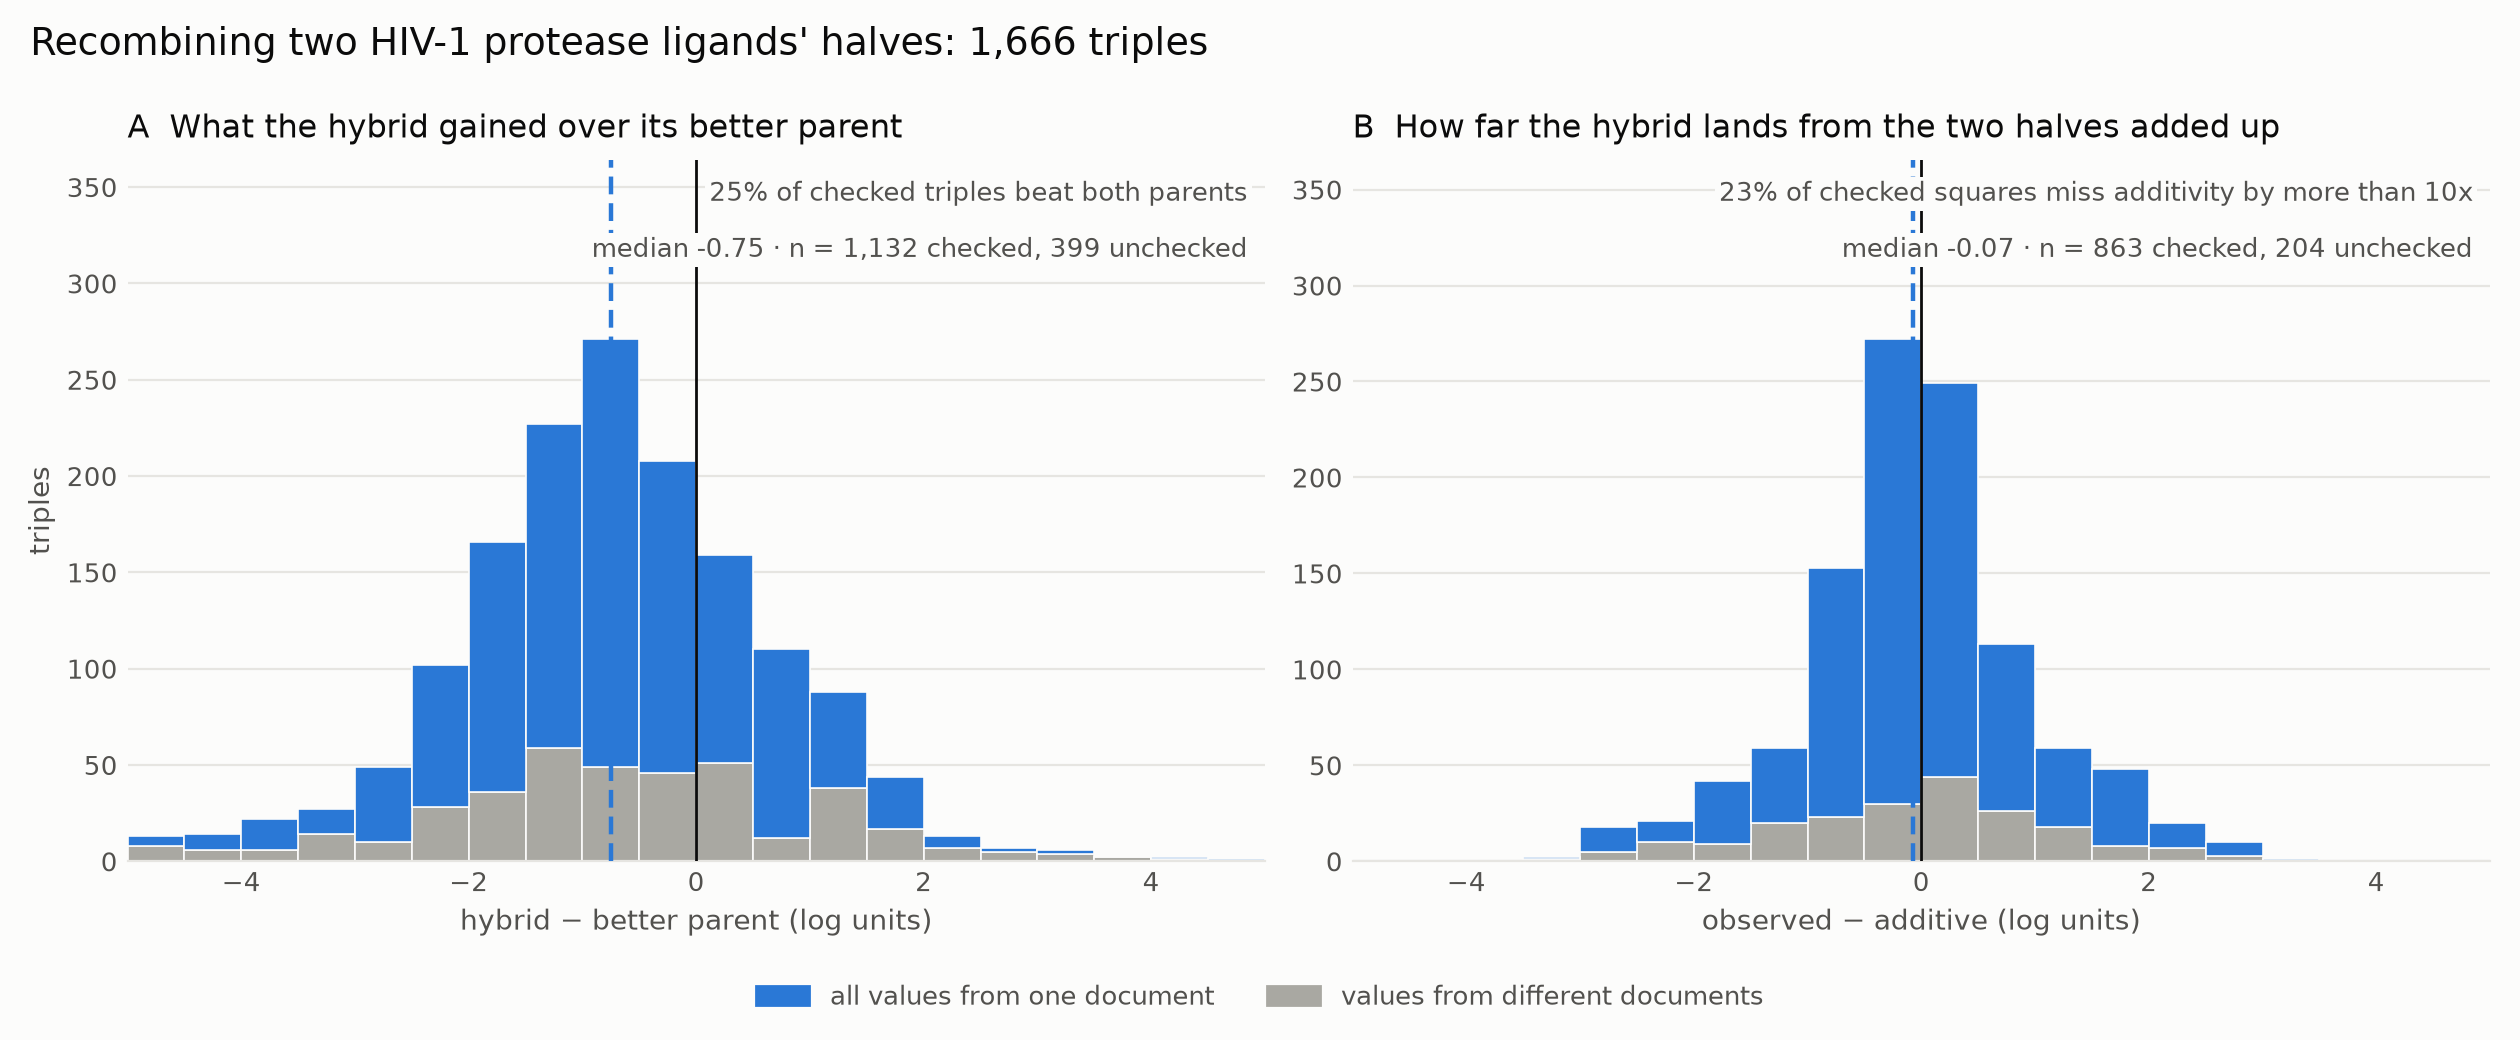

In [ ]:
# Code 2: Draw the distribution of what hybrids gain and of their interaction
# The code is in plot_fragment_swaps.py, next to this notebook (80 lines).
from plot_fragment_swaps import *

import pandas as pd
plot_swaps(pd.read_csv('fragment_swap_axes_polymerid223.csv'))

**Figure 2: Fragment swap, complete square: HIV-1 protease, 2020 sulfonamide series.** _(as recorded)_

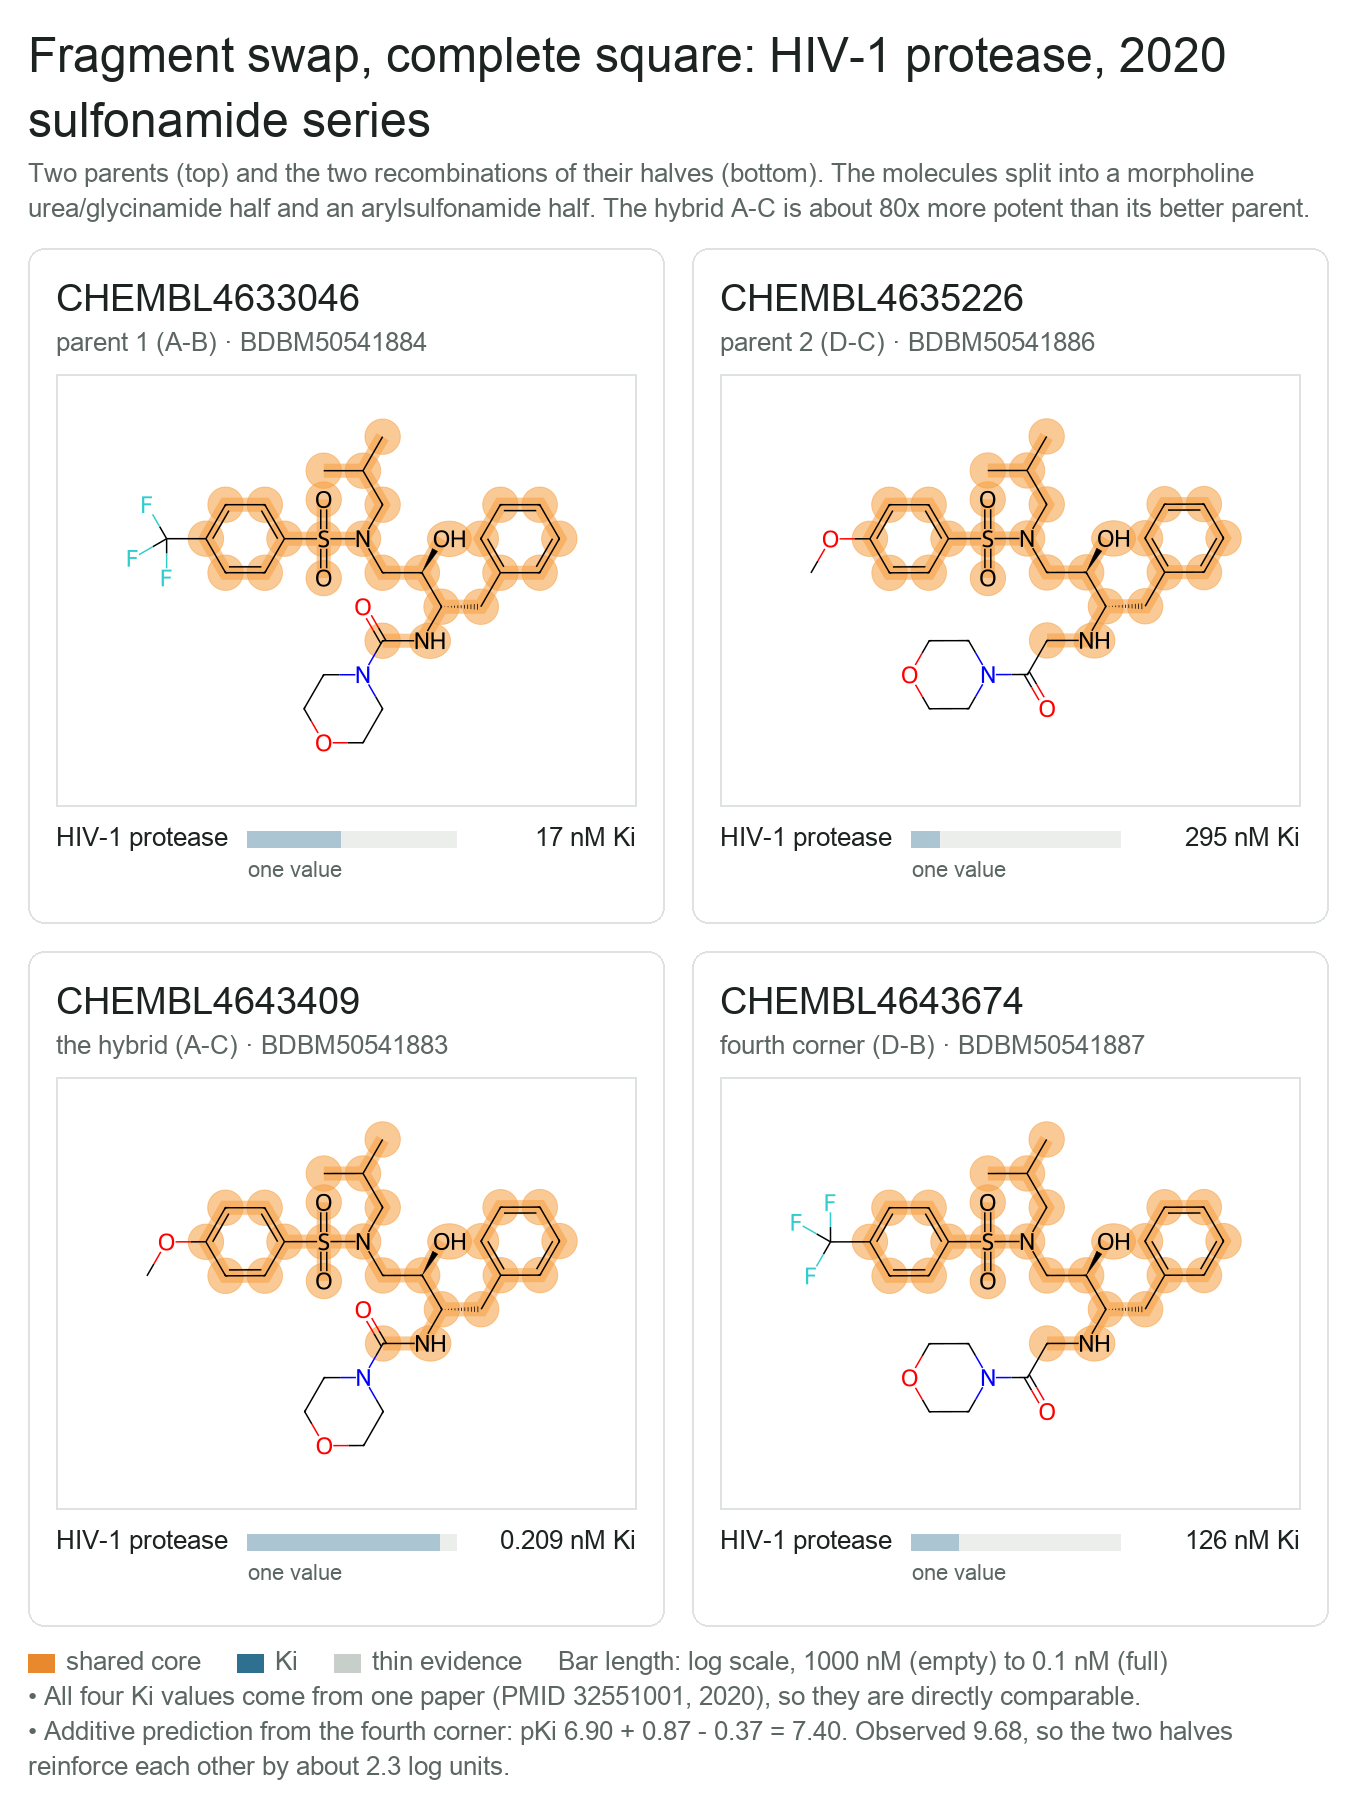

In [ ]:
# Figure 2 · draw_structure_grid draws it again
arguments = {
    'title': 'Fragment swap, complete square: HIV-1 protease, 2020 sulfonamide series',
    'compounds': [
        {
            'smiles': 'CC(C)CN(C[C@@H](O)[C@H](Cc1ccccc1)NC(=O)N1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F',
            'title': 'CHEMBL4633046',
            'subtitle': 'parent 1 (A-B) · BDBM50541884',
            'bars': [
                {
                    'label': 'HIV-1 protease',
                    'value_nm': 17.0,
                    'type': 'Ki',
                    'note': 'one value',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C[C@@H](O)[C@H](Cc1ccccc1)NCC(=O)N1CCOCC1',
            'title': 'CHEMBL4635226',
            'subtitle': 'parent 2 (D-C) · BDBM50541886',
            'bars': [
                {
                    'label': 'HIV-1 protease',
                    'value_nm': 295.0,
                    'type': 'Ki',
                    'note': 'one value',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'COc1ccc(cc1)S(=O)(=O)N(CC(C)C)C[C@@H](O)[C@H](Cc1ccccc1)NC(=O)N1CCOCC1',
            'title': 'CHEMBL4643409',
            'subtitle': 'the hybrid (A-C) · BDBM50541883',
            'bars': [
                {
                    'label': 'HIV-1 protease',
                    'value_nm': 0.209,
                    'type': 'Ki',
                    'note': 'one value',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CC(C)CN(C[C@@H](O)[C@H](Cc1ccccc1)NCC(=O)N1CCOCC1)S(=O)(=O)c1ccc(cc1)C(F)(F)F',
            'title': 'CHEMBL4643674',
            'subtitle': 'fourth corner (D-B) · BDBM50541887',
            'bars': [
                {
                    'label': 'HIV-1 protease',
                    'value_nm': 126.0,
                    'type': 'Ki',
                    'note': 'one value',
                    'faint': True,
                },
            ],
        },
    ],
    'columns': 2,
    'description': 'Two parents (top) and the two recombinations of their halves (bottom). The molecules split into a morpholine urea/glycinamide half and an arylsulfonamide half. The hybrid A-C is about 80x more potent than its better parent.',
    'notes': [
        'All four Ki values come from one paper (PMID 32551001, 2020), so they are directly comparable.',
        'Additive prediction from the fourth corner: pKi 6.90 + 0.87 - 0.37 = 7.40. Observed 9.68, so the two halves reinforce each other by about 2.3 log units.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(2, 'draw_structure_grid', arguments)

**Figure 3: Fragment swap, complete square: HIV-1 protease, KNI peptidomimetic series.** _(as recorded)_

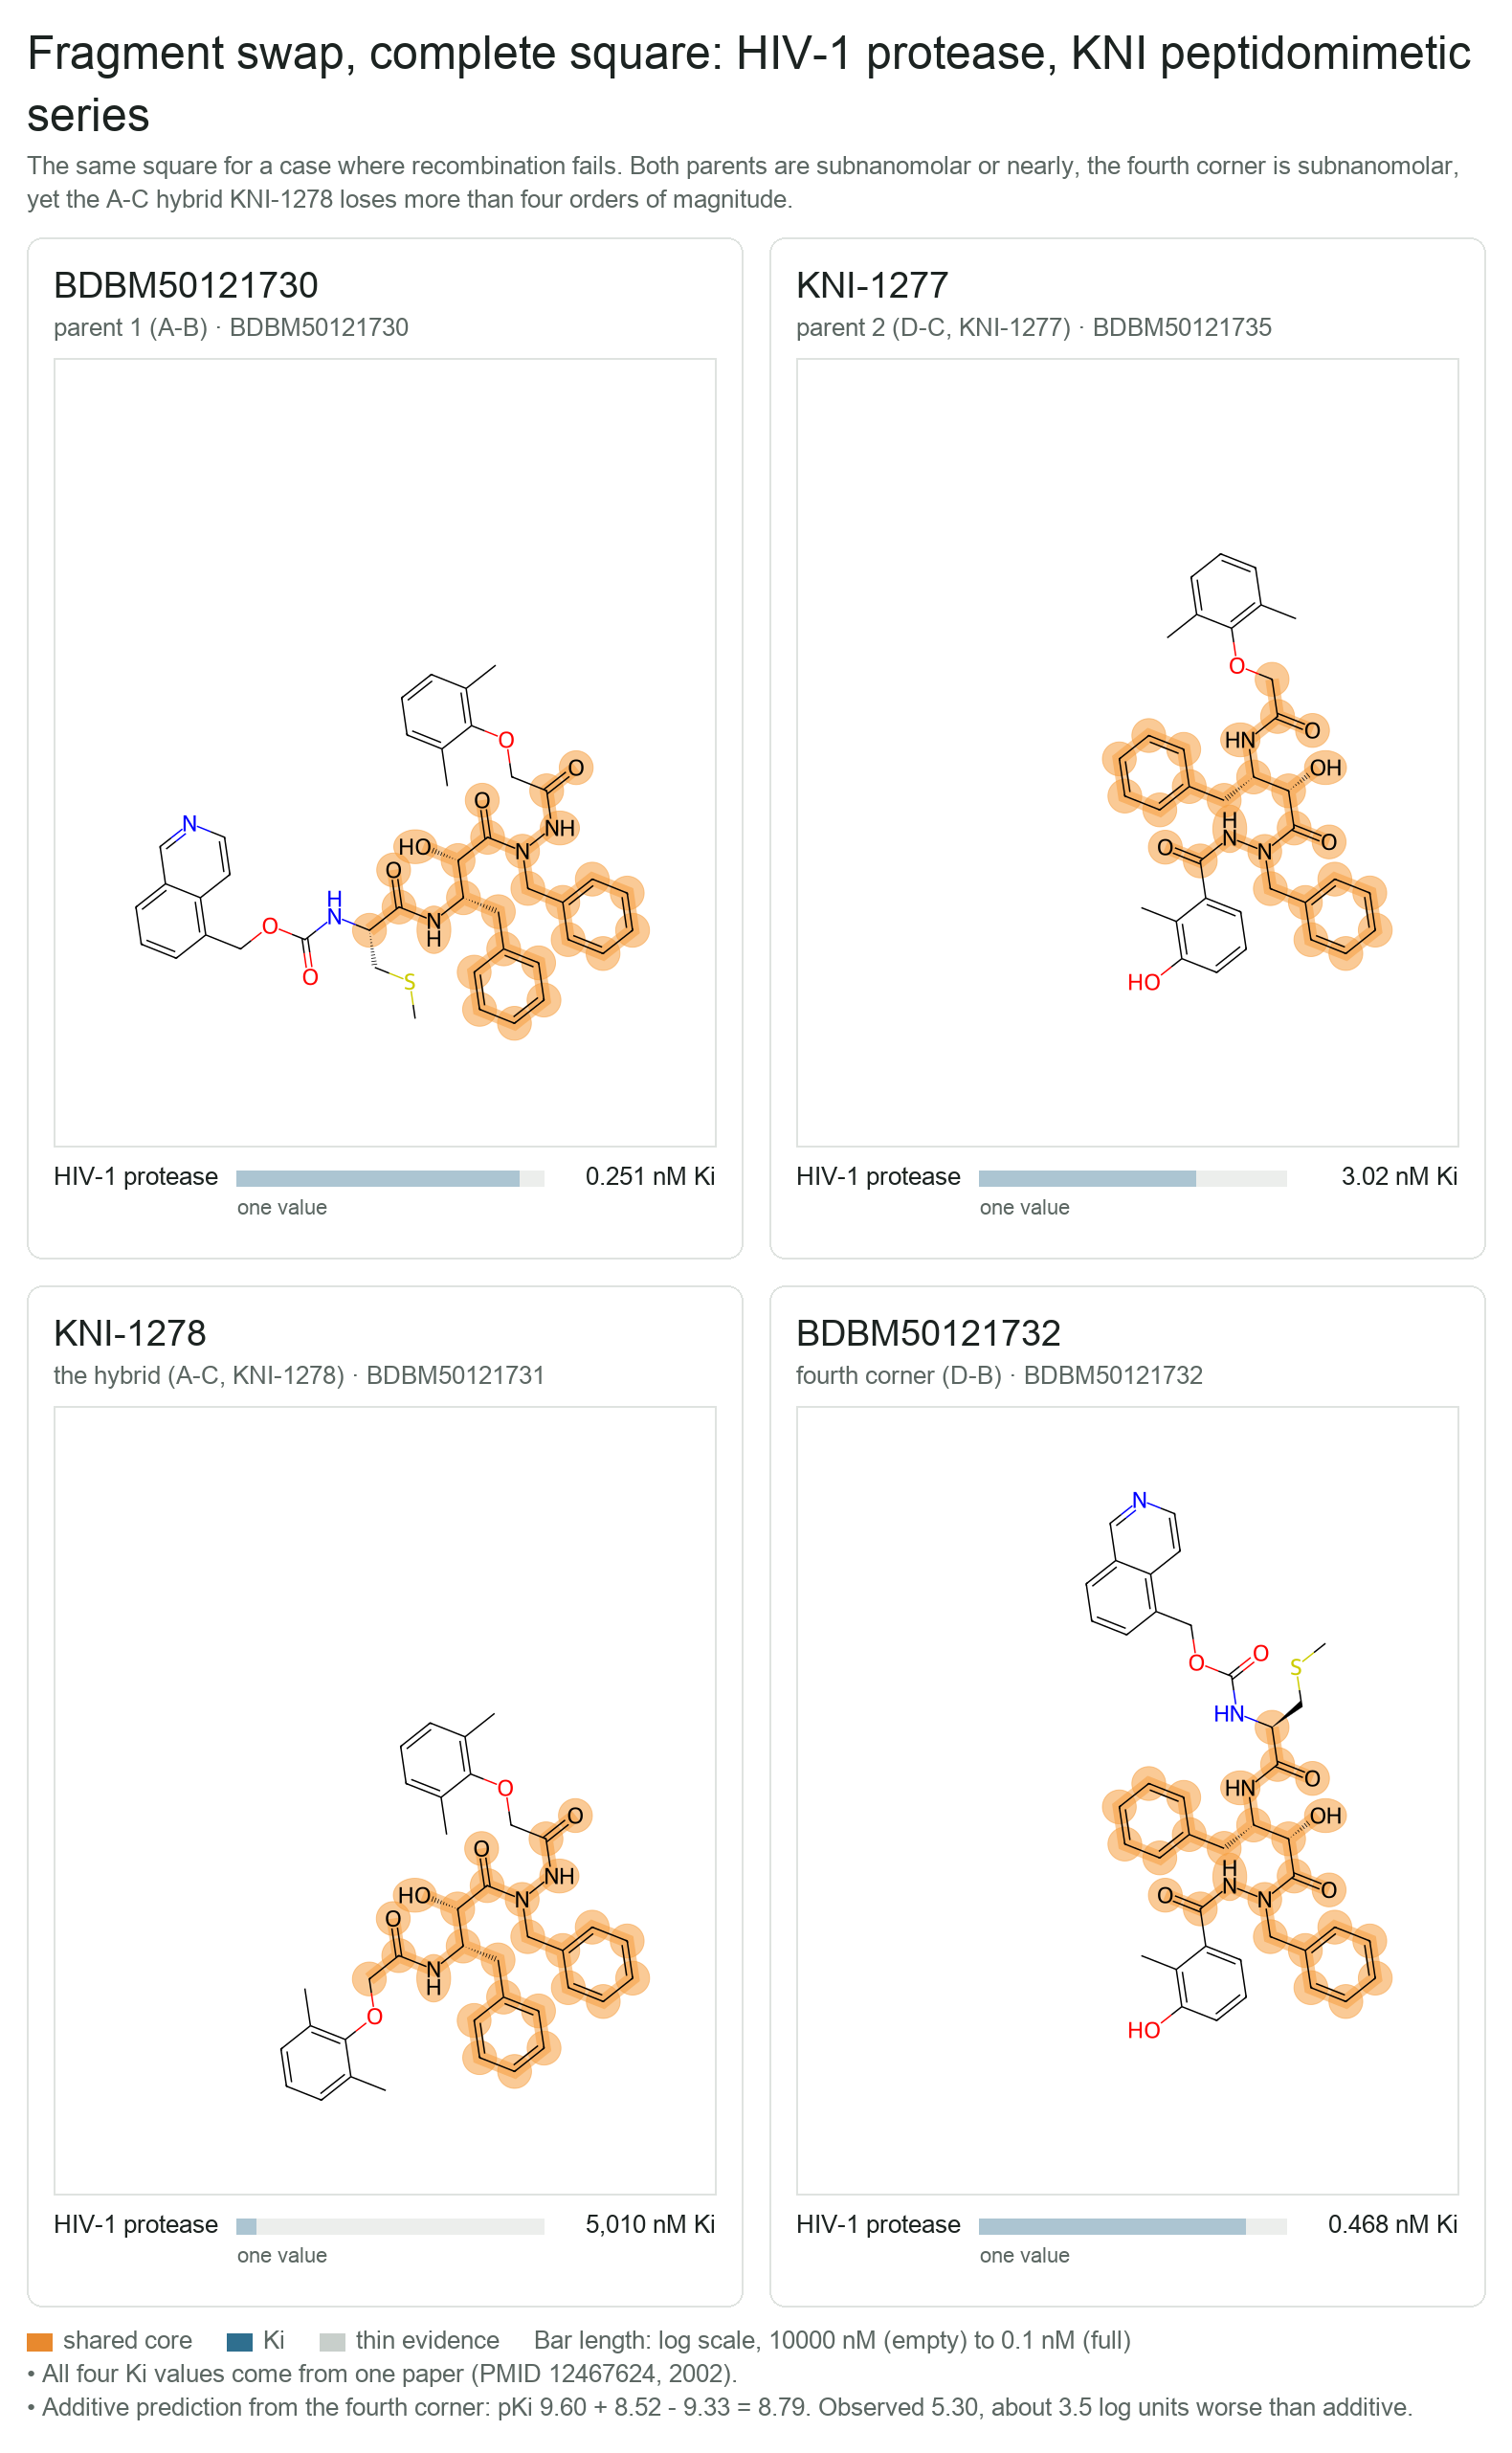

In [ ]:
# Figure 3 · draw_structure_grid draws it again
arguments = {
    'title': 'Fragment swap, complete square: HIV-1 protease, KNI peptidomimetic series',
    'compounds': [
        {
            'smiles': 'CSC[C@H](NC(=O)OCc1cccc2cnccc12)C(=O)N[C@@H](Cc1ccccc1)[C@H](O)C(=O)N(Cc1ccccc1)NC(=O)COc1c(C)cccc1C',
            'title': 'BDBM50121730',
            'subtitle': 'parent 1 (A-B) · BDBM50121730',
            'bars': [
                {
                    'label': 'HIV-1 protease',
                    'value_nm': 0.251,
                    'type': 'Ki',
                    'note': 'one value',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cc1cccc(C)c1OCC(=O)N[C@@H](Cc1ccccc1)[C@H](O)C(=O)N(Cc1ccccc1)NC(=O)c1cccc(O)c1C',
            'title': 'KNI-1277',
            'subtitle': 'parent 2 (D-C, KNI-1277) · BDBM50121735',
            'bars': [
                {
                    'label': 'HIV-1 protease',
                    'value_nm': 3.02,
                    'type': 'Ki',
                    'note': 'one value',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cc1cccc(C)c1OCC(=O)N[C@@H](Cc1ccccc1)[C@H](O)C(=O)N(Cc1ccccc1)NC(=O)COc1c(C)cccc1C',
            'title': 'KNI-1278',
            'subtitle': 'the hybrid (A-C, KNI-1278) · BDBM50121731',
            'bars': [
                {
                    'label': 'HIV-1 protease',
                    'value_nm': 5010.0,
                    'type': 'Ki',
                    'note': 'one value',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CSC[C@H](NC(=O)OCc1cccc2cnccc12)C(=O)N[C@@H](Cc1ccccc1)[C@H](O)C(=O)N(Cc1ccccc1)NC(=O)c1cccc(O)c1C',
            'title': 'BDBM50121732',
            'subtitle': 'fourth corner (D-B) · BDBM50121732',
            'bars': [
                {
                    'label': 'HIV-1 protease',
                    'value_nm': 0.468,
                    'type': 'Ki',
                    'note': 'one value',
                    'faint': True,
                },
            ],
        },
    ],
    'columns': 2,
    'description': 'The same square for a case where recombination fails. Both parents are subnanomolar or nearly, the fourth corner is subnanomolar, yet the A-C hybrid KNI-1278 loses more than four orders of magnitude.',
    'notes': [
        'All four Ki values come from one paper (PMID 12467624, 2002).',
        'Additive prediction from the fourth corner: pKi 9.60 + 8.52 - 9.33 = 8.79. Observed 5.30, about 3.5 log units worse than additive.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(3, 'draw_structure_grid', arguments)

**🧠 Assistant**

HIV-1 protease is a good choice for this: its ligands are famously modular, built from a transition-state core with a cap on each side, and a great many of them have been measured.

**What the search found.** The target is Gag-Pol polyprotein [489-587] (polymerid 223), BindingDB's main HIV-1 protease entry, with 3,548 compounds carrying a measured affinity. Of those, 2,951 split into two fragments that are each at least a third of the molecule.

Those ligands yield **537,744 raw triples**, which badly overstates the chemistry: one compound pair yields several near-identical cuts, and a fragment that recurs across many papers recurs in thousands of triples. Only 1,250 distinct compounds ever serve as the hybrid. Collapsing to one representative per swap axis (a hybrid together with the two fragments it is cut into) and then to one per distinct compound triple leaves **1,666 triples**. Of these:
- 1,531 are comparable, meaning all three compounds have the same affinity type
- 1,167 have a paper or patent reporting all three compounds
- 1,162 close the square, and 1,067 of those have a value for the fourth corner as well

As a check, rejoining the two kept fragments reproduces the hybrid's constitution in all 1,666 rows.

**Does recombining halves help?** Usually not, and the first figure below gives the distribution. Among triples whose three values come from one document, the hybrid is a median 0.75 log units **worse** than its better parent, and it beats both parents only 25% of the time (1,132 such triples). That is the honest base rate, and it is the reason a hybrid worth looking at has to be picked rather than assumed.

The second panel of that figure is the more interesting one. For the squares that close within one document (863), the hybrid lands a median 0.07 log units below the sum of the two halves' separate effects, so **fragment contributions are additive on average**. But 23% of them miss that additive expectation by more than tenfold in one direction or the other. Additivity is a good default and a bad guarantee.

**Two squares worth looking at.** The second figure is a case where recombination works. In a 2020 sulfonamide series the molecules divide into a morpholine urea or glycinamide half and an arylsulfonamide half. Neither parent is impressive at 17 nM and 295 nM, and the fourth corner sits at 126 nM, yet the hybrid that takes the morpholine urea from one and the 4-methoxyphenylsulfonamide from the other reaches **0.21 nM**, about 80 times better than its better parent and roughly 2.3 log units beyond what adding the two halves' effects would predict. This is the pattern that makes the search worth running: the good combination was not visible in either parent.

The third figure is the opposite, and it is the more instructive one. In the KNI peptidomimetic series the parents are 0.25 and 3.0 nM and the fourth corner is 0.47 nM, but the A-C hybrid, KNI-1278, falls to 5 micromolar, more than four orders of magnitude below its better parent and 3.5 log units below the additive prediction. The structures show what that recombination does: it puts the dimethylphenoxyacetyl group at both ends of the molecule, dropping the isoquinolinyl-carbamate arm of one parent and the hydroxy-methylbenzoyl cap of the other. The hybrid is not the smallest of the four (46 heavy atoms against 55, 44 and 53), so this is not simply a matter of size; the database cannot say why, only that a swap that looks symmetric on paper is not symmetric in the binding site. In both figures the grid aligns the four compounds on a 27-atom substructure they all share (the transition-state core and its neighbours); the swapped halves lie on either side of it.

**Caveats.** The triples span many papers and assay conditions, so a comparison drawn across documents is weaker evidence than one within a single paper. The table carries a shared_article flag, and the figure separates the two; I would treat the cross-document rows as leads rather than measurements. Affinities are the median per compound per type, and Ki and IC50 are never mixed within a triple. They include the less-than and greater-than entries (about 5% of the target's 4,489 affinity rows are not exact values), which this analysis, like the original, does not remove.

The ligand set is also not neutral chemistry. These series were designed around a common core, so the fragments that recur most are the ones medicinal chemists deliberately reused, and the triples are correspondingly enriched in planned analogues rather than accidental ones.

**How this was answered**
- search_targets located Gag-Pol polyprotein [489-587] (polymerid 223, 3,548 compounds); a run_sql count of its affinity rows by relation gave the share of non-exact values.
- Four run_sql pages (1,000 compounds each) listed every compound with its SMILES, the median p_affinity per affinity type and the articles that report it.
- find_fragment_swaps.py (the code cell below) cuts every compound with the server's own fragmenter, keeps cuts whose halves are each at least a third of the molecule, and finds the triples; it writes fragment_swap_axes_polymerid223.csv. plot_fragment_swaps.py draws the first figure from that file.
- Two more run_sql calls gave the names and sources of the compounds in the two squares, and draw_structure_grid drew them.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 9 tool calls, 2 figures to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Fragment swaps: ligands built from each other's halves, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```